# Urban Water Vapor Isotopes - reproducibility notebook

This notebook reproduces the analyses, figures, tables, and reviewer-validation checks for **"Isotopic Evidence for Modification of Column Water Vapor by Cities"** (2026), by Martin Velez Pardo, David C. Noone, and Richard P. Fiorella, submitted to Nature Communications.

**Design of this public notebook**

- All file references are relative to the repository root; there are no machine-specific absolute paths.
- The analysis uses the native **0.05 degree** TROPOMI climatology grid.
- Numbered publication outputs are written to `output/figures/` and `output/tables/`.
- Computational caches are optional and live in `output/cache/`; deleting them should only make a rerun slower.
- Reviewer/validation diagnostics that informed the revision are retained and labeled explicitly.
- Figure 3 is a static conceptual schematic; it is embedded below and archived in `assets/`.


In [2]:
from pathlib import Path
import sys, platform
from importlib.metadata import version, PackageNotFoundError

PROJECT_ROOT = Path.cwd().resolve()
SOURCE_DATA_DIR = PROJECT_ROOT / "source_data"
ASSETS_DIR = PROJECT_ROOT / "assets"
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_FIGURES_DIR = OUTPUT_DIR / "figures"
OUTPUT_TABLES_DIR = OUTPUT_DIR / "tables"
OUTPUT_CACHE_DIR = OUTPUT_DIR / "cache"
NATURAL_EARTH_DIR = SOURCE_DATA_DIR / "natural_earth"

for p in [SOURCE_DATA_DIR, ASSETS_DIR, OUTPUT_FIGURES_DIR, OUTPUT_TABLES_DIR, OUTPUT_CACHE_DIR, NATURAL_EARTH_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# Compatibility aliases used by the original tested analysis blocks.
DATA_DIR = SOURCE_DATA_DIR
FIGURES_DIR = OUTPUT_FIGURES_DIR
RESULTS_DIR = OUTPUT_TABLES_DIR
CACHE_DIR = OUTPUT_CACHE_DIR

FILES = {
    "tropomi_climatology": SOURCE_DATA_DIR / "TROPOMI_HDO_CLEAR_p05_quadratic_climatology.nc",
    "settlement": SOURCE_DATA_DIR / "PercentSettlementArea_regridded_to_TROPOMI_quadratic_climatology_0p05.nc",
    "elevation": SOURCE_DATA_DIR / "ETOPO_2022_v1_30s_N90W180_surface_resampled_to_TROPOMI_quadratic_climatology_p05.tif",
    "landmask": SOURCE_DATA_DIR / "landseamask_regridded_to_TROPOMI_quadratic_climatology_0p05_nearest.nc",
    "landcover_broad": SOURCE_DATA_DIR / "MCD12C1_IGBP_broad_climatology_2017-2024_TROPOMIgrid.nc",
    "landcover_detailed": SOURCE_DATA_DIR / "MCD12C1_IGBP_detailed_climatology_2017-2024_TROPOMIgrid.nc",
    "geonames": SOURCE_DATA_DIR / "cities15000.txt",
    "cities_top400": SOURCE_DATA_DIR / "top400_cities.csv",
    "cities_top2000": SOURCE_DATA_DIR / "top2000_cities.csv",
    "same_day_city_days": SOURCE_DATA_DIR / "SameDay_daily_only_city_days.csv",
}

print("Repository root:", PROJECT_ROOT)
print("Python:", sys.version.replace("\n", " "))
print("Platform:", platform.platform())


Repository root: /Users/a391980/Downloads/UrbanWaterVaporIsotopes
Python: 3.8.19 (default, Mar 20 2024, 15:00:34)  [Clang 14.0.6 ]
Platform: macOS-10.16-x86_64-i386-64bit


## Environment check

Reports the active Python and package versions and identifies missing dependencies. The cell does not install or modify packages.


In [2]:
packages = [
    "numpy", "pandas", "scipy", "matplotlib", "xarray", "rioxarray",
    "rasterio", "cartopy", "shapely", "pyproj", "netCDF4",
    "scikit-learn", "dask", "ipykernel", "notebook", "adjustText",
]

missing = []
for pkg in packages:
    try:
        print(f"{pkg:15s} {version(pkg)}")
    except PackageNotFoundError:
        print(f"{pkg:15s} MISSING")
        missing.append(pkg)

if missing:
    print("\nMissing packages:", ", ".join(missing))
    print("Create/activate the repository Conda environment before running analysis sections.")
else:
    print("\nAll checked Python packages are available.")


numpy           1.24.4
pandas          1.5.3
scipy           1.10.1
matplotlib      3.5.3
xarray          2023.1.0
rioxarray       0.13.4
rasterio        1.3.11
cartopy         0.21.1
shapely         2.0.1
pyproj          3.5.0
netCDF4         1.6.2
scikit-learn    1.3.2
dask            2023.4.1
ipykernel       6.28.0
notebook        7.2.1
adjustText      MISSING

Missing packages: adjustText
Create/activate the repository Conda environment before running analysis sections.


## Repository inputs and local Natural Earth water-body data

The city maps use Natural Earth 10m rivers and lakes for visual context. Four shapefile families are read locally from `source_data/natural_earth/`:

- `ne_10m_rivers_lake_centerlines.*`
- `ne_10m_rivers_lake_centerlines_scale_rank.*`
- `ne_10m_lakes.*`
- `ne_10m_lakes_north_america.*`

Each shapefile family should include at least `.shp`, `.shx`, `.dbf`, and `.prj`, together with any accompanying files from the same Natural Earth dataset. No network access is used by the plotting code.


In [3]:
CORE_INPUTS = [
    FILES["tropomi_climatology"], FILES["settlement"], FILES["elevation"],
    FILES["landmask"], FILES["geonames"], FILES["cities_top400"],
]
OPTIONAL_SECTION_INPUTS = [
    FILES["cities_top2000"], FILES["landcover_broad"],
    FILES["landcover_detailed"], FILES["same_day_city_days"],
]

NE_NAMES = [
    "rivers_lake_centerlines",
    "rivers_lake_centerlines_scale_rank",
    "lakes",
    "lakes_north_america",
]

def natural_earth_shapefile(name):
    path = NATURAL_EARTH_DIR / f"ne_10m_{name}.shp"
    if not path.exists():
        raise FileNotFoundError(
            f"Missing local Natural Earth shapefile: {path}\n"
            "Copy the complete matching shapefile family into source_data/natural_earth/."
        )
    return str(path)

def report_files(paths, label):
    print(f"\n{label}")
    for p in paths:
        print(" OK " if p.exists() else "MISS", p.relative_to(PROJECT_ROOT))

report_files(CORE_INPUTS, "Core inputs")
report_files(OPTIONAL_SECTION_INPUTS, "Section-specific inputs")
report_files([NATURAL_EARTH_DIR / f"ne_10m_{n}.shp" for n in NE_NAMES], "Natural Earth map layers")



Core inputs
 OK  source_data/TROPOMI_HDO_CLEAR_p05_quadratic_climatology.nc
 OK  source_data/PercentSettlementArea_regridded_to_TROPOMI_quadratic_climatology_0p05.nc
 OK  source_data/ETOPO_2022_v1_30s_N90W180_surface_resampled_to_TROPOMI_quadratic_climatology_p05.tif
 OK  source_data/landseamask_regridded_to_TROPOMI_quadratic_climatology_0p05_nearest.nc
 OK  source_data/cities15000.txt
 OK  source_data/top400_cities.csv

Section-specific inputs
 OK  source_data/top2000_cities.csv
 OK  source_data/MCD12C1_IGBP_broad_climatology_2017-2024_TROPOMIgrid.nc
 OK  source_data/MCD12C1_IGBP_detailed_climatology_2017-2024_TROPOMIgrid.nc
 OK  source_data/SameDay_daily_only_city_days.csv

Natural Earth map layers
 OK  source_data/natural_earth/ne_10m_rivers_lake_centerlines.shp
 OK  source_data/natural_earth/ne_10m_rivers_lake_centerlines_scale_rank.shp
 OK  source_data/natural_earth/ne_10m_lakes.shp
 OK  source_data/natural_earth/ne_10m_lakes_north_america.shp


# Figure 1 and Supplementary Figure 1 - example city-seasons

Generates the Moscow (JJA), Melbourne (SON), and New York City (MAM) map/scatter figure and the expanded uncertainty diagnostics. Settlement-bin intervals use a 25-km spatial-block bootstrap, with pixel bootstrap fallback where too few populated blocks are available.



MULTI-CITY DIAGNOSTIC: Moscow (JJA) / Melbourne (SON) / New York City (MAM)
Urban threshold: 20%
Control threshold: 1%
Buffer radius: 150 km
Elevation threshold: 50 m
Coast threshold: 50 km
Pixel confidence threshold: 2 SE
deltaD SE mode: precision
H2O SE mode: precision
Rural baseline SE mode: measurement_plus_rural_block_sem
Rural block SE size: 50 km
Rural block SE method: mad
Map zoom mode: urban
Map zoom padding: 35 km
Map zoom minimum span: 150 km
Map aspect mode: local_datalim
Context insets: main=True, appendix=True
Save outputs: PNG=True, PDF=True
Main bootstrap: spatial_block, block=25 km, min blocks=3, fallback=True
Appendix bootstrap: spatial_block, block=25 km, min blocks=3, fallback=False
Bootstrap median CI: n=2000, CI=(2.5, 97.5)

Unique seasons to load: ['JJA', 'SON', 'MAM']

Loading datasets for JJA ...
   Converting deltaD and deltaD uncertainty from fraction to per mil.
   Total valid land pixels: 4,819,118
   deltaD SE mode: precision
   H2O SE mode: precision
   

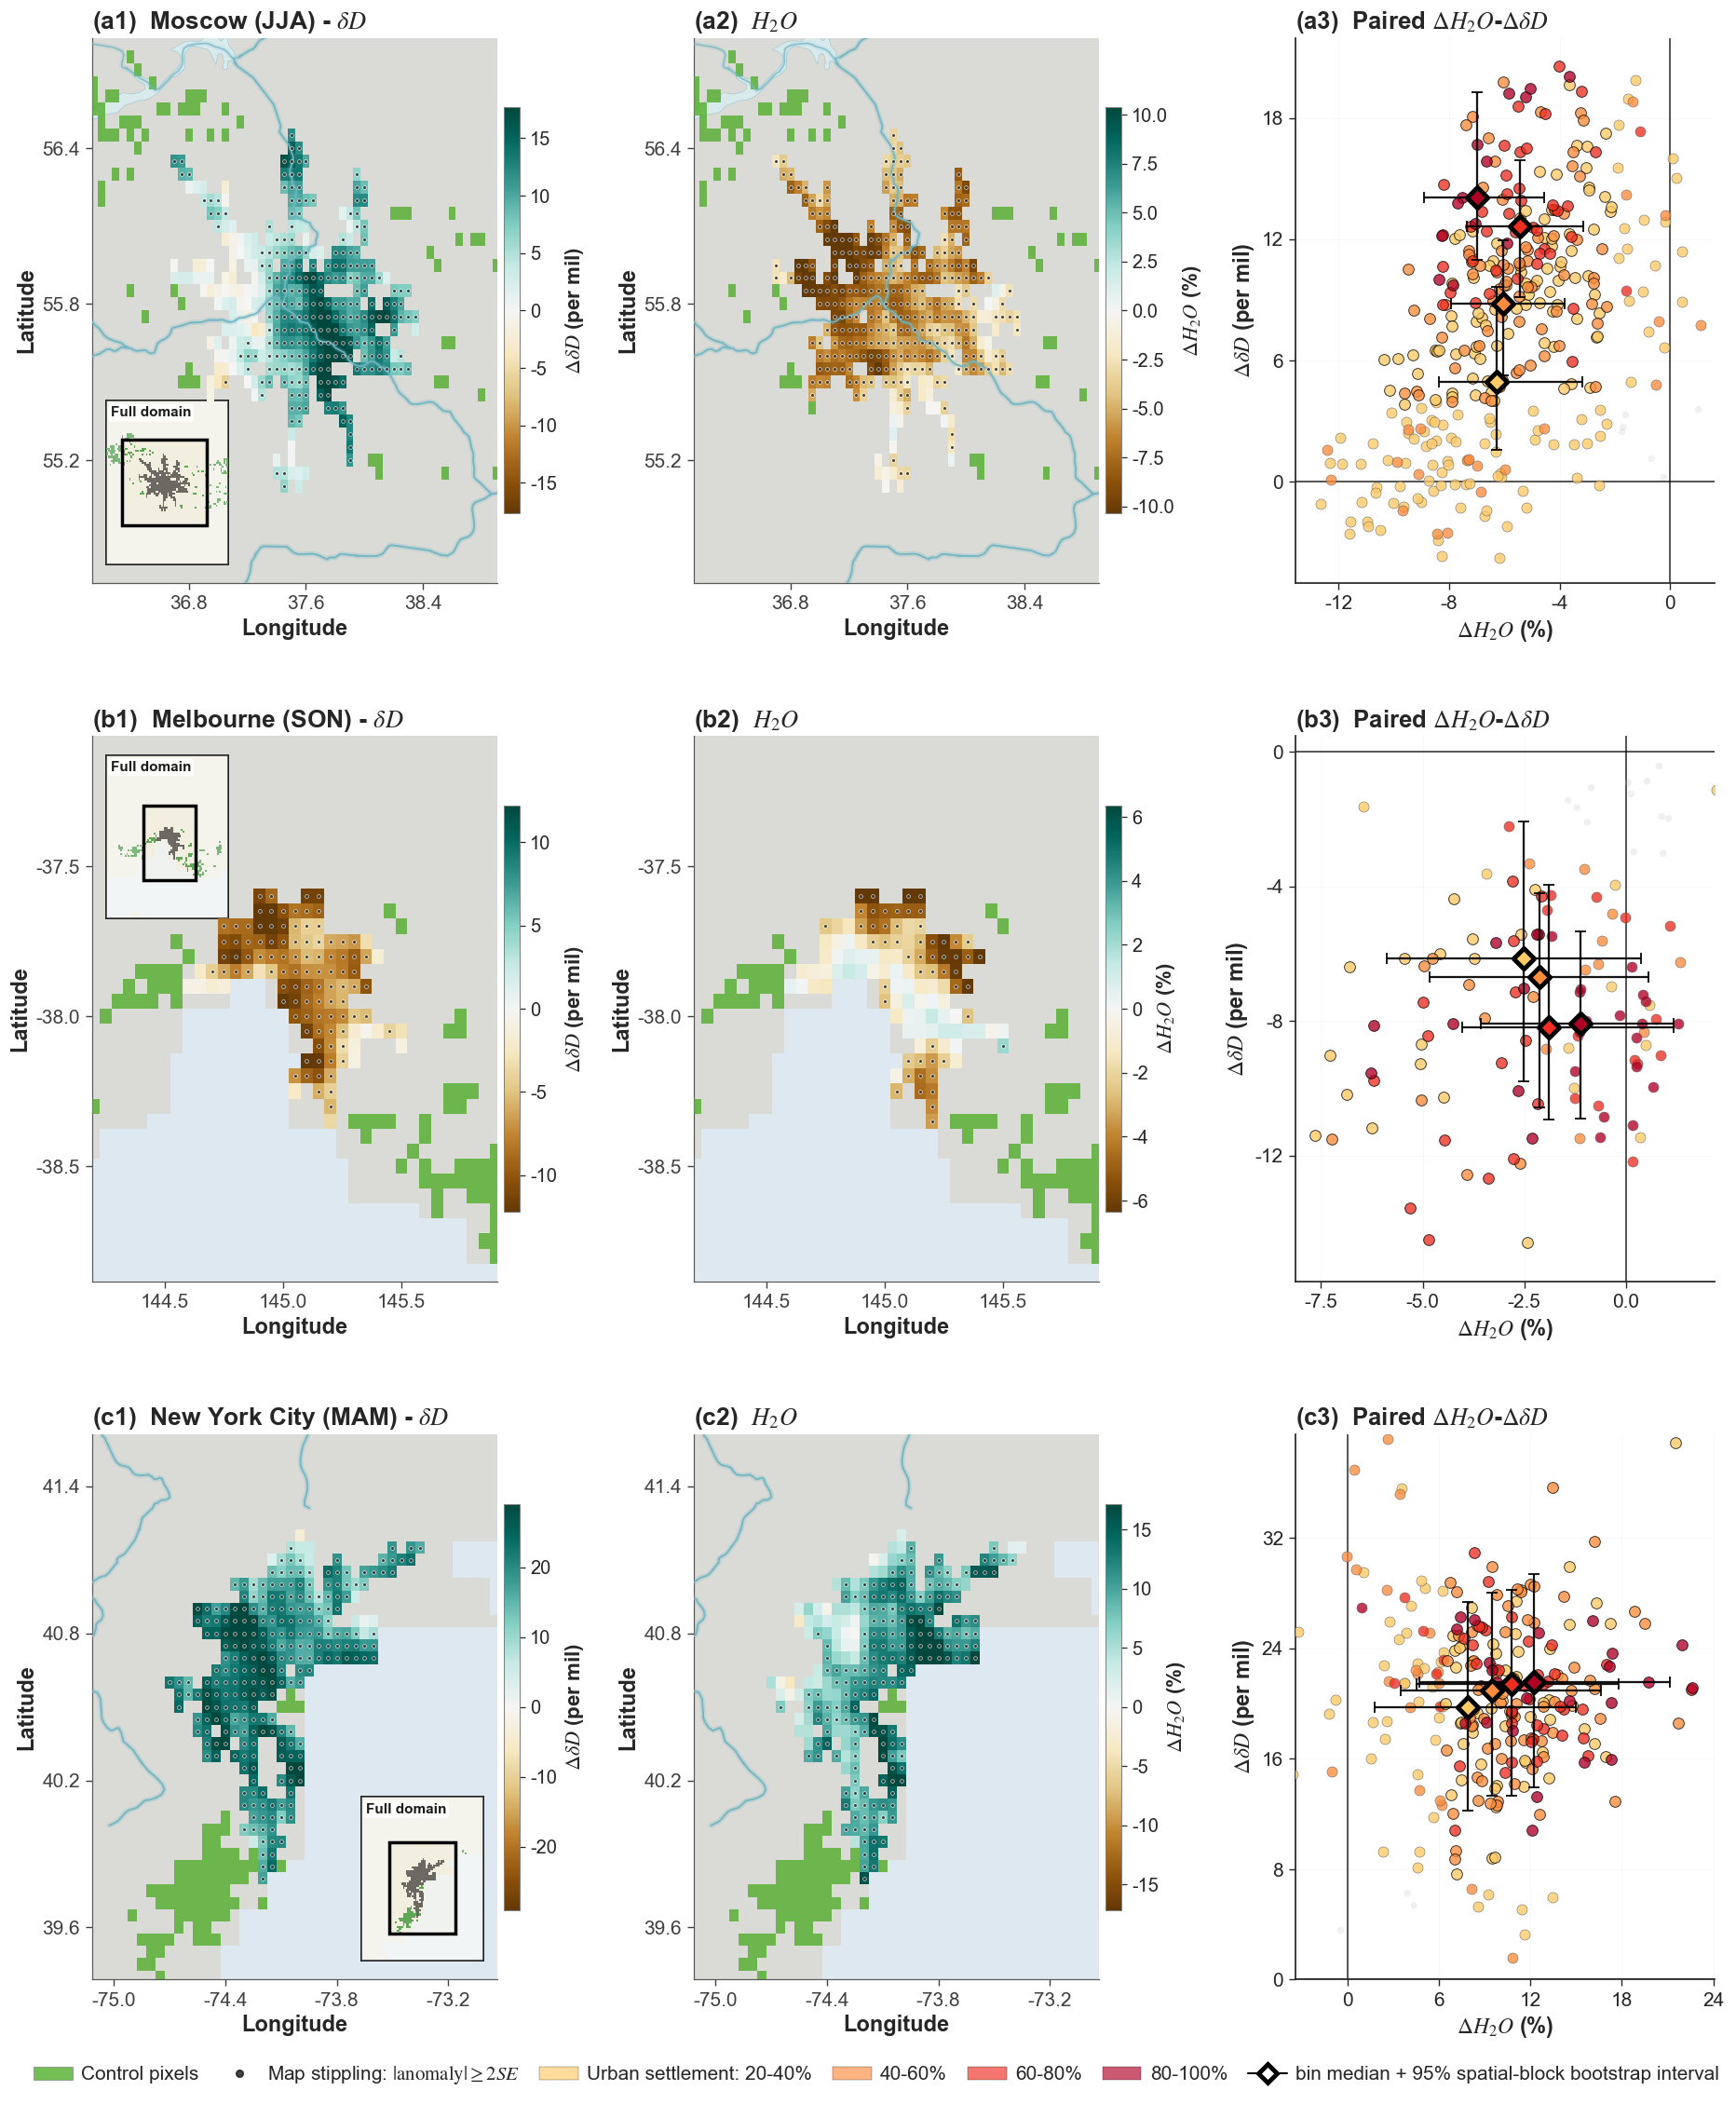

   Context inset for Moscow: lower_left (urban=0, sig=0, control=0)
   Context inset for Melbourne: upper_left (urban=0, sig=0, control=0)
   Context inset for New York City: upper_left (urban=0, sig=0, control=0)

Saved PNG appendix figure: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Supplement_Figure_1_City_uncertainty.png

Saved PDF appendix figure: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Supplement_Figure_1_City_uncertainty.pdf


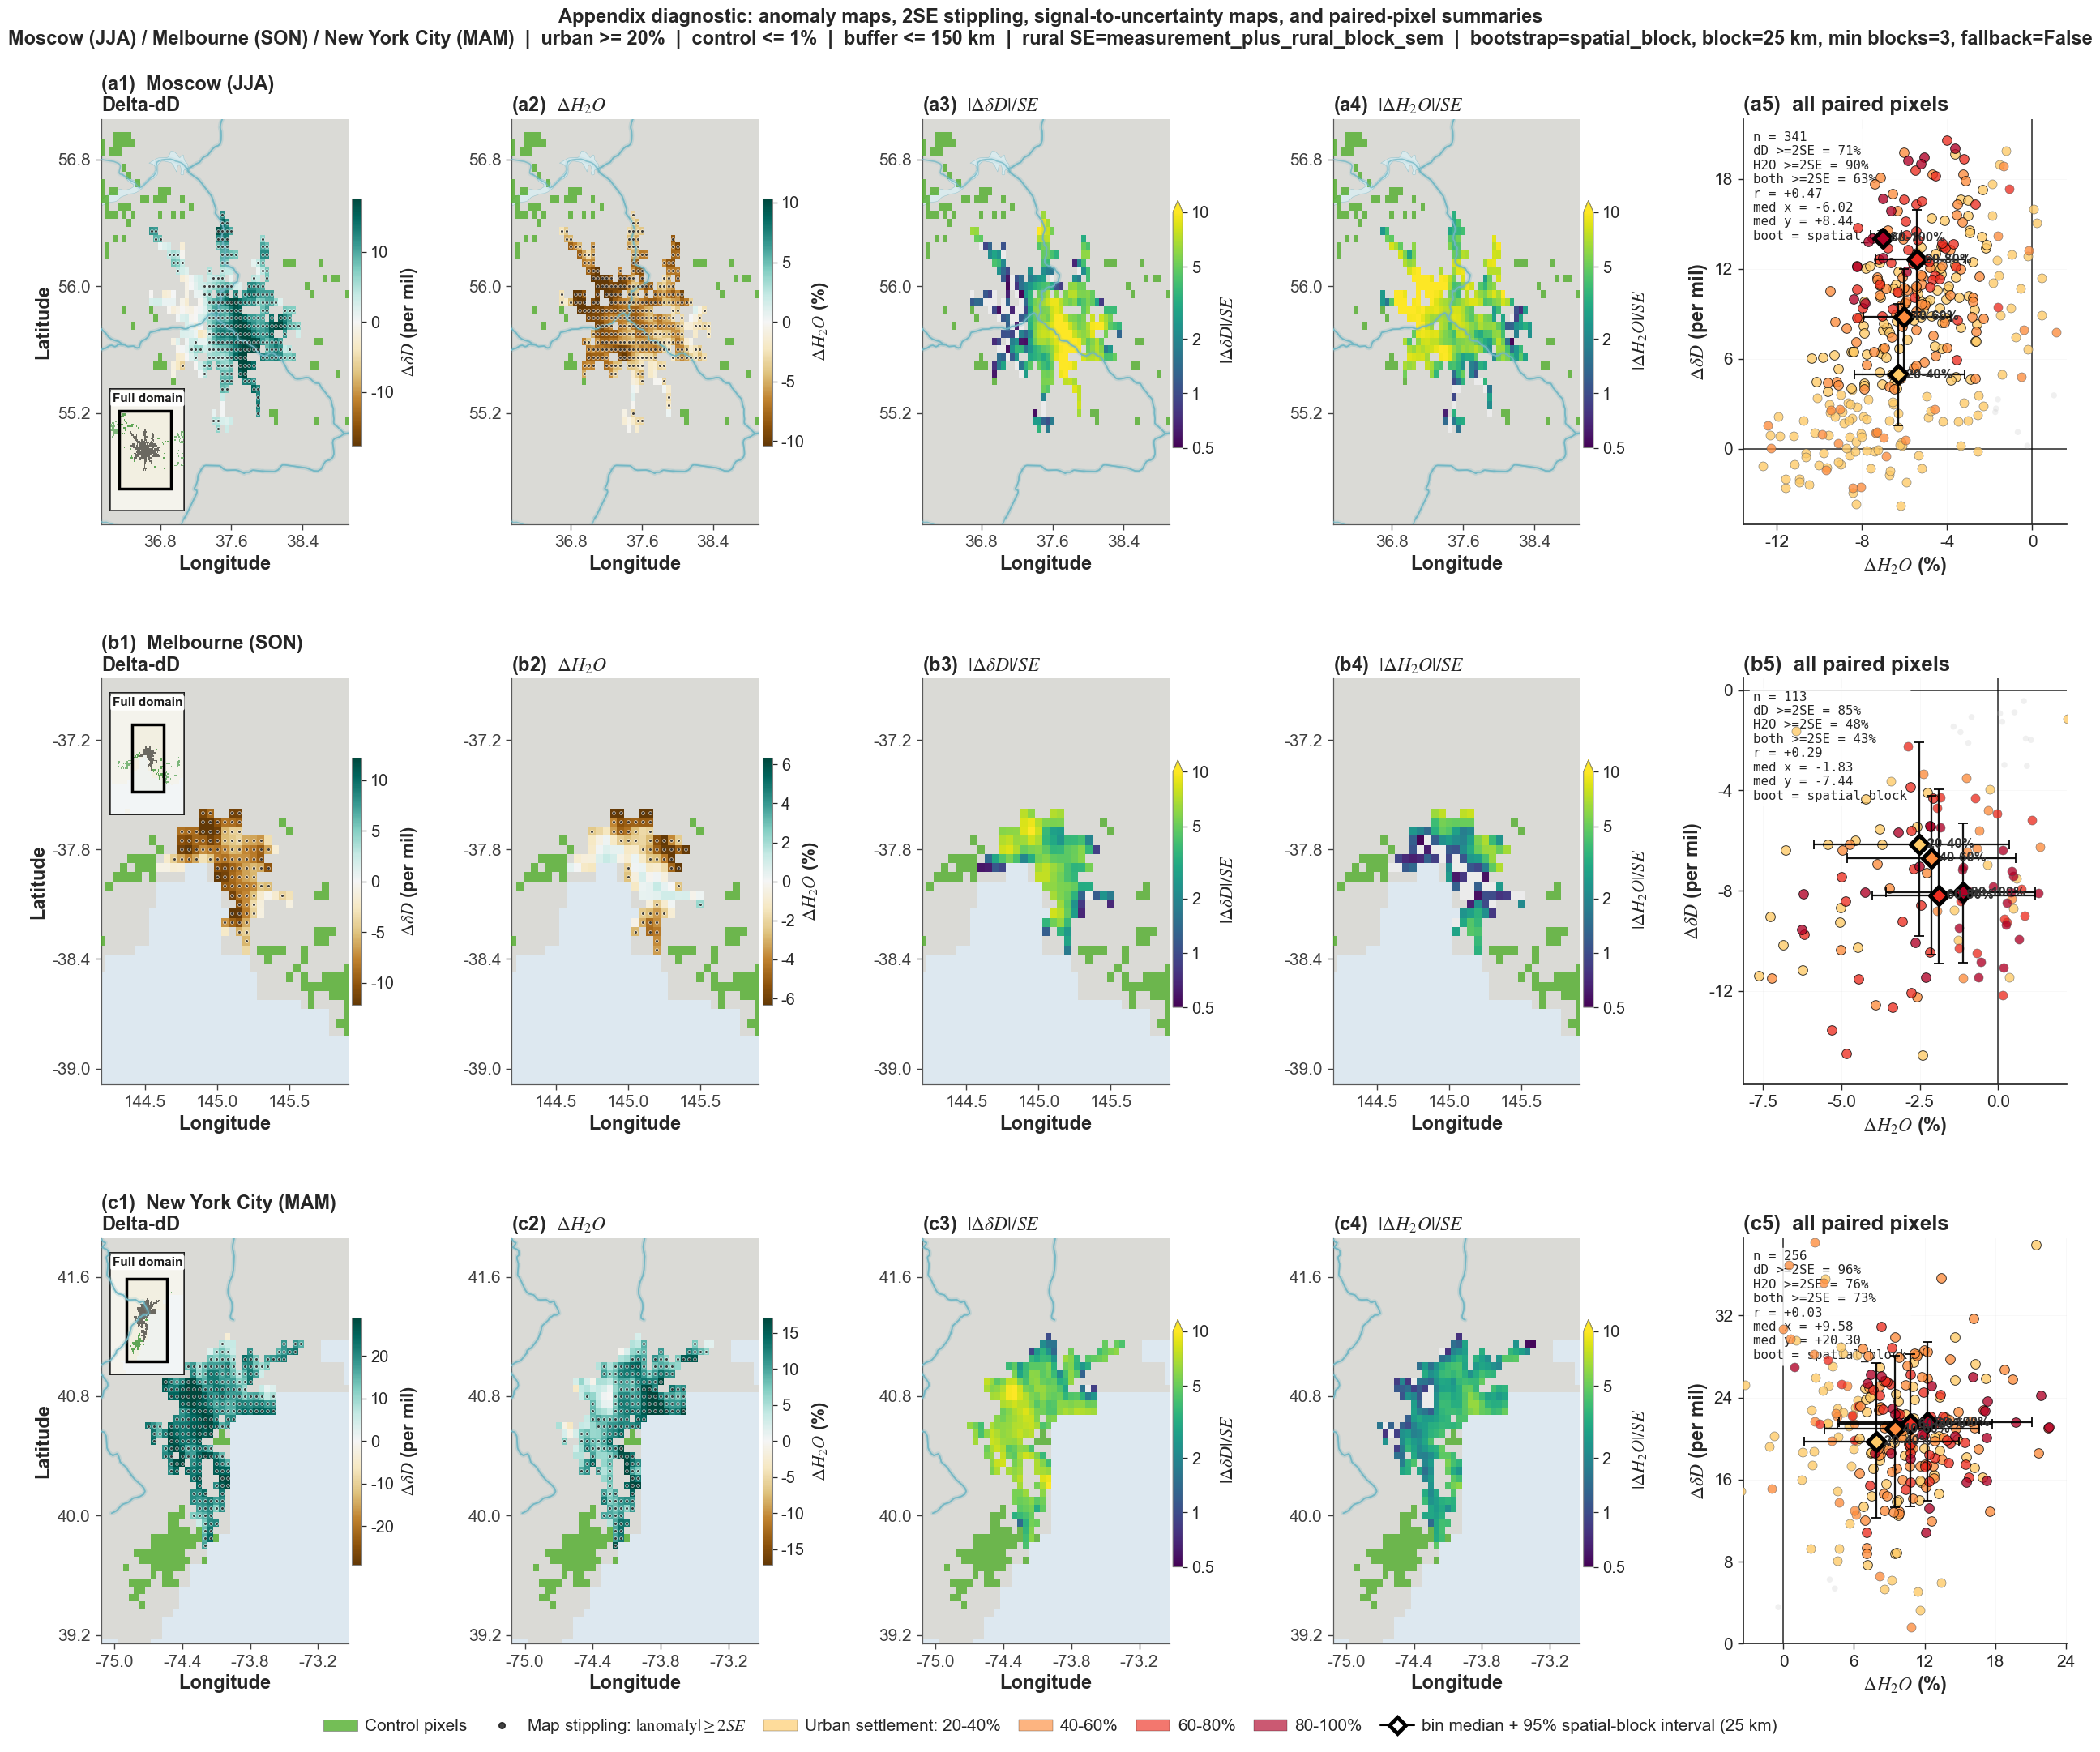

In [4]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
City-scale urban-rural vapor anomaly diagnostics
================================================

Produces anomaly maps, paired isotope-moisture scatterplots, settlement-bin
summaries, propagated uncertainty diagnostics, and spatial-block bootstrap
intervals for the selected city-seasons.

Main figure:
    - Shows all valid urban pixels.
    - Delta-dD map colors all Delta-dD anomalies.
    - Delta-H2O map colors all Delta-H2O anomalies.
    - Stippling marks pixels where the mapped anomaly exceeds 2 SE.
    - Paired scatter uses all paired pixels.
    - Settlement-bin median diamonds and 95% intervals are computed from all
      valid paired pixels.

Appendix figure:
    - One row per city:
        Delta-dD anomaly map with 2SE stippling
        Delta-H2O anomaly map with 2SE stippling
        |Delta-dD|/SE map with log color scale
        |Delta-H2O|/SE map with log color scale
        paired Delta-H2O--Delta-dD scatter

Uncertainty:
    - Seasonal mean is count-weighted.
    - Seasonal SE is propagated from monthly per-pixel SE.
    - Rural baseline uncertainty uses retrieval precision plus rural-block SEM.
    - H2O relative-anomaly SE uses first-order propagation for:
        100 * (urban - rural) / rural
    - Median bootstrap intervals can use either pixel or spatial-block resampling.
"""

import os
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import rioxarray

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib as mpl

from scipy.ndimage import distance_transform_edt, label as ndimage_label

warnings.filterwarnings("ignore")

_HAS_CARTOPY = False
_HAS_SHAPELY = False

try:
    import cartopy.io.shapereader as shpreader
    _HAS_CARTOPY = True
except ImportError:
    pass

try:
    from shapely.geometry import (
        MultiLineString,
        Polygon,
        MultiPolygon,
        box as shapely_box,
    )
    _HAS_SHAPELY = True
except ImportError:
    pass


# ============================================================================
# CONFIGURATION
# ============================================================================

CITIES = [
    {"name": "Moscow", "season": "JJA"},
    {"name": "Melbourne", "season": "SON"},
    {"name": "New York City", "season": "MAM"},
]

# Portable repository paths
REVISION_ROOT = PROJECT_ROOT
DATA_DIR = SOURCE_DATA_DIR
FIGURES_DIR = OUTPUT_FIGURES_DIR
RESULTS_DIR = OUTPUT_TABLES_DIR
for _dir in [DATA_DIR, FIGURES_DIR, RESULTS_DIR]:
    Path(_dir).mkdir(parents=True, exist_ok=True)

TROPOMI_PATH = str(FILES["tropomi_climatology"])
SETTLEMENT_NC_PATH = str(FILES["settlement"])
SETTLEMENT_TIF_PATH = str(SOURCE_DATA_DIR / "PercentSettlementArea_regridded_to_TROPOMI_quadratic_climatology_0p05.tif")
ELEVATION_TIF_PATH = str(FILES["elevation"])
LANDMASK_NC_PATH = str(FILES["landmask"])
CITY_CSV = str(FILES["cities_top400"])
CITY_CSV_CANDIDATES = [CITY_CSV]

URBAN_MIN = 20.0
CONTROL_MAX = 1.0
BUFFER_RADIUS_KM = 150.0
ELEV_DIFF_THR = 50.0
COAST_DIFF_THR = 50.0

MIN_COUNT_PER_MONTH = 5.0
MIN_SUPPORTED_MONTHS = 2

USE_REGRESSION_BASELINE = False
MIN_RURAL_FOR_REGRESSION = 30
REGRESSION_USE_LATLON = False

URBAN_PIXEL_ELEV_SCREEN = None
URBAN_PIXEL_COAST_SCREEN = None

URBAN_BINS = [(20, 40), (40, 60), (60, 80), (80, 100)]

WEIGHT_CITY_MEANS_BY_TOTAL_OBS = False


# ============================================================================
# UNCERTAINTY OPTIONS
# ============================================================================

DELTA_D_SE_MODE = "precision"       # "precision" or "conservative"
H2O_SE_MODE = "precision"           # "precision" or "conservative"

RURAL_BASELINE_SE_MODE = "measurement_plus_rural_block_sem"

# Other supported modes:
#     "measurement"
#     "spatial_sem"
#     "measurement_plus_spatial_sem"
#     "rural_spread"
#     "measurement_plus_rural_spread"
#     "rural_block_sem"
#     "measurement_plus_rural_block_sem"
#     "none"

RURAL_SPREAD_METHOD = "mad"     # "mad" or "std"

RURAL_BLOCK_SE_SIZE_KM = 50.0
RURAL_BLOCK_SE_METHOD = "mad"   # "mad" or "std"
MIN_RURAL_BLOCKS_FOR_SE = 3

PIXEL_CONFIDENCE_SE = 2.0

DRAW_BOOTSTRAP_MEDIAN_CI = True
BOOTSTRAP_INCLUDE_MEASUREMENT_ERROR = True
BOOTSTRAP_N = 2000
BOOTSTRAP_CI = (2.5, 97.5)
BOOTSTRAP_RANDOM_SEED = 42
MIN_BIN_N_FOR_CI = 3


MAIN_BOOTSTRAP_CONFIG = {
    "label": "main_block25km",
    "legend_label": "bin median + 95% spatial-block bootstrap interval",
    "resampling_mode": "spatial_block",
    "block_size_km": 25.0,
    "min_bin_n_blocks_for_ci": 3,
    "fallback_to_pixel_if_few_blocks": True,
    "n_boot": BOOTSTRAP_N,
    "ci": BOOTSTRAP_CI,
    "random_seed": BOOTSTRAP_RANDOM_SEED,
    "min_bin_n_for_ci": MIN_BIN_N_FOR_CI,
    "include_measurement_error": BOOTSTRAP_INCLUDE_MEASUREMENT_ERROR,
    "baseline_error_mode": "common_shift",
}

APPENDIX_BOOTSTRAP_BLOCK_SIZE_KM_OPTIONS = [25.0]

APPENDIX_BOOTSTRAP_CONFIGS = [
    {
        "label": f"appendix_block{block_size:g}km",
        "legend_label": f"bin median + 95% spatial-block interval ({block_size:g} km)",
        "resampling_mode": "spatial_block",
        "block_size_km": float(block_size),
        "min_bin_n_blocks_for_ci": 3,
        "fallback_to_pixel_if_few_blocks": False,
        "n_boot": BOOTSTRAP_N,
        "ci": BOOTSTRAP_CI,
        "random_seed": BOOTSTRAP_RANDOM_SEED,
        "min_bin_n_for_ci": MIN_BIN_N_FOR_CI,
        "include_measurement_error": BOOTSTRAP_INCLUDE_MEASUREMENT_ERROR,
        "baseline_error_mode": "common_shift",
    }
    for block_size in APPENDIX_BOOTSTRAP_BLOCK_SIZE_KM_OPTIONS
]

MIN_H2O_BASELINE = 1.0e-9


# ============================================================================
# OUTPUT OPTIONS
# ============================================================================

RUN_MAIN_FIGURE = True
RUN_APPENDIX_FIGURE = True

OUTPUT_DIR = FIGURES_DIR
FIG_NAME_BASE = "Figure_1_City_examples"

SAVE_PNG = True
SAVE_PDF = True

MAIN_SHOW_SUPTITLE = False
MAIN_SHOW_STATS_BOX = False
MAIN_SHOW_INLINE_BIN_LABELS = False

APPENDIX_SHOW_SUPTITLE = True
APPENDIX_SHOW_STATS_BOX = True
APPENDIX_SHOW_INLINE_BIN_LABELS = True


# ============================================================================
# PLOT STYLE
# ============================================================================

OCEAN_COLOR = "#dde8f0"
LAND_COLOR = "#dadad6"
CONTROL_COLOR = "#4dac26"

MAP_DIFF_CMAP = plt.cm.BrBG
SNR_CMAP = plt.cm.viridis
SCATTER_WEAK_COLOR = "0.74"

# Map zoom controls.
#   "urban"               = main map zooms to valid urban anomaly pixels.
#   "urban_plus_controls" = main map includes every selected rural control pixel.
#   "city_bbox"           = use the full city CSV bounding box.
#
# Recommended with context insets:
#   MAP_ZOOM_MODE = "urban"
# The small inset then shows the full city/control domain, including all selected
# rural controls, while the main map stays focused and readable.
MAP_ZOOM_MODE = "urban"
MAP_ZOOM_PAD_KM = 35.0
MAP_ZOOM_PAD_FRACTION = 0.08
MAP_ZOOM_MIN_SPAN_KM = 150.0
MAP_ZOOM_MAX_KM_ASPECT_RATIO = 2.6
MAP_ZOOM_PRINT_EXTENTS = True
USE_COMMON_CITY_MAP_EXTENT = True

# Map aspect handling.
#   "auto"          = fill each subplot box; most compact but can distort maps.
#   "local_datalim" = keep subplot boxes equal, but expand data limits slightly
#                     to preserve approximate local lon/lat distance scaling.
#   "local_box"     = preserve local scaling by changing the axes box shape.
# Recommended for publication-style panels: "local_datalim".
MAP_ASPECT_MODE = "local_datalim"
MAP_TICK_NBINS = 4

# ============================================================================
# CONTEXT INSET OPTIONS
# ============================================================================

# Insets are drawn only on the first map panel for each city row by default.
# The inset shows the full city/control domain; the black rectangle marks the
# zoomed main-map extent. This allows the main maps to zoom around the urban
# anomaly field without hiding the broader rural-control context.
SHOW_CONTEXT_INSET_MAIN = True
SHOW_CONTEXT_INSET_APPENDIX = True
CONTEXT_INSET_TITLE = "Full domain"

# Placement.
# "auto" tests the four corners and chooses the one that covers the fewest
# important pixels. Fixed options are:
# "upper_left", "upper_right", "lower_left", "lower_right".
CONTEXT_INSET_PLACEMENT = "auto"

# Inset size and padding in axes-fraction units. These are deliberately a bit
# smaller than the earlier fixed inset so the auto-placement has room to work.
CONTEXT_INSET_WIDTH = 0.30
CONTEXT_INSET_HEIGHT = 0.30
CONTEXT_INSET_PAD = 0.035

# Optional fallback only. This is used if auto-placement fails or if a fixed
# code path is restored later.
CONTEXT_INSET_BOUNDS = [
    CONTEXT_INSET_PAD,
    1.0 - CONTEXT_INSET_PAD - CONTEXT_INSET_HEIGHT,
    CONTEXT_INSET_WIDTH,
    CONTEXT_INSET_HEIGHT,
]

# Auto-placement scoring. The inset should strongly avoid covering significant
# anomaly pixels, then urban/anomaly pixels generally, and only weakly penalize
# covering controls.
CONTEXT_INSET_AVOID_SIGNIFICANT_WEIGHT = 20.0
CONTEXT_INSET_AVOID_URBAN_WEIGHT = 10.0
CONTEXT_INSET_AVOID_CONTROL_WEIGHT = 1.5

# Set True while testing placement choices; False for final figure generation.
CONTEXT_INSET_DEBUG_PRINT = True

# Locator-map visual style. Use muted colors so the inset reads as spatial
# context, not as another analytical anomaly map.
CONTEXT_INSET_OCEAN_COLOR = "#eef2f4"
CONTEXT_INSET_LAND_COLOR = "#f1efe6"
CONTEXT_INSET_CTRL_COLOR = "#2f8f2f"
CONTEXT_INSET_URBAN_COLOR = "#111111"

CONTEXT_INSET_URBAN_ALPHA = 0.65
CONTEXT_INSET_CTRL_ALPHA = 0.82

# Inset frame and title styling.
CONTEXT_INSET_PANEL_EDGE_COLOR = "0.10"
CONTEXT_INSET_PANEL_LINEWIDTH = 1.35
CONTEXT_INSET_TITLE_FACE = "white"
CONTEXT_INSET_TITLE_ALPHA = 0.95

# Subtle shading distinguishes the broader full-domain area from the zoomed
# map window, but hatching is off by default because it can look like a data
# mask or significance layer.
CONTEXT_INSET_SHADE_OUTSIDE_ZOOM = True
CONTEXT_INSET_OUTSIDE_SHADE_COLOR = "white"
CONTEXT_INSET_OUTSIDE_SHADE_ALPHA = 0.25
CONTEXT_INSET_OUTSIDE_HATCH = None
CONTEXT_INSET_OUTSIDE_HATCH_COLOR = "0.62"
CONTEXT_INSET_OUTSIDE_HATCH_LINEWIDTH = 0.25

# Highlight the zoomed rectangle very lightly; the rectangle outline carries
# most of the visual emphasis.
CONTEXT_INSET_ZOOM_FILL_COLOR = "#fff2a8"
CONTEXT_INSET_ZOOM_FILL_ALPHA = 0.08
CONTEXT_INSET_RECT_COLOR = "black"
CONTEXT_INSET_RECT_LINEWIDTH_BASE = 2.0

# -----------------------------------------------------------------------------
# Readability presets
# -----------------------------------------------------------------------------
# Change this one line to scale labels/ticks/colorbars/legends coherently:
# Legend reserved space includes the compact bottom legend plus clearance for
# lower-row tick labels and x-axis labels, so it should be larger than the
# legend height alone.
#     "base"        = standard text sizing.
#     "bigger"      = noticeably larger, good for manuscript review PDFs.
#     "much_bigger" = larger still, usually best for multi-panel appendices.
#     "poster"      = very large labels for talks/posters or heavy downscaling.
TEXT_SIZE_PRESET = "much_bigger"
TEXT_SIZE_MULTIPLIER = 1.0      # optional fine adjustment after preset selection
FIGURE_SIZE_MULTIPLIER = 1.0    # optional global figure-size adjustment

_TEXT_SIZE_PRESETS = {
    "base": {
        "fig_width_scale": 1.00,
        "fig_height_scale": 1.00,
        "legend_reserved_inches": 1.05,
        "legend_anchor_inches": 0.12,
        "main_suptitle_reserved_inches": 0.25,
        "appendix_suptitle_reserved_inches": 1.15,
        "main_wspace": 0.32,
        "appendix_wspace": 0.43,
        "outer_hspace": 0.24,
        "map_title": 15.0,
        "appendix_map_title": 13.2,
        "joint_title": 14.5,
        "axis_label": 13.2,
        "tick": 11.2,
        "colorbar_label": 12.0,
        "colorbar_tick": 10.6,
        "legend": 12.0,
        "legend_title": 13.8,
        "stats_box": 8.8,
        "inline_bin_label": 9.4,
        "suptitle": 13.2,
        "inset_title": 8.6,
        "map_tick_nbins": 4,
        "tick_length": 3.4,
        "tick_width": 0.75,
        "tick_pad": 3.2,
        "colorbar_tick_length": 3.0,
        "colorbar_tick_width": 0.65,
        "marker_scale": 1.00,
        "line_scale": 1.00,
    },
    "bigger": {
        "fig_width_scale": 1.04,
        "fig_height_scale": 1.06,
        "legend_reserved_inches": 1.25,
        "legend_anchor_inches": 0.14,
        "main_suptitle_reserved_inches": 0.30,
        "appendix_suptitle_reserved_inches": 1.35,
        "main_wspace": 0.36,
        "appendix_wspace": 0.48,
        "outer_hspace": 0.26,
        "map_title": 17.0,
        "appendix_map_title": 15.2,
        "joint_title": 16.6,
        "axis_label": 15.2,
        "tick": 13.2,
        "colorbar_label": 14.2,
        "colorbar_tick": 12.6,
        "legend": 13.5,
        "legend_title": 15.6,
        "stats_box": 10.0,
        "inline_bin_label": 10.8,
        "suptitle": 15.2,
        "inset_title": 9.8,
        "map_tick_nbins": 4,
        "tick_length": 4.2,
        "tick_width": 0.85,
        "tick_pad": 3.8,
        "colorbar_tick_length": 3.7,
        "colorbar_tick_width": 0.75,
        "marker_scale": 1.10,
        "line_scale": 1.12,
    },
    "much_bigger": {
        "fig_width_scale": 1.10,
        "fig_height_scale": 1.13,
        "legend_reserved_inches": 1.50,
        "legend_anchor_inches": 0.16,
        "main_suptitle_reserved_inches": 0.35,
        "appendix_suptitle_reserved_inches": 1.55,
        "main_wspace": 0.41,
        "appendix_wspace": 0.55,
        "outer_hspace": 0.28,
        "map_title": 19.0,
        "appendix_map_title": 17.0,
        "joint_title": 18.6,
        "axis_label": 17.0,
        "tick": 15.0,
        "colorbar_label": 16.0,
        "colorbar_tick": 14.4,
        "legend": 15.0,
        "legend_title": 17.5,
        "stats_box": 11.4,
        "inline_bin_label": 12.2,
        "suptitle": 17.0,
        "inset_title": 11.0,
        "map_tick_nbins": 4,
        "tick_length": 5.0,
        "tick_width": 1.00,
        "tick_pad": 4.4,
        "colorbar_tick_length": 4.4,
        "colorbar_tick_width": 0.90,
        "marker_scale": 1.22,
        "line_scale": 1.25,
    },
    "poster": {
        "fig_width_scale": 1.28,
        "fig_height_scale": 1.30,
        "legend_reserved_inches": 1.90,
        "legend_anchor_inches": 0.18,
        "main_suptitle_reserved_inches": 0.45,
        "appendix_suptitle_reserved_inches": 1.90,
        "main_wspace": 0.52,
        "appendix_wspace": 0.68,
        "outer_hspace": 0.34,
        "map_title": 24.0,
        "appendix_map_title": 21.5,
        "joint_title": 23.5,
        "axis_label": 21.5,
        "tick": 18.8,
        "colorbar_label": 20.5,
        "colorbar_tick": 18.0,
        "legend": 18.8,
        "legend_title": 22.0,
        "stats_box": 14.0,
        "inline_bin_label": 15.0,
        "suptitle": 21.5,
        "inset_title": 13.8,
        "map_tick_nbins": 3,
        "tick_length": 6.4,
        "tick_width": 1.25,
        "tick_pad": 5.4,
        "colorbar_tick_length": 5.8,
        "colorbar_tick_width": 1.10,
        "marker_scale": 1.55,
        "line_scale": 1.55,
    },
}


def _get_text_size_preset(name):
    key = str(name).lower().strip()
    if key not in _TEXT_SIZE_PRESETS:
        allowed = ", ".join(sorted(_TEXT_SIZE_PRESETS))
        raise ValueError(f"Unknown TEXT_SIZE_PRESET={name!r}. Use one of: {allowed}.")
    return _TEXT_SIZE_PRESETS[key]


_FONT = _get_text_size_preset(TEXT_SIZE_PRESET)
_FONT_SCALE = float(TEXT_SIZE_MULTIPLIER)
_FIG_SCALE = float(FIGURE_SIZE_MULTIPLIER)
_MARKER_SCALE = float(_FONT["marker_scale"])
_LINE_SCALE = float(_FONT["line_scale"])

# Base figure dimensions before preset scaling.
_BASE_MAIN_FIG_WIDTH_INCHES = 17.4
_BASE_MAIN_PER_CITY_HEIGHT_INCHES = 6.15
_BASE_APPENDIX_FIG_WIDTH_INCHES = 23.5
_BASE_APPENDIX_PER_CITY_HEIGHT_INCHES = 5.55

MAIN_FIG_WIDTH_INCHES = _BASE_MAIN_FIG_WIDTH_INCHES * _FONT["fig_width_scale"] * _FIG_SCALE
MAIN_PER_CITY_HEIGHT_INCHES = _BASE_MAIN_PER_CITY_HEIGHT_INCHES * _FONT["fig_height_scale"] * _FIG_SCALE

APPENDIX_FIG_WIDTH_INCHES = _BASE_APPENDIX_FIG_WIDTH_INCHES * _FONT["fig_width_scale"] * _FIG_SCALE
APPENDIX_PER_CITY_HEIGHT_INCHES = _BASE_APPENDIX_PER_CITY_HEIGHT_INCHES * _FONT["fig_height_scale"] * _FIG_SCALE

MAIN_INNER_WSPACE = _FONT["main_wspace"]
APPENDIX_INNER_WSPACE = _FONT["appendix_wspace"]
OUTER_HSPACE = _FONT["outer_hspace"]

SHARED_LEGEND_RESERVED_INCHES = _FONT["legend_reserved_inches"] * _FIG_SCALE
LEGEND_ANCHOR_INCHES = _FONT["legend_anchor_inches"] * _FIG_SCALE
MAIN_SUPTITLE_RESERVED_INCHES = _FONT["main_suptitle_reserved_inches"] * _FIG_SCALE
APPENDIX_SUPTITLE_RESERVED_INCHES = _FONT["appendix_suptitle_reserved_inches"] * _FIG_SCALE

FONTSIZE_MAP_TITLE = _FONT["map_title"] * _FONT_SCALE
FONTSIZE_APPENDIX_MAP_TITLE = _FONT["appendix_map_title"] * _FONT_SCALE
FONTSIZE_JOINT_TITLE = _FONT["joint_title"] * _FONT_SCALE
FONTSIZE_AXIS_LABEL = _FONT["axis_label"] * _FONT_SCALE
FONTSIZE_TICK = _FONT["tick"] * _FONT_SCALE
FONTSIZE_COLORBAR_LABEL = _FONT["colorbar_label"] * _FONT_SCALE
FONTSIZE_COLORBAR_TICK = _FONT["colorbar_tick"] * _FONT_SCALE
FONTSIZE_LEGEND = _FONT["legend"] * _FONT_SCALE
FONTSIZE_LEGEND_TITLE = _FONT["legend_title"] * _FONT_SCALE
FONTSIZE_STATS_BOX = _FONT["stats_box"] * _FONT_SCALE
FONTSIZE_INLINE_BIN_LABEL = _FONT["inline_bin_label"] * _FONT_SCALE
FONTSIZE_SUPTITLE = _FONT["suptitle"] * _FONT_SCALE
CONTEXT_INSET_TITLE_SIZE = _FONT["inset_title"] * _FONT_SCALE

MAP_TICK_NBINS = int(_FONT["map_tick_nbins"])
MAP_TICK_LENGTH = _FONT["tick_length"] * _FONT_SCALE
MAP_TICK_WIDTH = _FONT["tick_width"] * _FONT_SCALE
MAP_TICK_PAD = _FONT["tick_pad"] * _FONT_SCALE
COLORBAR_TICK_LENGTH = _FONT["colorbar_tick_length"] * _FONT_SCALE
COLORBAR_TICK_WIDTH = _FONT["colorbar_tick_width"] * _FONT_SCALE
SCATTER_TICK_LENGTH = MAP_TICK_LENGTH
SCATTER_TICK_WIDTH = MAP_TICK_WIDTH
SCATTER_TICK_PAD = MAP_TICK_PAD

AXIS_LABEL_WEIGHT = "bold"
TITLE_WEIGHT = "bold"
LEGEND_TITLE_WEIGHT = None

JOINT_POINT_SIZE_WEAK = 24 * _MARKER_SCALE
JOINT_POINT_SIZE_2SE = 52 * _MARKER_SCALE
JOINT_POINT_ALPHA_WEAK = 0.22
JOINT_POINT_ALPHA_2SE = 0.78
JOINT_MEDIAN_MARKER_SIZE = 105 * _MARKER_SCALE
JOINT_LIMIT_PERCENTILES = (1, 99)

MEDIAN_DIAMOND_LINEWIDTH = 2.8 * _LINE_SCALE
CONTEXT_INSET_RECT_LINEWIDTH = CONTEXT_INSET_RECT_LINEWIDTH_BASE * _LINE_SCALE

SNR_MAP_VMIN = 0.5
SNR_MAP_VMAX = 10.0
SNR_MAP_TICKS = [0.5, 1, 2, 5, 10]

STIPPLE_COLOR = "0.05"
STIPPLE_ALPHA = 0.78
STIPPLE_SIZE = 16 * _MARKER_SCALE
STIPPLE_MARKER = "."
STIPPLE_HALO_COLOR = "white"
STIPPLE_HALO_ALPHA = 0.72
STIPPLE_HALO_SIZE_MULT = 2.2


# ============================================================================
# GENERAL HELPERS
# ============================================================================

def haversine_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    return 2 * np.arcsin(np.sqrt(a)) * 6371


def truncate_colormap(cmap, lo=0.08, hi=0.92, n=256):
    return mcolors.LinearSegmentedColormap.from_list(
        f"trunc_{cmap.name}",
        cmap(np.linspace(lo, hi, n)),
    )


def fix_longitude_convention(data, lons, target="0_360"):
    if target == "0_360" and lons[0] < 0:
        s = np.where(lons >= 0)[0][0]
        return (
            np.concatenate([data[:, s:], data[:, :s]], axis=1),
            np.concatenate([lons[s:], lons[:s] + 360]),
        )
    return data, lons


def lon_to_180_array(lon_values):
    lon = np.asarray(lon_values, dtype=float).copy()
    lon[lon > 180.0] -= 360.0
    return lon


def get_season_months(season="annual"):
    months = {
        "ANNUAL": list(range(12)),
        "DJF": [11, 0, 1],
        "MAM": [2, 3, 4],
        "JJA": [5, 6, 7],
        "SON": [8, 9, 10],
    }
    return months[season.upper()]


def bbox_mask_180(lons180, lats, latmin, latmax, lonmin, lonmax):
    lok = (lats >= latmin) & (lats <= latmax)

    if lonmin < -180:
        lonk = (lons180 >= lonmin + 360) | (lons180 <= lonmax)
    elif lonmax > 180:
        lonk = (lons180 >= lonmin) | (lons180 <= lonmax - 360)
    else:
        lonk = (lons180 >= lonmin) & (lons180 <= lonmax)

    return lok & lonk


def weighted_or_unweighted_mean(values, weights=None, use_weights=False):
    v = np.asarray(values, float)
    good = np.isfinite(v)

    if not good.any():
        return np.nan

    v = v[good]

    if use_weights:
        w = np.asarray(weights, float)[good]
        wgood = np.isfinite(w) & (w > 0)

        if wgood.any():
            return float(np.average(v[wgood], weights=w[wgood]))

        return np.nan

    return float(np.mean(v))


def robust_joint_limits(values, percentiles=JOINT_LIMIT_PERCENTILES, include_zero=True):
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]

    if len(v) == 0:
        return -1.0, 1.0

    lo, hi = np.nanpercentile(v, percentiles)

    if not np.isfinite(lo) or not np.isfinite(hi) or np.isclose(lo, hi):
        c = float(np.nanmedian(v))
        span = max(abs(c) * 0.10, 1.0)
        lo, hi = c - span, c + span
    else:
        pad = 0.10 * (hi - lo)
        lo, hi = lo - pad, hi + pad

    if include_zero:
        lo = min(lo, 0.0)
        hi = max(hi, 0.0)

    return float(lo), float(hi)


def robust_sigma_mad(values):
    v = np.asarray(values, float)
    v = v[np.isfinite(v)]

    if len(v) <= 1:
        return 0.0

    med = np.nanmedian(v)
    mad = np.nanmedian(np.abs(v - med))
    sig = 1.4826 * mad

    if not np.isfinite(sig) or sig <= 0:
        sig = np.nanstd(v, ddof=1)

    if not np.isfinite(sig):
        sig = 0.0

    return float(sig)


def make_spatial_block_ids(lat, lon, block_size_km=25.0):
    lat = np.asarray(lat, dtype=float)
    lon = lon_to_180_array(lon)

    lat0 = float(np.nanmedian(lat))
    coslat = np.cos(np.deg2rad(lat0))

    y_km = lat * 111.0
    x_km = lon * 111.0 * coslat

    by = np.floor(y_km / block_size_km).astype(int)
    bx = np.floor(x_km / block_size_km).astype(int)

    return np.array([f"{yy}_{xx}" for yy, xx in zip(by, bx)], dtype=object)


def bootstrap_config_suffix(cfg):
    mode = cfg.get("resampling_mode", "unknown")
    label = cfg.get("label", mode)

    if mode == "spatial_block":
        return f"{label}_{mode}{cfg.get('block_size_km', np.nan):g}km"

    return f"{label}_{mode}"


def describe_bootstrap_config(cfg):
    mode = cfg.get("resampling_mode", "unknown")

    if mode == "spatial_block":
        fallback = cfg.get("fallback_to_pixel_if_few_blocks", False)
        return (
            f"{mode}, block={cfg.get('block_size_km', np.nan):g} km, "
            f"min blocks={cfg.get('min_bin_n_blocks_for_ci', np.nan)}, "
            f"fallback={fallback}"
        )

    return mode


def compute_map_zoom_extent(crow, px, ctrl_df=None):
    """Return map x/y limits for compact city-centered map panels."""
    city_latmin = float(crow["lat_min"])
    city_latmax = float(crow["lat_max"])
    city_lonmin = float(crow["lon_min"])
    city_lonmax = float(crow["lon_max"])

    fallback = {
        "xlim": (city_lonmin, city_lonmax),
        "ylim": (city_latmin, city_latmax),
        "source": "city_bbox",
    }

    mode = str(MAP_ZOOM_MODE).lower()
    if mode == "city_bbox":
        return fallback

    lat_parts = []
    lon_parts = []

    if px is not None and len(px) > 0:
        lat_parts.append(px["latitude"].values.astype(float))
        lon_parts.append(lon_to_180_array(px["longitude"].values.astype(float)))

    if mode == "urban_plus_controls":
        if ctrl_df is not None and len(ctrl_df) > 0:
            lat_parts.append(ctrl_df["latitude"].values.astype(float))
            lon_parts.append(lon_to_180_array(ctrl_df["longitude"].values.astype(float)))
    elif mode != "urban":
        raise ValueError(
            "Unknown MAP_ZOOM_MODE. Use 'urban', 'urban_plus_controls', or 'city_bbox'."
        )

    if not lat_parts or not lon_parts:
        return fallback

    lat = np.concatenate(lat_parts)
    lon = np.concatenate(lon_parts)
    good = np.isfinite(lat) & np.isfinite(lon)

    if np.sum(good) == 0:
        return fallback

    lat = lat[good]
    lon = lon[good]

    # The current example cities do not cross the antimeridian. If a future city
    # does, use city_bbox or a custom local projection before zooming.
    if np.nanmax(lon) - np.nanmin(lon) > 120:
        return fallback

    latmin = float(np.nanmin(lat))
    latmax = float(np.nanmax(lat))
    lonmin = float(np.nanmin(lon))
    lonmax = float(np.nanmax(lon))

    lat0 = float(np.nanmedian(lat))
    coslat = max(np.cos(np.deg2rad(lat0)), 0.15)

    lat_span = max(latmax - latmin, 1.0e-6)
    lon_span = max(lonmax - lonmin, 1.0e-6)

    pad_lat = max(MAP_ZOOM_PAD_KM / 111.0, MAP_ZOOM_PAD_FRACTION * lat_span)
    pad_lon = max(
        MAP_ZOOM_PAD_KM / (111.0 * coslat),
        MAP_ZOOM_PAD_FRACTION * lon_span,
    )

    latmin -= pad_lat
    latmax += pad_lat
    lonmin -= pad_lon
    lonmax += pad_lon

    # Keep the crop from becoming too tight around a handful of pixels.
    lat_c = 0.5 * (latmin + latmax)
    lon_c = 0.5 * (lonmin + lonmax)

    min_lat_span = MAP_ZOOM_MIN_SPAN_KM / 111.0
    min_lon_span = MAP_ZOOM_MIN_SPAN_KM / (111.0 * coslat)

    if (latmax - latmin) < min_lat_span:
        latmin = lat_c - 0.5 * min_lat_span
        latmax = lat_c + 0.5 * min_lat_span

    if (lonmax - lonmin) < min_lon_span:
        lonmin = lon_c - 0.5 * min_lon_span
        lonmax = lon_c + 0.5 * min_lon_span

    # Avoid very elongated crops, which can make auto-aspect maps look distorted.
    # This expands the short dimension rather than clipping data.
    if MAP_ZOOM_MAX_KM_ASPECT_RATIO is not None:
        ratio_limit = float(MAP_ZOOM_MAX_KM_ASPECT_RATIO)
        if ratio_limit > 1:
            span_y_km = max((latmax - latmin) * 111.0, 1.0e-6)
            span_x_km = max((lonmax - lonmin) * 111.0 * coslat, 1.0e-6)

            if span_x_km / span_y_km > ratio_limit:
                target_y_km = span_x_km / ratio_limit
                expand_deg = (target_y_km - span_y_km) / 111.0
                latmin -= 0.5 * expand_deg
                latmax += 0.5 * expand_deg

            elif span_y_km / span_x_km > ratio_limit:
                target_x_km = span_y_km / ratio_limit
                expand_deg = (target_x_km - span_x_km) / (111.0 * coslat)
                lonmin -= 0.5 * expand_deg
                lonmax += 0.5 * expand_deg

    return {
        "xlim": (float(lonmin), float(lonmax)),
        "ylim": (float(latmin), float(latmax)),
        "source": mode,
    }


# ============================================================================
# SEASONAL DATA + UNCERTAINTY
# ============================================================================

def get_weighted_seasonal_data_with_se(
    data_array,
    count_array,
    se_array=None,
    std_array=None,
    season="annual",
    min_count_per_month=5.0,
    se_mode="precision",
):
    months = get_season_months(season)

    data_sel = data_array.isel(time=months).values.astype(float)
    count_sel = count_array.isel(time=months).values.astype(float)

    valid = (
        np.isfinite(data_sel)
        & np.isfinite(count_sel)
        & (count_sel >= min_count_per_month)
    )

    if se_array is not None:
        se_sel = se_array.isel(time=months).values.astype(float)
        valid &= np.isfinite(se_sel) & (se_sel > 0)
    else:
        se_sel = None

    if se_mode == "conservative":
        if se_sel is None or std_array is None:
            raise ValueError("conservative SE mode requires se_array and std_array.")
        std_sel = std_array.isel(time=months).values.astype(float)
        valid &= np.isfinite(std_sel)
        monthly_se = np.sqrt(
            se_sel ** 2
            + (std_sel / np.sqrt(np.maximum(count_sel, 1.0))) ** 2
        )
    elif se_mode == "precision":
        monthly_se = se_sel
    else:
        raise ValueError(f"Unknown se_mode: {se_mode!r}")

    count_good = np.where(valid, count_sel, 0.0)
    total_count = np.sum(count_good, axis=0)

    wsum = np.sum(np.where(valid, data_sel * count_good, 0.0), axis=0)

    wmean = np.full(total_count.shape, np.nan)
    ok = total_count > 0
    wmean[ok] = wsum[ok] / total_count[ok]

    supported_months = np.sum(valid, axis=0).astype(float)

    seasonal_se = np.full(total_count.shape, np.nan)

    if monthly_se is not None:
        weights = np.zeros_like(count_good, dtype=float)
        weights[:, ok] = count_good[:, ok] / total_count[ok]
        seasonal_var = np.sum(
            np.where(valid, (weights * monthly_se) ** 2, 0.0),
            axis=0,
        )
        seasonal_se[ok] = np.sqrt(seasonal_var[ok])

    return wmean, seasonal_se, supported_months, total_count


# ============================================================================
# RURAL BASELINE UNCERTAINTY
# ============================================================================

def estimate_rural_block_sem(df_rural, var_col):
    needed = {"latitude", "longitude", var_col}

    if not needed.issubset(df_rural.columns):
        return np.nan, 0, np.nan

    lat = df_rural["latitude"].values.astype(float)
    lon = df_rural["longitude"].values.astype(float)
    y = df_rural[var_col].values.astype(float)

    good = np.isfinite(lat) & np.isfinite(lon) & np.isfinite(y)

    if np.sum(good) < 2:
        return np.nan, 0, np.nan

    lat = lat[good]
    lon = lon[good]
    y = y[good]

    block_ids = make_spatial_block_ids(
        lat,
        lon,
        block_size_km=RURAL_BLOCK_SE_SIZE_KM,
    )

    tmp = pd.DataFrame({
        "block": block_ids,
        "value": y,
    })

    block_means = tmp.groupby("block")["value"].mean().values.astype(float)
    block_means = block_means[np.isfinite(block_means)]

    n_blocks = len(block_means)

    if n_blocks < MIN_RURAL_BLOCKS_FOR_SE:
        return np.nan, n_blocks, np.nan

    if RURAL_BLOCK_SE_METHOD == "mad":
        block_spread = robust_sigma_mad(block_means)
    elif RURAL_BLOCK_SE_METHOD == "std":
        block_spread = float(np.nanstd(block_means, ddof=1))
    else:
        raise ValueError(f"Unknown RURAL_BLOCK_SE_METHOD: {RURAL_BLOCK_SE_METHOD!r}")

    if not np.isfinite(block_spread):
        return np.nan, n_blocks, np.nan

    block_sem = block_spread / np.sqrt(n_blocks)

    return float(block_sem), int(n_blocks), float(block_spread)


def estimate_bulk_baseline_se(df_rural, var_col, se_col=None):
    y = df_rural[var_col].values.astype(float)
    y = y[np.isfinite(y)]
    n = len(y)

    if n == 0:
        return {
            "baseline_se": np.nan,
            "baseline_se_measurement": np.nan,
            "baseline_se_spatial_sem": np.nan,
            "baseline_se_rural_spread": np.nan,
            "baseline_se_rural_spread_std": np.nan,
            "baseline_se_rural_spread_mad": np.nan,
            "baseline_se_rural_block_sem": np.nan,
            "baseline_se_rural_block_spread": np.nan,
            "baseline_se_n_rural_blocks": 0,
            "baseline_se_mode": RURAL_BASELINE_SE_MODE,
        }

    measurement_se = np.nan

    if se_col is not None and se_col in df_rural.columns:
        s = df_rural[se_col].values.astype(float)
        s = s[np.isfinite(s) & (s > 0)]

        if len(s) > 0:
            measurement_se = float(np.sqrt(np.sum(s ** 2)) / len(s))

    if n > 1:
        spatial_sem = float(np.nanstd(y, ddof=1) / np.sqrt(n))
        rural_spread_std = float(np.nanstd(y, ddof=1))
    else:
        spatial_sem = 0.0
        rural_spread_std = 0.0

    rural_spread_mad = robust_sigma_mad(y)

    if RURAL_SPREAD_METHOD == "mad":
        rural_spread = rural_spread_mad
    elif RURAL_SPREAD_METHOD == "std":
        rural_spread = rural_spread_std
    else:
        raise ValueError(f"Unknown RURAL_SPREAD_METHOD: {RURAL_SPREAD_METHOD!r}")

    rural_block_sem, n_rural_blocks, rural_block_spread = estimate_rural_block_sem(
        df_rural,
        var_col,
    )

    if RURAL_BASELINE_SE_MODE == "measurement":
        baseline_se = measurement_se

    elif RURAL_BASELINE_SE_MODE == "spatial_sem":
        baseline_se = spatial_sem

    elif RURAL_BASELINE_SE_MODE == "measurement_plus_spatial_sem":
        parts = [measurement_se, spatial_sem]
        parts = [p for p in parts if np.isfinite(p)]
        baseline_se = np.sqrt(np.sum(np.square(parts))) if parts else np.nan

    elif RURAL_BASELINE_SE_MODE == "rural_spread":
        baseline_se = rural_spread

    elif RURAL_BASELINE_SE_MODE == "measurement_plus_rural_spread":
        parts = [measurement_se, rural_spread]
        parts = [p for p in parts if np.isfinite(p)]
        baseline_se = np.sqrt(np.sum(np.square(parts))) if parts else np.nan

    elif RURAL_BASELINE_SE_MODE == "rural_block_sem":
        baseline_se = rural_block_sem

    elif RURAL_BASELINE_SE_MODE == "measurement_plus_rural_block_sem":
        parts = [measurement_se, rural_block_sem]
        parts = [p for p in parts if np.isfinite(p)]
        baseline_se = np.sqrt(np.sum(np.square(parts))) if parts else np.nan

    elif RURAL_BASELINE_SE_MODE == "none":
        baseline_se = 0.0

    else:
        raise ValueError(f"Unknown RURAL_BASELINE_SE_MODE: {RURAL_BASELINE_SE_MODE!r}")

    if not np.isfinite(baseline_se):
        baseline_se = spatial_sem if np.isfinite(spatial_sem) else 0.0

    return {
        "baseline_se": float(baseline_se),
        "baseline_se_measurement": float(measurement_se) if np.isfinite(measurement_se) else np.nan,
        "baseline_se_spatial_sem": float(spatial_sem) if np.isfinite(spatial_sem) else np.nan,
        "baseline_se_rural_spread": float(rural_spread) if np.isfinite(rural_spread) else np.nan,
        "baseline_se_rural_spread_std": float(rural_spread_std) if np.isfinite(rural_spread_std) else np.nan,
        "baseline_se_rural_spread_mad": float(rural_spread_mad) if np.isfinite(rural_spread_mad) else np.nan,
        "baseline_se_rural_block_sem": float(rural_block_sem) if np.isfinite(rural_block_sem) else np.nan,
        "baseline_se_rural_block_spread": float(rural_block_spread) if np.isfinite(rural_block_spread) else np.nan,
        "baseline_se_n_rural_blocks": int(n_rural_blocks),
        "baseline_se_mode": RURAL_BASELINE_SE_MODE,
    }


# ============================================================================
# DATA LOADING
# ============================================================================

def load_city_dataframe(city_csv=None):
    if city_csv and os.path.exists(city_csv):
        df = pd.read_csv(city_csv)
    else:
        found = next((c for c in CITY_CSV_CANDIDATES if os.path.exists(c)), None)

        if not found:
            raise FileNotFoundError("No city CSV found. Set CITY_CSV.")

        df = pd.read_csv(found)
        print(f"Loaded city metadata from: {found}")

    req = ["name", "latitude", "longitude", "lat_min", "lat_max", "lon_min", "lon_max"]
    miss = [c for c in req if c not in df.columns]

    if miss:
        raise ValueError(f"Missing columns: {miss}")

    if "city_key" not in df.columns:
        df["city_key"] = (
            df["name"].astype(str).str.strip()
            .str.replace(r"\s+", "_", regex=True)
            .str.replace(r"[^A-Za-z0-9_]", "", regex=True)
        )

    if "population" in df.columns:
        df = df.sort_values("population", ascending=False).reset_index(drop=True)

    return df.copy()


def load_all_data(season="annual", min_count_per_month=5.0):
    print(f"\nLoading datasets for {season.upper()} ...")

    ds = xr.open_dataset(TROPOMI_PATH)

    dd = ds["deltad"]
    h2o = ds["h2o_column"]
    count = ds["count"]

    dd_se = ds["deltad_precision_se"]
    h2o_se = ds["h2o_column_precision_se"]

    dd_std = ds["deltad_standard_deviation"] if "deltad_standard_deviation" in ds else None
    h2o_std = ds["h2o_column_standard_deviation"] if "h2o_column_standard_deviation" in ds else None

    lats = ds["lat"].values
    lons = ds["lon"].values

    sample = dd.isel(time=0).values.flatten()
    sample = sample[np.isfinite(sample)]

    if len(sample) > 0 and np.ptp(sample) < 10:
        print("   Converting deltaD and deltaD uncertainty from fraction to per mil.")
        dd = dd * 1000.0
        dd_se = dd_se * 1000.0
        if dd_std is not None:
            dd_std = dd_std * 1000.0

    dd_s, dd_se_s, supported_months, total_count = get_weighted_seasonal_data_with_se(
        dd,
        count,
        se_array=dd_se,
        std_array=dd_std,
        season=season,
        min_count_per_month=min_count_per_month,
        se_mode=DELTA_D_SE_MODE,
    )

    h2o_s, h2o_se_s, _, _ = get_weighted_seasonal_data_with_se(
        h2o,
        count,
        se_array=h2o_se,
        std_array=h2o_std,
        season=season,
        min_count_per_month=min_count_per_month,
        se_mode=H2O_SE_MODE,
    )

    settlement_ds = None

    try:
        settlement_ds = xr.open_dataset(SETTLEMENT_NC_PATH)
        settlement = settlement_ds["settlement_percentage"].values
    except Exception:
        settlement_ds = rioxarray.open_rasterio(SETTLEMENT_TIF_PATH)
        settlement = settlement_ds.values[0] if len(settlement_ds.shape) == 3 else settlement_ds.values

    elevation_ds = rioxarray.open_rasterio(ELEVATION_TIF_PATH)
    elevation = elevation_ds.values[0] if len(elevation_ds.shape) == 3 else elevation_ds.values
    elevation, _ = fix_longitude_convention(elevation, elevation_ds.x.values)
    elevation[elevation < -10000] = np.nan

    land_ds = xr.open_dataset(LANDMASK_NC_PATH)
    land_mask = land_ds["land_mask"].values

    lat2, lon2 = np.meshgrid(lats, lons, indexing="ij")

    ocean = land_mask == 0
    dist_cells = distance_transform_edt(~ocean)

    lat_rad = np.deg2rad(lat2)
    dx_km = 0.05 * 111 * np.cos(lat_rad)
    dy_km = 0.05 * 111
    dist_to_coast = dist_cells * np.sqrt(dx_km ** 2 + dy_km ** 2) / np.sqrt(2)

    df = pd.DataFrame({
        "delta_D": dd_s.flatten(),
        "delta_D_se": dd_se_s.flatten(),
        "h2o_column": h2o_s.flatten(),
        "h2o_column_se": h2o_se_s.flatten(),
        "supported_months": supported_months.flatten(),
        "total_obs_count": total_count.flatten(),
        "settlement_pct": settlement.flatten(),
        "elevation": elevation.flatten(),
        "latitude": lat2.flatten(),
        "longitude": lon2.flatten(),
        "dist_to_coast": dist_to_coast.flatten(),
        "land_mask": land_mask.flatten(),
    }).replace([np.inf, -np.inf], np.nan).dropna()

    df = (
        df[(df["land_mask"] == 1) & (df["elevation"] > -50)]
        .drop(columns=["land_mask"])
        .copy()
    )

    print(f"   Total valid land pixels: {len(df):,}")
    print(f"   deltaD SE mode: {DELTA_D_SE_MODE}")
    print(f"   H2O SE mode: {H2O_SE_MODE}")

    for obj in [ds, land_ds, elevation_ds, settlement_ds]:
        try:
            if obj is not None:
                obj.close()
        except Exception:
            pass

    return df, lats, lons, land_mask


# ============================================================================
# WATER BODIES
# ============================================================================

_WATER_CACHE = {}


def load_water_bodies(latmin, latmax, lonmin, lonmax, cache_key=None):
    if cache_key and cache_key in _WATER_CACHE:
        return _WATER_CACHE[cache_key]

    if not (_HAS_CARTOPY and _HAS_SHAPELY):
        result = ([], [], "Rivers / Lakes")
        if cache_key:
            _WATER_CACHE[cache_key] = result
        return result

    pad = 0.5
    bbox = shapely_box(lonmin - pad, latmin - pad, lonmax + pad, latmax + pad)
    clip_box = shapely_box(lonmin - 0.2, latmin - 0.2, lonmax + 0.2, latmax + 0.2)

    river_geoms = []

    for name in ["rivers_lake_centerlines", "rivers_lake_centerlines_scale_rank"]:
        try:
            sf = natural_earth_shapefile(name)
            for rec in shpreader.Reader(sf).records():
                geom = rec.geometry
                if geom and geom.intersects(bbox):
                    river_geoms.append(geom)
        except Exception:
            continue

    river_segments, seen = [], set()

    for geom in river_geoms:
        lines = geom.geoms if isinstance(geom, MultiLineString) else [geom]

        for line in lines:
            if not line.intersects(clip_box):
                continue

            clipped = line.intersection(clip_box)

            if clipped.is_empty:
                continue

            segs = clipped.geoms if isinstance(clipped, MultiLineString) else [clipped]

            for seg in segs:
                if hasattr(seg, "coords"):
                    coords = np.array(seg.coords)

                    if len(coords) >= 2:
                        key = tuple(map(tuple, np.round(coords, 4)))

                        if key not in seen:
                            seen.add(key)
                            river_segments.append((coords[:, 0], coords[:, 1]))

    lake_patches, lake_seen = [], set()

    for lake_name in ["lakes", "lakes_north_america"]:
        try:
            sf = natural_earth_shapefile(lake_name)
            for rec in shpreader.Reader(sf).records():
                geom = rec.geometry

                if not geom or not geom.intersects(bbox):
                    continue

                clipped = geom.intersection(clip_box)

                if clipped.is_empty:
                    continue

                patches = clipped.geoms if isinstance(clipped, MultiPolygon) else [clipped]

                for patch in patches:
                    if isinstance(patch, Polygon) and not patch.is_empty:
                        coords = np.array(patch.exterior.coords)
                        key = tuple(map(tuple, np.round(coords, 4)))

                        if key not in lake_seen:
                            lake_seen.add(key)
                            lake_patches.append((coords[:, 0], coords[:, 1]))
        except Exception:
            continue

    print(
        f"   Water bodies: {len(river_segments)} river segments, "
        f"{len(lake_patches)} lake patches"
    )

    result = (river_segments, lake_patches, "Rivers / Lakes (NE 10m)")

    if cache_key:
        _WATER_CACHE[cache_key] = result

    return result


def draw_lake_patches(ax, lake_patches, z=2):
    for lx, ly in lake_patches:
        ax.fill(
            lx,
            ly,
            facecolor="#d9eef2",
            edgecolor="#86bcc8",
            linewidth=0.35,
            alpha=0.85,
            zorder=z,
        )


def draw_river_segments(ax, river_segments, z=9):
    for sx, sy in river_segments:
        ax.plot(
            sx,
            sy,
            color="#6fb6c4",
            linewidth=4,
            alpha=0.12,
            zorder=z,
            solid_capstyle="round",
        )
        ax.plot(
            sx,
            sy,
            color="#6fb6c4",
            linewidth=1.2,
            alpha=0.75,
            zorder=z + 1,
            solid_capstyle="round",
        )


def make_water_legend_handle():
    return mpatches.Patch(
        facecolor="#d9eef2",
        edgecolor="#86bcc8",
        linewidth=0.8,
        label="Rivers / Lakes",
    )


# ============================================================================
# RURAL BASELINE
# ============================================================================

def compute_rural_baseline(
    df_rural,
    var_col,
    se_col=None,
    use_regression=False,
    use_latlon=True,
    min_for_regression=30,
):
    n = len(df_rural)
    y = df_rural[var_col].values.astype(float)

    bulk_mean = float(np.mean(y))
    bulk_std = float(np.std(y)) if n > 1 else 0.0

    se_info = estimate_bulk_baseline_se(df_rural, var_col, se_col=se_col)

    def bulk_fn(e, c, la, lo):
        return np.full_like(np.asarray(e, float), bulk_mean)

    info = {
        "n_rural": n,
        "bulk_mean": bulk_mean,
        "bulk_std": bulk_std,
        "baseline_used": None,
        **se_info,
        "ols_fitted": False,
        "ols_R2": None,
        "ols_coefficients": None,
        "ols_condition_number": None,
        "ols_pred_range_rural": None,
        "ols_pred_range_urban": None,
        "ols_max_shift_from_bulk": None,
        "ols_skip_reason": None,
        "ols_col_names": None,
    }

    ols_fn = None

    if n < min_for_regression:
        info["ols_skip_reason"] = f"too few rural pixels ({n} < {min_for_regression})"
    else:
        elev = df_rural["elevation"].values.astype(float)
        coast = df_rural["dist_to_coast"].values.astype(float)

        if use_latlon and n >= 100:
            lat = df_rural["latitude"].values.astype(float)
            lon = df_rural["longitude"].values.copy().astype(float)
            lon[lon > 180] -= 360.0

            X = np.column_stack([np.ones(n), elev, coast, lat, lon])
            col_names = ["intercept", "elevation", "dist_to_coast", "latitude", "longitude"]
        else:
            X = np.column_stack([np.ones(n), elev, coast])
            col_names = ["intercept", "elevation", "dist_to_coast"]

        try:
            beta, _, _, sv = np.linalg.lstsq(X, y, rcond=None)

            sv_ok = sv[sv > 0]
            cond = float(sv_ok[0] / sv_ok[-1]) if len(sv_ok) > 0 else np.inf

            yp = X @ beta
            ssr = float(np.sum((y - yp) ** 2))
            sst = float(np.sum((y - np.mean(y)) ** 2))
            r2 = 1.0 - ssr / sst if sst > 0 else 0.0

            info["ols_fitted"] = True
            info["ols_R2"] = r2
            info["ols_coefficients"] = {
                c: float(beta[i])
                for i, c in enumerate(col_names)
            }
            info["ols_condition_number"] = cond
            info["ols_pred_range_rural"] = float(np.ptp(yp))
            info["ols_col_names"] = col_names

            beta_local = beta.copy()
            ncols = len(col_names)

            def ols_fn(e_arr, c_arr, la_arr, lo_arr):
                e_arr = np.asarray(e_arr, float)
                c_arr = np.asarray(c_arr, float)
                la_arr = np.asarray(la_arr, float)
                lo_arr = np.asarray(lo_arr, float).copy()
                lo_arr[lo_arr > 180] -= 360.0

                m = len(e_arr)

                if ncols == 5:
                    Xp = np.column_stack([
                        np.ones(m),
                        e_arr,
                        c_arr,
                        la_arr,
                        lo_arr,
                    ])
                else:
                    Xp = np.column_stack([
                        np.ones(m),
                        e_arr,
                        c_arr,
                    ])

                return Xp @ beta_local

        except np.linalg.LinAlgError:
            info["ols_skip_reason"] = "linalg solve failed"

    if use_regression and ols_fn is not None:
        info["baseline_used"] = "OLS"
        return ols_fn, info

    info["baseline_used"] = "bulk_mean"
    return bulk_fn, info


# ============================================================================
# CITY ANOMALY COMPUTATION
# ============================================================================

def compute_city_hybrid_anomalies(
    crow,
    df_full,
    df_valid,
    df_rural_global,
    lats_global,
    lons_global,
    variable="deltad",
):
    spec = {
        "deltad": {
            "value_col": "delta_D",
            "se_col": "delta_D_se",
        },
        "h2o": {
            "value_col": "h2o_column",
            "se_col": "h2o_column_se",
        },
    }[variable]

    var_col = spec["value_col"]
    se_col = spec["se_col"]

    lat_min, lat_max = crow["lat_min"], crow["lat_max"]
    lon_min, lon_max = crow["lon_min"], crow["lon_max"]
    clat, clon = crow["latitude"], crow["longitude"]

    if clon > 180:
        clon -= 360

    df_full_l180 = df_full["longitude"].values.copy()
    df_full_l180[df_full_l180 > 180] -= 360

    df_valid_l180 = df_valid["longitude"].values.copy()
    df_valid_l180[df_valid_l180 > 180] -= 360

    region_full_mask = bbox_mask_180(
        df_full_l180,
        df_full["latitude"].values,
        lat_min,
        lat_max,
        lon_min,
        lon_max,
    )

    df_reg = df_full[region_full_mask].copy()
    df_reg = df_reg.assign(longitude_180=df_full_l180[region_full_mask])

    lons180 = lons_global.copy()
    lons180[lons180 > 180] -= 360

    li = np.where((lats_global >= lat_min) & (lats_global <= lat_max))[0]

    if lon_min < -180:
        lj = np.where((lons180 >= lon_min + 360) | (lons180 <= lon_max))[0]
    elif lon_max > 180:
        lj = np.where((lons180 >= lon_min) | (lons180 <= lon_max - 360))[0]
    else:
        lj = np.where((lons180 >= lon_min) & (lons180 <= lon_max))[0]

    lat_sub = lats_global[li]
    lon_sub = lons180[lj]
    lon_sub = lon_sub[np.argsort(lon_sub)]

    nl, nc = len(lat_sub), len(lon_sub)

    if nl == 0 or nc == 0:
        return None, None, None

    lat_to_i = {round(float(v), 4): i for i, v in enumerate(lat_sub)}
    lon_to_j = {round(float(v), 4): j for j, v in enumerate(lon_sub)}

    def fill_binary_grid(sdf, lon_col="longitude_180"):
        grid = np.full((nl, nc), np.nan)
        lat_vals = sdf["latitude"].values
        lon_vals = sdf[lon_col].values if lon_col in sdf.columns else sdf["longitude"].values.copy()

        for k in range(len(sdf)):
            i = lat_to_i.get(round(float(lat_vals[k]), 4))
            j = lon_to_j.get(round(float(lon_vals[k]), 4))

            if i is not None and j is not None:
                grid[i, j] = 1.0

        return grid

    urban_for_component = df_reg[df_reg["settlement_pct"] >= URBAN_MIN]

    if len(urban_for_component) < 5:
        return None, None, None

    urban_binary_grid = (~np.isnan(fill_binary_grid(urban_for_component))).astype(int)
    labeled, _ = ndimage_label(urban_binary_grid)

    ci = np.argmin(np.abs(lat_sub - clat))
    cj = np.argmin(np.abs(lon_sub - clon))
    component_label = labeled[ci, cj]

    if component_label == 0:
        found = False

        for radius in range(1, max(nl, nc)):
            for di in range(-radius, radius + 1):
                for dj in range(-radius, radius + 1):
                    ii, jj = ci + di, cj + dj

                    if (
                        0 <= ii < nl
                        and 0 <= jj < nc
                        and labeled[ii, jj] > 0
                    ):
                        component_label = labeled[ii, jj]
                        found = True
                        break

                if found:
                    break

            if found:
                break

    if component_label == 0:
        return None, None, None

    region_valid_mask = bbox_mask_180(
        df_valid_l180,
        df_valid["latitude"].values,
        lat_min,
        lat_max,
        lon_min,
        lon_max,
    )

    df_region_valid = df_valid[region_valid_mask].copy()
    df_region_valid = df_region_valid.assign(longitude_180=df_valid_l180[region_valid_mask])

    urban_threshold = min(b[0] for b in URBAN_BINS)
    candidate_urban = df_region_valid[df_region_valid["settlement_pct"] >= urban_threshold].copy()

    keep_indices = []

    for k in range(len(candidate_urban)):
        i = lat_to_i.get(round(float(candidate_urban["latitude"].values[k]), 4))
        j = lon_to_j.get(round(float(candidate_urban["longitude_180"].values[k]), 4))

        if i is not None and j is not None and labeled[i, j] == component_label:
            keep_indices.append(k)

    urban_df = candidate_urban.iloc[keep_indices].copy()

    if len(urban_df) < 5:
        return None, None, None

    mean_urban_elev = weighted_or_unweighted_mean(
        urban_df["elevation"].values,
        urban_df["total_obs_count"].values,
        WEIGHT_CITY_MEANS_BY_TOTAL_OBS,
    )
    mean_urban_coast = weighted_or_unweighted_mean(
        urban_df["dist_to_coast"].values,
        urban_df["total_obs_count"].values,
        WEIGHT_CITY_MEANS_BY_TOTAL_OBS,
    )

    urban_center_lat = float(urban_df["latitude"].mean())
    urban_center_lon = float(urban_df["longitude_180"].mean())

    rural_lat = df_rural_global["latitude"].values
    rural_lon = df_rural_global["longitude_180"].values
    rural_elev = df_rural_global["elevation"].values
    rural_coast = df_rural_global["dist_to_coast"].values

    distance_to_city = haversine_distance(
        rural_lat,
        rural_lon,
        urban_center_lat,
        urban_center_lon,
    )

    rural_mask = (
        (distance_to_city <= BUFFER_RADIUS_KM)
        & (np.abs(rural_elev - mean_urban_elev) <= ELEV_DIFF_THR)
        & (np.abs(rural_coast - mean_urban_coast) <= COAST_DIFF_THR)
    )

    rural_buffer = df_rural_global[rural_mask].copy()

    if len(rural_buffer) < 3:
        return None, None, None

    baseline_fn, baseline_info = compute_rural_baseline(
        rural_buffer,
        var_col,
        se_col=se_col,
        use_regression=USE_REGRESSION_BASELINE,
        use_latlon=REGRESSION_USE_LATLON,
        min_for_regression=MIN_RURAL_FOR_REGRESSION,
    )

    urban_value = urban_df[var_col].values.astype(float)
    urban_se = urban_df[se_col].values.astype(float)

    urban_elev = urban_df["elevation"].values
    urban_coast = urban_df["dist_to_coast"].values
    urban_lat = urban_df["latitude"].values
    urban_lon = urban_df["longitude"].values.copy()

    baseline_value = baseline_fn(
        urban_elev,
        urban_coast,
        urban_lat,
        urban_lon,
    ).astype(float)

    baseline_se = float(baseline_info.get("baseline_se", 0.0))
    if not np.isfinite(baseline_se):
        baseline_se = 0.0

    if variable == "h2o":
        diff = np.full_like(urban_value, np.nan, dtype=float)
        diff_se = np.full_like(urban_value, np.nan, dtype=float)

        ok = np.isfinite(baseline_value) & (baseline_value > MIN_H2O_BASELINE)

        diff[ok] = 100.0 * (urban_value[ok] - baseline_value[ok]) / baseline_value[ok]

        diff_se[ok] = np.sqrt(
            (100.0 * urban_se[ok] / baseline_value[ok]) ** 2
            + (
                100.0
                * urban_value[ok]
                * baseline_se
                / (baseline_value[ok] ** 2)
            ) ** 2
        )
    else:
        diff = urban_value - baseline_value
        diff_se = np.sqrt(urban_se ** 2 + baseline_se ** 2)

    keep_pixel = np.ones(len(urban_df), dtype=bool)

    if URBAN_PIXEL_ELEV_SCREEN is not None:
        keep_pixel &= np.abs(urban_elev - mean_urban_elev) <= URBAN_PIXEL_ELEV_SCREEN

    if URBAN_PIXEL_COAST_SCREEN is not None:
        keep_pixel &= np.abs(urban_coast - mean_urban_coast) <= URBAN_PIXEL_COAST_SCREEN

    keep_pixel &= np.isfinite(diff)
    keep_pixel &= np.isfinite(diff_se)
    keep_pixel &= diff_se > 0

    z = np.full_like(diff, np.nan, dtype=float)
    good_z = np.isfinite(diff) & np.isfinite(diff_se) & (diff_se > 0)
    z[good_z] = diff[good_z] / diff_se[good_z]

    abs_snr = np.abs(z)
    ge2 = abs_snr >= PIXEL_CONFIDENCE_SE

    px_df = pd.DataFrame({
        "latitude": urban_lat[keep_pixel],
        "longitude": urban_lon[keep_pixel],
        "settlement_pct": urban_df["settlement_pct"].values[keep_pixel],
        "var_diff": diff[keep_pixel],
        "var_diff_se": diff_se[keep_pixel],
        "var_z": z[keep_pixel],
        "var_abs_snr": abs_snr[keep_pixel],
        "var_ge2se": ge2[keep_pixel],
        "urban_value": urban_value[keep_pixel],
        "urban_se": urban_se[keep_pixel],
        "baseline_value": baseline_value[keep_pixel],
        "baseline_se": np.full(np.sum(keep_pixel), baseline_se),
        "baseline_se_measurement": np.full(
            np.sum(keep_pixel),
            baseline_info.get("baseline_se_measurement", np.nan),
        ),
        "baseline_se_spatial_sem": np.full(
            np.sum(keep_pixel),
            baseline_info.get("baseline_se_spatial_sem", np.nan),
        ),
        "baseline_se_rural_spread": np.full(
            np.sum(keep_pixel),
            baseline_info.get("baseline_se_rural_spread", np.nan),
        ),
        "baseline_se_rural_block_sem": np.full(
            np.sum(keep_pixel),
            baseline_info.get("baseline_se_rural_block_sem", np.nan),
        ),
        "baseline_se_n_rural_blocks": np.full(
            np.sum(keep_pixel),
            baseline_info.get("baseline_se_n_rural_blocks", np.nan),
        ),
        "elevation": urban_elev[keep_pixel],
        "dist_to_coast": urban_coast[keep_pixel],
    })

    ctrl_lon_180 = rural_buffer["longitude"].values.copy()
    ctrl_lon_180[ctrl_lon_180 > 180] -= 360

    ctrl_df = pd.DataFrame({
        "latitude": rural_buffer["latitude"].values,
        "longitude": ctrl_lon_180,
    })

    return px_df, ctrl_df, baseline_info


def build_region_grids(
    df_region,
    px,
    ctrl_df,
    latmin,
    latmax,
    lonmin,
    lonmax,
    lats_global,
    lons_global,
    land_mask_global=None,
):
    lons180 = lons_global.copy()
    lons180[lons180 > 180] -= 360

    li = np.where((lats_global >= latmin) & (lats_global <= latmax))[0]

    if lonmin < -180:
        lj = np.where((lons180 >= lonmin + 360) | (lons180 <= lonmax))[0]
    elif lonmax > 180:
        lj = np.where((lons180 >= lonmin) | (lons180 <= lonmax - 360))[0]
    else:
        lj = np.where((lons180 >= lonmin) & (lons180 <= lonmax))[0]

    lat_sub = lats_global[li]
    lon_sub = lons180[lj]

    order = np.argsort(lon_sub)
    lon_sub = lon_sub[order]
    lj = lj[order]

    nl, nc = len(lat_sub), len(lon_sub)

    lat_to_i = {round(float(lat_sub[i]), 4): i for i in range(nl)}
    lon_to_j = {round(float(lon_sub[j]), 4): j for j in range(nc)}

    def fill_grid(src, value_col=None):
        grid = np.full((nl, nc), np.nan)

        if src is None or len(src) == 0:
            return grid

        lat_vals = src["latitude"].values
        lon_vals = src["longitude"].values.copy()
        lon_vals[lon_vals > 180] -= 360

        vals = src[value_col].values if value_col else None

        for k in range(len(src)):
            i = lat_to_i.get(round(float(lat_vals[k]), 4))
            j = lon_to_j.get(round(float(lon_vals[k]), 4))

            if i is not None and j is not None:
                grid[i, j] = vals[k] if value_col is not None else 1.0

        return grid

    if land_mask_global is not None and nl > 0 and nc > 0:
        land_slice = land_mask_global[np.ix_(li, lj)]
        land_grid = np.where(land_slice == 1, 1.0, np.nan)
    else:
        land_grid = fill_grid(df_region)

    return {
        "lat_sub": lat_sub,
        "lon_sub": lon_sub,
        "diff_grid": fill_grid(px, "var_diff"),
        "se_grid": fill_grid(px, "var_diff_se"),
        "z_grid": fill_grid(px, "var_z"),
        "abs_snr_grid": fill_grid(px, "var_abs_snr"),
        "ge2_grid": fill_grid(px, "var_ge2se"),
        "sett_grid": fill_grid(px, "settlement_pct"),
        "ctrl_grid": fill_grid(ctrl_df) if len(ctrl_df) > 0 else np.full((nl, nc), np.nan),
        "land_grid": land_grid,
    }


def prepare_city_diagnostics(
    city_name,
    crow,
    df_full,
    df_valid,
    df_rural_global,
    lats_global,
    lons_global,
    season,
    variable="deltad",
    land_mask_global=None,
):
    variable_info = {
        "deltad": {
            "unit": "per mil",
            "label": r"$\Delta\delta D$",
            "title": r"$\delta D$",
        },
        "h2o": {
            "unit": "%",
            "label": r"$\Delta H_{2}O$",
            "title": r"$H_{2}O$",
        },
    }[variable]

    if variable == "deltad":
        diff_label = rf"{variable_info['label']} ({variable_info['unit']})"
    else:
        diff_label = f"{variable_info['label']} ({variable_info['unit']})"

    print(f"\n   Computing hybrid anomalies for {city_name} ({season}) / {variable} ...")

    px, ctrl_df, baseline_info = compute_city_hybrid_anomalies(
        crow,
        df_full,
        df_valid,
        df_rural_global,
        lats_global,
        lons_global,
        variable,
    )

    if px is None or len(px) == 0:
        print(f"   No urban pixels survived for {city_name} / {variable}.")
        return None

    print(f"   Urban pixels: {len(px):,}")
    print(f"   Rural control pixels: {len(ctrl_df):,}")
    print(f"   Baseline used: {baseline_info['baseline_used']}")
    print(f"   Bulk rural mean: {baseline_info['bulk_mean']:.2f} (sigma={baseline_info['bulk_std']:.2f})")
    print(
        f"   Rural baseline SE total: {baseline_info['baseline_se']:.3g} "
        f"[mode={baseline_info['baseline_se_mode']}; "
        f"measurement={baseline_info['baseline_se_measurement']:.3g}; "
        f"raw SEM={baseline_info['baseline_se_spatial_sem']:.3g}; "
        f"rural block SEM={baseline_info['baseline_se_rural_block_sem']:.3g}; "
        f"n blocks={baseline_info['baseline_se_n_rural_blocks']}]"
    )

    n2 = int(np.nansum(px["var_ge2se"].values))
    print(
        f"   |{variable} anomaly| >= {PIXEL_CONFIDENCE_SE:g} SE: "
        f"{n2:,}/{len(px):,} ({n2 / len(px):.1%})"
    )
    print(f"   Median |{variable} anomaly|/SE: {np.nanmedian(px['var_abs_snr'].values):.2f}")

    latmin, latmax = crow["lat_min"], crow["lat_max"]
    lonmin, lonmax = crow["lon_min"], crow["lon_max"]

    river_segments, lake_patches, water_label = load_water_bodies(
        latmin,
        latmax,
        lonmin,
        lonmax,
        cache_key=f"{city_name}_{season}",
    )

    df_full_lon180 = df_full["longitude"].values.copy()
    df_full_lon180[df_full_lon180 > 180] -= 360

    region_mask = bbox_mask_180(
        df_full_lon180,
        df_full["latitude"].values,
        latmin,
        latmax,
        lonmin,
        lonmax,
    )

    df_region = df_full[region_mask].copy()

    grids = build_region_grids(
        df_region,
        px,
        ctrl_df,
        latmin,
        latmax,
        lonmin,
        lonmax,
        lats_global,
        lons_global,
        land_mask_global=land_mask_global,
    )

    map_extent = compute_map_zoom_extent(crow, px, ctrl_df=ctrl_df)
    if MAP_ZOOM_PRINT_EXTENTS:
        print(
            f"   Map extent source={map_extent['source']}: "
            f"lon {map_extent['xlim'][0]:.2f} to {map_extent['xlim'][1]:.2f}, "
            f"lat {map_extent['ylim'][0]:.2f} to {map_extent['ylim'][1]:.2f}"
        )

    diff_vals = px["var_diff"].values.astype(float)
    diff_vals = diff_vals[np.isfinite(diff_vals)]

    if len(diff_vals) > 0:
        vmax_map = np.nanpercentile(np.abs(diff_vals), 95)
    else:
        vmax_map = 1.0

    vmax_map = max(vmax_map, 0.5)

    colors = plt.cm.YlOrRd(np.linspace(0.30, 0.90, len(URBAN_BINS)))

    return {
        "city_name": city_name,
        "season": season,
        "variable": variable,
        "vi": variable_info,
        "diff_label": diff_label,
        "px": px,
        "ctrl_df": ctrl_df,
        "n_unique_ctrls": len(ctrl_df),
        "baseline_info": baseline_info,
        "river_segments": river_segments,
        "lake_patches": lake_patches,
        "water_label": water_label,
        "colors": colors,
        "vmax_map": vmax_map,
        "urban_bins": URBAN_BINS,
        "map_extent": map_extent,
        **grids,
    }


def make_joint_diff_dataframe(prep_d, prep_h):
    d = prep_d["px"].copy()
    h = prep_h["px"].copy()

    if len(d) == 0 or len(h) == 0:
        return pd.DataFrame()

    d["_lat_key"] = np.round(d["latitude"].astype(float), 4)
    d["_lon_key"] = np.round(lon_to_180_array(d["longitude"].values), 4)

    h["_lat_key"] = np.round(h["latitude"].astype(float), 4)
    h["_lon_key"] = np.round(lon_to_180_array(h["longitude"].values), 4)

    d = d.rename(columns={
        "var_diff": "deltaD_diff",
        "var_diff_se": "deltaD_diff_se",
        "var_z": "deltaD_z",
        "var_abs_snr": "deltaD_abs_snr",
        "var_ge2se": "deltaD_ge2se",
        "urban_value": "deltaD_urban_value",
        "urban_se": "deltaD_urban_se",
        "baseline_value": "deltaD_baseline_value",
        "baseline_se": "deltaD_baseline_se",
    })

    h = h.rename(columns={
        "var_diff": "h2o_diff",
        "var_diff_se": "h2o_diff_se",
        "var_z": "h2o_z",
        "var_abs_snr": "h2o_abs_snr",
        "var_ge2se": "h2o_ge2se",
        "urban_value": "h2o_urban_value",
        "urban_se": "h2o_urban_se",
        "baseline_value": "h2o_baseline_value",
        "baseline_se": "h2o_baseline_se",
    })

    keep_d = [
        "_lat_key",
        "_lon_key",
        "latitude",
        "longitude",
        "settlement_pct",
        "elevation",
        "dist_to_coast",
        "deltaD_diff",
        "deltaD_diff_se",
        "deltaD_z",
        "deltaD_abs_snr",
        "deltaD_ge2se",
        "deltaD_urban_value",
        "deltaD_urban_se",
        "deltaD_baseline_value",
        "deltaD_baseline_se",
    ]

    keep_h = [
        "_lat_key",
        "_lon_key",
        "h2o_diff",
        "h2o_diff_se",
        "h2o_z",
        "h2o_abs_snr",
        "h2o_ge2se",
        "h2o_urban_value",
        "h2o_urban_se",
        "h2o_baseline_value",
        "h2o_baseline_se",
    ]

    joint = d[keep_d].merge(
        h[keep_h],
        on=["_lat_key", "_lon_key"],
        how="inner",
    )

    joint = (
        joint.replace([np.inf, -np.inf], np.nan)
        .dropna(subset=[
            "latitude",
            "longitude",
            "deltaD_diff",
            "deltaD_diff_se",
            "deltaD_z",
            "deltaD_abs_snr",
            "h2o_diff",
            "h2o_diff_se",
            "h2o_z",
            "h2o_abs_snr",
            "settlement_pct",
            "deltaD_urban_value",
            "deltaD_urban_se",
            "deltaD_baseline_value",
            "deltaD_baseline_se",
            "h2o_urban_value",
            "h2o_urban_se",
            "h2o_baseline_value",
            "h2o_baseline_se",
        ])
        .drop(columns=["_lat_key", "_lon_key"])
        .reset_index(drop=True)
    )

    for col in ["deltaD_ge2se", "h2o_ge2se"]:
        joint[col] = joint[col].astype(bool)

    joint["either_ge2se"] = joint["deltaD_ge2se"] | joint["h2o_ge2se"]
    joint["both_ge2se"] = joint["deltaD_ge2se"] & joint["h2o_ge2se"]

    return joint


# ============================================================================
# BOOTSTRAP MEDIAN CI
# ============================================================================

def bootstrap_joint_median_ci(
    df,
    bootstrap_cfg,
    n_boot=None,
    ci=None,
    seed=None,
):
    if bootstrap_cfg is None:
        bootstrap_cfg = MAIN_BOOTSTRAP_CONFIG

    if n_boot is None:
        n_boot = int(bootstrap_cfg.get("n_boot", BOOTSTRAP_N))

    if ci is None:
        ci = bootstrap_cfg.get("ci", BOOTSTRAP_CI)

    if seed is None:
        seed = int(bootstrap_cfg.get("random_seed", BOOTSTRAP_RANDOM_SEED))

    min_bin_n = int(bootstrap_cfg.get("min_bin_n_for_ci", MIN_BIN_N_FOR_CI))

    if df is None or len(df) < min_bin_n:
        return None

    rng = np.random.default_rng(seed)

    lat = df["latitude"].values.astype(float)
    lon = df["longitude"].values.astype(float)

    h2o_u = df["h2o_urban_value"].values.astype(float)
    h2o_use = df["h2o_urban_se"].values.astype(float)
    h2o_r = df["h2o_baseline_value"].values.astype(float)
    h2o_rse = df["h2o_baseline_se"].values.astype(float)

    d_u = df["deltaD_urban_value"].values.astype(float)
    d_use = df["deltaD_urban_se"].values.astype(float)
    d_r = df["deltaD_baseline_value"].values.astype(float)
    d_rse = df["deltaD_baseline_se"].values.astype(float)

    x0 = df["h2o_diff"].values.astype(float)
    y0 = df["deltaD_diff"].values.astype(float)

    good = (
        np.isfinite(lat)
        & np.isfinite(lon)
        & np.isfinite(x0)
        & np.isfinite(y0)
        & np.isfinite(h2o_u)
        & np.isfinite(h2o_use)
        & np.isfinite(h2o_r)
        & np.isfinite(h2o_rse)
        & np.isfinite(d_u)
        & np.isfinite(d_use)
        & np.isfinite(d_r)
        & np.isfinite(d_rse)
    )

    if np.sum(good) < min_bin_n:
        return None

    lat = lat[good]
    lon = lon[good]

    h2o_u = h2o_u[good]
    h2o_use = h2o_use[good]
    h2o_r = h2o_r[good]
    h2o_rse = h2o_rse[good]

    d_u = d_u[good]
    d_use = d_use[good]
    d_r = d_r[good]
    d_rse = d_rse[good]

    x0 = x0[good]
    y0 = y0[good]

    n = len(x0)

    requested_mode = bootstrap_cfg.get("resampling_mode", "pixel")
    resampling_mode = requested_mode

    block_ids = None
    unique_blocks = None
    n_blocks = np.nan

    if requested_mode == "spatial_block":
        block_size = float(bootstrap_cfg.get("block_size_km", 25.0))
        block_ids = make_spatial_block_ids(lat, lon, block_size_km=block_size)
        unique_blocks = np.unique(block_ids)
        n_blocks = len(unique_blocks)

        min_blocks = int(bootstrap_cfg.get("min_bin_n_blocks_for_ci", 3))
        fallback = bool(bootstrap_cfg.get("fallback_to_pixel_if_few_blocks", False))

        if n_blocks < min_blocks:
            if fallback:
                resampling_mode = "pixel"
            else:
                return None

    elif requested_mode == "pixel":
        resampling_mode = "pixel"

    else:
        raise ValueError(f"Unknown bootstrap resampling mode: {requested_mode!r}")

    include_measurement_error = bool(
        bootstrap_cfg.get("include_measurement_error", BOOTSTRAP_INCLUDE_MEASUREMENT_ERROR)
    )
    baseline_error_mode = bootstrap_cfg.get("baseline_error_mode", "common_shift")

    med_x = np.empty(n_boot, dtype=float)
    med_y = np.empty(n_boot, dtype=float)

    for b in range(n_boot):
        if resampling_mode == "pixel":
            idx = rng.integers(0, n, size=n)

        elif resampling_mode == "spatial_block":
            sampled_blocks = rng.choice(unique_blocks, size=n_blocks, replace=True)

            idx_parts = [
                np.where(block_ids == block_id)[0]
                for block_id in sampled_blocks
            ]

            idx = np.concatenate(idx_parts)

            if len(idx) == 0:
                med_x[b] = np.nan
                med_y[b] = np.nan
                continue

        hu = h2o_u[idx].copy()
        hr = h2o_r[idx].copy()

        du = d_u[idx].copy()
        dr = d_r[idx].copy()

        if include_measurement_error:
            hu += rng.normal(0.0, h2o_use[idx])
            du += rng.normal(0.0, d_use[idx])

            if baseline_error_mode == "common_shift":
                hsig = float(np.nanmedian(h2o_rse[idx]))
                dsig = float(np.nanmedian(d_rse[idx]))

                if np.isfinite(hsig) and hsig > 0:
                    hr += rng.normal(0.0, hsig)

                if np.isfinite(dsig) and dsig > 0:
                    dr += rng.normal(0.0, dsig)

            elif baseline_error_mode == "independent":
                hr += rng.normal(0.0, h2o_rse[idx])
                dr += rng.normal(0.0, d_rse[idx])

            else:
                raise ValueError(f"Unknown baseline error mode: {baseline_error_mode!r}")

        x = np.full_like(hu, np.nan, dtype=float)
        ok_h = np.isfinite(hr) & (hr > MIN_H2O_BASELINE)

        x[ok_h] = 100.0 * (hu[ok_h] - hr[ok_h]) / hr[ok_h]

        y = du - dr

        med_x[b] = np.nanmedian(x)
        med_y[b] = np.nanmedian(y)

    finite = np.isfinite(med_x) & np.isfinite(med_y)

    if np.sum(finite) < max(50, int(0.1 * n_boot)):
        return None

    med_x = med_x[finite]
    med_y = med_y[finite]

    xlo, xhi = np.nanpercentile(med_x, ci)
    ylo, yhi = np.nanpercentile(med_y, ci)

    return {
        "n": int(n),
        "requested_resampling_mode": requested_mode,
        "resampling_mode": resampling_mode,
        "n_blocks": int(n_blocks) if np.isfinite(n_blocks) else np.nan,
        "block_size_km": float(bootstrap_cfg.get("block_size_km", np.nan))
            if requested_mode == "spatial_block"
            else np.nan,
        "x_median": float(np.nanmedian(x0)),
        "y_median": float(np.nanmedian(y0)),
        "x_ci_low": float(xlo),
        "x_ci_high": float(xhi),
        "y_ci_low": float(ylo),
        "y_ci_high": float(yhi),
    }


# ============================================================================
# MAP DRAWING
# ============================================================================

def grid_edges(lat_sub, lon_sub):
    dlat = np.abs(np.diff(lat_sub[:2]))[0] if len(lat_sub) > 1 else 0.05
    dlon = np.abs(np.diff(lon_sub[:2]))[0] if len(lon_sub) > 1 else 0.05

    lat_edges = np.concatenate([lat_sub - dlat / 2, [lat_sub[-1] + dlat / 2]])
    lon_edges = np.concatenate([lon_sub - dlon / 2, [lon_sub[-1] + dlon / 2]])

    return lat_edges, lon_edges


def draw_base_map(fig, ax, pay):
    ax.set_facecolor(OCEAN_COLOR)

    lat_edges, lon_edges = grid_edges(pay["lat_sub"], pay["lon_sub"])

    land_cmap = mcolors.ListedColormap([LAND_COLOR])
    land_norm = mcolors.BoundaryNorm([0.5, 1.5], land_cmap.N)

    ax.pcolormesh(
        lon_edges,
        lat_edges,
        pay["land_grid"],
        cmap=land_cmap,
        norm=land_norm,
        shading="flat",
        rasterized=True,
        zorder=1,
        alpha=1.0,
    )

    draw_lake_patches(ax, pay["lake_patches"])

    ctrl_cmap = mcolors.ListedColormap([CONTROL_COLOR])
    ctrl_norm = mcolors.BoundaryNorm([0.5, 1.5], ctrl_cmap.N)

    ax.pcolormesh(
        lon_edges,
        lat_edges,
        np.ma.masked_invalid(pay["ctrl_grid"]),
        cmap=ctrl_cmap,
        norm=ctrl_norm,
        alpha=0.78,
        shading="flat",
        rasterized=True,
        zorder=3,
    )

    return lat_edges, lon_edges


def add_significance_stipple(ax, pay):
    sig = np.asarray(pay["ge2_grid"], dtype=float)
    mask = np.isfinite(sig) & (sig > 0)

    if not np.any(mask):
        return

    lon2, lat2 = np.meshgrid(pay["lon_sub"], pay["lat_sub"])

    ax.scatter(
        lon2[mask],
        lat2[mask],
        s=STIPPLE_SIZE * STIPPLE_HALO_SIZE_MULT,
        marker=STIPPLE_MARKER,
        color=STIPPLE_HALO_COLOR,
        alpha=STIPPLE_HALO_ALPHA,
        linewidths=0,
        zorder=15,
        rasterized=True,
    )

    ax.scatter(
        lon2[mask],
        lat2[mask],
        s=STIPPLE_SIZE,
        marker=STIPPLE_MARKER,
        color=STIPPLE_COLOR,
        alpha=STIPPLE_ALPHA,
        linewidths=0,
        zorder=16,
        rasterized=True,
    )


def _full_map_limits(pay):
    lat_edges, lon_edges = grid_edges(pay["lat_sub"], pay["lon_sub"])
    full_xlim = (float(np.nanmin(lon_edges)), float(np.nanmax(lon_edges)))
    full_ylim = (float(np.nanmin(lat_edges)), float(np.nanmax(lat_edges)))
    return full_xlim, full_ylim


def _clipped_map_limits(pay):
    """Return main-panel map limits clipped to the available grid domain."""
    full_xlim, full_ylim = _full_map_limits(pay)

    extent = pay.get("map_extent", None)
    if extent is None:
        return full_xlim, full_ylim

    x0, x1 = extent.get("xlim", full_xlim)
    y0, y1 = extent.get("ylim", full_ylim)

    xlim = (max(float(x0), full_xlim[0]), min(float(x1), full_xlim[1]))
    ylim = (max(float(y0), full_ylim[0]), min(float(y1), full_ylim[1]))

    if xlim[0] >= xlim[1] or ylim[0] >= ylim[1]:
        return full_xlim, full_ylim

    return xlim, ylim


def _apply_map_aspect(ax, pay):
    """Apply configured map aspect behavior after limits have been set."""
    mode = str(MAP_ASPECT_MODE).lower()

    if mode == "auto":
        ax.set_aspect("auto")
        return

    lat0 = float(np.nanmean(pay["lat_sub"]))
    coslat = np.cos(np.deg2rad(lat0))

    if not np.isfinite(coslat) or coslat <= 0.15:
        aspect = "equal"
    else:
        # One degree of longitude is cos(latitude) times one degree latitude.
        # This makes local east-west and north-south distances comparable.
        aspect = 1.0 / coslat

    if mode == "local_datalim":
        # Keeps all subplot boxes the same size, but lets Matplotlib expand the
        # visible x/y limits slightly to preserve approximate local scaling.
        ax.set_aspect(aspect, adjustable="datalim", anchor="C")
    elif mode == "local_box":
        # Keeps exact x/y limits, but may make axes boxes different sizes.
        ax.set_aspect(aspect, adjustable="box", anchor="C")
    else:
        raise ValueError(
            "Unknown MAP_ASPECT_MODE. Use 'auto', 'local_datalim', or 'local_box'."
        )


def _clip_rect_to_limits(xlim, ylim, full_xlim, full_ylim):
    x0 = max(float(xlim[0]), float(full_xlim[0]))
    x1 = min(float(xlim[1]), float(full_xlim[1]))
    y0 = max(float(ylim[0]), float(full_ylim[0]))
    y1 = min(float(ylim[1]), float(full_ylim[1]))

    if x0 >= x1 or y0 >= y1:
        return None

    return (x0, x1), (y0, y1)


def _add_context_inset_outside_shading(iax, full_xlim, full_ylim, rect_lims):
    """Dim and optionally hatch the parts of the inset outside the main view."""
    if not CONTEXT_INSET_SHADE_OUTSIDE_ZOOM or rect_lims is None:
        return

    (rx0, rx1), (ry0, ry1) = rect_lims
    fx0, fx1 = full_xlim
    fy0, fy1 = full_ylim

    # Four strips outside the zoom rectangle. Drawing strips instead of one
    # full overlay keeps the main-view rectangle visually clear.
    strips = [
        (fx0, fy0, rx0 - fx0, fy1 - fy0),      # left
        (rx1, fy0, fx1 - rx1, fy1 - fy0),      # right
        (rx0, fy0, rx1 - rx0, ry0 - fy0),      # bottom
        (rx0, ry1, rx1 - rx0, fy1 - ry1),      # top
    ]

    hatch = CONTEXT_INSET_OUTSIDE_HATCH
    hatch = hatch if hatch not in (None, "") else None

    for x0, y0, width, height in strips:
        if width <= 0 or height <= 0:
            continue

        shade = mpatches.Rectangle(
            (x0, y0),
            width,
            height,
            facecolor=CONTEXT_INSET_OUTSIDE_SHADE_COLOR,
            edgecolor=CONTEXT_INSET_OUTSIDE_HATCH_COLOR if hatch else "none",
            linewidth=CONTEXT_INSET_OUTSIDE_HATCH_LINEWIDTH if hatch else 0.0,
            hatch=hatch,
            alpha=CONTEXT_INSET_OUTSIDE_SHADE_ALPHA,
            zorder=5,
        )
        iax.add_patch(shade)



def get_inset_bounds_for_corner(corner, width=None, height=None, pad=None):
    """Return inset bounds in axes-fraction coordinates for a named corner."""
    if width is None:
        width = CONTEXT_INSET_WIDTH
    if height is None:
        height = CONTEXT_INSET_HEIGHT
    if pad is None:
        pad = CONTEXT_INSET_PAD

    if corner == "upper_left":
        return [pad, 1.0 - pad - height, width, height]
    if corner == "upper_right":
        return [1.0 - pad - width, 1.0 - pad - height, width, height]
    if corner == "lower_left":
        return [pad, pad, width, height]
    if corner == "lower_right":
        return [1.0 - pad - width, pad, width, height]

    raise ValueError(f"Unknown inset corner: {corner!r}")


def score_inset_candidate(ax, pay, bounds):
    """Score how much meaningful map content a candidate inset would cover."""
    x0, y0, w, h = bounds
    x1 = x0 + w
    y1 = y0 + h

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    dx = xlim[1] - xlim[0]
    dy = ylim[1] - ylim[0]
    if dx == 0 or dy == 0:
        return np.inf, {"n_urban": 0, "n_control": 0, "n_significant": 0}

    lon2, lat2 = np.meshgrid(pay["lon_sub"], pay["lat_sub"])

    xfrac = (lon2 - xlim[0]) / dx
    yfrac = (lat2 - ylim[0]) / dy

    inside = (
        np.isfinite(xfrac)
        & np.isfinite(yfrac)
        & (xfrac >= x0)
        & (xfrac <= x1)
        & (yfrac >= y0)
        & (yfrac <= y1)
    )

    urban_mask = np.isfinite(pay["diff_grid"])
    control_mask = np.isfinite(pay["ctrl_grid"])

    sig_grid = np.asarray(
        pay.get("ge2_grid", np.full_like(pay["diff_grid"], np.nan)),
        dtype=float,
    )
    significant_mask = np.isfinite(sig_grid) & (sig_grid > 0)

    n_urban = int(np.sum(inside & urban_mask))
    n_control = int(np.sum(inside & control_mask))
    n_significant = int(np.sum(inside & significant_mask))

    score = (
        CONTEXT_INSET_AVOID_SIGNIFICANT_WEIGHT * n_significant
        + CONTEXT_INSET_AVOID_URBAN_WEIGHT * n_urban
        + CONTEXT_INSET_AVOID_CONTROL_WEIGHT * n_control
    )

    return score, {
        "n_urban": n_urban,
        "n_control": n_control,
        "n_significant": n_significant,
    }


def choose_context_inset_bounds(ax, pay):
    """Choose a fixed or automatically scored inset location."""
    fixed = {
        "upper_left",
        "upper_right",
        "lower_left",
        "lower_right",
    }

    placement = str(CONTEXT_INSET_PLACEMENT).lower().strip()

    if placement in fixed:
        bounds = get_inset_bounds_for_corner(placement)
        return bounds, placement, None

    if placement != "auto":
        raise ValueError(
            "Unknown CONTEXT_INSET_PLACEMENT. Use 'auto', 'upper_left', "
            "'upper_right', 'lower_left', or 'lower_right'."
        )

    candidates = ["upper_left", "upper_right", "lower_left", "lower_right"]

    # Tie-break preference for stable output when scores are identical.
    tie_break = {
        "upper_left": 0.00,
        "upper_right": 0.01,
        "lower_left": 0.02,
        "lower_right": 0.03,
    }

    scored = []

    for corner in candidates:
        bounds = get_inset_bounds_for_corner(corner)
        score, details = score_inset_candidate(ax, pay, bounds)
        scored.append((score + tie_break[corner], corner, bounds, details))

    scored.sort(key=lambda item: item[0])
    best_score, best_corner, best_bounds, best_details = scored[0]

    if CONTEXT_INSET_DEBUG_PRINT:
        print(
            f"   Context inset for {pay.get('city_name', 'city')}: "
            f"{best_corner} "
            f"(urban={best_details['n_urban']}, "
            f"sig={best_details['n_significant']}, "
            f"control={best_details['n_control']})"
        )

    return best_bounds, best_corner, best_details


def add_context_inset(ax, pay, main_xlim=None, main_ylim=None):
    """Draw a small full-domain inset with a highlighted main-view rectangle.

    The main map can be zoomed to the urban anomaly field, while this inset
    keeps the selected rural-control context visible. The inset intentionally
    uses a muted palette and outside-zoom shading/hatching so it reads as a
    context view rather than a second anomaly map.
    """
    if main_xlim is None:
        main_xlim = ax.get_xlim()
    if main_ylim is None:
        main_ylim = ax.get_ylim()

    full_xlim, full_ylim = _full_map_limits(pay)
    rect_lims = _clip_rect_to_limits(main_xlim, main_ylim, full_xlim, full_ylim)

    try:
        bounds, chosen_corner, overlap_details = choose_context_inset_bounds(ax, pay)
    except Exception as exc:
        if CONTEXT_INSET_DEBUG_PRINT:
            print(f"   Context inset placement failed for {pay.get('city_name', 'city')}: {exc}; using fallback bounds.")
        bounds = CONTEXT_INSET_BOUNDS

    iax = ax.inset_axes(bounds)
    iax.set_facecolor(CONTEXT_INSET_OCEAN_COLOR)

    lat_edges, lon_edges = grid_edges(pay["lat_sub"], pay["lon_sub"])

    land_cmap = mcolors.ListedColormap([CONTEXT_INSET_LAND_COLOR])
    land_norm = mcolors.BoundaryNorm([0.5, 1.5], land_cmap.N)
    iax.pcolormesh(
        lon_edges,
        lat_edges,
        pay["land_grid"],
        cmap=land_cmap,
        norm=land_norm,
        shading="flat",
        rasterized=True,
        zorder=1,
    )

    ctrl_cmap = mcolors.ListedColormap([CONTEXT_INSET_CTRL_COLOR])
    ctrl_norm = mcolors.BoundaryNorm([0.5, 1.5], ctrl_cmap.N)
    iax.pcolormesh(
        lon_edges,
        lat_edges,
        np.ma.masked_invalid(pay["ctrl_grid"]),
        cmap=ctrl_cmap,
        norm=ctrl_norm,
        alpha=CONTEXT_INSET_CTRL_ALPHA,
        shading="flat",
        rasterized=True,
        zorder=3,
    )

    urban_mask = np.where(np.isfinite(pay["diff_grid"]), 1.0, np.nan)
    urban_cmap = mcolors.ListedColormap([CONTEXT_INSET_URBAN_COLOR])
    urban_norm = mcolors.BoundaryNorm([0.5, 1.5], urban_cmap.N)
    iax.pcolormesh(
        lon_edges,
        lat_edges,
        np.ma.masked_invalid(urban_mask),
        cmap=urban_cmap,
        norm=urban_norm,
        alpha=CONTEXT_INSET_URBAN_ALPHA,
        shading="flat",
        rasterized=True,
        zorder=4,
    )

    if rect_lims is not None:
        rect_xlim, rect_ylim = rect_lims

        _add_context_inset_outside_shading(
            iax,
            full_xlim=full_xlim,
            full_ylim=full_ylim,
            rect_lims=rect_lims,
        )

        if CONTEXT_INSET_ZOOM_FILL_ALPHA > 0:
            zoom_fill = mpatches.Rectangle(
                (rect_xlim[0], rect_ylim[0]),
                rect_xlim[1] - rect_xlim[0],
                rect_ylim[1] - rect_ylim[0],
                facecolor=CONTEXT_INSET_ZOOM_FILL_COLOR,
                edgecolor="none",
                alpha=CONTEXT_INSET_ZOOM_FILL_ALPHA,
                zorder=5.5,
            )
            iax.add_patch(zoom_fill)

        rect = mpatches.Rectangle(
            (rect_xlim[0], rect_ylim[0]),
            rect_xlim[1] - rect_xlim[0],
            rect_ylim[1] - rect_ylim[0],
            fill=False,
            edgecolor=CONTEXT_INSET_RECT_COLOR,
            linewidth=CONTEXT_INSET_RECT_LINEWIDTH,
            zorder=6,
        )
        iax.add_patch(rect)

    iax.set_xlim(*full_xlim)
    iax.set_ylim(*full_ylim)
    iax.set_aspect("auto")
    iax.set_xticks([])
    iax.set_yticks([])

    iax.text(
        0.035,
        0.965,
        CONTEXT_INSET_TITLE,
        transform=iax.transAxes,
        ha="left",
        va="top",
        fontsize=CONTEXT_INSET_TITLE_SIZE,
        fontweight="bold",
        color="0.10",
        bbox=dict(
            boxstyle="round,pad=0.16",
            facecolor=CONTEXT_INSET_TITLE_FACE,
            alpha=CONTEXT_INSET_TITLE_ALPHA,
            edgecolor="none",
        ),
        zorder=10,
    )

    for spine in iax.spines.values():
        spine.set_linewidth(CONTEXT_INSET_PANEL_LINEWIDTH)
        spine.set_color(CONTEXT_INSET_PANEL_EDGE_COLOR)

    return iax


def finish_map_axes(
    ax,
    pay,
    show_xlabel=True,
    show_ylabel=True,
):
    if show_xlabel:
        ax.set_xlabel("Longitude", fontsize=FONTSIZE_AXIS_LABEL, fontweight=AXIS_LABEL_WEIGHT)
    else:
        ax.set_xlabel("")
        ax.tick_params(labelbottom=False)

    if show_ylabel:
        ax.set_ylabel("Latitude", fontsize=FONTSIZE_AXIS_LABEL, fontweight=AXIS_LABEL_WEIGHT)
    else:
        ax.set_ylabel("")

    xlim, ylim = _clipped_map_limits(pay)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

    _apply_map_aspect(ax, pay)
    try:
        # Force aspect adjustment now so inset rectangles use the actual view.
        ax.apply_aspect()
    except Exception:
        pass

    ax.grid(False)

    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=MAP_TICK_NBINS))
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=MAP_TICK_NBINS))

    ax.tick_params(
        labelsize=FONTSIZE_TICK,
        length=MAP_TICK_LENGTH,
        width=MAP_TICK_WIDTH,
        pad=MAP_TICK_PAD,
        colors="0.25",
    )

    for spine in ["left", "bottom"]:
        ax.spines[spine].set_linewidth(0.7 * _LINE_SCALE)
        ax.spines[spine].set_color("0.35")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Return actual displayed limits. With MAP_ASPECT_MODE="local_datalim",
    # Matplotlib may have expanded the requested limits slightly.
    return ax.get_xlim(), ax.get_ylim()


def draw_anomaly_map(
    fig,
    ax,
    pay,
    panel_label="(a)",
    title="",
    show_stipple=True,
    title_fontsize=FONTSIZE_MAP_TITLE,
    show_xlabel=True,
    show_ylabel=True,
    show_context_inset=False,
):
    lat_edges, lon_edges = draw_base_map(fig, ax, pay)

    plot_grid = pay["diff_grid"].copy()

    cmap = truncate_colormap(MAP_DIFF_CMAP, 0.03, 0.97)
    cmap.set_bad(color="none")

    norm = mcolors.TwoSlopeNorm(
        vmin=-pay["vmax_map"],
        vcenter=0,
        vmax=pay["vmax_map"],
    )

    pcm = ax.pcolormesh(
        lon_edges,
        lat_edges,
        np.ma.masked_invalid(plot_grid),
        cmap=cmap,
        norm=norm,
        shading="flat",
        rasterized=True,
        zorder=7,
    )

    if show_stipple:
        add_significance_stipple(ax, pay)

    draw_river_segments(ax, pay["river_segments"], z=13)

    cb = fig.colorbar(
        pcm,
        ax=ax,
        orientation="vertical",
        pad=0.014,
        fraction=0.038,
        aspect=25,
        shrink=0.84,
    )

    cb.set_label(
        pay["diff_label"],
        fontsize=FONTSIZE_COLORBAR_LABEL,
        fontweight=AXIS_LABEL_WEIGHT,
        labelpad=5,
    )
    cb.ax.tick_params(labelsize=FONTSIZE_COLORBAR_TICK, width=COLORBAR_TICK_WIDTH, length=COLORBAR_TICK_LENGTH)
    cb.outline.set_linewidth(0.6 * _LINE_SCALE)
    cb.outline.set_edgecolor("0.5")

    ax.set_title(
        f"{panel_label}  {title}",
        fontsize=title_fontsize,
        fontweight=TITLE_WEIGHT,
        loc="left",
        pad=7,
    )

    actual_xlim, actual_ylim = finish_map_axes(
        ax,
        pay,
        show_xlabel=show_xlabel,
        show_ylabel=show_ylabel,
    )

    if show_context_inset:
        add_context_inset(ax, pay, main_xlim=actual_xlim, main_ylim=actual_ylim)


def draw_snr_map(
    fig,
    ax,
    pay,
    panel_label="(a)",
    title="",
    title_fontsize=FONTSIZE_APPENDIX_MAP_TITLE,
    show_xlabel=True,
    show_ylabel=True,
    show_context_inset=False,
):
    lat_edges, lon_edges = draw_base_map(fig, ax, pay)

    plot_grid = np.asarray(pay["abs_snr_grid"], dtype=float)
    plot_grid = np.where(np.isfinite(plot_grid) & (plot_grid > 0), plot_grid, np.nan)

    cmap = SNR_CMAP.copy()
    cmap.set_bad(color="none")
    cmap.set_under("0.92")

    norm = mcolors.LogNorm(vmin=SNR_MAP_VMIN, vmax=SNR_MAP_VMAX)

    pcm = ax.pcolormesh(
        lon_edges,
        lat_edges,
        np.ma.masked_invalid(plot_grid),
        cmap=cmap,
        norm=norm,
        shading="flat",
        rasterized=True,
        zorder=7,
    )

    draw_river_segments(ax, pay["river_segments"], z=13)

    cb = fig.colorbar(
        pcm,
        ax=ax,
        orientation="vertical",
        pad=0.014,
        fraction=0.038,
        aspect=25,
        shrink=0.84,
        ticks=SNR_MAP_TICKS,
        extend="max",
    )

    if pay["variable"] == "deltad":
        cbar_label = r"$|\Delta\delta D|/SE$"
    else:
        cbar_label = r"$|\Delta H_{2}O|/SE$"

    cb.set_label(
        cbar_label,
        fontsize=FONTSIZE_COLORBAR_LABEL,
        fontweight=AXIS_LABEL_WEIGHT,
        labelpad=5,
    )
    cb.ax.set_yticklabels([str(t) for t in SNR_MAP_TICKS])
    cb.ax.tick_params(labelsize=FONTSIZE_COLORBAR_TICK, width=COLORBAR_TICK_WIDTH, length=COLORBAR_TICK_LENGTH)
    cb.outline.set_linewidth(0.6 * _LINE_SCALE)
    cb.outline.set_edgecolor("0.5")

    ax.set_title(
        f"{panel_label}  {title}",
        fontsize=title_fontsize,
        fontweight=TITLE_WEIGHT,
        loc="left",
        pad=7,
    )

    actual_xlim, actual_ylim = finish_map_axes(
        ax,
        pay,
        show_xlabel=show_xlabel,
        show_ylabel=show_ylabel,
    )

    if show_context_inset:
        add_context_inset(ax, pay, main_xlim=actual_xlim, main_ylim=actual_ylim)


# ============================================================================
# SCATTER DRAWING
# ============================================================================

def draw_joint_panel(
    ax,
    prep_d,
    prep_h,
    joint_df,
    bootstrap_cfg,
    panel_label="(c)",
    title=r"Paired $\Delta H_{2}O$-$\Delta\delta D$ pixels",
    show_stats_box=False,
    show_inline_labels=False,
):
    if bootstrap_cfg is None:
        bootstrap_cfg = MAIN_BOOTSTRAP_CONFIG

    ax.set_title(
        f"{panel_label}  {title}",
        fontsize=FONTSIZE_JOINT_TITLE,
        fontweight=TITLE_WEIGHT,
        loc="left",
        pad=7,
    )

    ax.set_xlabel(
        prep_h["diff_label"],
        fontsize=FONTSIZE_AXIS_LABEL,
        fontweight=AXIS_LABEL_WEIGHT,
    )
    ax.set_ylabel(
        prep_d["diff_label"],
        fontsize=FONTSIZE_AXIS_LABEL,
        fontweight=AXIS_LABEL_WEIGHT,
    )

    if joint_df is None or len(joint_df) == 0:
        ax.text(
            0.5,
            0.5,
            "No paired urban pixels",
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=FONTSIZE_AXIS_LABEL,
            color="0.35",
        )
        return

    x = joint_df["h2o_diff"].values
    y = joint_df["deltaD_diff"].values
    sp = joint_df["settlement_pct"].values

    either_ge2 = joint_df["either_ge2se"].values.astype(bool)
    both_ge2 = joint_df["both_ge2se"].values.astype(bool)

    colors = prep_d.get(
        "colors",
        plt.cm.YlOrRd(np.linspace(0.30, 0.90, len(URBAN_BINS))),
    )

    weak = ~either_ge2

    if np.any(weak):
        ax.scatter(
            x[weak],
            y[weak],
            s=JOINT_POINT_SIZE_WEAK,
            color=SCATTER_WEAK_COLOR,
            alpha=JOINT_POINT_ALPHA_WEAK,
            edgecolors="none",
            rasterized=True,
            zorder=2,
        )

    for bi, (u0, u1) in enumerate(URBAN_BINS):
        if bi == len(URBAN_BINS) - 1:
            bin_mask = (sp >= u0) & (sp <= u1)
        else:
            bin_mask = (sp >= u0) & (sp < u1)

        m_either = bin_mask & either_ge2 & (~both_ge2)
        m_both = bin_mask & both_ge2

        if np.any(m_either):
            ax.scatter(
                x[m_either],
                y[m_either],
                s=JOINT_POINT_SIZE_2SE,
                color=colors[bi],
                alpha=JOINT_POINT_ALPHA_2SE,
                edgecolors="0.35",
                linewidth=0.35 * _LINE_SCALE,
                rasterized=True,
                zorder=4,
            )

        if np.any(m_both):
            ax.scatter(
                x[m_both],
                y[m_both],
                s=JOINT_POINT_SIZE_2SE + 8,
                color=colors[bi],
                alpha=JOINT_POINT_ALPHA_2SE,
                edgecolors="black",
                linewidth=0.55 * _LINE_SCALE,
                rasterized=True,
                zorder=5,
            )

        mall = bin_mask

        if not np.any(mall):
            continue

        ci = None

        if DRAW_BOOTSTRAP_MEDIAN_CI:
            ci = bootstrap_joint_median_ci(
                joint_df.loc[mall].copy(),
                bootstrap_cfg=bootstrap_cfg,
                n_boot=int(bootstrap_cfg.get("n_boot", BOOTSTRAP_N)),
                ci=bootstrap_cfg.get("ci", BOOTSTRAP_CI),
                seed=int(bootstrap_cfg.get("random_seed", BOOTSTRAP_RANDOM_SEED)) + bi,
            )

        if ci is not None:
            mx = ci["x_median"]
            my = ci["y_median"]

            xerr = np.array([
                [max(0.0, mx - ci["x_ci_low"])],
                [max(0.0, ci["x_ci_high"] - mx)],
            ])
            yerr = np.array([
                [max(0.0, my - ci["y_ci_low"])],
                [max(0.0, ci["y_ci_high"] - my)],
            ])

            ax.errorbar(
                [mx],
                [my],
                xerr=xerr,
                yerr=yerr,
                fmt="none",
                ecolor="black",
                elinewidth=1.3 * _LINE_SCALE,
                capsize=3.4 * _LINE_SCALE,
                capthick=1.1 * _LINE_SCALE,
                alpha=0.92,
                zorder=7,
            )
        else:
            mx = float(np.nanmedian(x[mall]))
            my = float(np.nanmedian(y[mall]))

        ax.scatter(
            [mx],
            [my],
            marker="D",
            s=JOINT_MEDIAN_MARKER_SIZE,
            color=colors[bi],
            edgecolor="black",
            linewidth=MEDIAN_DIAMOND_LINEWIDTH,
            zorder=8,
        )

        if show_inline_labels:
            ax.text(
                mx,
                my,
                f"  {u0}-{u1}%",
                ha="left",
                va="center",
                fontsize=FONTSIZE_INLINE_BIN_LABEL,
                fontweight="bold",
                color="0.20",
                zorder=9,
            )

    ax.axvline(0, color="black", linewidth=1.0 * _LINE_SCALE, alpha=0.75, zorder=1)
    ax.axhline(0, color="black", linewidth=1.0 * _LINE_SCALE, alpha=0.75, zorder=1)

    xlo, xhi = robust_joint_limits(x)
    ylo, yhi = robust_joint_limits(y)

    ax.set_xlim(xlo, xhi)
    ax.set_ylim(ylo, yhi)

    if show_stats_box:
        good = np.isfinite(x) & np.isfinite(y)

        if good.sum() > 1:
            r = np.corrcoef(x[good], y[good])[0, 1]
        else:
            r = np.nan

        lines = [
            f"n = {len(joint_df):,}",
            f"dD >=2SE = {np.mean(joint_df['deltaD_ge2se']):.0%}",
            f"H2O >=2SE = {np.mean(joint_df['h2o_ge2se']):.0%}",
            f"both >=2SE = {np.mean(joint_df['both_ge2se']):.0%}",
        ]

        if np.isfinite(r):
            lines.append(f"r = {r:+.2f}")

        lines.append(f"med x = {np.nanmedian(x):+.2f}")
        lines.append(f"med y = {np.nanmedian(y):+.2f}")
        lines.append(f"boot = {bootstrap_cfg.get('resampling_mode', 'n/a')}")

        ax.text(
            0.03,
            0.97,
            "\n".join(lines),
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=FONTSIZE_STATS_BOX,
            family="monospace",
            bbox=dict(
                boxstyle="round,pad=0.28",
                facecolor="white",
                alpha=0.85,
                edgecolor="none",
            ),
        )

    ax.tick_params(labelsize=FONTSIZE_TICK, length=SCATTER_TICK_LENGTH, width=SCATTER_TICK_WIDTH, pad=SCATTER_TICK_PAD)

    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=5))
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=5))

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(True, alpha=0.15, linewidth=0.5 * _LINE_SCALE)


# ============================================================================
# LEGENDS
# ============================================================================

def add_shared_legends(fig, cities_data, fig_height, include_map_stipple=True, bootstrap_cfg=None):
    """Add a compact bottom legend with only the most important encodings.

    Background land/ocean, rivers/lakes, inset details, and scatter-point
    confidence categories are intentionally left to the caption to avoid a
    large two-tier legend consuming figure space.
    """
    if bootstrap_cfg is None:
        bootstrap_cfg = MAIN_BOOTSTRAP_CONFIG

    # Anchor the legend low inside the reserved bottom band.  The reserved
    # band includes both the legend itself and the lower-row x-axis/tick labels,
    # so the legend should not sit near the top of that band.
    legend_y = LEGEND_ANCHOR_INCHES / fig_height

    handles = []

    handles.append(
        mpatches.Patch(
            facecolor=CONTROL_COLOR,
            edgecolor="grey",
            alpha=0.78,
            linewidth=0.5 * _LINE_SCALE,
            label="Control pixels",
        )
    )

    if include_map_stipple:
        handles.append(
            plt.Line2D(
                [0],
                [0],
                marker=STIPPLE_MARKER,
                color="none",
                markerfacecolor=STIPPLE_COLOR,
                markeredgecolor=STIPPLE_COLOR,
                markersize=9.0 * _MARKER_SCALE,
                alpha=STIPPLE_ALPHA,
                label=r"Map stippling: $|\mathrm{anomaly}| \geq 2SE$",
            )
        )

    n_bins = len(URBAN_BINS)
    bin_colors = plt.cm.YlOrRd(np.linspace(0.30, 0.90, n_bins))


    for i, (u0, u1) in enumerate(URBAN_BINS):
        if i == 0:
            label = f"Urban settlement: {u0}-{u1}%"
        else:
            label = f"{u0}-{u1}%"

        handles.append(
            plt.Rectangle(
                (0, 0),
                1,
                1,
                facecolor=bin_colors[i],
                edgecolor="black",
                linewidth=0.3,
                alpha=0.65,
                label=label,
            )
        )

    handles.append(
        plt.Line2D(
            [0],
            [0],
            marker="D",
            color="black",
            markerfacecolor="white",
            markeredgecolor="black",
            markeredgewidth=MEDIAN_DIAMOND_LINEWIDTH,
            markersize=8.0 * _MARKER_SCALE,
            label=bootstrap_cfg.get("legend_label", "bin median + 95% interval"),
        )
    )

    leg = fig.legend(
        handles=handles,
        loc="lower center",
        bbox_to_anchor=(0.50, legend_y),
        ncol=min(len(handles), 8),
        fontsize=FONTSIZE_LEGEND,
        frameon=True,
        framealpha=0.94,
        edgecolor="none",
        columnspacing=1.05,
        handletextpad=0.45,
        borderpad=0.42,
    )

    return leg


# ============================================================================
# FIGURE BUILDERS
# ============================================================================

def save_figure_outputs(fig, png_path, description="figure"):
    """Save PNG and/or PDF versions according to SAVE_PNG and SAVE_PDF."""
    saved = []

    if SAVE_PNG:
        fig.savefig(
            png_path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )
        saved.append(("PNG", png_path))

    pdf_path = png_path.replace(".png", ".pdf")
    if SAVE_PDF:
        fig.savefig(
            pdf_path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )
        saved.append(("PDF", pdf_path))

    if not saved:
        print(f"\nNo {description} file saved because SAVE_PNG=False and SAVE_PDF=False.")
    else:
        for fmt, out_path in saved:
            print(f"\nSaved {fmt} {description}: {out_path}")

    return png_path if SAVE_PNG else pdf_path


def make_panel_labels(n_cities, n_panels_per_city):
    city_tags = (
        list("abcdefghijklmnopqrstuvwxyz")
        + [f"{a}{b}" for a in "abcdefghijklmnopqrstuvwxyz" for b in "abcdefghijklmnopqrstuvwxyz"]
    )
    return [
        f"{city_tags[city_i]}{panel_i}"
        for city_i in range(n_cities)
        for panel_i in range(1, n_panels_per_city + 1)
    ]


def build_main_figure(cities_data, bootstrap_cfg=None):
    if bootstrap_cfg is None:
        bootstrap_cfg = MAIN_BOOTSTRAP_CONFIG

    plt.style.use("seaborn-v0_8-white")
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    n_cities = len(cities_data)
    suptitle_reserved = (
        MAIN_SUPTITLE_RESERVED_INCHES
        if MAIN_SHOW_SUPTITLE
        else 0.20 * _FIG_SCALE
    )
    legend_reserved = SHARED_LEGEND_RESERVED_INCHES

    fig_height = (
        MAIN_PER_CITY_HEIGHT_INCHES * n_cities
        + suptitle_reserved
        + legend_reserved
    )

    fig = plt.figure(
        figsize=(MAIN_FIG_WIDTH_INCHES, fig_height),
        facecolor="white",
    )

    top_margin = 1.0 - suptitle_reserved / fig_height
    bottom_margin = legend_reserved / fig_height

    outer = gridspec.GridSpec(
        n_cities,
        1,
        hspace=OUTER_HSPACE,
        left=0.060,
        right=0.970,
        top=top_margin,
        bottom=bottom_margin,
    )

    panel_letters = make_panel_labels(n_cities, 3)
    panel_idx = 0

    for city_idx, city_data in enumerate(cities_data):
        inner = outer[city_idx].subgridspec(
            1,
            3,
            width_ratios=[1.0, 1.0, 0.98],
            wspace=MAIN_INNER_WSPACE,
        )

        ax_d = fig.add_subplot(inner[0, 0])
        ax_h = fig.add_subplot(inner[0, 1])
        ax_joint = fig.add_subplot(inner[0, 2])

        season = city_data["season"]
        prep_d = city_data["deltad"]
        prep_h = city_data["h2o"]
        joint = city_data["joint_all"]

        draw_anomaly_map(
            fig,
            ax_d,
            prep_d,
            panel_label=f"({panel_letters[panel_idx]})",
            title=f"{prep_d['city_name']} ({season}) - {prep_d['vi']['title']}",
            show_stipple=True,
            title_fontsize=FONTSIZE_MAP_TITLE,
            show_xlabel=True,
            show_ylabel=True,
            show_context_inset=SHOW_CONTEXT_INSET_MAIN,
        )
        panel_idx += 1

        draw_anomaly_map(
            fig,
            ax_h,
            prep_h,
            panel_label=f"({panel_letters[panel_idx]})",
            title=f"{prep_h['vi']['title']}",
            show_stipple=True,
            title_fontsize=FONTSIZE_MAP_TITLE,
            show_xlabel=True,
            show_ylabel=True,
        )
        panel_idx += 1

        draw_joint_panel(
            ax_joint,
            prep_d,
            prep_h,
            joint,
            bootstrap_cfg=bootstrap_cfg,
            panel_label=f"({panel_letters[panel_idx]})",
            title=r"Paired $\Delta H_{2}O$-$\Delta\delta D$",
            show_stats_box=MAIN_SHOW_STATS_BOX,
            show_inline_labels=MAIN_SHOW_INLINE_BIN_LABELS,
        )
        panel_idx += 1

    if MAIN_SHOW_SUPTITLE:
        cities_str = " / ".join(
            f"{c['name']} ({c['season']})"
            for c in cities_data
        )
        fig.suptitle(
            f"Urban-rural TROPOMI anomalies: {cities_str}",
            fontsize=FONTSIZE_SUPTITLE,
            fontweight="bold",
            y=1.0 - 0.18 / fig_height,
        )

    add_shared_legends(
        fig,
        cities_data,
        fig_height,
        include_map_stipple=True,
        bootstrap_cfg=bootstrap_cfg,
    )

    safe_blocks = "_".join(
        f"{c['name'].replace(' ', '')}-{c['season']}"
        for c in cities_data
    )

    fpath = os.path.join(OUTPUT_DIR, "Figure_1_City_examples.png")

    saved_path = save_figure_outputs(fig, fpath, description="main figure")

    return fig, saved_path


def build_appendix_figure(cities_data, bootstrap_cfg):
    plt.style.use("seaborn-v0_8-white")
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    n_cities = len(cities_data)
    suptitle_reserved = (
        APPENDIX_SUPTITLE_RESERVED_INCHES
        if APPENDIX_SHOW_SUPTITLE
        else 0.35 * _FIG_SCALE
    )
    legend_reserved = SHARED_LEGEND_RESERVED_INCHES

    fig_height = (
        APPENDIX_PER_CITY_HEIGHT_INCHES * n_cities
        + suptitle_reserved
        + legend_reserved
    )

    fig = plt.figure(
        figsize=(APPENDIX_FIG_WIDTH_INCHES, fig_height),
        facecolor="white",
    )

    top_margin = 1.0 - suptitle_reserved / fig_height
    bottom_margin = legend_reserved / fig_height

    outer = gridspec.GridSpec(
        n_cities,
        1,
        hspace=0.38,
        left=0.047,
        right=0.985,
        top=top_margin,
        bottom=bottom_margin,
    )

    panel_letters = make_panel_labels(n_cities, 5)
    panel_idx = 0

    for city_idx, city_data in enumerate(cities_data):
        inner = outer[city_idx].subgridspec(
            1,
            5,
            width_ratios=[1.0, 1.0, 1.0, 1.0, 1.24],
            wspace=APPENDIX_INNER_WSPACE,
        )

        ax_d = fig.add_subplot(inner[0, 0])
        ax_h = fig.add_subplot(inner[0, 1])
        ax_d_snr = fig.add_subplot(inner[0, 2])
        ax_h_snr = fig.add_subplot(inner[0, 3])
        ax_joint = fig.add_subplot(inner[0, 4])

        prep_d = city_data["deltad"]
        prep_h = city_data["h2o"]
        joint = city_data["joint_all"]
        season = city_data["season"]
        city_label = f"{prep_d['city_name']} ({season})"

        draw_anomaly_map(
            fig,
            ax_d,
            prep_d,
            panel_label=f"({panel_letters[panel_idx]})",
            title=f"{city_label}\nDelta-dD",
            show_stipple=True,
            title_fontsize=FONTSIZE_APPENDIX_MAP_TITLE,
            show_xlabel=True,
            show_ylabel=True,
            show_context_inset=SHOW_CONTEXT_INSET_APPENDIX,
        )
        panel_idx += 1

        draw_anomaly_map(
            fig,
            ax_h,
            prep_h,
            panel_label=f"({panel_letters[panel_idx]})",
            title=r"$\Delta H_{2}O$",
            show_stipple=True,
            title_fontsize=FONTSIZE_APPENDIX_MAP_TITLE,
            show_xlabel=True,
            show_ylabel=False,
        )
        panel_idx += 1

        draw_snr_map(
            fig,
            ax_d_snr,
            prep_d,
            panel_label=f"({panel_letters[panel_idx]})",
            title=r"$|\Delta\delta D|/SE$",
            title_fontsize=FONTSIZE_APPENDIX_MAP_TITLE,
            show_xlabel=True,
            show_ylabel=False,
        )
        panel_idx += 1

        draw_snr_map(
            fig,
            ax_h_snr,
            prep_h,
            panel_label=f"({panel_letters[panel_idx]})",
            title=r"$|\Delta H_{2}O|/SE$",
            title_fontsize=FONTSIZE_APPENDIX_MAP_TITLE,
            show_xlabel=True,
            show_ylabel=False,
        )
        panel_idx += 1

        draw_joint_panel(
            ax_joint,
            prep_d,
            prep_h,
            joint,
            bootstrap_cfg=bootstrap_cfg,
            panel_label=f"({panel_letters[panel_idx]})",
            title="all paired pixels",
            show_stats_box=APPENDIX_SHOW_STATS_BOX,
            show_inline_labels=APPENDIX_SHOW_INLINE_BIN_LABELS,
        )
        panel_idx += 1

    if APPENDIX_SHOW_SUPTITLE:
        cities_str = " / ".join(
            f"{c['name']} ({c['season']})"
            for c in cities_data
        )

        fig.suptitle(
            "Appendix diagnostic: anomaly maps, 2SE stippling, "
            "signal-to-uncertainty maps, and paired-pixel summaries\n"
            f"{cities_str}  |  urban >= {URBAN_MIN:g}%  |  control <= {CONTROL_MAX:g}%  |  "
            f"buffer <= {BUFFER_RADIUS_KM:.0f} km  |  "
            f"rural SE={RURAL_BASELINE_SE_MODE}  |  "
            f"bootstrap={describe_bootstrap_config(bootstrap_cfg)}",
            fontsize=FONTSIZE_SUPTITLE,
            fontweight="bold",
            y=1.0 - 0.18 / fig_height,
        )

    add_shared_legends(
        fig,
        cities_data,
        fig_height,
        include_map_stipple=True,
        bootstrap_cfg=bootstrap_cfg,
    )

    safe_blocks = "_".join(
        f"{c['name'].replace(' ', '')}-{c['season']}"
        for c in cities_data
    )

    fpath = os.path.join(OUTPUT_DIR, "Supplement_Figure_1_City_uncertainty.png")

    saved_path = save_figure_outputs(fig, fpath, description="appendix figure")

    return fig, saved_path


# ============================================================================
# SUMMARY TABLE
# ============================================================================

def build_uncertainty_summary_table(cities_data, bootstrap_configs):
    rows = []

    for city_data in cities_data:
        city = city_data["name"]
        season = city_data["season"]

        dpx = city_data["deltad"]["px"]
        hpx = city_data["h2o"]["px"]
        joint = city_data.get("joint_all", pd.DataFrame())

        rows.append({
            "city": city,
            "season": season,
            "bootstrap_label": "",
            "summary_level": "city_deltaD_pixels",
            "n_pixels": len(dpx),
            "n_ge2se": int(np.nansum(dpx["var_ge2se"].values)),
            "frac_ge2se": float(np.nanmean(dpx["var_ge2se"].values)),
            "median_diff": float(np.nanmedian(dpx["var_diff"].values)),
            "median_SE": float(np.nanmedian(dpx["var_diff_se"].values)),
            "median_abs_diff_over_SE": float(np.nanmedian(dpx["var_abs_snr"].values)),
            "baseline_SE_total": float(np.nanmedian(dpx["baseline_se"].values)),
            "baseline_SE_measurement": float(np.nanmedian(dpx["baseline_se_measurement"].values)),
            "baseline_SE_raw_spatial_sem": float(np.nanmedian(dpx["baseline_se_spatial_sem"].values)),
            "baseline_SE_rural_spread": float(np.nanmedian(dpx["baseline_se_rural_spread"].values)),
            "baseline_SE_rural_block_sem": float(np.nanmedian(dpx["baseline_se_rural_block_sem"].values)),
            "baseline_n_rural_blocks": float(np.nanmedian(dpx["baseline_se_n_rural_blocks"].values)),
        })

        rows.append({
            "city": city,
            "season": season,
            "bootstrap_label": "",
            "summary_level": "city_h2o_pixels",
            "n_pixels": len(hpx),
            "n_ge2se": int(np.nansum(hpx["var_ge2se"].values)),
            "frac_ge2se": float(np.nanmean(hpx["var_ge2se"].values)),
            "median_diff": float(np.nanmedian(hpx["var_diff"].values)),
            "median_SE": float(np.nanmedian(hpx["var_diff_se"].values)),
            "median_abs_diff_over_SE": float(np.nanmedian(hpx["var_abs_snr"].values)),
            "baseline_SE_total": float(np.nanmedian(hpx["baseline_se"].values)),
            "baseline_SE_measurement": float(np.nanmedian(hpx["baseline_se_measurement"].values)),
            "baseline_SE_raw_spatial_sem": float(np.nanmedian(hpx["baseline_se_spatial_sem"].values)),
            "baseline_SE_rural_spread": float(np.nanmedian(hpx["baseline_se_rural_spread"].values)),
            "baseline_SE_rural_block_sem": float(np.nanmedian(hpx["baseline_se_rural_block_sem"].values)),
            "baseline_n_rural_blocks": float(np.nanmedian(hpx["baseline_se_n_rural_blocks"].values)),
        })

        if len(joint) == 0:
            continue

        for bootstrap_cfg in bootstrap_configs:
            boot_label = bootstrap_cfg.get("label", bootstrap_cfg.get("resampling_mode", "bootstrap"))

            city_ci = bootstrap_joint_median_ci(
                joint,
                bootstrap_cfg=bootstrap_cfg,
                n_boot=int(bootstrap_cfg.get("n_boot", BOOTSTRAP_N)),
                ci=bootstrap_cfg.get("ci", BOOTSTRAP_CI),
                seed=int(bootstrap_cfg.get("random_seed", BOOTSTRAP_RANDOM_SEED)),
            )

            if city_ci is not None:
                rows.append({
                    "city": city,
                    "season": season,
                    "bootstrap_label": boot_label,
                    "summary_level": "city_joint_all_pixels",
                    "n_bin": len(joint),
                    "bootstrap_requested_mode": city_ci["requested_resampling_mode"],
                    "bootstrap_mode": city_ci["resampling_mode"],
                    "bootstrap_n_blocks": city_ci["n_blocks"],
                    "bootstrap_block_size_km": city_ci["block_size_km"],
                    "median_h2o_diff_pct": city_ci["x_median"],
                    "h2o_CI_low_pct": city_ci["x_ci_low"],
                    "h2o_CI_high_pct": city_ci["x_ci_high"],
                    "median_deltaD_diff_permil": city_ci["y_median"],
                    "deltaD_CI_low_permil": city_ci["y_ci_low"],
                    "deltaD_CI_high_permil": city_ci["y_ci_high"],
                    "frac_deltaD_ge2se": float(np.nanmean(joint["deltaD_ge2se"].values)),
                    "frac_h2o_ge2se": float(np.nanmean(joint["h2o_ge2se"].values)),
                    "frac_both_ge2se": float(np.nanmean(joint["both_ge2se"].values)),
                    "median_deltaD_SE_permil": float(np.nanmedian(joint["deltaD_diff_se"].values)),
                    "median_h2o_SE_pct": float(np.nanmedian(joint["h2o_diff_se"].values)),
                })

            for bi, (u0, u1) in enumerate(URBAN_BINS):
                if bi == len(URBAN_BINS) - 1:
                    mask = (joint["settlement_pct"] >= u0) & (joint["settlement_pct"] <= u1)
                else:
                    mask = (joint["settlement_pct"] >= u0) & (joint["settlement_pct"] < u1)

                jj = joint[mask]

                if len(jj) == 0:
                    continue

                ci = bootstrap_joint_median_ci(
                    jj,
                    bootstrap_cfg=bootstrap_cfg,
                    n_boot=int(bootstrap_cfg.get("n_boot", BOOTSTRAP_N)),
                    ci=bootstrap_cfg.get("ci", BOOTSTRAP_CI),
                    seed=int(bootstrap_cfg.get("random_seed", BOOTSTRAP_RANDOM_SEED)) + int(u0),
                )

                if ci is None:
                    rows.append({
                        "city": city,
                        "season": season,
                        "bootstrap_label": boot_label,
                        "summary_level": "settlement_bin_all_pixels",
                        "settlement_bin": f"{u0}-{u1}%",
                        "n_bin": len(jj),
                        "bootstrap_requested_mode": bootstrap_cfg.get("resampling_mode", "unknown"),
                        "bootstrap_mode": "not_enough_blocks_or_pixels",
                        "bootstrap_block_size_km": bootstrap_cfg.get("block_size_km", np.nan),
                    })
                    continue

                rows.append({
                    "city": city,
                    "season": season,
                    "bootstrap_label": boot_label,
                    "summary_level": "settlement_bin_all_pixels",
                    "settlement_bin": f"{u0}-{u1}%",
                    "n_bin": len(jj),
                    "bootstrap_requested_mode": ci["requested_resampling_mode"],
                    "bootstrap_mode": ci["resampling_mode"],
                    "bootstrap_n_blocks": ci["n_blocks"],
                    "bootstrap_block_size_km": ci["block_size_km"],
                    "median_h2o_diff_pct": ci["x_median"],
                    "h2o_CI_low_pct": ci["x_ci_low"],
                    "h2o_CI_high_pct": ci["x_ci_high"],
                    "median_deltaD_diff_permil": ci["y_median"],
                    "deltaD_CI_low_permil": ci["y_ci_low"],
                    "deltaD_CI_high_permil": ci["y_ci_high"],
                    "frac_deltaD_ge2se": float(np.nanmean(jj["deltaD_ge2se"].values)),
                    "frac_h2o_ge2se": float(np.nanmean(jj["h2o_ge2se"].values)),
                    "frac_both_ge2se": float(np.nanmean(jj["both_ge2se"].values)),
                    "median_deltaD_SE_permil": float(np.nanmedian(jj["deltaD_diff_se"].values)),
                    "median_h2o_SE_pct": float(np.nanmedian(jj["h2o_diff_se"].values)),
                })

    return pd.DataFrame(rows)


# ============================================================================
# MAIN PIPELINE
# ============================================================================

def build_city_data():
    city_df = load_city_dataframe(CITY_CSV)

    for city in CITIES:
        if len(city_df[city_df["name"] == city["name"]]) == 0:
            raise ValueError(
                f"City {city['name']!r} not found in city CSV. "
                f"First few available: {city_df['name'].tolist()[:20]}..."
            )

    unique_seasons = list(dict.fromkeys(c["season"] for c in CITIES))
    print(f"\nUnique seasons to load: {unique_seasons}")

    season_data = {}

    for season in unique_seasons:
        df_full, lats_g, lons_g, land_mask = load_all_data(
            season=season,
            min_count_per_month=MIN_COUNT_PER_MONTH,
        )

        df_valid = df_full[
            df_full["supported_months"] >= MIN_SUPPORTED_MONTHS
        ].copy()

        df_rural = df_valid[
            df_valid["settlement_pct"] <= CONTROL_MAX
        ].copy()

        rural_lon_180 = df_rural["longitude"].values.copy()
        rural_lon_180[rural_lon_180 > 180] -= 360

        df_rural = df_rural.assign(longitude_180=rural_lon_180)

        season_data[season] = {
            "df_full": df_full,
            "df_valid": df_valid,
            "df_rural": df_rural,
            "lats_g": lats_g,
            "lons_g": lons_g,
            "land_mask_global": land_mask,
        }

        print(
            f"   {season}: "
            f"valid={len(df_valid):,}, "
            f"rural={len(df_rural):,}, "
            f"total={len(df_full):,}"
        )

    print(
        f"\nBaseline mode: "
        f"{'OLS regression' if USE_REGRESSION_BASELINE else 'bulk mean'}"
    )
    print(f"Included-month rule: count >= {MIN_COUNT_PER_MONTH:g}")
    print(f"Pixel support rule: >= {MIN_SUPPORTED_MONTHS} month(s)")
    print(f"deltaD SE mode: {DELTA_D_SE_MODE}")
    print(f"H2O SE mode: {H2O_SE_MODE}")
    print(f"Rural baseline SE mode: {RURAL_BASELINE_SE_MODE}")
    print(f"Rural block SE size: {RURAL_BLOCK_SE_SIZE_KM:g} km")
    print(f"Rural block SE method: {RURAL_BLOCK_SE_METHOD}")
    print(f"Map zoom mode: {MAP_ZOOM_MODE}")
    print(f"Map zoom padding: {MAP_ZOOM_PAD_KM:g} km")
    print(f"Map zoom minimum span: {MAP_ZOOM_MIN_SPAN_KM:g} km")
    print(f"Map aspect mode: {MAP_ASPECT_MODE}")
    print(f"Context insets: main={SHOW_CONTEXT_INSET_MAIN}, appendix={SHOW_CONTEXT_INSET_APPENDIX}")
    print(f"Save outputs: PNG={SAVE_PNG}, PDF={SAVE_PDF}")
    print(f"Main bootstrap: {describe_bootstrap_config(MAIN_BOOTSTRAP_CONFIG)}")
    for cfg in APPENDIX_BOOTSTRAP_CONFIGS:
        print(f"Appendix bootstrap: {describe_bootstrap_config(cfg)}")

    cities_data = []

    for city in CITIES:
        city_name = city["name"]
        season = city["season"]

        print(f"\n--- Preparing diagnostics for {city_name} ({season}) ---")

        crow = city_df[city_df["name"] == city_name].iloc[0]
        sd = season_data[season]

        prep_d = prepare_city_diagnostics(
            city_name,
            crow,
            sd["df_full"],
            sd["df_valid"],
            sd["df_rural"],
            sd["lats_g"],
            sd["lons_g"],
            season,
            "deltad",
            land_mask_global=sd["land_mask_global"],
        )

        prep_h = prepare_city_diagnostics(
            city_name,
            crow,
            sd["df_full"],
            sd["df_valid"],
            sd["df_rural"],
            sd["lats_g"],
            sd["lons_g"],
            season,
            "h2o",
            land_mask_global=sd["land_mask_global"],
        )

        if prep_d is None or prep_h is None:
            print(f"   Could not prepare diagnostics for {city_name} ({season}); skipping.")
            continue

        if USE_COMMON_CITY_MAP_EXTENT:
            combined_px = pd.concat(
                [prep_d["px"], prep_h["px"]],
                ignore_index=True,
                sort=False,
            )
            common_extent = compute_map_zoom_extent(
                crow,
                combined_px,
                ctrl_df=prep_d["ctrl_df"],
            )
            prep_d["map_extent"] = common_extent
            prep_h["map_extent"] = common_extent
            if MAP_ZOOM_PRINT_EXTENTS:
                print(
                    f"   Common map extent source={common_extent['source']}: "
                    f"lon {common_extent['xlim'][0]:.2f} to {common_extent['xlim'][1]:.2f}, "
                    f"lat {common_extent['ylim'][0]:.2f} to {common_extent['ylim'][1]:.2f}"
                )

        joint_all = make_joint_diff_dataframe(prep_d, prep_h)

        print(f"   Paired all-pixel Delta-dD / Delta-H2O urban pixels: {len(joint_all):,}")

        if len(joint_all) > 0:
            print(f"      deltaD fraction |Delta| >= {PIXEL_CONFIDENCE_SE:g} SE: {np.mean(joint_all['deltaD_ge2se']):.1%}")
            print(f"      H2O fraction |Delta| >= {PIXEL_CONFIDENCE_SE:g} SE: {np.mean(joint_all['h2o_ge2se']):.1%}")
            print(f"      both axes >= {PIXEL_CONFIDENCE_SE:g} SE: {np.mean(joint_all['both_ge2se']):.1%}")
            print(f"      median Delta-dD: {np.nanmedian(joint_all['deltaD_diff']):+.2f} per mil")
            print(f"      median Delta-H2O: {np.nanmedian(joint_all['h2o_diff']):+.2f} %")

        cities_data.append({
            "name": city_name,
            "season": season,
            "deltad": prep_d,
            "h2o": prep_h,
            "joint_all": joint_all,
        })

    return cities_data


def main():
    if not CITIES:
        raise ValueError("CITIES list is empty. Add at least one entry.")

    os.makedirs(OUTPUT_DIR, exist_ok=True)

    mpl.rcParams.update({
        "font.family": "serif",
        "font.serif": [
            "CMU Serif",
            "Computer Modern Roman",
            "STIXGeneral",
            "DejaVu Serif",
        ],
        "mathtext.fontset": "stix",
        "axes.unicode_minus": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "font.size": FONTSIZE_TICK,
        "axes.titlesize": FONTSIZE_MAP_TITLE,
        "axes.labelsize": FONTSIZE_AXIS_LABEL,
        "legend.fontsize": FONTSIZE_LEGEND,
        "axes.linewidth": 0.8,
    })

    cities_str = " / ".join(
        f"{c['name']} ({c['season']})"
        for c in CITIES
    )

    print(f"\n{'=' * 80}")
    print(f"MULTI-CITY DIAGNOSTIC: {cities_str}")
    print(f"{'=' * 80}")
    print(f"Urban threshold: {URBAN_MIN:g}%")
    print(f"Control threshold: {CONTROL_MAX:g}%")
    print(f"Buffer radius: {BUFFER_RADIUS_KM:g} km")
    print(f"Elevation threshold: {ELEV_DIFF_THR:g} m")
    print(f"Coast threshold: {COAST_DIFF_THR:g} km")
    print(f"Pixel confidence threshold: {PIXEL_CONFIDENCE_SE:g} SE")
    print(f"deltaD SE mode: {DELTA_D_SE_MODE}")
    print(f"H2O SE mode: {H2O_SE_MODE}")
    print(f"Rural baseline SE mode: {RURAL_BASELINE_SE_MODE}")
    print(f"Rural block SE size: {RURAL_BLOCK_SE_SIZE_KM:g} km")
    print(f"Rural block SE method: {RURAL_BLOCK_SE_METHOD}")
    print(f"Map zoom mode: {MAP_ZOOM_MODE}")
    print(f"Map zoom padding: {MAP_ZOOM_PAD_KM:g} km")
    print(f"Map zoom minimum span: {MAP_ZOOM_MIN_SPAN_KM:g} km")
    print(f"Map aspect mode: {MAP_ASPECT_MODE}")
    print(f"Context insets: main={SHOW_CONTEXT_INSET_MAIN}, appendix={SHOW_CONTEXT_INSET_APPENDIX}")
    print(f"Save outputs: PNG={SAVE_PNG}, PDF={SAVE_PDF}")
    print(f"Main bootstrap: {describe_bootstrap_config(MAIN_BOOTSTRAP_CONFIG)}")
    for cfg in APPENDIX_BOOTSTRAP_CONFIGS:
        print(f"Appendix bootstrap: {describe_bootstrap_config(cfg)}")
    print(f"Bootstrap median CI: n={BOOTSTRAP_N}, CI={BOOTSTRAP_CI}")
    print(f"{'=' * 80}")

    cities_data = build_city_data()

    if len(cities_data) == 0:
        print("No cities produced valid diagnostics; cannot build figures.")
        return

    bootstrap_configs_for_summary = [MAIN_BOOTSTRAP_CONFIG] + list(APPENDIX_BOOTSTRAP_CONFIGS)

    summary = build_uncertainty_summary_table(
        cities_data,
        bootstrap_configs=bootstrap_configs_for_summary,
    )

    appendix_suffix = "_".join(bootstrap_config_suffix(c) for c in APPENDIX_BOOTSTRAP_CONFIGS)

    summary_path = os.path.join(RESULTS_DIR, "Figure_1_analysis_summary.csv")
    summary.to_csv(summary_path, index=False)
    print(f"\nSaved uncertainty summary table: {summary_path}")

    if len(summary) > 0:
        print("\nSummary preview:")
        print(summary.head(80).to_string(index=False))

    if RUN_MAIN_FIGURE:
        fig_main, path_main = build_main_figure(
            cities_data,
            bootstrap_cfg=MAIN_BOOTSTRAP_CONFIG,
        )
        plt.show()

    if RUN_APPENDIX_FIGURE:
        for appendix_cfg in APPENDIX_BOOTSTRAP_CONFIGS:
            fig_appendix, path_appendix = build_appendix_figure(
                cities_data,
                bootstrap_cfg=appendix_cfg,
            )
            plt.show()


if __name__ == "__main__":
    main()


## Supplementary Table 1 - reviewer sensitivity checks for the example cities

Tests sensitivity to the urban-footprint definition, rural-control matching criteria, seasonal support requirement, and an alternative OLS rural baseline.


In [5]:
# =============================================================================
# One-cell sensitivity table for example city-season median anomalies
# =============================================================================
#
# Output:
#   - One row per configuration × city × all-pixels/bin summary
#   - Median ΔδD, median ΔH2O, IQRs, counts, quadrant, 2SE fractions
#   - Shift from the base configuration
#   - CSV saved to OUTPUT_DIR
#
# Default design:
#   one_at_a_time sensitivity around the base parameters.
#
# To run all combinations, set:
#   SENSITIVITY_DESIGN = "factorial"
# But start with "one_at_a_time".

import os
import itertools
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import rioxarray

from scipy.ndimage import distance_transform_edt, label as ndimage_label

warnings.filterwarnings("ignore")


# =============================================================================
# USER CONFIGURATION
# =============================================================================

CITIES = [
    {"name": "Moscow", "season": "JJA"},
    {"name": "Melbourne", "season": "SON"},
    {"name": "New York City", "season": "MAM"},
]

TROPOMI_PATH = str(FILES["tropomi_climatology"])
SETTLEMENT_NC_PATH = str(FILES["settlement"])
SETTLEMENT_TIF_PATH = str(SOURCE_DATA_DIR / "PercentSettlementArea_regridded_to_TROPOMI_quadratic_climatology_0p05.tif")
ELEVATION_TIF_PATH = str(FILES["elevation"])
LANDMASK_NC_PATH = str(FILES["landmask"])

CITY_CSV = str(FILES["cities_top400"])
CITY_CSV_CANDIDATES = [CITY_CSV]

OUTPUT_DIR = OUTPUT_TABLES_DIR
os.makedirs(OUTPUT_DIR, exist_ok=True)

URBAN_BINS = [(20, 40), (40, 60), (60, 80), (80, 100)]

DELTA_D_SE_MODE = "precision"       # "precision" or "conservative"
H2O_SE_MODE = "precision"           # "precision" or "conservative"

PIXEL_CONFIDENCE_SE = 2.0
MIN_H2O_BASELINE = 1.0e-9

MIN_RURAL_FOR_REGRESSION = 30

# Main/base configuration.
BASE_PARAMS = {
    "component_urban_min": 20.0,      # connected-component threshold
    "control_max": 1.0,              # rural settlement threshold
    "buffer_radius_km": 150.0,
    "elev_diff_thr": 50.0,
    "coast_diff_thr": 50.0,
    "min_count_per_month": 5.0,
    "min_supported_months": 2,
    "min_total_season_obs": None,        # None, or e.g. 20 / 30 total clear-sky retrievals across season
    "baseline_method": "bulk_mean",  # "bulk_mean", "ols_elev_coast", "ols_elev_coast_latlon"
    "rural_baseline_se_mode": "measurement_plus_rural_block_sem",
    "rural_block_se_size_km": 50.0,
    "rural_block_se_method": "mad",  # "mad" or "std"
    "rural_spread_method": "mad",    # "mad" or "std"
    "weight_city_means_by_total_obs": False,
}

# Targeted robustness scenarios.
# Each scenario changes one coherent analysis choice or threshold family.
SENSITIVITY_SCENARIOS = [
    {
        "name": "stricter_matching",
        "description": "Stricter rural-control matching: smaller buffer and tighter elevation/coast constraints",
        "updates": {
            "buffer_radius_km": 100.0,
            "elev_diff_thr": 30.0,
            "coast_diff_thr": 30.0,
        },
    },
    {
        "name": "looser_matching",
        "description": "Looser rural-control matching: larger buffer and broader elevation/coast constraints",
        "updates": {
            "buffer_radius_km": 200.0,
            "elev_diff_thr": 100.0,
            "coast_diff_thr": 100.0,
        },
    },
    {
        "name": "more_rural_controls",
        "description": "Allow weakly settled controls up to 5%",
        "updates": {
            "control_max": 5.0,
        },
    },
    {
        "name": "very_strict_rural_controls",
        "description": "Restrict rural controls to <=0.5% settlement",
        "updates": {
            "control_max": 0.5,
        },
    },
    {
        "name": "broader_urban_footprint",
        "description": "Define connected urban footprint using >=10% settlement",
        "updates": {
            "component_urban_min": 10.0,
        },
    },
    {
        "name": "stricter_urban_footprint",
        "description": "Define connected urban footprint using >=30% settlement",
        "updates": {
            "component_urban_min": 30.0,
        },
    },
    {
        "name": "season_total_obs_20",
        "description": "Require at least 20 total clear-sky retrievals across the season, while keeping >=2 supported months",
        "updates": {
            "min_supported_months": 2,
            "min_total_season_obs": 20.0,
        },
    },
    # {
    #     "name": "season_total_obs_30",
    #     "description": "Require at least 30 total clear-sky retrievals across the season, while keeping >=2 supported months",
    #     "updates": {
    #         "min_supported_months": 2,
    #         "min_total_season_obs": 30.0,
    #     },
    # },
    {
        "name": "ols_elev_coast_baseline",
        "description": "Use OLS rural baseline with elevation and distance-to-coast predictors",
        "updates": {
            "baseline_method": "ols_elev_coast",
        },
    },
]

SENSITIVITY_DESIGN = "targeted_scenarios"


# =============================================================================
# HELPERS
# =============================================================================

def haversine_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    return 2 * np.arcsin(np.sqrt(a)) * 6371.0


def lon_to_180_array(lon_values):
    lon = np.asarray(lon_values, dtype=float).copy()
    lon[lon > 180.0] -= 360.0
    return lon


def bbox_mask_180(lons180, lats, latmin, latmax, lonmin, lonmax):
    lok = (lats >= latmin) & (lats <= latmax)

    if lonmin < -180:
        lonk = (lons180 >= lonmin + 360) | (lons180 <= lonmax)
    elif lonmax > 180:
        lonk = (lons180 >= lonmin) | (lons180 <= lonmax - 360)
    elif lonmin > lonmax:
        lonk = (lons180 >= lonmin) | (lons180 <= lonmax)
    else:
        lonk = (lons180 >= lonmin) & (lons180 <= lonmax)

    return lok & lonk


def fix_longitude_convention(data, lons, target="0_360"):
    if target == "0_360" and lons[0] < 0:
        s = np.where(lons >= 0)[0][0]
        return (
            np.concatenate([data[:, s:], data[:, :s]], axis=1),
            np.concatenate([lons[s:], lons[:s] + 360]),
        )
    return data, lons


def get_season_months(season="annual"):
    months = {
        "ANNUAL": list(range(12)),
        "DJF": [11, 0, 1],
        "MAM": [2, 3, 4],
        "JJA": [5, 6, 7],
        "SON": [8, 9, 10],
    }
    return months[season.upper()]


def weighted_or_unweighted_mean(values, weights=None, use_weights=False):
    v = np.asarray(values, float)
    good = np.isfinite(v)

    if not good.any():
        return np.nan

    v = v[good]

    if use_weights:
        w = np.asarray(weights, float)[good]
        wgood = np.isfinite(w) & (w > 0)
        if wgood.any():
            return float(np.average(v[wgood], weights=w[wgood]))
        return np.nan

    return float(np.mean(v))


def robust_sigma_mad(values):
    v = np.asarray(values, float)
    v = v[np.isfinite(v)]

    if len(v) <= 1:
        return 0.0

    med = np.nanmedian(v)
    mad = np.nanmedian(np.abs(v - med))
    sig = 1.4826 * mad

    if not np.isfinite(sig) or sig <= 0:
        sig = np.nanstd(v, ddof=1)

    if not np.isfinite(sig):
        sig = 0.0

    return float(sig)


def make_spatial_block_ids(lat, lon, block_size_km=50.0):
    lat = np.asarray(lat, dtype=float)
    lon = lon_to_180_array(lon)

    lat0 = float(np.nanmedian(lat))
    coslat = np.cos(np.deg2rad(lat0))

    y_km = lat * 111.0
    x_km = lon * 111.0 * coslat

    by = np.floor(y_km / block_size_km).astype(int)
    bx = np.floor(x_km / block_size_km).astype(int)

    return np.array([f"{yy}_{xx}" for yy, xx in zip(by, bx)], dtype=object)


def classify_quadrant(h2o_median, deltad_median):
    if not (np.isfinite(h2o_median) and np.isfinite(deltad_median)):
        return "NA"
    if h2o_median >= 0 and deltad_median >= 0:
        return "wetter_enriched"
    if h2o_median < 0 and deltad_median >= 0:
        return "drier_enriched"
    if h2o_median >= 0 and deltad_median < 0:
        return "wetter_depleted"
    return "drier_depleted"


def config_metadata(config_id, varied_parameter, varied_value, cfg):
    return {
        "config_id": config_id,
        "varied_parameter": varied_parameter,
        "varied_value": varied_value,
        "component_urban_min": cfg["component_urban_min"],
        "control_max": cfg["control_max"],
        "buffer_radius_km": cfg["buffer_radius_km"],
        "elev_diff_thr": cfg["elev_diff_thr"],
        "coast_diff_thr": cfg["coast_diff_thr"],
        "min_count_per_month": cfg["min_count_per_month"],
        "min_total_season_obs": cfg.get("min_total_season_obs", None),
        "min_supported_months": cfg["min_supported_months"],
        "baseline_method": cfg["baseline_method"],
        "rural_baseline_se_mode": cfg["rural_baseline_se_mode"],
        "rural_block_se_size_km": cfg["rural_block_se_size_km"],
        "rural_block_se_method": cfg["rural_block_se_method"],
    }


# =============================================================================
# SEASONAL COMPOSITING
# =============================================================================

def get_weighted_seasonal_data_with_se(
    data_array,
    count_array,
    se_array=None,
    std_array=None,
    season="annual",
    min_count_per_month=5.0,
    se_mode="precision",
):
    months = get_season_months(season)

    data_sel = data_array.isel(time=months).values.astype(float)
    count_sel = count_array.isel(time=months).values.astype(float)

    valid = (
        np.isfinite(data_sel)
        & np.isfinite(count_sel)
        & (count_sel >= min_count_per_month)
    )

    if se_array is not None:
        se_sel = se_array.isel(time=months).values.astype(float)
        valid &= np.isfinite(se_sel) & (se_sel > 0)
    else:
        se_sel = None

    if se_mode == "conservative":
        if se_sel is None or std_array is None:
            raise ValueError("conservative SE mode requires se_array and std_array.")
        std_sel = std_array.isel(time=months).values.astype(float)
        valid &= np.isfinite(std_sel)
        monthly_se = np.sqrt(
            se_sel ** 2
            + (std_sel / np.sqrt(np.maximum(count_sel, 1.0))) ** 2
        )
    elif se_mode == "precision":
        monthly_se = se_sel
    else:
        raise ValueError(f"Unknown se_mode: {se_mode!r}")

    count_good = np.where(valid, count_sel, 0.0)
    total_count = np.sum(count_good, axis=0)

    wsum = np.sum(np.where(valid, data_sel * count_good, 0.0), axis=0)

    wmean = np.full(total_count.shape, np.nan)
    ok = total_count > 0
    wmean[ok] = wsum[ok] / total_count[ok]

    supported_months = np.sum(valid, axis=0).astype(float)

    seasonal_se = np.full(total_count.shape, np.nan)

    if monthly_se is not None:
        weights = np.zeros_like(count_good, dtype=float)
        weights[:, ok] = count_good[:, ok] / total_count[ok]
        seasonal_var = np.sum(
            np.where(valid, (weights * monthly_se) ** 2, 0.0),
            axis=0,
        )
        seasonal_se[ok] = np.sqrt(seasonal_var[ok])

    return wmean, seasonal_se, supported_months, total_count


def load_all_data_for_sensitivity(season="annual", min_count_per_month=5.0):
    print(f"\nLoading seasonal data: season={season}, min_count_per_month={min_count_per_month:g}")

    ds = xr.open_dataset(TROPOMI_PATH)

    dd = ds["deltad"]
    h2o = ds["h2o_column"]
    count = ds["count"]

    dd_se = ds["deltad_precision_se"]
    h2o_se = ds["h2o_column_precision_se"]

    dd_std = ds["deltad_standard_deviation"] if "deltad_standard_deviation" in ds else None
    h2o_std = ds["h2o_column_standard_deviation"] if "h2o_column_standard_deviation" in ds else None

    lats = ds["lat"].values
    lons = ds["lon"].values

    sample = dd.isel(time=0).values.flatten()
    sample = sample[np.isfinite(sample)]

    if len(sample) > 0 and np.ptp(sample) < 10:
        print("   Converting δD and δD uncertainty from fraction to per mil.")
        dd = dd * 1000.0
        dd_se = dd_se * 1000.0
        if dd_std is not None:
            dd_std = dd_std * 1000.0

    dd_s, dd_se_s, supported_months, total_count = get_weighted_seasonal_data_with_se(
        dd,
        count,
        se_array=dd_se,
        std_array=dd_std,
        season=season,
        min_count_per_month=min_count_per_month,
        se_mode=DELTA_D_SE_MODE,
    )

    h2o_s, h2o_se_s, _, _ = get_weighted_seasonal_data_with_se(
        h2o,
        count,
        se_array=h2o_se,
        std_array=h2o_std,
        season=season,
        min_count_per_month=min_count_per_month,
        se_mode=H2O_SE_MODE,
    )

    settlement_ds = None
    try:
        settlement_ds = xr.open_dataset(SETTLEMENT_NC_PATH)
        settlement = settlement_ds["settlement_percentage"].values
    except Exception:
        settlement_ds = rioxarray.open_rasterio(SETTLEMENT_TIF_PATH)
        settlement = settlement_ds.values[0] if len(settlement_ds.shape) == 3 else settlement_ds.values

    elevation_ds = rioxarray.open_rasterio(ELEVATION_TIF_PATH)
    elevation = elevation_ds.values[0] if len(elevation_ds.shape) == 3 else elevation_ds.values
    elevation, _ = fix_longitude_convention(elevation, elevation_ds.x.values)
    elevation[elevation < -10000] = np.nan

    land_ds = xr.open_dataset(LANDMASK_NC_PATH)
    land_mask = land_ds["land_mask"].values

    lat2, lon2 = np.meshgrid(lats, lons, indexing="ij")

    ocean = land_mask == 0
    dist_cells = distance_transform_edt(~ocean)

    lat_rad = np.deg2rad(lat2)
    dx_km = 0.05 * 111.0 * np.cos(lat_rad)
    dy_km = 0.05 * 111.0
    dist_to_coast = dist_cells * np.sqrt(dx_km ** 2 + dy_km ** 2) / np.sqrt(2.0)

    df = pd.DataFrame({
        "delta_D": dd_s.flatten(),
        "delta_D_se": dd_se_s.flatten(),
        "h2o_column": h2o_s.flatten(),
        "h2o_column_se": h2o_se_s.flatten(),
        "supported_months": supported_months.flatten(),
        "total_obs_count": total_count.flatten(),
        "settlement_pct": settlement.flatten(),
        "elevation": elevation.flatten(),
        "latitude": lat2.flatten(),
        "longitude": lon2.flatten(),
        "dist_to_coast": dist_to_coast.flatten(),
        "land_mask": land_mask.flatten(),
    }).replace([np.inf, -np.inf], np.nan).dropna()

    df = (
        df[(df["land_mask"] == 1) & (df["elevation"] > -50)]
        .drop(columns=["land_mask"])
        .copy()
    )

    print(f"   Valid land pixels: {len(df):,}")

    for obj in [ds, settlement_ds, elevation_ds, land_ds]:
        try:
            if obj is not None:
                obj.close()
        except Exception:
            pass

    return {
        "df_full": df,
        "lats": lats,
        "lons": lons,
    }


# =============================================================================
# CITY METADATA
# =============================================================================

def load_city_dataframe(city_csv=None):
    if city_csv and os.path.exists(city_csv):
        df = pd.read_csv(city_csv)
    else:
        found = next((c for c in CITY_CSV_CANDIDATES if os.path.exists(c)), None)
        if not found:
            raise FileNotFoundError("No city CSV found. Set CITY_CSV.")
        df = pd.read_csv(found)
        print(f"Loaded city metadata from: {found}")

    req = ["name", "latitude", "longitude", "lat_min", "lat_max", "lon_min", "lon_max"]
    miss = [c for c in req if c not in df.columns]

    if miss:
        raise ValueError(f"Missing columns in city CSV: {miss}")

    return df.copy()


# =============================================================================
# BASELINE UNCERTAINTY AND BASELINE PREDICTION
# =============================================================================

def estimate_rural_block_sem(df_rural, var_col, cfg):
    lat = df_rural["latitude"].values.astype(float)
    lon = df_rural["longitude"].values.astype(float)
    y = df_rural[var_col].values.astype(float)

    good = np.isfinite(lat) & np.isfinite(lon) & np.isfinite(y)

    if np.sum(good) < 2:
        return np.nan, 0, np.nan

    lat = lat[good]
    lon = lon[good]
    y = y[good]

    block_ids = make_spatial_block_ids(
        lat,
        lon,
        block_size_km=cfg["rural_block_se_size_km"],
    )

    tmp = pd.DataFrame({"block": block_ids, "value": y})
    block_means = tmp.groupby("block")["value"].mean().values.astype(float)
    block_means = block_means[np.isfinite(block_means)]

    n_blocks = len(block_means)

    if n_blocks < 3:
        return np.nan, n_blocks, np.nan

    if cfg["rural_block_se_method"] == "mad":
        block_spread = robust_sigma_mad(block_means)
    elif cfg["rural_block_se_method"] == "std":
        block_spread = float(np.nanstd(block_means, ddof=1))
    else:
        raise ValueError(f"Unknown rural_block_se_method: {cfg['rural_block_se_method']!r}")

    if not np.isfinite(block_spread):
        return np.nan, n_blocks, np.nan

    return float(block_spread / np.sqrt(n_blocks)), int(n_blocks), float(block_spread)


def estimate_bulk_baseline_se(df_rural, var_col, se_col, cfg):
    y = df_rural[var_col].values.astype(float)
    y = y[np.isfinite(y)]
    n = len(y)

    if n == 0:
        return {
            "baseline_se": np.nan,
            "baseline_se_measurement": np.nan,
            "baseline_se_spatial_sem": np.nan,
            "baseline_se_rural_spread": np.nan,
            "baseline_se_rural_block_sem": np.nan,
            "baseline_se_n_rural_blocks": 0,
        }

    s = df_rural[se_col].values.astype(float)
    s = s[np.isfinite(s) & (s > 0)]

    measurement_se = float(np.sqrt(np.sum(s ** 2)) / len(s)) if len(s) else np.nan

    if n > 1:
        spatial_sem = float(np.nanstd(y, ddof=1) / np.sqrt(n))
        rural_spread_std = float(np.nanstd(y, ddof=1))
    else:
        spatial_sem = 0.0
        rural_spread_std = 0.0

    rural_spread_mad = robust_sigma_mad(y)

    if cfg["rural_spread_method"] == "mad":
        rural_spread = rural_spread_mad
    elif cfg["rural_spread_method"] == "std":
        rural_spread = rural_spread_std
    else:
        raise ValueError(f"Unknown rural_spread_method: {cfg['rural_spread_method']!r}")

    rural_block_sem, n_blocks, block_spread = estimate_rural_block_sem(df_rural, var_col, cfg)

    mode = cfg["rural_baseline_se_mode"]

    if mode == "measurement":
        baseline_se = measurement_se
    elif mode == "spatial_sem":
        baseline_se = spatial_sem
    elif mode == "measurement_plus_spatial_sem":
        parts = [measurement_se, spatial_sem]
        baseline_se = np.sqrt(np.sum(np.square([p for p in parts if np.isfinite(p)])))
    elif mode == "rural_spread":
        baseline_se = rural_spread
    elif mode == "measurement_plus_rural_spread":
        parts = [measurement_se, rural_spread]
        baseline_se = np.sqrt(np.sum(np.square([p for p in parts if np.isfinite(p)])))
    elif mode == "rural_block_sem":
        baseline_se = rural_block_sem
    elif mode == "measurement_plus_rural_block_sem":
        parts = [measurement_se, rural_block_sem]
        baseline_se = np.sqrt(np.sum(np.square([p for p in parts if np.isfinite(p)])))
    elif mode == "none":
        baseline_se = 0.0
    else:
        raise ValueError(f"Unknown rural_baseline_se_mode: {mode!r}")

    if not np.isfinite(baseline_se):
        baseline_se = spatial_sem if np.isfinite(spatial_sem) else 0.0

    return {
        "baseline_se": float(baseline_se),
        "baseline_se_measurement": float(measurement_se) if np.isfinite(measurement_se) else np.nan,
        "baseline_se_spatial_sem": float(spatial_sem) if np.isfinite(spatial_sem) else np.nan,
        "baseline_se_rural_spread": float(rural_spread) if np.isfinite(rural_spread) else np.nan,
        "baseline_se_rural_block_sem": float(rural_block_sem) if np.isfinite(rural_block_sem) else np.nan,
        "baseline_se_n_rural_blocks": int(n_blocks),
    }


def baseline_predictor(df_rural, urban_df, var_col, se_col, cfg):
    y = df_rural[var_col].values.astype(float)
    bulk_mean = float(np.nanmean(y))
    bulk_std = float(np.nanstd(y, ddof=1)) if len(y) > 1 else np.nan

    se_info = estimate_bulk_baseline_se(df_rural, var_col, se_col, cfg)

    method = cfg["baseline_method"]

    info = {
        "baseline_requested": method,
        "baseline_used": method,
        "bulk_mean": bulk_mean,
        "bulk_std": bulk_std,
        "n_rural": int(len(df_rural)),
        "ols_R2": np.nan,
        "ols_condition_number": np.nan,
        **se_info,
    }

    if method == "bulk_mean":
        pred = np.full(len(urban_df), bulk_mean, dtype=float)
        return pred, info

    if len(df_rural) < MIN_RURAL_FOR_REGRESSION:
        pred = np.full(len(urban_df), bulk_mean, dtype=float)
        info["baseline_used"] = "bulk_mean_fallback_too_few_rural"
        return pred, info

    if method == "ols_elev_coast":
        cols = ["elevation", "dist_to_coast"]
    elif method == "ols_elev_coast_latlon":
        cols = ["elevation", "dist_to_coast", "latitude", "longitude_180"]
    else:
        raise ValueError(f"Unknown baseline_method: {method!r}")

    df_r = df_rural.copy()
    df_u = urban_df.copy()

    if "longitude_180" not in df_r.columns:
        lon_r = df_r["longitude"].values.copy()
        lon_r[lon_r > 180] -= 360
        df_r["longitude_180"] = lon_r

    if "longitude_180" not in df_u.columns:
        lon_u = df_u["longitude"].values.copy()
        lon_u[lon_u > 180] -= 360
        df_u["longitude_180"] = lon_u

    Xr_raw = df_r[cols].values.astype(float)
    Xu_raw = df_u[cols].values.astype(float)

    good_r = np.isfinite(y) & np.all(np.isfinite(Xr_raw), axis=1)

    if np.sum(good_r) < MIN_RURAL_FOR_REGRESSION:
        pred = np.full(len(urban_df), bulk_mean, dtype=float)
        info["baseline_used"] = "bulk_mean_fallback_bad_ols_data"
        return pred, info

    Xr_raw = Xr_raw[good_r]
    y_good = y[good_r]

    mu = np.nanmean(Xr_raw, axis=0)
    sd = np.nanstd(Xr_raw, axis=0)
    sd[~np.isfinite(sd) | (sd == 0)] = 1.0

    Xr = (Xr_raw - mu) / sd
    Xu = (Xu_raw - mu) / sd

    Xr = np.column_stack([np.ones(len(Xr)), Xr])
    Xu = np.column_stack([np.ones(len(Xu)), Xu])

    try:
        beta, _, _, sv = np.linalg.lstsq(Xr, y_good, rcond=None)
        pred = Xu @ beta

        yp = Xr @ beta
        ssr = float(np.sum((y_good - yp) ** 2))
        sst = float(np.sum((y_good - np.nanmean(y_good)) ** 2))
        r2 = 1.0 - ssr / sst if sst > 0 else 0.0

        sv_ok = sv[sv > 0]
        cond = float(sv_ok[0] / sv_ok[-1]) if len(sv_ok) > 0 else np.nan

        info["ols_R2"] = float(r2)
        info["ols_condition_number"] = cond

        return pred.astype(float), info

    except Exception:
        pred = np.full(len(urban_df), bulk_mean, dtype=float)
        info["baseline_used"] = "bulk_mean_fallback_ols_failed"
        return pred, info


# =============================================================================
# CORE CITY SENSITIVITY COMPUTATION
# =============================================================================

def extract_connected_urban_pixels(crow, df_full, df_valid, lats_global, lons_global, cfg):
    lat_min, lat_max = crow["lat_min"], crow["lat_max"]
    lon_min, lon_max = crow["lon_min"], crow["lon_max"]
    clat, clon = crow["latitude"], crow["longitude"]

    if clon > 180:
        clon -= 360

    df_full_l180 = df_full["longitude"].values.copy()
    df_full_l180[df_full_l180 > 180] -= 360

    df_valid_l180 = df_valid["longitude"].values.copy()
    df_valid_l180[df_valid_l180 > 180] -= 360

    region_full_mask = bbox_mask_180(
        df_full_l180,
        df_full["latitude"].values,
        lat_min,
        lat_max,
        lon_min,
        lon_max,
    )

    df_reg = df_full[region_full_mask].copy()
    df_reg = df_reg.assign(longitude_180=df_full_l180[region_full_mask])

    lons180 = lons_global.copy()
    lons180[lons180 > 180] -= 360

    li = np.where((lats_global >= lat_min) & (lats_global <= lat_max))[0]

    if lon_min < -180:
        lj = np.where((lons180 >= lon_min + 360) | (lons180 <= lon_max))[0]
    elif lon_max > 180:
        lj = np.where((lons180 >= lon_min) | (lons180 <= lon_max - 360))[0]
    elif lon_min > lon_max:
        lj = np.where((lons180 >= lon_min) | (lons180 <= lon_max))[0]
    else:
        lj = np.where((lons180 >= lon_min) & (lons180 <= lon_max))[0]

    lat_sub = lats_global[li]
    lon_sub = lons180[lj]
    lon_sub = lon_sub[np.argsort(lon_sub)]

    nl, nc = len(lat_sub), len(lon_sub)

    if nl == 0 or nc == 0:
        return None, "empty_bbox"

    lat_to_i = {round(float(v), 4): i for i, v in enumerate(lat_sub)}
    lon_to_j = {round(float(v), 4): j for j, v in enumerate(lon_sub)}

    def fill_binary_grid(sdf, lon_col="longitude_180"):
        grid = np.full((nl, nc), np.nan)
        lat_vals = sdf["latitude"].values
        lon_vals = sdf[lon_col].values if lon_col in sdf.columns else sdf["longitude"].values.copy()

        for k in range(len(sdf)):
            i = lat_to_i.get(round(float(lat_vals[k]), 4))
            j = lon_to_j.get(round(float(lon_vals[k]), 4))
            if i is not None and j is not None:
                grid[i, j] = 1.0
        return grid

    urban_for_component = df_reg[
        df_reg["settlement_pct"] >= cfg["component_urban_min"]
    ]

    if len(urban_for_component) < 5:
        return None, "too_few_component_pixels"

    urban_binary_grid = (~np.isnan(fill_binary_grid(urban_for_component))).astype(int)
    labeled, _ = ndimage_label(urban_binary_grid)

    ci = np.argmin(np.abs(lat_sub - clat))
    cj = np.argmin(np.abs(lon_sub - clon))
    component_label = labeled[ci, cj]

    if component_label == 0:
        found = False

        for radius in range(1, max(nl, nc)):
            for di in range(-radius, radius + 1):
                for dj in range(-radius, radius + 1):
                    ii, jj = ci + di, cj + dj
                    if (
                        0 <= ii < nl
                        and 0 <= jj < nc
                        and labeled[ii, jj] > 0
                    ):
                        component_label = labeled[ii, jj]
                        found = True
                        break
                if found:
                    break
            if found:
                break

    if component_label == 0:
        return None, "no_component_at_centroid"

    region_valid_mask = bbox_mask_180(
        df_valid_l180,
        df_valid["latitude"].values,
        lat_min,
        lat_max,
        lon_min,
        lon_max,
    )

    df_region_valid = df_valid[region_valid_mask].copy()
    df_region_valid = df_region_valid.assign(longitude_180=df_valid_l180[region_valid_mask])

    min_bin_lower = min(u0 for u0, _ in URBAN_BINS)
    candidate_urban = df_region_valid[
        df_region_valid["settlement_pct"] >= min_bin_lower
    ].copy()

    keep_indices = []

    for k in range(len(candidate_urban)):
        i = lat_to_i.get(round(float(candidate_urban["latitude"].values[k]), 4))
        j = lon_to_j.get(round(float(candidate_urban["longitude_180"].values[k]), 4))
        if i is not None and j is not None and labeled[i, j] == component_label:
            keep_indices.append(k)

    urban_df = candidate_urban.iloc[keep_indices].copy()

    if len(urban_df) < 5:
        return None, "too_few_valid_urban_pixels"

    return urban_df, "ok"


def compute_city_sensitivity_rows(city_name, season, crow, bundle, cfg):
    df_full = bundle["df_full"]
    lats_g = bundle["lats"]
    lons_g = bundle["lons"]


    valid_mask = df_full["supported_months"] >= cfg["min_supported_months"]

    if cfg.get("min_total_season_obs") is not None:
        valid_mask &= df_full["total_obs_count"] >= float(cfg["min_total_season_obs"])

    df_valid = df_full[valid_mask].copy()

    # df_valid = df_full[
    #     df_full["supported_months"] >= cfg["min_supported_months"]
    # ].copy()

    df_rural_global = df_valid[
        df_valid["settlement_pct"] <= cfg["control_max"]
    ].copy()

    rural_lon_180 = df_rural_global["longitude"].values.copy()
    rural_lon_180[rural_lon_180 > 180] -= 360
    df_rural_global = df_rural_global.assign(longitude_180=rural_lon_180)

    urban_df, status = extract_connected_urban_pixels(
        crow,
        df_full,
        df_valid,
        lats_g,
        lons_g,
        cfg,
    )

    base_result_info = {
        "city": city_name,
        "season": season,
        "status": status,
    }

    if urban_df is None or len(urban_df) == 0:
        return [{
            **base_result_info,
            "summary_level": "failed",
            "settlement_bin": "failed",
            "n_joint": 0,
        }]

    mean_urban_elev = weighted_or_unweighted_mean(
        urban_df["elevation"].values,
        urban_df["total_obs_count"].values,
        cfg["weight_city_means_by_total_obs"],
    )
    mean_urban_coast = weighted_or_unweighted_mean(
        urban_df["dist_to_coast"].values,
        urban_df["total_obs_count"].values,
        cfg["weight_city_means_by_total_obs"],
    )

    urban_center_lat = float(urban_df["latitude"].mean())
    urban_center_lon = float(urban_df["longitude_180"].mean())

    rural_lat = df_rural_global["latitude"].values
    rural_lon = df_rural_global["longitude_180"].values
    rural_elev = df_rural_global["elevation"].values
    rural_coast = df_rural_global["dist_to_coast"].values

    distance_to_city = haversine_distance(
        rural_lat,
        rural_lon,
        urban_center_lat,
        urban_center_lon,
    )

    rural_mask = (
        (distance_to_city <= cfg["buffer_radius_km"])
        & (np.abs(rural_elev - mean_urban_elev) <= cfg["elev_diff_thr"])
        & (np.abs(rural_coast - mean_urban_coast) <= cfg["coast_diff_thr"])
    )

    rural_buffer = df_rural_global[rural_mask].copy()

    if len(rural_buffer) < 3:
        return [{
            **base_result_info,
            "status": "too_few_rural_controls",
            "summary_level": "failed",
            "settlement_bin": "failed",
            "n_joint": 0,
            "n_urban_component_pixels": len(urban_df),
            "n_rural_controls": len(rural_buffer),
        }]

    # Baselines and predictions.
    d_pred, d_info = baseline_predictor(
        rural_buffer,
        urban_df,
        var_col="delta_D",
        se_col="delta_D_se",
        cfg=cfg,
    )

    h_pred, h_info = baseline_predictor(
        rural_buffer,
        urban_df,
        var_col="h2o_column",
        se_col="h2o_column_se",
        cfg=cfg,
    )

    d_u = urban_df["delta_D"].values.astype(float)
    d_use = urban_df["delta_D_se"].values.astype(float)

    h_u = urban_df["h2o_column"].values.astype(float)
    h_use = urban_df["h2o_column_se"].values.astype(float)

    d_base_se = float(d_info["baseline_se"])
    h_base_se = float(h_info["baseline_se"])

    d_diff = d_u - d_pred
    d_diff_se = np.sqrt(d_use ** 2 + d_base_se ** 2)

    h_diff = np.full_like(h_u, np.nan, dtype=float)
    h_diff_se = np.full_like(h_u, np.nan, dtype=float)

    h_ok = np.isfinite(h_pred) & (h_pred > MIN_H2O_BASELINE)

    h_diff[h_ok] = 100.0 * (h_u[h_ok] - h_pred[h_ok]) / h_pred[h_ok]

    # ΔH2O = 100 * (u-r)/r
    # dy/du = 100/r
    # dy/dr = -100*u/r^2
    h_diff_se[h_ok] = np.sqrt(
        (100.0 * h_use[h_ok] / h_pred[h_ok]) ** 2
        + (
            100.0
            * h_u[h_ok]
            * h_base_se
            / (h_pred[h_ok] ** 2)
        ) ** 2
    )

    good = (
        np.isfinite(d_diff)
        & np.isfinite(h_diff)
        & np.isfinite(d_diff_se)
        & np.isfinite(h_diff_se)
        & (d_diff_se > 0)
        & (h_diff_se > 0)
    )

    joint = urban_df.loc[good].copy().reset_index(drop=True)

    if len(joint) == 0:
        return [{
            **base_result_info,
            "status": "no_joint_valid_pixels",
            "summary_level": "failed",
            "settlement_bin": "failed",
            "n_joint": 0,
            "n_urban_component_pixels": len(urban_df),
            "n_rural_controls": len(rural_buffer),
        }]

    joint["deltaD_diff"] = d_diff[good]
    joint["deltaD_diff_se"] = d_diff_se[good]
    joint["deltaD_abs_snr"] = np.abs(joint["deltaD_diff"].values / joint["deltaD_diff_se"].values)
    joint["deltaD_ge2se"] = joint["deltaD_abs_snr"] >= PIXEL_CONFIDENCE_SE

    joint["h2o_diff"] = h_diff[good]
    joint["h2o_diff_se"] = h_diff_se[good]
    joint["h2o_abs_snr"] = np.abs(joint["h2o_diff"].values / joint["h2o_diff_se"].values)
    joint["h2o_ge2se"] = joint["h2o_abs_snr"] >= PIXEL_CONFIDENCE_SE

    joint["both_ge2se"] = joint["deltaD_ge2se"] & joint["h2o_ge2se"]
    joint["either_ge2se"] = joint["deltaD_ge2se"] | joint["h2o_ge2se"]

    rural_mean_elev = float(np.nanmean(rural_buffer["elevation"].values))
    rural_mean_coast = float(np.nanmean(rural_buffer["dist_to_coast"].values))

    common = {
        **base_result_info,
        "status": "ok",
        "n_urban_component_pixels": int(len(urban_df)),
        "n_joint_valid_pixels": int(len(joint)),
        "n_rural_controls": int(len(rural_buffer)),
        "urban_mean_elev_m": float(mean_urban_elev),
        "rural_mean_elev_m": rural_mean_elev,
        "urban_minus_rural_mean_elev_m": float(mean_urban_elev - rural_mean_elev),
        "urban_mean_coast_km": float(mean_urban_coast),
        "rural_mean_coast_km": rural_mean_coast,
        "urban_minus_rural_mean_coast_km": float(mean_urban_coast - rural_mean_coast),
        "deltaD_baseline_used": d_info["baseline_used"],
        "deltaD_rural_mean_permil": d_info["bulk_mean"],
        "deltaD_rural_sd_permil": d_info["bulk_std"],
        "deltaD_baseline_se_permil": d_info["baseline_se"],
        "deltaD_baseline_se_measurement": d_info["baseline_se_measurement"],
        "deltaD_baseline_se_raw_sem": d_info["baseline_se_spatial_sem"],
        "deltaD_baseline_se_rural_block_sem": d_info["baseline_se_rural_block_sem"],
        "deltaD_n_rural_blocks": d_info["baseline_se_n_rural_blocks"],
        "deltaD_ols_R2": d_info["ols_R2"],
        "deltaD_ols_condition_number": d_info["ols_condition_number"],
        "h2o_baseline_used": h_info["baseline_used"],
        "h2o_rural_mean_kgm2": h_info["bulk_mean"],
        "h2o_rural_sd_kgm2": h_info["bulk_std"],
        "h2o_baseline_se_kgm2": h_info["baseline_se"],
        "h2o_baseline_se_measurement": h_info["baseline_se_measurement"],
        "h2o_baseline_se_raw_sem": h_info["baseline_se_spatial_sem"],
        "h2o_baseline_se_rural_block_sem": h_info["baseline_se_rural_block_sem"],
        "h2o_n_rural_blocks": h_info["baseline_se_n_rural_blocks"],
        "h2o_ols_R2": h_info["ols_R2"],
        "h2o_ols_condition_number": h_info["ols_condition_number"],
    }

    rows = []

    def summarize_subset(label, summary_level, sdf):
        if len(sdf) == 0:
            return {
                **common,
                "summary_level": summary_level,
                "settlement_bin": label,
                "n_joint": 0,
            }

        h_med = float(np.nanmedian(sdf["h2o_diff"].values))
        d_med = float(np.nanmedian(sdf["deltaD_diff"].values))

        h_q25, h_q75 = np.nanpercentile(sdf["h2o_diff"].values, [25, 75])
        d_q25, d_q75 = np.nanpercentile(sdf["deltaD_diff"].values, [25, 75])

        return {
            **common,
            "summary_level": summary_level,
            "settlement_bin": label,
            "n_joint": int(len(sdf)),
            "settlement_pct_median": float(np.nanmedian(sdf["settlement_pct"].values)),
            "median_h2o_diff_pct": h_med,
            "h2o_q25_pct": float(h_q25),
            "h2o_q75_pct": float(h_q75),
            "h2o_iqr_pct": float(h_q75 - h_q25),
            "mean_h2o_diff_pct": float(np.nanmean(sdf["h2o_diff"].values)),
            "median_h2o_se_pct": float(np.nanmedian(sdf["h2o_diff_se"].values)),
            "median_h2o_abs_snr": float(np.nanmedian(sdf["h2o_abs_snr"].values)),
            "frac_h2o_ge2se": float(np.nanmean(sdf["h2o_ge2se"].values)),
            "median_deltaD_diff_permil": d_med,
            "deltaD_q25_permil": float(d_q25),
            "deltaD_q75_permil": float(d_q75),
            "deltaD_iqr_permil": float(d_q75 - d_q25),
            "mean_deltaD_diff_permil": float(np.nanmean(sdf["deltaD_diff"].values)),
            "median_deltaD_se_permil": float(np.nanmedian(sdf["deltaD_diff_se"].values)),
            "median_deltaD_abs_snr": float(np.nanmedian(sdf["deltaD_abs_snr"].values)),
            "frac_deltaD_ge2se": float(np.nanmean(sdf["deltaD_ge2se"].values)),
            "frac_either_ge2se": float(np.nanmean(sdf["either_ge2se"].values)),
            "frac_both_ge2se": float(np.nanmean(sdf["both_ge2se"].values)),
            "quadrant": classify_quadrant(h_med, d_med),
        }

    rows.append(summarize_subset("all", "all_paired_pixels", joint))

    for i, (u0, u1) in enumerate(URBAN_BINS):
        if i == len(URBAN_BINS) - 1:
            m = (joint["settlement_pct"] >= u0) & (joint["settlement_pct"] <= u1)
        else:
            m = (joint["settlement_pct"] >= u0) & (joint["settlement_pct"] < u1)

        rows.append(
            summarize_subset(
                f"{u0}-{u1}%",
                "settlement_bin",
                joint.loc[m].copy(),
            )
        )

    return rows


# =============================================================================
# SENSITIVITY CONFIG GENERATION
# =============================================================================

def generate_sensitivity_configs():
    base = BASE_PARAMS.copy()
    configs = []

    configs.append({
        "config_id": 0,
        "varied_parameter": "base",
        "varied_value": "base",
        "scenario_description": "Base configuration",
        "cfg": base.copy(),
    })

    if SENSITIVITY_DESIGN != "targeted_scenarios":
        raise ValueError("This version expects SENSITIVITY_DESIGN = 'targeted_scenarios'.")

    for config_id, scenario in enumerate(SENSITIVITY_SCENARIOS, start=1):
        cfg = base.copy()
        cfg.update(scenario["updates"])

        configs.append({
            "config_id": config_id,
            "varied_parameter": "scenario",
            "varied_value": scenario["name"],
            "scenario_description": scenario.get("description", ""),
            "cfg": cfg,
        })

    return configs


# =============================================================================
# RUN SENSITIVITY TABLE
# =============================================================================

city_df = load_city_dataframe(CITY_CSV)

for city in CITIES:
    if len(city_df[city_df["name"] == city["name"]]) == 0:
        raise ValueError(
            f"City {city['name']!r} not found in city CSV. "
            f"First few available: {city_df['name'].tolist()[:20]}"
        )

configs = generate_sensitivity_configs()

print(f"\nSensitivity design: {SENSITIVITY_DESIGN}")
print(f"Number of configurations: {len(configs)}")

season_cache = {}

def get_season_bundle(season, min_count_per_month):
    key = (season, float(min_count_per_month))
    if key not in season_cache:
        season_cache[key] = load_all_data_for_sensitivity(
            season=season,
            min_count_per_month=min_count_per_month,
        )
    return season_cache[key]


all_rows = []

for item in configs:
    cfg_id = item["config_id"]
    varied_parameter = item["varied_parameter"]
    varied_value = item["varied_value"]
    cfg = item["cfg"]

    print(
        f"\nConfig {cfg_id}/{len(configs)-1}: "
        f"{varied_parameter} = {varied_value}"
    )

    for city in CITIES:
        city_name = city["name"]
        season = city["season"]

        bundle = get_season_bundle(
            season,
            min_count_per_month=cfg["min_count_per_month"],
        )

        crow = city_df[city_df["name"] == city_name].iloc[0]

        rows = compute_city_sensitivity_rows(
            city_name=city_name,
            season=season,
            crow=crow,
            bundle=bundle,
            cfg=cfg,
        )

        meta = config_metadata(cfg_id, varied_parameter, varied_value, cfg)
        meta["scenario_description"] = item.get("scenario_description", "")
        for row in rows:
            all_rows.append({**meta, **row})

sensitivity_df = pd.DataFrame(all_rows)

# Add shifts relative to the base configuration.
key_cols = ["city", "season", "summary_level", "settlement_bin"]

base_medians = (
    sensitivity_df[
        (sensitivity_df["config_id"] == 0)
        & (sensitivity_df["status"] == "ok")
    ][
        key_cols
        + [
            "median_h2o_diff_pct",
            "median_deltaD_diff_permil",
            "quadrant",
            "n_joint",
        ]
    ]
    .rename(columns={
        "median_h2o_diff_pct": "base_median_h2o_diff_pct",
        "median_deltaD_diff_permil": "base_median_deltaD_diff_permil",
        "quadrant": "base_quadrant",
        "n_joint": "base_n_joint",
    })
)

sensitivity_df = sensitivity_df.merge(base_medians, on=key_cols, how="left")

sensitivity_df["h2o_median_shift_from_base_pct"] = (
    sensitivity_df["median_h2o_diff_pct"] - sensitivity_df["base_median_h2o_diff_pct"]
)
sensitivity_df["deltaD_median_shift_from_base_permil"] = (
    sensitivity_df["median_deltaD_diff_permil"] - sensitivity_df["base_median_deltaD_diff_permil"]
)
sensitivity_df["quadrant_changed_from_base"] = (
    sensitivity_df["quadrant"].astype(str) != sensitivity_df["base_quadrant"].astype(str)
)

# Useful column order.
front_cols = [
    "config_id",
    "varied_parameter",
    "varied_value",
    "city",
    "season",
    "summary_level",
    "settlement_bin",
    "status",
    "n_joint",
    "base_n_joint",
    "median_h2o_diff_pct",
    "base_median_h2o_diff_pct",
    "h2o_median_shift_from_base_pct",
    "median_deltaD_diff_permil",
    "base_median_deltaD_diff_permil",
    "deltaD_median_shift_from_base_permil",
    "quadrant",
    "base_quadrant",
    "quadrant_changed_from_base",
    "frac_deltaD_ge2se",
    "frac_h2o_ge2se",
    "frac_both_ge2se",
    "component_urban_min",
    "control_max",
    "buffer_radius_km",
    "elev_diff_thr",
    "coast_diff_thr",
    "min_supported_months",
    "baseline_method",
    "n_urban_component_pixels",
    "n_rural_controls",
    "urban_minus_rural_mean_elev_m",
    "urban_minus_rural_mean_coast_km",
]

front_cols = [c for c in front_cols if c in sensitivity_df.columns]
remaining_cols = [c for c in sensitivity_df.columns if c not in front_cols]
sensitivity_df = sensitivity_df[front_cols + remaining_cols]

out_path = os.path.join(OUTPUT_DIR, "Supplement_Table_1_City_sensitivity.csv")
sensitivity_df.to_csv(out_path, index=False)

print(f"\nSaved sensitivity table:")
print(out_path)

print("\nCompact preview: all-pixel rows only")
preview_cols = [
    "config_id",
    "varied_parameter",
    "varied_value",
    "city",
    "season",
    "settlement_bin",
    "n_joint",
    "median_h2o_diff_pct",
    "h2o_median_shift_from_base_pct",
    "median_deltaD_diff_permil",
    "deltaD_median_shift_from_base_permil",
    "quadrant",
    "quadrant_changed_from_base",
    "frac_deltaD_ge2se",
    "frac_h2o_ge2se",
]
preview_cols = [c for c in preview_cols if c in sensitivity_df.columns]

preview = sensitivity_df[
    sensitivity_df["summary_level"].eq("all_paired_pixels")
][preview_cols].copy()

try:
    display(preview)
except NameError:
    print(preview.to_string(index=False))

print("\nFull table is available as: sensitivity_df")



Sensitivity design: targeted_scenarios
Number of configurations: 9

Config 0/8: base = base

Loading seasonal data: season=JJA, min_count_per_month=5
   Converting δD and δD uncertainty from fraction to per mil.
   Valid land pixels: 4,819,118

Loading seasonal data: season=SON, min_count_per_month=5
   Converting δD and δD uncertainty from fraction to per mil.
   Valid land pixels: 5,218,206

Loading seasonal data: season=MAM, min_count_per_month=5
   Converting δD and δD uncertainty from fraction to per mil.
   Valid land pixels: 5,455,842

Config 1/8: scenario = stricter_matching

Config 2/8: scenario = looser_matching

Config 3/8: scenario = more_rural_controls

Config 4/8: scenario = very_strict_rural_controls

Config 5/8: scenario = broader_urban_footprint

Config 6/8: scenario = stricter_urban_footprint

Config 7/8: scenario = season_total_obs_20

Config 8/8: scenario = ols_elev_coast_baseline

Saved sensitivity table:
/Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tab

,config_id,varied_parameter,varied_value,city,season,settlement_bin,n_joint,median_h2o_diff_pct,h2o_median_shift_from_base_pct,median_deltaD_diff_permil,deltaD_median_shift_from_base_permil,quadrant,quadrant_changed_from_base,frac_deltaD_ge2se,frac_h2o_ge2se
0,0,base,base,Moscow,JJA,all,341,-6.020201,0.000000,8.444470,0.000000,drier_enriched,False,0.709677,0.903226
5,0,base,base,Melbourne,SON,all,113,-1.831947,0.000000,-7.443424,0.000000,drier_depleted,False,0.849558,0.477876
10,0,base,base,New York City,MAM,all,256,9.580674,0.000000,20.304767,0.000000,wetter_enriched,False,0.957031,0.757812
15,1,scenario,stricter_matching,Moscow,JJA,all,341,-5.031105,0.989096,10.100660,1.656191,drier_enriched,False,0.639296,0.947214
20,1,scenario,stricter_matching,Melbourne,SON,all,113,-1.430145,0.401802,-5.731881,1.711544,drier_depleted,False,0.814159,0.407080
25,1,scenario,stricter_matching,New York City,MAM,all,256,16.460091,6.879418,23.929031,3.624264,wetter_enriched,False,0.996094,1.000000
30,2,scenario,looser_matching,Moscow,JJA,all,341,-5.837261,0.182940,8.283439,-0.161031,drier_enriched,False,0.718475,0.935484
35,2,scenario,looser_matching,Melbourne,SON,all,113,-0.904463,0.927484,-6.395465,1.047959,drier_depleted,False,0.849558,0.380531
40,2,scenario,looser_matching,New York City,MAM,all,256,1.096733,-8.483941,7.605297,-12.699469,wetter_enriched,False,0.718750,0.339844
45,3,scenario,more_rural_controls,Moscow,JJA,all,341,-5.429788,0.590413,7.386419,-1.058051,drier_enriched,False,0.692082,0.870968



Full table is available as: sensitivity_df


In [6]:
# =============================================================================
# Make Word-friendly rounded TSV from existing sensitivity results
# =============================================================================
#
# This does NOT rerun the TROPOMI/sensitivity analysis.
# It only formats the already-saved sensitivity table.
# =============================================================================

import os
import glob
import numpy as np
import pandas as pd

# --------------------------------------------------------------------------
# Locate existing results
# --------------------------------------------------------------------------

OUTPUT_DIR = globals().get("OUTPUT_DIR", "Figures_Article")
SENSITIVITY_DESIGN = globals().get("SENSITIVITY_DESIGN", "targeted_scenarios")

raw_csv_path = os.path.join(
    OUTPUT_DIR,
    f"sensitivity_city_example_medians_{SENSITIVITY_DESIGN}.csv"
)

# Use in-memory sensitivity_df if available; otherwise load the saved CSV.
if "sensitivity_df" in globals():
    tab = sensitivity_df.copy()
    print("Using existing sensitivity_df from memory.")
elif os.path.exists(raw_csv_path):
    tab = pd.read_csv(raw_csv_path)
    print(f"Loaded saved sensitivity table:\n{os.path.abspath(raw_csv_path)}")
else:
    candidates = glob.glob(os.path.join(OUTPUT_DIR, "sensitivity_city_example_medians_*.csv"))
    raise FileNotFoundError(
        "Could not find sensitivity_df in memory or the expected saved CSV.\n"
        f"Expected: {os.path.abspath(raw_csv_path)}\n"
        f"Other candidates found: {candidates}"
    )

# --------------------------------------------------------------------------
# Output path
# --------------------------------------------------------------------------

tsv_out_path = os.path.join(
    OUTPUT_DIR,
    "Supplementary_Table_CityExample_Sensitivity_rounded_copy_to_Word.tsv"
)

# --------------------------------------------------------------------------
# Labels and ordering
# --------------------------------------------------------------------------

SCENARIO_LABELS = {
    "base": "Base: ctrl dist. <=150 km; |elev. diff.| <=50 m; |coast diff.| <=50 km",
    "stricter_matching": "Stricter matching: ctrl dist. <=100 km; |elev. diff.| <=30 m; |coast diff.| <=30 km",
    "looser_matching": "Looser matching: ctrl dist. <=200 km; |elev. diff.| <=100 m; |coast diff.| <=100 km",
    "more_rural_controls": "Rural controls <=5%",
    "very_strict_rural_controls": "Rural controls <=0.5%",
    "broader_urban_footprint": "Urban footprint >=10%",
    "stricter_urban_footprint": "Urban footprint >=30%",
    "season_total_obs_20": "Seasonal obs. >=20 and >=2 supported months",
    "season_total_obs_30": "Seasonal obs. >=30 and >=2 supported months",
    "ols_elev_coast_baseline": "OLS rural baseline: elevation + coast",
}

SCENARIO_ORDER = [
    "base",
    "stricter_matching",
    "looser_matching",
    "more_rural_controls",
    "very_strict_rural_controls",
    "broader_urban_footprint",
    "stricter_urban_footprint",
    "season_total_obs_20",
    "season_total_obs_30",
    "ols_elev_coast_baseline",
]

CITY_ORDER = [
    "Moscow",
    "Melbourne",
    "New York City",
]

QUADRANT_LABELS = {
    "drier_enriched": "drier-enriched",
    "drier_depleted": "drier-depleted",
    "wetter_enriched": "wetter-enriched",
    "wetter_depleted": "wetter-depleted",
    "NA": "NA",
    "nan": "NA",
}

# --------------------------------------------------------------------------
# Formatting helpers
# --------------------------------------------------------------------------

def fmt_num(x, digits=1, signed=False):
    try:
        x = float(x)
    except Exception:
        return ""

    if not np.isfinite(x):
        return ""

    if signed:
        return f"{x:+.{digits}f}"
    return f"{x:.{digits}f}"


def fmt_int(x):
    try:
        x = float(x)
    except Exception:
        return ""

    if not np.isfinite(x):
        return ""

    return f"{int(round(x))}"


def fmt_frac_as_percent(x, digits=0):
    try:
        x = float(x)
    except Exception:
        return ""

    if not np.isfinite(x):
        return ""

    return f"{100.0 * x:.{digits}f}%"


def fmt_bool(x):
    if pd.isna(x):
        return ""

    s = str(x).strip().lower()

    if s in ["true", "1", "yes", "y"]:
        return "Yes"
    if s in ["false", "0", "no", "n"]:
        return "No"

    return str(x)


def clean_quadrant(x):
    x = str(x)
    return QUADRANT_LABELS.get(x, x.replace("_", "-"))


def is_base_value(x):
    return str(x).strip() == "base"

# --------------------------------------------------------------------------
# Keep compact all-paired-pixel rows only
# --------------------------------------------------------------------------

required_cols = [
    "varied_value",
    "city",
    "season",
    "summary_level",
    "status",
    "n_joint",
    "n_rural_controls",
    "median_h2o_diff_pct",
    "h2o_median_shift_from_base_pct",
    "median_deltaD_diff_permil",
    "deltaD_median_shift_from_base_permil",
    "quadrant",
    "quadrant_changed_from_base",
]

missing = [c for c in required_cols if c not in tab.columns]
if missing:
    raise ValueError(f"Saved table is missing required columns: {missing}")

compact = tab[
    tab["status"].eq("ok")
    & tab["summary_level"].eq("all_paired_pixels")
].copy()

compact["scenario_rank"] = (
    compact["varied_value"].astype(str)
    .map({k: i for i, k in enumerate(SCENARIO_ORDER)})
    .fillna(999)
    .astype(int)
)

compact["city_rank"] = (
    compact["city"].astype(str)
    .map({k: i for i, k in enumerate(CITY_ORDER)})
    .fillna(999)
    .astype(int)
)

compact = compact.sort_values(
    ["scenario_rank", "city_rank", "city"]
).reset_index(drop=True)

# --------------------------------------------------------------------------
# Build rounded Word-friendly table
# --------------------------------------------------------------------------

out = pd.DataFrame({
    "Scenario": (
        compact["varied_value"].astype(str)
        .map(SCENARIO_LABELS)
        .fillna(compact["varied_value"].astype(str))
    ),
    "City-season": compact["city"].astype(str) + " (" + compact["season"].astype(str) + ")",
    "n paired urban px": compact["n_joint"].apply(fmt_int),
    "n rural controls": compact["n_rural_controls"].apply(fmt_int),

    "Median dH2O (%)": compact["median_h2o_diff_pct"].apply(
        lambda x: fmt_num(x, digits=1, signed=True)
    ),
    "Shift dH2O from base (%)": [
        "—" if is_base_value(v) else fmt_num(x, digits=1, signed=True)
        for v, x in zip(
            compact["varied_value"],
            compact["h2o_median_shift_from_base_pct"]
        )
    ],

    "Median ddD (per mil)": compact["median_deltaD_diff_permil"].apply(
        lambda x: fmt_num(x, digits=1, signed=True)
    ),
    "Shift ddD from base (per mil)": [
        "—" if is_base_value(v) else fmt_num(x, digits=1, signed=True)
        for v, x in zip(
            compact["varied_value"],
            compact["deltaD_median_shift_from_base_permil"]
        )
    ],

    "Quadrant": compact["quadrant"].apply(clean_quadrant),
    "Quadrant changed?": compact["quadrant_changed_from_base"].apply(fmt_bool),
})

# Optional useful diagnostics, only added if present.
if "frac_deltaD_ge2se" in compact.columns:
    out["dD >=2SE pixels"] = compact["frac_deltaD_ge2se"].apply(fmt_frac_as_percent)

if "frac_h2o_ge2se" in compact.columns:
    out["H2O >=2SE pixels"] = compact["frac_h2o_ge2se"].apply(fmt_frac_as_percent)

if "frac_both_ge2se" in compact.columns:
    out["Both >=2SE pixels"] = compact["frac_both_ge2se"].apply(fmt_frac_as_percent)

if "n_urban_component_pixels" in compact.columns:
    out["n urban footprint px"] = compact["n_urban_component_pixels"].apply(fmt_int)

if "urban_minus_rural_mean_elev_m" in compact.columns:
    out["Urban-rural elev. diff. (m)"] = compact["urban_minus_rural_mean_elev_m"].apply(
        lambda x: fmt_num(x, digits=0, signed=True)
    )

if "urban_minus_rural_mean_coast_km" in compact.columns:
    out["Urban-rural coast diff. (km)"] = compact["urban_minus_rural_mean_coast_km"].apply(
        lambda x: fmt_num(x, digits=0, signed=True)
    )

# Save TSV.
out.to_csv(tsv_out_path, sep="\t", index=False)

print("\nSaved rounded Word-friendly TSV:")
print(os.path.abspath(tsv_out_path))

print("\nPreview:")
try:
    display(out)
except NameError:
    print(out.to_string(index=False))

Using existing sensitivity_df from memory.

Saved rounded Word-friendly TSV:
/Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/Supplementary_Table_CityExample_Sensitivity_rounded_copy_to_Word.tsv

Preview:


,Scenario,City-season,n paired urban px,n rural controls,Median dH2O (%),Shift dH2O from base (%),Median ddD (per mil),Shift ddD from base (per mil),Quadrant,Quadrant changed?,dD >=2SE pixels,H2O >=2SE pixels,Both >=2SE pixels,n urban footprint px,Urban-rural elev. diff. (m),Urban-rural coast diff. (km)
0,Base: ctrl dist. <=150 km; |elev. diff.| <=50 ...,Moscow (JJA),341,228,-6.0,—,+8.4,—,drier-enriched,No,71%,90%,63%,341,+14,+1
1,Base: ctrl dist. <=150 km; |elev. diff.| <=50 ...,Melbourne (SON),113,139,-1.8,—,-7.4,—,drier-depleted,No,85%,48%,43%,113,-7,-11
2,Base: ctrl dist. <=150 km; |elev. diff.| <=50 ...,New York City (MAM),256,76,+9.6,—,+20.3,—,wetter-enriched,No,96%,76%,73%,256,+18,+6
3,Stricter matching: ctrl dist. <=100 km; |elev....,Moscow (JJA),341,11,-5.0,+1.0,+10.1,+1.7,drier-enriched,No,64%,95%,60%,341,+12,-1
4,Stricter matching: ctrl dist. <=100 km; |elev....,Melbourne (SON),113,36,-1.4,+0.4,-5.7,+1.7,drier-depleted,No,81%,41%,35%,113,+2,-2
5,Stricter matching: ctrl dist. <=100 km; |elev....,New York City (MAM),256,23,+16.5,+6.9,+23.9,+3.6,wetter-enriched,No,100%,100%,100%,256,+3,+5
6,Looser matching: ctrl dist. <=200 km; |elev. d...,Moscow (JJA),341,1328,-5.8,+0.2,+8.3,-0.2,drier-enriched,No,72%,94%,66%,341,+9,-1
7,Looser matching: ctrl dist. <=200 km; |elev. d...,Melbourne (SON),113,612,-0.9,+0.9,-6.4,+1.0,drier-depleted,No,85%,38%,34%,113,-21,-13
8,Looser matching: ctrl dist. <=200 km; |elev. d...,New York City (MAM),256,188,+1.1,-8.5,+7.6,-12.7,wetter-enriched,No,72%,34%,28%,256,+20,+4
9,Rural controls <=5%,Moscow (JJA),341,639,-5.4,+0.6,+7.4,-1.1,drier-enriched,No,69%,87%,59%,341,+14,-2


# City-candidate catalog provenance

Rebuilds the top-400 candidate-city table from the archived `cities15000.txt` GeoNames snapshot used for the analysis.


In [7]:
import pandas as pd
from pathlib import Path

GEONAMES_CACHE = FILES["geonames"]
CITY_TABLE_PATH = FILES["cities_top400"]
DATA_DIR = SOURCE_DATA_DIR

# =============================================================================
# BUILD TOP-400 CITY CANDIDATE TABLE
# =============================================================================

# ── Parameters ─────────────────────────────────────────────────────────────

N_CITIES = 400
BOX_DEG = 2.0

GEONAMES_URL = (
    'https://download.geonames.org/'
    'export/dump/cities15000.zip'
)

GEONAMES_COLS = [
    'geonameid',
    'name',
    'asciiname',
    'alternatenames',
    'latitude',
    'longitude',
    'feature_class',
    'feature_code',
    'country_code',
    'cc2',
    'admin1_code',
    'admin2_code',
    'admin3_code',
    'admin4_code',
    'population',
    'elevation',
    'dem',
    'timezone',
    'modification_date',
]


# ── Make sure directories exist ────────────────────────────────────────────

GEONAMES_CACHE.parent.mkdir(
    parents=True,
    exist_ok=True
)

DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ── Load the archived GeoNames snapshot ─────────────────────────────────────

if not GEONAMES_CACHE.exists():
    raise FileNotFoundError(
        f"Missing archived GeoNames snapshot: {GEONAMES_CACHE}. Place cities15000.txt in source_data/."
    )

print(f"Using archived GeoNames snapshot: {GEONAMES_CACHE}")

# ── Read candidate populated places ────────────────────────────────────────

raw = pd.read_csv(
    GEONAMES_CACHE,
    sep='\t',
    header=None,
    names=GEONAMES_COLS,
    low_memory=False,
    usecols=[
        'name',
        'asciiname',
        'latitude',
        'longitude',
        'feature_class',
        'country_code',
        'population'
    ],
)


# Keep populated-place records with positive reported population.
raw = raw[
    (raw['feature_class'] == 'P')
    & (raw['population'] > 0)
].copy()


# Rank by reported population.
raw = raw.sort_values(
    'population',
    ascending=False
)


# ── Spatial de-duplication ─────────────────────────────────────────────────
#
# Coordinates are rounded to one decimal place (0.1 degrees) before
# duplicate removal. Because records have already been sorted by population,
# the more populous record is retained when two entries have the same
# rounded latitude/longitude pair.

raw['lat_r'] = raw['latitude'].round(1)
raw['lon_r'] = raw['longitude'].round(1)

raw = (
    raw
    .drop_duplicates(
        subset=[
            'lat_r',
            'lon_r'
        ]
    )
    .head(N_CITIES)
    .reset_index(drop=True)
)


# ── Build ±2° city search boxes ────────────────────────────────────────────

records = []

for _, row in raw.iterrows():

    lat_c = float(
        row['latitude']
    )

    lon_c = float(
        row['longitude']
    )

    name = str(
        row['asciiname']
    )

    cc = str(
        row['country_code']
    )

    key = ''.join(
        c if (
            c.isalnum()
            or c == '_'
        )
        else '_'
        for c in (
            name
            .replace(' ', '_')
            .replace('-', '_')
        )
    )

    key = f"{key}_{cc}"

    records.append({

        'city_key':
            key,

        'name':
            name,

        'country_code':
            cc,

        'latitude':
            lat_c,

        'longitude':
            lon_c,

        'population':
            int(row['population']),

        'lat_min':
            round(
                lat_c - BOX_DEG,
                4
            ),

        'lat_max':
            round(
                lat_c + BOX_DEG,
                4
            ),

        'lon_min':
            round(
                lon_c - BOX_DEG,
                4
            ),

        'lon_max':
            round(
                lon_c + BOX_DEG,
                4
            ),
    })


city_df = pd.DataFrame(
    records
)


# ── Save ───────────────────────────────────────────────────────────────────

city_df.to_csv(
    CITY_TABLE_PATH,
    index=False
)


print(
    f'\n✅ {len(city_df)} cities built'
)

print(
    f'✅ Saved to: {CITY_TABLE_PATH}'
)


# Show the first 20 for verification.
city_df[
    [
        'name',
        'country_code',
        'latitude',
        'longitude',
        'population'
    ]
].head(20)


Using archived GeoNames snapshot: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/source_data/cities15000.txt

✅ 400 cities built
✅ Saved to: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/source_data/top400_cities.csv


,name,country_code,latitude,longitude,population
0,Shanghai,CN,31.22222,121.45806,24874500
1,Beijing,CN,39.90750,116.39723,18960744
2,Shenzhen,CN,22.54554,114.06830,17494398
3,Guangzhou,CN,23.11667,113.25000,16096724
4,Kinshasa,CD,-4.32758,15.31357,16000000
5,Istanbul,TR,41.01384,28.94966,15701602
6,Lagos,NG,6.45407,3.39467,15388000
7,Ho Chi Minh City,VN,10.82302,106.62965,14002598
8,Chengdu,CN,30.66667,104.06667,13568357
9,Lahore,PK,31.55800,74.35071,13004135


# Figures 2-3 - city phase space and two-layer isotope-moisture model

## Figure 3 - conceptual model schematic

The schematic below summarizes the idealized two-layer model implemented in the following section. The static figure is archived in `assets/`.

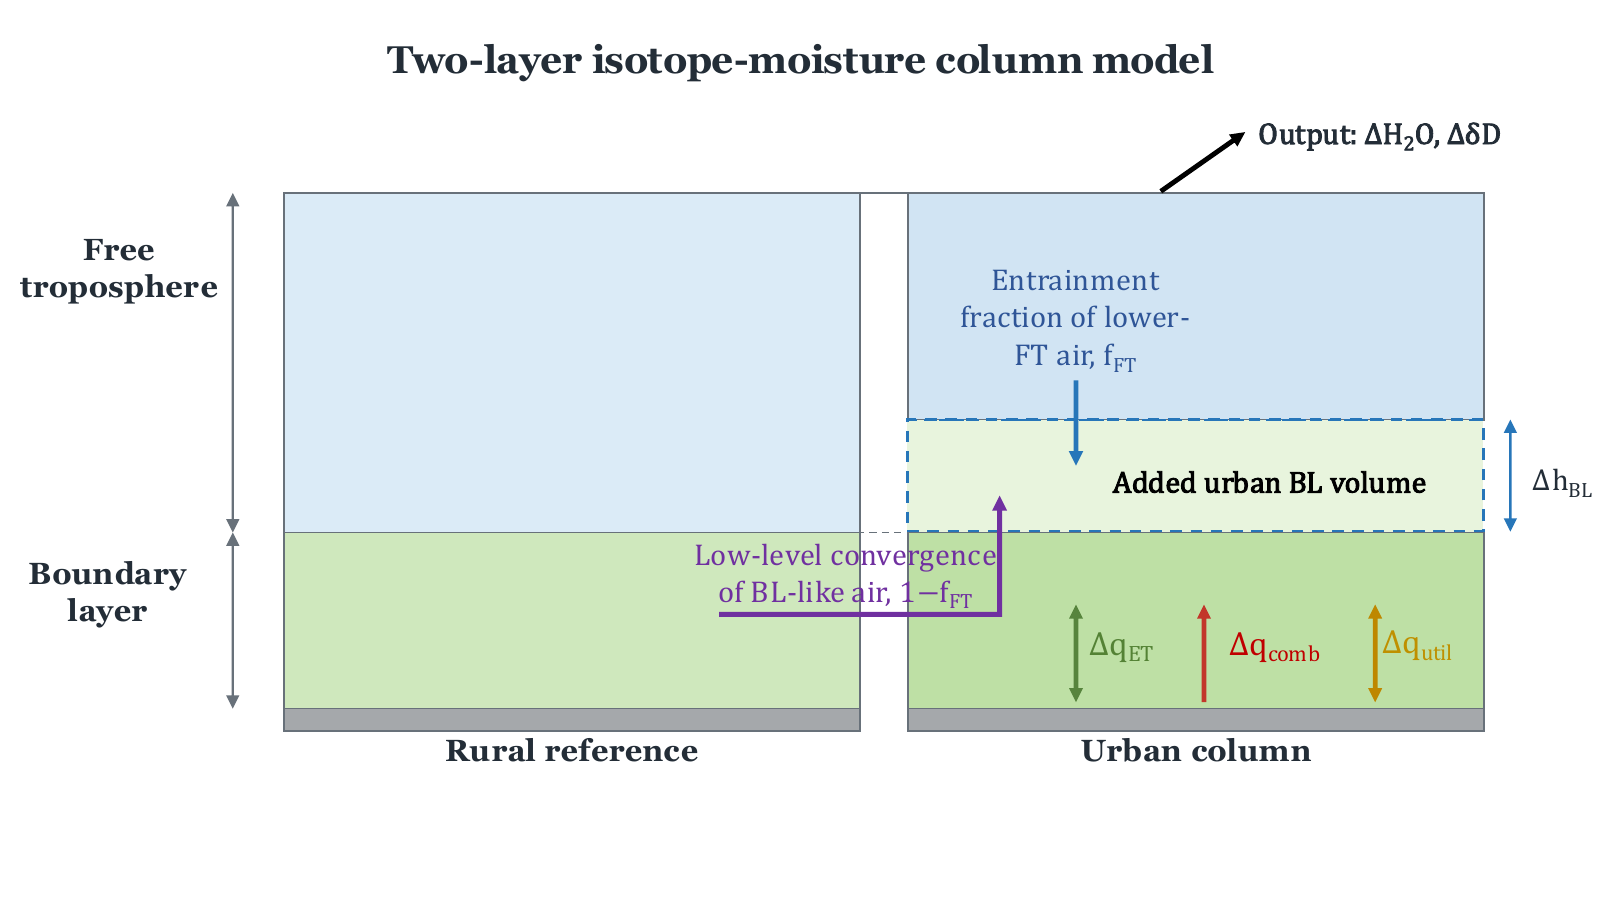


In [8]:
# Archive the static Figure 3 asset in the same output directory as code-generated figures.
from shutil import copy2
for suffix in [".png", ".pdf"]:
    source = ASSETS_DIR / f"Figure_3_Two_layer_model{suffix}"
    if source.exists():
        dest = OUTPUT_FIGURES_DIR / f"Figure_3_Two_layer_model{suffix}"
        copy2(source, dest)
        print("Saved:", dest.relative_to(PROJECT_ROOT))
    else:
        print("Missing asset:", source.relative_to(PROJECT_ROOT))


Saved: output/figures/Figure_3_Two_layer_model.png
Saved: output/figures/Figure_3_Two_layer_model.pdf


## Figure 2 - multi-city phase space, Monte Carlo model, regime selection, and model validation

Runs the city-season phase-space analysis and the idealized two-layer model. The section includes deterministic consistency tests, the 10-million-draw Monte Carlo ensemble, the decision-tree regime-selection diagnostic, and the outputs used for Figure 2 and downstream sensitivity analyses.


MC PRIOR TABLE  (source-equivalent control-volume formulation)
parameter               min        max  unit   
------------------------------------------------------------
Q_BL,r                    2         22  g/kg   
q_ent                     1         10  g/kg   
H_BL,r                  500       3000  m      
Δh_BL                     0       1000  m      
f_FT                      0          1  -      
ΔδD_grad                 60        130  permil 
ε_BL                    -15         15  permil 
ε_ent                   -25         25  permil 
H_q                    1500       3000  m      
Δq_combustion             0       0.05  g/kg   
Δq_util                -0.5        0.5  g/kg   
Δq_ET                  -2.5          1  g/kg   
Δ_ET                    -40        100  permil 
δD_combustion          -250        -80  permil 
δD_util                -150         10  permil 
------------------------------------------------------------
Rejection: combined source-equivalent Δq_src ∈ 

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


✅ Saved figure (PDF): /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Figure_2_Model_regimes.pdf


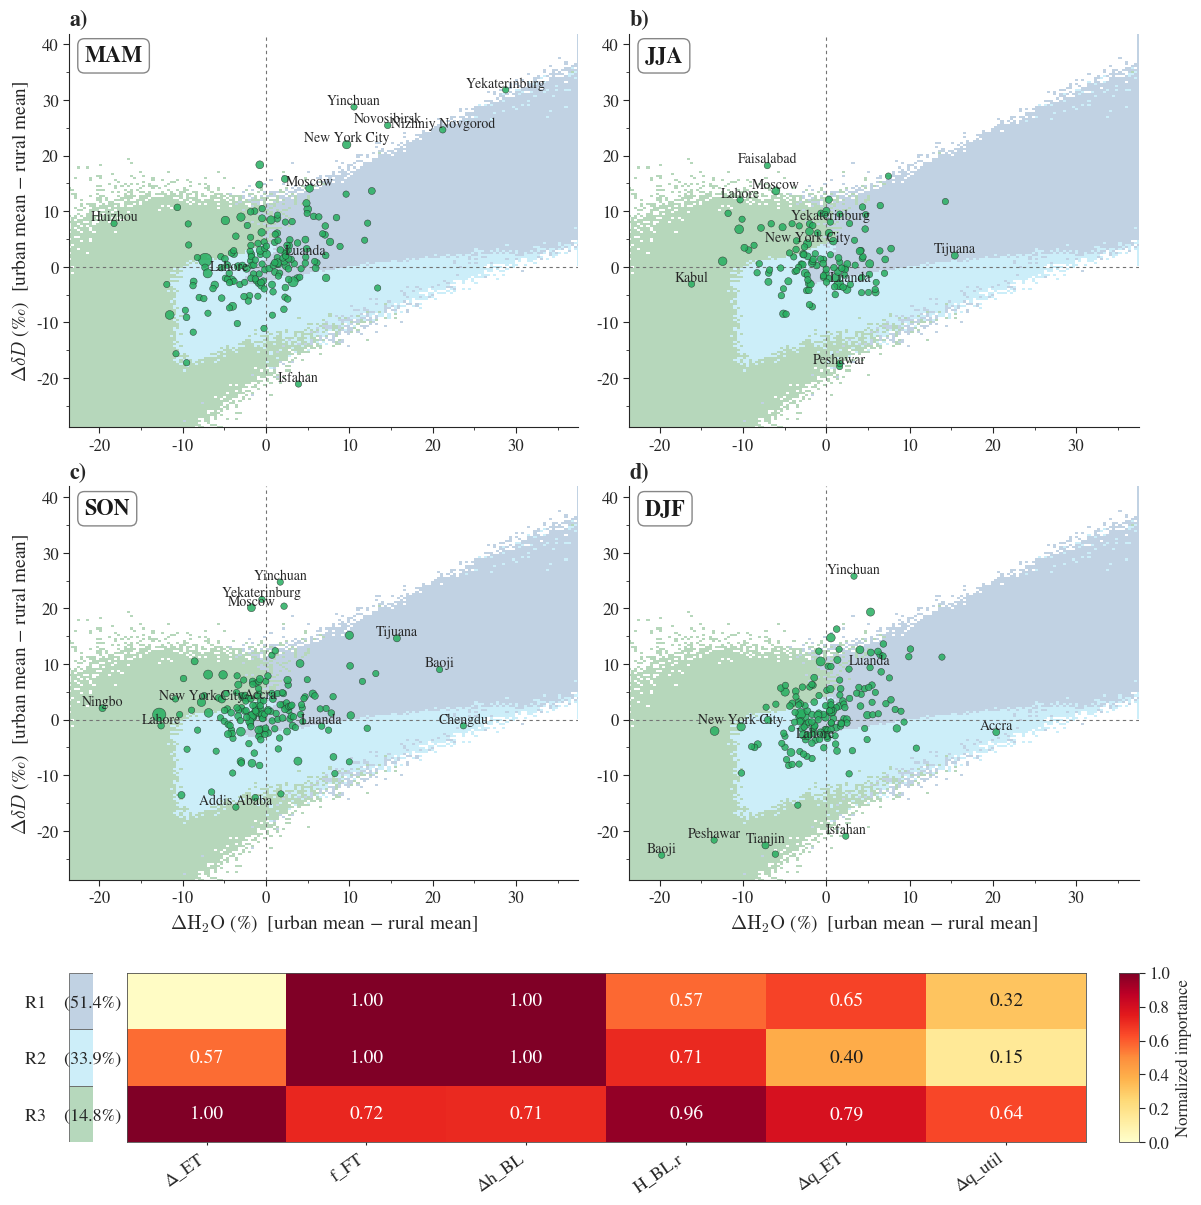

✅ Saved per-city CSV: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/Figure_2_cityseason_results.csv


In [9]:
# =============================================================================
# MC PRIOR BOUNDS — single source of truth
# =============================================================================
# To change any prior, edit ONLY this cell, then re-run downstream cells.
#
# References:
#   Hao et al. 2023, npj Clim. Atmos. Sci. 6:149
#   Fiorella et al. 2018, ACP 18:8529
#   Gorski et al. 2015, PNAS 112:3247
#   Dansgaard 1964, Tellus 16:436
#   Wallace & Hobbs, Atmospheric Science (textbook)

# ---- BL dynamics & background state ----
Q_BL_R   = (2.0,   22.0)     # g/kg    rural BL specific humidity (climatological range)
Q_ENT    = (1.0,   10.0)     # g/kg    lower-FT/entrainment humidity; anchors FT profile
H_BL_R   = (500.0, 3000.0)   # m       rural daytime BL height
DH_BL    = (0.0,   1000.0)   # m       urban BL deepening (UHI)
F_FT     = (0.0,   1.0)      # -       fraction of added BL fill from FT entrainment
DD_GRAD  = (60.0,  130.0)    # permil  bulk-FT depletion relative to entrainment air
EPS_BL   = (-15.0, 15.0)     # permil  BL composition residual
EPS_ENT  = (-25.0, 25.0)     # permil  entrainment composition residual
H_Q      = (1500.0, 3000.0)  # m       water vapor scale height (Wallace & Hobbs)

# ---- Source-equivalent BL humidity perturbations ----
# These are NOT physical fluxes. They are urban-minus-comparison
# source-equivalent specific-humidity perturbations. By default, their
# water-column contributions are referenced to the comparison/rural BL depth;
# an urban-depth alternative is available as an explicit sensitivity test.
DQ_COMBUSTION = (0.0,  0.05)   # g/kg     combustion source-equivalent Δq
DQ_UTIL       = (-0.50, 0.50)  # g/kg     managed-water source-equivalent Δq
DQ_ET         = (-2.5, 1.0)    # g/kg     signed ET source-equivalent Δq

# Observational plausibility envelope on the COMBINED source-equivalent
# perturbation Δq_src = Δq_ET + Δq_util + Δq_combustion (Hao et al. 2023).
HAO_DQ_TOTAL_MIN = -2.5         # g/kg
HAO_DQ_TOTAL_MAX =  1.0         # g/kg

# ---- Source compositions ----
DELTA_ET      = (-40.0,   100.0)   # permil  δD_ET offset from BL
DD_COMBUSTION = (-250.0, -80.0)    # permil  combustion vapor δD
DD_UTIL       = (-150.0, 10.0)     # permil  utilized water δD


# ---- Fixed model constants (not free parameters) ----
ALPHA_EFF = 1.1        # effective Rayleigh exponent
Q_REF     = 10.0       # g/kg, Rayleigh anchor q
DD_REF    = -100.0     # permil, Rayleigh anchor δD
z_top     = 9000.0     # m, FT thickness in column integration

# ---- Legacy *_MIN / *_MAX exports for downstream code ----
Q_BL_R_MIN, Q_BL_R_MAX               = Q_BL_R
Q_ENT_MIN, Q_ENT_MAX                 = Q_ENT
H_BL_R_MIN, H_BL_R_MAX               = H_BL_R
DH_BL_MIN, DH_BL_MAX                 = DH_BL
F_FT_MIN, F_FT_MAX                   = F_FT
DD_GRAD_MIN, DD_GRAD_MAX             = DD_GRAD
EPS_BL_MIN, EPS_BL_MAX               = EPS_BL
EPS_ENT_MIN, EPS_ENT_MAX             = EPS_ENT
H_Q_MIN, H_Q_MAX                     = H_Q
DQ_COMBUSTION_MIN, DQ_COMBUSTION_MAX = DQ_COMBUSTION
DQ_UTIL_MIN, DQ_UTIL_MAX             = DQ_UTIL
DQ_ET_MIN, DQ_ET_MAX                 = DQ_ET
DELTA_ET_MIN, DELTA_ET_MAX           = DELTA_ET
DD_COMBUSTION_MIN, DD_COMBUSTION_MAX = DD_COMBUSTION
DD_UTIL_MIN, DD_UTIL_MAX             = DD_UTIL

PRIOR_TABLE = [
    ('Q_BL,r',         Q_BL_R,         'g/kg'),
    ('q_ent',          Q_ENT,          'g/kg'),
    ('H_BL,r',         H_BL_R,         'm'),
    ('Δh_BL',          DH_BL,          'm'),
    ('f_FT',           F_FT,           '-'),
    ('ΔδD_grad',       DD_GRAD,        'permil'),
    ('ε_BL',           EPS_BL,         'permil'),
    ('ε_ent',          EPS_ENT,        'permil'),
    ('H_q',            H_Q,            'm'),
    ('Δq_combustion',  DQ_COMBUSTION,  'g/kg'),
    ('Δq_util',        DQ_UTIL,        'g/kg'),
    ('Δq_ET',          DQ_ET,          'g/kg'),
    ('Δ_ET',           DELTA_ET,       'permil'),
    ('δD_combustion',  DD_COMBUSTION,  'permil'),
    ('δD_util',        DD_UTIL,        'permil'),
]

def print_prior_table():
    print('=' * 60)
    print('MC PRIOR TABLE  (source-equivalent control-volume formulation)')
    print('=' * 60)
    print(f'{"parameter":<16} {"min":>10} {"max":>10}  {"unit":<7}')
    print('-' * 60)
    for name, (vmin, vmax), unit in PRIOR_TABLE:
        print(f'{name:<16} {vmin:>10.4g} {vmax:>10.4g}  {unit:<7}')
    print('-' * 60)
    print(f'Rejection: combined source-equivalent Δq_src ∈ '
          f'[{HAO_DQ_TOTAL_MIN:+.2f}, {HAO_DQ_TOTAL_MAX:+.2f}] g/kg '
          f'(Hao 2023 plausibility envelope)')
    print('=' * 60)

print_prior_table()


#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
Seasonal bulk-city scatterplots with a decision-tree regime background,
on-disk caching, model-consistency diagnostics, and per-regime importance.
---------------------------------------------------------------------------------

Model formulation used here:
  - exact ratio-space Rayleigh-like relationship for δD(q)
  - lower-FT/entrainment humidity q_ent anchors the exponential FT profile
  - explicit separation of internal FT entrainment from lateral BL-like
    convergence that crosses the modeled column boundary
  - source-equivalent ET / managed-water / combustion perturbations are not
    treated as physical fluxes
  - default source-to-column conversion uses the rural/comparison BL depth;
    urban-depth scaling is implemented as an explicit sensitivity test
  - Hao et al. constrains only the combined source-equivalent perturbation,
    not the final modeled BL-mean or column humidity anomaly

Pipeline:
  1. Run deterministic model-consistency tests (zero perturbation, pure
     entrainment conservation, explicit column-budget closure, and an
     independent fixed-vector reference calculation).
  2. Optionally compare rural-depth and urban-depth source scaling.
  3. Generate the Monte Carlo ensemble and retain physically valid draws.
  4. Train multi-output DecisionTreeRegressor models mapping the 15 input
     parameters to (ΔδD_col, ΔH2O_col), selecting tree size using the
     configured criterion (default: marginal gain in standardized R²).
  5. Each leaf of the selected tree defines one model regime.
  6. Compute per-regime parameter importance from Spearman and linear-R²
     diagnostics, then bin MC draws in phase space for visualization.

Caching (cache_tree_regimes/):
  - cities_<hash>.pkl   — seasonal city scatter dataframes
  - tree_<hash>.pkl     — trained tree, regime assignments, x_map/y_map,
                           per-regime importance.

Each cache hash includes relevant configuration values, data signatures,
software versions, and source code of the functions affecting the result.
"""

import os
import sys
import json
import pickle
import hashlib
import inspect
import shutil
import warnings
from datetime import datetime
from collections import Counter, defaultdict
import math
from math import ceil

import numpy as np
import pandas as pd
import xarray as xr
import rioxarray

import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator

from scipy.ndimage import distance_transform_edt
from scipy.ndimage import label as ndimage_label
from scipy.stats import ttest_1samp, spearmanr

import sklearn
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")


# =============================================================================
# PROJECT WORKSPACE
# =============================================================================
DATA_DIR = SOURCE_DATA_DIR
FIGURES_DIR = OUTPUT_FIGURES_DIR
RESULTS_DIR = OUTPUT_TABLES_DIR
CACHE_DIR = OUTPUT_CACHE_DIR
for _dir in [DATA_DIR, FIGURES_DIR, RESULTS_DIR, CACHE_DIR]:
    Path(_dir).mkdir(parents=True, exist_ok=True)




# =============================================================================
# CONFIGURATION
# =============================================================================

# ---- Paths ----
TROPOMI_PATH = str(FILES["tropomi_climatology"])
SETTLEMENT_NC_PATH = os.path.join(
    DATA_DIR,
    'PercentSettlementArea_regridded_to_TROPOMI_quadratic_climatology_0p05.nc'
)
SETTLEMENT_TIF_PATH = os.path.join(
    DATA_DIR,
    'PercentSettlementArea_regridded_to_TROPOMI_quadratic_climatology_0p05.tif'
)
ELEVATION_TIF_PATH = os.path.join(
    DATA_DIR,
    'ETOPO_2022_v1_30s_N90W180_surface_resampled_to_TROPOMI_quadratic_climatology_p05.tif'
)
LANDMASK_NC_PATH = os.path.join(
    DATA_DIR,
    'landseamask_regridded_to_TROPOMI_quadratic_climatology_0p05_nearest.nc'
)

CITY_CSV = os.path.join(
    DATA_DIR, 'top400_cities.csv'
)
CITY_CSV_CANDIDATES = [
    CITY_CSV,
]



# ---- Cache ----
CACHE_VERSION = '3.0'                # bump to invalidate every cache
USE_CACHE = True                     # master switch
FORCE_RECOMPUTE_CITIES = False       # ignore city cache once
FORCE_RECOMPUTE_TREE = False         # ignore tree cache once
CLEAR_CACHE = False                  # delete CACHE_DIR at startup

# ---- Forward-model formulation / validation ----
# Source-equivalent Δq terms are converted to column contributions using:
#   'rural' : H_source = H_BL,r   [default / primary formulation]
#   'urban' : H_source = H_BL,u   [explicit reviewer-requested sensitivity]
SOURCE_DEPTH_MODE = 'rural'

# Deterministic physical/bookkeeping tests. Leave True for production runs.
RUN_MODEL_CONSISTENCY_TESTS = True
MODEL_TEST_ATOL = 1e-9
MODEL_TEST_RTOL = 1e-11

# Optional same-draw sensitivity test comparing rural- vs urban-depth scaling.
# This is separate from the 10-million-draw production ensemble.
RUN_SOURCE_DEPTH_SENSITIVITY = True
SOURCE_DEPTH_SENS_N = 500_000
SOURCE_DEPTH_SENS_SEED = 314159

# ---- Seasonal city settings ----
SEASONS = ['MAM', 'JJA', 'SON', 'DJF']
SCATTER_N = 400
URBAN_MIN = 50.0
CONTROL_MAX = 1.0
BUFFER_RADIUS_KM = 150.0
ELEV_DIFF_THR = 50.0
COAST_DIFF_THR = 50.0
CITY_COAST_MIN_KM = 0.0
CITY_COAST_MAX_KM = np.inf
MIN_COUNT_PER_MONTH = 5.0
MIN_SUPPORTED_MONTHS = 2
WEIGHT_CITY_MEANS_BY_TOTAL_OBS = False
MIN_URBAN_PIXELS = 5
MIN_BUFFER_PIXELS = 10
USE_CITY_SIGNIFICANCE = False
SIG_VARIABLE = 'both'
SHOW_CENTROID_AND_STATS = False

# LABEL_CITIES = {
#     'Moscow', 'New York City', 'Montreal', 'Toronto', 'Melbourne',
#     'Riyadh', 'Accra', 'Lome', 'Luanda', 'Yekaterinburg'
# }

# LABEL_CITIES = {
#     'Moscow', 'New York City', 'Toronto', 'Melbourne','Lahore'
#     'Riyadh', 'Accra', 'Lome', 'Luanda', 'Yekaterinburg'
# }

LABEL_CITIES = {
    'Moscow', 'New York City', 'Lahore', 'Accra', 'Luanda', 'Yekaterinburg'
}

LABEL_BY_RADIUS = True
LABEL_RADIUS_NORM = 0.50
MAX_RADIUS_LABELS = 15

# ---- Regime-map settings ----
REGIME_SEED = 42
REGIME_N = 10_000_000
MAP_SUBSAMPLE = 5_000_000
GRID_NX = 195
GRID_NY = 165

# ---- Decision-tree regime classification settings ----
# Tree partitions parameter space into leaves; each leaf becomes a regime.
TREE_LEAF_MIN = 2
TREE_LEAF_MAX = 8
TREE_MAX_DEPTH = 6
TREE_MIN_SAMPLES_LEAF_FRAC = 0.02   # min leaf size as fraction of training samples
TREE_CRITERION = 'squared_error'

# How to pick the "best" tree from the leaf-count sweep.
#   'fixed'      : use TREE_FIXED_N_LEAVES (most defensible — the regime count
#                  is a reported methodological choice, not an artifact of a
#                  selection heuristic).
#   'r2_marginal': largest n_leaves where the gain from the preceding step,
#                  R²(n) − R²(n−1), is still ≥ TREE_R2_MARGINAL_MIN. Stops
#                  adding regimes when each one explains less than the
#                  threshold-fraction of additional phase-space variance.
#                  Reads as "we keep regimes that earn their keep."
#   'r2_elbow'   : smallest n_leaves whose training R² is within
#                  TREE_R2_ELBOW_TOL of the max R² over the sweep. Less
#                  granular than 'r2_marginal' — picks the corner of the
#                  curve, not where the slope drops.
#   'silhouette' : legacy criterion. NOT RECOMMENDED — silhouette is computed
#                  in 2D phase space but the tree partitions in 15D parameter
#                  space, so it systematically prefers tiny trees (any
#                  refinement creates phase-space overlap that silhouette
#                  penalizes, regardless of physical meaningfulness).
TREE_SELECTION = 'r2_marginal'
TREE_FIXED_N_LEAVES = 8           # used when TREE_SELECTION == 'fixed'
TREE_R2_ELBOW_TOL = 0.01          # used when TREE_SELECTION == 'r2_elbow'
TREE_R2_MARGINAL_MIN = 0.05       # used when TREE_SELECTION == 'r2_marginal'

# Phase-space binning of MC draws to build the regime-id grid.
MIN_DRAWS_PER_CELL = 5              # grid-cell support threshold

# How many regimes to display & how many top params per regime.
TOPN = 3                             # top-N defines the regime "key" tuple
MAX_REGIMES_TO_SHOW = 8
OTHER_LABEL = 'Other'
REGIME_BACKGROUND_ALPHA = 0.33       # alpha applied to phase-space cmap

# Silhouette evaluation sample size (full silhouette is O(n²) memory).
SILHOUETTE_SAMPLE = 50_000

# ---- Heatmap-specific ----
HEATMAP_CMAP = 'YlOrRd'
HEATMAP_ANNOT_THRESHOLD = 0.05       # annotate cells whose value ≥ this
RULE_MAX_CHARS = 140                 # truncate rule body in figure (full rule still in CSV)

# How many parameters to display in the heatmap (most important first).
# Set HEATMAP_N_PARAMS_SHOW = None to show all parameters. The full
# 15-parameter importance matrix is always saved to disk regardless.
HEATMAP_N_PARAMS_SHOW = 6
HEATMAP_PARAM_RANK_BY = 'max'        # 'max' or 'mean' across kept regimes
HEATMAP_SORT_PARAMS = True           # reorder cols, most-important leftmost

# ---- Font sizes (single source of truth — change these to scale everything) ----
# Units are matplotlib points. The figure is 13.8" wide; if you change figure
# size substantially, scale these proportionally.
FONT_PANEL_LABEL = 16        # 'a)', 'b)' panel letters
FONT_SEASON_BOX = 16         # 'MAM', 'JJA' season label inside scatter panels
FONT_AXIS_LABEL = 14         # ΔδD / ΔH₂O axis labels on scatter panels
FONT_AXIS_TICK = 12          # tick labels on scatter panels
FONT_CITY_LABEL = 10         # city name labels in scatter
FONT_LEGEND = 11             # 'Cities' legend
# Heatmap fonts
FONT_HEATMAP_CELL = 14       # numbers inside heatmap cells
FONT_HEATMAP_TICK = 13       # parameter names + regime row labels
FONT_HEATMAP_CBAR = 12       # colorbar label + ticks
FONT_HEATMAP_FOOTNOTE = 11   # 'Top N of 15...' footnote

# ---- Outputs ----
OUTPUT_DIR = FIGURES_DIR
MODEL_TAG = f'{SOURCE_DEPTH_MODE}SourceDepth'

SAVE_RESULTS_CSV = True
SAVE_FIG = True
SAVE_TREE_RESULTS = True
TREE_RULES_PATH = os.path.join(
    RESULTS_DIR, f'TreeRegimes_decision_rules_{MODEL_TAG}.csv'
)
TREE_IMPORTANCE_PATH = os.path.join(
    RESULTS_DIR, f'TreeRegimes_importance_matrix_{MODEL_TAG}.csv'
)
TREE_OPT_PATH = os.path.join(
    RESULTS_DIR, f'TreeRegimes_optimization_{MODEL_TAG}.csv'
)

SAVE_TREE_DIAGNOSTIC_FIG = True
TREE_DIAGNOSTIC_FIG_PATH = os.path.join(FIGURES_DIR, "Supplement_Figure_3_Regime_selection.png")
TREE_RULES_FIG_PATH = os.path.join(
    FIGURES_DIR, f'TreeRegimes_decision_rules_{MODEL_TAG}.png'
)

SAVE_DIAGNOSTICS = True
DIAGNOSTICS_PATH = os.path.join(
    RESULTS_DIR, f'MC_partition_diagnostics_{MODEL_TAG}.csv'
)
DIAGNOSTICS_SUMMARY_PATH = os.path.join(
    RESULTS_DIR, f'MC_partition_summary_{MODEL_TAG}.csv'
)
MODEL_VALIDATION_PATH = os.path.join(
    RESULTS_DIR, 'Model_consistency_tests.json'
)
SOURCE_DEPTH_SENS_PATH = os.path.join(
    RESULTS_DIR, 'Source_depth_rural_vs_urban_sensitivity.csv'
)

SAVE_MC_DRAWS = False  # not required for manuscript reproduction
MC_DRAWS_PATH = os.path.join(
    RESULTS_DIR, f'MC_draws_{MODEL_TAG}.parquet'
)

# ---- Same-day robustness-test exports ----
# These are observational bookkeeping products only; they do not alter the
# city selection, climatology metrics, model, or plotting calculations.
SAVE_DAILY_VALIDATION_MASKS = True
DAILY_VALIDATION_MASKS_PATH = os.path.join(RESULTS_DIR, "Figure_2_city_grid_masks.csv")

SAVE_DAILY_VALIDATION_GRID = True
DAILY_VALIDATION_GRID_PATH = os.path.join(CACHE_DIR, "Figure_2_grid_coords.npz")


# =============================================================================
# PARAMETER METADATA
# =============================================================================
PARAM_NAMES = [
    'Δh_BL',
    'f_FT',
    'q_ent',
    'ε_BL',
    'ε_ent',
    'ΔδD_grad',
    'Δq_combustion',
    'Δq_util',
    'Δq_ET',
    'Δ_ET',
    'δD_combustion',
    'δD_util',
    'Q_BL,r',
    'H_BL,r',
    'H_q',
]
PARAM_INDEX = {p: i for i, p in enumerate(PARAM_NAMES)}
N_PARAMS = len(PARAM_NAMES)


# =============================================================================
# COLOR HELPERS
# =============================================================================

def alpha_blend(color, alpha, bg=(1.0, 1.0, 1.0)):
    """Effective rgb you'd see when `color` is drawn at `alpha` over `bg`.
    This is what matplotlib's compositing produces, so using this for heatmap
    swatches and rule bullets keeps colors consistent with the phase-space
    figure (which renders the regime cmap at REGIME_BACKGROUND_ALPHA).
    """
    rgb = mpl.colors.to_rgb(color)
    bg_rgb = mpl.colors.to_rgb(bg)
    return tuple(c * alpha + b * (1.0 - alpha) for c, b in zip(rgb, bg_rgb))


def regime_colors_for_n(n_show):
    """The color sequence used everywhere; first n_show are kept regimes,
    last entry is the 'Other' grey."""
    base_colors = [
        '#4477AA', '#66CCEE', '#228833', '#CCBB44',
        '#EE6677', '#AA3377', '#44AA99', '#999933',
        '#882255', '#332288', '#117733', '#DDCC77',
    ]
    if n_show > len(base_colors):
        cmap_extra = plt.get_cmap('tab20')
        base_colors = [mpl.colors.to_hex(cmap_extra(i)) for i in range(n_show)]
    return base_colors[:n_show] + ['#BFBFBF']


# =============================================================================
# GENERAL HELPERS
# =============================================================================

def haversine_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    return 2.0 * np.arcsin(np.sqrt(a)) * 6371.0


def fix_longitude_convention(data, lons, target_convention='0_360'):
    if target_convention == '0_360' and lons[0] < 0:
        split_idx = np.where(lons >= 0)[0][0]
        data_fixed = np.concatenate([data[:, split_idx:], data[:, :split_idx]], axis=1)
        lons_fixed = np.concatenate([lons[split_idx:], lons[:split_idx] + 360.0])
        return data_fixed, lons_fixed
    return data, lons


def get_season_months(season='annual'):
    season = season.upper()
    season_months = {
        'ANNUAL': list(range(12)),
        'DJF': [11, 0, 1],
        'MAM': [2, 3, 4],
        'JJA': [5, 6, 7],
        'SON': [8, 9, 10],
    }
    if season not in season_months:
        raise ValueError(f"Season must be one of: {list(season_months.keys())}")
    return season_months[season]


def get_weighted_seasonal_data(data_array, count_array, season='annual', min_count_per_month=5.0):
    months = get_season_months(season)
    data_sel = data_array.isel(time=months).values.astype(float)
    count_sel = count_array.isel(time=months).values.astype(float)
    valid = (
        np.isfinite(data_sel) &
        np.isfinite(count_sel) &
        (count_sel >= float(min_count_per_month))
    )
    weighted_sum = np.sum(np.where(valid, data_sel * count_sel, 0.0), axis=0)
    total_count = np.sum(np.where(valid, count_sel, 0.0), axis=0)
    weighted_mean = np.full(total_count.shape, np.nan, dtype=float)
    ok = total_count > 0
    weighted_mean[ok] = weighted_sum[ok] / total_count[ok]
    supported_months = np.sum(valid, axis=0).astype(float)
    return weighted_mean, supported_months, total_count


def bbox_mask_180(df_lons_180, df_lats, lat_min, lat_max, lon_min, lon_max):
    lat_ok = (df_lats >= lat_min) & (df_lats <= lat_max)
    if lon_min < -180:
        lon_ok = (df_lons_180 >= lon_min + 360.0) | (df_lons_180 <= lon_max)
    elif lon_max > 180:
        lon_ok = (df_lons_180 >= lon_min) | (df_lons_180 <= lon_max - 360.0)
    else:
        lon_ok = (df_lons_180 >= lon_min) & (df_lons_180 <= lon_max)
    return lat_ok & lon_ok


def weighted_or_unweighted_mean(values, weights=None, use_weights=False):
    values = np.asarray(values, dtype=float)
    good = np.isfinite(values)
    if not np.any(good):
        return np.nan
    values = values[good]
    if use_weights:
        if weights is None:
            raise ValueError('weights must be provided when use_weights=True')
        weights = np.asarray(weights, dtype=float)[good]
        good_w = np.isfinite(weights) & (weights > 0)
        if not np.any(good_w):
            return np.nan
        return float(np.average(values[good_w], weights=weights[good_w]))
    return float(np.mean(values))


def load_city_dataframe(city_csv=None):
    if city_csv is not None and os.path.exists(city_csv):
        df = pd.read_csv(city_csv)
    else:
        found = None
        for cand in CITY_CSV_CANDIDATES:
            if os.path.exists(cand):
                found = cand
                break
        if found is None:
            raise FileNotFoundError(
                'Could not find a city CSV. Set CITY_CSV to your city table path.'
            )
        df = pd.read_csv(found)
        print(f'Loaded city metadata from: {found}')

    required = ['name', 'latitude', 'longitude', 'lat_min', 'lat_max', 'lon_min', 'lon_max']
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f'City CSV is missing required columns: {missing}')

    if 'city_key' not in df.columns:
        df['city_key'] = (
            df['name'].astype(str).str.strip()
            .str.replace(r'\s+', '_', regex=True)
            .str.replace(r'[^A-Za-z0-9_]', '', regex=True)
        )
    if 'population' in df.columns:
        df = df.sort_values('population', ascending=False).reset_index(drop=True)
    return df.copy()


def _resolve_city_csv_path():
    """Return the city CSV path that load_city_dataframe would actually use,
    or None if no candidate exists. Used for cache keying."""
    if CITY_CSV is not None and os.path.exists(CITY_CSV):
        return CITY_CSV
    for cand in CITY_CSV_CANDIDATES:
        if os.path.exists(cand):
            return cand
    return None


def load_all_data(season='annual', min_count_per_month=5.0):
    print(f"\n📂 Loading datasets for {season.upper()}...")
    tropomi_ds = xr.open_dataset(TROPOMI_PATH)
    deltad = tropomi_ds['deltad']
    h2o_column = tropomi_ds['h2o_column']
    count = tropomi_ds['count']
    lats = tropomi_ds['lat'].values
    lons = tropomi_ds['lon'].values

    sample_values = deltad.isel(time=0).values.flatten()
    sample_values = sample_values[np.isfinite(sample_values)]
    if len(sample_values) > 0 and np.ptp(sample_values) < 10:
        deltad = deltad * 1000.0

    print('   Computing weighted pixel means...')
    deltad_seasonal, supported_months, total_obs_count = get_weighted_seasonal_data(
        deltad, count, season=season, min_count_per_month=min_count_per_month
    )
    h2o_seasonal, _, _ = get_weighted_seasonal_data(
        h2o_column, count, season=season, min_count_per_month=min_count_per_month
    )

    settlement_ds = None
    try:
        settlement_ds = xr.open_dataset(SETTLEMENT_NC_PATH)
        settlement = settlement_ds['settlement_percentage'].values
    except Exception:
        settlement_ds = rioxarray.open_rasterio(SETTLEMENT_TIF_PATH)
        settlement = settlement_ds.values[0] if len(settlement_ds.shape) == 3 else settlement_ds.values

    elevation_ds = rioxarray.open_rasterio(ELEVATION_TIF_PATH)
    elevation = elevation_ds.values[0] if len(elevation_ds.shape) == 3 else elevation_ds.values
    elev_lons = elevation_ds.x.values
    elevation, elev_lons = fix_longitude_convention(elevation, elev_lons, target_convention='0_360')
    elevation[elevation < -10000] = np.nan

    landmask_ds = xr.open_dataset(LANDMASK_NC_PATH)
    land_mask = landmask_ds['land_mask'].values

    lat_2d, lon_2d = np.meshgrid(lats, lons, indexing='ij')
    grid_i_2d, grid_j_2d = np.meshgrid(
        np.arange(len(lats), dtype=np.int32),
        np.arange(len(lons), dtype=np.int32),
        indexing='ij'
    )
    ocean_mask = (land_mask == 0)
    distance_grid_cells = distance_transform_edt(~ocean_mask)

    lat_rad = np.deg2rad(lat_2d)
    dx_km = 0.05 * 111.0 * np.cos(lat_rad)
    dy_km = 0.05 * 111.0
    avg_cell_size_km = np.sqrt(dx_km ** 2 + dy_km ** 2) / np.sqrt(2.0)
    distance_to_ocean_km = distance_grid_cells * avg_cell_size_km

    df = pd.DataFrame({
        'delta_D': deltad_seasonal.flatten(),
        'h2o_column': h2o_seasonal.flatten(),
        'supported_months': supported_months.flatten(),
        'total_obs_count': total_obs_count.flatten(),
        'settlement_pct': settlement.flatten(),
        'elevation': elevation.flatten(),
        'latitude': lat_2d.flatten(),
        'longitude': lon_2d.flatten(),
        'grid_i': grid_i_2d.flatten(),
        'grid_j': grid_j_2d.flatten(),
        'dist_to_coast': distance_to_ocean_km.flatten(),
        'land_mask': land_mask.flatten(),
    })
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    df = df[(df['land_mask'] == 1) & (df['elevation'] > -50)].copy()
    df = df.drop(columns=['land_mask'])
    print(f'   Total land pixels: {len(df):,}')

    for ds in [tropomi_ds, landmask_ds, elevation_ds, settlement_ds]:
        try:
            if ds is not None:
                ds.close()
        except Exception:
            pass

    return df, lats, lons


try:
    from scipy.stats import binomtest as _binomtest
    def _sign_test_p(x):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]
        x = x[x != 0]
        n = int(x.size)
        if n < 3:
            return np.nan
        k = int((x > 0).sum())
        return float(_binomtest(k, n, 0.5, alternative='two-sided').pvalue)
except Exception:
    from scipy.stats import binom_test as _binom_test
    def _sign_test_p(x):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]
        x = x[x != 0]
        n = int(x.size)
        if n < 3:
            return np.nan
        k = int((x > 0).sum())
        return float(_binom_test(k, n, 0.5))


def _fmt_p(p):
    if not np.isfinite(p):
        return 'n/a'
    if p < 1e-3:
        return '<0.001'
    return f'{p:.3f}'


def _nature_axes(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('0.15')
    ax.spines['bottom'].set_color('0.15')
    ax.tick_params(axis='both', which='both', direction='out', top=False, right=False, colors='0.15')
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))


def _radius_label_names(plot_df, xcol, ycol, xlim, ylim, radius_norm=0.55, max_labels=None):
    if len(plot_df) == 0:
        return set()
    xref = max(abs(xlim[0]), abs(xlim[1]), 1e-12)
    yref = max(abs(ylim[0]), abs(ylim[1]), 1e-12)
    tmp = plot_df[[xcol, ycol, 'name']].dropna().copy()
    tmp['_rnorm'] = np.sqrt((tmp[xcol] / xref) ** 2 + (tmp[ycol] / yref) ** 2)
    tmp = tmp[tmp['_rnorm'] >= radius_norm].sort_values('_rnorm', ascending=False)
    if max_labels is not None:
        tmp = tmp.head(int(max_labels))
    return set(tmp['name'].tolist())


def _prune_nearby_labels(plot_df, xcol, ycol, candidate_names,
                         x_sep_frac=0.036, y_sep_frac=0.055,
                         priority_col=None, keep_larger_priority=True):
    cand = plot_df[plot_df['name'].isin(candidate_names)].copy()
    if len(cand) == 0:
        return set()
    if priority_col is not None and priority_col in cand.columns:
        cand = cand.sort_values(priority_col, ascending=not keep_larger_priority)
    else:
        cand['_r2'] = cand[xcol] ** 2 + cand[ycol] ** 2
        cand = cand.sort_values('_r2', ascending=False)
    xspan = max(float(plot_df[xcol].max() - plot_df[xcol].min()), 1e-12)
    yspan = max(float(plot_df[ycol].max() - plot_df[ycol].min()), 1e-12)
    x_tol = x_sep_frac * xspan
    y_tol = y_sep_frac * yspan
    kept = []
    kept_names = set()
    for _, row in cand.iterrows():
        x = float(row[xcol]); y = float(row[ycol])
        overlaps = False
        for xk, yk in kept:
            if abs(x - xk) < x_tol and abs(y - yk) < y_tol:
                overlaps = True
                break
        if not overlaps:
            kept.append((x, y))
            kept_names.add(row['name'])
    return kept_names


# =============================================================================
# SEASONAL CITY METRICS (unchanged from sensitivity version)
# =============================================================================

def compute_bulk_scatter_df_for_season(season, city_df_filtered):
    df_full, lats_global, lons_global = load_all_data(
        season=season, min_count_per_month=MIN_COUNT_PER_MONTH
    )
    lons_180 = lons_global.copy()
    lons_180[lons_180 > 180] -= 360.0

    df_valid = df_full[(df_full['supported_months'] >= MIN_SUPPORTED_MONTHS)].copy()
    print(f'Using count-weighted {season.upper()} pixel means')
    print(f'Pixels passing support rule: {len(df_valid):,} of {len(df_full):,}')

    df_rural = df_valid[df_valid['settlement_pct'] <= CONTROL_MAX].copy()
    rural_lons = df_rural['longitude'].values.copy()
    rural_lons[rural_lons > 180] -= 360.0
    df_rural = df_rural.assign(longitude_180=rural_lons)

    rural_lats_arr = df_rural['latitude'].values
    rural_lons_arr = df_rural['longitude_180'].values
    rural_elev_arr = df_rural['elevation'].values
    rural_coast_arr = df_rural['dist_to_coast'].values

    df_full_lons_180 = df_full['longitude'].values.copy()
    df_full_lons_180[df_full_lons_180 > 180] -= 360.0
    df_valid_lons_180 = df_valid['longitude'].values.copy()
    df_valid_lons_180[df_valid_lons_180 > 180] -= 360.0

    def _get_city_component_and_controls(crow):
        lat_min, lat_max = crow['lat_min'], crow['lat_max']
        lon_min, lon_max = crow['lon_min'], crow['lon_max']
        clat, clon = crow['latitude'], crow['longitude']
        if clon > 180:
            clon -= 360

        mask_full = bbox_mask_180(
            df_full_lons_180, df_full['latitude'].values,
            lat_min, lat_max, lon_min, lon_max
        )
        df_region = df_full[mask_full].copy()
        df_region = df_region.assign(longitude_180=df_full_lons_180[mask_full])

        mask_valid = bbox_mask_180(
            df_valid_lons_180, df_valid['latitude'].values,
            lat_min, lat_max, lon_min, lon_max
        )
        df_region_valid = df_valid[mask_valid].copy()
        df_region_valid = df_region_valid.assign(longitude_180=df_valid_lons_180[mask_valid])

        lat_idx = np.where((lats_global >= lat_min) & (lats_global <= lat_max))[0]
        lat_sub = lats_global[lat_idx]

        if lon_min < -180:
            lon_idx = np.where((lons_180 >= lon_min + 360.0) | (lons_180 <= lon_max))[0]
        elif lon_max > 180:
            lon_idx = np.where((lons_180 >= lon_min) | (lons_180 <= lon_max - 360.0))[0]
        else:
            lon_idx = np.where((lons_180 >= lon_min) & (lons_180 <= lon_max))[0]
        lon_sub = lons_180[lon_idx]
        lon_sub = lon_sub[np.argsort(lon_sub)]
        nlat, nlon = len(lat_sub), len(lon_sub)
        if nlat == 0 or nlon == 0:
            return None

        lat_to_i = {round(float(v), 4): i for i, v in enumerate(lat_sub)}
        lon_to_j = {round(float(v), 4): j for j, v in enumerate(lon_sub)}

        def _fill_local(src_df, lon_col='longitude_180'):
            grid = np.full((nlat, nlon), np.nan)
            lts = src_df['latitude'].values
            lns = src_df[lon_col].values if lon_col in src_df.columns else src_df['longitude'].values.copy()
            for k in range(len(src_df)):
                i = lat_to_i.get(round(float(lts[k]), 4))
                j = lon_to_j.get(round(float(lns[k]), 4))
                if i is not None and j is not None:
                    grid[i, j] = 1.0
            return grid

        df_urban_geom = df_region[df_region['settlement_pct'] >= URBAN_MIN].copy()
        if len(df_urban_geom) < MIN_URBAN_PIXELS:
            return None

        urban_binary = (~np.isnan(_fill_local(df_urban_geom))).astype(int)
        labeled, n_components = ndimage_label(urban_binary)

        ci = np.argmin(np.abs(lat_sub - clat))
        cj = np.argmin(np.abs(lon_sub - clon))
        city_label = labeled[ci, cj]

        if city_label == 0:
            found = False
            for radius in range(1, max(nlat, nlon)):
                for di in range(-radius, radius + 1):
                    for dj in range(-radius, radius + 1):
                        ni, nj = ci + di, cj + dj
                        if 0 <= ni < nlat and 0 <= nj < nlon and labeled[ni, nj] > 0:
                            city_label = labeled[ni, nj]
                            found = True
                            break
                    if found:
                        break
                if found:
                    break

        if city_label == 0:
            return None

        df_urban_valid = df_region_valid[df_region_valid['settlement_pct'] >= URBAN_MIN].copy()
        keep_rows = []
        for k in range(len(df_urban_valid)):
            i = lat_to_i.get(round(float(df_urban_valid['latitude'].values[k]), 4))
            j = lon_to_j.get(round(float(df_urban_valid['longitude_180'].values[k]), 4))
            if i is not None and j is not None and labeled[i, j] == city_label:
                keep_rows.append(k)
        df_urban = df_urban_valid.iloc[keep_rows].copy()
        if len(df_urban) < MIN_URBAN_PIXELS:
            return None

        comp_mask = (labeled == city_label)
        comp_i, comp_j = np.where(comp_mask)
        comp_lats_geo = np.array([lat_sub[i] for i in comp_i])
        comp_lons_geo = np.array([lon_sub[j] for j in comp_j])
        global_key = (
            round(float(comp_lats_geo.mean()), 2),
            round(float(comp_lons_geo.mean()), 2)
        )

        mean_urban_elev = weighted_or_unweighted_mean(
            df_urban['elevation'].values,
            weights=df_urban['total_obs_count'].values,
            use_weights=WEIGHT_CITY_MEANS_BY_TOTAL_OBS
        )
        mean_urban_coast = weighted_or_unweighted_mean(
            df_urban['dist_to_coast'].values,
            weights=df_urban['total_obs_count'].values,
            use_weights=WEIGHT_CITY_MEANS_BY_TOTAL_OBS
        )
        urban_clat = float(df_urban['latitude'].mean())
        urban_clon = float(df_urban['longitude_180'].mean())

        dist_to_centroid = haversine_distance(rural_lats_arr, rural_lons_arr, urban_clat, urban_clon)
        elev_diff = np.abs(rural_elev_arr - mean_urban_elev)
        coast_diff = np.abs(rural_coast_arr - mean_urban_coast)

        buf_mask = (
            (dist_to_centroid <= BUFFER_RADIUS_KM) &
            (elev_diff <= ELEV_DIFF_THR) &
            (coast_diff <= COAST_DIFF_THR)
        )
        df_buffer = df_rural[buf_mask].copy()
        if len(df_buffer) < MIN_BUFFER_PIXELS:
            return None

        return {
            'df_urban': df_urban, 'df_buffer': df_buffer,
            'global_key': global_key,
            'n_urban': len(df_urban), 'n_buffer': len(df_buffer),
            'n_components': int(n_components),
        }

    calc_city_pvalues = bool(USE_CITY_SIGNIFICANCE)
    print(f"\nComputing BULK metrics for up to {len(city_df_filtered.head(SCATTER_N))} cities in {season} ...")

    scatter_rows = []
    mask_frames = []
    claimed_centroids = {}

    for _, crow in city_df_filtered.head(SCATTER_N).iterrows():
        name = crow['name']
        result = _get_city_component_and_controls(crow)
        if result is None:
            continue

        global_key = result['global_key']
        if global_key in claimed_centroids:
            continue
        claimed_centroids[global_key] = name

        df_urban = result['df_urban']
        df_buffer = result['df_buffer']

        # Preserve the exact target-grid cells used for this accepted
        # city-season. These rows are exported later for the same-day
        # robustness test; they do not affect any climatology calculation.
        for role, mask_df_src in [('urban', df_urban), ('rural', df_buffer)]:
            mask_frames.append(pd.DataFrame({
                'season': season,
                'city_key': crow['city_key'],
                'name': name,
                'role': role,
                'grid_i': mask_df_src['grid_i'].to_numpy(dtype=np.int32),
                'grid_j': mask_df_src['grid_j'].to_numpy(dtype=np.int32),
            }))

        rural_mean_d = weighted_or_unweighted_mean(
            df_buffer['delta_D'].values,
            weights=df_buffer['total_obs_count'].values,
            use_weights=WEIGHT_CITY_MEANS_BY_TOTAL_OBS
        )
        rural_mean_h2o = weighted_or_unweighted_mean(
            df_buffer['h2o_column'].values,
            weights=df_buffer['total_obs_count'].values,
            use_weights=WEIGHT_CITY_MEANS_BY_TOTAL_OBS
        )
        urban_mean_d = weighted_or_unweighted_mean(
            df_urban['delta_D'].values,
            weights=df_urban['total_obs_count'].values,
            use_weights=WEIGHT_CITY_MEANS_BY_TOTAL_OBS
        )
        urban_mean_h2o = weighted_or_unweighted_mean(
            df_urban['h2o_column'].values,
            weights=df_urban['total_obs_count'].values,
            use_weights=WEIGHT_CITY_MEANS_BY_TOTAL_OBS
        )

        diff_d_mean = urban_mean_d - rural_mean_d
        diff_h_mean = 100.0 * (urban_mean_h2o - rural_mean_h2o) / abs(rural_mean_h2o) if rural_mean_h2o != 0 else np.nan

        if calc_city_pvalues:
            _, p_val_d = ttest_1samp(df_urban['delta_D'].values - rural_mean_d, 0.0)
            _, p_val_h = ttest_1samp(df_urban['h2o_column'].values - rural_mean_h2o, 0.0)
            p_val_d = float(p_val_d)
            p_val_h = float(p_val_h)
        else:
            p_val_d = np.nan
            p_val_h = np.nan

        sig_d = (p_val_d < 0.05) if calc_city_pvalues else False
        sig_h2o = (p_val_h < 0.05) if calc_city_pvalues else False
        sig_both = (sig_d and sig_h2o) if calc_city_pvalues else False

        scatter_rows.append({
            'season': season, 'name': name, 'city_key': crow['city_key'],
            'n_urban': result['n_urban'], 'n_buffer': result['n_buffer'],
            'n_components': result['n_components'],
            'diff_d_mean': diff_d_mean, 'diff_h_mean': diff_h_mean,
            'urban_mean_d': urban_mean_d, 'urban_mean_h2o': urban_mean_h2o,
            'rural_mean_d': rural_mean_d, 'rural_mean_h2o': rural_mean_h2o,
            'p_val_d': p_val_d, 'p_val_h2o': p_val_h,
            'sig_d': sig_d, 'sig_h2o': sig_h2o, 'sig_both': sig_both,
            'urban_mean_total_obs_count': float(df_urban['total_obs_count'].mean()),
            'rural_mean_total_obs_count': float(df_buffer['total_obs_count'].mean()),
            'urban_mean_supported_months': float(df_urban['supported_months'].mean()),
            'rural_mean_supported_months': float(df_buffer['supported_months'].mean()),
        })

    scatter_df = pd.DataFrame(scatter_rows)
    print(f"\n{len(scatter_df)} cities in {season} panel")
    if len(scatter_df) > 0:
        if USE_CITY_SIGNIFICANCE:
            sig_col = {'deltad': 'sig_d', 'h2o': 'sig_h2o', 'both': 'sig_both'}[SIG_VARIABLE]
            colors_all = scatter_df[sig_col].map({True: '#27ae60', False: '#bdc3c7'})
        else:
            colors_all = pd.Series('#27ae60', index=scatter_df.index)
        scatter_df = scatter_df.assign(_color=colors_all.values)

    if mask_frames:
        mask_df = pd.concat(mask_frames, ignore_index=True)
    else:
        mask_df = pd.DataFrame(columns=[
            'season', 'city_key', 'name', 'role', 'grid_i', 'grid_j'
        ])

    return scatter_df, mask_df


# =============================================================================
# FORWARD MODEL
# =============================================================================

def rayleigh_dD(q, alpha=ALPHA_EFF, q0=Q_REF, dD0=DD_REF):
    """Exact delta-form of an effective Rayleigh relationship.

    Starting from
        R / R0 = (q / q0) ** (alpha - 1)
    and
        delta = 1000 * (R / R_VSMOW - 1),

    the exact delta-space expression is
        delta(q) = 1000 * [
            (1 + delta0/1000) * (q/q0)**(alpha-1) - 1
        ].

    This replaces the earlier additive approximation
        delta0 + 1000 * [(q/q0)**(alpha-1) - 1],
    which is not algebraically equivalent when delta0 != 0.
    """
    q = np.asarray(q, dtype=float)
    return 1000.0 * (
        (1.0 + dD0 / 1000.0) * (q / q0) ** (alpha - 1.0) - 1.0
    )


def dD_to_r(dD):
    """Normalized isotope ratio r = R / R_VSMOW."""
    return 1.0 + np.asarray(dD, dtype=float) / 1000.0


def r_to_dD(r):
    """Convert normalized isotope ratio r = R / R_VSMOW back to delta-D."""
    return 1000.0 * (np.asarray(r, dtype=float) - 1.0)


def _validate_source_depth_mode(mode):
    if mode not in {'rural', 'urban'}:
        raise ValueError(
            f"SOURCE_DEPTH_MODE must be 'rural' or 'urban'; got {mode!r}"
        )


def _source_reference_depth(H_BL_r, H_BL_u, mode):
    """Depth used to convert source-equivalent Δq into column contribution.

    Primary formulation:
        mode='rural' -> M_j = Δq_j * H_BL,r

    Sensitivity formulation:
        mode='urban' -> M_j = Δq_j * H_BL,u

    The rural-depth formulation defines Δq_j as a perturbation referenced to
    a common comparison BL depth, so source strength is not automatically
    multiplied by an independently sampled urban BL deepening.
    """
    _validate_source_depth_mode(mode)
    return H_BL_r if mode == 'rural' else H_BL_u


def forward_model_from_params_array(P, source_depth_mode=None, return_state=False):
    """Run the two-layer forward model on an (N, N_PARAMS) parameter array.

    Physical bookkeeping
    --------------------
    1) The rural/comparison column has a BL and FT reservoir.
    2) q_ent anchors the exponential FT humidity profile.
    3) Urban BL deepening is filled partly by internal FT entrainment and
       partly by lateral convergence of background-BL-like air.
    4) FT entrainment is added to the BL and removed identically from the FT,
       so pure entrainment conserves full-column water and isotope inventory.
    5) The lateral-convergence term crosses the modeled column boundary and
       can change total-column water while carrying rural-BL composition.
    6) ET, managed-water, and combustion terms are source-equivalent Δq
       perturbations, not physical fluxes.
    7) The Hao et al. range constrains only the combined source-equivalent
       perturbation, not the final modeled BL-mean or column humidity anomaly.

    Parameters
    ----------
    P : ndarray, shape (N, N_PARAMS)
        Parameter vectors in PARAM_NAMES order.
    source_depth_mode : {'rural', 'urban'} or None
        Reference depth for converting source-equivalent Δq to column mass.
        None uses SOURCE_DEPTH_MODE.
    return_state : bool
        If True, return detailed inventory terms for small diagnostic/test
        calculations. Keep False for the large Monte Carlo ensemble to avoid
        unnecessary memory use.
    """
    mode = SOURCE_DEPTH_MODE if source_depth_mode is None else source_depth_mode
    _validate_source_depth_mode(mode)

    P = np.asarray(P, dtype=float)
    if P.ndim != 2 or P.shape[1] != N_PARAMS:
        raise ValueError(
            f'P must have shape (N, {N_PARAMS}); got {P.shape}'
        )

    dh_BL         = P[:, 0]
    f_FT          = P[:, 1]
    q_ent         = P[:, 2]
    eps_BL        = P[:, 3]
    eps_ent       = P[:, 4]
    dDgrad        = P[:, 5]
    dq_combustion = P[:, 6]
    dq_util_val   = P[:, 7]
    dq_ET         = P[:, 8]
    delta_ET      = P[:, 9]
    dD_comb       = P[:, 10]
    dD_util       = P[:, 11]
    Q_BL_r        = P[:, 12]
    H_BL_r        = P[:, 13]
    H_q           = P[:, 14]

    # -------------------------------------------------------------------------
    # Combined local source-equivalent perturbation used for the Hao et al.
    # plausibility envelope. This is intentionally NOT the final modeled
    # vertically averaged BL humidity anomaly.
    # -------------------------------------------------------------------------
    dq_source_equiv = dq_combustion + dq_util_val + dq_ET

    H_BL_u = H_BL_r + dh_BL
    FT_thickness_r = z_top - H_BL_r

    # -------------------------------------------------------------------------
    # Rural FT humidity:
    # q_ent is the humidity immediately above / near the BL top and anchors
    # an exponential FT profile:
    #
    #   q(z) = q_ent * exp[-(z - H_BL,r) / H_q]
    #
    # The bulk FT mean is the analytic vertical mean from H_BL,r to z_top.
    # This makes q_ent and the FT reservoir part of one internally consistent
    # humidity profile rather than two independently specified FT states.
    # -------------------------------------------------------------------------
    Q_FT_col = (
        q_ent * H_q / FT_thickness_r
    ) * (
        1.0 - np.exp(-FT_thickness_r / H_q)
    )

    # Rural BL / entrainment / FT isotope compositions.
    DD_BL_r = rayleigh_dD(Q_BL_r) + eps_BL
    dD_ent = rayleigh_dD(q_ent) + eps_ent

    # dDgrad is interpreted as the bulk FT depletion relative to entrainment
    # layer vapor, not as a second Rayleigh calculation.
    dD_FT_col = dD_ent - dDgrad

    # Source isotope compositions.
    dD_ET = DD_BL_r + delta_ET

    # Normalized isotope ratios r = R / R_VSMOW.
    r_BL_r = dD_to_r(DD_BL_r)
    r_ent = dD_to_r(dD_ent)
    r_FT_col = dD_to_r(dD_FT_col)
    r_ET = dD_to_r(dD_ET)
    r_comb = dD_to_r(dD_comb)
    r_util = dD_to_r(dD_util)

    # -------------------------------------------------------------------------
    # Rural water and normalized-isotope inventories.
    # M is proportional to vertically integrated water mass under the model's
    # common-density approximation; I = M * r is the normalized isotope
    # inventory. Using I avoids any apparent missing VSMOW factor because the
    # common standard cancels exactly.
    # -------------------------------------------------------------------------
    M_BL_r = H_BL_r * Q_BL_r
    I_BL_r = M_BL_r * r_BL_r

    M_FT_r = FT_thickness_r * Q_FT_col
    I_FT_r = M_FT_r * r_FT_col

    M_col_r = M_BL_r + M_FT_r
    I_col_r = I_BL_r + I_FT_r

    # -------------------------------------------------------------------------
    # Added urban BL fill.
    #
    # FT entrainment = internal redistribution:
    #   +M_ent in urban BL, -M_ent in urban FT.
    #
    # Lateral convergence = water crossing the side boundary of the modeled
    # urban column. It is assigned rural-BL humidity/isotope composition and
    # therefore does not introduce an independent q or delta-D contrast for
    # the air used to fill that portion of the added BL volume.
    #
    # This does NOT represent general differential advection of compositionally
    # distinct air masses between urban and comparison columns.
    # -------------------------------------------------------------------------
    M_fill_ent = dh_BL * f_FT * q_ent
    I_fill_ent = M_fill_ent * r_ent

    M_fill_convergence = dh_BL * (1.0 - f_FT) * Q_BL_r
    I_fill_convergence = M_fill_convergence * r_BL_r

    # -------------------------------------------------------------------------
    # Source-equivalent contributions.
    # Primary definition references these Δq terms to H_BL,r. An H_BL,u
    # alternative is retained as an explicit sensitivity, not silently mixed
    # into the primary formulation.
    # -------------------------------------------------------------------------
    H_source = _source_reference_depth(H_BL_r, H_BL_u, mode)

    M_ET = dq_ET * H_source
    I_ET = M_ET * r_ET

    M_comb = dq_combustion * H_source
    I_comb = M_comb * r_comb

    M_util = dq_util_val * H_source
    I_util = M_util * r_util

    # Urban BL inventories.
    M_BL_u = (
        M_BL_r
        + M_fill_ent
        + M_fill_convergence
        + M_ET
        + M_comb
        + M_util
    )
    I_BL_u = (
        I_BL_r
        + I_fill_ent
        + I_fill_convergence
        + I_ET
        + I_comb
        + I_util
    )

    # Only the entrained component is removed from the FT reservoir.
    M_FT_u = M_FT_r - M_fill_ent
    I_FT_u = I_FT_r - I_fill_ent

    M_col_u = M_BL_u + M_FT_u
    I_col_u = I_BL_u + I_FT_u

    # -------------------------------------------------------------------------
    # Physical / plausibility validity checks.
    # -------------------------------------------------------------------------
    valid = (
        (Q_BL_r > 0.0) &
        (q_ent > 0.0) &
        (H_BL_r > 0.0) &
        (H_q > 0.0) &
        (FT_thickness_r > 0.0) &
        (H_BL_u > 0.0) &
        (H_BL_u < z_top) &
        (f_FT >= 0.0) & (f_FT <= 1.0) &
        (dq_source_equiv >= HAO_DQ_TOTAL_MIN) &
        (dq_source_equiv <= HAO_DQ_TOTAL_MAX) &
        (M_BL_u > 0.0) & (I_BL_u > 0.0) &
        (M_FT_u > 0.0) & (I_FT_u > 0.0) &
        (M_col_u > 0.0) & (I_col_u > 0.0)
    )

    r_col_r = I_col_r / M_col_r
    r_col_u = np.where(valid, I_col_u / M_col_u, np.nan)

    dD_col_r = r_to_dD(r_col_r)
    dD_col_u = np.where(valid, r_to_dD(r_col_u), np.nan)

    delta_h2o_pct = np.where(
        valid,
        100.0 * (M_col_u - M_col_r) / M_col_r,
        np.nan,
    )
    delta_dD_col = np.where(
        valid,
        dD_col_u - dD_col_r,
        np.nan,
    )

    out = {
        'valid': valid,
        'delta_dD_col': delta_dD_col,
        'delta_h2o_pct': delta_h2o_pct,
    }

    if return_state:
        # Detailed state is deliberately optional because returning all of
        # these arrays for 10 million draws would consume substantial memory.
        q_BL_u_mean = M_BL_u / H_BL_u
        out.update({
            'source_depth_mode': mode,
            'dq_source_equiv': dq_source_equiv,
            'H_BL_u': H_BL_u,
            'H_source': H_source,
            'Q_FT_col': Q_FT_col,
            'DD_BL_r': DD_BL_r,
            'dD_ent': dD_ent,
            'dD_FT_col': dD_FT_col,
            'M_BL_r': M_BL_r,
            'I_BL_r': I_BL_r,
            'M_FT_r': M_FT_r,
            'I_FT_r': I_FT_r,
            'M_col_r': M_col_r,
            'I_col_r': I_col_r,
            'M_fill_ent': M_fill_ent,
            'I_fill_ent': I_fill_ent,
            'M_fill_convergence': M_fill_convergence,
            'I_fill_convergence': I_fill_convergence,
            'M_ET': M_ET,
            'I_ET': I_ET,
            'M_comb': M_comb,
            'I_comb': I_comb,
            'M_util': M_util,
            'I_util': I_util,
            'M_BL_u': M_BL_u,
            'I_BL_u': I_BL_u,
            'M_FT_u': M_FT_u,
            'I_FT_u': I_FT_u,
            'M_col_u': M_col_u,
            'I_col_u': I_col_u,
            'q_BL_u_mean': q_BL_u_mean,
            'delta_q_BL_mean': q_BL_u_mean - Q_BL_r,
        })

    return out


# =============================================================================
# INDEPENDENT SCALAR REFERENCE IMPLEMENTATION FOR CONSISTENCY TESTS
# =============================================================================

def _forward_model_reference_scalar(p, source_depth_mode='rural'):
    """Independent scalar implementation of the published budget equations.

    This intentionally avoids calling forward_model_from_params_array so a
    fixed-vector test can detect transcription/indexing errors between the
    vectorized implementation and the explicit equations.
    """
    _validate_source_depth_mode(source_depth_mode)

    p = np.asarray(p, dtype=float)
    if p.shape != (N_PARAMS,):
        raise ValueError(f'p must have shape ({N_PARAMS},); got {p.shape}')

    (
        dh_BL, f_FT, q_ent, eps_BL, eps_ent, dDgrad,
        dq_combustion, dq_util_val, dq_ET, delta_ET,
        dD_comb, dD_util, Q_BL_r, H_BL_r, H_q
    ) = [float(v) for v in p]

    dq_source_equiv = dq_combustion + dq_util_val + dq_ET

    H_BL_u = H_BL_r + dh_BL
    FT_thickness_r = z_top - H_BL_r

    Q_FT_col = (
        q_ent * H_q / FT_thickness_r
        * (1.0 - math.exp(-FT_thickness_r / H_q))
    )

    # Exact ratio-space Rayleigh expression, written explicitly here.
    def ref_rayleigh(q):
        return 1000.0 * (
            (1.0 + DD_REF / 1000.0)
            * (q / Q_REF) ** (ALPHA_EFF - 1.0)
            - 1.0
        )

    DD_BL_r = ref_rayleigh(Q_BL_r) + eps_BL
    dD_ent = ref_rayleigh(q_ent) + eps_ent
    dD_FT_col = dD_ent - dDgrad
    dD_ET = DD_BL_r + delta_ET

    def ref_r(d):
        return 1.0 + d / 1000.0

    r_BL_r = ref_r(DD_BL_r)
    r_ent = ref_r(dD_ent)
    r_FT_col = ref_r(dD_FT_col)
    r_ET = ref_r(dD_ET)
    r_comb = ref_r(dD_comb)
    r_util = ref_r(dD_util)

    M_BL_r = H_BL_r * Q_BL_r
    I_BL_r = M_BL_r * r_BL_r

    M_FT_r = FT_thickness_r * Q_FT_col
    I_FT_r = M_FT_r * r_FT_col

    M_col_r = M_BL_r + M_FT_r
    I_col_r = I_BL_r + I_FT_r

    M_fill_ent = dh_BL * f_FT * q_ent
    I_fill_ent = M_fill_ent * r_ent

    M_fill_convergence = dh_BL * (1.0 - f_FT) * Q_BL_r
    I_fill_convergence = M_fill_convergence * r_BL_r

    H_source = H_BL_r if source_depth_mode == 'rural' else H_BL_u

    M_ET = dq_ET * H_source
    I_ET = M_ET * r_ET

    M_comb = dq_combustion * H_source
    I_comb = M_comb * r_comb

    M_util = dq_util_val * H_source
    I_util = M_util * r_util

    M_BL_u = (
        M_BL_r + M_fill_ent + M_fill_convergence
        + M_ET + M_comb + M_util
    )
    I_BL_u = (
        I_BL_r + I_fill_ent + I_fill_convergence
        + I_ET + I_comb + I_util
    )

    M_FT_u = M_FT_r - M_fill_ent
    I_FT_u = I_FT_r - I_fill_ent

    M_col_u = M_BL_u + M_FT_u
    I_col_u = I_BL_u + I_FT_u

    valid = bool(
        (Q_BL_r > 0.0) and
        (q_ent > 0.0) and
        (H_BL_r > 0.0) and
        (H_q > 0.0) and
        (FT_thickness_r > 0.0) and
        (H_BL_u > 0.0) and
        (H_BL_u < z_top) and
        (0.0 <= f_FT <= 1.0) and
        (HAO_DQ_TOTAL_MIN <= dq_source_equiv <= HAO_DQ_TOTAL_MAX) and
        (M_BL_u > 0.0) and (I_BL_u > 0.0) and
        (M_FT_u > 0.0) and (I_FT_u > 0.0) and
        (M_col_u > 0.0) and (I_col_u > 0.0)
    )

    if not valid:
        return {
            'valid': False,
            'delta_dD_col': np.nan,
            'delta_h2o_pct': np.nan,
            'M_col_r': M_col_r,
            'M_col_u': M_col_u,
            'I_col_r': I_col_r,
            'I_col_u': I_col_u,
        }

    dD_col_r = 1000.0 * (I_col_r / M_col_r - 1.0)
    dD_col_u = 1000.0 * (I_col_u / M_col_u - 1.0)

    return {
        'valid': True,
        'delta_dD_col': dD_col_u - dD_col_r,
        'delta_h2o_pct': 100.0 * (M_col_u - M_col_r) / M_col_r,
        'M_col_r': M_col_r,
        'M_col_u': M_col_u,
        'I_col_r': I_col_r,
        'I_col_u': I_col_u,
    }


# =============================================================================
# MONTE CARLO DRAW GENERATION
# =============================================================================

def sample_mc_parameter_array(rng, N):
    """Sample the 15-dimensional Monte Carlo prior and return P only."""
    Q_BL_r  = rng.uniform(*Q_BL_R, N)
    eps_BL  = rng.uniform(*EPS_BL, N)
    eps_ent = rng.uniform(*EPS_ENT, N)
    H_BL_r  = rng.uniform(*H_BL_R, N)
    dh_BL   = rng.uniform(*DH_BL, N)
    f_FT    = rng.uniform(*F_FT, N)
    q_ent   = rng.uniform(*Q_ENT, N)
    dDgrad  = rng.uniform(*DD_GRAD, N)

    dq_combustion = rng.uniform(*DQ_COMBUSTION, N)
    dq_util       = rng.uniform(*DQ_UTIL, N)
    dq_ET         = rng.uniform(*DQ_ET, N)

    delta_ET      = rng.uniform(*DELTA_ET, N)
    dD_combustion = rng.uniform(*DD_COMBUSTION, N)
    dD_util       = rng.uniform(*DD_UTIL, N)

    H_q = rng.uniform(*H_Q, N)

    return np.column_stack([
        dh_BL, f_FT, q_ent, eps_BL, eps_ent, dDgrad,
        dq_combustion, dq_util, dq_ET, delta_ET,
        dD_combustion, dD_util, Q_BL_r, H_BL_r, H_q
    ])


def generate_mc_draws(rng, N, source_depth_mode=None):
    P = sample_mc_parameter_array(rng, N)
    out = forward_model_from_params_array(
        P, source_depth_mode=source_depth_mode, return_state=False
    )
    return P, out


# =============================================================================
# MODEL CONSISTENCY / PHYSICAL BOOKKEEPING TESTS
# =============================================================================

def _assert_close(name, actual, expected, atol=MODEL_TEST_ATOL, rtol=MODEL_TEST_RTOL):
    actual = np.asarray(actual, dtype=float)
    expected = np.asarray(expected, dtype=float)
    if not np.allclose(actual, expected, atol=atol, rtol=rtol, equal_nan=False):
        raise AssertionError(
            f'{name} failed: actual={actual}, expected={expected}, '
            f'atol={atol}, rtol={rtol}'
        )


def run_model_consistency_tests(save_json=True):
    """Run deterministic tests requested by the reviewer.

    Tests:
      1. Rayleigh anchor q=q0 returns delta0 exactly.
      2. Zero urban perturbations give zero ΔH2O and zero ΔδD.
      3. Pure FT entrainment conserves full-column water and isotope inventory.
      4. General column budget closes exactly:
           ΔM_col = M_convergence + M_ET + M_comb + M_util
           ΔI_col = I_convergence + I_ET + I_comb + I_util
      5. Vectorized code matches an independent scalar equation implementation
         for fixed parameter vectors, for both source-depth definitions.
    """
    print('\n' + '=' * 78)
    print('MODEL CONSISTENCY / PHYSICAL BOOKKEEPING TESTS')
    print('=' * 78)

    results = {}

    # ---- 1. Rayleigh anchor ----
    ray_anchor = float(rayleigh_dD(np.array([Q_REF]))[0])
    _assert_close('Rayleigh anchor', ray_anchor, DD_REF)
    results['rayleigh_anchor_pass'] = True
    results['rayleigh_at_qref_permil'] = ray_anchor
    print(f'[PASS] Exact Rayleigh anchor: δD(q0) = {ray_anchor:.12g} ‰')

    # Representative physically valid parameter vector.
    p_base = np.array([
        600.0,     # Δh_BL
        0.45,      # f_FT
        4.0,       # q_ent
        2.0,       # eps_BL
        -3.0,      # eps_ent
        90.0,      # FT depletion relative to entrainment air
        0.02,      # Δq_combustion
        0.10,      # Δq_util
        -0.80,     # Δq_ET
        30.0,      # Δ_ET
        -180.0,    # δD_combustion
        -70.0,     # δD_util
        10.0,      # Q_BL,r
        1500.0,    # H_BL,r
        2000.0,    # H_q
    ], dtype=float)

    # ---- 2. Zero perturbation ----
    p_zero = p_base.copy()
    p_zero[PARAM_INDEX['Δh_BL']] = 0.0
    p_zero[PARAM_INDEX['Δq_combustion']] = 0.0
    p_zero[PARAM_INDEX['Δq_util']] = 0.0
    p_zero[PARAM_INDEX['Δq_ET']] = 0.0

    out_zero = forward_model_from_params_array(
        p_zero[None, :], source_depth_mode='rural', return_state=True
    )
    if not bool(out_zero['valid'][0]):
        raise AssertionError('Zero-perturbation test vector was unexpectedly invalid.')

    _assert_close('Zero perturbation ΔH2O', out_zero['delta_h2o_pct'][0], 0.0)
    _assert_close('Zero perturbation ΔδD', out_zero['delta_dD_col'][0], 0.0)
    results['zero_perturbation_pass'] = True
    results['zero_delta_H2O_pct'] = float(out_zero['delta_h2o_pct'][0])
    results['zero_delta_dD_permil'] = float(out_zero['delta_dD_col'][0])
    print('[PASS] Zero perturbations -> ΔH2O = 0 and ΔδD = 0')

    # ---- 3. Pure entrainment ----
    p_ent = p_base.copy()
    p_ent[PARAM_INDEX['Δh_BL']] = 700.0
    p_ent[PARAM_INDEX['f_FT']] = 1.0
    p_ent[PARAM_INDEX['Δq_combustion']] = 0.0
    p_ent[PARAM_INDEX['Δq_util']] = 0.0
    p_ent[PARAM_INDEX['Δq_ET']] = 0.0

    out_ent = forward_model_from_params_array(
        p_ent[None, :], source_depth_mode='rural', return_state=True
    )
    if not bool(out_ent['valid'][0]):
        raise AssertionError('Pure-entrainment test vector was unexpectedly invalid.')

    _assert_close(
        'Pure entrainment M_col conservation',
        out_ent['M_col_u'][0],
        out_ent['M_col_r'][0]
    )
    _assert_close(
        'Pure entrainment I_col conservation',
        out_ent['I_col_u'][0],
        out_ent['I_col_r'][0]
    )
    _assert_close('Pure entrainment ΔH2O', out_ent['delta_h2o_pct'][0], 0.0)
    _assert_close('Pure entrainment ΔδD', out_ent['delta_dD_col'][0], 0.0)
    results['pure_entrainment_conservation_pass'] = True
    print('[PASS] Pure FT entrainment conserves full-column water and isotope inventory')

    # ---- 4. General explicit column closure ----
    out_general = forward_model_from_params_array(
        p_base[None, :], source_depth_mode='rural', return_state=True
    )
    if not bool(out_general['valid'][0]):
        raise AssertionError('General closure test vector was unexpectedly invalid.')

    delta_M_lhs = out_general['M_col_u'][0] - out_general['M_col_r'][0]
    delta_M_rhs = (
        out_general['M_fill_convergence'][0]
        + out_general['M_ET'][0]
        + out_general['M_comb'][0]
        + out_general['M_util'][0]
    )
    delta_I_lhs = out_general['I_col_u'][0] - out_general['I_col_r'][0]
    delta_I_rhs = (
        out_general['I_fill_convergence'][0]
        + out_general['I_ET'][0]
        + out_general['I_comb'][0]
        + out_general['I_util'][0]
    )

    _assert_close('General water-column closure', delta_M_lhs, delta_M_rhs)
    _assert_close('General isotope-column closure', delta_I_lhs, delta_I_rhs)

    results['general_column_closure_pass'] = True
    results['general_delta_M_lhs'] = float(delta_M_lhs)
    results['general_delta_M_rhs'] = float(delta_M_rhs)
    results['general_delta_I_lhs'] = float(delta_I_lhs)
    results['general_delta_I_rhs'] = float(delta_I_rhs)
    print('[PASS] Explicit full-column water and isotope budget identities close')

    # ---- 5. Independent scalar-reference agreement ----
    fixed_vector_pass = True
    for mode in ('rural', 'urban'):
        vec = forward_model_from_params_array(
            p_base[None, :], source_depth_mode=mode, return_state=True
        )
        ref = _forward_model_reference_scalar(
            p_base, source_depth_mode=mode
        )

        if bool(vec['valid'][0]) != bool(ref['valid']):
            fixed_vector_pass = False
            raise AssertionError(
                f'Fixed-vector validity mismatch for mode={mode}'
            )

        _assert_close(
            f'Fixed-vector ΔH2O agreement ({mode})',
            vec['delta_h2o_pct'][0],
            ref['delta_h2o_pct']
        )
        _assert_close(
            f'Fixed-vector ΔδD agreement ({mode})',
            vec['delta_dD_col'][0],
            ref['delta_dD_col']
        )
        _assert_close(
            f'Fixed-vector M_col,u agreement ({mode})',
            vec['M_col_u'][0],
            ref['M_col_u']
        )
        _assert_close(
            f'Fixed-vector I_col,u agreement ({mode})',
            vec['I_col_u'][0],
            ref['I_col_u']
        )

    results['fixed_vector_reference_agreement_pass'] = fixed_vector_pass
    print('[PASS] Vectorized model matches independent scalar equations '
          'for rural- and urban-depth source scaling')

    print('=' * 78)
    print('All model consistency tests passed.')
    print('=' * 78)

    if save_json:
        os.makedirs(OUTPUT_DIR, exist_ok=True)
        with open(MODEL_VALIDATION_PATH, 'w', encoding='utf-8') as f:
            json.dump(results, f, indent=2, sort_keys=True)
        print(f'Saved model validation results: {MODEL_VALIDATION_PATH}')

    return results


# =============================================================================
# SOURCE-REFERENCE-DEPTH SENSITIVITY
# =============================================================================

def _quadrant_id(x, y):
    """Return 1..4 for signs of (x=ΔδD, y=ΔH2O); 0 if exactly on an axis."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    q = np.zeros(x.shape, dtype=np.int8)
    q[(x > 0) & (y > 0)] = 1
    q[(x < 0) & (y > 0)] = 2
    q[(x < 0) & (y < 0)] = 3
    q[(x > 0) & (y < 0)] = 4
    return q


def run_source_depth_sensitivity():
    """Compare H_BL,r versus H_BL,u source scaling on identical MC draws.

    This directly addresses the reviewer's concern that the reference depth
    used to convert source-equivalent Δq terms to column contributions can
    affect the modeled envelope.
    """
    print('\n' + '=' * 78)
    print('SOURCE-REFERENCE-DEPTH SENSITIVITY: rural H_BL vs urban H_BL')
    print('=' * 78)

    rng = np.random.default_rng(SOURCE_DEPTH_SENS_SEED)
    P = sample_mc_parameter_array(rng, SOURCE_DEPTH_SENS_N)

    out_r = forward_model_from_params_array(
        P, source_depth_mode='rural', return_state=False
    )
    out_u = forward_model_from_params_array(
        P, source_depth_mode='urban', return_state=False
    )

    valid_r = out_r['valid']
    valid_u = out_u['valid']
    both = valid_r & valid_u

    n = int(len(P))
    n_r = int(valid_r.sum())
    n_u = int(valid_u.sum())
    n_both = int(both.sum())

    rows = [
        ('n_draws', n),
        ('n_valid_rural_depth', n_r),
        ('n_valid_urban_depth', n_u),
        ('n_valid_both', n_both),
        ('fraction_valid_rural_depth', n_r / n if n else np.nan),
        ('fraction_valid_urban_depth', n_u / n if n else np.nan),
        ('fraction_valid_both', n_both / n if n else np.nan),
    ]

    if n_both > 0:
        dd_change = (
            out_u['delta_dD_col'][both] - out_r['delta_dD_col'][both]
        )
        h_change = (
            out_u['delta_h2o_pct'][both] - out_r['delta_h2o_pct'][both]
        )

        abs_dd = np.abs(dd_change)
        abs_h = np.abs(h_change)

        qr = _quadrant_id(
            out_r['delta_dD_col'][both],
            out_r['delta_h2o_pct'][both]
        )
        qu = _quadrant_id(
            out_u['delta_dD_col'][both],
            out_u['delta_h2o_pct'][both]
        )
        off_axis = (qr > 0) & (qu > 0)
        quadrant_agreement = (
            float(np.mean(qr[off_axis] == qu[off_axis]))
            if np.any(off_axis) else np.nan
        )

        rows.extend([
            ('median_signed_change_delta_dD_permil', float(np.median(dd_change))),
            ('median_abs_change_delta_dD_permil', float(np.median(abs_dd))),
            ('p90_abs_change_delta_dD_permil', float(np.percentile(abs_dd, 90))),
            ('p95_abs_change_delta_dD_permil', float(np.percentile(abs_dd, 95))),
            ('median_signed_change_delta_H2O_pct', float(np.median(h_change))),
            ('median_abs_change_delta_H2O_pct', float(np.median(abs_h))),
            ('p90_abs_change_delta_H2O_pct', float(np.percentile(abs_h, 90))),
            ('p95_abs_change_delta_H2O_pct', float(np.percentile(abs_h, 95))),
            ('quadrant_agreement_fraction', quadrant_agreement),
        ])

    sens_df = pd.DataFrame(rows, columns=['metric', 'value'])

    for _, row in sens_df.iterrows():
        metric = row['metric']
        value = row['value']
        if metric.startswith('n_'):
            print(f'{metric:<44} {int(value):,}')
        else:
            print(f'{metric:<44} {value:.6g}')

    os.makedirs(OUTPUT_DIR, exist_ok=True)
    sens_df.to_csv(SOURCE_DEPTH_SENS_PATH, index=False)
    print(f'Saved source-depth sensitivity summary: {SOURCE_DEPTH_SENS_PATH}')
    print('=' * 78)

    return sens_df


# =============================================================================
# MONTE CARLO PARTITION DIAGNOSTICS
# =============================================================================

def print_partition_diagnostics(P, out):
    valid = out['valid']
    dq_comb_col = P[:, PARAM_INDEX['Δq_combustion']]
    dq_util_col = P[:, PARAM_INDEX['Δq_util']]
    dq_ET_col   = P[:, PARAM_INDEX['Δq_ET']]
    dq_source_equiv = dq_comb_col + dq_util_col + dq_ET_col

    n_total = len(valid)
    n_valid = int(valid.sum())

    in_hao_range = (
        (dq_source_equiv >= HAO_DQ_TOTAL_MIN) &
        (dq_source_equiv <= HAO_DQ_TOTAL_MAX)
    )
    n_in_hao = int(in_hao_range.sum())

    print('\n' + '=' * 70)
    print('MC PARTITION DIAGNOSTICS  (source-equivalent formulation)')
    print('=' * 70)
    print(f'Source-depth mode:                    {SOURCE_DEPTH_MODE}')
    print(f'Draws total:                          {n_total:,}')
    print(f'Draws inside Hao source-equivalent range: '
          f'{n_in_hao:,} ({100*n_in_hao/n_total:.1f}%)')
    print(f'Draws valid (Hao + physical):         '
          f'{n_valid:,} ({100*n_valid/n_total:.1f}%)')

    print(f'\nSampled Δq_combustion,eq (g/kg):')
    print(f'  min / median / max:   {dq_comb_col.min():+.3f} / '
          f'{np.median(dq_comb_col):+.3f} / {dq_comb_col.max():+.3f}')
    print(f'Sampled Δq_util,eq (g/kg):')
    print(f'  min / median / max:   {dq_util_col.min():+.3f} / '
          f'{np.median(dq_util_col):+.3f} / {dq_util_col.max():+.3f}')
    print(f'Sampled Δq_ET,eq (g/kg):')
    print(f'  min / median / max:   {dq_ET_col.min():+.3f} / '
          f'{np.median(dq_ET_col):+.3f} / {dq_ET_col.max():+.3f}')

    print('Combined source-equivalent Δq_src = '
          'Δq_comb + Δq_util + Δq_ET (g/kg):')
    print(f'  min / median / max:   {dq_source_equiv.min():+.3f} / '
          f'{np.median(dq_source_equiv):+.3f} / {dq_source_equiv.max():+.3f}')
    print(f'  10 / 50 / 90 pct:     '
          f'{np.percentile(dq_source_equiv, 10):+.3f} / '
          f'{np.percentile(dq_source_equiv, 50):+.3f} / '
          f'{np.percentile(dq_source_equiv, 90):+.3f}')
    print(f'  outside Hao [{HAO_DQ_TOTAL_MIN:+.2f}, '
          f'{HAO_DQ_TOTAL_MAX:+.2f}]:  '
          f'{(~in_hao_range).mean()*100:.2f}% rejected')
    print('=' * 70)

    if SAVE_DIAGNOSTICS:
        os.makedirs(OUTPUT_DIR, exist_ok=True)

        # Distributional diagnostics (same role as before, renamed clearly).
        diag = pd.DataFrame({
            'dq_combustion_equiv': dq_comb_col,
            'dq_util_equiv': dq_util_col,
            'dq_ET_equiv': dq_ET_col,
            'dq_source_equiv': dq_source_equiv,
            'in_hao_source_range': in_hao_range,
            'valid': valid,
        })
        diag_summary = diag.describe(
            percentiles=[0.01, 0.05, 0.10, 0.25, 0.5,
                         0.75, 0.90, 0.95, 0.99]
        )
        diag_summary.to_csv(DIAGNOSTICS_PATH)

        # One-row summary explicitly records retained-draw counts requested
        # by the reviewer.
        summary = pd.DataFrame([{
            'source_depth_mode': SOURCE_DEPTH_MODE,
            'n_draws_total': n_total,
            'n_in_hao_source_range': n_in_hao,
            'fraction_in_hao_source_range': n_in_hao / n_total,
            'n_valid_total': n_valid,
            'fraction_valid_total': n_valid / n_total,
            'hao_min_gkg': HAO_DQ_TOTAL_MIN,
            'hao_max_gkg': HAO_DQ_TOTAL_MAX,
            'regime_seed': REGIME_SEED,
        }])
        summary.to_csv(DIAGNOSTICS_SUMMARY_PATH, index=False)

        print(f'Saved MC diagnostics distribution summary: {DIAGNOSTICS_PATH}')
        print(f'Saved MC retained-draw summary: {DIAGNOSTICS_SUMMARY_PATH}')


# =============================================================================
# DECISION-TREE REGIME BACKGROUND  (replaces sensitivity-based version)
# =============================================================================

def extract_tree_decision_rules(tree_model, param_names, leaf_to_regime):
    """Extract IF-THEN rules from each leaf of the fitted tree.

    Walks the tree from root, accumulating split conditions on each branch.
    Each leaf produces a rule keyed by its regime ID (matching the IDs used
    elsewhere via tree.apply()).

    Parameters
    ----------
    tree_model : DecisionTreeRegressor
    param_names : list of str
    leaf_to_regime : dict
        Mapping from internal leaf node IDs (as produced by tree.apply())
        to consecutive regime IDs (0, 1, 2, ...).

    Returns
    -------
    rules : dict[int, str]
        regime_id -> "IF p1 ≤ t1 AND p2 > t2 ... THEN R<id>"
    """
    tree = tree_model.tree_
    rules = {}

    def recurse(node_id, conditions):
        # Leaf when both children indices are equal (sklearn convention -1).
        if tree.children_left[node_id] == tree.children_right[node_id]:
            r = leaf_to_regime[node_id]
            if conditions:
                rules[r] = 'IF ' + ' AND '.join(conditions) + f' THEN R{r}'
            else:
                rules[r] = f'R{r} (root)'
            return

        f_idx = tree.feature[node_id]
        thr = tree.threshold[node_id]
        f_name = param_names[f_idx]
        recurse(tree.children_left[node_id],
                conditions + [f'{f_name} ≤ {thr:.3f}'])
        recurse(tree.children_right[node_id],
                conditions + [f'{f_name} > {thr:.3f}'])

    recurse(0, [])
    return rules


def compute_per_regime_importance(params, A, B, regime_assignments, n_regimes):
    """Two-method per-regime parameter importance, normalized to [0, 1].

    Method 1: Spearman correlation L2 norm
        sqrt(spearman(p, A)² + spearman(p, B)²)
    Method 2: Linear variance explained
        mean(R²(A ~ p), R²(B ~ p))   (negative R² clipped to 0)
    Final importance = mean of the two, then per-regime max-normalized.

    Returns (importance, correlation_imp, variance_imp), each shape
    (n_regimes, n_params).
    """
    n_params = params.shape[1]
    correlation_imp = np.zeros((n_regimes, n_params))
    variance_imp = np.zeros((n_regimes, n_params))

    for r in range(n_regimes):
        mask = (regime_assignments == r)
        if mask.sum() < 5:
            continue
        rp = params[mask]
        rA = A[mask]
        rB = B[mask]
        stdA = np.std(rA)
        stdB = np.std(rB)

        for p_idx in range(n_params):
            pv = rp[:, p_idx]
            if np.std(pv) == 0:
                continue

            # Spearman
            try:
                if stdA > 0:
                    corrA, _ = spearmanr(pv, rA)
                    corrA = 0.0 if not np.isfinite(corrA) else corrA
                else:
                    corrA = 0.0
                if stdB > 0:
                    corrB, _ = spearmanr(pv, rB)
                    corrB = 0.0 if not np.isfinite(corrB) else corrB
                else:
                    corrB = 0.0
                correlation_imp[r, p_idx] = np.sqrt(corrA ** 2 + corrB ** 2)
            except Exception:
                pass

            # Linear R²
            try:
                pv_2d = pv.reshape(-1, 1)
                lrA = LinearRegression().fit(pv_2d, rA)
                r2A = max(0.0, lrA.score(pv_2d, rA))
                lrB = LinearRegression().fit(pv_2d, rB)
                r2B = max(0.0, lrB.score(pv_2d, rB))
                variance_imp[r, p_idx] = 0.5 * (r2A + r2B)
            except Exception:
                pass

    importance = 0.5 * (correlation_imp + variance_imp)
    for r in range(n_regimes):
        m = importance[r].max()
        if m > 0:
            importance[r] = importance[r] / m
    return importance, correlation_imp, variance_imp


# =============================================================================
# CACHING
# =============================================================================

def _stable_hash(obj):
    """SHA-256 of canonical JSON form, truncated to 16 hex chars."""
    s = json.dumps(obj, sort_keys=True, default=str)
    return hashlib.sha256(s.encode()).hexdigest()[:16]


def _function_hash(*funcs):
    """Hash the source code of one or more functions. Catches forward-model
    edits, importance-computation tweaks, etc. — even if no CONFIG values
    change, behavior changes invalidate the cache."""
    try:
        src = '\n---\n'.join(inspect.getsource(f) for f in funcs)
        return hashlib.sha256(src.encode()).hexdigest()[:16]
    except Exception:
        return 'no_source'


def _file_signature(path):
    """Capture path + size + mtime — detects data file changes without reading."""
    if path is None or not os.path.exists(path):
        return None
    st = os.stat(path)
    return {'path': str(path),
            'size': int(st.st_size),
            'mtime': round(st.st_mtime, 1)}


def _ensure_cache_dir():
    os.makedirs(CACHE_DIR, exist_ok=True)


def _save_pickle_atomic(path, obj):
    """Write to .tmp then rename, so a crashed save doesn't truncate the cache."""
    tmp = path + '.tmp'
    with open(tmp, 'wb') as f:
        pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)
    os.replace(tmp, path)


def _load_pickle(path):
    with open(path, 'rb') as f:
        return pickle.load(f)


def get_city_cache_key():
    """Hash all inputs that affect the seasonal city scatter dataframes."""
    config = {
        'cache_version': CACHE_VERSION,
        'function_hash': _function_hash(
            compute_bulk_scatter_df_for_season,
            load_all_data,
            get_weighted_seasonal_data,
            weighted_or_unweighted_mean,
        ),
        'data_files': {
            'TROPOMI_PATH':    _file_signature(TROPOMI_PATH),
            'SETTLEMENT_NC':   _file_signature(SETTLEMENT_NC_PATH),
            'SETTLEMENT_TIF':  _file_signature(SETTLEMENT_TIF_PATH),
            'ELEVATION_TIF':   _file_signature(ELEVATION_TIF_PATH),
            'LANDMASK_NC':     _file_signature(LANDMASK_NC_PATH),
            'CITY_CSV':        _file_signature(_resolve_city_csv_path()),
        },
        'filter_params': {
            'SEASONS': SEASONS,
            'SCATTER_N': SCATTER_N,
            'URBAN_MIN': URBAN_MIN,
            'CONTROL_MAX': CONTROL_MAX,
            'BUFFER_RADIUS_KM': BUFFER_RADIUS_KM,
            'ELEV_DIFF_THR': ELEV_DIFF_THR,
            'COAST_DIFF_THR': COAST_DIFF_THR,
            'CITY_COAST_MIN_KM': CITY_COAST_MIN_KM,
            'CITY_COAST_MAX_KM': str(CITY_COAST_MAX_KM),  # handle inf
            'MIN_COUNT_PER_MONTH': MIN_COUNT_PER_MONTH,
            'MIN_SUPPORTED_MONTHS': MIN_SUPPORTED_MONTHS,
            'WEIGHT_CITY_MEANS_BY_TOTAL_OBS': WEIGHT_CITY_MEANS_BY_TOTAL_OBS,
            'MIN_URBAN_PIXELS': MIN_URBAN_PIXELS,
            'MIN_BUFFER_PIXELS': MIN_BUFFER_PIXELS,
            'USE_CITY_SIGNIFICANCE': USE_CITY_SIGNIFICANCE,
            'SIG_VARIABLE': SIG_VARIABLE,
        },
    }
    return _stable_hash(config), config


def get_tree_cache_key():
    """Hash all inputs that affect the trained tree + per-regime importance.
    Does NOT depend on phase-space xlim/ylim or grid settings — those only
    affect the cheap binning step in build_regime_grid()."""
    config = {
        'cache_version': CACHE_VERSION,
        'sklearn_version': sklearn.__version__,
        'function_hash': _function_hash(
            rayleigh_dD,
            _source_reference_depth,
            forward_model_from_params_array,
            sample_mc_parameter_array,
            generate_mc_draws,
            compute_per_regime_importance,
            extract_tree_decision_rules,
        ),
        'priors': {
            'Q_BL_R': list(Q_BL_R), 'Q_ENT': list(Q_ENT),
            'H_BL_R': list(H_BL_R), 'DH_BL': list(DH_BL),
            'F_FT': list(F_FT), 'DD_GRAD': list(DD_GRAD),
            'EPS_BL': list(EPS_BL), 'EPS_ENT': list(EPS_ENT),
            'H_Q': list(H_Q),
            'DQ_COMBUSTION': list(DQ_COMBUSTION),
            'DQ_UTIL': list(DQ_UTIL), 'DQ_ET': list(DQ_ET),
            'DELTA_ET': list(DELTA_ET),
            'DD_COMBUSTION': list(DD_COMBUSTION),
            'DD_UTIL': list(DD_UTIL),
        },
        'fixed_constants': {
            'ALPHA_EFF': ALPHA_EFF, 'Q_REF': Q_REF, 'DD_REF': DD_REF,
            'z_top': z_top,
            'HAO_DQ_TOTAL_MIN': HAO_DQ_TOTAL_MIN,
            'HAO_DQ_TOTAL_MAX': HAO_DQ_TOTAL_MAX,
            'SOURCE_DEPTH_MODE': SOURCE_DEPTH_MODE,
            'ft_humidity_profile': 'q_ent_anchored_exponential',
            'rayleigh_form': 'exact_ratio_space',
        },
        'mc_config': {
            'REGIME_SEED': REGIME_SEED,
            'REGIME_N': REGIME_N,
            'MAP_SUBSAMPLE': MAP_SUBSAMPLE,
        },
        'tree_config': {
            'TREE_LEAF_MIN': TREE_LEAF_MIN,
            'TREE_LEAF_MAX': TREE_LEAF_MAX,
            'TREE_MAX_DEPTH': TREE_MAX_DEPTH,
            'TREE_MIN_SAMPLES_LEAF_FRAC': TREE_MIN_SAMPLES_LEAF_FRAC,
            'TREE_CRITERION': TREE_CRITERION,
            'TREE_SELECTION': TREE_SELECTION,
            'TREE_FIXED_N_LEAVES': TREE_FIXED_N_LEAVES,
            'TREE_R2_ELBOW_TOL': TREE_R2_ELBOW_TOL,
            'TREE_R2_MARGINAL_MIN': TREE_R2_MARGINAL_MIN,
            'SILHOUETTE_SAMPLE': SILHOUETTE_SAMPLE,
        },
        'param_names': PARAM_NAMES,
    }
    return _stable_hash(config), config


def load_or_compute_seasonal_cities(city_df_filtered, force_recompute=False):
    """Load seasonal city scatter dataframes and grid-cell masks from cache,
    or compute & cache them. Cache key invalidates whenever any city-relevant
    CONFIG value, data file, or relevant function source code changes."""
    _ensure_cache_dir()
    key, config = get_city_cache_key()
    cache_path = os.path.join(CACHE_DIR, f'cities_{key}.pkl')

    if USE_CACHE and not force_recompute and os.path.exists(cache_path):
        try:
            print(f'⚡ City cache HIT: {cache_path}')
            data = _load_pickle(cache_path)
            if 'seasonal_masks' not in data:
                print('  Cache predates daily-validation mask export; recomputing...')
            else:
                return data['seasonal_dfs'], data['seasonal_masks']
        except Exception as e:
            print(f'  Cache load failed ({e}); recomputing...')

    print(f'\n⚙ City cache MISS — computing seasonal city dataframes')
    print(f'  Will save to: {cache_path}')

    seasonal_dfs = {}
    seasonal_masks = {}
    for season in SEASONS:
        print(f"\n{'='*90}\nSEASON: {season}\n{'='*90}")
        sdf, smask = compute_bulk_scatter_df_for_season(season, city_df_filtered)
        seasonal_dfs[season] = sdf
        seasonal_masks[season] = smask

    if USE_CACHE:
        try:
            data = {
                'cache_version': CACHE_VERSION,
                'cache_key': key,
                'config_snapshot': config,
                'created_at': datetime.now().isoformat(timespec='seconds'),
                'seasonal_dfs': seasonal_dfs,
                'seasonal_masks': seasonal_masks,
            }
            _save_pickle_atomic(cache_path, data)
            size_mb = os.path.getsize(cache_path) / 1024 / 1024
            print(f'\n💾 Saved city cache: {cache_path} ({size_mb:.1f} MB)')
        except Exception as e:
            print(f'  Failed to save city cache: {e}')

    return seasonal_dfs, seasonal_masks


# =============================================================================
# DECISION-TREE: train + cache + build phase-space grid
# =============================================================================

def train_tree_and_compute_importance():
    """Run MC + train tree + compute per-regime importance. Returns a dict
    with everything needed by build_regime_grid() to construct the
    phase-space regime map for any xlim/ylim. This is the cacheable part."""
    rng = np.random.default_rng(REGIME_SEED)

    print(f'Generating {REGIME_N:,} MC draws...')
    P_full, out_full = generate_mc_draws(rng, REGIME_N)

    valid = out_full['valid']
    n_valid = int(valid.sum())
    print(f'Valid model draws: {n_valid:,} / {REGIME_N:,} ({100*n_valid/REGIME_N:.1f}%)')

    print_partition_diagnostics(P_full, out_full)

    P_valid = P_full[valid]
    x_model = out_full['delta_dD_col'][valid]   # ΔδD
    y_model = out_full['delta_h2o_pct'][valid]  # ΔH2O

    map_n = min(MAP_SUBSAMPLE, n_valid)
    map_idx = rng.choice(n_valid, size=map_n, replace=False)
    P_map = P_valid[map_idx]
    x_map = x_model[map_idx]
    y_map = y_model[map_idx]
    print(f'Using {map_n:,} valid draws for tree training')

    if SAVE_MC_DRAWS:
        os.makedirs(OUTPUT_DIR, exist_ok=True)
        mc_df = pd.DataFrame(P_map, columns=PARAM_NAMES)
        mc_df['delta_dD'] = x_map
        mc_df['delta_H2O'] = y_map
        try:
            mc_df.to_parquet(MC_DRAWS_PATH, index=False)
            print(f'Saved MC draws ({len(mc_df):,} rows × {len(mc_df.columns)} cols) → {MC_DRAWS_PATH}')
        except Exception as e:
            fallback = os.path.splitext(MC_DRAWS_PATH)[0] + '.csv'
            print(f'Parquet save failed ({e}); writing CSV: {fallback}')
            mc_df.to_csv(fallback, index=False)
        del mc_df

    target = np.column_stack([x_map, y_map])
    min_samples_leaf = max(1, int(TREE_MIN_SAMPLES_LEAF_FRAC * map_n))

    print('\nOptimizing decision tree...')
    print(f'  max_leaf_nodes ∈ [{TREE_LEAF_MIN}, {TREE_LEAF_MAX}]')
    print(f'  min_samples_leaf = {min_samples_leaf:,} '
          f'({100*TREE_MIN_SAMPLES_LEAF_FRAC:.1f}% of training draws)')
    print(f'  max_depth = {TREE_MAX_DEPTH}, criterion = {TREE_CRITERION}')
    print(f'  selection criterion = {TREE_SELECTION!r}'
          + (f', target n_leaves={TREE_FIXED_N_LEAVES}' if TREE_SELECTION == 'fixed' else '')
          + (f', tol={TREE_R2_ELBOW_TOL}' if TREE_SELECTION == 'r2_elbow' else '')
          + (f', ΔR²≥{TREE_R2_MARGINAL_MIN}' if TREE_SELECTION == 'r2_marginal' else ''))

    sil_n = min(SILHOUETTE_SAMPLE, map_n)
    sil_idx = rng.choice(map_n, size=sil_n, replace=False)
    phase_sil = np.column_stack([x_map[sil_idx], y_map[sil_idx]])

    # Train every tree once, then select afterward by the chosen criterion.
    # Standardize phase-space targets when computing R² so the two output
    # dimensions (ΔδD in ‰, ΔH2O in %) contribute roughly equally instead of
    # ΔδD dominating because its raw variance is larger in absolute units.
    target_std = np.column_stack([
        (x_map - x_map.mean()) / max(x_map.std(), 1e-12),
        (y_map - y_map.mean()) / max(y_map.std(), 1e-12),
    ])

    all_trees = {}
    opt_results = []

    for n_leaves in range(TREE_LEAF_MIN, TREE_LEAF_MAX + 1):
        tree = DecisionTreeRegressor(
            max_leaf_nodes=n_leaves,
            min_samples_leaf=min_samples_leaf,
            max_depth=TREE_MAX_DEPTH,
            random_state=REGIME_SEED,
            criterion=TREE_CRITERION,
        )
        tree.fit(P_map, target)
        all_trees[n_leaves] = tree

        # R² on standardized targets — proper metric for multi-output regression.
        pred = tree.predict(P_map)
        pred_std = np.column_stack([
            (pred[:, 0] - x_map.mean()) / max(x_map.std(), 1e-12),
            (pred[:, 1] - y_map.mean()) / max(y_map.std(), 1e-12),
        ])
        ss_res = float(np.sum((target_std - pred_std) ** 2))
        ss_tot = float(np.sum(target_std ** 2))
        r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

        leaf_ids_all = tree.apply(P_map)
        unique_leaves = np.unique(leaf_ids_all)
        n_actual = int(len(unique_leaves))

        if n_actual >= 2:
            l2r = {l: i for i, l in enumerate(sorted(unique_leaves))}
            ra_full = np.fromiter((l2r[l] for l in leaf_ids_all),
                                  dtype=int, count=len(leaf_ids_all))
            try:
                sil = float(silhouette_score(phase_sil, ra_full[sil_idx]))
            except Exception as e:
                warnings.warn(f'silhouette failed at n_leaves={n_leaves}: {e}')
                sil = -1.0
        else:
            sil = -1.0

        opt_results.append({
            'max_leaf_nodes': n_leaves,
            'n_regimes': n_actual,
            'silhouette': sil,
            'r2': r2,
            'depth': int(tree.get_depth()),
        })
        print(f'    leaves={n_leaves:2d}: n_regimes={n_actual:2d}, '
              f'R²={r2:+.4f}, silhouette={sil:+.4f}, depth={tree.get_depth()}')

    # ---- Select the "best" tree by the chosen criterion ----
    valid_results = [r for r in opt_results if r['n_regimes'] >= 2]
    if not valid_results:
        raise RuntimeError('No tree configuration produced ≥2 regimes.')

    if TREE_SELECTION == 'fixed':
        target_n = max(TREE_LEAF_MIN, min(TREE_LEAF_MAX, int(TREE_FIXED_N_LEAVES)))
        best_result = next((r for r in valid_results
                            if r['max_leaf_nodes'] == target_n), None)
        if best_result is None:
            # The exact n didn't yield ≥2 regimes; fall back to closest above.
            best_result = min(valid_results,
                              key=lambda r: abs(r['max_leaf_nodes'] - target_n))
        selected_by = f"fixed n_leaves={target_n}"
        selection_threshold = None
    elif TREE_SELECTION == 'r2_elbow':
        max_r2 = max(r['r2'] for r in valid_results if np.isfinite(r['r2']))
        # Smallest n_leaves whose R² is within tol of the max.
        elbow = next((r for r in sorted(valid_results, key=lambda x: x['max_leaf_nodes'])
                      if np.isfinite(r['r2']) and r['r2'] >= max_r2 - TREE_R2_ELBOW_TOL),
                     None)
        best_result = elbow if elbow is not None else max(valid_results, key=lambda r: r['r2'])
        selected_by = f"R²-elbow (max_R²={max_r2:.4f}, tol={TREE_R2_ELBOW_TOL})"
        selection_threshold = TREE_R2_ELBOW_TOL
    elif TREE_SELECTION == 'r2_marginal':
        # Walk up from smallest n_leaves; keep going while each step adds at
        # least TREE_R2_MARGINAL_MIN R². Stop the first time the marginal
        # gain falls below the threshold — that's the largest count "earning
        # its keep" in the words of the methods text.
        sorted_results = sorted(valid_results, key=lambda x: x['max_leaf_nodes'])
        best_result = sorted_results[0]
        for prev, curr in zip(sorted_results, sorted_results[1:]):
            if not (np.isfinite(prev['r2']) and np.isfinite(curr['r2'])):
                continue
            if (curr['r2'] - prev['r2']) >= TREE_R2_MARGINAL_MIN:
                best_result = curr
            else:
                break
        selected_by = f"R²-marginal (ΔR² ≥ {TREE_R2_MARGINAL_MIN} per leaf)"
        selection_threshold = TREE_R2_MARGINAL_MIN
    elif TREE_SELECTION == 'silhouette':
        best_result = max(valid_results, key=lambda r: r['silhouette'])
        selected_by = "silhouette (legacy — see CONFIG note)"
        selection_threshold = None
    else:
        raise ValueError(f'Unknown TREE_SELECTION: {TREE_SELECTION!r}')

    best_tree = all_trees[best_result['max_leaf_nodes']]

    print(f'\nSelected tree by {selected_by}:')
    print(f'  max_leaf_nodes={best_tree.get_n_leaves()}, '
          f'depth={best_tree.get_depth()}, '
          f"R²={best_result['r2']:+.4f}, silhouette={best_result['silhouette']:+.4f}")


    leaf_ids_all = best_tree.apply(P_map)
    unique_leaves = np.unique(leaf_ids_all)
    leaf_to_regime = {l: i for i, l in enumerate(sorted(unique_leaves))}
    regime_assignments = np.fromiter(
        (leaf_to_regime[l] for l in leaf_ids_all),
        dtype=np.int16, count=len(leaf_ids_all)
    )
    n_regimes = len(unique_leaves)
    counts_arr = np.array([int((regime_assignments == r).sum())
                           for r in range(n_regimes)])

    print(f'\n{n_regimes} regimes:')
    for r, c in enumerate(counts_arr):
        print(f'  Regime {r}: {c:>10,} draws ({100*c/map_n:5.2f}%)')

    decision_rules = extract_tree_decision_rules(best_tree, PARAM_NAMES, leaf_to_regime)
    print('\nDecision rules:')
    for rid in sorted(decision_rules.keys()):
        rule = decision_rules[rid]
        rule_short = rule if len(rule) <= 220 else rule[:217] + '...'
        print(f'  R{rid}: {rule_short}')

    print('\nComputing per-regime parameter importance...')
    importance_matrix, correlation_imp, variance_imp = compute_per_regime_importance(
        P_map, x_map, y_map, regime_assignments, n_regimes
    )
    global_importance = best_tree.feature_importances_

    return {
        'best_tree': best_tree,
        'regime_assignments': regime_assignments,           # int16, length map_n
        'x_map': x_map.astype(np.float32),                  # float32, length map_n
        'y_map': y_map.astype(np.float32),                  # float32, length map_n
        'importance_matrix': importance_matrix,
        'correlation_imp': correlation_imp,
        'variance_imp': variance_imp,
        'global_importance': global_importance,
        'decision_rules': decision_rules,
        'sample_counts': counts_arr,
        'opt_results': opt_results,
        'n_regimes_total': n_regimes,
        'n_valid_total': n_valid,
        'map_n': map_n,
        # Selection metadata (for the diagnostic plot)
        'selected_n_leaves': int(best_tree.get_n_leaves()),
        'selected_by': selected_by,
        'selection_criterion': TREE_SELECTION,
        'selection_threshold': selection_threshold,
    }


def load_or_compute_tree(force_recompute=False):
    """Load tree training results from cache, or compute & cache."""
    _ensure_cache_dir()
    key, config = get_tree_cache_key()
    cache_path = os.path.join(CACHE_DIR, f'tree_{key}.pkl')

    if USE_CACHE and not force_recompute and os.path.exists(cache_path):
        try:
            print(f'⚡ Tree cache HIT: {cache_path}')
            data = _load_pickle(cache_path)
            req = ('best_tree', 'regime_assignments', 'x_map', 'y_map',
                   'importance_matrix', 'decision_rules', 'sample_counts',
                   'n_regimes_total')
            missing = [k for k in req if k not in data]
            if missing:
                print(f'  Cache missing keys {missing}; recomputing.')
            else:
                print(f"  cached {data.get('created_at', '?')}, "
                      f"map_n={data.get('map_n', '?'):,}, "
                      f"n_regimes={data.get('n_regimes_total', '?')}")
                return data
        except Exception as e:
            print(f'  Cache load failed ({e}); recomputing...')

    print(f'\n⚙ Tree cache MISS — running MC + tree training')
    print(f'  Will save to: {cache_path}')
    tree_results = train_tree_and_compute_importance()

    if USE_CACHE:
        try:
            tree_results['cache_version'] = CACHE_VERSION
            tree_results['cache_key'] = key
            tree_results['config_snapshot'] = config
            tree_results['created_at'] = datetime.now().isoformat(timespec='seconds')
            _save_pickle_atomic(cache_path, tree_results)
            size_mb = os.path.getsize(cache_path) / 1024 / 1024
            print(f'\n💾 Saved tree cache: {cache_path} ({size_mb:.1f} MB)')
        except Exception as e:
            print(f'  Failed to save tree cache: {e}')

    return tree_results


def build_regime_grid(tree_results, xlim, ylim):
    """Bin cached MC draws into the phase-space grid; assign each cell its
    dominant regime. Cheap (a few seconds). Runs every script invocation —
    so changes to GRID_NX/NY, MIN_DRAWS_PER_CELL, MAX_REGIMES_TO_SHOW, or
    the city-derived xlim/ylim do not require recomputing the tree."""
    x_map = tree_results['x_map'].astype(np.float64)
    y_map = tree_results['y_map'].astype(np.float64)
    regime_assignments = tree_results['regime_assignments']
    counts_arr = tree_results['sample_counts']
    importance_matrix = tree_results['importance_matrix']
    decision_rules = tree_results['decision_rules']
    n_regimes = tree_results['n_regimes_total']

    xg = np.linspace(xlim[0], xlim[1], GRID_NX)   # ΔδD axis
    yg = np.linspace(ylim[0], ylim[1], GRID_NY)   # ΔH2O axis

    ix = np.searchsorted(xg, x_map, side='right') - 1
    iy = np.searchsorted(yg, y_map, side='right') - 1
    in_box = (ix >= 0) & (ix < GRID_NX) & (iy >= 0) & (iy < GRID_NY)
    ix = ix[in_box]; iy = iy[in_box]
    ra_in = regime_assignments[in_box]

    cell_regime_counts = np.zeros((GRID_NY, GRID_NX, n_regimes), dtype=np.int32)
    for k in range(len(ix)):
        cell_regime_counts[iy[k], ix[k], ra_in[k]] += 1

    cell_total = cell_regime_counts.sum(axis=2)
    support_mask = cell_total >= MIN_DRAWS_PER_CELL
    cell_top_regime = np.full((GRID_NY, GRID_NX), -1, dtype=int)
    if support_mask.any():
        for cy in range(GRID_NY):
            for cx in range(GRID_NX):
                if support_mask[cy, cx]:
                    cell_top_regime[cy, cx] = int(np.argmax(cell_regime_counts[cy, cx]))

    regime_order = np.argsort(counts_arr)[::-1].tolist()
    n_show = min(MAX_REGIMES_TO_SHOW, n_regimes)
    kept_regime_ids = regime_order[:n_show]
    other_regime_ids = regime_order[n_show:]

    regime_to_display = {r: i + 1 for i, r in enumerate(kept_regime_ids)}
    other_display = n_show + 1

    regime_id_grid = np.zeros((GRID_NY, GRID_NX), dtype=int)
    for cy in range(GRID_NY):
        for cx in range(GRID_NX):
            if not support_mask[cy, cx]:
                continue
            r = cell_top_regime[cy, cx]
            regime_id_grid[cy, cx] = regime_to_display.get(r, other_display)

    kept_keys = []
    for r in kept_regime_ids:
        imp = importance_matrix[r]
        top_idx = np.argsort(imp)[::-1][:TOPN]
        key = tuple(sorted([PARAM_NAMES[i] for i in top_idx]))
        kept_keys.append(key)

    counts_dict = {kept_keys[i]: int(counts_arr[r]) for i, r in enumerate(kept_regime_ids)}
    other_count = int(np.sum([counts_arr[r] for r in other_regime_ids])) if other_regime_ids else 0

    print(f'\nKept regimes (by population):')
    for i, r in enumerate(kept_regime_ids):
        print(f'  Display R{i+1}  (internal R{r}, {counts_arr[r]:,} draws): '
              f'top-{TOPN} importance → {", ".join(kept_keys[i])}')
    if other_regime_ids:
        print(f'  Other (R{n_show+1}): {len(other_regime_ids)} regime(s), '
              f'{other_count:,} draws total')

    colors = regime_colors_for_n(n_show)
    cmap = ListedColormap(colors)
    norm_cmap = BoundaryNorm(np.arange(0.5, n_show + 2.5, 1), cmap.N)

    return {
        # Phase-space rendering
        'xg': xg, 'yg': yg,
        'support_mask': support_mask,
        'regime_id': regime_id_grid,
        'colors': colors, 'cmap': cmap, 'norm': norm_cmap,

        # Heatmap + rules
        'kept_keys': kept_keys,
        'kept_regime_ids': kept_regime_ids,
        'counts': counts_dict,
        'other_count': other_count,

        # Pass-through from tree_results
        'tree_model': tree_results['best_tree'],
        'decision_rules': decision_rules,
        'importance_matrix': importance_matrix,
        'correlation_importance': tree_results['correlation_imp'],
        'variance_importance': tree_results['variance_imp'],
        'global_importance': tree_results['global_importance'],
        'regime_assignments': regime_assignments,
        'sample_counts': counts_arr,
        'opt_results': tree_results['opt_results'],
        'n_regimes_total': n_regimes,
    }


def save_tree_results(regime_bg):
    """Write decision rules, importance matrix, and optimization log to CSV."""
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    # Decision rules
    rules_rows = []
    counts = regime_bg['sample_counts']
    n_total_kept = int(np.sum([counts[r] for r in regime_bg['kept_regime_ids']]))
    for r, rule in regime_bg['decision_rules'].items():
        is_kept = r in regime_bg['kept_regime_ids']
        display_id = regime_bg['kept_regime_ids'].index(r) + 1 if is_kept else None
        rules_rows.append({
            'regime_id': r,
            'display_id': display_id,
            'is_top': bool(is_kept),
            'n_draws': int(counts[r]),
            'fraction': float(counts[r]) / max(int(np.sum(counts)), 1),
            'rule': rule,
        })
    pd.DataFrame(rules_rows).to_csv(TREE_RULES_PATH, index=False)
    print(f'Saved decision rules: {TREE_RULES_PATH}')

    # Importance matrix
    imp_rows = []
    for r in range(regime_bg['n_regimes_total']):
        row = {'regime_id': r, 'n_draws': int(counts[r])}
        for j, p in enumerate(PARAM_NAMES):
            row[f'imp_{p}'] = float(regime_bg['importance_matrix'][r, j])
        imp_rows.append(row)
    pd.DataFrame(imp_rows).to_csv(TREE_IMPORTANCE_PATH, index=False)
    print(f'Saved per-regime importance matrix: {TREE_IMPORTANCE_PATH}')

    # Optimization log
    pd.DataFrame(regime_bg['opt_results']).to_csv(TREE_OPT_PATH, index=False)
    print(f'Saved tree optimization log: {TREE_OPT_PATH}')


# =============================================================================
# PLOTTING HELPERS
# =============================================================================

def _add_centroid_and_stats(ax, x, y, x_label_tex, y_label_tex):
    if not SHOW_CENTROID_AND_STATS:
        return
    stats_valid = pd.DataFrame({'x': x, 'y': y}).dropna()
    if len(stats_valid) == 0:
        return
    xv = stats_valid['x'].values
    yv = stats_valid['y'].values
    q1 = int(((xv > 0) & (yv > 0)).sum())
    q2 = int(((xv < 0) & (yv > 0)).sum())
    q3 = int(((xv < 0) & (yv < 0)).sum())
    q4 = int(((xv > 0) & (yv < 0)).sum())
    mu_x = float(np.nanmean(xv)); mu_y = float(np.nanmean(yv))
    med_x = float(np.nanmedian(xv)); med_y = float(np.nanmedian(yv))
    p_mu_x = float(ttest_1samp(xv[np.isfinite(xv)], 0.0).pvalue) if np.isfinite(xv).sum() >= 3 else np.nan
    p_mu_y = float(ttest_1samp(yv[np.isfinite(yv)], 0.0).pvalue) if np.isfinite(yv).sum() >= 3 else np.nan
    p_med_x = _sign_test_p(xv); p_med_y = _sign_test_p(yv)
    ax.scatter([mu_x], [mu_y], s=55, marker='X', facecolor='white',
               edgecolor='0.15', linewidths=1.0, zorder=6)
    stats_txt = (
        rf'N={len(stats_valid)}   Q(+,+){q1}  Q(-,+){q2}  Q(-,-){q3}  Q(+,-){q4}'
        '\n' +
        rf'Centroid: {x_label_tex}={mu_x:+.2f} (p={_fmt_p(p_mu_x)}), '
        rf'{y_label_tex}={mu_y:+.2f} (p={_fmt_p(p_mu_y)})'
        '\n' +
        rf'Median: {x_label_tex}={med_x:+.2f} (p={_fmt_p(p_med_x)}), '
        rf'{y_label_tex}={med_y:+.2f} (p={_fmt_p(p_med_y)})'
    )
    ax.text(0.985, 0.02, stats_txt, transform=ax.transAxes, ha='right', va='bottom',
            fontsize=7.0, color='0.15',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='0.7', alpha=0.95),
            zorder=10)


def plot_bulk_panel(ax, plot_df, xlim, ylim, label_set, panel_label, season, regime_bg):
    _nature_axes(ax)

    masked_regime = np.ma.masked_where(~regime_bg['support_mask'], regime_bg['regime_id'])
    ax.pcolormesh(
        regime_bg['yg'], regime_bg['xg'], masked_regime.T,
        cmap=regime_bg['cmap'], norm=regime_bg['norm'],
        shading='nearest', alpha=REGIME_BACKGROUND_ALPHA, zorder=0
    )


    ax.axhline(0, color='0.45', linewidth=0.8, linestyle=(0, (3, 3)), zorder=1)
    ax.axvline(0, color='0.45', linewidth=0.8, linestyle=(0, (3, 3)), zorder=1)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

    if len(plot_df) == 0:
        ax.text(0.5, 0.5, 'No cities survived\nseasonal filtering',
                transform=ax.transAxes, ha='center', va='center',
                fontsize=10, color='0.2')
    else:
        sizes = plot_df['n_urban'].clip(upper=500) / 5 + 20
        ax.scatter(
            plot_df['diff_h_mean'], plot_df['diff_d_mean'],
            c=plot_df['_color'], s=sizes, alpha=0.85,
            linewidths=0.35, edgecolors='0.15', zorder=3
        )

        label_set_pruned = _prune_nearby_labels(
            plot_df=plot_df, xcol='diff_h_mean', ycol='diff_d_mean',
            candidate_names=label_set,
            x_sep_frac=0.05, y_sep_frac=0.035,
            priority_col='n_urban', keep_larger_priority=True
        )

        try:
            from adjustText import adjust_text
            texts = []
            for _, row in plot_df.iterrows():
                if row['name'] in label_set_pruned:
                    texts.append(ax.text(
                        row['diff_h_mean'], row['diff_d_mean'], row['name'],
                        fontsize=FONT_CITY_LABEL, color='0.15', ha='center', va='bottom'
                    ))
            if len(texts) > 0:
                adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='0.5', lw=0.5))
        except Exception:
            for _, row in plot_df.iterrows():
                if row['name'] in label_set_pruned:
                    ax.text(
                        row['diff_h_mean'], row['diff_d_mean'], row['name'],
                        fontsize=FONT_CITY_LABEL, color='0.15', ha='center', va='bottom'
                    )

        _add_centroid_and_stats(
            ax, plot_df['diff_h_mean'].values, plot_df['diff_d_mean'].values,
            x_label_tex=r'$\langle\Delta \mathrm{H_2O}\rangle$',
            y_label_tex=r'$\langle\Delta\delta D\rangle$'
        )

    ax.set_title(f'{panel_label})', loc='left', pad=6,
                 fontsize=FONT_PANEL_LABEL, fontweight='bold')
    ax.text(
        0.03, 0.97, season,
        transform=ax.transAxes, ha='left', va='top',
        fontsize=FONT_SEASON_BOX, fontweight='bold', color='0.1',
        bbox=dict(boxstyle='round,pad=0.30', facecolor='white', edgecolor='0.5', alpha=0.95),
        zorder=20
    )
    ax.tick_params(axis='both', labelsize=FONT_AXIS_TICK)


def _format_rule_body(rule_str, max_chars=RULE_MAX_CHARS):
    """Strip 'IF ... THEN R<id>' wrapping; replace AND with ∧; truncate."""
    if not isinstance(rule_str, str):
        return ''
    if rule_str.startswith('IF '):
        body = rule_str.split(' THEN')[0][3:]
    else:
        body = rule_str
    body = body.replace(' AND ', '  ∧  ')
    if len(body) > max_chars:
        body = body[:max_chars - 1] + '…'
    return body


def plot_tree_selection_diagnostic(tree_results, save_path=None):
    """Two-panel scree plot for justifying the regime count.

      Top:    R² vs max_leaf_nodes, with selected n marked.
      Bottom: marginal ΔR² per added leaf. If TREE_SELECTION == 'r2_marginal',
              the threshold line is drawn so the reader can see exactly which
              leaves cleared the bar.

    Saves to `save_path` if given. Returns the matplotlib Figure for the
    caller to close, save further, or display.
    """
    opt = tree_results.get('opt_results', [])
    if not opt:
        print('No opt_results available; skipping diagnostic plot.')
        return None

    opt_sorted = sorted(opt, key=lambda r: r['max_leaf_nodes'])
    n_arr = np.array([r['max_leaf_nodes'] for r in opt_sorted])
    r2_arr = np.array([r['r2'] for r in opt_sorted], dtype=float)
    sil_arr = np.array([r['silhouette'] for r in opt_sorted], dtype=float)

    selected_n = tree_results.get('selected_n_leaves', None)
    selected_by = tree_results.get('selected_by', 'unknown criterion')
    criterion = tree_results.get('selection_criterion', 'unknown')
    threshold = tree_results.get('selection_threshold', None)

    fig, (ax_r2, ax_dr2) = plt.subplots(
        2, 1, figsize=(7.0, 6.4),
        sharex=True, facecolor='white',
        gridspec_kw={'height_ratios': [1.0, 0.7]},
    )

    # ---- Top panel: R² curve ----
    ax_r2.plot(n_arr, r2_arr, '-o',
               color='#2c3e50', lw=1.6, markersize=6.5,
               mfc='white', mec='#2c3e50', mew=1.3,
               label='R² (training, standardized targets)', zorder=3)

    if selected_n is not None and selected_n in n_arr:
        idx = int(np.where(n_arr == selected_n)[0][0])
        ax_r2.plot(selected_n, r2_arr[idx], 'o',
                   color='#e74c3c', markersize=13,
                   mec='#922b1c', mew=1.6, zorder=10,
                   label=f'Selected (n={selected_n})')
        # value annotation
        ax_r2.annotate(
            f"R² = {r2_arr[idx]:.3f}\nselected by: {selected_by}",
            xy=(selected_n, r2_arr[idx]),
            xytext=(10, -10), textcoords='offset points',
            fontsize=8.5, color='#922b1c', ha='left', va='top',
            bbox=dict(boxstyle='round,pad=0.3', fc='white',
                      ec='#922b1c', lw=0.5, alpha=0.95),
        )

    ax_r2.set_ylabel('R² of phase-space prediction', fontsize=10)
    ax_r2.grid(True, alpha=0.3, lw=0.4)
    ax_r2.legend(loc='lower right', fontsize=8.8, frameon=True,
                 fancybox=False, framealpha=0.95)
    ax_r2.set_title('Tree-regime selection diagnostic',
                    fontsize=11.5, loc='left', pad=8)
    _nature_axes(ax_r2)

    # ---- Bottom panel: marginal ΔR² ----
    if len(n_arr) > 1:
        delta_r2 = np.diff(r2_arr)
        delta_n = n_arr[1:]

        bar_colors = ['#7f8c8d'] * len(delta_n)
        if selected_n is not None and selected_n in delta_n:
            idx = int(np.where(delta_n == selected_n)[0][0])
            bar_colors[idx] = '#e74c3c'

        bars = ax_dr2.bar(delta_n, delta_r2,
                          color=bar_colors, alpha=0.82,
                          edgecolor='0.2', linewidth=0.5)

        # Threshold line for r2_marginal selection
        if criterion == 'r2_marginal' and threshold is not None:
            ax_dr2.axhline(threshold, color='#27ae60',
                           lw=1.4, ls='--', zorder=2,
                           label=f'ΔR² threshold = {threshold:g}')
            ax_dr2.legend(loc='upper right', fontsize=8.8, frameon=True,
                          fancybox=False, framealpha=0.95)

        # Annotate each bar with its ΔR²
        ymax_for_label = max(delta_r2.max() if delta_r2.size else 0.05, 0.05)
        for x, h in zip(delta_n, delta_r2):
            ax_dr2.text(x, h + 0.005 * ymax_for_label,
                        f'{h:+.3f}', ha='center', va='bottom',
                        fontsize=7.6, color='0.20')

        ax_dr2.set_xlabel('max_leaf_nodes  (= number of regimes)', fontsize=10)
        ax_dr2.set_ylabel('ΔR² when adding 1 leaf', fontsize=10)
        ax_dr2.grid(True, axis='y', alpha=0.3, lw=0.4)
        ax_dr2.set_xticks(delta_n)
        _nature_axes(ax_dr2)

    fig.text(
        0.012, 0.012,
        f"Note: training R² is computed on standardized (ΔδD, ΔH₂O) targets so "
        f"the two output dimensions contribute equally. Residual unexplained "
        f"variance reflects the intentionally coarse decision-tree partition "
        f"of the nonlinear 15D-to-2D forward map.",
        fontsize=7.0, color='0.40', ha='left', va='bottom', style='italic',
    )

    plt.tight_layout(rect=[0, 0.03, 1, 1])

    if save_path:
        try:
            os.makedirs(os.path.dirname(save_path), exist_ok=True)
        except Exception:
            pass
        fig.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        pdf_path = os.path.splitext(save_path)[0] + '.pdf'
        fig.savefig(pdf_path, bbox_inches='tight', facecolor='white')
        print(f'✅ Saved tree selection diagnostic: {save_path}')
        print(f'✅ Saved tree selection diagnostic: {pdf_path}')

    return fig


def draw_regime_importance_heatmap(fig, subspec, regime_bg):
    """Single heatmap of per-regime parameter importance.

    Layout
    ------
    [swatch col | heatmap | colorbar]

    Decision rules:
      ■ R1: f_FT ≤ 0.473  ∧  Q_BL,r > 14.2 ...
      ...

    The swatch column on the left and the bullets in the rules block use
    alpha-blended colors that match what the phase-space figure ACTUALLY
    renders (the phase-space cmap is drawn at REGIME_BACKGROUND_ALPHA, so
    raw hex colors look much paler in print). This way the reader can
    visually link rows in the heatmap to regions in the scatterplot.
    """
    kept_keys = regime_bg['kept_keys']
    kept_regime_ids = regime_bg['kept_regime_ids']
    importance_matrix = regime_bg['importance_matrix']
    decision_rules = regime_bg['decision_rules']
    colors_phase = regime_bg['colors']
    counts = regime_bg['counts']

    n_show = len(kept_keys)
    n_params_total = N_PARAMS

    # Effective rendered colors (matches phase-space appearance).
    eff_colors = [alpha_blend(colors_phase[i], REGIME_BACKGROUND_ALPHA)
                  for i in range(n_show)]
    eff_other = alpha_blend(colors_phase[-1], REGIME_BACKGROUND_ALPHA)

    # Full importance matrix in display order (regimes × all 15 params).
    M_full = np.zeros((n_show, n_params_total))
    for i, r in enumerate(kept_regime_ids):
        M_full[i] = importance_matrix[r]

    # ----- Pick which parameters to show -----
    # Aggregate-importance score per parameter across the kept regimes:
    if HEATMAP_PARAM_RANK_BY == 'mean':
        param_score = M_full.mean(axis=0)
    else:  # 'max' (default)
        param_score = M_full.max(axis=0)

    if HEATMAP_N_PARAMS_SHOW is None or HEATMAP_N_PARAMS_SHOW >= n_params_total:
        param_order = list(range(n_params_total))
    else:
        n_show_params = max(1, int(HEATMAP_N_PARAMS_SHOW))
        param_order = list(np.argsort(param_score)[::-1][:n_show_params])

    if HEATMAP_SORT_PARAMS:
        # Sort the chosen subset by score (most important leftmost)
        param_order = sorted(param_order, key=lambda j: -param_score[j])

    M = M_full[:, param_order]
    param_names_show = [PARAM_NAMES[j] for j in param_order]
    n_params = len(param_order)

    # Layout: heatmap fills the whole subspec (rules block split out to a
    # separate figure — see plot_regime_decision_rules).
    heatmap_section = subspec.subgridspec(
        1, 3, width_ratios=[0.025, 1.0, 0.020], wspace=0.10
    )
    ax_strip = fig.add_subplot(heatmap_section[0])
    ax_hm = fig.add_subplot(heatmap_section[1])
    ax_cb = fig.add_subplot(heatmap_section[2])

    # ----- Heatmap -----
    # im = ax_hm.imshow(
    #     M, aspect='auto', cmap=HEATMAP_CMAP,
    #     vmin=0, vmax=1, interpolation='none'
    # )



    # pcolormesh + rasterized layer fixes the PDF cell-seam issue.
    # edgecolors='face' makes each cell's anti-aliased edge match its own
    # fill color, so adjacent edges overlap in-color rather than against
    # white. rasterized=True flattens just this layer in the PDF; text
    # annotations and the grid remain vector via set_rasterization_zorder.
    x_edges = np.arange(n_params + 1) - 0.5
    y_edges = np.arange(n_show + 1) - 0.5
    im = ax_hm.pcolormesh(
        x_edges, y_edges, M,
        cmap=HEATMAP_CMAP, vmin=0, vmax=1,
        shading='flat', edgecolors='face',
        linewidth=0.5,                       # was 0
        antialiased=False,                   # add this
    )
    ax_hm.set_xlim(x_edges[0], x_edges[-1])
    ax_hm.set_ylim(y_edges[-1], y_edges[0])
    ax_hm.set_aspect('auto')



    # Cell annotations.
    for i in range(n_show):
        for j in range(n_params):
            val = M[i, j]
            if val >= HEATMAP_ANNOT_THRESHOLD:
                txt_color = 'white' if val >= 0.55 else '0.10'
                ax_hm.text(j, i, f'{val:.2f}',
                           ha='center', va='center',
                           fontsize=FONT_HEATMAP_CELL, color=txt_color)

    ax_hm.set_xticks(range(n_params))
    ax_hm.set_xticklabels(param_names_show,
                          rotation=35, ha='right', fontsize=FONT_HEATMAP_TICK)

    # Y-tick labels: regime number + percentage (draw counts dropped).
    total_kept = sum(counts.values()) if counts else 1
    yticks_labels = []
    for i, r in enumerate(kept_regime_ids):
        n_draws = counts[kept_keys[i]]
        pct = 100.0 * n_draws / total_kept
        yticks_labels.append(f'R{i+1}    ({pct:.1f}%)')
    ax_hm.set_yticks(range(n_show))
    ax_hm.set_yticklabels(yticks_labels, fontsize=FONT_HEATMAP_TICK)
    ax_hm.tick_params(axis='y', length=0)
    ax_hm.tick_params(axis='x', length=2)

    # Light grid between cells.
    ax_hm.set_xticks(np.arange(-0.5, n_params + 0.5, 1), minor=True)
    ax_hm.set_yticks(np.arange(-0.5, n_show + 0.5, 1), minor=True)
    ax_hm.grid(which='minor', color='white', linewidth=0.7)
    ax_hm.tick_params(which='minor', length=0)
    for sp in ax_hm.spines.values():
        sp.set_color('0.30')
        sp.set_linewidth(0.6)

    # ----- Color swatch column -----
    ax_strip.set_xlim(0, 1)
    ax_strip.set_ylim(n_show - 0.5, -0.5)   # reverse to match imshow
    for i, ec in enumerate(eff_colors):
        ax_strip.add_patch(mpl.patches.Rectangle(
            (0, i - 0.5), 1, 1,
            facecolor=ec, edgecolor='0.4', linewidth=0.6
        ))
    ax_strip.set_xticks([])
    ax_strip.set_yticks([])
    for sp in ax_strip.spines.values():
        sp.set_visible(False)

    # ----- Colorbar -----
    cbar = fig.colorbar(im, cax=ax_cb)
    cbar.set_label('Normalized importance', fontsize=FONT_HEATMAP_CBAR)
    cbar.ax.tick_params(labelsize=FONT_HEATMAP_CBAR)
    cbar.outline.set_color('0.30')
    cbar.outline.set_linewidth(0.6)

    # If we filtered to a subset of parameters, note that on the heatmap.
    # if n_params < n_params_total:
    #     rank_label = {'mean': 'mean', 'max': 'max'}.get(HEATMAP_PARAM_RANK_BY, 'max')
    #     ax_hm.set_xlabel(
    #         f'Top {n_params} of {n_params_total} parameters '
    #         f'(ranked by {rank_label} importance across regimes; '
    #         f'full matrix in {os.path.basename(TREE_IMPORTANCE_PATH)})',
    #         fontsize=FONT_HEATMAP_FOOTNOTE, color='0.30', labelpad=10
    #     )

    return ax_hm


def plot_regime_decision_rules(regime_bg, save_path=None):
    """Standalone figure: regime decision rules with color swatches matching
    the phase-space figure. Saved separately (suppl. material material) so
    the main figure isn't dominated by long rule strings.
    """
    kept_regime_ids = regime_bg['kept_regime_ids']
    decision_rules = regime_bg['decision_rules']
    colors_phase = regime_bg['colors']
    n_show = len(kept_regime_ids)

    eff_colors = [alpha_blend(colors_phase[i], REGIME_BACKGROUND_ALPHA)
                  for i in range(n_show)]
    eff_other = alpha_blend(colors_phase[-1], REGIME_BACKGROUND_ALPHA)

    n_other_regimes = regime_bg['n_regimes_total'] - n_show
    has_other = regime_bg.get('other_count', 0) > 0 and n_other_regimes > 0
    n_lines = n_show + (1 if has_other else 0)

    # Sized so rules read comfortably; height scales with n_lines.
    fig_h = max(2.0, 0.55 * n_lines + 1.2)
    fig, ax = plt.subplots(figsize=(11.0, fig_h), facecolor='white')
    ax.set_axis_off()
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    # Header
    ax.text(0.0, 0.97, 'Regime decision rules',
            transform=ax.transAxes,
            fontsize=14, fontweight='bold', va='top', ha='left',
            color='0.10')

    line_h = min(0.10, 0.85 / max(n_lines, 1))
    y_top = 0.82
    swatch_h = line_h * 0.65
    swatch_w = 0.020
    swatch_x = 0.005
    text_x = swatch_x + swatch_w + 0.014

    for i, r in enumerate(kept_regime_ids):
        y = y_top - i * line_h
        ax.add_patch(mpl.patches.Rectangle(
            (swatch_x, y - 0.5 * swatch_h),
            swatch_w, swatch_h,
            facecolor=eff_colors[i], edgecolor='0.4', linewidth=0.5,
            transform=ax.transAxes,
        ))
        body = _format_rule_body(decision_rules.get(r, '(no rule)'))
        ax.text(text_x, y, f'R{i+1}:  {body}',
                transform=ax.transAxes,
                fontsize=11, va='center', ha='left',
                family='monospace', color='0.12')

    if has_other:
        i = n_show
        y = y_top - i * line_h
        ax.add_patch(mpl.patches.Rectangle(
            (swatch_x, y - 0.5 * swatch_h),
            swatch_w, swatch_h,
            facecolor=eff_other, edgecolor='0.4', linewidth=0.5,
            transform=ax.transAxes,
        ))
        ax.text(text_x, y,
                f"Other:  {n_other_regimes} smaller regime(s) "
                f"({regime_bg['other_count']:,} draws total)",
                transform=ax.transAxes,
                fontsize=11, va='center', ha='left',
                family='monospace', style='italic', color='0.35')

    plt.tight_layout()

    if save_path:
        try:
            os.makedirs(os.path.dirname(save_path), exist_ok=True)
        except Exception:
            pass
        fig.savefig(save_path, dpi=200, bbox_inches='tight', facecolor='white')
        # also save PDF alongside
        pdf_path = os.path.splitext(save_path)[0] + '.pdf'
        fig.savefig(pdf_path, bbox_inches='tight', facecolor='white')
        print(f'✅ Saved decision-rules figure: {save_path}')
        print(f'✅ Saved decision-rules figure: {pdf_path}')

    return fig



# =============================================================================
# MAIN
# =============================================================================

def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    # Optional: wipe the cache directory before doing anything.
    if CLEAR_CACHE and os.path.exists(CACHE_DIR):
        shutil.rmtree(CACHE_DIR)
        print(f'Cleared cache directory: {CACHE_DIR}')

    _validate_source_depth_mode(SOURCE_DEPTH_MODE)
    print_prior_table()
    print(f'Primary source-reference depth mode: {SOURCE_DEPTH_MODE!r}')

    if RUN_MODEL_CONSISTENCY_TESTS:
        run_model_consistency_tests(save_json=True)

    if RUN_SOURCE_DEPTH_SENSITIVITY:
        run_source_depth_sensitivity()

    mpl.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['CMU Serif', 'Computer Modern Roman', 'STIXGeneral', 'DejaVu Serif'],
        'mathtext.fontset': 'cm',
        'mathtext.rm': 'serif',
        'axes.unicode_minus': False,
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
        'font.size': 9,
        'axes.titlesize': 9,
        'axes.labelsize': 10,
        'legend.fontsize': 8,
        'axes.linewidth': 0.8,
        'xtick.major.width': 0.8,
        'ytick.major.width': 0.8,
        'xtick.minor.width': 0.6,
        'ytick.minor.width': 0.6,
        'xtick.major.size': 4,
        'ytick.major.size': 4,
        'xtick.minor.size': 2,
        'ytick.minor.size': 2,
    })

    city_df = load_city_dataframe(CITY_CSV)
    df_coast_ref, grid_lats, grid_lons = load_all_data(
        season='annual', min_count_per_month=MIN_COUNT_PER_MONTH
    )

    if SAVE_DAILY_VALIDATION_GRID:
        np.savez_compressed(
            DAILY_VALIDATION_GRID_PATH,
            lat=np.asarray(grid_lats),
            lon=np.asarray(grid_lons),
        )
        print(f'✅ Saved daily-validation grid coordinates: {DAILY_VALIDATION_GRID_PATH}')

    city_lats = city_df['latitude'].values
    city_lons = city_df['longitude'].values.copy()
    city_lons[city_lons > 180] -= 360.0

    coast_dist_city = []
    for clat, clon in zip(city_lats, city_lons):
        match = df_coast_ref[
            (np.abs(df_coast_ref['latitude'] - clat) < 0.03) &
            (np.abs(df_coast_ref['longitude'] - (clon % 360.0)) < 0.03)
        ]
        coast_dist_city.append(float(match['dist_to_coast'].mean()) if len(match) else np.nan)

    city_df['dist_to_coast_km'] = coast_dist_city
    city_df_filtered = city_df[
        (city_df['dist_to_coast_km'] >= CITY_COAST_MIN_KM) &
        (city_df['dist_to_coast_km'] <= CITY_COAST_MAX_KM)
    ].copy()
    print(f'\nCities passing coast filter: {len(city_df_filtered)} of {len(city_df)}')

    # ----- Seasonal city dataframes (cached) -----
    seasonal_dfs_dict, seasonal_masks_dict = load_or_compute_seasonal_cities(
        city_df_filtered, force_recompute=FORCE_RECOMPUTE_CITIES
    )

    seasonal_dfs = {}
    all_rows = []
    for season in SEASONS:
        sdf = seasonal_dfs_dict.get(season, pd.DataFrame())
        seasonal_dfs[season] = sdf.copy()
        if len(sdf) > 0:
            all_rows.append(sdf.copy())

    if len(all_rows) == 0:
        raise RuntimeError('No cities survived in any season.')

    all_scatter_df = pd.concat(all_rows, ignore_index=True)

    # Export the exact season-specific urban and rural target-grid membership
    # used for every accepted city-season. This is the mask table consumed by
    # the later same-day robustness analysis.
    mask_rows = [
        seasonal_masks_dict.get(season, pd.DataFrame())
        for season in SEASONS
        if len(seasonal_masks_dict.get(season, pd.DataFrame())) > 0
    ]
    if mask_rows:
        all_city_masks_df = pd.concat(mask_rows, ignore_index=True)
        all_city_masks_df = all_city_masks_df.drop_duplicates(
            subset=['season', 'city_key', 'role', 'grid_i', 'grid_j']
        ).reset_index(drop=True)
    else:
        all_city_masks_df = pd.DataFrame(columns=[
            'season', 'city_key', 'name', 'role', 'grid_i', 'grid_j'
        ])

    if SAVE_DAILY_VALIDATION_MASKS:
        all_city_masks_df.to_csv(DAILY_VALIDATION_MASKS_PATH, index=False)
        print(
            f'✅ Saved daily-validation city grid masks: '
            f'{DAILY_VALIDATION_MASKS_PATH} '
            f'({len(all_city_masks_df):,} rows)'
        )

    x_all = all_scatter_df['diff_h_mean'].dropna().values  # ΔH₂O → visual-x
    y_all = all_scatter_df['diff_d_mean'].dropna().values  # ΔδD  → visual-y
    xmin, xmax = float(np.min(x_all)), float(np.max(x_all))
    ymin, ymax = float(np.min(y_all)), float(np.max(y_all))
    xspan = xmax - xmin if xmax > xmin else 1.0
    yspan = ymax - ymin if ymax > ymin else 1.0
    xlim = (xmin - 0.08 * xspan, xmax + 0.18 * xspan)
    ylim = (ymin - 0.08 * yspan, ymax + 0.18 * yspan)

    # ----- Tree training + importance (cached) -----
    print(f"\n{'='*90}\nDECISION-TREE REGIME COMPUTATION\n{'='*90}")
    tree_results = load_or_compute_tree(force_recompute=FORCE_RECOMPUTE_TREE)

    # ----- R² scree-plot diagnostic for the methods text -----
    if SAVE_TREE_DIAGNOSTIC_FIG:
        diag_fig = plot_tree_selection_diagnostic(
            tree_results, save_path=TREE_DIAGNOSTIC_FIG_PATH
        )
        if diag_fig is not None:
            plt.close(diag_fig)

    # ----- Phase-space regime grid (cheap, runs every time) -----
    # NOTE: build_regime_grid takes (xlim=ΔδD-range, ylim=ΔH2O-range)
    # internally; plot xlim is ΔH2O and plot ylim is ΔδD, hence the swap.
    regime_bg = build_regime_grid(tree_results, xlim=ylim, ylim=xlim)

    if SAVE_TREE_RESULTS:
        print('\nSaving tree results to disk...')
        save_tree_results(regime_bg)

    # Auto-pick label cities per season (extrema + radius)
    season_label_sets = {}
    for season in SEASONS:
        sdf = seasonal_dfs[season]
        if len(sdf) == 0:
            season_label_sets[season] = set()
            continue
        auto_labels = {
            sdf.loc[sdf['diff_d_mean'].idxmin(), 'name'],
            sdf.loc[sdf['diff_d_mean'].idxmax(), 'name'],
            sdf.loc[sdf['diff_h_mean'].idxmin(), 'name'],
            sdf.loc[sdf['diff_h_mean'].idxmax(), 'name'],
        }
        if LABEL_BY_RADIUS:
            radius_labels = _radius_label_names(
                sdf, xcol='diff_h_mean', ycol='diff_d_mean',
                xlim=xlim, ylim=ylim,
                radius_norm=LABEL_RADIUS_NORM, max_labels=MAX_RADIUS_LABELS
            )
        else:
            radius_labels = set()
        season_label_sets[season] = LABEL_CITIES | auto_labels | radius_labels

    # Figure layout: 4 seasonal panels on top, importance heatmap below.
    # The decision-rules listing is now a separate figure
    # (TREE_RULES_FIG_PATH) — saved alongside.
    # fig_height = 11.4 + 4.6

    fig_height = 11.4 + 3.0

    fig = plt.figure(figsize=(13.8, fig_height), facecolor='white')
    outer = gridspec.GridSpec(
        3, 1,
        # height_ratios=[1.0, 1.0, 0.85],
        height_ratios=[1.0, 1.0, 0.45],

        hspace=0.30,
    )

    top = outer[:2].subgridspec(2, 2, hspace=0.15, wspace=0.10)
    axes = [fig.add_subplot(top[i, j]) for i in range(2) for j in range(2)]

    for ax in axes[1:]:
        ax.sharex(axes[0])
        ax.sharey(axes[0])

    panel_labels = ['a', 'b', 'c', 'd']
    for i, season in enumerate(SEASONS):
        plot_bulk_panel(
            ax=axes[i],
            plot_df=seasonal_dfs[season],
            xlim=xlim, ylim=ylim,
            label_set=season_label_sets[season],
            panel_label=panel_labels[i],
            season=season,
            regime_bg=regime_bg,
        )

    axes[0].set_ylabel(r'$\Delta\delta D$ (‰)  [urban mean − rural mean]', fontsize=FONT_AXIS_LABEL)
    axes[2].set_ylabel(r'$\Delta\delta D$ (‰)  [urban mean − rural mean]', fontsize=FONT_AXIS_LABEL)
    axes[2].set_xlabel(r'$\Delta \mathrm{H_2O}$ (%)  [urban mean − rural mean]', fontsize=FONT_AXIS_LABEL)
    axes[3].set_xlabel(r'$\Delta \mathrm{H_2O}$ (%)  [urban mean − rural mean]', fontsize=FONT_AXIS_LABEL)

    draw_regime_importance_heatmap(fig, outer[2], regime_bg)

    # Save decision rules as a separate figure for legibility.
    rules_fig = plot_regime_decision_rules(regime_bg, save_path=TREE_RULES_FIG_PATH)
    if rules_fig is not None:
        plt.close(rules_fig)

    legend_elements = []
    if USE_CITY_SIGNIFICANCE:
        legend_elements.extend([
            Line2D([0], [0], marker='o', color='w', markerfacecolor='#27ae60',
                   markeredgecolor='0.15', markersize=7.0,
                   label=rf'Significant ({SIG_VARIABLE}, bulk metric, $p<0.05$)'),
            Line2D([0], [0], marker='o', color='w', markerfacecolor='#bdc3c7',
                   markeredgecolor='0.15', markersize=7.0,
                   label='Not significant'),
        ])
    # else:
    #     legend_elements.append(
    #         Line2D([0], [0], marker='o', color='w', markerfacecolor='#27ae60',
    #                markeredgecolor='0.15', markersize=7.0, label='Cities')
    #     )

    if SHOW_CENTROID_AND_STATS:
        legend_elements.append(
            Line2D([0], [0], marker='X', color='w', markerfacecolor='white',
                   markeredgecolor='0.15', markersize=7.5, label='Centroid')
        )

    if legend_elements:
        fig.legend(
            handles=legend_elements,
            loc='upper center',
            bbox_to_anchor=(0.5, 0.985),
            ncol=len(legend_elements),
            frameon=True, fancybox=False, framealpha=0.95,
            facecolor='white', edgecolor='0.25',
            borderpad=0.6, labelspacing=0.5, handletextpad=0.6,
            fontsize=FONT_LEGEND,
        )


    # fig.legend(
    #     handles=legend_elements,
    #     loc='upper center',
    #     bbox_to_anchor=(0.5, 0.985),
    #     ncol=len(legend_elements),
    #     frameon=True, fancybox=False, framealpha=0.95,
    #     facecolor='white', edgecolor='0.25',
    #     borderpad=0.6, labelspacing=0.5, handletextpad=0.6,
    #     fontsize=FONT_LEGEND,
    # )

    weighting_note = (
        'city/rural means weighted by total_obs_count'
        if WEIGHT_CITY_MEANS_BY_TOTAL_OBS else
        'city/rural means unweighted across pixels'
    )

    # Run metadata are logged to stdout and saved with the cache and per-figure CSVs.

    plt.tight_layout(rect=[0, 0, 1, 0.97])

    weight_tag = 'weightedCityMeans' if WEIGHT_CITY_MEANS_BY_TOTAL_OBS else 'unweightedCityMeans'
    centroid_tag = 'withCentroidStats' if SHOW_CENTROID_AND_STATS else 'noCentroidStats'

    fig_path = os.path.join(OUTPUT_DIR, "Figure_2_Model_regimes.png")
    fig_path_pdf = os.path.splitext(fig_path)[0] + '.pdf'

    if SAVE_FIG:
        plt.savefig(fig_path, dpi=300, bbox_inches='tight', facecolor='white')
        print(f'\n✅ Saved figure (PNG): {fig_path}')
        plt.savefig(fig_path_pdf, bbox_inches='tight', facecolor='white', dpi=300)        
        print(f'✅ Saved figure (PDF): {fig_path_pdf}')

    plt.show()

    if SAVE_RESULTS_CSV:
        csv_name = os.path.join(RESULTS_DIR, "Figure_2_cityseason_results.csv")
        all_scatter_df.to_csv(csv_name, index=False)
        print(f'✅ Saved per-city CSV: {csv_name}')


if __name__ == '__main__':
    main()


## Main-text Tables 1-2 - model perturbations and priors

Exports the perturbation definitions and Monte Carlo parameter priors in machine-readable form.


In [10]:
model_perturbation_table = pd.DataFrame([
    {"Perturbation": "FT entrainment", "Water-inventory term": "internal transfer FT -> BL", "Physical role": "Internal vertical redistribution; cancels from the full-column budget"},
    {"Perturbation": "Low-level convergence", "Water-inventory term": "BL-like lateral fill", "Physical role": "Lateral import of rural-BL-like air; can change total-column water"},
    {"Perturbation": "ET contrast", "Water-inventory term": "Delta q_ET", "Physical role": "Signed urban-rural surface-source residual"},
    {"Perturbation": "Managed-water contrast", "Water-inventory term": "Delta q_util", "Physical role": "Signed urban-rural anthropogenic-water residual"},
    {"Perturbation": "Combustion water", "Water-inventory term": "Delta q_comb", "Physical role": "Non-negative urban combustion-water contribution"},
])
model_perturbation_table.to_csv(OUTPUT_TABLES_DIR / "Table_1_Model_perturbations.csv", index=False)

model_prior_table = pd.DataFrame([
    ("Background state", "Q_BL,r", f"{Q_BL_R_MIN:g}-{Q_BL_R_MAX:g} g kg^-1"),
    ("Background state", "q_ent", f"{Q_ENT_MIN:g}-{Q_ENT_MAX:g} g kg^-1"),
    ("Background state", "H_BL,r", f"{H_BL_R_MIN:g}-{H_BL_R_MAX:g} m"),
    ("Urban dynamics", "Delta h_BL", f"{DH_BL_MIN:g}-{DH_BL_MAX:g} m"),
    ("Urban dynamics", "f_FT", f"{F_FT_MIN:g}-{F_FT_MAX:g}"),
    ("FT structure", "H_q", f"{H_Q_MIN:g}-{H_Q_MAX:g} m"),
    ("FT structure", "Delta deltaD_grad", f"{DD_GRAD_MIN:g}-{DD_GRAD_MAX:g} permil"),
    ("Isotope residuals", "epsilon_BL", f"{EPS_BL_MIN:g} to {EPS_BL_MAX:g} permil"),
    ("Isotope residuals", "epsilon_ent", f"{EPS_ENT_MIN:g} to {EPS_ENT_MAX:g} permil"),
    ("Source anomaly", "Delta q_ET", f"{DQ_ET_MIN:g} to {DQ_ET_MAX:g} g kg^-1"),
    ("Source anomaly", "Delta q_util", f"{DQ_UTIL_MIN:g} to {DQ_UTIL_MAX:g} g kg^-1"),
    ("Source anomaly", "Delta q_comb", f"{DQ_COMBUSTION_MIN:g}-{DQ_COMBUSTION_MAX:g} g kg^-1"),
    ("Source isotope", "Delta_ET", f"{DELTA_ET_MIN:g} to {DELTA_ET_MAX:g} permil"),
    ("Source isotope", "deltaD_comb", f"{DD_COMBUSTION_MIN:g} to {DD_COMBUSTION_MAX:g} permil"),
    ("Source isotope", "deltaD_util", f"{DD_UTIL_MIN:g} to {DD_UTIL_MAX:g} permil"),
    ("Fixed constants", "alpha_eff; q_ref; deltaD_ref", f"{ALPHA_EFF:g}; {Q_REF:g} g kg^-1; {DD_REF:g} permil"),
    ("Fixed constant", "z_top", f"{z_top:g} m"),
], columns=["Group", "Parameter", "Range / value"])
model_prior_table.to_csv(OUTPUT_TABLES_DIR / "Table_2_Model_priors.csv", index=False)
print("Saved main-text model tables.")


Saved main-text model tables.


## Supplementary Tables 2-3 - bootstrap stability of city-season placement

Quantifies bootstrap stability of city-season quadrant and model-regime assignments using the Figure 2 city-season results and model-regime grid.


In [11]:
# =============================================================================
# SUPPLEMENTARY TABLES 2 AND 3 — CURRENT MODEL
#
# Table 2: bootstrap stability by current model regime
# Table 3: bootstrap stability by phase-space quadrant
#
# READ-ONLY downstream analysis:
#   - DOES NOT rerun Figure 2
#   - DOES NOT generate Monte Carlo draws
#   - DOES NOT train or select a decision tree
#
# Uses:
#   1. saved current Figure-2 city-season CSV
#   2. saved exact urban/rural grid-cell masks
#   3. existing current-model tree cache
#   4. TROPOMI climatology
#
# Bootstrap:
#   - 25-km spatial blocks when BOTH urban and rural samples have >=5 blocks
#   - pixel bootstrap fallback otherwise
#   - δD and H2O resampled jointly
# =============================================================================

import os
import glob
import pickle
import hashlib
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

# =============================================================================
# SETTINGS
# =============================================================================

REVISION_ROOT = PROJECT_ROOT
RESULTS_DIR = OUTPUT_TABLES_DIR
CACHE_DIR = OUTPUT_CACHE_DIR

TROPOMI_PATH = str(FILES["tropomi_climatology"])

CITY_RESULTS_CSV = os.path.join(RESULTS_DIR, "Figure_2_cityseason_results.csv")

MASKS_CSV = os.path.join(RESULTS_DIR, "Figure_2_city_grid_masks.csv")

# Leave as None to use the newest cache matching the current model settings.
# This script NEVER retrains the model if no compatible cache is found.
TREE_CACHE_PATH = None

SEASONS = ["MAM", "JJA", "SON", "DJF"]
SEASON_MONTHS = {
    "MAM": [2, 3, 4],
    "JJA": [5, 6, 7],
    "SON": [8, 9, 10],
    "DJF": [11, 0, 1],
}

MIN_COUNT_PER_MONTH = 5.0

GRID_NX = 195
GRID_NY = 165
MIN_DRAWS_PER_CELL = 5
MAX_REGIMES_TO_SHOW = 8

N_BOOT = 1000
BLOCK_KM = 25.0
MIN_BLOCKS_FOR_BLOCK_BOOT = 5
BOOTSTRAP_BASE_SEED = 20260910

# Validation tolerance. Figure-2 CSV is authoritative; this only checks that
# reconstructed values agree to far better than scientifically relevant precision.
POINT_ATOL_DD = 1e-6       # permil
POINT_ATOL_H2O = 1e-8      # percent

# Current model configuration used to identify the appropriate cache.
EXPECTED_CACHE_VERSION = "3.0"
EXPECTED_SOURCE_DEPTH_MODE = "rural"
EXPECTED_TREE_SELECTION = "r2_marginal"
EXPECTED_R2_MARGINAL_MIN = 0.05
EXPECTED_REGIME_N = 10_000_000
EXPECTED_MAP_SUBSAMPLE = 5_000_000

# =============================================================================
# INPUT CHECKS
# =============================================================================

for path, label in [
    (CITY_RESULTS_CSV, "Figure-2 city-season CSV"),
    (MASKS_CSV, "Figure-2 mask CSV"),
    (TROPOMI_PATH, "TROPOMI climatology"),
]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"{label} not found:\n{path}")

# =============================================================================
# LOAD EXISTING TREE CACHE ONLY
# =============================================================================

def cache_matches_current_model(data):
    cfg = data.get("config_snapshot", {})
    fixed = cfg.get("fixed_constants", {})
    mc = cfg.get("mc_config", {})
    tree = cfg.get("tree_config", {})

    required = {
        "x_map", "y_map", "regime_assignments",
        "sample_counts", "n_regimes_total"
    }
    if not required.issubset(data):
        return False

    try:
        return (
            str(cfg.get("cache_version", data.get("cache_version", "")))
            == EXPECTED_CACHE_VERSION
            and fixed.get("SOURCE_DEPTH_MODE") == EXPECTED_SOURCE_DEPTH_MODE
            and tree.get("TREE_SELECTION") == EXPECTED_TREE_SELECTION
            and np.isclose(
                float(tree.get("TREE_R2_MARGINAL_MIN", np.nan)),
                EXPECTED_R2_MARGINAL_MIN
            )
            and int(mc.get("REGIME_N", -1)) == EXPECTED_REGIME_N
            and int(mc.get("MAP_SUBSAMPLE", -1)) == EXPECTED_MAP_SUBSAMPLE
        )
    except Exception:
        return False


def load_existing_tree_cache():
    if TREE_CACHE_PATH is not None:
        candidates = [TREE_CACHE_PATH]
    else:
        candidates = sorted(
            glob.glob(os.path.join(CACHE_DIR, "tree_*.pkl")),
            key=os.path.getmtime,
            reverse=True
        )

    if not candidates:
        raise FileNotFoundError(
            "No tree cache found. Run the current Figure-2/model analysis once. "
            "This script will not train the model."
        )

    matches = []

    for path in candidates:
        try:
            with open(path, "rb") as f:
                data = pickle.load(f)

            if cache_matches_current_model(data):
                matches.append((path, data))

        except Exception as exc:
            print(f"Skipping unreadable cache {os.path.basename(path)}: {exc}")

    if not matches:
        raise RuntimeError(
            "Tree caches exist, but none matches the current model configuration. "
            "This script will NOT retrain the model."
        )

    if len(matches) > 1:
        print("Compatible caches found:")
        for path, _ in matches:
            print(" ", path)
        print("Using newest compatible cache.")

    return matches[0][1], matches[0][0]


tree_results, tree_cache_path = load_existing_tree_cache()

print("=" * 80)
print("SUPPLEMENTARY TABLES 2 AND 3")
print("=" * 80)
print("City results:", CITY_RESULTS_CSV)
print("Masks:       ", MASKS_CSV)
print("Tree cache:  ", tree_cache_path)
print("Cache date:  ", tree_results.get("created_at", "unknown"))
print("Selected leaves:", tree_results.get("selected_n_leaves", "unknown"))
print("Selection:     ", tree_results.get("selected_by", "unknown"))

# =============================================================================
# LOAD FIGURE-2 CITY-SEASON RESULTS AND MASKS
# =============================================================================

city = pd.read_csv(CITY_RESULTS_CSV)
masks = pd.read_csv(MASKS_CSV)

for df in (city, masks):
    df["season"] = df["season"].astype(str).str.strip().str.upper()
    df["city_key"] = df["city_key"].astype(str).str.strip()

city["name"] = city["name"].astype(str).str.strip()
masks["name"] = masks["name"].astype(str).str.strip()
masks["role"] = masks["role"].astype(str).str.strip().str.lower()
masks["grid_i"] = masks["grid_i"].astype(int)
masks["grid_j"] = masks["grid_j"].astype(int)

required_city = {
    "season", "city_key", "name",
    "n_urban", "n_buffer",
    "diff_d_mean", "diff_h_mean"
}
required_masks = {
    "season", "city_key", "name",
    "role", "grid_i", "grid_j"
}

missing = required_city - set(city.columns)
if missing:
    raise KeyError(f"City CSV missing columns: {sorted(missing)}")

missing = required_masks - set(masks.columns)
if missing:
    raise KeyError(f"Mask CSV missing columns: {sorted(missing)}")

# Do not silently collapse city-season records.
dups = city.duplicated(["season", "city_key"], keep=False)
if dups.any():
    print("\nDuplicate season x city_key entries:")
    display(
        city.loc[
            dups,
            ["season", "city_key", "name", "n_urban", "n_buffer"]
        ].sort_values(["season", "city_key", "name"])
    )
    raise ValueError(
        "Duplicate season x city_key identifiers exist in the saved Figure-2 "
        "results. Resolve them upstream rather than deduplicating them here."
    )

finite = np.isfinite(city["diff_d_mean"]) & np.isfinite(city["diff_h_mean"])
if not finite.all():
    raise ValueError("Figure-2 CSV contains non-finite phase-space values.")

N_CITY_SEASONS = len(city)

print(f"\nFigure-2 city-seasons: {N_CITY_SEASONS}")
print(city["season"].value_counts().reindex(SEASONS, fill_value=0))

# =============================================================================
# REBUILD THE CHEAP FIGURE-2 REGIME GRID FROM THE SAVED CACHE
# =============================================================================

h_all = city["diff_h_mean"].to_numpy(float)
d_all = city["diff_d_mean"].to_numpy(float)

hmin, hmax = float(h_all.min()), float(h_all.max())
dmin, dmax = float(d_all.min()), float(d_all.max())

hspan = hmax - hmin if hmax > hmin else 1.0
dspan = dmax - dmin if dmax > dmin else 1.0

h2o_xlim = (hmin - 0.08 * hspan, hmax + 0.18 * hspan)
deltad_ylim = (dmin - 0.08 * dspan, dmax + 0.18 * dspan)


def build_regime_grid_from_cache(tree):
    x_map = np.asarray(tree["x_map"], dtype=float)          # Delta-deltaD
    y_map = np.asarray(tree["y_map"], dtype=float)          # Delta-H2O
    regimes = np.asarray(tree["regime_assignments"], dtype=int)
    sample_counts = np.asarray(tree["sample_counts"], dtype=int)
    n_regimes = int(tree["n_regimes_total"])

    if not (len(x_map) == len(y_map) == len(regimes)):
        raise ValueError("Tree-cache phase-space arrays have inconsistent lengths.")

    xg = np.linspace(deltad_ylim[0], deltad_ylim[1], GRID_NX)
    yg = np.linspace(h2o_xlim[0], h2o_xlim[1], GRID_NY)

    ix = np.searchsorted(xg, x_map, side="right") - 1
    iy = np.searchsorted(yg, y_map, side="right") - 1

    inside = (
        (ix >= 0) & (ix < GRID_NX) &
        (iy >= 0) & (iy < GRID_NY)
    )

    ix = ix[inside]
    iy = iy[inside]
    regimes = regimes[inside]

    flat_cell = iy * GRID_NX + ix
    compound = flat_cell * n_regimes + regimes

    counts = np.bincount(
        compound,
        minlength=GRID_NY * GRID_NX * n_regimes
    ).reshape(GRID_NY, GRID_NX, n_regimes)

    cell_total = counts.sum(axis=2)
    supported = cell_total >= MIN_DRAWS_PER_CELL

    top_internal = np.full((GRID_NY, GRID_NX), -1, dtype=int)
    top_internal[supported] = np.argmax(counts[supported], axis=1)

    regime_order = np.argsort(sample_counts)[::-1].tolist()
    n_show = min(MAX_REGIMES_TO_SHOW, n_regimes)
    kept = regime_order[:n_show]

    display_grid = np.zeros((GRID_NY, GRID_NX), dtype=int)

    for display_id, internal_id in enumerate(kept, start=1):
        display_grid[supported & (top_internal == internal_id)] = display_id

    if n_regimes > n_show:
        display_grid[supported & ~np.isin(top_internal, kept)] = n_show + 1

    return {
        "xg": xg,
        "yg": yg,
        "grid": display_grid,
        "n_show": n_show,
        "n_regimes": n_regimes,
        "kept_internal_ids": kept,
    }


regime_bg = build_regime_grid_from_cache(tree_results)

print(
    f"\nCurrent tree: {regime_bg['n_regimes']} internal regimes; "
    f"{regime_bg['n_show']} displayed."
)

# =============================================================================
# PHASE-SPACE CLASSIFICATION
# =============================================================================

def classify_quadrant(h, d):
    h, d = np.broadcast_arrays(np.asarray(h, float), np.asarray(d, float))
    out = np.full(h.shape, "", dtype=object)
    ok = np.isfinite(h) & np.isfinite(d)

    out[ok & (h >= 0) & (d >= 0)] = "wetter-enriched"
    out[ok & (h < 0)  & (d >= 0)] = "drier-enriched"
    out[ok & (h < 0)  & (d < 0)]  = "drier-depleted"
    out[ok & (h >= 0) & (d < 0)]  = "wetter-depleted"

    return out


def classify_regime(h, d):
    h, d = np.broadcast_arrays(np.asarray(h, float), np.asarray(d, float))
    out = np.full(h.shape, "outside/unsupported", dtype=object)

    ix = np.searchsorted(regime_bg["xg"], d, side="right") - 1
    iy = np.searchsorted(regime_bg["yg"], h, side="right") - 1

    inside = (
        np.isfinite(h) & np.isfinite(d) &
        (ix >= 0) & (ix < GRID_NX) &
        (iy >= 0) & (iy < GRID_NY)
    )

    flat = np.flatnonzero(inside.ravel())
    rid = regime_bg["grid"][iy.ravel()[flat], ix.ravel()[flat]]
    out_flat = out.ravel()

    for pos, r in zip(flat, rid):
        if r <= 0:
            out_flat[pos] = "outside/unsupported"
        elif r <= regime_bg["n_show"]:
            out_flat[pos] = f"R{r}"
        else:
            out_flat[pos] = "Other"

    return out

# =============================================================================
# EXACT FIGURE-2 SEASONAL AVERAGING
# =============================================================================

def weighted_seasonal_mean(data_sel, count_sel):
    valid = (
        np.isfinite(data_sel) &
        np.isfinite(count_sel) &
        (count_sel >= MIN_COUNT_PER_MONTH)
    )

    numerator = np.sum(np.where(valid, data_sel * count_sel, 0.0), axis=0)
    denominator = np.sum(np.where(valid, count_sel, 0.0), axis=0)

    out = np.full(denominator.shape, np.nan, dtype=float)
    ok = denominator > 0
    out[ok] = numerator[ok] / denominator[ok]

    return out

# =============================================================================
# STAGE 1 — VALIDATE EVERY SAVED CITY-SEASON BEFORE BOOTSTRAP
# =============================================================================

print("\n" + "=" * 80)
print("STAGE 1: VALIDATING SAVED FIGURE-2 CITY-SEASONS")
print("=" * 80)

case_records = []
max_dd_error = 0.0
max_h_error = 0.0

with xr.open_dataset(TROPOMI_PATH) as ds:
    lats = ds["lat"].values.astype(float)
    lons = ds["lon"].values.astype(float)

    # Keep these as xarray DataArrays initially. This reproduces the Figure-2
    # ordering exactly: unit conversion first, .values.astype(float) afterward.
    deltad_da = ds["deltad"]
    h2o_da = ds["h2o_column"]
    count_da = ds["count"]

    sample = deltad_da.isel(time=0).values.flatten()
    sample = sample[np.isfinite(sample)]

    if len(sample) > 0 and np.ptp(sample) < 10:
        deltad_da = deltad_da * 1000.0
        delta_scale_label = "x1000 (fraction -> permil)"
    else:
        delta_scale_label = "none (already permil)"

    print(
        f"deltaD first-slice range: "
        f"{float(np.min(sample)):.6g} to {float(np.max(sample)):.6g}"
    )
    print("deltaD conversion:", delta_scale_label)

    for season in SEASONS:
        print(f"\nValidating {season}...")

        months = SEASON_MONTHS[season]

        # EXACT same ordering as Figure-2 get_weighted_seasonal_data():
        # DataArray isel -> values -> astype(float)
        d_sel = deltad_da.isel(time=months).values.astype(float)
        h_sel = h2o_da.isel(time=months).values.astype(float)
        count_sel = count_da.isel(time=months).values.astype(float)

        d_field = weighted_seasonal_mean(d_sel, count_sel)
        h_field = weighted_seasonal_mean(h_sel, count_sel)

        cases = city[city["season"] == season].reset_index(drop=True)
        smasks = masks[masks["season"] == season]

        for i, row in cases.iterrows():
            key = row["city_key"]
            name = row["name"]

            cm = smasks[smasks["city_key"] == key]

            um = (
                cm.loc[cm["role"] == "urban", ["grid_i", "grid_j"]]
                .drop_duplicates()
            )
            rm = (
                cm.loc[cm["role"] == "rural", ["grid_i", "grid_j"]]
                .drop_duplicates()
            )

            if len(um) == 0 or len(rm) == 0:
                raise RuntimeError(
                    f"{season} / {name}: missing urban or rural mask."
                )

            if len(um) != int(row["n_urban"]):
                raise RuntimeError(
                    f"{season} / {name}: urban mask has {len(um)} cells; "
                    f"Figure 2 reports {int(row['n_urban'])}."
                )

            if len(rm) != int(row["n_buffer"]):
                raise RuntimeError(
                    f"{season} / {name}: rural mask has {len(rm)} cells; "
                    f"Figure 2 reports {int(row['n_buffer'])}."
                )

            ui = um["grid_i"].to_numpy(int)
            uj = um["grid_j"].to_numpy(int)
            ri = rm["grid_i"].to_numpy(int)
            rj = rm["grid_j"].to_numpy(int)

            ud = d_field[ui, uj]
            uh = h_field[ui, uj]
            rd = d_field[ri, rj]
            rh = h_field[ri, rj]

            if not (
                np.isfinite(ud).all() and
                np.isfinite(uh).all() and
                np.isfinite(rd).all() and
                np.isfinite(rh).all()
            ):
                raise RuntimeError(
                    f"{season} / {name}: non-finite value inside saved mask."
                )

            reconstructed_d = float(ud.mean() - rd.mean())
            rural_h = float(rh.mean())

            if abs(rural_h) < 1e-12:
                raise RuntimeError(
                    f"{season} / {name}: rural H2O mean is effectively zero."
                )

            reconstructed_h = float(
                100.0 * (uh.mean() - rural_h) / abs(rural_h)
            )

            # Saved Figure-2 values remain authoritative.
            saved_d = float(row["diff_d_mean"])
            saved_h = float(row["diff_h_mean"])

            dd_error = abs(reconstructed_d - saved_d)
            h_error = abs(reconstructed_h - saved_h)

            max_dd_error = max(max_dd_error, dd_error)
            max_h_error = max(max_h_error, h_error)

            if not np.isclose(
                reconstructed_d, saved_d,
                atol=POINT_ATOL_DD, rtol=1e-10
            ):
                raise RuntimeError(
                    f"{season} / {name}: reconstructed deltaD mismatch.\n"
                    f"  reconstructed = {reconstructed_d:.10f} permil\n"
                    f"  saved          = {saved_d:.10f} permil\n"
                    f"  difference     = {reconstructed_d-saved_d:+.10f} permil"
                )

            if not np.isclose(
                reconstructed_h, saved_h,
                atol=POINT_ATOL_H2O, rtol=1e-10
            ):
                raise RuntimeError(
                    f"{season} / {name}: reconstructed H2O mismatch.\n"
                    f"  reconstructed = {reconstructed_h:.10f} %\n"
                    f"  saved          = {saved_h:.10f} %\n"
                    f"  difference     = {reconstructed_h-saved_h:+.10f} %"
                )

            # Save pixel arrays for Stage 2; no need to reread TROPOMI.
            case_records.append({
                "season": season,
                "city_key": key,
                "name": name,
                "d0": saved_d,
                "h0": saved_h,
                "ud": ud.copy(),
                "uh": uh.copy(),
                "rd": rd.copy(),
                "rh": rh.copy(),
                "ulat": lats[ui].copy(),
                "ulon": lons[uj].copy(),
                "rlat": lats[ri].copy(),
                "rlon": lons[rj].copy(),
            })

        print(f"  {len(cases)} city-seasons validated.")

        del d_sel, h_sel, count_sel, d_field, h_field

if len(case_records) != N_CITY_SEASONS:
    raise AssertionError(
        f"Validated {len(case_records)} city-seasons; "
        f"Figure 2 contains {N_CITY_SEASONS}."
    )

print("\nALL CITY-SEASONS VALIDATED.")
print(f"Maximum |deltaD reconstruction error|: {max_dd_error:.3e} permil")
print(f"Maximum |H2O reconstruction error|:    {max_h_error:.3e} %")

# =============================================================================
# SPATIAL BLOCK + BOOTSTRAP HELPERS
# =============================================================================

def assign_blocks(lat, lon, block_km=25.0):
    lat = np.asarray(lat, float)
    lon = ((np.asarray(lon, float) + 180.0) % 360.0) - 180.0
    km_per_degree = 111.195

    lat_band = np.floor(
        (lat + 90.0) * km_per_degree / block_km
    ).astype(np.int64)

    lat_center = (
        (lat_band + 0.5) * block_km / km_per_degree
    ) - 90.0

    lon_scale = np.maximum(
        np.cos(np.deg2rad(lat_center)),
        1e-3
    )

    lon_band = np.floor(
        (lon + 180.0) * km_per_degree * lon_scale / block_km
    ).astype(np.int64)

    return np.char.add(
        np.char.add(lat_band.astype(str), ":"),
        lon_band.astype(str)
    )


def stable_seed(season, city_key):
    text = f"{BOOTSTRAP_BASE_SEED}|{season}|{city_key}"
    digest = hashlib.sha256(text.encode("utf-8")).digest()
    return int.from_bytes(digest[:4], byteorder="little", signed=False)


def pixel_bootstrap(d, h, n_boot, rng):
    idx = rng.integers(0, len(d), size=(n_boot, len(d)))
    return d[idx].mean(axis=1), h[idx].mean(axis=1)


def block_bootstrap(d, h, blocks, n_boot, rng):
    _, inverse = np.unique(blocks, return_inverse=True)
    n_blocks = int(inverse.max()) + 1

    counts = np.bincount(inverse).astype(float)
    d_sum = np.bincount(inverse, weights=d)
    h_sum = np.bincount(inverse, weights=h)

    draw = rng.integers(0, n_blocks, size=(n_boot, n_blocks))
    denominator = counts[draw].sum(axis=1)

    d_mean = d_sum[draw].sum(axis=1) / denominator
    h_mean = h_sum[draw].sum(axis=1) / denominator

    return d_mean, h_mean

# =============================================================================
# STAGE 2 — BOOTSTRAP
# =============================================================================

print("\n" + "=" * 80)
print("STAGE 2: BOOTSTRAPPING CITY-SEASONS")
print("=" * 80)

detail_rows = []

for case_i, rec in enumerate(case_records, start=1):
    season = rec["season"]
    key = rec["city_key"]
    name = rec["name"]

    point_quadrant = classify_quadrant([rec["h0"]], [rec["d0"]])[0]
    point_regime = classify_regime([rec["h0"]], [rec["d0"]])[0]

    urban_blocks = assign_blocks(rec["ulat"], rec["ulon"], BLOCK_KM)
    rural_blocks = assign_blocks(rec["rlat"], rec["rlon"], BLOCK_KM)

    n_urban_blocks = int(np.unique(urban_blocks).size)
    n_rural_blocks = int(np.unique(rural_blocks).size)

    rng = np.random.default_rng(stable_seed(season, key))

    if (
        n_urban_blocks >= MIN_BLOCKS_FOR_BLOCK_BOOT and
        n_rural_blocks >= MIN_BLOCKS_FOR_BLOCK_BOOT
    ):
        bootstrap_mode = "spatial_block"

        boot_ud, boot_uh = block_bootstrap(
            rec["ud"], rec["uh"], urban_blocks, N_BOOT, rng
        )
        boot_rd, boot_rh = block_bootstrap(
            rec["rd"], rec["rh"], rural_blocks, N_BOOT, rng
        )

    else:
        bootstrap_mode = "pixel_fallback"

        boot_ud, boot_uh = pixel_bootstrap(
            rec["ud"], rec["uh"], N_BOOT, rng
        )
        boot_rd, boot_rh = pixel_bootstrap(
            rec["rd"], rec["rh"], N_BOOT, rng
        )

    boot_d = boot_ud - boot_rd
    boot_h = 100.0 * (boot_uh - boot_rh) / np.abs(boot_rh)

    good = np.isfinite(boot_d) & np.isfinite(boot_h)
    boot_d = boot_d[good]
    boot_h = boot_h[good]

    if len(boot_d) == 0:
        raise RuntimeError(
            f"{season} / {name}: no valid bootstrap realizations."
        )

    boot_quadrant = classify_quadrant(boot_h, boot_d)
    boot_regime = classify_regime(boot_h, boot_d)

    detail_rows.append({
        "season": season,
        "city_key": key,
        "name": name,
        "deltaD": rec["d0"],
        "deltaH2O": rec["h0"],
        "quadrant": point_quadrant,
        "regime": point_regime,
        "same_quadrant_fraction":
            float(np.mean(boot_quadrant == point_quadrant)),
        "same_regime_fraction":
            float(np.mean(boot_regime == point_regime)),
        "n_urban_pixels": len(rec["ud"]),
        "n_rural_pixels": len(rec["rd"]),
        "n_urban_blocks": n_urban_blocks,
        "n_rural_blocks": n_rural_blocks,
        "bootstrap_mode": bootstrap_mode,
        "n_boot_requested": N_BOOT,
        "n_boot_valid": len(boot_d),
    })

    if case_i % 25 == 0 or case_i == len(case_records):
        print(
            f"{case_i:>4}/{len(case_records)}  "
            f"{season}  {name}"
        )

detail = pd.DataFrame(detail_rows)

if len(detail) != N_CITY_SEASONS:
    raise AssertionError(
        f"Bootstrap produced {len(detail)} city-seasons; "
        f"expected {N_CITY_SEASONS}."
    )

if detail.duplicated(["season", "city_key"]).any():
    raise AssertionError(
        "Duplicate season x city_key records appeared in bootstrap output."
    )

# =============================================================================
# TABLE SUMMARY HELPERS
# =============================================================================

def fraction_iqr(values):
    x = np.asarray(values, float)
    x = x[np.isfinite(x)]

    if len(x) == 0:
        return ""

    q1, median, q3 = np.quantile(x, [0.25, 0.50, 0.75])
    return (
        f"{100*median:.0f}% "
        f"[{100*q1:.0f}-{100*q3:.0f}%]"
    )


def fraction_ge80(values):
    x = np.asarray(values, float)
    x = x[np.isfinite(x)]

    if len(x) == 0:
        return ""

    return f"{100*np.mean(x >= 0.80):.0f}%"


def median_pair(left, right):
    left = np.asarray(left, float)
    right = np.asarray(right, float)

    return (
        f"{np.nanmedian(left):.0f}/"
        f"{np.nanmedian(right):.0f}"
    )


def make_summary_table(df, group_col, group_order):
    present = set(df[group_col].dropna().astype(str))
    groups = [g for g in group_order if g in present]
    groups += sorted(present - set(groups))

    rows = []

    for group in groups:
        g = df[df[group_col] == group]

        rows.append({
            "Group": group,
            "n city-seasons": int(len(g)),
            "Same quadrant median [IQR]":
                fraction_iqr(g["same_quadrant_fraction"]),
            "Same quadrant >=80%":
                fraction_ge80(g["same_quadrant_fraction"]),
            "Same regime median [IQR]":
                fraction_iqr(g["same_regime_fraction"]),
            "Same regime >=80%":
                fraction_ge80(g["same_regime_fraction"]),
            "Median pixels urban/rural":
                median_pair(
                    g["n_urban_pixels"],
                    g["n_rural_pixels"]
                ),
            "Median blocks urban/rural":
                median_pair(
                    g["n_urban_blocks"],
                    g["n_rural_blocks"]
                ),
        })

    return pd.DataFrame(rows)

# =============================================================================
# TABLE 2 — BY CURRENT MODEL REGIME
# =============================================================================

regime_order = [
    f"R{i}"
    for i in range(1, regime_bg["n_show"] + 1)
]

if (detail["regime"] == "Other").any():
    regime_order.append("Other")

if (detail["regime"] == "outside/unsupported").any():
    regime_order.append("outside/unsupported")

table2 = make_summary_table(
    detail,
    group_col="regime",
    group_order=regime_order
)

# =============================================================================
# TABLE 3 — BY QUADRANT
# =============================================================================

quadrant_order = [
    "wetter-enriched",
    "drier-enriched",
    "drier-depleted",
    "wetter-depleted",
]

table3 = make_summary_table(
    detail,
    group_col="quadrant",
    group_order=quadrant_order
)

# =============================================================================
# FINAL CONSISTENCY CHECKS
# =============================================================================

n_table2 = int(table2["n city-seasons"].sum())
n_table3 = int(table3["n city-seasons"].sum())

if n_table2 != N_CITY_SEASONS:
    raise AssertionError(
        f"Table 2 sums to {n_table2}; expected {N_CITY_SEASONS}."
    )

if n_table3 != N_CITY_SEASONS:
    raise AssertionError(
        f"Table 3 sums to {n_table3}; expected {N_CITY_SEASONS}."
    )

# =============================================================================
# SAVE
# =============================================================================

DETAIL_CSV = os.path.join(
    RESULTS_DIR,
    "CitySeason_bootstrap_stability_current_model.csv"
)

T2_CSV = os.path.join(RESULTS_DIR, "Supplement_Table_2_Regime_stability.csv")
T2_TSV = os.path.join(
    RESULTS_DIR,
    "SuppTable2_bootstrap_stability_by_regime_current_model.tsv"
)

T3_CSV = os.path.join(RESULTS_DIR, "Supplement_Table_3_Quadrant_stability.csv")
T3_TSV = os.path.join(
    RESULTS_DIR,
    "SuppTable3_bootstrap_stability_by_quadrant_current_model.tsv"
)

PROVENANCE_TXT = os.path.join(
    RESULTS_DIR,
    "SuppTables2_3_current_model_provenance.txt"
)

detail.to_csv(DETAIL_CSV, index=False)
table2.to_csv(T2_CSV, index=False)
table2.to_csv(T2_TSV, sep="\t", index=False, lineterminator="\n")
table3.to_csv(T3_CSV, index=False)
table3.to_csv(T3_TSV, sep="\t", index=False, lineterminator="\n")

with open(PROVENANCE_TXT, "w", encoding="utf-8") as f:
    f.write(f"Figure-2 city CSV: {CITY_RESULTS_CSV}\n")
    f.write(f"Figure-2 masks: {MASKS_CSV}\n")
    f.write(f"Tree cache: {tree_cache_path}\n")
    f.write(f"TROPOMI climatology: {TROPOMI_PATH}\n")
    f.write(f"City-seasons: {N_CITY_SEASONS}\n")
    f.write(f"Internal regimes: {regime_bg['n_regimes']}\n")
    f.write(f"Displayed regimes: {regime_bg['n_show']}\n")
    f.write(f"Bootstrap draws per city-season: {N_BOOT}\n")
    f.write(f"Spatial block size: {BLOCK_KM} km\n")
    f.write(
        f"Minimum blocks for block bootstrap: "
        f"{MIN_BLOCKS_FOR_BLOCK_BOOT} in both urban and rural samples\n"
    )
    f.write(f"deltaD conversion: {delta_scale_label}\n")
    f.write(
        f"Maximum absolute deltaD reconstruction error: "
        f"{max_dd_error:.12g} permil\n"
    )
    f.write(
        f"Maximum absolute H2O reconstruction error: "
        f"{max_h_error:.12g} percent\n"
    )

# =============================================================================
# DISPLAY
# =============================================================================

print("\n" + "=" * 80)
print("SUPPLEMENTARY TABLE 2")
print("Bootstrap stability of city-season placement by model regime")
print("=" * 80)
display(table2)

print("\n" + "=" * 80)
print("SUPPLEMENTARY TABLE 3")
print("Bootstrap stability of city-season placement by quadrant")
print("=" * 80)
display(table3)

print("\nBootstrap modes:")
print(detail["bootstrap_mode"].value_counts())

print("\nRegime distribution:")
print(detail["regime"].value_counts())

print("\nQuadrant distribution:")
print(detail["quadrant"].value_counts())

print("\n" + "-" * 80)
print(f"Figure-2 city-seasons: {N_CITY_SEASONS}")
print(f"Table 2 sum:           {n_table2}")
print(f"Table 3 sum:           {n_table3}")
print("-" * 80)

print("\nSaved:")
print(T2_TSV)
print(T3_TSV)
print(DETAIL_CSV)
print(PROVENANCE_TXT)

print(
    "\nSUCCESS: all saved Figure-2 city-seasons were validated first, "
    "then bootstrapped using the saved current-model regime distribution."
)


SUPPLEMENTARY TABLES 2 AND 3
City results: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/Figure_2_cityseason_results.csv
Masks:        /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/Figure_2_city_grid_masks.csv
Tree cache:   /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/cache/tree_93fd74465e8aec7e.pkl
Cache date:   2026-09-16T12:11:04
Selected leaves: 3
Selection:      R²-marginal (ΔR² ≥ 0.05 per leaf)

Figure-2 city-seasons: 623
MAM    167
JJA    122
SON    170
DJF    164
Name: season, dtype: int64

Current tree: 3 internal regimes; 3 displayed.

STAGE 1: VALIDATING SAVED FIGURE-2 CITY-SEASONS
deltaD first-slice range: -1.02666 to 0.280112
deltaD conversion: x1000 (fraction -> permil)

Validating MAM...
  167 city-seasons validated.

Validating JJA...
  122 city-seasons validated.

Validating SON...
  170 city-seasons validated.

Validating DJF...
  164 city-seasons validated.

ALL CITY-SEASONS VALIDATED.
Maximum |deltaD reconstruction error|

,Group,n city-seasons,Same quadrant median [IQR],Same quadrant >=80%,Same regime median [IQR],Same regime >=80%,Median pixels urban/rural,Median blocks urban/rural
0,R1,232,93% [69-100%],64%,94% [74-100%],69%,13/86,3/21
1,R2,240,94% [75-100%],69%,90% [73-99%],65%,12/71,3/21
2,R3,127,98% [87-100%],81%,84% [70-96%],57%,12/52,2/20
3,outside/unsupported,24,100% [90-100%],88%,93% [56-100%],62%,13/140,2/35



SUPPLEMENTARY TABLE 3
Bootstrap stability of city-season placement by quadrant


,Group,n city-seasons,Same quadrant median [IQR],Same quadrant >=80%,Same regime median [IQR],Same regime >=80%,Median pixels urban/rural,Median blocks urban/rural
0,wetter-enriched,196,98% [79-100%],74%,97% [74-100%],72%,12/85,2/21
1,drier-enriched,179,92% [72-100%],66%,82% [69-95%],54%,14/61,3/20
2,drier-depleted,159,97% [81-100%],75%,91% [75-100%],69%,12/76,3/22
3,wetter-depleted,89,91% [67-99%],61%,89% [72-99%],61%,12/73,3/20



Bootstrap modes:
pixel_fallback    498
spatial_block     125
Name: bootstrap_mode, dtype: int64

Regime distribution:
R2                     240
R1                     232
R3                     127
outside/unsupported     24
Name: regime, dtype: int64

Quadrant distribution:
wetter-enriched    196
drier-enriched     179
drier-depleted     159
wetter-depleted     89
Name: quadrant, dtype: int64

--------------------------------------------------------------------------------
Figure-2 city-seasons: 623
Table 2 sum:           623
Table 3 sum:           623
--------------------------------------------------------------------------------

Saved:
/Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SuppTable2_bootstrap_stability_by_regime_current_model.tsv
/Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SuppTable3_bootstrap_stability_by_quadrant_current_model.tsv
/Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/CitySeason_bootstrap_stability_current_m

## Supplementary Table 4 - threshold sensitivity of the multi-city scatter

Tests the stability of city-season anomalies, quadrant assignments, and model-regime assignments under alternative urban-footprint and rural-control thresholds.


In [16]:
# =============================================================================
# SUPPLEMENTARY TABLE 4 — threshold sensitivity
#
# IMPORTANT:
#   - top400_cities.csv is READ ONLY
#   - candidate_uid is created only in memory from city_key + lat + lon
#   - city_key does NOT need to be unique (e.g. two distinct Taizhou_CN)
#   - duplicate connected urban footprints are still removed via global_key
#   - base case must reproduce Figure 2 exactly
#   - Tables 2, 3 and 4 must all use the same 623-case base population
#   - the Figure 2 tree cache is loaded; the model/tree is not retrained
# =============================================================================

import os, json, pickle, hashlib, warnings, gc, time
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray
from scipy.ndimage import distance_transform_edt, label as ndimage_label
from IPython.display import display, HTML

warnings.filterwarnings("ignore")

# =============================================================================
# PATHS
# =============================================================================

# Use the canonical repository directories defined in the setup cell.
# The notebook defines OUTPUT_TABLES_DIR and OUTPUT_CACHE_DIR explicitly.
TABLE_OUTPUT_DIR = str(OUTPUT_TABLES_DIR)
SENS_CACHE_DIR = str(
    OUTPUT_CACHE_DIR / "SuppTable4_threshold_sensitivity"
)

TROPOMI_PATH = str(FILES["tropomi_climatology"])
SETTLEMENT_NC_PATH = str(FILES["settlement"])
ELEVATION_TIF_PATH = str(FILES["elevation"])
LANDMASK_NC_PATH = str(FILES["landmask"])
CITY_CSV = str(FILES["cities_top400"])

FIGURE2_CITY_CSV = str(
    OUTPUT_TABLES_DIR / "Figure_2_cityseason_results.csv"
)

TABLE23_DETAIL_CSV = str(
    OUTPUT_TABLES_DIR / "CitySeason_bootstrap_stability_current_model.csv"
)

TABLE2_TSV = str(
    OUTPUT_TABLES_DIR /
    "SuppTable2_bootstrap_stability_by_regime_current_model.tsv"
)

TABLE3_TSV = str(
    OUTPUT_TABLES_DIR /
    "SuppTable3_bootstrap_stability_by_quadrant_current_model.tsv"
)

TABLE23_PROVENANCE = str(
    OUTPUT_TABLES_DIR /
    "SuppTables2_3_current_model_provenance.txt"
)

# =============================================================================
# SETTINGS
# =============================================================================

SEASONS = ["MAM", "JJA", "SON", "DJF"]
SCATTER_N = 400

BASE_PARAMS = {
    "URBAN_MIN": 50.0,
    "CONTROL_MAX": 1.0,
    "BUFFER_RADIUS_KM": 150.0,
    "ELEV_DIFF_THR": 50.0,
    "COAST_DIFF_THR": 50.0,
    "MIN_COUNT_PER_MONTH": 5.0,
    "MIN_SUPPORTED_MONTHS": 2,
    "MIN_URBAN_PIXELS": 5,
    "MIN_BUFFER_PIXELS": 10,
}

CITY_COAST_MIN_KM = 0.0
CITY_COAST_MAX_KM = np.inf
WEIGHT_CITY_MEANS_BY_TOTAL_OBS = False

GRID_NX, GRID_NY = 195, 165
MIN_DRAWS_PER_CELL = 5
MAX_REGIMES_TO_SHOW = 8

# Cache version tag prevents reuse of incompatible sensitivity caches.
SENS_CACHE_VERSION = "6.1_public_repository_paths"
FORCE_RECOMPUTE_SENSITIVITY = False
SAVE_PARTIAL_CSV = True

TIMING_PRINT_EVERY = 25
TIMING_SLOW_CITY_SECONDS = 5.0

POINT_ATOL_DD = 1e-6
POINT_ATOL_H2O = 1e-6

SCENARIOS = [
    {
        "config_id": 0, "scenario": "base", "label": "Base",
        "changed_thresholds":
            "urban>=50; rural<=1; dist<=150; elev<=50; coast<=50",
    },
    {
        "config_id": 1, "scenario": "stricter_matching",
        "label": "Stricter matching",
        "changed_thresholds": "dist<=100; elev<=30; coast<=30",
        "BUFFER_RADIUS_KM": 100.0,
        "ELEV_DIFF_THR": 30.0,
        "COAST_DIFF_THR": 30.0,
    },
    {
        "config_id": 2, "scenario": "looser_matching",
        "label": "Looser matching",
        "changed_thresholds": "dist<=200; elev<=100; coast<=100",
        "BUFFER_RADIUS_KM": 200.0,
        "ELEV_DIFF_THR": 100.0,
        "COAST_DIFF_THR": 100.0,
    },
    {
        "config_id": 3, "scenario": "very_rural_controls",
        "label": "Very rural controls",
        "changed_thresholds": "rural<=0.5",
        "CONTROL_MAX": 0.5,
    },
    {
        "config_id": 4, "scenario": "expanded_rural_controls",
        "label": "Expanded rural controls",
        "changed_thresholds": "rural<=2",
        "CONTROL_MAX": 2.0,
    },
    {
        "config_id": 5, "scenario": "broader_urban_footprint",
        "label": "Broader urban footprint",
        "changed_thresholds": "urban>=30",
        "URBAN_MIN": 30.0,
    },
    {
        "config_id": 6, "scenario": "stricter_urban_footprint",
        "label": "Stricter urban footprint",
        "changed_thresholds": "urban>=70",
        "URBAN_MIN": 70.0,
    },
]

# =============================================================================
# BASIC HELPERS
# =============================================================================

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def repo_rel(path):
    """Return a repository-relative path when possible."""
    p = Path(path).expanduser().resolve()
    try:
        return str(p.relative_to(Path(PROJECT_ROOT).resolve()))
    except ValueError:
        return str(p)

def file_signature(path):
    if not path or not os.path.exists(path):
        return None
    s = os.stat(path)
    return {
        # Repository-relative path keeps cache identity portable across machines.
        "path": repo_rel(path),
        "size": int(s.st_size),
        "sha256": sha256_file(path),
    }

def stable_hash(obj):
    text = json.dumps(obj, sort_keys=True, default=str)
    return hashlib.sha256(text.encode()).hexdigest()[:16]

def scenario_param(sc, key):
    return sc.get(key, BASE_PARAMS[key])

def normalize_keys(df):
    out = df.copy()
    out["season"] = out["season"].astype(str).str.upper().str.strip()
    out["city_key"] = out["city_key"].astype(str).str.strip()
    if "candidate_uid" in out:
        out["candidate_uid"] = out["candidate_uid"].astype(str).str.strip()
    return out

def candidate_key_set(df):
    return set(map(tuple, df[["candidate_uid", "season"]].to_numpy()))

def city_key_set(df):
    return set(map(tuple, df[["city_key", "season"]].to_numpy()))

def assert_unique_candidates(df, label, include_scenario=False):
    cols = (
        ["scenario", "candidate_uid", "season"]
        if include_scenario else
        ["candidate_uid", "season"]
    )
    dup = df.duplicated(cols, keep=False)

    if dup.any():
        show = [
            c for c in
            ["scenario", "season", "candidate_uid", "candidate_rank",
             "city_key", "name", "latitude", "longitude"]
            if c in df.columns
        ]
        display(df.loc[dup, show].sort_values(cols))
        raise RuntimeError(
            f"{label} contains duplicate {' x '.join(cols)} records."
        )

def haversine_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = (
        np.sin(dlat / 2) ** 2 +
        np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    return 2 * np.arcsin(np.sqrt(a)) * 6371.0

def fix_longitude_convention(data, lons):
    if lons[0] < 0:
        i = np.where(lons >= 0)[0][0]
        return (
            np.concatenate([data[:, i:], data[:, :i]], axis=1),
            np.concatenate([lons[i:], lons[:i] + 360.0]),
        )
    return data, lons

def lon_to_180_array(x):
    x = np.asarray(x, float).copy()
    x[x > 180] -= 360
    return x

def get_season_months(season):
    return {
        "ANNUAL": list(range(12)),
        "DJF": [11, 0, 1],
        "MAM": [2, 3, 4],
        "JJA": [5, 6, 7],
        "SON": [8, 9, 10],
    }[season.upper()]

def get_weighted_seasonal_data(data_array, count_array, season, min_count):
    months = get_season_months(season)
    data = data_array.isel(time=months).values.astype(float)
    count = count_array.isel(time=months).values.astype(float)

    valid = np.isfinite(data) & np.isfinite(count) & (count >= min_count)
    num = np.sum(np.where(valid, data * count, 0.0), axis=0)
    den = np.sum(np.where(valid, count, 0.0), axis=0)

    mean = np.full(den.shape, np.nan)
    ok = den > 0
    mean[ok] = num[ok] / den[ok]

    return mean, np.sum(valid, axis=0).astype(float), den

def bbox_mask_180(lons, lats, lat_min, lat_max, lon_min, lon_max):
    lat_ok = (lats >= lat_min) & (lats <= lat_max)

    if lon_min < -180:
        lon_ok = (lons >= lon_min + 360) | (lons <= lon_max)
    elif lon_max > 180:
        lon_ok = (lons >= lon_min) | (lons <= lon_max - 360)
    else:
        lon_ok = (lons >= lon_min) & (lons <= lon_max)

    return lat_ok & lon_ok

def mean_value(values, weights=None):
    values = np.asarray(values, float)
    good = np.isfinite(values)

    if not np.any(good):
        return np.nan

    if not WEIGHT_CITY_MEANS_BY_TOTAL_OBS:
        return float(np.mean(values[good]))

    values = values[good]
    weights = np.asarray(weights, float)[good]
    good = np.isfinite(weights) & (weights > 0)

    return (
        float(np.average(values[good], weights=weights[good]))
        if np.any(good) else np.nan
    )

def classify_quadrant(h, d):
    h, d = np.asarray(h, float), np.asarray(d, float)
    out = np.full(h.shape, "undefined", dtype=object)
    ok = np.isfinite(h) & np.isfinite(d)

    out[ok & (h >= 0) & (d >= 0)] = "wetter-enriched"
    out[ok & (h < 0)  & (d >= 0)] = "drier-enriched"
    out[ok & (h < 0)  & (d < 0)]  = "drier-depleted"
    out[ok & (h >= 0) & (d < 0)]  = "wetter-depleted"

    return out

# =============================================================================
# CITY METADATA — READ ONLY
# =============================================================================

def load_city_dataframe():
    # READ ONLY. Nothing in this script calls to_csv() on CITY_CSV.
    df = pd.read_csv(CITY_CSV, dtype={"city_key": str}).copy()
    df["_source_row"] = np.arange(len(df))

    required = [
        "name", "latitude", "longitude",
        "lat_min", "lat_max", "lon_min", "lon_max"
    ]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"City CSV missing columns: {missing}")

    if "city_key" not in df.columns:
        df["city_key"] = (
            df["name"].astype(str).str.strip()
            .str.replace(r"\s+", "_", regex=True)
            .str.replace(r"[^A-Za-z0-9_]", "", regex=True)
        )

    # Same ordering as current Figure 2.
    if "population" in df.columns:
        df = df.sort_values("population", ascending=False).reset_index(drop=True)

    df = df.head(SCATTER_N).copy().reset_index(drop=True)
    df["candidate_rank"] = np.arange(1, len(df) + 1)
    df["city_key"] = df["city_key"].astype(str).str.strip()

    # Stable identity for the actual geographic candidate, not merely its name.
    uid_text = (
        df["city_key"].astype(str) + "|" +
        df["latitude"].map(lambda x: f"{float(x):.6f}") + "|" +
        df["longitude"].map(lambda x: f"{float(x):.6f}")
    )
    uid_hash = uid_text.map(
        lambda s: hashlib.sha256(s.encode("utf-8")).hexdigest()[:12]
    )
    df["candidate_uid"] = df["city_key"] + "__" + uid_hash

    # Exact duplicate source locations should be inspected rather than hidden.
    dup_uid = df.duplicated("candidate_uid", keep=False)
    if dup_uid.any():
        show = [
            c for c in
            ["candidate_rank", "candidate_uid", "city_key", "name",
             "country_code", "latitude", "longitude", "population"]
            if c in df.columns
        ]
        display(df.loc[dup_uid, show].sort_values("candidate_uid"))
        raise RuntimeError(
            "Two top-400 source rows have the same city_key and coordinates. "
            "Inspect these true duplicate source records before proceeding."
        )

    # Repeated city_key is allowed and expected for distinct same-name cities.
    dup_name = df.duplicated("city_key", keep=False)
    if dup_name.any():
        print("\nRepeated city_key values in top-400 source data are allowed:")
        show = [
            c for c in
            ["candidate_rank", "candidate_uid", "city_key", "name",
             "country_code", "latitude", "longitude", "population"]
            if c in df.columns
        ]
        display(df.loc[dup_name, show].sort_values(["city_key", "candidate_rank"]))

    return df

# =============================================================================
# DATA LOADING — MATCH CURRENT FIGURE 2
# =============================================================================

def load_all_data(season="annual", min_count_per_month=5.0):
    print(f"\nLoading {season.upper()} data...")

    trop = xr.open_dataset(TROPOMI_PATH)
    d, h, count = trop["deltad"], trop["h2o_column"], trop["count"]
    lats, lons = trop["lat"].values, trop["lon"].values

    # Same unit check/order as Figure 2.
    sample = d.isel(time=0).values.flatten()
    sample = sample[np.isfinite(sample)]
    if len(sample) and np.ptp(sample) < 10:
        d = d * 1000.0

    d_seas, supported, total_obs = get_weighted_seasonal_data(
        d, count, season, min_count_per_month
    )
    h_seas, _, _ = get_weighted_seasonal_data(
        h, count, season, min_count_per_month
    )

    # The archived settlement source is the NetCDF file referenced by FILES.
    # Do not fall back to an undeclared TIFF dependency.
    settlement_ds = xr.open_dataset(SETTLEMENT_NC_PATH)
    if "settlement_percentage" not in settlement_ds:
        raise KeyError(
            f"{SETTLEMENT_NC_PATH} does not contain 'settlement_percentage'."
        )
    settlement = settlement_ds["settlement_percentage"].values

    if settlement.shape != d_seas.shape:
        raise ValueError(
            "Settlement grid shape does not match the TROPOMI grid: "
            f"{settlement.shape} vs {d_seas.shape}"
        )

    elev_ds = rioxarray.open_rasterio(ELEVATION_TIF_PATH)
    elevation = elev_ds.values[0] if elev_ds.ndim == 3 else elev_ds.values
    elevation, _ = fix_longitude_convention(elevation, elev_ds.x.values)
    elevation[elevation < -10000] = np.nan

    land_ds = xr.open_dataset(LANDMASK_NC_PATH)
    land = land_ds["land_mask"].values

    lat2d, lon2d = np.meshgrid(lats, lons, indexing="ij")
    dist_cells = distance_transform_edt(~(land == 0))
    dx = 0.05 * 111.0 * np.cos(np.deg2rad(lat2d))
    dy = 0.05 * 111.0
    coast = dist_cells * np.sqrt(dx**2 + dy**2) / np.sqrt(2.0)

    df = pd.DataFrame({
        "delta_D": d_seas.ravel(),
        "h2o_column": h_seas.ravel(),
        "supported_months": supported.ravel(),
        "total_obs_count": total_obs.ravel(),
        "settlement_pct": settlement.ravel(),
        "elevation": elevation.ravel(),
        "latitude": lat2d.ravel(),
        "longitude": lon2d.ravel(),
        "dist_to_coast": coast.ravel(),
        "land_mask": land.ravel(),
    })

    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    df = df[(df["land_mask"] == 1) & (df["elevation"] > -50)].drop(columns="land_mask")

    for ds in [trop, settlement_ds, elev_ds, land_ds]:
        try:
            if ds is not None:
                ds.close()
        except Exception:
            pass

    print(f"Valid land pixels: {len(df):,}")
    return df, lats, lons

def build_city_coast_filter(city_df):
    df_ref, _, _ = load_all_data("annual", BASE_PARAMS["MIN_COUNT_PER_MONTH"])

    coast = []
    for clat, clon in zip(
        city_df["latitude"].to_numpy(float),
        lon_to_180_array(city_df["longitude"].to_numpy(float))
    ):
        m = df_ref[
            (np.abs(df_ref["latitude"] - clat) < 0.03) &
            (np.abs(df_ref["longitude"] - (clon % 360.0)) < 0.03)
        ]
        coast.append(float(m["dist_to_coast"].mean()) if len(m) else np.nan)

    out = city_df.copy()
    out["dist_to_coast_km"] = coast
    out = out[
        (out["dist_to_coast_km"] >= CITY_COAST_MIN_KM) &
        (out["dist_to_coast_km"] <= CITY_COAST_MAX_KM)
    ].copy()

    print(f"Cities passing centroid/land filter: {len(out)} of {len(city_df)}")
    del df_ref
    gc.collect()
    return out

def make_season_pack(season, min_count):
    df, lats, lons = load_all_data(season, min_count)
    lons180 = lons.copy()
    lons180[lons180 > 180] -= 360

    return {
        "df_full": df,
        "lats_global": lats,
        "lons_180": lons180,
        "df_full_lons_180": lon_to_180_array(df["longitude"].to_numpy(float)),
    }

# =============================================================================
# SCENARIO CALCULATION
# =============================================================================

def compute_scenario_points_for_season(season, sc, cities, pack):
    t0 = time.perf_counter()

    df_full = pack["df_full"]
    lats_global = pack["lats_global"]
    lons_180 = pack["lons_180"]
    full_lons180 = pack["df_full_lons_180"]

    urban_min = scenario_param(sc, "URBAN_MIN")
    control_max = scenario_param(sc, "CONTROL_MAX")
    radius = scenario_param(sc, "BUFFER_RADIUS_KM")
    elev_thr = scenario_param(sc, "ELEV_DIFF_THR")
    coast_thr = scenario_param(sc, "COAST_DIFF_THR")
    min_months = scenario_param(sc, "MIN_SUPPORTED_MONTHS")
    min_u = int(scenario_param(sc, "MIN_URBAN_PIXELS"))
    min_r = int(scenario_param(sc, "MIN_BUFFER_PIXELS"))

    valid = df_full[df_full["supported_months"] >= min_months].copy()
    rural = valid[valid["settlement_pct"] <= control_max].copy()
    rural["longitude_180"] = lon_to_180_array(rural["longitude"])
    valid_lons180 = lon_to_180_array(valid["longitude"])

    print(
        f"  supported pixels={len(valid):,}; rural pool={len(rural):,}; "
        f"urban>={urban_min:g}, rural<={control_max:g}"
    )

    if len(rural) < min_r:
        return []

    rlat = rural["latitude"].to_numpy(float)
    rlon = rural["longitude_180"].to_numpy(float)
    relev = rural["elevation"].to_numpy(float)
    rcoast = rural["dist_to_coast"].to_numpy(float)

    def get_city(crow):
        lat_min, lat_max = crow["lat_min"], crow["lat_max"]
        lon_min, lon_max = crow["lon_min"], crow["lon_max"]
        clat, clon = float(crow["latitude"]), float(crow["longitude"])
        if clon > 180:
            clon -= 360

        mf = bbox_mask_180(
            full_lons180, df_full["latitude"].to_numpy(float),
            lat_min, lat_max, lon_min, lon_max
        )
        region = df_full[mf].copy()
        region["longitude_180"] = full_lons180[mf]

        mv = bbox_mask_180(
            valid_lons180, valid["latitude"].to_numpy(float),
            lat_min, lat_max, lon_min, lon_max
        )
        region_valid = valid[mv].copy()
        region_valid["longitude_180"] = valid_lons180[mv]

        lat_sub = lats_global[(lats_global >= lat_min) & (lats_global <= lat_max)]

        if lon_min < -180:
            lon_sub = lons_180[(lons_180 >= lon_min + 360) | (lons_180 <= lon_max)]
        elif lon_max > 180:
            lon_sub = lons_180[(lons_180 >= lon_min) | (lons_180 <= lon_max - 360)]
        else:
            lon_sub = lons_180[(lons_180 >= lon_min) & (lons_180 <= lon_max)]

        lon_sub = np.sort(lon_sub)
        nlat, nlon = len(lat_sub), len(lon_sub)

        if nlat == 0 or nlon == 0:
            return None

        lat_to_i = {round(float(v), 4): i for i, v in enumerate(lat_sub)}
        lon_to_j = {round(float(v), 4): j for j, v in enumerate(lon_sub)}

        def fill_grid(src):
            grid = np.full((nlat, nlon), np.nan)
            for lat, lon in zip(src["latitude"], src["longitude_180"]):
                i = lat_to_i.get(round(float(lat), 4))
                j = lon_to_j.get(round(float(lon), 4))
                if i is not None and j is not None:
                    grid[i, j] = 1.0
            return grid

        # Connected urban geometry is defined before seasonal support filtering,
        # matching Figure 2.
        urban_geom = region[region["settlement_pct"] >= urban_min].copy()
        if len(urban_geom) < min_u:
            return None

        labeled, ncomp = ndimage_label(
            (~np.isnan(fill_grid(urban_geom))).astype(int)
        )

        ci = np.argmin(np.abs(lat_sub - clat))
        cj = np.argmin(np.abs(lon_sub - clon))
        city_label = labeled[ci, cj]

        if city_label == 0:
            found = False
            for rad in range(1, max(nlat, nlon)):
                for di in range(-rad, rad + 1):
                    for dj in range(-rad, rad + 1):
                        ni, nj = ci + di, cj + dj
                        if (
                            0 <= ni < nlat and 0 <= nj < nlon and
                            labeled[ni, nj] > 0
                        ):
                            city_label = labeled[ni, nj]
                            found = True
                            break
                    if found:
                        break
                if found:
                    break

        if city_label == 0:
            return None

        urban_valid = region_valid[
            region_valid["settlement_pct"] >= urban_min
        ].copy()

        keep = []
        for k in range(len(urban_valid)):
            i = lat_to_i.get(round(float(urban_valid["latitude"].iloc[k]), 4))
            j = lon_to_j.get(round(float(urban_valid["longitude_180"].iloc[k]), 4))
            if i is not None and j is not None and labeled[i, j] == city_label:
                keep.append(k)

        urban = urban_valid.iloc[keep].copy()
        if len(urban) < min_u:
            return None

        # Scientific identity of connected urban footprint within this scenario.
        ii, jj = np.where(labeled == city_label)
        component_lats = np.array([lat_sub[i] for i in ii])
        component_lons = np.array([lon_sub[j] for j in jj])
        global_key = (
            round(float(component_lats.mean()), 2),
            round(float(component_lons.mean()), 2),
        )

        mean_elev = mean_value(urban["elevation"], urban["total_obs_count"])
        mean_coast = mean_value(urban["dist_to_coast"], urban["total_obs_count"])
        uclat = float(urban["latitude"].mean())
        uclon = float(urban["longitude_180"].mean())

        buffer_mask = (
            (haversine_distance(rlat, rlon, uclat, uclon) <= radius) &
            (np.abs(relev - mean_elev) <= elev_thr) &
            (np.abs(rcoast - mean_coast) <= coast_thr)
        )

        buffer = rural[buffer_mask].copy()
        if len(buffer) < min_r:
            return None

        return urban, buffer, global_key, ncomp

    rows = []
    claimed_components = {}

    for filtered_rank, (_, crow) in enumerate(cities.head(SCATTER_N).iterrows(), start=1):
        tc = time.perf_counter()
        result = get_city(crow)

        if (
            filtered_rank % TIMING_PRINT_EVERY == 0 or
            time.perf_counter() - tc > TIMING_SLOW_CITY_SECONDS
        ):
            print(
                f"  {season} | {sc['label']} | {filtered_rank}/{len(cities.head(SCATTER_N))} "
                f"| retained={len(rows)}"
            )

        if result is None:
            continue

        urban, buffer, global_key, ncomp = result

        # Same connected-component deduplication used by Figure 2.
        if global_key in claimed_components:
            continue
        claimed_components[global_key] = crow["candidate_uid"]

        ud = mean_value(urban["delta_D"], urban["total_obs_count"])
        uh = mean_value(urban["h2o_column"], urban["total_obs_count"])
        rd = mean_value(buffer["delta_D"], buffer["total_obs_count"])
        rh = mean_value(buffer["h2o_column"], buffer["total_obs_count"])

        if not np.isfinite(rh) or abs(rh) < 1e-12:
            continue

        rows.append({
            "config_id": sc["config_id"],
            "scenario": sc["scenario"],
            "scenario_label": sc["label"],
            "changed_thresholds": sc["changed_thresholds"],
            "season": season,

            # Stable source-candidate identity.
            "candidate_uid": crow["candidate_uid"],
            "candidate_rank": int(crow["candidate_rank"]),
            "city_key": str(crow["city_key"]).strip(),
            "name": crow["name"],
            "country_code": crow.get("country_code", ""),
            "latitude": float(crow["latitude"]),
            "longitude": float(crow["longitude"]),
            "filtered_rank": int(filtered_rank),

            "n_urban": len(urban),
            "n_buffer": len(buffer),
            "n_components": int(ncomp),

            "diff_d_mean": float(ud - rd),
            "diff_h_mean": float(100.0 * (uh - rh) / abs(rh)),
            "urban_mean_d": float(ud),
            "urban_mean_h2o": float(uh),
            "rural_mean_d": float(rd),
            "rural_mean_h2o": float(rh),

            "URBAN_MIN": urban_min,
            "CONTROL_MAX": control_max,
            "BUFFER_RADIUS_KM": radius,
            "ELEV_DIFF_THR": elev_thr,
            "COAST_DIFF_THR": coast_thr,
            "MIN_SUPPORTED_MONTHS": min_months,
        })

    out = pd.DataFrame(rows)
    if len(out):
        assert_unique_candidates(out, f"{sc['label']} / {season}")

    print(
        f"Finished {sc['label']} / {season}: {len(rows)} retained "
        f"in {(time.perf_counter() - t0) / 60:.1f} min"
    )

    del valid, rural
    gc.collect()
    return rows

# =============================================================================
# CHECKPOINTING
# =============================================================================

def save_partial(rows, completed, path):
    payload = {
        "created_at": datetime.now().isoformat(timespec="seconds"),
        "rows": rows,
        "completed_pairs": sorted(completed),
    }

    tmp = path + ".tmp"
    with open(tmp, "wb") as f:
        pickle.dump(payload, f, protocol=pickle.HIGHEST_PROTOCOL)
    os.replace(tmp, path)

    if SAVE_PARTIAL_CSV:
        pd.DataFrame(rows).to_csv(
            os.path.splitext(path)[0] + ".csv", index=False
        )

def load_partial(path):
    if not os.path.exists(path):
        return [], set()

    with open(path, "rb") as f:
        payload = pickle.load(f)

    rows = payload.get("rows", [])
    completed = set(tuple(x) for x in payload.get("completed_pairs", []))
    return rows, completed

def compute_all_scenarios(cities, partial_cache):
    rows, completed = load_partial(partial_cache)

    if rows:
        print(
            f"\nResuming checkpoint: {len(rows):,} rows; "
            f"{len(completed)} scenario-seasons complete"
        )

    for season in SEASONS:
        print("\n" + "=" * 80)
        print(season)
        print("=" * 80)

        pack = make_season_pack(
            season, BASE_PARAMS["MIN_COUNT_PER_MONTH"]
        )

        for sc in SCENARIOS:
            pair = (sc["scenario"], season)

            if pair in completed:
                print(f"{sc['label']}: already complete")
                continue

            print(f"\n{sc['label']} | {sc['changed_thresholds']}")
            rows.extend(
                compute_scenario_points_for_season(
                    season, sc, cities, pack
                )
            )

            completed.add(pair)
            save_partial(rows, completed, partial_cache)

        del pack
        gc.collect()

    points = normalize_keys(pd.DataFrame(rows))
    assert_unique_candidates(
        points, "all scenario points", include_scenario=True
    )
    return points

# =============================================================================
# CANONICAL FIGURE-2 / TABLES 2-3 ACCOUNTING
# =============================================================================

def load_canonical_base():
    base = normalize_keys(
        pd.read_csv(FIGURE2_CITY_CSV, dtype={"city_key": str})
    )

    dup = base.duplicated(["city_key", "season"], keep=False)
    if dup.any():
        display(
            base.loc[
                dup,
                ["season", "city_key", "name", "n_urban", "n_buffer"]
            ].sort_values(["season", "city_key"])
        )
        raise RuntimeError(
            "Current Figure-2 base has duplicate city_key x season entries. "
            "The current canonical output cannot then be mapped unambiguously."
        )

    return base

def _find_n_cityseasons_column(tab):
    normalized = {
        " ".join(
            str(c).strip().lower()
            .replace("_", " ")
            .replace("-", " ")
            .replace("‑", " ")
            .replace("–", " ")
            .split()
        ): c
        for c in tab.columns
    }

    for key in [
        "n city seasons",
        "n city season",
        "n",
    ]:
        if key in normalized:
            return normalized[key]

    raise KeyError(
        "Could not identify the city-season count column. "
        f"Available columns: {list(tab.columns)}"
    )

def validate_tables23(base):
    print("\nTABLES 2/3 ACCOUNTING CHECK")
    expected = len(base)

    detail = normalize_keys(
        pd.read_csv(TABLE23_DETAIL_CSV, dtype={"city_key": str})
    )

    if len(detail) != expected or city_key_set(detail) != city_key_set(base):
        raise RuntimeError(
            "Tables 2/3 detailed population does not match Figure 2."
        )

    print(f"Tables 2/3 detail: {len(detail)} exact matching city-seasons")

    for path, label in [
        (TABLE2_TSV, "Table 2"),
        (TABLE3_TSV, "Table 3"),
    ]:
        tab = pd.read_csv(path, sep="\t")
        n_col = _find_n_cityseasons_column(tab)
        counts = pd.to_numeric(tab[n_col], errors="coerce")

        if counts.isna().any():
            bad = tab.loc[counts.isna(), [n_col]]
            display(bad)
            raise RuntimeError(
                f"{label} contains non-numeric values in {n_col!r}."
            )

        n = int(counts.sum())
        print(f"{label}: {n}")

        if n != expected:
            raise RuntimeError(
                f"{label} sums to {n}; Figure 2 has {expected}."
            )

def validate_recomputed_base(points, canonical):
    calc = points[points["scenario"] == "base"].copy()
    assert_unique_candidates(calc, "recomputed base")

    # The canonical Figure-2 output currently has unique city_key-season pairs.
    dup = calc.duplicated(["city_key", "season"], keep=False)
    if dup.any():
        display(
            calc.loc[
                dup,
                [
                    "season", "candidate_uid", "candidate_rank",
                    "city_key", "name", "latitude", "longitude"
                ]
            ].sort_values(["season", "city_key"])
        )
        raise RuntimeError(
            "The recomputed base contains duplicate city_key x season entries, "
            "but current Figure 2 does not."
        )

    calc_keys = city_key_set(calc)
    canonical_keys = city_key_set(canonical)
    missing = canonical_keys - calc_keys
    extra = calc_keys - canonical_keys

    print("\n" + "=" * 80)
    print("BASE ACCOUNTING CHECK")
    print("=" * 80)
    print(f"Figure 2:        {len(canonical)}")
    print(f"Recomputed base: {len(calc)}")

    if missing or extra or len(calc) != len(canonical):
        print(f"\nMissing ({len(missing)}):")
        for x in sorted(missing)[:30]:
            print(" ", x)

        print(f"\nExtra ({len(extra)}):")
        for x in sorted(extra)[:30]:
            print(" ", x)

        raise RuntimeError(
            "Recomputed Table-4 base membership does not match Figure 2."
        )

    merged = calc.merge(
        canonical[
            [
                "city_key", "season",
                "n_urban", "n_buffer",
                "diff_d_mean", "diff_h_mean"
            ]
        ],
        on=["city_key", "season"],
        suffixes=("_calc", "_fig2"),
        validate="one_to_one",
    )

    bad_pixels = (
        (merged["n_urban_calc"] != merged["n_urban_fig2"]) |
        (merged["n_buffer_calc"] != merged["n_buffer_fig2"])
    )

    if bad_pixels.any():
        display(
            merged.loc[
                bad_pixels,
                [
                    "city_key", "season",
                    "n_urban_calc", "n_urban_fig2",
                    "n_buffer_calc", "n_buffer_fig2"
                ]
            ]
        )
        raise RuntimeError(
            "Base urban/rural pixel counts differ from Figure 2."
        )

    dd_err = np.abs(
        merged["diff_d_mean_calc"] - merged["diff_d_mean_fig2"]
    )
    h_err = np.abs(
        merged["diff_h_mean_calc"] - merged["diff_h_mean_fig2"]
    )

    print(f"Max |deltaD difference|: {dd_err.max():.3e} permil")
    print(f"Max |H2O difference|:    {h_err.max():.3e} %")

    if not np.allclose(
        merged["diff_d_mean_calc"],
        merged["diff_d_mean_fig2"],
        atol=POINT_ATOL_DD,
        rtol=1e-10,
    ):
        raise RuntimeError(
            "Base deltaD values do not reproduce Figure 2."
        )

    if not np.allclose(
        merged["diff_h_mean_calc"],
        merged["diff_h_mean_fig2"],
        atol=POINT_ATOL_H2O,
        rtol=1e-10,
    ):
        raise RuntimeError(
            "Base H2O values do not reproduce Figure 2."
        )

    # Use canonical Figure-2 values as the actual Table-4 reference,
    # while attaching the stable candidate identity from the source list.
    base_ref = calc[
        [
            "candidate_uid", "candidate_rank",
            "city_key", "name", "country_code",
            "latitude", "longitude", "season"
        ]
    ].merge(
        canonical[
            [
                "city_key", "season",
                "n_urban", "n_buffer",
                "diff_d_mean", "diff_h_mean"
            ]
        ],
        on=["city_key", "season"],
        how="left",
        validate="one_to_one",
    )

    assert_unique_candidates(base_ref, "canonical base reference")

    print(
        "PASS: Table-4 base matches Figure 2 in membership, pixel counts "
        "and anomaly values."
    )

    return base_ref, {
        "max_dd_error": float(dd_err.max()),
        "max_h_error": float(h_err.max()),
    }

# =============================================================================
# CURRENT TREE CACHE — LOAD ONLY
# =============================================================================

def resolve_tree_cache():
    if TREE_CACHE_PATH is not None:
        manual = Path(TREE_CACHE_PATH).expanduser()
        if not manual.is_absolute():
            manual = Path(PROJECT_ROOT) / manual
        if not manual.exists():
            raise FileNotFoundError(manual)
        return str(manual.resolve())

    if not os.path.exists(TABLE23_PROVENANCE):
        raise FileNotFoundError(
            "Tables 2/3 provenance file not found. "
            "Run the Supplementary Tables 2-3 section first, or set "
            "TREE_CACHE_PATH manually."
        )

    with open(TABLE23_PROVENANCE, "r", encoding="utf-8") as f:
        paths = [
            line.split(":", 1)[1].strip()
            for line in f
            if line.startswith("Tree cache:")
        ]

    if len(paths) != 1:
        raise RuntimeError(
            "Expected exactly one 'Tree cache:' entry in the "
            "Tables 2/3 provenance file."
        )

    recorded = Path(paths[0]).expanduser()

    # First try the recorded path. If the repository has moved, also try a
    # repository-relative interpretation and finally the current cache tree
    # using the recorded basename.
    candidates = []

    if recorded.is_absolute():
        candidates.append(recorded)
    else:
        candidates.append(Path(PROJECT_ROOT) / recorded)

    candidates.extend(Path(CACHE_DIR).rglob(recorded.name))

    existing = []
    seen = set()
    for p in candidates:
        try:
            rp = p.resolve()
        except Exception:
            rp = p
        key = str(rp)
        if key not in seen and p.exists():
            existing.append(p)
            seen.add(key)

    if len(existing) == 1:
        return str(existing[0].resolve())

    if len(existing) > 1:
        raise RuntimeError(
            "More than one cache file matches the tree-cache provenance. "
            "Set TREE_CACHE_PATH explicitly to the cache created by the "
            "Supplementary Tables 2-3 section."
        )

    raise FileNotFoundError(
        "The tree cache recorded by Supplementary Tables 2-3 could not be "
        "found. Run the Figure 2/model and Supplementary Tables 2-3 sections "
        "first so the cache is regenerated in output/cache/."
    )

def load_tree_cache():
    path = resolve_tree_cache()

    with open(path, "rb") as f:
        tree = pickle.load(f)

    required = {
        "x_map", "y_map", "regime_assignments",
        "sample_counts", "n_regimes_total"
    }

    if not required.issubset(tree):
        raise KeyError(
            f"Tree cache missing: {sorted(required - set(tree))}"
        )

    print(f"\nTree cache: {path}")
    print("Selected leaves:", tree.get("selected_n_leaves", "unknown"))
    print("Selection:", tree.get("selected_by", "unknown"))

    return tree, path

# =============================================================================
# REGIME GRID
# =============================================================================

def infer_plot_limits(base):
    h = base["diff_h_mean"].to_numpy(float)
    d = base["diff_d_mean"].to_numpy(float)

    hs = h.max() - h.min()
    ds = d.max() - d.min()
    if hs <= 0:
        hs = 1.0
    if ds <= 0:
        ds = 1.0

    return (
        (h.min() - 0.08 * hs, h.max() + 0.18 * hs),
        (d.min() - 0.08 * ds, d.max() + 0.18 * ds),
    )

def build_regime_grid(tree, xlim_h2o, ylim_d):
    x = np.asarray(tree["x_map"], float)   # deltaD
    y = np.asarray(tree["y_map"], float)   # H2O
    reg = np.asarray(tree["regime_assignments"], int)
    sample_counts = np.asarray(tree["sample_counts"], int)
    nreg = int(tree["n_regimes_total"])

    xg = np.linspace(*ylim_d, GRID_NX)
    yg = np.linspace(*xlim_h2o, GRID_NY)

    ix = np.searchsorted(xg, x, side="right") - 1
    iy = np.searchsorted(yg, y, side="right") - 1

    inside = (
        (x >= xg[0]) & (x <= xg[-1]) &
        (y >= yg[0]) & (y <= yg[-1]) &
        (ix >= 0) & (ix < GRID_NX) &
        (iy >= 0) & (iy < GRID_NY)
    )

    ix, iy, reg = ix[inside], iy[inside], reg[inside]
    compound = (iy * GRID_NX + ix) * nreg + reg

    counts = np.bincount(
        compound,
        minlength=GRID_NX * GRID_NY * nreg
    ).reshape(GRID_NY, GRID_NX, nreg)

    supported = counts.sum(axis=2) >= MIN_DRAWS_PER_CELL
    top = np.full((GRID_NY, GRID_NX), -1, dtype=int)
    top[supported] = np.argmax(counts[supported], axis=1)

    order = np.argsort(sample_counts)[::-1].tolist()
    kept = order[:min(MAX_REGIMES_TO_SHOW, nreg)]
    mapping = {internal: i + 1 for i, internal in enumerate(kept)}

    print("\nRegime mapping:")
    for internal, display_id in mapping.items():
        print(
            f"  R{display_id}: internal {internal} "
            f"({sample_counts[internal]:,} draws)"
        )

    return {
        "xg": xg,
        "yg": yg,
        "internal_grid": top,
        "mapping": mapping,
    }

def assign_display_regime(h, d, grid):
    h = np.asarray(h, float)
    d = np.asarray(d, float)
    out = np.full(h.shape, "outside/unsupported", dtype=object)

    ix = np.searchsorted(grid["xg"], d, side="right") - 1
    iy = np.searchsorted(grid["yg"], h, side="right") - 1

    inside = (
        np.isfinite(h) & np.isfinite(d) &
        (d >= grid["xg"][0]) & (d <= grid["xg"][-1]) &
        (h >= grid["yg"][0]) & (h <= grid["yg"][-1]) &
        (ix >= 0) & (ix < len(grid["xg"])) &
        (iy >= 0) & (iy < len(grid["yg"]))
    )

    for pos in np.flatnonzero(inside):
        internal = int(grid["internal_grid"][iy[pos], ix[pos]])

        if internal < 0:
            out[pos] = "outside/unsupported"
        elif internal in grid["mapping"]:
            out[pos] = f"R{grid['mapping'][internal]}"
        else:
            out[pos] = "Other"

    return out

def add_phase_labels(df, grid):
    out = df.copy()
    out["quadrant"] = classify_quadrant(
        out["diff_h_mean"].to_numpy(float),
        out["diff_d_mean"].to_numpy(float)
    )
    out["display_regime"] = assign_display_regime(
        out["diff_h_mean"].to_numpy(float),
        out["diff_d_mean"].to_numpy(float),
        grid
    )
    return out

def validate_regime_labels(base_ref):
    if not os.path.exists(TABLE23_DETAIL_CSV):
        return

    detail = normalize_keys(
        pd.read_csv(TABLE23_DETAIL_CSV, dtype={"city_key": str})
    )

    if "regime" not in detail.columns:
        return

    m = base_ref[
        ["city_key", "season", "display_regime"]
    ].merge(
        detail[["city_key", "season", "regime"]],
        on=["city_key", "season"],
        validate="one_to_one",
    )

    bad = m["display_regime"] != m["regime"]

    if bad.any():
        display(m.loc[bad])
        raise RuntimeError(
            "Table-4 base regime assignments differ from Tables 2/3."
        )

    print(f"PASS: all {len(m)} base regime labels match Tables 2/3.")

# =============================================================================
# SCENARIO SUMMARY — candidate_uid IS THE MATCHING KEY
# =============================================================================

def summarize_scenarios(points, base):
    base_n = len(base)
    base_keys = candidate_key_set(base)

    base_keep = base[
        [
            "candidate_uid", "season",
            "diff_h_mean", "diff_d_mean",
            "quadrant", "display_regime"
        ]
    ].rename(columns={
        "diff_h_mean": "base_h",
        "diff_d_mean": "base_d",
        "quadrant": "base_quadrant",
        "display_regime": "base_regime",
    })

    rows = []

    for sc in SCENARIOS:
        sdf = points[points["scenario"] == sc["scenario"]].copy()
        assert_unique_candidates(sdf, sc["label"])

        scenario_keys = candidate_key_set(sdf)

        merged = sdf.merge(
            base_keep,
            on=["candidate_uid", "season"],
            how="inner",
            validate="one_to_one",
        )

        n = len(sdf)
        overlap = len(merged)
        new = len(scenario_keys - base_keys)
        lost = len(base_keys - scenario_keys)

        # Explicit accounting identities.
        if n != overlap + new:
            raise AssertionError(
                f"{sc['label']}: n != overlap + new"
            )

        if base_n != overlap + lost:
            raise AssertionError(
                f"{sc['label']}: base_n != overlap + lost"
            )

        if sc["scenario"] == "base":
            if not (
                n == base_n and overlap == base_n and
                new == 0 and lost == 0
            ):
                raise AssertionError("Base-case accounting failed.")

            rows.append({
                "config_id": sc["config_id"],
                "scenario": sc["scenario"],
                "scenario_label": sc["label"],
                "changed_thresholds": sc["changed_thresholds"],
                "n_base": base_n,
                "n_scenario": n,
                "n_overlap": overlap,
                "overlap_pct": 100.0,
                "n_new": 0,
                "n_lost": 0,
                "median_abs_h": 0.0,
                "median_abs_d": 0.0,
                "median_signed_h": 0.0,
                "median_signed_d": 0.0,
                "same_quadrant_pct": 100.0,
                "same_regime_pct": 100.0,
                "same_regime_excluding_outside_pct": 100.0,
                "n_regime_comparable": base_n,
                "median_n_urban": float(np.median(sdf["n_urban"])),
                "median_n_buffer": float(np.median(sdf["n_buffer"])),
            })
            continue

        if overlap == 0:
            raise RuntimeError(
                f"{sc['label']} has no overlap with the base."
            )

        hshift = (
            merged["diff_h_mean"] - merged["base_h"]
        ).to_numpy(float)

        dshift = (
            merged["diff_d_mean"] - merged["base_d"]
        ).to_numpy(float)

        same_quad = (
            merged["quadrant"].to_numpy() ==
            merged["base_quadrant"].to_numpy()
        )

        same_regime = (
            merged["display_regime"].to_numpy() ==
            merged["base_regime"].to_numpy()
        )

        comparable = (
            (merged["display_regime"].to_numpy() != "outside/unsupported") &
            (merged["base_regime"].to_numpy() != "outside/unsupported")
        )

        same_regime_ex = (
            100.0 * np.mean(same_regime[comparable])
            if np.any(comparable) else np.nan
        )

        rows.append({
            "config_id": sc["config_id"],
            "scenario": sc["scenario"],
            "scenario_label": sc["label"],
            "changed_thresholds": sc["changed_thresholds"],
            "n_base": base_n,
            "n_scenario": n,
            "n_overlap": overlap,
            "overlap_pct": 100.0 * overlap / base_n,
            "n_new": new,
            "n_lost": lost,

            "median_abs_h": float(np.median(np.abs(hshift))),
            "q75_abs_h": float(np.percentile(np.abs(hshift), 75)),
            "p90_abs_h": float(np.percentile(np.abs(hshift), 90)),
            "median_abs_d": float(np.median(np.abs(dshift))),
            "q75_abs_d": float(np.percentile(np.abs(dshift), 75)),
            "p90_abs_d": float(np.percentile(np.abs(dshift), 90)),

            "median_signed_h": float(np.median(hshift)),
            "median_signed_d": float(np.median(dshift)),

            "same_quadrant_pct": 100.0 * np.mean(same_quad),
            "same_regime_pct": 100.0 * np.mean(same_regime),
            "same_regime_excluding_outside_pct": same_regime_ex,
            "n_regime_comparable": int(np.sum(comparable)),

            "median_n_urban": float(np.median(sdf["n_urban"])),
            "median_n_buffer": float(np.median(sdf["n_buffer"])),
        })

    return (
        pd.DataFrame(rows)
        .sort_values("config_id")
        .reset_index(drop=True)
    )

def make_compact_table(summary):
    out = pd.DataFrame()

    out["Scenario"] = summary["scenario_label"]
    out["Changed thresholds"] = summary["changed_thresholds"]
    out["n"] = summary["n_scenario"].map(lambda x: f"{int(x)}")

    out["Overlap with base"] = summary.apply(
        lambda r:
            f"{int(r['n_overlap'])}/{int(r['n_base'])} "
            f"({r['overlap_pct']:.0f}%)",
        axis=1,
    )

    out["Median H2O shift signed [abs.]"] = summary.apply(
        lambda r:
            f"{r['median_signed_h']:+.2f}% "
            f"[{r['median_abs_h']:.2f}%]",
        axis=1,
    )

    out["Median deltaD shift signed [abs.]"] = summary.apply(
        lambda r:
            f"{r['median_signed_d']:+.2f}‰ "
            f"[{r['median_abs_d']:.2f}‰]",
        axis=1,
    )

    out["Same quadrant"] = summary["same_quadrant_pct"].map(
        lambda x: f"{x:.0f}%"
    )
    out["Same regime"] = summary["same_regime_pct"].map(
        lambda x: f"{x:.0f}%"
    )

    out["Median px urban/rural"] = summary.apply(
        lambda r:
            f"{r['median_n_urban']:.0f}/"
            f"{r['median_n_buffer']:.0f}",
        axis=1,
    )

    return out

# =============================================================================
# RUN
# =============================================================================

os.makedirs(TABLE_OUTPUT_DIR, exist_ok=True)
os.makedirs(SENS_CACHE_DIR, exist_ok=True)

required_paths = [
    TROPOMI_PATH,
    SETTLEMENT_NC_PATH,
    ELEVATION_TIF_PATH,
    LANDMASK_NC_PATH,
    CITY_CSV,
    FIGURE2_CITY_CSV,
    TABLE23_DETAIL_CSV,
    TABLE2_TSV,
    TABLE3_TSV,
    TABLE23_PROVENANCE,
]

missing_paths = [p for p in required_paths if not os.path.exists(p)]
if missing_paths:
    raise FileNotFoundError(
        "Supplementary Table 4 requires outputs from Figure 2 and "
        "Supplementary Tables 2-3, plus the source datasets. Missing:\n  "
        + "\n  ".join(missing_paths)
    )

# Record the source city file BEFORE doing anything.
CITY_CSV_SHA256_BEFORE = sha256_file(CITY_CSV)
print("top400_cities.csv SHA-256:", CITY_CSV_SHA256_BEFORE)
print("Source city CSV will be treated as READ ONLY.")

# -----------------------------------------------------------------------------
# Canonical Figure-2 population
# -----------------------------------------------------------------------------

canonical = load_canonical_base()

print("\nCANONICAL FIGURE-2 POPULATION")
print(f"n = {len(canonical)}")
print(
    canonical["season"]
    .value_counts()
    .reindex(SEASONS, fill_value=0)
)

validate_tables23(canonical)

# -----------------------------------------------------------------------------
# Sensitivity cache configuration
# -----------------------------------------------------------------------------

config = {
    "version": SENS_CACHE_VERSION,
    "candidate_uid_definition":
        "city_key + latitude(6dp) + longitude(6dp), SHA256 first 12 chars",
    "figure2": file_signature(FIGURE2_CITY_CSV),
    "city_csv": file_signature(CITY_CSV),
    "tropomi": file_signature(TROPOMI_PATH),
    "settlement": file_signature(SETTLEMENT_NC_PATH),
    "elevation": file_signature(ELEVATION_TIF_PATH),
    "landmask": file_signature(LANDMASK_NC_PATH),
    "seasons": SEASONS,
    "scatter_n": SCATTER_N,
    "base_params": BASE_PARAMS,
    "scenarios": SCENARIOS,
}
tag = stable_hash(config)

final_cache = os.path.join(
    SENS_CACHE_DIR,
    f"SuppTable4_points_FINAL_{tag}.pkl"
)
partial_cache = os.path.join(
    SENS_CACHE_DIR,
    f"SuppTable4_points_PARTIAL_{tag}.pkl"
)

# -----------------------------------------------------------------------------
# Calculate or load scenario points
# -----------------------------------------------------------------------------

if os.path.exists(final_cache) and not FORCE_RECOMPUTE_SENSITIVITY:
    print(f"\nLoading cached sensitivity points:\n  {final_cache}")

    with open(final_cache, "rb") as f:
        scenario_points = pickle.load(f)["points"]

else:
    if FORCE_RECOMPUTE_SENSITIVITY:
        for p in [
            final_cache,
            partial_cache,
            os.path.splitext(partial_cache)[0] + ".csv"
        ]:
            if os.path.exists(p):
                os.remove(p)

    cities = load_city_dataframe()

    print(f"\nInitial top-400 candidate records: {len(cities)}")
    print(f"Unique candidate_uid values:       {cities['candidate_uid'].nunique()}")
    print(f"Unique city_key values:            {cities['city_key'].nunique()}")

    cities = build_city_coast_filter(cities)

    scenario_points = compute_all_scenarios(
        cities, partial_cache
    )

    payload = {
        "created_at": datetime.now().isoformat(timespec="seconds"),
        "config": config,
        "points": scenario_points,
    }

    tmp = final_cache + ".tmp"
    with open(tmp, "wb") as f:
        pickle.dump(payload, f, protocol=pickle.HIGHEST_PROTOCOL)
    os.replace(tmp, final_cache)

    print(f"\nSaved final sensitivity cache:\n  {final_cache}")

scenario_points = normalize_keys(scenario_points)

assert_unique_candidates(
    scenario_points,
    "all scenario points",
    include_scenario=True,
)

# -----------------------------------------------------------------------------
# Critical base-case validation
# -----------------------------------------------------------------------------

base_ref, base_validation = validate_recomputed_base(
    scenario_points, canonical
)

# -----------------------------------------------------------------------------
# Load exact current tree cache and classify all scenario points
# -----------------------------------------------------------------------------

tree, tree_cache_path = load_tree_cache()
xlim_h2o, ylim_d = infer_plot_limits(canonical)
regime_grid = build_regime_grid(
    tree, xlim_h2o, ylim_d
)

scenario_points = add_phase_labels(
    scenario_points, regime_grid
)
base_ref = add_phase_labels(
    base_ref, regime_grid
)

validate_regime_labels(base_ref)

# -----------------------------------------------------------------------------
# Build Table 4
# -----------------------------------------------------------------------------

summary = summarize_scenarios(
    scenario_points, base_ref
)
compact = make_compact_table(summary)

# -----------------------------------------------------------------------------
# Final accounting
# -----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL ACCOUNTING")
print("=" * 80)

for _, r in summary.iterrows():
    print(
        f"{r['scenario_label']:<25} "
        f"n={int(r['n_scenario']):>4} | "
        f"overlap={int(r['n_overlap']):>4} | "
        f"new={int(r['n_new']):>3} | "
        f"lost={int(r['n_lost']):>3}"
    )

    assert int(r["n_scenario"]) == int(r["n_overlap"]) + int(r["n_new"])
    assert len(base_ref) == int(r["n_overlap"]) + int(r["n_lost"])

base_row = summary[summary["scenario"] == "base"].iloc[0]

assert int(base_row["n_scenario"]) == len(canonical)
assert int(base_row["n_overlap"]) == len(canonical)
assert int(base_row["n_new"]) == 0
assert int(base_row["n_lost"]) == 0

print(
    f"\nPASS: Table-4 base n = {len(canonical)}, "
    "identical to Figure 2 / Tables 2-3."
)

# -----------------------------------------------------------------------------
# Save outputs — NEVER CITY_CSV
# -----------------------------------------------------------------------------

points_csv = os.path.join(
    TABLE_OUTPUT_DIR,
    f"SuppTable4_threshold_sensitivity_points_{tag}.csv"
)
summary_csv = os.path.join(
    TABLE_OUTPUT_DIR,
    f"SuppTable4_threshold_sensitivity_detailed_{tag}.csv"
)
compact_csv = os.path.join(
    TABLE_OUTPUT_DIR,
    "Supplement_Table_4_Threshold_sensitivity.csv"
)
compact_tsv = os.path.join(
    TABLE_OUTPUT_DIR,
    "SuppTable4_threshold_sensitivity_current_model.tsv"
)
compact_html = os.path.join(
    TABLE_OUTPUT_DIR,
    "SuppTable4_threshold_sensitivity_current_model.html"
)

scenario_points.sort_values(
    ["config_id", "season", "candidate_rank"]
).to_csv(points_csv, index=False)

summary.to_csv(summary_csv, index=False)
compact.to_csv(compact_csv, index=False)
compact.to_csv(
    compact_tsv,
    sep="\t",
    index=False,
    lineterminator="\n"
)

html = compact.to_html(
    index=False,
    border=1,
    justify="center",
    escape=False
)

with open(compact_html, "w", encoding="utf-8") as f:
    f.write(html)

print("\nSUPPLEMENTARY TABLE 4")
display(HTML(html))

# -----------------------------------------------------------------------------
# Provenance
# -----------------------------------------------------------------------------

provenance = os.path.join(
    TABLE_OUTPUT_DIR,
    "SuppTable4_current_model_provenance.txt"
)

with open(provenance, "w", encoding="utf-8") as f:
    f.write(f"Figure-2 CSV: {repo_rel(FIGURE2_CITY_CSV)}\n")
    f.write(f"Tree cache: {repo_rel(tree_cache_path)}\n")
    f.write(f"TROPOMI: {repo_rel(TROPOMI_PATH)}\n")
    f.write(f"Settlement: {repo_rel(SETTLEMENT_NC_PATH)}\n")
    f.write(f"Elevation: {repo_rel(ELEVATION_TIF_PATH)}\n")
    f.write(f"Land mask: {repo_rel(LANDMASK_NC_PATH)}\n")
    f.write(f"City metadata READ ONLY: {repo_rel(CITY_CSV)}\n")
    f.write(f"City CSV SHA256: {CITY_CSV_SHA256_BEFORE}\n")
    f.write(
        "candidate_uid: city_key + latitude(6dp) + longitude(6dp), "
        "hashed with SHA256 and truncated to 12 characters\n"
    )
    f.write(f"Canonical base n: {len(canonical)}\n")
    f.write(
        f"Max deltaD base reconstruction error: "
        f"{base_validation['max_dd_error']:.12g} permil\n"
    )
    f.write(
        f"Max H2O base reconstruction error: "
        f"{base_validation['max_h_error']:.12g} percent\n"
    )
    f.write(f"Sensitivity cache: {repo_rel(final_cache)}\n")

# -----------------------------------------------------------------------------
# Verify top400_cities.csv was not changed
# -----------------------------------------------------------------------------

CITY_CSV_SHA256_AFTER = sha256_file(CITY_CSV)

if CITY_CSV_SHA256_AFTER != CITY_CSV_SHA256_BEFORE:
    raise RuntimeError(
        "WARNING: top400_cities.csv changed during this run. "
        "This script was not intended to modify it."
    )

print("\nPASS: top400_cities.csv is byte-for-byte unchanged.")
print("SHA-256:", CITY_CSV_SHA256_AFTER)

print("\nSaved outputs:")
print(" ", compact_html)
print(" ", compact_tsv)
print(" ", compact_csv)
print(" ", summary_csv)
print(" ", points_csv)
print(" ", provenance)


top400_cities.csv SHA-256: 48b6c8aefab8ae25d8a0764ce69a983c0f95e3a75d7dd56eb98fb792c5fd5c0b
Source city CSV will be treated as READ ONLY.

CANONICAL FIGURE-2 POPULATION
n = 623
MAM    167
JJA    122
SON    170
DJF    164
Name: season, dtype: int64

TABLES 2/3 ACCOUNTING CHECK
Tables 2/3 detail: 623 exact matching city-seasons
Table 2: 623
Table 3: 623

Repeated city_key values in top-400 source data are allowed:


,candidate_rank,candidate_uid,city_key,name,country_code,latitude,longitude,population
45,46,Suzhou_CN__e29c2505ba9b,Suzhou_CN,Suzhou,CN,31.30408,120.59538,6715559
270,271,Suzhou_CN__d7a4e1404eae,Suzhou_CN,Suzhou,CN,33.63611,116.97889,1647642
279,280,Taizhou_CN__2b0054facd61,Taizhou_CN,Taizhou,CN,32.49069,119.90812,1607108
317,318,Taizhou_CN__c689f5c2a46f,Taizhou_CN,Taizhou,CN,28.66266,121.43312,1485502



Initial top-400 candidate records: 400
Unique candidate_uid values:       400
Unique city_key values:            398

Loading ANNUAL data...
Valid land pixels: 5,682,359
Cities passing centroid/land filter: 372 of 400

MAM

Loading MAM data...
Valid land pixels: 5,455,842

Base | urban>=50; rural<=1; dist<=150; elev<=50; coast<=50
  supported pixels=5,081,075; rural pool=4,536,520; urban>=50, rural<=1
  MAM | Base | 25/372 | retained=16
  MAM | Base | 50/372 | retained=31
  MAM | Base | 75/372 | retained=45
  MAM | Base | 100/372 | retained=60
  MAM | Base | 125/372 | retained=75
  MAM | Base | 150/372 | retained=84
  MAM | Base | 175/372 | retained=96
  MAM | Base | 200/372 | retained=108
  MAM | Base | 225/372 | retained=115
  MAM | Base | 250/372 | retained=121
  MAM | Base | 275/372 | retained=134
  MAM | Base | 300/372 | retained=146
  MAM | Base | 325/372 | retained=158
  MAM | Base | 350/372 | retained=163
Finished Base / MAM: 167 retained in 0.8 min

Stricter matching | dist<=

Scenario,Changed thresholds,n,Overlap with base,Median H2O shift signed [abs.],Median deltaD shift signed [abs.],Same quadrant,Same regime,Median px urban/rural
Base,urban>=50; rural<=1; dist<=150; elev<=50; coast<=50,623,623/623 (100%),+0.00% [0.00%],+0.00‰ [0.00‰],100%,100%,12/75
Stricter matching,dist<=100; elev<=30; coast<=30,411,411/623 (66%),-0.20% [1.15%],-0.23‰ [1.03‰],79%,78%,13/33
Looser matching,dist<=200; elev<=100; coast<=100,725,623/623 (100%),+0.55% [1.40%],+0.35‰ [1.33‰],73%,71%,12/272
Very rural controls,rural<=0.5,573,573/623 (92%),+0.02% [0.32%],+0.09‰ [0.32‰],92%,91%,12/55
Expanded rural controls,rural<=2,663,623/623 (100%),+0.02% [0.30%],-0.11‰ [0.31‰],91%,89%,12/98
Broader urban footprint,urban>=30,797,589/623 (95%),+0.02% [0.50%],+0.04‰ [0.56‰],87%,84%,20/74
Stricter urban footprint,urban>=70,416,391/623 (63%),+0.03% [0.43%],-0.03‰ [0.63‰],87%,85%,9/76



PASS: top400_cities.csv is byte-for-byte unchanged.
SHA-256: 48b6c8aefab8ae25d8a0764ce69a983c0f95e3a75d7dd56eb98fb792c5fd5c0b

Saved outputs:
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SuppTable4_threshold_sensitivity_current_model.html
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SuppTable4_threshold_sensitivity_current_model.tsv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/Supplement_Table_4_Threshold_sensitivity.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SuppTable4_threshold_sensitivity_detailed_80e165dcbcbba002.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SuppTable4_threshold_sensitivity_points_80e165dcbcbba002.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SuppTable4_current_model_provenance.txt


## Supplementary Figure 4 - independent sensitivity-based model decomposition

Uses the same two-layer model with a local-sensitivity regime definition to provide an independent decomposition of the modeled isotope-moisture phase space.


MC PRIOR TABLE  (source-equivalent control-volume formulation)
parameter               min        max  unit   
------------------------------------------------------------
Q_BL,r                    2         22  g/kg   
q_ent                     1         10  g/kg   
H_BL,r                  500       3000  m      
Δh_BL                     0       1000  m      
f_FT                      0          1  -      
ΔδD_grad                 60        130  permil 
ε_BL                    -15         15  permil 
ε_ent                   -25         25  permil 
H_q                    1500       3000  m      
Δq_combustion             0       0.05  g/kg   
Δq_util                -0.5        0.5  g/kg   
Δq_ET                  -2.5          1  g/kg   
Δ_ET                    -40        100  permil 
δD_combustion          -250        -80  permil 
δD_util                -150         10  permil 
------------------------------------------------------------
Rejection: combined source-equivalent Δq_src ∈ 

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


✅ Saved figure (PDF): /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Supplement_Figure_4_Model_sensitivity.pdf


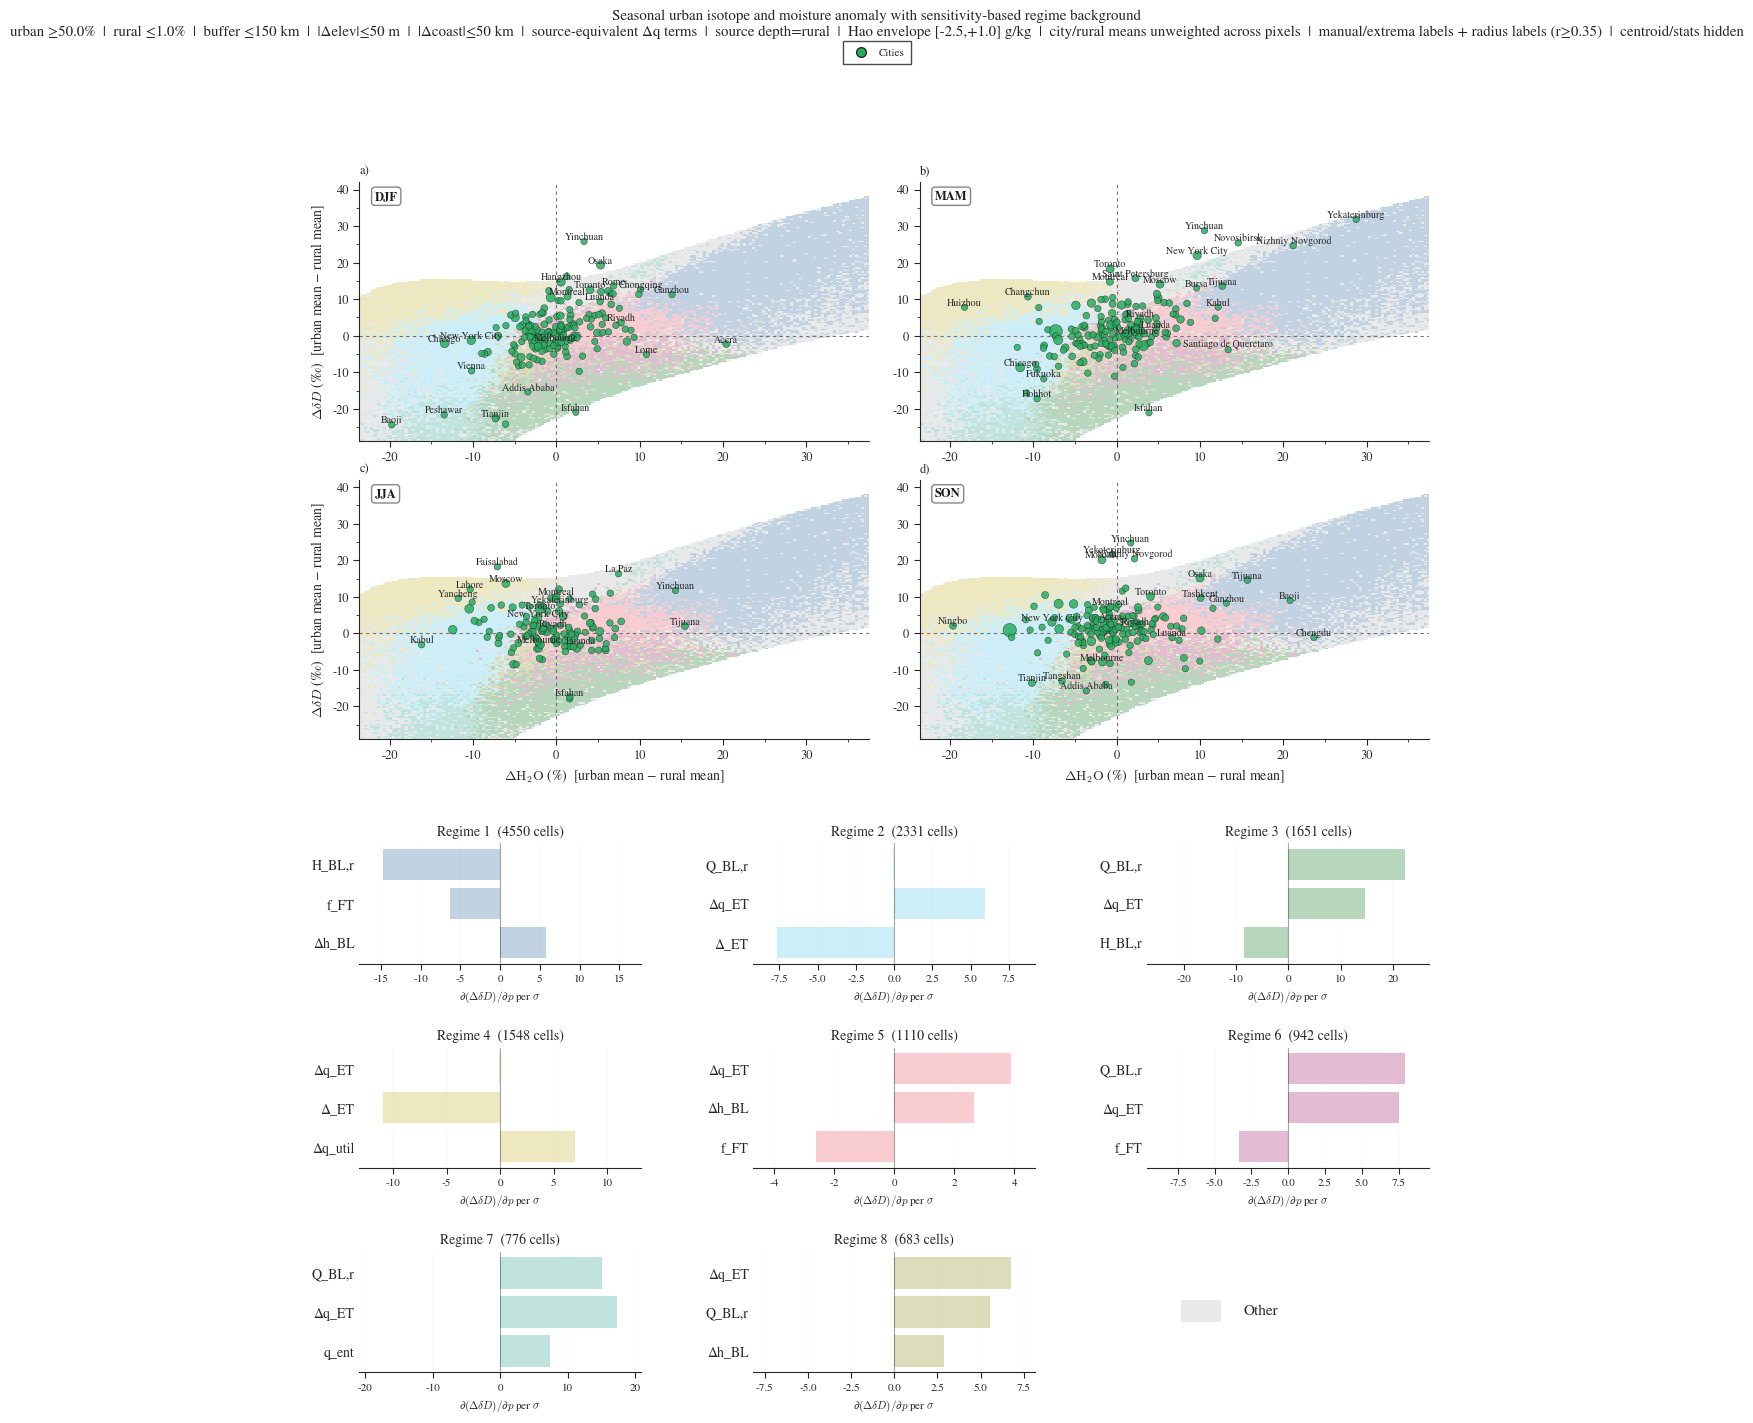

✅ Saved per-city CSV: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/Supplement_Figure_4_Model_sensitivity.csv


In [17]:
# =============================================================================
# MC PRIOR BOUNDS — single source of truth
# =============================================================================
# To change any prior, edit ONLY this cell, then re-run downstream cells.
#
# References:
#   Hao et al. 2023, npj Clim. Atmos. Sci. 6:149
#   Fiorella et al. 2018, ACP 18:8529
#   Gorski et al. 2015, PNAS 112:3247
#   Dansgaard 1964, Tellus 16:436
#   Wallace & Hobbs, Atmospheric Science (textbook)

# ---- BL dynamics & background state ----
Q_BL_R   = (2.0,   22.0)     # g/kg    rural BL specific humidity (climatological range)
Q_ENT    = (1.0,   10.0)     # g/kg    lower-FT/entrainment humidity; anchors FT profile
H_BL_R   = (500.0, 3000.0)   # m       rural daytime BL height
DH_BL    = (0.0,   1000.0)   # m       urban BL deepening (UHI)
F_FT     = (0.0,   1.0)      # -       fraction of added BL fill from FT entrainment
DD_GRAD  = (60.0,  130.0)    # permil  bulk-FT depletion relative to entrainment air
EPS_BL   = (-15.0, 15.0)     # permil  BL composition residual
EPS_ENT  = (-25.0, 25.0)     # permil  entrainment composition residual
H_Q      = (1500.0, 3000.0)  # m       water vapor scale height (Wallace & Hobbs)

# ---- Source-equivalent BL humidity perturbations ----
# These are NOT physical fluxes. They are urban-minus-comparison
# source-equivalent specific-humidity perturbations. By default, their
# water-column contributions are referenced to the comparison/rural BL depth;
# an urban-depth alternative is available as an explicit sensitivity test.
DQ_COMBUSTION = (0.0,  0.05)   # g/kg     combustion source-equivalent Δq
DQ_UTIL       = (-0.50, 0.50)  # g/kg     managed-water source-equivalent Δq
DQ_ET         = (-2.5, 1.0)    # g/kg     signed ET source-equivalent Δq

# Observational plausibility envelope on the COMBINED source-equivalent
# perturbation Δq_src = Δq_ET + Δq_util + Δq_combustion (Hao et al. 2023).
HAO_DQ_TOTAL_MIN = -2.5         # g/kg
HAO_DQ_TOTAL_MAX =  1.0         # g/kg

# ---- Source compositions ----
DELTA_ET      = (-40.0,   100.0)   # permil  δD_ET offset from BL
DD_COMBUSTION = (-250.0, -80.0)    # permil  combustion vapor δD
DD_UTIL       = (-150.0, 10.0)     # permil  utilized water δD


# ---- Fixed model constants (not free parameters) ----
ALPHA_EFF = 1.1        # effective Rayleigh exponent
Q_REF     = 10.0       # g/kg, Rayleigh anchor q
DD_REF    = -100.0     # permil, Rayleigh anchor δD
z_top     = 9000.0     # m, FT thickness in column integration

# ---- Legacy *_MIN / *_MAX exports for downstream code ----
Q_BL_R_MIN, Q_BL_R_MAX               = Q_BL_R
Q_ENT_MIN, Q_ENT_MAX                 = Q_ENT
H_BL_R_MIN, H_BL_R_MAX               = H_BL_R
DH_BL_MIN, DH_BL_MAX                 = DH_BL
F_FT_MIN, F_FT_MAX                   = F_FT
DD_GRAD_MIN, DD_GRAD_MAX             = DD_GRAD
EPS_BL_MIN, EPS_BL_MAX               = EPS_BL
EPS_ENT_MIN, EPS_ENT_MAX             = EPS_ENT
H_Q_MIN, H_Q_MAX                     = H_Q
DQ_COMBUSTION_MIN, DQ_COMBUSTION_MAX = DQ_COMBUSTION
DQ_UTIL_MIN, DQ_UTIL_MAX             = DQ_UTIL
DQ_ET_MIN, DQ_ET_MAX                 = DQ_ET
DELTA_ET_MIN, DELTA_ET_MAX           = DELTA_ET
DD_COMBUSTION_MIN, DD_COMBUSTION_MAX = DD_COMBUSTION
DD_UTIL_MIN, DD_UTIL_MAX             = DD_UTIL

PRIOR_TABLE = [
    ('Q_BL,r',         Q_BL_R,         'g/kg'),
    ('q_ent',          Q_ENT,          'g/kg'),
    ('H_BL,r',         H_BL_R,         'm'),
    ('Δh_BL',          DH_BL,          'm'),
    ('f_FT',           F_FT,           '-'),
    ('ΔδD_grad',       DD_GRAD,        'permil'),
    ('ε_BL',           EPS_BL,         'permil'),
    ('ε_ent',          EPS_ENT,        'permil'),
    ('H_q',            H_Q,            'm'),
    ('Δq_combustion',  DQ_COMBUSTION,  'g/kg'),
    ('Δq_util',        DQ_UTIL,        'g/kg'),
    ('Δq_ET',          DQ_ET,          'g/kg'),
    ('Δ_ET',           DELTA_ET,       'permil'),
    ('δD_combustion',  DD_COMBUSTION,  'permil'),
    ('δD_util',        DD_UTIL,        'permil'),
]

def print_prior_table():
    print('=' * 60)
    print('MC PRIOR TABLE  (source-equivalent control-volume formulation)')
    print('=' * 60)
    print(f'{"parameter":<16} {"min":>10} {"max":>10}  {"unit":<7}')
    print('-' * 60)
    for name, (vmin, vmax), unit in PRIOR_TABLE:
        print(f'{name:<16} {vmin:>10.4g} {vmax:>10.4g}  {unit:<7}')
    print('-' * 60)
    print(f'Rejection: combined source-equivalent Δq_src ∈ '
          f'[{HAO_DQ_TOTAL_MIN:+.2f}, {HAO_DQ_TOTAL_MAX:+.2f}] g/kg '
          f'(Hao 2023 plausibility envelope)')
    print('=' * 60)

print_prior_table()

#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Revised Supplement figure: seasonal urban-rural TROPOMI anomalies with the
original sensitivity-based phase-space regime classification, using the
corrected source-equivalent control-volume forward model.

The decision-tree regime classification from the newer production script is
intentionally not used here.
"""
import os
import warnings
from collections import Counter, defaultdict
from math import ceil
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator
from scipy.ndimage import distance_transform_edt
from scipy.ndimage import label as ndimage_label
from scipy.stats import ttest_1samp
from sklearn.neighbors import NearestNeighbors
warnings.filterwarnings("ignore")

# =============================================================================
# REVISION WORKSPACE
# =============================================================================
REVISION_ROOT = PROJECT_ROOT
DATA_DIR = SOURCE_DATA_DIR
FIGURES_DIR = OUTPUT_FIGURES_DIR
RESULTS_DIR = OUTPUT_TABLES_DIR
for _dir in [DATA_DIR, FIGURES_DIR, RESULTS_DIR]:
    os.makedirs(_dir, exist_ok=True)

# =============================================================================
# CONFIGURATION
# =============================================================================


TROPOMI_PATH = str(FILES["tropomi_climatology"])
SETTLEMENT_NC_PATH = os.path.join(
    DATA_DIR, "PercentSettlementArea_regridded_to_TROPOMI_quadratic_climatology_0p05.nc"
)
SETTLEMENT_TIF_PATH = os.path.join(
    DATA_DIR, "PercentSettlementArea_regridded_to_TROPOMI_quadratic_climatology_0p05.tif"
)
ELEVATION_TIF_PATH = os.path.join(
    DATA_DIR, "ETOPO_2022_v1_30s_N90W180_surface_resampled_to_TROPOMI_quadratic_climatology_p05.tif"
)
LANDMASK_NC_PATH = os.path.join(
    DATA_DIR, "landseamask_regridded_to_TROPOMI_quadratic_climatology_0p05_nearest.nc"
)
CITY_CSV = os.path.join(DATA_DIR, "top400_cities.csv")

CITY_CSV_CANDIDATES = [CITY_CSV]



# Corrected-model primary formulation
SOURCE_DEPTH_MODE = 'rural'

# Preserve original Supplement figure city analysis and panel order
SEASONS = ['DJF', 'MAM', 'JJA', 'SON']
SCATTER_N = 400
URBAN_MIN = 50.0
CONTROL_MAX = 1.0
BUFFER_RADIUS_KM = 150.0
ELEV_DIFF_THR = 50.0
COAST_DIFF_THR = 50.0
CITY_COAST_MIN_KM = 0.0
CITY_COAST_MAX_KM = np.inf
MIN_COUNT_PER_MONTH = 5.0
MIN_SUPPORTED_MONTHS = 2
WEIGHT_CITY_MEANS_BY_TOTAL_OBS = False
MIN_URBAN_PIXELS = 5
MIN_BUFFER_PIXELS = 10
USE_CITY_SIGNIFICANCE = False
SIG_VARIABLE = 'both'
SHOW_CENTROID_AND_STATS = False
LABEL_CITIES = {
    'Moscow', 'New York City', 'Montreal', 'Toronto', 'Melbourne',
    'Riyadh', 'Accra', 'Lome', 'Luanda', 'Yekaterinburg'
}
LABEL_BY_RADIUS = True
LABEL_RADIUS_NORM = 0.35
MAX_RADIUS_LABELS = 25

# Preserve original sensitivity-based regime classification
REGIME_SEED = 42
REGIME_N = 10_000_000
MAP_SUBSAMPLE = 5_000_000
GRID_NX = 195
GRID_NY = 165
LOCAL_K = 1400
BW_DD = 1.25
BW_H2O = 1.25
MIN_EFFECTIVE_N = 220
MAX_LOCAL_RADIUS = 3.5
TOPN = 3
MAX_REGIMES_TO_SHOW = 8
OTHER_LABEL = 'Other'
REGIME_BAR_NCOLS = 3
REGIME_BACKGROUND_ALPHA = 0.33
N_CENTRAL_VECTORS = 20
PERTURB_FRACTION = 0.5
MIN_VALID_CENTRALS = 10

# Outputs
OUTPUT_DIR = FIGURES_DIR
MODEL_TAG = f'{SOURCE_DEPTH_MODE}SourceDepth'
SAVE_RESULTS_CSV = True
SAVE_FIG = True
SAVE_SENSITIVITIES = True
SAVE_DIAGNOSTICS = True
SAVE_MC_DRAWS = False  # not required for manuscript reproduction
SENSITIVITIES_PATH = os.path.join(
    RESULTS_DIR, f'Sensitivities_grid_originalClassification_{MODEL_TAG}.parquet'
)
DIAGNOSTICS_PATH = os.path.join(
    RESULTS_DIR, f'MC_partition_diagnostics_originalSensitivityRegimes_{MODEL_TAG}.csv'
)
DIAGNOSTICS_SUMMARY_PATH = os.path.join(
    RESULTS_DIR, f'MC_partition_summary_originalSensitivityRegimes_{MODEL_TAG}.csv'
)
MC_DRAWS_PATH = os.path.join(
    RESULTS_DIR, f'MC_draws_originalSensitivityRegimes_{MODEL_TAG}.parquet'
)

# =============================================================================
# PARAMETER METADATA
# =============================================================================
PARAM_NAMES = [
    'Δh_BL',
    'f_FT',
    'q_ent',
    'ε_BL',
    'ε_ent',
    'ΔδD_grad',
    'Δq_combustion',
    'Δq_util',
    'Δq_ET',
    'Δ_ET',
    'δD_combustion',
    'δD_util',
    'Q_BL,r',
    'H_BL,r',
    'H_q',
]
PARAM_INDEX = {p: i for i, p in enumerate(PARAM_NAMES)}
N_PARAMS = len(PARAM_NAMES)

# =============================================================================
# GENERAL HELPERS
# =============================================================================

def haversine_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    return 2.0 * np.arcsin(np.sqrt(a)) * 6371.0


def fix_longitude_convention(data, lons, target_convention='0_360'):
    if target_convention == '0_360' and lons[0] < 0:
        split_idx = np.where(lons >= 0)[0][0]
        data_fixed = np.concatenate([data[:, split_idx:], data[:, :split_idx]], axis=1)
        lons_fixed = np.concatenate([lons[split_idx:], lons[:split_idx] + 360.0])
        return data_fixed, lons_fixed
    return data, lons


def get_season_months(season='annual'):
    season = season.upper()
    season_months = {
        'ANNUAL': list(range(12)),
        'DJF': [11, 0, 1],
        'MAM': [2, 3, 4],
        'JJA': [5, 6, 7],
        'SON': [8, 9, 10],
    }
    if season not in season_months:
        raise ValueError(f"Season must be one of: {list(season_months.keys())}")
    return season_months[season]


def get_weighted_seasonal_data(data_array, count_array, season='annual', min_count_per_month=5.0):
    months = get_season_months(season)
    data_sel = data_array.isel(time=months).values.astype(float)
    count_sel = count_array.isel(time=months).values.astype(float)
    valid = (
        np.isfinite(data_sel) &
        np.isfinite(count_sel) &
        (count_sel >= float(min_count_per_month))
    )
    weighted_sum = np.sum(np.where(valid, data_sel * count_sel, 0.0), axis=0)
    total_count = np.sum(np.where(valid, count_sel, 0.0), axis=0)
    weighted_mean = np.full(total_count.shape, np.nan, dtype=float)
    ok = total_count > 0
    weighted_mean[ok] = weighted_sum[ok] / total_count[ok]
    supported_months = np.sum(valid, axis=0).astype(float)
    return weighted_mean, supported_months, total_count


def bbox_mask_180(df_lons_180, df_lats, lat_min, lat_max, lon_min, lon_max):
    lat_ok = (df_lats >= lat_min) & (df_lats <= lat_max)
    if lon_min < -180:
        lon_ok = (df_lons_180 >= lon_min + 360.0) | (df_lons_180 <= lon_max)
    elif lon_max > 180:
        lon_ok = (df_lons_180 >= lon_min) | (df_lons_180 <= lon_max - 360.0)
    else:
        lon_ok = (df_lons_180 >= lon_min) & (df_lons_180 <= lon_max)
    return lat_ok & lon_ok


def weighted_or_unweighted_mean(values, weights=None, use_weights=False):
    values = np.asarray(values, dtype=float)
    good = np.isfinite(values)
    if not np.any(good):
        return np.nan
    values = values[good]
    if use_weights:
        if weights is None:
            raise ValueError('weights must be provided when use_weights=True')
        weights = np.asarray(weights, dtype=float)[good]
        good_w = np.isfinite(weights) & (weights > 0)
        if not np.any(good_w):
            return np.nan
        return float(np.average(values[good_w], weights=weights[good_w]))
    return float(np.mean(values))


def load_city_dataframe(city_csv=None):
    if city_csv is not None and os.path.exists(city_csv):
        df = pd.read_csv(city_csv)
    else:
        found = None
        for cand in CITY_CSV_CANDIDATES:
            if os.path.exists(cand):
                found = cand
                break
        if found is None:
            raise FileNotFoundError(
                'Could not find a city CSV. Set CITY_CSV to your city table path.'
            )
        df = pd.read_csv(found)
        print(f'Loaded city metadata from: {found}')

    required = ['name', 'latitude', 'longitude', 'lat_min', 'lat_max', 'lon_min', 'lon_max']
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f'City CSV is missing required columns: {missing}')

    if 'city_key' not in df.columns:
        df['city_key'] = (
            df['name'].astype(str).str.strip()
            .str.replace(r'\s+', '_', regex=True)
            .str.replace(r'[^A-Za-z0-9_]', '', regex=True)
        )
    if 'population' in df.columns:
        df = df.sort_values('population', ascending=False).reset_index(drop=True)
    return df.copy()


def load_all_data(season='annual', min_count_per_month=5.0):
    print(f"\n📂 Loading datasets for {season.upper()}...")
    tropomi_ds = xr.open_dataset(TROPOMI_PATH)
    deltad = tropomi_ds['deltad']
    h2o_column = tropomi_ds['h2o_column']
    count = tropomi_ds['count']
    lats = tropomi_ds['lat'].values
    lons = tropomi_ds['lon'].values

    sample_values = deltad.isel(time=0).values.flatten()
    sample_values = sample_values[np.isfinite(sample_values)]
    if len(sample_values) > 0 and np.ptp(sample_values) < 10:
        deltad = deltad * 1000.0

    print('   Computing weighted pixel means...')
    deltad_seasonal, supported_months, total_obs_count = get_weighted_seasonal_data(
        deltad, count, season=season, min_count_per_month=min_count_per_month
    )
    h2o_seasonal, _, _ = get_weighted_seasonal_data(
        h2o_column, count, season=season, min_count_per_month=min_count_per_month
    )

    settlement_ds = None
    try:
        settlement_ds = xr.open_dataset(SETTLEMENT_NC_PATH)
        settlement = settlement_ds['settlement_percentage'].values
    except Exception:
        settlement_ds = rioxarray.open_rasterio(SETTLEMENT_TIF_PATH)
        settlement = settlement_ds.values[0] if len(settlement_ds.shape) == 3 else settlement_ds.values

    elevation_ds = rioxarray.open_rasterio(ELEVATION_TIF_PATH)
    elevation = elevation_ds.values[0] if len(elevation_ds.shape) == 3 else elevation_ds.values
    elev_lons = elevation_ds.x.values
    elevation, elev_lons = fix_longitude_convention(elevation, elev_lons, target_convention='0_360')
    elevation[elevation < -10000] = np.nan

    landmask_ds = xr.open_dataset(LANDMASK_NC_PATH)
    land_mask = landmask_ds['land_mask'].values

    lat_2d, lon_2d = np.meshgrid(lats, lons, indexing='ij')
    ocean_mask = (land_mask == 0)
    distance_grid_cells = distance_transform_edt(~ocean_mask)

    lat_rad = np.deg2rad(lat_2d)
    dx_km = 0.05 * 111.0 * np.cos(lat_rad)
    dy_km = 0.05 * 111.0
    avg_cell_size_km = np.sqrt(dx_km ** 2 + dy_km ** 2) / np.sqrt(2.0)
    distance_to_ocean_km = distance_grid_cells * avg_cell_size_km

    df = pd.DataFrame({
        'delta_D': deltad_seasonal.flatten(),
        'h2o_column': h2o_seasonal.flatten(),
        'supported_months': supported_months.flatten(),
        'total_obs_count': total_obs_count.flatten(),
        'settlement_pct': settlement.flatten(),
        'elevation': elevation.flatten(),
        'latitude': lat_2d.flatten(),
        'longitude': lon_2d.flatten(),
        'dist_to_coast': distance_to_ocean_km.flatten(),
        'land_mask': land_mask.flatten(),
    })
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    df = df[(df['land_mask'] == 1) & (df['elevation'] > -50)].copy()
    df = df.drop(columns=['land_mask'])
    print(f'   Total land pixels: {len(df):,}')

    for ds in [tropomi_ds, landmask_ds, elevation_ds, settlement_ds]:
        try:
            if ds is not None:
                ds.close()
        except Exception:
            pass

    return df, lats, lons


try:
    from scipy.stats import binomtest as _binomtest
    def _sign_test_p(x):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]
        x = x[x != 0]
        n = int(x.size)
        if n < 3:
            return np.nan
        k = int((x > 0).sum())
        return float(_binomtest(k, n, 0.5, alternative='two-sided').pvalue)
except Exception:
    from scipy.stats import binom_test as _binom_test
    def _sign_test_p(x):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]
        x = x[x != 0]
        n = int(x.size)
        if n < 3:
            return np.nan
        k = int((x > 0).sum())
        return float(_binom_test(k, n, 0.5))


def _fmt_p(p):
    if not np.isfinite(p):
        return 'n/a'
    if p < 1e-3:
        return '<0.001'
    return f'{p:.3f}'


def _nature_axes(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('0.15')
    ax.spines['bottom'].set_color('0.15')
    ax.tick_params(axis='both', which='both', direction='out', top=False, right=False, colors='0.15')
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))


def _radius_label_names(plot_df, xcol, ycol, xlim, ylim, radius_norm=0.55, max_labels=None):
    if len(plot_df) == 0:
        return set()
    xref = max(abs(xlim[0]), abs(xlim[1]), 1e-12)
    yref = max(abs(ylim[0]), abs(ylim[1]), 1e-12)
    tmp = plot_df[[xcol, ycol, 'name']].dropna().copy()
    tmp['_rnorm'] = np.sqrt((tmp[xcol] / xref) ** 2 + (tmp[ycol] / yref) ** 2)
    tmp = tmp[tmp['_rnorm'] >= radius_norm].sort_values('_rnorm', ascending=False)
    if max_labels is not None:
        tmp = tmp.head(int(max_labels))
    return set(tmp['name'].tolist())


def _prune_nearby_labels(plot_df, xcol, ycol, candidate_names,
                         x_sep_frac=0.036, y_sep_frac=0.055,
                         priority_col=None, keep_larger_priority=True):
    cand = plot_df[plot_df['name'].isin(candidate_names)].copy()
    if len(cand) == 0:
        return set()
    if priority_col is not None and priority_col in cand.columns:
        cand = cand.sort_values(priority_col, ascending=not keep_larger_priority)
    else:
        cand['_r2'] = cand[xcol] ** 2 + cand[ycol] ** 2
        cand = cand.sort_values('_r2', ascending=False)
    xspan = max(float(plot_df[xcol].max() - plot_df[xcol].min()), 1e-12)
    yspan = max(float(plot_df[ycol].max() - plot_df[ycol].min()), 1e-12)
    x_tol = x_sep_frac * xspan
    y_tol = y_sep_frac * yspan
    kept = []
    kept_names = set()
    for _, row in cand.iterrows():
        x = float(row[xcol]); y = float(row[ycol])
        overlaps = False
        for xk, yk in kept:
            if abs(x - xk) < x_tol and abs(y - yk) < y_tol:
                overlaps = True
                break
        if not overlaps:
            kept.append((x, y))
            kept_names.add(row['name'])
    return kept_names


# =============================================================================
# SEASONAL CITY METRICS (unchanged)
# =============================================================================

def compute_bulk_scatter_df_for_season(season, city_df_filtered):
    df_full, lats_global, lons_global = load_all_data(
        season=season, min_count_per_month=MIN_COUNT_PER_MONTH
    )
    lons_180 = lons_global.copy()
    lons_180[lons_180 > 180] -= 360.0

    df_valid = df_full[(df_full['supported_months'] >= MIN_SUPPORTED_MONTHS)].copy()
    print(f'Using count-weighted {season.upper()} pixel means')
    print(f'Pixels passing support rule: {len(df_valid):,} of {len(df_full):,}')

    df_rural = df_valid[df_valid['settlement_pct'] <= CONTROL_MAX].copy()
    rural_lons = df_rural['longitude'].values.copy()
    rural_lons[rural_lons > 180] -= 360.0
    df_rural = df_rural.assign(longitude_180=rural_lons)

    rural_lats_arr = df_rural['latitude'].values
    rural_lons_arr = df_rural['longitude_180'].values
    rural_elev_arr = df_rural['elevation'].values
    rural_coast_arr = df_rural['dist_to_coast'].values

    df_full_lons_180 = df_full['longitude'].values.copy()
    df_full_lons_180[df_full_lons_180 > 180] -= 360.0
    df_valid_lons_180 = df_valid['longitude'].values.copy()
    df_valid_lons_180[df_valid_lons_180 > 180] -= 360.0

    def _get_city_component_and_controls(crow):
        lat_min, lat_max = crow['lat_min'], crow['lat_max']
        lon_min, lon_max = crow['lon_min'], crow['lon_max']
        clat, clon = crow['latitude'], crow['longitude']
        if clon > 180:
            clon -= 360

        mask_full = bbox_mask_180(
            df_full_lons_180, df_full['latitude'].values,
            lat_min, lat_max, lon_min, lon_max
        )
        df_region = df_full[mask_full].copy()
        df_region = df_region.assign(longitude_180=df_full_lons_180[mask_full])

        mask_valid = bbox_mask_180(
            df_valid_lons_180, df_valid['latitude'].values,
            lat_min, lat_max, lon_min, lon_max
        )
        df_region_valid = df_valid[mask_valid].copy()
        df_region_valid = df_region_valid.assign(longitude_180=df_valid_lons_180[mask_valid])

        lat_idx = np.where((lats_global >= lat_min) & (lats_global <= lat_max))[0]
        lat_sub = lats_global[lat_idx]

        if lon_min < -180:
            lon_idx = np.where((lons_180 >= lon_min + 360.0) | (lons_180 <= lon_max))[0]
        elif lon_max > 180:
            lon_idx = np.where((lons_180 >= lon_min) | (lons_180 <= lon_max - 360.0))[0]
        else:
            lon_idx = np.where((lons_180 >= lon_min) & (lons_180 <= lon_max))[0]
        lon_sub = lons_180[lon_idx]
        lon_sub = lon_sub[np.argsort(lon_sub)]
        nlat, nlon = len(lat_sub), len(lon_sub)
        if nlat == 0 or nlon == 0:
            return None

        lat_to_i = {round(float(v), 4): i for i, v in enumerate(lat_sub)}
        lon_to_j = {round(float(v), 4): j for j, v in enumerate(lon_sub)}

        def _fill_local(src_df, lon_col='longitude_180'):
            grid = np.full((nlat, nlon), np.nan)
            lts = src_df['latitude'].values
            lns = src_df[lon_col].values if lon_col in src_df.columns else src_df['longitude'].values.copy()
            for k in range(len(src_df)):
                i = lat_to_i.get(round(float(lts[k]), 4))
                j = lon_to_j.get(round(float(lns[k]), 4))
                if i is not None and j is not None:
                    grid[i, j] = 1.0
            return grid

        df_urban_geom = df_region[df_region['settlement_pct'] >= URBAN_MIN].copy()
        if len(df_urban_geom) < MIN_URBAN_PIXELS:
            return None

        urban_binary = (~np.isnan(_fill_local(df_urban_geom))).astype(int)
        labeled, n_components = ndimage_label(urban_binary)

        ci = np.argmin(np.abs(lat_sub - clat))
        cj = np.argmin(np.abs(lon_sub - clon))
        city_label = labeled[ci, cj]

        if city_label == 0:
            found = False
            for radius in range(1, max(nlat, nlon)):
                for di in range(-radius, radius + 1):
                    for dj in range(-radius, radius + 1):
                        ni, nj = ci + di, cj + dj
                        if 0 <= ni < nlat and 0 <= nj < nlon and labeled[ni, nj] > 0:
                            city_label = labeled[ni, nj]
                            found = True
                            break
                    if found:
                        break
                if found:
                    break

        if city_label == 0:
            return None

        df_urban_valid = df_region_valid[df_region_valid['settlement_pct'] >= URBAN_MIN].copy()
        keep_rows = []
        for k in range(len(df_urban_valid)):
            i = lat_to_i.get(round(float(df_urban_valid['latitude'].values[k]), 4))
            j = lon_to_j.get(round(float(df_urban_valid['longitude_180'].values[k]), 4))
            if i is not None and j is not None and labeled[i, j] == city_label:
                keep_rows.append(k)
        df_urban = df_urban_valid.iloc[keep_rows].copy()
        if len(df_urban) < MIN_URBAN_PIXELS:
            return None

        comp_mask = (labeled == city_label)
        comp_i, comp_j = np.where(comp_mask)
        comp_lats_geo = np.array([lat_sub[i] for i in comp_i])
        comp_lons_geo = np.array([lon_sub[j] for j in comp_j])
        global_key = (
            round(float(comp_lats_geo.mean()), 2),
            round(float(comp_lons_geo.mean()), 2)
        )

        mean_urban_elev = weighted_or_unweighted_mean(
            df_urban['elevation'].values,
            weights=df_urban['total_obs_count'].values,
            use_weights=WEIGHT_CITY_MEANS_BY_TOTAL_OBS
        )
        mean_urban_coast = weighted_or_unweighted_mean(
            df_urban['dist_to_coast'].values,
            weights=df_urban['total_obs_count'].values,
            use_weights=WEIGHT_CITY_MEANS_BY_TOTAL_OBS
        )
        urban_clat = float(df_urban['latitude'].mean())
        urban_clon = float(df_urban['longitude_180'].mean())

        dist_to_centroid = haversine_distance(rural_lats_arr, rural_lons_arr, urban_clat, urban_clon)
        elev_diff = np.abs(rural_elev_arr - mean_urban_elev)
        coast_diff = np.abs(rural_coast_arr - mean_urban_coast)

        buf_mask = (
            (dist_to_centroid <= BUFFER_RADIUS_KM) &
            (elev_diff <= ELEV_DIFF_THR) &
            (coast_diff <= COAST_DIFF_THR)
        )
        df_buffer = df_rural[buf_mask].copy()
        if len(df_buffer) < MIN_BUFFER_PIXELS:
            return None

        return {
            'df_urban': df_urban, 'df_buffer': df_buffer,
            'global_key': global_key,
            'n_urban': len(df_urban), 'n_buffer': len(df_buffer),
            'n_components': int(n_components),
        }

    calc_city_pvalues = bool(USE_CITY_SIGNIFICANCE)
    print(f"\nComputing BULK metrics for up to {len(city_df_filtered.head(SCATTER_N))} cities in {season} ...")

    scatter_rows = []
    claimed_centroids = {}

    for _, crow in city_df_filtered.head(SCATTER_N).iterrows():
        name = crow['name']
        result = _get_city_component_and_controls(crow)
        if result is None:
            continue

        global_key = result['global_key']
        if global_key in claimed_centroids:
            continue
        claimed_centroids[global_key] = name

        df_urban = result['df_urban']
        df_buffer = result['df_buffer']

        rural_mean_d = weighted_or_unweighted_mean(
            df_buffer['delta_D'].values,
            weights=df_buffer['total_obs_count'].values,
            use_weights=WEIGHT_CITY_MEANS_BY_TOTAL_OBS
        )
        rural_mean_h2o = weighted_or_unweighted_mean(
            df_buffer['h2o_column'].values,
            weights=df_buffer['total_obs_count'].values,
            use_weights=WEIGHT_CITY_MEANS_BY_TOTAL_OBS
        )
        urban_mean_d = weighted_or_unweighted_mean(
            df_urban['delta_D'].values,
            weights=df_urban['total_obs_count'].values,
            use_weights=WEIGHT_CITY_MEANS_BY_TOTAL_OBS
        )
        urban_mean_h2o = weighted_or_unweighted_mean(
            df_urban['h2o_column'].values,
            weights=df_urban['total_obs_count'].values,
            use_weights=WEIGHT_CITY_MEANS_BY_TOTAL_OBS
        )

        diff_d_mean = urban_mean_d - rural_mean_d
        diff_h_mean = 100.0 * (urban_mean_h2o - rural_mean_h2o) / abs(rural_mean_h2o) if rural_mean_h2o != 0 else np.nan

        if calc_city_pvalues:
            _, p_val_d = ttest_1samp(df_urban['delta_D'].values - rural_mean_d, 0.0)
            _, p_val_h = ttest_1samp(df_urban['h2o_column'].values - rural_mean_h2o, 0.0)
            p_val_d = float(p_val_d)
            p_val_h = float(p_val_h)
        else:
            p_val_d = np.nan
            p_val_h = np.nan

        sig_d = (p_val_d < 0.05) if calc_city_pvalues else False
        sig_h2o = (p_val_h < 0.05) if calc_city_pvalues else False
        sig_both = (sig_d and sig_h2o) if calc_city_pvalues else False

        scatter_rows.append({
            'season': season, 'name': name, 'city_key': crow['city_key'],
            'n_urban': result['n_urban'], 'n_buffer': result['n_buffer'],
            'n_components': result['n_components'],
            'diff_d_mean': diff_d_mean, 'diff_h_mean': diff_h_mean,
            'urban_mean_d': urban_mean_d, 'urban_mean_h2o': urban_mean_h2o,
            'rural_mean_d': rural_mean_d, 'rural_mean_h2o': rural_mean_h2o,
            'p_val_d': p_val_d, 'p_val_h2o': p_val_h,
            'sig_d': sig_d, 'sig_h2o': sig_h2o, 'sig_both': sig_both,
            'urban_mean_total_obs_count': float(df_urban['total_obs_count'].mean()),
            'rural_mean_total_obs_count': float(df_buffer['total_obs_count'].mean()),
            'urban_mean_supported_months': float(df_urban['supported_months'].mean()),
            'rural_mean_supported_months': float(df_buffer['supported_months'].mean()),
        })

    scatter_df = pd.DataFrame(scatter_rows)
    print(f"\n{len(scatter_df)} cities in {season} panel")
    if len(scatter_df) > 0:
        if USE_CITY_SIGNIFICANCE:
            sig_col = {'deltad': 'sig_d', 'h2o': 'sig_h2o', 'both': 'sig_both'}[SIG_VARIABLE]
            colors_all = scatter_df[sig_col].map({True: '#27ae60', False: '#bdc3c7'})
        else:
            colors_all = pd.Series('#27ae60', index=scatter_df.index)
        scatter_df = scatter_df.assign(_color=colors_all.values)
    return scatter_df



# =============================================================================
# FORWARD MODEL
# =============================================================================

def rayleigh_dD(q, alpha=ALPHA_EFF, q0=Q_REF, dD0=DD_REF):
    """Exact delta-form of an effective Rayleigh relationship.

    Starting from
        R / R0 = (q / q0) ** (alpha - 1)
    and
        delta = 1000 * (R / R_VSMOW - 1),

    the exact delta-space expression is
        delta(q) = 1000 * [
            (1 + delta0/1000) * (q/q0)**(alpha-1) - 1
        ].

    This replaces the earlier additive approximation
        delta0 + 1000 * [(q/q0)**(alpha-1) - 1],
    which is not algebraically equivalent when delta0 != 0.
    """
    q = np.asarray(q, dtype=float)
    return 1000.0 * (
        (1.0 + dD0 / 1000.0) * (q / q0) ** (alpha - 1.0) - 1.0
    )


def dD_to_r(dD):
    """Normalized isotope ratio r = R / R_VSMOW."""
    return 1.0 + np.asarray(dD, dtype=float) / 1000.0


def r_to_dD(r):
    """Convert normalized isotope ratio r = R / R_VSMOW back to delta-D."""
    return 1000.0 * (np.asarray(r, dtype=float) - 1.0)


def _validate_source_depth_mode(mode):
    if mode not in {'rural', 'urban'}:
        raise ValueError(
            f"SOURCE_DEPTH_MODE must be 'rural' or 'urban'; got {mode!r}"
        )


def _source_reference_depth(H_BL_r, H_BL_u, mode):
    """Depth used to convert source-equivalent Δq into column contribution.

    Primary formulation:
        mode='rural' -> M_j = Δq_j * H_BL,r

    Sensitivity formulation:
        mode='urban' -> M_j = Δq_j * H_BL,u

    The rural-depth formulation defines Δq_j as a perturbation referenced to
    a common comparison BL depth, so source strength is not automatically
    multiplied by an independently sampled urban BL deepening.
    """
    _validate_source_depth_mode(mode)
    return H_BL_r if mode == 'rural' else H_BL_u


def forward_model_from_params_array(P, source_depth_mode=None, return_state=False):
    """Run the two-layer forward model on an (N, N_PARAMS) parameter array.

    Physical bookkeeping
    --------------------
    1) The rural/comparison column has a BL and FT reservoir.
    2) q_ent anchors the exponential FT humidity profile.
    3) Urban BL deepening is filled partly by internal FT entrainment and
       partly by lateral convergence of background-BL-like air.
    4) FT entrainment is added to the BL and removed identically from the FT,
       so pure entrainment conserves full-column water and isotope inventory.
    5) The lateral-convergence term crosses the modeled column boundary and
       can change total-column water while carrying rural-BL composition.
    6) ET, managed-water, and combustion terms are source-equivalent Δq
       perturbations, not physical fluxes.
    7) The Hao et al. range constrains only the combined source-equivalent
       perturbation, not the final modeled BL-mean or column humidity anomaly.

    Parameters
    ----------
    P : ndarray, shape (N, N_PARAMS)
        Parameter vectors in PARAM_NAMES order.
    source_depth_mode : {'rural', 'urban'} or None
        Reference depth for converting source-equivalent Δq to column mass.
        None uses SOURCE_DEPTH_MODE.
    return_state : bool
        If True, return detailed inventory terms for small diagnostic/test
        calculations. Keep False for the large Monte Carlo ensemble to avoid
        unnecessary memory use.
    """
    mode = SOURCE_DEPTH_MODE if source_depth_mode is None else source_depth_mode
    _validate_source_depth_mode(mode)

    P = np.asarray(P, dtype=float)
    if P.ndim != 2 or P.shape[1] != N_PARAMS:
        raise ValueError(
            f'P must have shape (N, {N_PARAMS}); got {P.shape}'
        )

    dh_BL         = P[:, 0]
    f_FT          = P[:, 1]
    q_ent         = P[:, 2]
    eps_BL        = P[:, 3]
    eps_ent       = P[:, 4]
    dDgrad        = P[:, 5]
    dq_combustion = P[:, 6]
    dq_util_val   = P[:, 7]
    dq_ET         = P[:, 8]
    delta_ET      = P[:, 9]
    dD_comb       = P[:, 10]
    dD_util       = P[:, 11]
    Q_BL_r        = P[:, 12]
    H_BL_r        = P[:, 13]
    H_q           = P[:, 14]

    # -------------------------------------------------------------------------
    # Combined local source-equivalent perturbation used for the Hao et al.
    # plausibility envelope. This is intentionally NOT the final modeled
    # vertically averaged BL humidity anomaly.
    # -------------------------------------------------------------------------
    dq_source_equiv = dq_combustion + dq_util_val + dq_ET

    H_BL_u = H_BL_r + dh_BL
    FT_thickness_r = z_top - H_BL_r

    # -------------------------------------------------------------------------
    # Rural FT humidity:
    # q_ent is the humidity immediately above / near the BL top and anchors
    # an exponential FT profile:
    #
    #   q(z) = q_ent * exp[-(z - H_BL,r) / H_q]
    #
    # The bulk FT mean is the analytic vertical mean from H_BL,r to z_top.
    # This makes q_ent and the FT reservoir part of one internally consistent
    # humidity profile rather than two independently specified FT states.
    # -------------------------------------------------------------------------
    Q_FT_col = (
        q_ent * H_q / FT_thickness_r
    ) * (
        1.0 - np.exp(-FT_thickness_r / H_q)
    )

    # Rural BL / entrainment / FT isotope compositions.
    DD_BL_r = rayleigh_dD(Q_BL_r) + eps_BL
    dD_ent = rayleigh_dD(q_ent) + eps_ent

    # dDgrad is interpreted as the bulk FT depletion relative to entrainment
    # layer vapor, not as a second Rayleigh calculation.
    dD_FT_col = dD_ent - dDgrad

    # Source isotope compositions.
    dD_ET = DD_BL_r + delta_ET

    # Normalized isotope ratios r = R / R_VSMOW.
    r_BL_r = dD_to_r(DD_BL_r)
    r_ent = dD_to_r(dD_ent)
    r_FT_col = dD_to_r(dD_FT_col)
    r_ET = dD_to_r(dD_ET)
    r_comb = dD_to_r(dD_comb)
    r_util = dD_to_r(dD_util)

    # -------------------------------------------------------------------------
    # Rural water and normalized-isotope inventories.
    # M is proportional to vertically integrated water mass under the model's
    # common-density approximation; I = M * r is the normalized isotope
    # inventory. Using I avoids any apparent missing VSMOW factor because the
    # common standard cancels exactly.
    # -------------------------------------------------------------------------
    M_BL_r = H_BL_r * Q_BL_r
    I_BL_r = M_BL_r * r_BL_r

    M_FT_r = FT_thickness_r * Q_FT_col
    I_FT_r = M_FT_r * r_FT_col

    M_col_r = M_BL_r + M_FT_r
    I_col_r = I_BL_r + I_FT_r

    # -------------------------------------------------------------------------
    # Added urban BL fill.
    #
    # FT entrainment = internal redistribution:
    #   +M_ent in urban BL, -M_ent in urban FT.
    #
    # Lateral convergence = water crossing the side boundary of the modeled
    # urban column. It is assigned rural-BL humidity/isotope composition and
    # therefore does not introduce an independent q or delta-D contrast for
    # the air used to fill that portion of the added BL volume.
    #
    # This does NOT represent general differential advection of compositionally
    # distinct air masses between urban and comparison columns.
    # -------------------------------------------------------------------------
    M_fill_ent = dh_BL * f_FT * q_ent
    I_fill_ent = M_fill_ent * r_ent

    M_fill_convergence = dh_BL * (1.0 - f_FT) * Q_BL_r
    I_fill_convergence = M_fill_convergence * r_BL_r

    # -------------------------------------------------------------------------
    # Source-equivalent contributions.
    # Primary definition references these Δq terms to H_BL,r. An H_BL,u
    # alternative is retained as an explicit sensitivity, not silently mixed
    # into the primary formulation.
    # -------------------------------------------------------------------------
    H_source = _source_reference_depth(H_BL_r, H_BL_u, mode)

    M_ET = dq_ET * H_source
    I_ET = M_ET * r_ET

    M_comb = dq_combustion * H_source
    I_comb = M_comb * r_comb

    M_util = dq_util_val * H_source
    I_util = M_util * r_util

    # Urban BL inventories.
    M_BL_u = (
        M_BL_r
        + M_fill_ent
        + M_fill_convergence
        + M_ET
        + M_comb
        + M_util
    )
    I_BL_u = (
        I_BL_r
        + I_fill_ent
        + I_fill_convergence
        + I_ET
        + I_comb
        + I_util
    )

    # Only the entrained component is removed from the FT reservoir.
    M_FT_u = M_FT_r - M_fill_ent
    I_FT_u = I_FT_r - I_fill_ent

    M_col_u = M_BL_u + M_FT_u
    I_col_u = I_BL_u + I_FT_u

    # -------------------------------------------------------------------------
    # Physical / plausibility validity checks.
    # -------------------------------------------------------------------------
    valid = (
        (Q_BL_r > 0.0) &
        (q_ent > 0.0) &
        (H_BL_r > 0.0) &
        (H_q > 0.0) &
        (FT_thickness_r > 0.0) &
        (H_BL_u > 0.0) &
        (H_BL_u < z_top) &
        (f_FT >= 0.0) & (f_FT <= 1.0) &
        (dq_source_equiv >= HAO_DQ_TOTAL_MIN) &
        (dq_source_equiv <= HAO_DQ_TOTAL_MAX) &
        (M_BL_u > 0.0) & (I_BL_u > 0.0) &
        (M_FT_u > 0.0) & (I_FT_u > 0.0) &
        (M_col_u > 0.0) & (I_col_u > 0.0)
    )

    r_col_r = I_col_r / M_col_r
    r_col_u = np.where(valid, I_col_u / M_col_u, np.nan)

    dD_col_r = r_to_dD(r_col_r)
    dD_col_u = np.where(valid, r_to_dD(r_col_u), np.nan)

    delta_h2o_pct = np.where(
        valid,
        100.0 * (M_col_u - M_col_r) / M_col_r,
        np.nan,
    )
    delta_dD_col = np.where(
        valid,
        dD_col_u - dD_col_r,
        np.nan,
    )

    out = {
        'valid': valid,
        'delta_dD_col': delta_dD_col,
        'delta_h2o_pct': delta_h2o_pct,
    }

    if return_state:
        # Detailed state is deliberately optional because returning all of
        # these arrays for 10 million draws would consume substantial memory.
        q_BL_u_mean = M_BL_u / H_BL_u
        out.update({
            'source_depth_mode': mode,
            'dq_source_equiv': dq_source_equiv,
            'H_BL_u': H_BL_u,
            'H_source': H_source,
            'Q_FT_col': Q_FT_col,
            'DD_BL_r': DD_BL_r,
            'dD_ent': dD_ent,
            'dD_FT_col': dD_FT_col,
            'M_BL_r': M_BL_r,
            'I_BL_r': I_BL_r,
            'M_FT_r': M_FT_r,
            'I_FT_r': I_FT_r,
            'M_col_r': M_col_r,
            'I_col_r': I_col_r,
            'M_fill_ent': M_fill_ent,
            'I_fill_ent': I_fill_ent,
            'M_fill_convergence': M_fill_convergence,
            'I_fill_convergence': I_fill_convergence,
            'M_ET': M_ET,
            'I_ET': I_ET,
            'M_comb': M_comb,
            'I_comb': I_comb,
            'M_util': M_util,
            'I_util': I_util,
            'M_BL_u': M_BL_u,
            'I_BL_u': I_BL_u,
            'M_FT_u': M_FT_u,
            'I_FT_u': I_FT_u,
            'M_col_u': M_col_u,
            'I_col_u': I_col_u,
            'q_BL_u_mean': q_BL_u_mean,
            'delta_q_BL_mean': q_BL_u_mean - Q_BL_r,
        })

    return out



# =============================================================================
# MONTE CARLO DRAW GENERATION
# =============================================================================

def sample_mc_parameter_array(rng, N):
    """Sample the 15-dimensional Monte Carlo prior and return P only."""
    Q_BL_r  = rng.uniform(*Q_BL_R, N)
    eps_BL  = rng.uniform(*EPS_BL, N)
    eps_ent = rng.uniform(*EPS_ENT, N)
    H_BL_r  = rng.uniform(*H_BL_R, N)
    dh_BL   = rng.uniform(*DH_BL, N)
    f_FT    = rng.uniform(*F_FT, N)
    q_ent   = rng.uniform(*Q_ENT, N)
    dDgrad  = rng.uniform(*DD_GRAD, N)

    dq_combustion = rng.uniform(*DQ_COMBUSTION, N)
    dq_util       = rng.uniform(*DQ_UTIL, N)
    dq_ET         = rng.uniform(*DQ_ET, N)

    delta_ET      = rng.uniform(*DELTA_ET, N)
    dD_combustion = rng.uniform(*DD_COMBUSTION, N)
    dD_util       = rng.uniform(*DD_UTIL, N)

    H_q = rng.uniform(*H_Q, N)

    return np.column_stack([
        dh_BL, f_FT, q_ent, eps_BL, eps_ent, dDgrad,
        dq_combustion, dq_util, dq_ET, delta_ET,
        dD_combustion, dD_util, Q_BL_r, H_BL_r, H_q
    ])


def generate_mc_draws(rng, N, source_depth_mode=None):
    P = sample_mc_parameter_array(rng, N)
    out = forward_model_from_params_array(
        P, source_depth_mode=source_depth_mode, return_state=False
    )
    return P, out



# =============================================================================
# MONTE CARLO PARTITION DIAGNOSTICS
# =============================================================================

def print_partition_diagnostics(P, out):
    valid = out['valid']
    dq_comb_col = P[:, PARAM_INDEX['Δq_combustion']]
    dq_util_col = P[:, PARAM_INDEX['Δq_util']]
    dq_ET_col   = P[:, PARAM_INDEX['Δq_ET']]
    dq_source_equiv = dq_comb_col + dq_util_col + dq_ET_col

    n_total = len(valid)
    n_valid = int(valid.sum())

    in_hao_range = (
        (dq_source_equiv >= HAO_DQ_TOTAL_MIN) &
        (dq_source_equiv <= HAO_DQ_TOTAL_MAX)
    )
    n_in_hao = int(in_hao_range.sum())

    print('\n' + '=' * 70)
    print('MC PARTITION DIAGNOSTICS  (source-equivalent formulation)')
    print('=' * 70)
    print(f'Source-depth mode:                    {SOURCE_DEPTH_MODE}')
    print(f'Draws total:                          {n_total:,}')
    print(f'Draws inside Hao source-equivalent range: '
          f'{n_in_hao:,} ({100*n_in_hao/n_total:.1f}%)')
    print(f'Draws valid (Hao + physical):         '
          f'{n_valid:,} ({100*n_valid/n_total:.1f}%)')

    print(f'\nSampled Δq_combustion,eq (g/kg):')
    print(f'  min / median / max:   {dq_comb_col.min():+.3f} / '
          f'{np.median(dq_comb_col):+.3f} / {dq_comb_col.max():+.3f}')
    print(f'Sampled Δq_util,eq (g/kg):')
    print(f'  min / median / max:   {dq_util_col.min():+.3f} / '
          f'{np.median(dq_util_col):+.3f} / {dq_util_col.max():+.3f}')
    print(f'Sampled Δq_ET,eq (g/kg):')
    print(f'  min / median / max:   {dq_ET_col.min():+.3f} / '
          f'{np.median(dq_ET_col):+.3f} / {dq_ET_col.max():+.3f}')

    print('Combined source-equivalent Δq_src = '
          'Δq_comb + Δq_util + Δq_ET (g/kg):')
    print(f'  min / median / max:   {dq_source_equiv.min():+.3f} / '
          f'{np.median(dq_source_equiv):+.3f} / {dq_source_equiv.max():+.3f}')
    print(f'  10 / 50 / 90 pct:     '
          f'{np.percentile(dq_source_equiv, 10):+.3f} / '
          f'{np.percentile(dq_source_equiv, 50):+.3f} / '
          f'{np.percentile(dq_source_equiv, 90):+.3f}')
    print(f'  outside Hao [{HAO_DQ_TOTAL_MIN:+.2f}, '
          f'{HAO_DQ_TOTAL_MAX:+.2f}]:  '
          f'{(~in_hao_range).mean()*100:.2f}% rejected')
    print('=' * 70)

    if SAVE_DIAGNOSTICS:
        os.makedirs(OUTPUT_DIR, exist_ok=True)

        # Distributional diagnostics (same role as before, renamed clearly).
        diag = pd.DataFrame({
            'dq_combustion_equiv': dq_comb_col,
            'dq_util_equiv': dq_util_col,
            'dq_ET_equiv': dq_ET_col,
            'dq_source_equiv': dq_source_equiv,
            'in_hao_source_range': in_hao_range,
            'valid': valid,
        })
        diag_summary = diag.describe(
            percentiles=[0.01, 0.05, 0.10, 0.25, 0.5,
                         0.75, 0.90, 0.95, 0.99]
        )
        diag_summary.to_csv(DIAGNOSTICS_PATH)

        # One-row summary explicitly records retained-draw counts requested
        # by the reviewer.
        summary = pd.DataFrame([{
            'source_depth_mode': SOURCE_DEPTH_MODE,
            'n_draws_total': n_total,
            'n_in_hao_source_range': n_in_hao,
            'fraction_in_hao_source_range': n_in_hao / n_total,
            'n_valid_total': n_valid,
            'fraction_valid_total': n_valid / n_total,
            'hao_min_gkg': HAO_DQ_TOTAL_MIN,
            'hao_max_gkg': HAO_DQ_TOTAL_MAX,
            'regime_seed': REGIME_SEED,
        }])
        summary.to_csv(DIAGNOSTICS_SUMMARY_PATH, index=False)

        print(f'Saved MC diagnostics distribution summary: {DIAGNOSTICS_PATH}')
        print(f'Saved MC retained-draw summary: {DIAGNOSTICS_SUMMARY_PATH}')



# =============================================================================
# SENSITIVITY-BASED REGIME BACKGROUND
# =============================================================================

def compute_sensitivities_at_grid_cell(central_vectors, sigma):
    n_c = central_vectors.shape[0]
    n_p = N_PARAMS

    P_plus = np.broadcast_to(central_vectors[:, None, :], (n_c, n_p, n_p)).copy()
    P_minus = P_plus.copy()

    for i in range(n_p):
        P_plus[:, i, i] += PERTURB_FRACTION * sigma[i]
        P_minus[:, i, i] -= PERTURB_FRACTION * sigma[i]

    P_plus_flat = P_plus.reshape(-1, n_p)
    P_minus_flat = P_minus.reshape(-1, n_p)

    out_plus = forward_model_from_params_array(P_plus_flat)
    out_minus = forward_model_from_params_array(P_minus_flat)

    valid_plus = out_plus['valid'].reshape(n_c, n_p)
    valid_minus = out_minus['valid'].reshape(n_c, n_p)
    both_valid = valid_plus & valid_minus

    dD_plus = out_plus['delta_dD_col'].reshape(n_c, n_p)
    dD_minus = out_minus['delta_dD_col'].reshape(n_c, n_p)
    H2O_plus = out_plus['delta_h2o_pct'].reshape(n_c, n_p)
    H2O_minus = out_minus['delta_h2o_pct'].reshape(n_c, n_p)

    denom = 2.0 * PERTURB_FRACTION
    ddD_dp = np.where(both_valid, (dD_plus - dD_minus) / denom, np.nan)
    dH2O_dp = np.where(both_valid, (H2O_plus - H2O_minus) / denom, np.nan)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        s_dD = np.nanmean(ddD_dp, axis=0)
        s_H2O = np.nanmean(dH2O_dp, axis=0)
    n_valid = both_valid.sum(axis=0)

    bad = n_valid < MIN_VALID_CENTRALS
    s_dD[bad] = np.nan
    s_H2O[bad] = np.nan

    return s_dD, s_H2O, n_valid


def compute_shared_regime_background_sensitivity(xlim, ylim):
    rng = np.random.default_rng(REGIME_SEED)

    print(f'Generating {REGIME_N:,} MC draws...')
    P_full, out_full = generate_mc_draws(rng, REGIME_N)

    valid = out_full['valid']
    n_valid = int(valid.sum())
    print(f'Valid model draws: {n_valid:,} / {REGIME_N:,} ({100*n_valid/REGIME_N:.1f}%)')

    print_partition_diagnostics(P_full, out_full)

    P_valid = P_full[valid]
    x_model = out_full['delta_dD_col'][valid]
    y_model = out_full['delta_h2o_pct'][valid]

    sigma = P_valid.std(axis=0, ddof=1)
    sigma[sigma == 0] = 1.0

    print(f'\nPer-parameter sigma (used for perturbations):')
    for i, p in enumerate(PARAM_NAMES):
        print(f'  {p:16s}  σ = {sigma[i]:.4g}')

    map_n = min(MAP_SUBSAMPLE, n_valid)
    map_idx = rng.choice(n_valid, size=map_n, replace=False)
    P_map = P_valid[map_idx]
    x_map = x_model[map_idx]
    y_map = y_model[map_idx]
    print(f'Using {map_n:,} model draws to construct the regime map')

    if SAVE_MC_DRAWS:
        os.makedirs(OUTPUT_DIR, exist_ok=True)
        mc_df = pd.DataFrame(P_map, columns=PARAM_NAMES)
        mc_df['delta_dD'] = x_map
        mc_df['delta_H2O'] = y_map
        try:
            mc_df.to_parquet(MC_DRAWS_PATH, index=False)
            print(f'Saved MC draws ({len(mc_df):,} rows × {len(mc_df.columns)} cols) → {MC_DRAWS_PATH}')
        except Exception as e:
            fallback = os.path.splitext(MC_DRAWS_PATH)[0] + '.csv'
            print(f'Parquet save failed ({e}); writing CSV: {fallback}')
            mc_df.to_csv(fallback, index=False)
        del mc_df

    phase = np.column_stack([x_map / BW_DD, y_map / BW_H2O])
    nbrs = NearestNeighbors(n_neighbors=LOCAL_K, algorithm='auto')
    nbrs.fit(phase)

    xg = np.linspace(xlim[0], xlim[1], GRID_NX)
    yg = np.linspace(ylim[0], ylim[1], GRID_NY)
    XX, YY = np.meshgrid(xg, yg)

    support_mask = np.zeros((GRID_NY, GRID_NX), dtype=bool)
    s_dD_grid = np.full((GRID_NY, GRID_NX, N_PARAMS), np.nan, dtype=float)
    s_H2O_grid = np.full((GRID_NY, GRID_NX, N_PARAMS), np.nan, dtype=float)
    n_valid_grid = np.zeros((GRID_NY, GRID_NX, N_PARAMS), dtype=int)

    regime_key_grid = np.full((GRID_NY, GRID_NX), None, dtype=object)
    reg_s_dD_by_key = defaultdict(list)
    reg_s_H2O_by_key = defaultdict(list)
    reg_norm_by_key = defaultdict(list)

    print(f'\nComputing sensitivities on a {GRID_NX} x {GRID_NY} grid '
          f'({GRID_NX*GRID_NY:,} cells) with {N_CENTRAL_VECTORS} central vectors each...')
    t0_print = 0
    n_cells_total = GRID_NX * GRID_NY
    n_cells_done = 0
    n_cells_with_support = 0
    n_cells_with_regime = 0

    for iy in range(GRID_NY):
        for ix in range(GRID_NX):
            n_cells_done += 1
            if n_cells_done - t0_print >= 2000:
                pct = 100.0 * n_cells_done / n_cells_total
                print(f'  {n_cells_done:>7,} / {n_cells_total:,} cells ({pct:5.1f}%)')
                t0_print = n_cells_done

            x0 = XX[iy, ix]
            y0 = YY[iy, ix]

            q = np.array([[x0 / BW_DD, y0 / BW_H2O]])
            dists, inds = nbrs.kneighbors(q, n_neighbors=LOCAL_K, return_distance=True)
            dists = dists[0]
            inds = inds[0]

            w = np.exp(-0.5 * dists**2)
            wsum = np.sum(w)
            weff = (wsum**2) / np.sum(w**2) if np.sum(w**2) > 0 else 0.0
            local_radius = dists[-1]

            if (weff < MIN_EFFECTIVE_N) or (local_radius > MAX_LOCAL_RADIUS):
                continue

            support_mask[iy, ix] = True
            n_cells_with_support += 1

            if wsum <= 0:
                continue
            p_draw = w / wsum
            n_c = min(N_CENTRAL_VECTORS, LOCAL_K)
            chosen = rng.choice(LOCAL_K, size=n_c, replace=False, p=p_draw)
            central_vectors = P_map[inds[chosen]]

            s_dD, s_H2O, n_val = compute_sensitivities_at_grid_cell(central_vectors, sigma)

            s_dD_grid[iy, ix, :] = s_dD
            s_H2O_grid[iy, ix, :] = s_H2O
            n_valid_grid[iy, ix, :] = n_val

            norms = np.sqrt(s_dD**2 + s_H2O**2)
            finite = np.isfinite(norms)
            if finite.sum() < TOPN:
                continue

            safe_norms = np.where(finite, norms, -np.inf)
            top_idx = np.argsort(safe_norms)[::-1][:TOPN]
            top_names = tuple(sorted(PARAM_NAMES[i] for i in top_idx))

            key = top_names
            regime_key_grid[iy, ix] = key
            reg_s_dD_by_key[key].append(s_dD.copy())
            reg_s_H2O_by_key[key].append(s_H2O.copy())
            reg_norm_by_key[key].append(norms.copy())
            n_cells_with_regime += 1

    print(f'\n  Supported cells: {n_cells_with_support:,} / {n_cells_total:,}')
    print(f'  Cells with valid top-3 regime: {n_cells_with_regime:,}')

    supported_keys = [k for k in regime_key_grid[support_mask].ravel() if k is not None]
    if len(supported_keys) == 0:
        raise ValueError(
            'No grid cells produced a valid top-3 regime. '
            'Check perturbation size or min-valid-centrals threshold.'
        )

    counts = Counter(supported_keys)
    most_common = counts.most_common(MAX_REGIMES_TO_SHOW)
    kept_keys = [k for k, _ in most_common]

    print('\nMost common top-3 parameter sets on the supported grid:')
    for i, (k, c) in enumerate(most_common, start=1):
        print(f'  {i:2d}. {" + ".join(k)}   ({c} cells)')

    R = len(kept_keys)
    regime_id = np.zeros((GRID_NY, GRID_NX), dtype=int)

    for iy in range(GRID_NY):
        for ix in range(GRID_NX):
            if not support_mask[iy, ix]:
                continue
            k = regime_key_grid[iy, ix]
            if k is None:
                continue
            if k in kept_keys:
                regime_id[iy, ix] = kept_keys.index(k) + 1
            else:
                regime_id[iy, ix] = R + 1

    regime_avg_s_dD = {}
    regime_avg_s_H2O = {}
    regime_avg_norm = {}
    for k in kept_keys:
        regime_avg_s_dD[k] = np.nanmean(np.vstack(reg_s_dD_by_key[k]), axis=0)
        regime_avg_s_H2O[k] = np.nanmean(np.vstack(reg_s_H2O_by_key[k]), axis=0)
        regime_avg_norm[k] = np.nanmean(np.vstack(reg_norm_by_key[k]), axis=0)

    other_count = int(np.sum(regime_id[support_mask] == (R + 1)))

    base_colors = [
        '#4477AA', '#66CCEE', '#228833', '#CCBB44',
        '#EE6677', '#AA3377', '#44AA99', '#999933',
        '#882255', '#332288', '#117733', '#DDCC77'
    ]
    if R > len(base_colors):
        cmap_extra = plt.get_cmap('tab20')
        base_colors = [mpl.colors.to_hex(cmap_extra(i)) for i in range(R)]

    colors = base_colors[:R] + ['#BFBFBF']
    cmap = ListedColormap(colors)
    norm_cmap = BoundaryNorm(np.arange(0.5, R + 2.5, 1), cmap.N)

    return {
        'xg': xg, 'yg': yg,
        'support_mask': support_mask,
        'regime_id': regime_id,
        'kept_keys': kept_keys,
        'regime_avg_s_dD': regime_avg_s_dD,
        'regime_avg_s_H2O': regime_avg_s_H2O,
        'regime_avg_norm': regime_avg_norm,
        'counts': counts, 'other_count': other_count,
        'colors': colors, 'cmap': cmap, 'norm': norm_cmap,
        's_dD_grid': s_dD_grid,
        's_H2O_grid': s_H2O_grid,
        'n_valid_grid': n_valid_grid,
        'sigma': sigma,
    }


def save_sensitivities_to_parquet(regime_bg, path):
    xg = regime_bg['xg']
    yg = regime_bg['yg']
    s_dD_grid = regime_bg['s_dD_grid']
    s_H2O_grid = regime_bg['s_H2O_grid']
    n_valid_grid = regime_bg['n_valid_grid']
    support_mask = regime_bg['support_mask']

    rows = []
    for iy in range(len(yg)):
        for ix in range(len(xg)):
            if not support_mask[iy, ix]:
                continue
            for p_idx, p_name in enumerate(PARAM_NAMES):
                s_dD = s_dD_grid[iy, ix, p_idx]
                s_H2O = s_H2O_grid[iy, ix, p_idx]
                if not (np.isfinite(s_dD) and np.isfinite(s_H2O)):
                    continue
                rows.append({
                    'grid_ix': ix, 'grid_iy': iy,
                    'delta_dD': float(xg[ix]), 'delta_H2O': float(yg[iy]),
                    'param': p_name,
                    'dD_sensitivity': float(s_dD),
                    'H2O_sensitivity': float(s_H2O),
                    'n_valid_centrals': int(n_valid_grid[iy, ix, p_idx]),
                    'norm': float(np.sqrt(s_dD**2 + s_H2O**2)),
                })
    df = pd.DataFrame(rows)
    try:
        df.to_parquet(path, index=False)
        print(f'  Saved {len(df):,} sensitivity rows → {path}')
    except Exception as e:
        fallback = os.path.splitext(path)[0] + '.csv'
        print(f'  Parquet save failed ({e}); writing CSV: {fallback}')
        df.to_csv(fallback, index=False)
        print(f'  Saved {len(df):,} sensitivity rows → {fallback}')



# =============================================================================
# PLOTTING HELPERS
# =============================================================================

def _add_centroid_and_stats(ax, x, y, x_label_tex, y_label_tex):
    if not SHOW_CENTROID_AND_STATS:
        return
    stats_valid = pd.DataFrame({'x': x, 'y': y}).dropna()
    if len(stats_valid) == 0:
        return
    xv = stats_valid['x'].values
    yv = stats_valid['y'].values
    q1 = int(((xv > 0) & (yv > 0)).sum())
    q2 = int(((xv < 0) & (yv > 0)).sum())
    q3 = int(((xv < 0) & (yv < 0)).sum())
    q4 = int(((xv > 0) & (yv < 0)).sum())
    mu_x = float(np.nanmean(xv)); mu_y = float(np.nanmean(yv))
    med_x = float(np.nanmedian(xv)); med_y = float(np.nanmedian(yv))
    p_mu_x = float(ttest_1samp(xv[np.isfinite(xv)], 0.0).pvalue) if np.isfinite(xv).sum() >= 3 else np.nan
    p_mu_y = float(ttest_1samp(yv[np.isfinite(yv)], 0.0).pvalue) if np.isfinite(yv).sum() >= 3 else np.nan
    p_med_x = _sign_test_p(xv); p_med_y = _sign_test_p(yv)
    ax.scatter([mu_x], [mu_y], s=55, marker='X', facecolor='white',
               edgecolor='0.15', linewidths=1.0, zorder=6)
    stats_txt = (
        rf'N={len(stats_valid)}   Q(+,+){q1}  Q(-,+){q2}  Q(-,-){q3}  Q(+,-){q4}'
        '\n' +
        rf'Centroid: {x_label_tex}={mu_x:+.2f} (p={_fmt_p(p_mu_x)}), '
        rf'{y_label_tex}={mu_y:+.2f} (p={_fmt_p(p_mu_y)})'
        '\n' +
        rf'Median: {x_label_tex}={med_x:+.2f} (p={_fmt_p(p_med_x)}), '
        rf'{y_label_tex}={med_y:+.2f} (p={_fmt_p(p_med_y)})'
    )
    ax.text(0.985, 0.02, stats_txt, transform=ax.transAxes, ha='right', va='bottom',
            fontsize=7.0, color='0.15',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='0.7', alpha=0.95),
            zorder=10)


def plot_bulk_panel(ax, plot_df, xlim, ylim, label_set, panel_label, season, regime_bg):
    _nature_axes(ax)

    masked_regime = np.ma.masked_where(~regime_bg['support_mask'], regime_bg['regime_id'])
    ax.pcolormesh(
        regime_bg['yg'], regime_bg['xg'], masked_regime.T,
        cmap=regime_bg['cmap'], norm=regime_bg['norm'],
        shading='nearest', alpha=REGIME_BACKGROUND_ALPHA, zorder=0
    )

    ax.axhline(0, color='0.45', linewidth=0.8, linestyle=(0, (3, 3)), zorder=1)
    ax.axvline(0, color='0.45', linewidth=0.8, linestyle=(0, (3, 3)), zorder=1)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

    if len(plot_df) == 0:
        ax.text(0.5, 0.5, 'No cities survived\nseasonal filtering',
                transform=ax.transAxes, ha='center', va='center',
                fontsize=10, color='0.2')
    else:
        sizes = plot_df['n_urban'].clip(upper=500) / 5 + 20
        ax.scatter(
            plot_df['diff_h_mean'], plot_df['diff_d_mean'],
            c=plot_df['_color'], s=sizes, alpha=0.85,
            linewidths=0.35, edgecolors='0.15', zorder=3
        )

        label_set_pruned = _prune_nearby_labels(
            plot_df=plot_df, xcol='diff_h_mean', ycol='diff_d_mean',
            candidate_names=label_set,
            x_sep_frac=0.05, y_sep_frac=0.035,
            priority_col='n_urban', keep_larger_priority=True
        )

        try:
            from adjustText import adjust_text
            texts = []
            for _, row in plot_df.iterrows():
                if row['name'] in label_set_pruned:
                    texts.append(ax.text(
                        row['diff_h_mean'], row['diff_d_mean'], row['name'],
                        fontsize=7.2, color='0.15', ha='center', va='bottom'
                    ))
            if len(texts) > 0:
                adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='0.5', lw=0.5))
        except Exception:
            for _, row in plot_df.iterrows():
                if row['name'] in label_set_pruned:
                    ax.text(
                        row['diff_h_mean'], row['diff_d_mean'], row['name'],
                        fontsize=7.2, color='0.15', ha='center', va='bottom'
                    )

        _add_centroid_and_stats(
            ax, plot_df['diff_h_mean'].values, plot_df['diff_d_mean'].values,
            x_label_tex=r'$\langle\Delta \mathrm{H_2O}\rangle$',
            y_label_tex=r'$\langle\Delta\delta D\rangle$'
        )

    ax.set_title(f'{panel_label})', loc='left', pad=6)
    ax.text(
        0.03, 0.97, season,
        transform=ax.transAxes, ha='left', va='top',
        fontsize=9, fontweight='bold', color='0.1',
        bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='0.5', alpha=0.95),
        zorder=20
    )


def draw_regime_barplots_sensitivity(fig, subspec, regime_bg):
    kept_keys = regime_bg['kept_keys']
    regime_avg_s_dD = regime_bg['regime_avg_s_dD']
    regime_avg_norm = regime_bg['regime_avg_norm']
    colors = regime_bg['colors']
    counts = regime_bg['counts']

    n_panels = len(kept_keys) + 1
    ncols = REGIME_BAR_NCOLS
    nrows = ceil(n_panels / ncols)

    bottom = subspec.subgridspec(nrows, ncols, hspace=0.70, wspace=0.40)
    panel_axes = []
    for i in range(nrows * ncols):
        panel_axes.append(fig.add_subplot(bottom[i // ncols, i % ncols]))

    for i, axp in enumerate(panel_axes):
        if i < len(kept_keys):
            k = kept_keys[i]
            color = colors[i]
            s_dD_vec = regime_avg_s_dD[k]
            norm_vec = regime_avg_norm[k]

            k_param_indices = [PARAM_INDEX[p] for p in k]
            k_norms = norm_vec[k_param_indices]
            order = np.argsort(k_norms)[::-1]
            ordered_params = [k[j] for j in order]
            ordered_values = [float(s_dD_vec[PARAM_INDEX[p]]) for p in ordered_params]

            ordered_params_disp = list(reversed(ordered_params))
            ordered_values_disp = list(reversed(ordered_values))

            axp.barh(ordered_params_disp, ordered_values_disp,
                     color=color, alpha=REGIME_BACKGROUND_ALPHA)

            xabs = max(0.1, np.nanmax(np.abs(ordered_values_disp)) * 1.20)
            axp.set_xlim(-xabs, xabs)
            axp.axvline(0, color='k', lw=0.8, alpha=0.35)
            axp.tick_params(axis='y', labelsize=10, length=0)
            axp.tick_params(axis='x', labelsize=8)
            for spine in ['top', 'right', 'left']:
                axp.spines[spine].set_visible(False)
            axp.grid(True, axis='x', lw=0.3, alpha=0.25)
            axp.set_title(f'Regime {i+1}  ({counts[k]} cells)', fontsize=10)
            axp.set_xlabel(r'$\partial(\Delta\delta D)/\partial p$ per $\sigma$', fontsize=8)
            axp.set_ylabel('')

        elif i == len(kept_keys):
            axp.set_axis_off()
            square = mpl.patches.Rectangle(
                (0.12, 0.42), 0.14, 0.18,
                facecolor=colors[len(kept_keys)],
                edgecolor='none',
                alpha=REGIME_BACKGROUND_ALPHA,
                transform=axp.transAxes
            )
            axp.add_patch(square)
            axp.text(0.34, 0.51, f'{OTHER_LABEL}', transform=axp.transAxes,
                     va='center', ha='left', fontsize=11)
        else:
            axp.set_axis_off()

    return panel_axes



# =============================================================================
# MAIN
# =============================================================================
def main():
    os.makedirs(FIGURES_DIR, exist_ok=True)
    os.makedirs(RESULTS_DIR, exist_ok=True)
    _validate_source_depth_mode(SOURCE_DEPTH_MODE)
    print_prior_table()
    print(f'Primary source-reference depth mode: {SOURCE_DEPTH_MODE!r}')
    print('Regime method: original local-sensitivity top-3 classification (no decision tree)')
    mpl.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['CMU Serif', 'Computer Modern Roman', 'STIXGeneral', 'DejaVu Serif'],
        'mathtext.fontset': 'cm',
        'mathtext.rm': 'serif',
        'axes.unicode_minus': False,
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
        'font.size': 9,
        'axes.titlesize': 9,
        'axes.labelsize': 10,
        'legend.fontsize': 8,
        'axes.linewidth': 0.8,
        'xtick.major.width': 0.8,
        'ytick.major.width': 0.8,
        'xtick.minor.width': 0.6,
        'ytick.minor.width': 0.6,
        'xtick.major.size': 4,
        'ytick.major.size': 4,
        'xtick.minor.size': 2,
        'ytick.minor.size': 2,
    })
    city_df = load_city_dataframe(CITY_CSV)
    df_coast_ref, _, _ = load_all_data(
        season='annual', min_count_per_month=MIN_COUNT_PER_MONTH
    )
    city_lats = city_df['latitude'].values
    city_lons = city_df['longitude'].values.copy()
    city_lons[city_lons > 180] -= 360.0
    coast_dist_city = []
    for clat, clon in zip(city_lats, city_lons):
        match = df_coast_ref[
            (np.abs(df_coast_ref['latitude'] - clat) < 0.03) &
            (np.abs(df_coast_ref['longitude'] - (clon % 360.0)) < 0.03)
        ]
        coast_dist_city.append(float(match['dist_to_coast'].mean()) if len(match) else np.nan)
    city_df['dist_to_coast_km'] = coast_dist_city
    city_df_filtered = city_df[
        (city_df['dist_to_coast_km'] >= CITY_COAST_MIN_KM) &
        (city_df['dist_to_coast_km'] <= CITY_COAST_MAX_KM)
    ].copy()
    print(f'\nCities passing coast filter: {len(city_df_filtered)} of {len(city_df)}')
    seasonal_dfs = {}
    all_rows = []
    for season in SEASONS:
        print(f"\n{'='*90}\nSEASON: {season}\n{'='*90}")
        sdf = compute_bulk_scatter_df_for_season(season, city_df_filtered)
        seasonal_dfs[season] = sdf.copy()
        if len(sdf) > 0:
            all_rows.append(sdf.copy())
    if len(all_rows) == 0:
        raise RuntimeError('No cities survived in any season.')
    all_scatter_df = pd.concat(all_rows, ignore_index=True)
    x_all = all_scatter_df['diff_h_mean'].dropna().values
    y_all = all_scatter_df['diff_d_mean'].dropna().values
    xmin, xmax = float(np.min(x_all)), float(np.max(x_all))
    ymin, ymax = float(np.min(y_all)), float(np.max(y_all))
    xspan = xmax - xmin if xmax > xmin else 1.0
    yspan = ymax - ymin if ymax > ymin else 1.0
    xlim = (xmin - 0.08 * xspan, xmax + 0.18 * xspan)
    ylim = (ymin - 0.08 * yspan, ymax + 0.18 * yspan)
    print(f"\n{'='*90}\nCOMPUTING ORIGINAL SENSITIVITY-BASED REGIME BACKGROUND WITH CORRECTED MODEL\n{'='*90}")
    # compute_shared_regime_background_sensitivity uses x=ΔδD and y=ΔH2O,
    # whereas the plotted axes are x=ΔH2O and y=ΔδD, hence this intentional swap.
    regime_bg = compute_shared_regime_background_sensitivity(xlim=ylim, ylim=xlim)
    if SAVE_SENSITIVITIES:
        print('\nSaving raw sensitivities to disk...')
        save_sensitivities_to_parquet(regime_bg, SENSITIVITIES_PATH)
    season_label_sets = {}
    for season in SEASONS:
        sdf = seasonal_dfs[season]
        if len(sdf) == 0:
            season_label_sets[season] = set()
            continue
        auto_labels = {
            sdf.loc[sdf['diff_d_mean'].idxmin(), 'name'],
            sdf.loc[sdf['diff_d_mean'].idxmax(), 'name'],
            sdf.loc[sdf['diff_h_mean'].idxmin(), 'name'],
            sdf.loc[sdf['diff_h_mean'].idxmax(), 'name'],
        }
        if LABEL_BY_RADIUS:
            radius_labels = _radius_label_names(
                sdf, xcol='diff_h_mean', ycol='diff_d_mean',
                xlim=xlim, ylim=ylim,
                radius_norm=LABEL_RADIUS_NORM, max_labels=MAX_RADIUS_LABELS
            )
        else:
            radius_labels = set()
        season_label_sets[season] = LABEL_CITIES | auto_labels | radius_labels
    n_panels_bottom = len(regime_bg['kept_keys']) + 1
    nrows_bottom = ceil(n_panels_bottom / REGIME_BAR_NCOLS)
    fig_height = 10.8 + 1.55 * nrows_bottom
    fig = plt.figure(figsize=(13.8, fig_height), facecolor='white')
    outer = gridspec.GridSpec(
        3, 1,
        height_ratios=[1.0, 1.0, max(0.95, 0.78 * nrows_bottom)],
        hspace=0.32
    )
    top = outer[:2].subgridspec(2, 2, hspace=0.15, wspace=0.10)
    axes = [fig.add_subplot(top[i, j]) for i in range(2) for j in range(2)]
    for ax in axes[1:]:
        ax.sharex(axes[0])
        ax.sharey(axes[0])
    panel_labels = ['a', 'b', 'c', 'd']
    for i, season in enumerate(SEASONS):
        plot_bulk_panel(
            ax=axes[i],
            plot_df=seasonal_dfs[season],
            xlim=xlim, ylim=ylim,
            label_set=season_label_sets[season],
            panel_label=panel_labels[i],
            season=season,
            regime_bg=regime_bg,
        )
    axes[0].set_ylabel(r'$\Delta\delta D$ (‰)  [urban mean − rural mean]')
    axes[2].set_ylabel(r'$\Delta\delta D$ (‰)  [urban mean − rural mean]')
    axes[2].set_xlabel(r'$\Delta \mathrm{H_2O}$ (%)  [urban mean − rural mean]')
    axes[3].set_xlabel(r'$\Delta \mathrm{H_2O}$ (%)  [urban mean − rural mean]')
    draw_regime_barplots_sensitivity(fig, outer[2], regime_bg)
    legend_elements = []
    if USE_CITY_SIGNIFICANCE:
        legend_elements.extend([
            Line2D([0], [0], marker='o', color='w', markerfacecolor='#27ae60',
                   markeredgecolor='0.15', markersize=7.0,
                   label=rf'Significant ({SIG_VARIABLE}, bulk metric, $p<0.05$)'),
            Line2D([0], [0], marker='o', color='w', markerfacecolor='#bdc3c7',
                   markeredgecolor='0.15', markersize=7.0, label='Not significant'),
        ])
    else:
        legend_elements.append(
            Line2D([0], [0], marker='o', color='w', markerfacecolor='#27ae60',
                   markeredgecolor='0.15', markersize=7.0, label='Cities')
        )
    if SHOW_CENTROID_AND_STATS:
        legend_elements.append(
            Line2D([0], [0], marker='X', color='w', markerfacecolor='white',
                   markeredgecolor='0.15', markersize=7.5, label='Centroid')
        )
    fig.legend(
        handles=legend_elements,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.975),
        ncol=len(legend_elements),
        frameon=True, fancybox=False, framealpha=0.95,
        facecolor='white', edgecolor='0.25',
        borderpad=0.6, labelspacing=0.5, handletextpad=0.6
    )
    weighting_note = (
        'city/rural means weighted by total_obs_count'
        if WEIGHT_CITY_MEANS_BY_TOTAL_OBS else
        'city/rural means unweighted across pixels'
    )
    labeling_note = (
        f'manual/extrema labels + radius labels (r≥{LABEL_RADIUS_NORM:.2f})'
        if LABEL_BY_RADIUS else 'manual/extrema labels only'
    )
    centroid_note = 'centroid/stats shown' if SHOW_CENTROID_AND_STATS else 'centroid/stats hidden'
    fig.suptitle(
        'Seasonal urban isotope and moisture anomaly with sensitivity-based regime background\n'
        f'urban ≥{URBAN_MIN}%  |  rural ≤{CONTROL_MAX}%  |  '
        f'buffer ≤{BUFFER_RADIUS_KM:.0f} km  |  '
        f'|Δelev|≤{ELEV_DIFF_THR:.0f} m  |  |Δcoast|≤{COAST_DIFF_THR:.0f} km  |  '
        f'source-equivalent Δq terms  |  source depth={SOURCE_DEPTH_MODE}  |  '
        f'Hao envelope [{HAO_DQ_TOTAL_MIN:+.1f},{HAO_DQ_TOTAL_MAX:+.1f}] g/kg  |  '
        f'{weighting_note}  |  {labeling_note}  |  {centroid_note}',
        y=0.992
    )
    plt.tight_layout(rect=[0, 0, 1, 0.955])
    weight_tag = 'weightedCityMeans' if WEIGHT_CITY_MEANS_BY_TOTAL_OBS else 'unweightedCityMeans'
    centroid_tag = 'withCentroidStats' if SHOW_CENTROID_AND_STATS else 'noCentroidStats'
    base_name = "Supplement_Figure_4_Model_sensitivity"
    fig_path_png = os.path.join(FIGURES_DIR, base_name + '.png')
    fig_path_pdf = os.path.join(FIGURES_DIR, base_name + '.pdf')
    if SAVE_FIG:
        plt.savefig(fig_path_png, dpi=300, bbox_inches='tight', facecolor='white')
        print(f'\n✅ Saved figure (PNG): {fig_path_png}')
        plt.savefig(fig_path_pdf, dpi=300, bbox_inches='tight', facecolor='white')
        print(f'✅ Saved figure (PDF): {fig_path_pdf}')
    plt.show()
    if SAVE_RESULTS_CSV:
        csv_name = os.path.join(RESULTS_DIR, base_name + '.csv')
        all_scatter_df.to_csv(csv_name, index=False)
        print(f'✅ Saved per-city CSV: {csv_name}')

if __name__ == '__main__':
    main()


# Figure 4 - regional settlement-fraction matched-pairs analysis

Computes regional urban-rural matched-pair anomalies on the native 0.05-degree grid. The plotted intervals use 25-km spatial blocks; 50- and 100-km block sizes are also evaluated as reviewer-validation checks on inference scale.


🚀 URBAN INTENSITY GRADIENT ANALYSIS WITH RURAL PLACEBO - ALL SEASONS
Seasons: ['DJF', 'MAM', 'JJA', 'SON']
Observed distributions: urban vs matched rural controls
Null benchmark: split-sample rural parent + spatial-block-matched resampling
Control: ≤1.0%
Urban intensity bins: [(1, 20), (20, 40), (40, 60), (60, 80), (80, 100)]
Null draws per region/bin: 1000
Analysis grid: 0.05°; primary inference block: 25 km; block sensitivities: (25.0, 50.0, 100.0) km
Coverage rule: keep pixels only if supported_months ≥ 2 with count ≥ 5
Observed matching: constraint_aware | wo/replacement=False | k=25
RR-parent matching: constraint_aware | wo/replacement=True | k=25
Pair filter: |Δelev|≤50 m, |Δcoast|≤50 km, geo distance≤150 km
Plot cache: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/cache/Figure4_primary_plot_cache.pkl
Verbose title: False
Text-size preset: much_bigger; text multiplier=1.0; figure multiplier=1.0

Loading shared/static datasets for the 0.05 degree analysis...
   Total lan

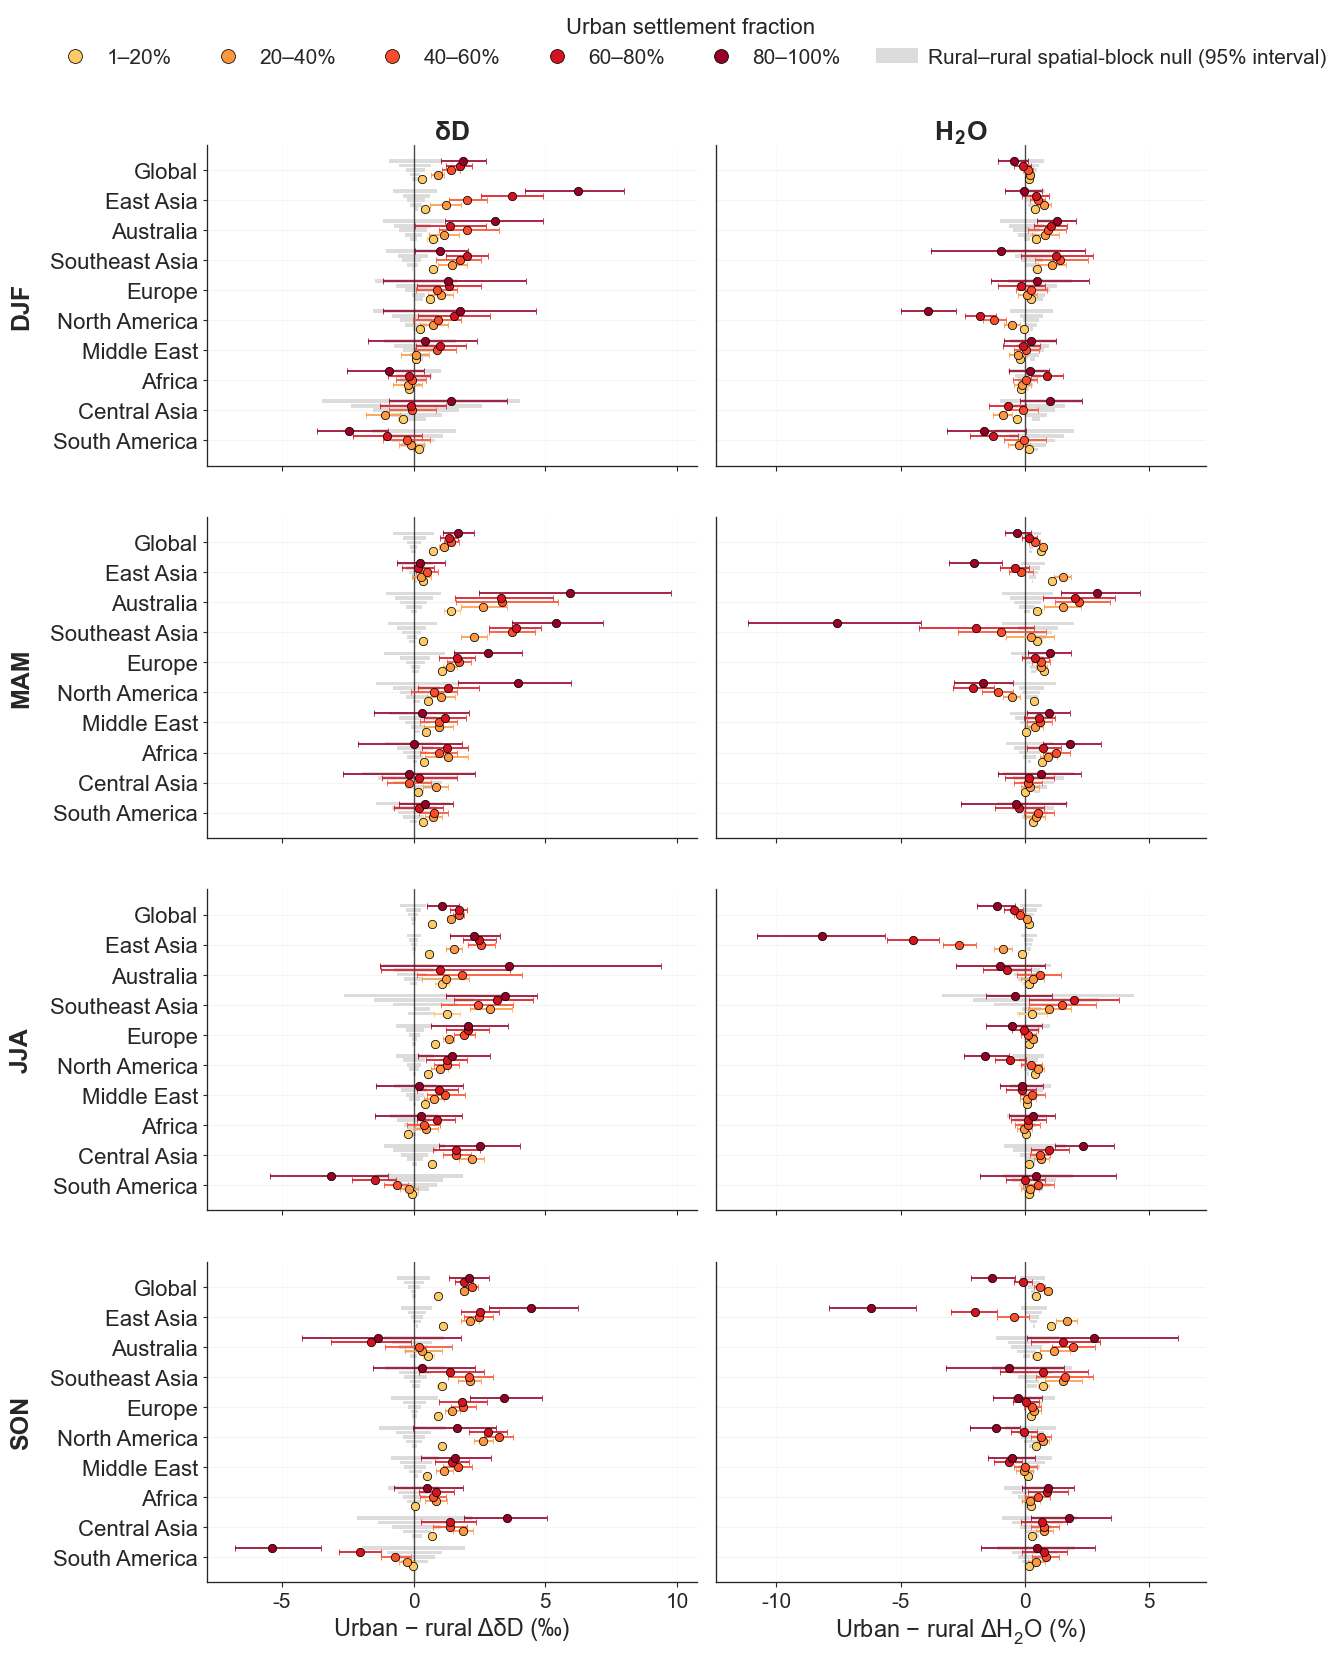


DONE


In [19]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
Figure 4 primary regional matched-pairs analysis on the 0.05-degree TROPOMI grid.

The analysis keeps matched pairs intact and uses geographic block resampling.
"""

import os
import pickle
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray
import xarray as xr
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.ndimage import distance_transform_edt
from scipy.stats import norm, rankdata, ttest_1samp
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# =============================================================================
# REVISION PATHS
# =============================================================================

REVISION_ROOT = PROJECT_ROOT

DATA_DIR = SOURCE_DATA_DIR
FIGURES_DIR = OUTPUT_FIGURES_DIR
RESULTS_DIR = OUTPUT_TABLES_DIR
CACHE_DIR = OUTPUT_CACHE_DIR

for directory in (DATA_DIR, FIGURES_DIR, RESULTS_DIR, CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Replace only this path if the final climatology has a different filename.
TROPOMI_PATH = FILES["tropomi_climatology"]

SETTLEMENT_PATH = FILES["settlement"]
ELEVATION_PATH = FILES["elevation"]
LANDMASK_PATH = FILES["landmask"]

# The native-grid sensitivity is produced by count-weighted 2x2 aggregation
# of the existing 0.05-degree climatology. It tests sensitivity to the output
# lattice and extra spatial averaging; it is not used to claim independence.
NATIVE_GRID_DEG = 0.05

# =============================================================================
# REGION DEFINITIONS
# =============================================================================

PREDEFINED_REGIONS = {
    'Global': {
        'lat_range': (-90, 90),
        'lon_range': (-180, 180),
        'description': 'Global'
    },

    'Europe': {
        'lat_range': (35, 65),
        'lon_range': (-10, 40),
        'description': 'Europe'
    },
    'North_America': {
        'lat_range': (35, 65),
        'lon_range': (-130, -70),
        'description': 'North America'
    },
    'East_Asia': {
        'lat_range': (25, 50),
        'lon_range': (100, 145),
        'description': 'East Asia'
    },
    'South_Asia': {
        'lat_range': (5, 35),
        'lon_range': (65, 95),
        'description': 'South Asia'
    },
    'Australia': {
        'lat_range': (-45, -10),
        'lon_range': (110, 155),
        'description': 'Australia'
    },
    'South_America': {
        'lat_range': (-55, 15),
        'lon_range': (-80, -35),
        'description': 'South America'
    },
    'Africa': {
        'lat_range': (-35, 35),
        'lon_range': (-20, 55),
        'description': 'Africa'
    },

    'London_Paris_Region': {
        'lat_range': (48, 54),
        'lon_range': (-5, 8),
        'description': 'London-Paris-Benelux'
    },
    'Greater_Moscow_Region': {
        'lat_range': (50, 62),
        'lon_range': (30, 45),
        'description': 'Greater Moscow'
    },
    'Madrid_Iberia': {
        'lat_range': (36, 44),
        'lon_range': (-10, 4),
        'description': 'Iberian Peninsula'
    },
    'Mediterranean_South': {
        'lat_range': (35, 45),
        'lon_range': (5, 20),
        'description': 'Mediterranean South'
    },
    'Baltic_Scandinavia': {
        'lat_range': (54, 65),
        'lon_range': (10, 30),
        'description': 'Baltic-Scandinavia'
    },

    'New_England_Northeast': {
        'lat_range': (38, 48),
        'lon_range': (-80, -67),
        'description': 'New England-Northeast'
    },
    'Great_Lakes': {
        'lat_range': (40, 50),
        'lon_range': (-90, -75),
        'description': 'Great Lakes'
    },
    'Pacific_Northwest': {
        'lat_range': (42, 52),
        'lon_range': (-125, -115),
        'description': 'Pacific Northwest'
    },
    'Southern_California': {
        'lat_range': (32, 42),
        'lon_range': (-122, -112),
        'description': 'Southern California'
    },
    'Texas_Triangle': {
        'lat_range': (27, 37),
        'lon_range': (-100, -90),
        'description': 'Texas Triangle'
    },
    'Canadian_Prairies': {
        'lat_range': (49, 58),
        'lon_range': (-120, -95),
        'description': 'Canadian Prairies'
    },
    'Mexico_City_Central': {
        'lat_range': (15, 25),
        'lon_range': (-105, -95),
        'description': 'Central Mexico'
    },

    'Beijing_North_China': {
        'lat_range': (32, 45),
        'lon_range': (110, 125),
        'description': 'North China Plain'
    },
    'Yangtze_River_Delta': {
        'lat_range': (28, 35),
        'lon_range': (115, 125),
        'description': 'Yangtze River Delta'
    },
    'Pearl_River_Delta': {
        'lat_range': (20, 26),
        'lon_range': (110, 118),
        'description': 'Pearl River Delta'
    },
    'Tokyo_Kanto': {
        'lat_range': (33, 40),
        'lon_range': (135, 145),
        'description': 'Tokyo-Kanto'
    },
    'Korean_Peninsula': {
        'lat_range': (34, 42),
        'lon_range': (124, 132),
        'description': 'Korean Peninsula'
    },
    'Southeast_Asia_Mainland': {
        'lat_range': (10, 22),
        'lon_range': (95, 110),
        'description': 'SE Asia Mainland'
    },
    'Java_Indonesia': {
        'lat_range': (-8, 0),
        'lon_range': (105, 115),
        'description': 'Java'
    },
    'Mumbai_Western_India': {
        'lat_range': (15, 25),
        'lon_range': (70, 80),
        'description': 'Western India'
    },
    'Delhi_North_India': {
        'lat_range': (25, 32),
        'lon_range': (74, 82),
        'description': 'North India'
    },
    'Middle_East_Gulf': {
        'lat_range': (22, 32),
        'lon_range': (45, 58),
        'description': 'Middle East Gulf'
    },

    'Lagos_West_Africa': {
        'lat_range': (4, 14),
        'lon_range': (-5, 10),
        'description': 'Gulf of Guinea'
    },
    'Cairo_Nile_Delta': {
        'lat_range': (27, 33),
        'lon_range': (29, 35),
        'description': 'Nile Delta'
    },
    'South_Africa_Highveld': {
        'lat_range': (-32, -22),
        'lon_range': (24, 32),
        'description': 'South Africa Highveld'
    },
    'East_Africa_Lakes': {
        'lat_range': (-5, 5),
        'lon_range': (30, 42),
        'description': 'East Africa'
    },

    'Sao_Paulo_Southeast_Brazil': {
        'lat_range': (-25, -15),
        'lon_range': (-50, -40),
        'description': 'Southeast Brazil'
    },
    'Buenos_Aires_Pampas': {
        'lat_range': (-38, -28),
        'lon_range': (-65, -55),
        'description': 'Pampas'
    },
    'Andean_Colombia': {
        'lat_range': (0, 10),
        'lon_range': (-78, -68),
        'description': 'Andean Colombia'
    },
    'Lima_Pacific_Coast': {
        'lat_range': (-15, -5),
        'lon_range': (-82, -72),
        'description': 'Pacific Coast Peru'
    },

    'Australian_East_Coast': {
        'lat_range': (-38, -25),
        'lon_range': (145, 155),
        'description': 'Australian East Coast'
    },
    'New_Zealand': {
        'lat_range': (-48, -34),
        'lon_range': (165, 180),
        'description': 'New Zealand'
    },
    'Central_Asia': {
        'lat_range': (35, 55),
        'lon_range': (45, 85),
        'description': 'Central Asia'
    },

    'Southeast_Asia': {
        'lat_range': (-10, 25),
        'lon_range': (95, 140),
        'description': 'Southeast Asia'
    },

    'Middle_East': {
        'lat_range': (12, 42),
        'lon_range': (25, 63),
        'description': 'Middle East'
    },
}

FEATURES_MATCH = ['latitude', 'longitude', 'elevation', 'dist_to_coast']

# Single source of truth for the urban-fraction colormap.
# Try plt.cm.OrRd, plt.cm.copper, or plt.cm.magma_r if you want to A/B test.
URBAN_CMAP = plt.cm.YlOrRd
URBAN_CMAP_RANGE = (0.30, 0.95)

# Null-band styling - single source of truth so the legend matches the panels.
NULL_BAND_FACECOLOR = '0.86'
NULL_BAND_ALPHA = 0.95

# Cache schema version - bump if results_nested layout or stored config layout changes.
PLOT_CACHE_VERSION = 5


# =============================================================================
# PLOT READABILITY CONTROLS
# =============================================================================
# Controls most visible text, marker, tick, legend, spacing, and figure-size
# choices for the seasonal two-variable grid figure.
#
# Options:
#   "base"         = original figure
#   "bigger"       = modestly larger, good for manuscript drafts
#   "much_bigger"  = larger labels/ticks, good for journal review PDFs
#   "poster"       = very large labels/ticks for talks/posters
#
# Fine-tune with TEXT_SIZE_MULTIPLIER and FIGURE_SIZE_MULTIPLIER without
# editing all individual values.

TEXT_SIZE_PRESET = "much_bigger"
TEXT_SIZE_MULTIPLIER = 1.0
FIGURE_SIZE_MULTIPLIER = 1.0

READABILITY_PRESETS = {
    "base": {
        "fig_width_scale": 1.00,
        "per_region_height_inches": 0.26,
        "panel_extra_height_inches": 0.40,
        "figure_extra_height_inches": 1.60,

        "font_size": 13,
        "axes_title": 14,
        "axes_label": 13,
        "xtick": 11,
        "ytick": 12,
        "legend": 11,
        "legend_title": 12,
        "suptitle": 11,
        "column_title": 15,
        "row_label": 14,
        "annotation": 10,

        "marker_size_mean": 4.5,
        "marker_size_q95": 4.0,
        "legend_marker_size": 8.0,
        "marker_edge_width": 0.40,
        "errorbar_linewidth": 0.90,
        "errorbar_capsize": 1.40,
        "errorbar_capthick": 0.60,

        "region_linewidth": 0.40,
        "grid_linewidth": 0.40,
        "zero_linewidth": 0.70,
        "spine_linewidth": 0.70,
        "tick_length_x": 2.50,
        "tick_length_y": 2.00,
        "tick_width": 0.60,
        "annotation_box_linewidth": 0.40,

        "hspace": 0.12,
        "wspace": 0.03,
        "legend_columnspacing": 1.40,
        "legend_handletextpad": 0.40,

        "legend_y_from_top_inches": 0.50,
        "legend_y_from_top_verbose_inches": 1.15,
        "top_rect_from_top_inches": 1.40,
        "top_rect_from_top_verbose_inches": 2.00,
        "suptitle_y_from_top_inches": 0.35,
        "bottom_rect_from_bottom_inches": 0.1,
    },

    "bigger": {
        "fig_width_scale": 1.06,
        "per_region_height_inches": 0.30,
        "panel_extra_height_inches": 0.48,
        "figure_extra_height_inches": 1.95,

        "font_size": 15,
        "axes_title": 16,
        "axes_label": 15,
        "xtick": 13,
        "ytick": 14,
        "legend": 13,
        "legend_title": 14,
        "suptitle": 13,
        "column_title": 17,
        "row_label": 16,
        "annotation": 11.5,

        "marker_size_mean": 5.2,
        "marker_size_q95": 4.8,
        "legend_marker_size": 9.0,
        "marker_edge_width": 0.48,
        "errorbar_linewidth": 1.05,
        "errorbar_capsize": 1.70,
        "errorbar_capthick": 0.75,

        "region_linewidth": 0.48,
        "grid_linewidth": 0.45,
        "zero_linewidth": 0.85,
        "spine_linewidth": 0.85,
        "tick_length_x": 3.10,
        "tick_length_y": 2.60,
        "tick_width": 0.70,
        "annotation_box_linewidth": 0.48,

        "hspace": 0.14,
        "wspace": 0.035,
        "legend_columnspacing": 1.55,
        "legend_handletextpad": 0.45,

        "legend_y_from_top_inches": 0.65,
        "legend_y_from_top_verbose_inches": 1.35,
        "top_rect_from_top_inches": 1.70,
        "top_rect_from_top_verbose_inches": 2.45,
        "suptitle_y_from_top_inches": 0.40,
        "bottom_rect_from_bottom_inches": 0.14,
    },

    "much_bigger": {
        "fig_width_scale": 1.12,
        "per_region_height_inches": 0.35,
        "panel_extra_height_inches": 0.58,
        "figure_extra_height_inches": 2.35,

        "font_size": 17,
        "axes_title": 18,
        "axes_label": 17,
        "xtick": 15,
        "ytick": 16,
        "legend": 15,
        "legend_title": 16,
        "suptitle": 15,
        "column_title": 19,
        "row_label": 18,
        "annotation": 13,

        "marker_size_mean": 6.0,
        "marker_size_q95": 5.5,
        "legend_marker_size": 10.0,
        "marker_edge_width": 0.55,
        "errorbar_linewidth": 1.20,
        "errorbar_capsize": 2.00,
        "errorbar_capthick": 0.90,

        "region_linewidth": 0.55,
        "grid_linewidth": 0.50,
        "zero_linewidth": 1.00,
        "spine_linewidth": 0.95,
        "tick_length_x": 3.70,
        "tick_length_y": 3.10,
        "tick_width": 0.80,
        "annotation_box_linewidth": 0.55,

        "hspace": 0.16,
        "wspace": 0.04,
        "legend_columnspacing": 1.70,
        "legend_handletextpad": 0.50,

        "legend_y_from_top_inches": 0.78,
        "legend_y_from_top_verbose_inches": 1.60,
        "top_rect_from_top_inches": 2.00,
        "top_rect_from_top_verbose_inches": 2.90,
        "suptitle_y_from_top_inches": 0.45,
        "bottom_rect_from_bottom_inches": 0.18,
    },

    "poster": {
        "fig_width_scale": 1.30,
        "per_region_height_inches": 0.45,
        "panel_extra_height_inches": 0.75,
        "figure_extra_height_inches": 3.10,

        "font_size": 21,
        "axes_title": 22,
        "axes_label": 21,
        "xtick": 18,
        "ytick": 19,
        "legend": 18,
        "legend_title": 19,
        "suptitle": 18,
        "column_title": 24,
        "row_label": 23,
        "annotation": 15.5,

        "marker_size_mean": 7.5,
        "marker_size_q95": 7.0,
        "legend_marker_size": 12.5,
        "marker_edge_width": 0.70,
        "errorbar_linewidth": 1.50,
        "errorbar_capsize": 2.60,
        "errorbar_capthick": 1.10,

        "region_linewidth": 0.70,
        "grid_linewidth": 0.65,
        "zero_linewidth": 1.20,
        "spine_linewidth": 1.10,
        "tick_length_x": 4.80,
        "tick_length_y": 4.00,
        "tick_width": 0.95,
        "annotation_box_linewidth": 0.70,

        "hspace": 0.20,
        "wspace": 0.05,
        "legend_columnspacing": 1.90,
        "legend_handletextpad": 0.58,

        "legend_y_from_top_inches": 1.05,
        "legend_y_from_top_verbose_inches": 1.95,
        "top_rect_from_top_inches": 2.55,
        "top_rect_from_top_verbose_inches": 3.55,
        "suptitle_y_from_top_inches": 0.55,
        "bottom_rect_from_bottom_inches": 0.25,
    },
}

if TEXT_SIZE_PRESET not in READABILITY_PRESETS:
    raise ValueError(
        f"Unknown TEXT_SIZE_PRESET={TEXT_SIZE_PRESET!r}. "
        f"Use one of {list(READABILITY_PRESETS)}."
    )

_FONT = READABILITY_PRESETS[TEXT_SIZE_PRESET]
_TEXT_SCALE = float(TEXT_SIZE_MULTIPLIER)
_FIG_SCALE = float(FIGURE_SIZE_MULTIPLIER)

FIG_WIDTH_SCALE = _FONT["fig_width_scale"] * _FIG_SCALE
PER_REGION_HEIGHT_INCHES = _FONT["per_region_height_inches"] * _FIG_SCALE
PANEL_EXTRA_HEIGHT_INCHES = _FONT["panel_extra_height_inches"] * _FIG_SCALE
FIGURE_EXTRA_HEIGHT_INCHES = _FONT["figure_extra_height_inches"] * _FIG_SCALE

FONTSIZE_BASE = _FONT["font_size"] * _TEXT_SCALE
FONTSIZE_AXES_TITLE = _FONT["axes_title"] * _TEXT_SCALE
FONTSIZE_AXES_LABEL = _FONT["axes_label"] * _TEXT_SCALE
FONTSIZE_XTICK = _FONT["xtick"] * _TEXT_SCALE
FONTSIZE_YTICK = _FONT["ytick"] * _TEXT_SCALE
FONTSIZE_LEGEND = _FONT["legend"] * _TEXT_SCALE
FONTSIZE_LEGEND_TITLE = _FONT["legend_title"] * _TEXT_SCALE
FONTSIZE_SUPTITLE = _FONT["suptitle"] * _TEXT_SCALE
FONTSIZE_COLUMN_TITLE = _FONT["column_title"] * _TEXT_SCALE
FONTSIZE_ROW_LABEL = _FONT["row_label"] * _TEXT_SCALE
FONTSIZE_ANNOTATION = _FONT["annotation"] * _TEXT_SCALE

MARKER_SIZE_MEAN = _FONT["marker_size_mean"] * _TEXT_SCALE
MARKER_SIZE_Q95 = _FONT["marker_size_q95"] * _TEXT_SCALE
LEGEND_MARKER_SIZE = _FONT["legend_marker_size"] * _TEXT_SCALE
MARKER_EDGE_WIDTH = _FONT["marker_edge_width"] * _TEXT_SCALE
ERRORBAR_LINEWIDTH = _FONT["errorbar_linewidth"] * _TEXT_SCALE
ERRORBAR_CAPSIZE = _FONT["errorbar_capsize"] * _TEXT_SCALE
ERRORBAR_CAPTHICK = _FONT["errorbar_capthick"] * _TEXT_SCALE

REGION_LINEWIDTH = _FONT["region_linewidth"] * _TEXT_SCALE
GRID_LINEWIDTH = _FONT["grid_linewidth"] * _TEXT_SCALE
ZERO_LINEWIDTH = _FONT["zero_linewidth"] * _TEXT_SCALE
SPINE_LINEWIDTH = _FONT["spine_linewidth"] * _TEXT_SCALE
TICK_LENGTH_X = _FONT["tick_length_x"] * _TEXT_SCALE
TICK_LENGTH_Y = _FONT["tick_length_y"] * _TEXT_SCALE
TICK_WIDTH = _FONT["tick_width"] * _TEXT_SCALE
ANNOTATION_BOX_LINEWIDTH = _FONT["annotation_box_linewidth"] * _TEXT_SCALE

PANEL_HSPACE = _FONT["hspace"]
PANEL_WSPACE = _FONT["wspace"]
LEGEND_COLUMNSPACING = _FONT["legend_columnspacing"]
LEGEND_HANDLETEXTPAD = _FONT["legend_handletextpad"]

LEGEND_Y_FROM_TOP_INCHES = _FONT["legend_y_from_top_inches"] * _FIG_SCALE
LEGEND_Y_FROM_TOP_VERBOSE_INCHES = _FONT["legend_y_from_top_verbose_inches"] * _FIG_SCALE
TOP_RECT_FROM_TOP_INCHES = _FONT["top_rect_from_top_inches"] * _FIG_SCALE
TOP_RECT_FROM_TOP_VERBOSE_INCHES = _FONT["top_rect_from_top_verbose_inches"] * _FIG_SCALE
SUPTITLE_Y_FROM_TOP_INCHES = _FONT["suptitle_y_from_top_inches"] * _FIG_SCALE
BOTTOM_RECT_FROM_BOTTOM_INCHES = _FONT["bottom_rect_from_bottom_inches"] * _FIG_SCALE


# =============================================================================
# BASIC UTILITIES
# =============================================================================

def haversine_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return c * 6371.0


def fix_longitude_convention(data, lons, target_convention='0_360'):
    if target_convention == '0_360':
        if lons[0] < 0:
            split_idx = np.where(lons >= 0)[0][0]
            data_fixed = np.concatenate([data[:, split_idx:], data[:, :split_idx]], axis=1)
            lons_west = lons[:split_idx] + 360
            lons_east = lons[split_idx:]
            lons_fixed = np.concatenate([lons_east, lons_west])
            return data_fixed, lons_fixed
    return data, lons


def get_season_months(season='annual'):
    season = season.upper()
    season_months = {
        'ANNUAL': list(range(12)),
        'MAM': [2, 3, 4],
        'JJA': [5, 6, 7],
        'SON': [8, 9, 10],
        'DJF': [11, 0, 1]
    }
    if season not in season_months:
        raise ValueError(f"Season must be one of: {list(season_months.keys())}")
    return season_months[season]


def get_seasonal_data(data_array, season='annual'):
    months = get_season_months(season)
    return data_array.isel(time=months).mean(dim='time').values


def get_weighted_seasonal_data(
    data_array,
    count_array,
    season='annual',
    min_count_per_month=5.0,
    grid_factor=1,
):
    """Count-weighted seasonal mean on the native 0.05-degree grid."""
    if int(grid_factor) != 1:
        raise ValueError("Only the native 0.05-degree grid is supported in this analysis.")
    months = get_season_months(season)
    data_sel = data_array.isel(time=months).values.astype(float)
    count_sel = count_array.isel(time=months).values.astype(float)
    valid = np.isfinite(data_sel) & np.isfinite(count_sel) & (count_sel > 0)
    weighted_sum = np.sum(np.where(valid, data_sel * count_sel, 0.0), axis=0)
    total_count = np.sum(np.where(valid, count_sel, 0.0), axis=0)
    weighted_mean = np.full(total_count.shape, np.nan, dtype=float)
    ok = total_count > 0
    weighted_mean[ok] = weighted_sum[ok] / total_count[ok]
    monthly_count = np.where(valid, count_sel, 0.0)
    supported_months = np.sum(monthly_count >= float(min_count_per_month), axis=0).astype(float)
    return weighted_mean, total_count, supported_months


def get_seasonal_count(count_array, season='annual'):
    months = get_season_months(season)
    return count_array.isel(time=months).sum(dim='time', skipna=True).values


def filter_to_region(df, region_name):
    if region_name not in PREDEFINED_REGIONS:
        raise ValueError(f"Unknown region: {region_name}")

    region_def = PREDEFINED_REGIONS[region_name]
    lat_min, lat_max = region_def['lat_range']
    lon_min, lon_max = region_def['lon_range']

    lats = df['latitude'].values
    lons = df['longitude'].values.copy()
    lons[lons > 180] -= 360

    if region_name == 'Global':
        return df.copy()

    mask = (
        (lats >= lat_min) & (lats <= lat_max) &
        (lons >= lon_min) & (lons <= lon_max)
    )
    return df[mask].copy()


def get_variable_column(variable):
    if variable == 'deltad':
        return 'delta_D'
    if variable == 'h2o':
        return 'h2o_column'
    raise ValueError("variable must be 'deltad' or 'h2o'")


# =============================================================================
# MATCHING + DISTRIBUTION SUMMARIES
# =============================================================================

def _pair_constraints_mask(
    df_t,
    df_c,
    control_indices,
    max_elev_diff_m=None,
    max_coast_diff_km=None,
    max_geo_distance_km=None,
):
    """
    Pairwise validity mask for a set of candidate control indices for each target.
    """
    t_elev = df_t['elevation'].values[:, None]
    c_elev = df_c['elevation'].values[control_indices]
    t_coast = df_t['dist_to_coast'].values[:, None]
    c_coast = df_c['dist_to_coast'].values[control_indices]

    valid = np.ones(control_indices.shape, dtype=bool)
    if max_elev_diff_m is not None:
        valid &= (np.abs(t_elev - c_elev) <= float(max_elev_diff_m))
    if max_coast_diff_km is not None:
        valid &= (np.abs(t_coast - c_coast) <= float(max_coast_diff_km))
    if max_geo_distance_km is not None:
        t_lat = df_t['latitude'].values[:, None]
        t_lon = df_t['longitude'].values[:, None]
        c_lat = df_c['latitude'].values[control_indices]
        c_lon = df_c['longitude'].values[control_indices]
        valid &= (haversine_distance(t_lat, t_lon, c_lat, c_lon) <= float(max_geo_distance_km))
    return valid


def compute_pair_differences(
    df_target,
    df_control,
    variable='deltad',
    max_elev_diff_m=None,
    max_coast_diff_km=None,
    max_geo_distance_km=None,
    without_replacement=False,
    k_neighbors=25,
    matching_mode='constraint_aware'
):
    """
    Match target pixels to rural controls and return pairwise urban-rural differences.
    """
    if matching_mode not in {'postfilter', 'constraint_aware'}:
        raise ValueError("matching_mode must be 'postfilter' or 'constraint_aware'")

    var_col = get_variable_column(variable)

    df_t = df_target.dropna(subset=FEATURES_MATCH + [var_col]).copy()
    df_c = df_control.dropna(subset=FEATURES_MATCH + [var_col]).copy()

    # Preserve the original rows before matched_controls is re-indexed.  These
    # IDs let us report how often a rural control is reused; the coordinates
    # below are what the spatial-block inference actually resamples.
    df_t['_target_id'] = df_t.index.to_numpy()
    df_c['_control_id'] = df_c.index.to_numpy()

    if len(df_t) == 0 or len(df_c) == 0:
        return None

    X_c = df_c[FEATURES_MATCH].values
    X_t = df_t[FEATURES_MATCH].values

    scaler = StandardScaler()
    X_c_norm = scaler.fit_transform(X_c)
    X_t_norm = scaler.transform(X_t)

    if matching_mode == 'postfilter' and not without_replacement:
        n_neighbors = 1
    else:
        n_neighbors = min(max(1, int(k_neighbors)), len(df_c))

    nn = NearestNeighbors(n_neighbors=n_neighbors, algorithm='kd_tree')
    nn.fit(X_c_norm)
    distances, indices = nn.kneighbors(X_t_norm)

    if indices.ndim == 1:
        indices = indices[:, None]
        distances = distances[:, None]

    chosen_control = np.full(len(df_t), -1, dtype=int)

    if matching_mode == 'constraint_aware':
        valid_candidates = _pair_constraints_mask(
            df_t, df_c, indices,
            max_elev_diff_m=max_elev_diff_m,
            max_coast_diff_km=max_coast_diff_km,
            max_geo_distance_km=max_geo_distance_km,
        )

        if without_replacement:
            best_valid_dist = np.full(len(df_t), np.inf, dtype=float)
            has_valid = np.any(valid_candidates, axis=1)
            if np.any(has_valid):
                best_valid_dist[has_valid] = np.min(
                    np.where(valid_candidates[has_valid], distances[has_valid], np.inf), axis=1
                )
            order = np.argsort(best_valid_dist)
            used_controls = set()

            for ti in order:
                if not np.isfinite(best_valid_dist[ti]):
                    continue
                for jj, cj in enumerate(indices[ti]):
                    if not valid_candidates[ti, jj]:
                        continue
                    if int(cj) not in used_controls:
                        chosen_control[ti] = int(cj)
                        used_controls.add(int(cj))
                        break
        else:
            for ti in range(len(df_t)):
                valid_js = np.where(valid_candidates[ti])[0]
                if len(valid_js):
                    chosen_control[ti] = int(indices[ti, valid_js[0]])

        keep_match = chosen_control >= 0
        if not np.any(keep_match):
            return None

        df_t = df_t.iloc[keep_match].copy()
        matched_controls = df_c.iloc[chosen_control[keep_match]].copy()
        matched_controls.index = df_t.index

    else:
        if without_replacement:
            order = np.argsort(distances[:, 0])
            used_controls = set()
            for ti in order:
                for cj in indices[ti]:
                    if int(cj) not in used_controls:
                        chosen_control[ti] = int(cj)
                        used_controls.add(int(cj))
                        break

            keep_match = chosen_control >= 0
            if not np.any(keep_match):
                return None

            df_t = df_t.iloc[keep_match].copy()
            matched_controls = df_c.iloc[chosen_control[keep_match]].copy()
            matched_controls.index = df_t.index
        else:
            matched_controls = df_c.iloc[indices[:, 0]].copy()
            matched_controls.index = df_t.index

    target_vals = df_t[var_col].values
    control_vals = matched_controls[var_col].values

    if variable == 'deltad':
        var_diff = target_vals - control_vals
    else:
        good = np.isfinite(control_vals) & (np.abs(control_vals) > 1e-12)
        if not np.any(good):
            return None
        df_t = df_t.iloc[good].copy()
        matched_controls = matched_controls.iloc[good].copy()
        target_vals = df_t[var_col].values
        control_vals = matched_controls[var_col].values
        var_diff = 100.0 * (target_vals - control_vals) / control_vals

    geo_distances = haversine_distance(
        df_t['latitude'].values, df_t['longitude'].values,
        matched_controls['latitude'].values, matched_controls['longitude'].values
    )

    lat_diff = df_t['latitude'].values - matched_controls['latitude'].values
    elev_diff = df_t['elevation'].values - matched_controls['elevation'].values
    coast_diff = df_t['dist_to_coast'].values - matched_controls['dist_to_coast'].values

    lon_diff = np.abs(df_t['longitude'].values - matched_controls['longitude'].values)
    lon_diff = np.minimum(lon_diff, 360 - lon_diff)

    n_pre_filter = len(var_diff)

    if matching_mode == 'postfilter':
        keep = np.ones(n_pre_filter, dtype=bool)
        if max_elev_diff_m is not None:
            keep &= (np.abs(elev_diff) <= float(max_elev_diff_m))
        if max_coast_diff_km is not None:
            keep &= (np.abs(coast_diff) <= float(max_coast_diff_km))
        if max_geo_distance_km is not None:
            keep &= (geo_distances <= float(max_geo_distance_km))
        keep &= np.isfinite(var_diff)
        if not np.any(keep):
            return None
    else:
        keep = np.isfinite(var_diff)
        if not np.any(keep):
            return None

    pair_df = pd.DataFrame({
        'var_diff': var_diff[keep],
        'target_lat': df_t['latitude'].values[keep],
        'target_lon': df_t['longitude'].values[keep],
        'control_lat': matched_controls['latitude'].values[keep],
        'control_lon': matched_controls['longitude'].values[keep],
        'target_id': df_t['_target_id'].values[keep],
        'control_id': matched_controls['_control_id'].values[keep],
    })

    control_counts = pair_df['control_id'].value_counts()

    return {
        'diffs': var_diff[keep],
        'pair_df': pair_df,
        'n': int(np.sum(keep)),
        'n_pre_filter': int(n_pre_filter),
        'n_dropped': int(n_pre_filter - np.sum(keep)),
        'median_geo_distance': float(np.median(geo_distances[keep])),
        'mean_lat_diff': float(np.mean(lat_diff[keep])),
        'mean_lon_diff': float(np.mean(lon_diff[keep])),
        'mean_elev_diff': float(np.mean(elev_diff[keep])),
        'mean_coast_diff': float(np.mean(coast_diff[keep])),
        'matching_mode': matching_mode,
        'k_neighbors_used': int(n_neighbors),
        'unique_control_fraction': float(pair_df['control_id'].nunique() / len(pair_df)),
        'max_control_reuse': int(control_counts.max()),
    }


def summarize_distribution(diffs):
    diffs = np.asarray(diffs, dtype=float)
    diffs = diffs[np.isfinite(diffs)]

    if len(diffs) == 0:
        return None

    mean = float(np.mean(diffs))
    median = float(np.median(diffs))
    std = float(np.std(diffs, ddof=1)) if len(diffs) > 1 else np.nan
    se = float(std / np.sqrt(len(diffs))) if len(diffs) > 1 else np.nan
    ci95 = float(1.96 * se) if len(diffs) > 1 else np.nan

    q05, q25, q50, q75, q95 = np.quantile(diffs, [0.05, 0.25, 0.50, 0.75, 0.95])
    iqr = float(q75 - q25)
    width90 = float(q95 - q05)
    mad = float(np.median(np.abs(diffs - median)))
    frac_positive = float(np.mean(diffs > 0))

    t_stat, p_val = ttest_1samp(diffs, 0.0) if len(diffs) > 1 else (np.nan, np.nan)

    return {
        'n': int(len(diffs)),
        'mean': mean,
        'median': median,
        'std': std,
        'se': se,
        'ci95': ci95,
        'q05': float(q05),
        'q25': float(q25),
        'q50': float(q50),
        'q75': float(q75),
        'q95': float(q95),
        'iqr': iqr,
        'width90': width90,
        'mad': mad,
        'frac_positive': frac_positive,
        't_stat': float(t_stat) if np.isfinite(t_stat) else np.nan,
        'p_val': float(p_val) if np.isfinite(p_val) else np.nan,
    }


# =============================================================================
# SPATIAL-BLOCK INFERENCE
# =============================================================================

def assign_spatial_blocks(latitudes, longitudes, block_km):
    """Return approximately equal-km global block labels for point centres."""
    block_km = float(block_km)
    if block_km <= 0:
        raise ValueError("block_km must be positive")

    lat = np.asarray(latitudes, dtype=float)
    lon = ((np.asarray(longitudes, dtype=float) + 180.0) % 360.0) - 180.0
    km_per_degree = 111.195

    lat_band = np.floor((lat + 90.0) * km_per_degree / block_km).astype(np.int64)
    lat_center = ((lat_band + 0.5) * block_km / km_per_degree) - 90.0
    lon_scale = np.maximum(np.cos(np.deg2rad(lat_center)), 1.0e-3)
    lon_band = np.floor((lon + 180.0) * km_per_degree * lon_scale / block_km).astype(np.int64)

    # A string label avoids accidental collisions between latitude bands whose
    # longitude blocks have different physical widths.
    return np.char.add(np.char.add(lat_band.astype(str), ':'), lon_band.astype(str))


def _block_sum_count(pair_df, block_km):
    """Aggregate intact pair differences by the target/anchor spatial block."""
    required = {'var_diff', 'target_lat', 'target_lon'}
    missing = required.difference(pair_df.columns)
    if missing:
        raise KeyError(f"pair_df is missing required columns: {sorted(missing)}")

    work = pair_df.loc[:, ['var_diff', 'target_lat', 'target_lon']].copy()
    work = work.replace([np.inf, -np.inf], np.nan).dropna()
    if len(work) == 0:
        return np.array([], dtype=float), np.array([], dtype=np.int64)

    work['block'] = assign_spatial_blocks(
        work['target_lat'].to_numpy(), work['target_lon'].to_numpy(), block_km
    )
    grouped = work.groupby('block', sort=False)['var_diff'].agg(['sum', 'count'])
    return grouped['sum'].to_numpy(dtype=float), grouped['count'].to_numpy(dtype=np.int64)


def _draw_block_weighted_means(
    block_sums,
    block_counts,
    n_blocks_per_draw,
    n_draws,
    rng,
    replace,
):
    """Draw blocks, then calculate a pixel-weighted mean from block sums/counts."""
    block_sums = np.asarray(block_sums, dtype=float)
    block_counts = np.asarray(block_counts, dtype=float)
    n_available = len(block_sums)
    n_blocks_per_draw = int(n_blocks_per_draw)

    if n_available == 0 or n_blocks_per_draw < 1:
        return np.array([], dtype=float)
    if not replace and n_blocks_per_draw > n_available:
        replace = True

    draws = np.empty(int(n_draws), dtype=float)
    for draw_i in range(int(n_draws)):
        chosen = rng.choice(n_available, size=n_blocks_per_draw, replace=replace)
        denominator = block_counts[chosen].sum()
        draws[draw_i] = block_sums[chosen].sum() / denominator if denominator > 0 else np.nan
    return draws[np.isfinite(draws)]


def spatial_block_mean_comparison(
    observed_pairs,
    rural_parent_pairs,
    block_km=25.0,
    n_draws=1000,
    random_state=42,
    minimum_blocks=10,
):
    """
    Spatial-block bootstrap for the observed mean and a block-matched RR null.

    Matched pairs stay intact. Observed blocks are bootstrapped with replacement.
    Each rural-placebo draw contains the same number of anchor blocks as the
    observed sample; sampling is without replacement when the rural parent is
    large enough. The primary p-value and CI refer to observed minus RR-null.
    """
    obs_sums, obs_counts = _block_sum_count(observed_pairs, block_km)
    rr_sums, rr_counts = _block_sum_count(rural_parent_pairs, block_km)
    n_obs_blocks = len(obs_sums)
    n_rr_blocks = len(rr_sums)

    if n_obs_blocks < int(minimum_blocks) or n_rr_blocks < int(minimum_blocks):
        return None

    rng_obs = np.random.default_rng(int(random_state))
    rng_null = np.random.default_rng(int(random_state) + 1)

    obs_draws = _draw_block_weighted_means(
        obs_sums, obs_counts,
        n_blocks_per_draw=n_obs_blocks,
        n_draws=n_draws,
        rng=rng_obs,
        replace=True,
    )
    null_replace = n_obs_blocks > n_rr_blocks
    null_draws = _draw_block_weighted_means(
        rr_sums, rr_counts,
        n_blocks_per_draw=n_obs_blocks,
        n_draws=n_draws,
        rng=rng_null,
        replace=null_replace,
    )

    n_common = min(len(obs_draws), len(null_draws))
    if n_common < 2:
        return None
    obs_draws = obs_draws[:n_common]
    null_draws = null_draws[:n_common]
    contrast_draws = obs_draws - null_draws

    obs_mean = float(np.average(obs_sums / obs_counts, weights=obs_counts))
    null_center = float(np.mean(null_draws))
    obs_lo, obs_hi = np.quantile(obs_draws, [0.025, 0.975])
    null_lo, null_hi = np.quantile(null_draws, [0.025, 0.975])
    contrast_lo, contrast_hi = np.quantile(contrast_draws, [0.025, 0.975])

    p_lower = (1.0 + np.sum(contrast_draws <= 0.0)) / (n_common + 1.0)
    p_upper = (1.0 + np.sum(contrast_draws >= 0.0)) / (n_common + 1.0)
    p_two = min(1.0, 2.0 * min(p_lower, p_upper))
    obs_percentile = 100.0 * float(np.mean(null_draws <= obs_mean))
    null_sd = float(np.std(null_draws, ddof=1))

    return {
        'n_draws': int(n_common),
        'block_km': float(block_km),
        'observed_n_blocks': int(n_obs_blocks),
        'parent_n_blocks': int(n_rr_blocks),
        'resample_size_blocks': int(n_obs_blocks),
        'replace': bool(null_replace),
        'parent_n': int(np.sum(rr_counts)),
        'mean': {
            'center': null_center,
            'lo95': float(null_lo),
            'hi95': float(null_hi),
            'sd': null_sd,
            'obs_value': obs_mean,
            'obs_ci95_lo': float(obs_lo),
            'obs_ci95_hi': float(obs_hi),
            'obs_percentile': obs_percentile,
            'p_two_sided': float(p_two),
            'p_upper': float((1.0 + np.sum(null_draws >= obs_mean)) / (n_common + 1.0)),
            'z_score': float((obs_mean - null_center) / null_sd) if null_sd > 0 else np.nan,
            'null_corrected_effect': float(obs_mean - null_center),
            'null_corrected_lo95': float(contrast_lo),
            'null_corrected_hi95': float(contrast_hi),
        },
    }


# =============================================================================
# RURAL PARENT + OBSERVED URBAN-RURAL RESULTS
# =============================================================================

def build_rural_parent_distribution(
    df_region,
    control_max,
    variable='deltad',
    max_elev_diff_m=None,
    max_coast_diff_km=None,
    max_geo_distance_km=None,
    split_seed=42,
    max_parent_anchors=30000,
    max_parent_controls=60000,
    without_replacement=True,
    k_neighbors=25,
    min_supported_months=8,
    matching_mode='constraint_aware'
):
    var_col = get_variable_column(variable)

    rural_df = df_region[
        (df_region['settlement_pct'] <= control_max) &
        (df_region['supported_months'] >= min_supported_months)
    ].dropna(subset=FEATURES_MATCH + [var_col, 'obs_count', 'supported_months']).copy()

    if len(rural_df) < 4:
        return None

    rng = np.random.default_rng(split_seed)
    perm = rng.permutation(len(rural_df))
    half = len(rural_df) // 2

    anchor_idx = perm[:half]
    control_idx = perm[half:]

    df_anchor = rural_df.iloc[anchor_idx].copy()
    df_control = rural_df.iloc[control_idx].copy()

    if max_parent_anchors is not None and len(df_anchor) > max_parent_anchors:
        pick = rng.choice(len(df_anchor), size=int(max_parent_anchors), replace=False)
        df_anchor = df_anchor.iloc[pick].copy()

    if max_parent_controls is not None and len(df_control) > max_parent_controls:
        pick = rng.choice(len(df_control), size=int(max_parent_controls), replace=False)
        df_control = df_control.iloc[pick].copy()

    pair_result = compute_pair_differences(
        df_anchor,
        df_control,
        variable=variable,
        max_elev_diff_m=max_elev_diff_m,
        max_coast_diff_km=max_coast_diff_km,
        max_geo_distance_km=max_geo_distance_km,
        without_replacement=without_replacement,
        k_neighbors=k_neighbors,
        matching_mode=matching_mode
    )

    if pair_result is None:
        return None

    summary = summarize_distribution(pair_result['diffs'])
    summary.update({
        'n_anchor_candidates': int(len(df_anchor)),
        'n_control_candidates': int(len(df_control)),
        'split_seed': int(split_seed),
        'match_without_replacement': bool(without_replacement),
        'median_geo_distance': pair_result['median_geo_distance'],
        'mean_lat_diff': pair_result['mean_lat_diff'],
        'mean_lon_diff': pair_result['mean_lon_diff'],
        'mean_elev_diff': pair_result['mean_elev_diff'],
        'mean_coast_diff': pair_result['mean_coast_diff'],
        'n_pre_filter': pair_result['n_pre_filter'],
        'n_dropped': pair_result['n_dropped'],
        'anchor_mean_obs_count': float(df_anchor['obs_count'].mean()) if len(df_anchor) else np.nan,
        'control_mean_obs_count': float(df_control['obs_count'].mean()) if len(df_control) else np.nan,
        'anchor_mean_supported_months': float(df_anchor['supported_months'].mean()) if len(df_anchor) else np.nan,
        'control_mean_supported_months': float(df_control['supported_months'].mean()) if len(df_control) else np.nan,
        'min_supported_months': float(min_supported_months),
        'matching_mode': matching_mode,
        'k_neighbors': int(k_neighbors),
        'unique_control_fraction': pair_result['unique_control_fraction'],
        'max_control_reuse': pair_result['max_control_reuse'],
    })

    return {
        'summary': summary,
        'diffs': pair_result['diffs'],
        'pair_df': pair_result['pair_df'],
    }


def get_observed_urban_rural_result(
    df_region,
    urban_min,
    urban_max,
    control_max,
    variable='deltad',
    max_elev_diff_m=None,
    max_coast_diff_km=None,
    max_geo_distance_km=None,
    without_replacement=False,
    k_neighbors=25,
    min_supported_months=8,
    matching_mode='constraint_aware'
):
    var_col = get_variable_column(variable)

    df_u = df_region[
        (df_region['settlement_pct'] >= urban_min) &
        (df_region['settlement_pct'] <= urban_max) &
        (df_region['supported_months'] >= min_supported_months)
    ].dropna(subset=FEATURES_MATCH + [var_col, 'obs_count', 'supported_months']).copy()

    df_c = df_region[
        (df_region['settlement_pct'] <= control_max) &
        (df_region['supported_months'] >= min_supported_months)
    ].dropna(subset=FEATURES_MATCH + [var_col, 'obs_count', 'supported_months']).copy()

    if len(df_u) == 0 or len(df_c) == 0:
        return None

    pair_result = compute_pair_differences(
        df_u,
        df_c,
        variable=variable,
        max_elev_diff_m=max_elev_diff_m,
        max_coast_diff_km=max_coast_diff_km,
        max_geo_distance_km=max_geo_distance_km,
        without_replacement=without_replacement,
        k_neighbors=k_neighbors,
        matching_mode=matching_mode
    )

    if pair_result is None:
        return None

    summary = summarize_distribution(pair_result['diffs'])
    summary.update({
        'n_raw_targets': int(len(df_u)),
        'n_raw_controls': int(len(df_c)),
        'n_pre_filter': pair_result['n_pre_filter'],
        'n_dropped': pair_result['n_dropped'],
        'median_geo_distance': pair_result['median_geo_distance'],
        'mean_lat_diff': pair_result['mean_lat_diff'],
        'mean_lon_diff': pair_result['mean_lon_diff'],
        'mean_elev_diff': pair_result['mean_elev_diff'],
        'mean_coast_diff': pair_result['mean_coast_diff'],
        'urban_mean_obs_count': float(df_u['obs_count'].mean()) if len(df_u) else np.nan,
        'control_mean_obs_count': float(df_c['obs_count'].mean()) if len(df_c) else np.nan,
        'urban_mean_supported_months': float(df_u['supported_months'].mean()) if len(df_u) else np.nan,
        'control_mean_supported_months': float(df_c['supported_months'].mean()) if len(df_c) else np.nan,
        'min_supported_months': float(min_supported_months),
        'matching_mode': matching_mode,
        'k_neighbors': int(k_neighbors),
        'unique_control_fraction': pair_result['unique_control_fraction'],
        'max_control_reuse': pair_result['max_control_reuse'],
    })

    return {
        'summary': summary,
        'diffs': pair_result['diffs'],
        'pair_df': pair_result['pair_df'],
    }


# =============================================================================
# RESULTS BOOKKEEPING
# =============================================================================

def get_regions_with_any_observed_data(results_nested):
    regions = []
    for region, by_bin in results_nested.items():
        if any((entry is not None and entry.get('observed') is not None) for entry in by_bin.values()):
            regions.append(region)
    return regions


def get_sorted_regions_from_deltad(results_deltad, urban_bins):
    regions = get_regions_with_any_observed_data(results_deltad)
    if len(regions) == 0:
        return []

    last_bin_key = f"{urban_bins[-1][0]}_{urban_bins[-1][1]}"

    def sort_value(region):
        entry = results_deltad[region].get(last_bin_key, None)
        if entry is not None and entry.get('observed') is not None:
            return entry['observed']['mean']

        vals = []
        for bin_key in results_deltad[region]:
            e = results_deltad[region][bin_key]
            if e is not None and e.get('observed') is not None:
                vals.append(e['observed']['mean'])
        return np.max(vals) if len(vals) else -np.inf

    return sorted(regions, key=sort_value, reverse=True)


# =============================================================================
# URBAN-INTENSITY SCALING METRIC
# =============================================================================

def _weighted_spearman_within(x, y, weights):
    """
    Weighted Spearman rho within a single region.

    Returns
    -------
    rho : float
    n_eff : float
        Kish effective sample size, (sum w)^2 / sum(w^2).
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    w = np.asarray(weights, dtype=float)

    valid = np.isfinite(x) & np.isfinite(y) & np.isfinite(w) & (w > 0)
    x = x[valid]
    y = y[valid]
    w = w[valid]

    if len(x) < 3:
        return np.nan, np.nan

    rx = rankdata(x)
    ry = rankdata(y)

    w_sum = float(w.sum())
    if w_sum <= 0:
        return np.nan, np.nan

    w_norm = w / w_sum
    mx = float(np.sum(w_norm * rx))
    my = float(np.sum(w_norm * ry))
    cov = float(np.sum(w_norm * (rx - mx) * (ry - my)))
    sx2 = float(np.sum(w_norm * (rx - mx) ** 2))
    sy2 = float(np.sum(w_norm * (ry - my) ** 2))

    if sx2 <= 0 or sy2 <= 0:
        return np.nan, np.nan

    rho = cov / np.sqrt(sx2 * sy2)
    n_eff = (w_sum ** 2) / float(np.sum(w ** 2))
    return float(rho), float(n_eff)


def _fisher_z_random_effects_pool(rhos, n_effs):
    """
    DerSimonian-Laird random-effects pooling of Spearman correlations via
    Fisher z-transform.
    """
    rhos = np.asarray(rhos, dtype=float)
    n_effs = np.asarray(n_effs, dtype=float)

    valid = np.isfinite(rhos) & np.isfinite(n_effs) & (n_effs > 3)
    rhos_v = rhos[valid]
    n_effs_v = n_effs[valid]

    if len(rhos_v) == 0:
        return None

    rhos_clip = np.clip(rhos_v, -0.9999, 0.9999)
    z_vals = 0.5 * np.log((1.0 + rhos_clip) / (1.0 - rhos_clip))
    var_within = 1.0 / (n_effs_v - 3.0)

    if len(rhos_v) == 1:
        z_pool = float(z_vals[0])
        var_pool = float(var_within[0])
        tau2 = 0.0
    else:
        w_fe = 1.0 / var_within
        z_fe = float(np.sum(w_fe * z_vals) / np.sum(w_fe))
        Q = float(np.sum(w_fe * (z_vals - z_fe) ** 2))
        df_q = len(z_vals) - 1
        c_const = float(np.sum(w_fe) - np.sum(w_fe ** 2) / np.sum(w_fe))
        tau2 = max(0.0, (Q - df_q) / c_const) if c_const > 0 else 0.0

        w_re = 1.0 / (var_within + tau2)
        z_pool = float(np.sum(w_re * z_vals) / np.sum(w_re))
        var_pool = float(1.0 / np.sum(w_re))

    se_pool = float(np.sqrt(var_pool)) if var_pool > 0 else np.nan
    if np.isfinite(se_pool) and se_pool > 0:
        z_stat = z_pool / se_pool
        p_two = float(2.0 * (1.0 - norm.cdf(abs(z_stat))))
    else:
        z_stat = np.nan
        p_two = np.nan

    rho_pool = float(np.tanh(z_pool))
    if np.isfinite(se_pool) and se_pool > 0:
        rho_lo95 = float(np.tanh(z_pool - 1.96 * se_pool))
        rho_hi95 = float(np.tanh(z_pool + 1.96 * se_pool))
    else:
        rho_lo95 = np.nan
        rho_hi95 = np.nan

    return {
        'rho_pool': rho_pool,
        'rho_lo95': rho_lo95,
        'rho_hi95': rho_hi95,
        'z_pool': z_pool,
        'se_z_pool': se_pool,
        'z_stat': float(z_stat) if np.isfinite(z_stat) else np.nan,
        'p_value': p_two,
        'tau2': float(tau2),
        'n_regions_used': int(len(rhos_v)),
        'rhos_per_region': rhos_v.tolist(),
        'n_effs_per_region': n_effs_v.tolist(),
    }


def compute_panel_spearman_with_random_effects(results_nested, urban_bins, regions):
    """
    For one panel (season x variable), compute pooled Spearman rho between
    urban-intensity bin midpoint and observed urban-rural anomaly mean,
    weighted by obs_n within each region and pooled across regions with a
    random-effects model.
    """
    rhos = []
    n_effs = []
    region_used = []

    for region in regions:
        bin_mids = []
        means = []
        ns = []
        for (umin, umax) in urban_bins:
            bin_key = f"{umin}_{umax}"
            entry = results_nested.get(region, {}).get(bin_key, None)
            if entry is None:
                continue
            obs = entry.get('observed', None)
            if obs is None:
                continue
            m = obs.get('mean', np.nan)
            n = obs.get('n', 0)
            if not np.isfinite(m) or n is None or n <= 0:
                continue
            bin_mids.append(0.5 * (umin + umax))
            means.append(m)
            ns.append(n)

        if len(bin_mids) < 3:
            continue

        rho, n_eff = _weighted_spearman_within(bin_mids, means, ns)
        if np.isfinite(rho) and np.isfinite(n_eff):
            rhos.append(rho)
            n_effs.append(n_eff)
            region_used.append(region)

    if len(rhos) == 0:
        return None

    pool = _fisher_z_random_effects_pool(np.array(rhos), np.array(n_effs))
    if pool is None:
        return None

    pool['regions'] = region_used
    return pool


def _format_spearman_label(spearman_summary):
    """Descriptive in-panel annotation (no cell-independence p-value)."""
    if spearman_summary is None:
        return None

    rho = spearman_summary.get('rho_pool', np.nan)
    n_reg = spearman_summary.get('n_regions_used', 0)

    if not np.isfinite(rho):
        return None

    return f'Descriptive $\\rho_S$ = {rho:+.2f}\n(k = {n_reg} regions)'


# =============================================================================
# AXIS LIMITS / LABELS
# =============================================================================

def _clean_axis_label(variable, metric):
    """Compact axis label for a journal figure."""
    if variable == 'deltad':
        var_str = 'ΔδD (‰)'
    else:
        var_str = r'Δ$\mathregular{H_2O}$ (%)'

    if metric == 'mean':
        return f'Urban − rural {var_str}'
    if metric == 'q95':
        return f'q95 of urban − rural {var_str}'
    raise ValueError("metric must be 'mean' or 'q95'")


def compute_axis_limits(results_nested, regions_with_data, urban_bins, metric='mean'):
    left = []
    right = []

    for region in regions_with_data:
        for urban_min, urban_max in urban_bins:
            bin_key = f"{urban_min}_{urban_max}"
            entry = results_nested.get(region, {}).get(bin_key, None)
            if entry is None or entry.get('observed') is None:
                continue

            obs = entry['observed']
            rr_null = entry.get('rr_null', None)

            if metric == 'mean':
                if np.isfinite(obs['mean']):
                    obs_lo = obs.get('ci95_lo', np.nan)
                    obs_hi = obs.get('ci95_hi', np.nan)
                    if not np.isfinite(obs_lo):
                        obs_lo = obs['mean']
                    if not np.isfinite(obs_hi):
                        obs_hi = obs['mean']
                    left.append(obs_lo)
                    right.append(obs_hi)
                if rr_null is not None and 'mean' in rr_null:
                    left.append(rr_null['mean']['lo95'])
                    right.append(rr_null['mean']['hi95'])

            elif metric == 'q95':
                if np.isfinite(obs['q95']):
                    left.append(obs['q95'])
                    right.append(obs['q95'])
                if rr_null is not None and 'q95' in rr_null:
                    left.append(rr_null['q95']['lo95'])
                    right.append(rr_null['q95']['hi95'])

    if len(left) == 0:
        return None, None

    xmin = float(np.min(left))
    xmax = float(np.max(right))
    span = xmax - xmin
    if span <= 0:
        span = max(abs(xmax), 1.0)

    pad = 0.08 * span
    xmin_plot = xmin - pad
    xmax_plot = xmax + pad

    if metric == 'mean':
        xmin_plot = min(xmin_plot, -0.05 * max(abs(xmax_plot), 1e-6))
        xmax_plot = max(xmax_plot, 0.05 * max(abs(xmin_plot), 1e-6))

    return xmin_plot, xmax_plot


def compute_axis_limits_across_seasons(results_by_season, regions_with_data, urban_bins, metric='mean'):
    """X-axis limits that span all seasons of one variable."""
    left = []
    right = []

    for season, results_nested in results_by_season.items():
        x0, x1 = compute_axis_limits(results_nested, regions_with_data, urban_bins, metric=metric)
        if x0 is not None and x1 is not None:
            left.append(x0)
            right.append(x1)

    if not left:
        return None, None

    return float(np.min(left)), float(np.max(right))


# =============================================================================
# CLEAN PANEL PRIMITIVE
# =============================================================================

def _plot_clean_metric_panel(
    ax,
    results_nested,
    variable,
    metric,
    urban_bins,
    regions_with_data,
    show_ylabels=True,
    connect_bins=False,
    colors=None,
    spearman_summary=None,
):
    """
    Forest-plot-style panel without internal title or x label.

    The rural-rural null is drawn as a thin light-gray horizontal band per
    region/bin, aligned to that bin's marker. Observed urban-rural markers
    are colored by settlement-fraction bin.

    Per-panel Spearman scaling annotation is drawn in the upper-left corner.
    """
    n_regions = len(regions_with_data)
    n_bins = len(urban_bins)

    if colors is None:
        colors = URBAN_CMAP(
            np.linspace(URBAN_CMAP_RANGE[0], URBAN_CMAP_RANGE[1], n_bins)
        )

    region_positions = np.arange(n_regions)
    y_offsets = np.array([0.0]) if n_bins == 1 else np.linspace(-0.30, 0.30, n_bins)

    for y in region_positions:
        ax.axhline(y, color='0.94', linewidth=REGION_LINEWIDTH, zorder=0)

    # ---- Per-bin rural-rural null bands -------------------------------------
    if n_bins == 1:
        band_half_height = 0.32
    else:
        spacing = 0.60 / (n_bins - 1)
        band_half_height = spacing * 0.40

    for bin_idx, (urban_min, urban_max) in enumerate(urban_bins):
        bin_key = f"{urban_min}_{urban_max}"

        for i, region in enumerate(regions_with_data):
            entry = results_nested.get(region, {}).get(bin_key, None)

            if entry is None:
                continue

            rr_null = entry.get('rr_null', None)

            if rr_null is None or metric not in rr_null:
                continue

            lo = rr_null[metric].get('lo95', np.nan)
            hi = rr_null[metric].get('hi95', np.nan)

            if not (np.isfinite(lo) and np.isfinite(hi)):
                continue

            y_center = region_positions[i] + y_offsets[bin_idx]

            ax.fill_betweenx(
                [y_center - band_half_height, y_center + band_half_height],
                lo,
                hi,
                facecolor=NULL_BAND_FACECOLOR,
                edgecolor='none',
                alpha=NULL_BAND_ALPHA,
                zorder=0.5,
            )

    # ---- Observed urban-rural points per bin --------------------------------
    per_region_obs_coords = {region: [] for region in regions_with_data}

    for bin_idx, (urban_min, urban_max) in enumerate(urban_bins):
        bin_key = f"{urban_min}_{urban_max}"

        obs_x = np.full(n_regions, np.nan)
        obs_err_low = np.full(n_regions, np.nan)
        obs_err_high = np.full(n_regions, np.nan)

        for i, region in enumerate(regions_with_data):
            entry = results_nested.get(region, {}).get(bin_key, None)

            if entry is None or entry.get('observed') is None:
                continue

            obs = entry['observed']

            if metric == 'mean':
                obs_x[i] = obs['mean']
                ci_lo = obs.get('ci95_lo', np.nan)
                ci_hi = obs.get('ci95_hi', np.nan)
                if np.isfinite(ci_lo) and np.isfinite(ci_hi):
                    obs_err_low[i] = max(0.0, obs_x[i] - ci_lo)
                    obs_err_high[i] = max(0.0, ci_hi - obs_x[i])
            elif metric == 'q95':
                obs_x[i] = obs['q95']

        y_pos = region_positions + y_offsets[bin_idx]

        mask_obs = np.isfinite(obs_x)

        if metric == 'mean':
            mask_obs &= np.isfinite(obs_err_low) & np.isfinite(obs_err_high)

        if np.any(mask_obs):
            if metric == 'mean':
                ax.errorbar(
                    obs_x[mask_obs],
                    y_pos[mask_obs],
                    xerr=np.vstack([
                        obs_err_low[mask_obs],
                        obs_err_high[mask_obs],
                    ]),
                    fmt='o',
                    markersize=MARKER_SIZE_MEAN,
                    markeredgewidth=MARKER_EDGE_WIDTH,
                    elinewidth=ERRORBAR_LINEWIDTH,
                    capsize=ERRORBAR_CAPSIZE,
                    capthick=ERRORBAR_CAPTHICK,
                    color=colors[bin_idx],
                    markerfacecolor=colors[bin_idx],
                    markeredgecolor='black',
                    zorder=3,
                )
            elif metric == 'q95':
                ax.plot(
                    obs_x[mask_obs],
                    y_pos[mask_obs],
                    marker='D',
                    linestyle='None',
                    markersize=MARKER_SIZE_Q95,
                    markeredgewidth=MARKER_EDGE_WIDTH,
                    color=colors[bin_idx],
                    markerfacecolor=colors[bin_idx],
                    markeredgecolor='black',
                    zorder=3,
                )

        for i, region in enumerate(regions_with_data):
            if mask_obs[i]:
                per_region_obs_coords[region].append((obs_x[i], y_pos[i]))

    if connect_bins:
        for region in regions_with_data:
            coords = per_region_obs_coords[region]

            if len(coords) < 2:
                continue

            coords = sorted(coords, key=lambda t: t[1])
            xs = [c[0] for c in coords]
            ys = [c[1] for c in coords]

            ax.plot(
                xs,
                ys,
                linewidth=0.65 * ERRORBAR_LINEWIDTH,
                alpha=0.25,
                color='0.3',
                zorder=1,
            )

    if metric == 'mean':
        ax.axvline(
            0,
            color='black',
            linewidth=ZERO_LINEWIDTH,
            alpha=0.7,
            zorder=1,
        )

    region_labels = [PREDEFINED_REGIONS[r]['description'] for r in regions_with_data]
    ax.set_yticks(region_positions)
    ax.set_yticklabels(region_labels, fontsize=FONTSIZE_YTICK)

    if show_ylabels:
        ax.tick_params(
            axis='y',
            labelleft=True,
            left=True,
            length=TICK_LENGTH_Y,
            width=TICK_WIDTH,
            labelsize=FONTSIZE_YTICK,
        )
    else:
        ax.tick_params(
            axis='y',
            labelleft=False,
            left=False,
            length=0,
            width=0,
        )

    ax.tick_params(
        axis='x',
        length=TICK_LENGTH_X,
        width=TICK_WIDTH,
        labelsize=FONTSIZE_XTICK,
    )

    ax.grid(
        True,
        axis='x',
        which='major',
        alpha=0.12,
        linewidth=GRID_LINEWIDTH,
    )
    ax.set_axisbelow(True)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(SPINE_LINEWIDTH)
    ax.spines['bottom'].set_linewidth(SPINE_LINEWIDTH)

    # ---- Spearman scaling annotation ----------------------------------------
    label = _format_spearman_label(spearman_summary)

    if label is not None:
        ax.text(
            0.025,
            0.975,
            label,
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=FONTSIZE_ANNOTATION,
            color='0.12',
            linespacing=1.15,
            bbox=dict(
                facecolor='white',
                edgecolor='0.75',
                linewidth=ANNOTATION_BOX_LINEWIDTH,
                alpha=0.85,
                boxstyle='round,pad=0.25',
            ),
            zorder=10,
        )


# =============================================================================
# COMBINED (4 SEASONS x 2 VARIABLES) FIGURE
# =============================================================================

def _format_constraint_suptitle(
    control_max,
    max_elev_diff_m,
    max_coast_diff_km,
    max_geo_distance_km,
    min_supported_months,
    min_count_per_month,
):
    """
    One-line description of the active matching/coverage constraints.
    """
    parts = []

    parts.append(f'rural ≤ {control_max:g}%')

    if max_elev_diff_m is None:
        parts.append('|Δelev| unconstrained')
    else:
        parts.append(f'|Δelev| ≤ {max_elev_diff_m:g} m')

    if max_coast_diff_km is None:
        parts.append('|Δcoast| unconstrained')
    else:
        parts.append(f'|Δcoast| ≤ {max_coast_diff_km:g} km')

    if max_geo_distance_km is None:
        parts.append('geo distance unconstrained')
    else:
        parts.append(f'geo distance ≤ {max_geo_distance_km:g} km')

    parts.append(
        f'supported months ≥ {min_supported_months:g} '
        f'(count ≥ {min_count_per_month:g}/month)'
    )

    return '   ·   '.join(parts)


def plot_seasonal_two_variable_grid(
    results_deltad_by_season,
    results_h2o_by_season,
    seasons,
    urban_bins,
    control_max,
    multi_region_name,
    metric='mean',
    connect_bins=False,
    max_elev_diff_m=None,
    max_coast_diff_km=None,
    max_geo_distance_km=None,
    min_supported_months=8,
    min_count_per_month=5.0,
    output_dir=OUTPUT_FIGURES_DIR,
    regions_with_data=None,
    fig_width=11.5,
    verbose_title=False,
):
    """
    Single figure: rows = seasons, columns = deltad and H2O.
    Each column has its own x-axis range, shared across all seasons.

    Text, tick, legend, marker, and layout sizes are controlled by the
    READABILITY_PRESETS block near the top of the script.
    """
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
        'font.size': FONTSIZE_BASE,
        'axes.titlesize': FONTSIZE_AXES_TITLE,
        'axes.labelsize': FONTSIZE_AXES_LABEL,
        'xtick.labelsize': FONTSIZE_XTICK,
        'ytick.labelsize': FONTSIZE_YTICK,
        'legend.fontsize': FONTSIZE_LEGEND,
        'axes.linewidth': SPINE_LINEWIDTH,
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
    })

    if regions_with_data is None:
        regions_with_data = get_sorted_regions_from_deltad_across_seasons(
            results_deltad_by_season,
            urban_bins,
        )

    if len(regions_with_data) == 0:
        print("⚠️  No valid results to plot.")
        return

    n_regions = len(regions_with_data)
    n_bins = len(urban_bins)
    n_seasons = len(seasons)

    colors = URBAN_CMAP(
        np.linspace(URBAN_CMAP_RANGE[0], URBAN_CMAP_RANGE[1], n_bins)
    )

    xmin_d, xmax_d = compute_axis_limits_across_seasons(
        results_deltad_by_season,
        regions_with_data,
        urban_bins,
        metric=metric,
    )
    xmin_h, xmax_h = compute_axis_limits_across_seasons(
        results_h2o_by_season,
        regions_with_data,
        urban_bins,
        metric=metric,
    )

    if xmin_d is None or xmin_h is None:
        print("⚠️  No valid axis limits.")
        return

    # ---- Compute per-panel Spearman summaries -------------------------------
    spearman_summaries = {}
    spearman_csv_rows = []

    for season in seasons:
        for var_label, results_by_season in [
            ('deltad', results_deltad_by_season),
            ('h2o', results_h2o_by_season),
        ]:
            results_nested = results_by_season.get(season, {})

            summary = compute_panel_spearman_with_random_effects(
                results_nested,
                urban_bins,
                regions_with_data,
            )
            spearman_summaries[(season, var_label)] = summary

            if summary is not None:
                spearman_csv_rows.append({
                    'season': season,
                    'variable': var_label,
                    'metric': metric,
                    'rho_pool': summary['rho_pool'],
                    'rho_lo95_naive_not_spatially_corrected': summary['rho_lo95'],
                    'rho_hi95_naive_not_spatially_corrected': summary['rho_hi95'],
                    'p_value_naive_not_spatially_corrected': summary['p_value'],
                    'z_pool': summary['z_pool'],
                    'se_z_pool': summary['se_z_pool'],
                    'tau2': summary['tau2'],
                    'n_regions_used': summary['n_regions_used'],
                    'regions_used': '|'.join(summary.get('regions', [])),
                    'rhos_per_region': '|'.join(
                        f'{r:+.4f}' for r in summary.get('rhos_per_region', [])
                    ),
                })

    if spearman_csv_rows:
        os.makedirs(output_dir, exist_ok=True)

        spearman_df = pd.DataFrame(spearman_csv_rows)
        spearman_csv = os.path.join(
            output_dir,
            f'Spearman_UrbanIntensityScaling_{multi_region_name}_{metric}.csv',
        )
        spearman_df.to_csv(spearman_csv, index=False)

        print(f"\n📊 Per-panel Spearman scaling summary saved: {spearman_csv}")

        cols_to_show = [
            'season',
            'variable',
            'rho_pool',
            'rho_lo95',
            'rho_hi95',
            'p_value',
            'tau2',
            'n_regions_used',
        ]
        print(spearman_df[cols_to_show].to_string(index=False, float_format='%.3f'))

    # ---- Layout -------------------------------------------------------------
    effective_fig_width = fig_width * FIG_WIDTH_SCALE

    per_panel_h = PER_REGION_HEIGHT_INCHES * n_regions + PANEL_EXTRA_HEIGHT_INCHES
    fig_height = per_panel_h * n_seasons + FIGURE_EXTRA_HEIGHT_INCHES

    fig, axes = plt.subplots(
        n_seasons,
        2,
        figsize=(effective_fig_width, fig_height),
        sharey=True,
        sharex='col',
        gridspec_kw={
            'hspace': PANEL_HSPACE,
            'wspace': PANEL_WSPACE,
        },
    )

    if n_seasons == 1:
        axes = np.atleast_2d(axes)

    var_specs = [
        (
            'deltad',
            results_deltad_by_season,
            (xmin_d, xmax_d),
            'δD',
            _clean_axis_label('deltad', metric),
        ),
        (
            'h2o',
            results_h2o_by_season,
            (xmin_h, xmax_h),
            r'H$_\mathregular{2}$O',
            _clean_axis_label('h2o', metric),
        ),
    ]

    for row_idx, season in enumerate(seasons):
        for col_idx, (
            variable,
            results_by_season,
            xlim,
            var_title,
            var_axis_label,
        ) in enumerate(var_specs):

            ax = axes[row_idx, col_idx]

            _plot_clean_metric_panel(
                ax,
                results_nested=results_by_season[season],
                variable=variable,
                metric=metric,
                urban_bins=urban_bins,
                regions_with_data=regions_with_data,
                show_ylabels=(col_idx == 0),
                connect_bins=connect_bins,
                colors=colors,
                spearman_summary=spearman_summaries.get((season, variable)),
            )

            ax.set_xlim(*xlim)
            ax.invert_yaxis()

            if row_idx == n_seasons - 1:
                ax.set_xlabel(var_axis_label, fontsize=FONTSIZE_AXES_LABEL)
            else:
                ax.set_xlabel('')

            if row_idx == 0:
                ax.set_title(
                    var_title,
                    pad=4,
                    fontweight='bold',
                    fontsize=FONTSIZE_COLUMN_TITLE,
                )

            if col_idx == 0:
                ax.text(
                    -0.38,
                    0.5,
                    season,
                    transform=ax.transAxes,
                    fontsize=FONTSIZE_ROW_LABEL,
                    fontweight='bold',
                    ha='center',
                    va='center',
                    rotation=90,
                )

    # ---- Suptitle and top layout --------------------------------------------
    if verbose_title:
        suptitle_text = _format_constraint_suptitle(
            control_max=control_max,
            max_elev_diff_m=max_elev_diff_m,
            max_coast_diff_km=max_coast_diff_km,
            max_geo_distance_km=max_geo_distance_km,
            min_supported_months=min_supported_months,
            min_count_per_month=min_count_per_month,
        )

        fig.suptitle(
            suptitle_text,
            fontsize=FONTSIZE_SUPTITLE,
            color='0.18',
            y=1.0 - SUPTITLE_Y_FROM_TOP_INCHES / fig_height,
        )

        legend_y = 1.0 - LEGEND_Y_FROM_TOP_VERBOSE_INCHES / fig_height
        top_rect = 1.0 - TOP_RECT_FROM_TOP_VERBOSE_INCHES / fig_height

    else:
        legend_y = 1.0 - LEGEND_Y_FROM_TOP_INCHES / fig_height
        top_rect = 1.0 - TOP_RECT_FROM_TOP_INCHES / fig_height

    bottom_rect = BOTTOM_RECT_FROM_BOTTOM_INCHES / fig_height

    # ---- Legend -------------------------------------------------------------
    marker_style = 'o' if metric == 'mean' else 'D'

    handles = [
        Line2D(
            [0],
            [0],
            marker=marker_style,
            linestyle='None',
            markerfacecolor=colors[i],
            markeredgecolor='black',
            markersize=LEGEND_MARKER_SIZE,
            markeredgewidth=MARKER_EDGE_WIDTH,
            label=f'{urban_bins[i][0]}–{urban_bins[i][1]}%',
        )
        for i in range(n_bins)
    ]

    handles.append(
        Patch(
            facecolor=NULL_BAND_FACECOLOR,
            edgecolor='none',
            alpha=NULL_BAND_ALPHA,
            label='Rural–rural spatial-block null (95% interval)',
        )
    )

    fig.legend(
        handles=handles,
        title='Urban settlement fraction',
        loc='upper center',
        bbox_to_anchor=(0.5, legend_y),
        frameon=False,
        ncol=min(n_bins + 1, 6),
        columnspacing=LEGEND_COLUMNSPACING,
        handletextpad=LEGEND_HANDLETEXTPAD,
        fontsize=FONTSIZE_LEGEND,
        title_fontsize=FONTSIZE_LEGEND_TITLE,
    )

    plt.tight_layout(rect=[0.01, bottom_rect, 1.0, top_rect])

    # ---- Save ---------------------------------------------------------------
    stem = 'Mean' if metric == 'mean' else 'Q95'

    os.makedirs(output_dir, exist_ok=True)

    fname_base = os.path.join(output_dir, "Figure_4_Regional_anomalies")

    fig.savefig(fname_base + '.png', dpi=600, bbox_inches='tight', facecolor='white')
    fig.savefig(fname_base + '.pdf', bbox_inches='tight', facecolor='white')

    print(f"\n✅ Saved: {fname_base}.png")
    print(f"✅ Saved: {fname_base}.pdf")

    plt.show()


# =============================================================================
# PLOT-DATA CACHE
# =============================================================================

def _build_data_config(
    seasons,
    regions_to_analyze,
    urban_intensity_bins,
    control_max,
    max_elev_diff_m,
    max_coast_diff_km,
    max_geo_distance_km,
    min_supported_months,
    min_count_per_month,
    n_null_draws,
    rr_parent_max_anchors,
    rr_parent_max_controls,
    observed_without_replacement,
    rr_without_replacement,
    k_neighbors_obs,
    k_neighbors_rr,
    observed_matching_mode,
    rr_matching_mode,
    multi_region_name,
    grid_factor,
    primary_block_km,
    block_sensitivity_km,
):
    """
    Canonicalize all data-affecting parameters into a comparable dict.
    """
    return {
        'seasons': list(seasons),
        'regions_to_analyze': list(regions_to_analyze),
        'urban_intensity_bins': [list(b) for b in urban_intensity_bins],
        'control_max': float(control_max),
        'max_elev_diff_m': None if max_elev_diff_m is None else float(max_elev_diff_m),
        'max_coast_diff_km': None if max_coast_diff_km is None else float(max_coast_diff_km),
        'max_geo_distance_km': None if max_geo_distance_km is None else float(max_geo_distance_km),
        'min_supported_months': float(min_supported_months),
        'min_count_per_month': float(min_count_per_month),
        'n_null_draws': int(n_null_draws),
        'rr_parent_max_anchors': None if rr_parent_max_anchors is None else int(rr_parent_max_anchors),
        'rr_parent_max_controls': None if rr_parent_max_controls is None else int(rr_parent_max_controls),
        'observed_without_replacement': bool(observed_without_replacement),
        'rr_without_replacement': bool(rr_without_replacement),
        'k_neighbors_obs': int(k_neighbors_obs),
        'k_neighbors_rr': int(k_neighbors_rr),
        'observed_matching_mode': str(observed_matching_mode),
        'rr_matching_mode': str(rr_matching_mode),
        'multi_region_name': str(multi_region_name),
        'grid_factor': int(grid_factor),
        'analysis_grid_degrees': float(NATIVE_GRID_DEG * int(grid_factor)),
        'primary_block_km': float(primary_block_km),
        'block_sensitivity_km': [float(x) for x in block_sensitivity_km],
    }


def _diff_data_configs(cached, current):
    """
    Return a list of (key, cached_value, current_value) tuples for differing keys.
    """
    keys = set(cached.keys()) | set(current.keys())
    diffs = []
    for k in sorted(keys):
        cv = cached.get(k, '<missing>')
        nv = current.get(k, '<missing>')
        if cv != nv:
            diffs.append((k, cv, nv))
    return diffs


def save_plot_cache(
    cache_path,
    results_deltad_by_season,
    results_h2o_by_season,
    regions_with_data,
    config,
):
    """
    Pickle enough state to redraw the figure.
    """
    cache = {
        'version': PLOT_CACHE_VERSION,
        'config': dict(config),
        'results_deltad_by_season': results_deltad_by_season,
        'results_h2o_by_season': results_h2o_by_season,
        'regions_with_data': list(regions_with_data),
    }
    os.makedirs(os.path.dirname(cache_path) or '.', exist_ok=True)
    with open(cache_path, 'wb') as f:
        pickle.dump(cache, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"💾 Plot cache saved: {cache_path}")
    print(f"   config keys: {len(cache['config'])}")


def load_plot_cache(cache_path):
    """Load a plot cache. Raises if the schema version does not match."""
    with open(cache_path, 'rb') as f:
        cache = pickle.load(f)

    cache_version = cache.get('version', 0)
    if cache_version != PLOT_CACHE_VERSION:
        raise ValueError(
            f"Plot cache version mismatch: file has v{cache_version}, "
            f"code expects v{PLOT_CACHE_VERSION}. Delete {cache_path} and rerun."
        )

    if 'config' not in cache:
        raise ValueError(
            f"Plot cache at {cache_path} is missing 'config' field "
            f"(legacy cache?). Delete it and rerun."
        )

    print(f"📂 Plot cache loaded: {cache_path}")
    return cache


# =============================================================================
# DATA LOADING
# =============================================================================

def load_static_dataframe(grid_factor=1):
    if int(grid_factor) != 1:
        raise ValueError("Only the native 0.05-degree grid is supported in this analysis.")
    grid_deg = NATIVE_GRID_DEG
    print(f"\nLoading shared/static datasets for the {grid_deg:.2f} degree analysis...")
    tropomi_ds = xr.open_dataset(TROPOMI_PATH)
    lats = tropomi_ds['lat'].values
    lons = tropomi_ds['lon'].values
    settlement_ds = xr.open_dataset(SETTLEMENT_PATH)
    settlement = settlement_ds['settlement_percentage'].values.astype(float)
    elevation_ds = rioxarray.open_rasterio(ELEVATION_PATH)
    elevation = elevation_ds.values[0] if len(elevation_ds.shape) == 3 else elevation_ds.values
    elev_lons = elevation_ds.x.values
    elevation, elev_lons = fix_longitude_convention(elevation, elev_lons, target_convention='0_360')
    elevation[elevation < -10000] = np.nan
    landmask_ds = xr.open_dataset(LANDMASK_PATH)
    land_mask = landmask_ds['land_mask'].values.astype(float)
    expected=(len(lats),len(lons))
    for label,arr in [('settlement',settlement),('elevation',elevation),('land mask',land_mask)]:
        if arr.shape != expected:
            raise ValueError(f"{label} grid {arr.shape} does not match TROPOMI grid {expected}")
    lat_2d, lon_2d = np.meshgrid(lats, lons, indexing='ij')
    ocean_mask = (land_mask == 0)
    distance_grid_cells = distance_transform_edt(~ocean_mask)
    lat_rad = np.deg2rad(lat_2d)
    dx_km = grid_deg * 111.0 * np.cos(lat_rad)
    dy_km = grid_deg * 111.0
    avg_cell_size_km = np.sqrt(dx_km ** 2 + dy_km ** 2) / np.sqrt(2.0)
    distance_to_ocean_km = distance_grid_cells * avg_cell_size_km
    df_static = pd.DataFrame({
        'flat_idx': np.arange(settlement.size, dtype=np.int64),
        'settlement_pct': settlement.flatten(),
        'elevation': elevation.flatten(),
        'latitude': lat_2d.flatten(),
        'longitude': lon_2d.flatten(),
        'dist_to_coast': distance_to_ocean_km.flatten(),
        'land_mask': land_mask.flatten(),
    }).replace([np.inf,-np.inf],np.nan).dropna()
    df_static=df_static[(df_static['land_mask']==1)&(df_static['elevation']>-50)].drop(columns='land_mask').copy()
    print(f"   Total land pixels in shared dataframe: {len(df_static):,}")
    settlement_ds.close()
    return tropomi_ds, landmask_ds, elevation_ds, df_static


def build_variable_dataframe(
    df_static,
    tropomi_ds,
    season,
    variable,
    min_count_per_month=5.0,
    grid_factor=1,
):
    print(f"\n📦 Building dataframe for {variable.upper()} only...")

    if 'count' not in tropomi_ds.data_vars:
        raise KeyError("Variable 'count' not found in the TROPOMI dataset.")

    count_var = tropomi_ds['count']
    df_var = df_static.copy()

    if variable == 'deltad':
        data_var = tropomi_ds['deltad']

        sample_values = data_var.isel(time=0).values.flatten()
        sample_values = sample_values[~np.isnan(sample_values)]
        if len(sample_values) > 0 and np.ptp(sample_values) < 10:
            data_var = data_var * 1000.0

        seasonal, total_count, supported_months = get_weighted_seasonal_data(
            data_var, count_var, season=season,
            min_count_per_month=min_count_per_month,
            grid_factor=grid_factor,
        )
        seasonal_flat = seasonal.flatten()
        total_count_flat = total_count.flatten()
        supported_months_flat = supported_months.flatten()

        df_var['delta_D'] = seasonal_flat[df_var['flat_idx'].values]
        df_var['obs_count'] = total_count_flat[df_var['flat_idx'].values]
        df_var['supported_months'] = supported_months_flat[df_var['flat_idx'].values]

    elif variable == 'h2o':
        data_var = tropomi_ds['h2o_column']
        seasonal, total_count, supported_months = get_weighted_seasonal_data(
            data_var, count_var, season=season,
            min_count_per_month=min_count_per_month,
            grid_factor=grid_factor,
        )
        seasonal_flat = seasonal.flatten()
        total_count_flat = total_count.flatten()
        supported_months_flat = supported_months.flatten()

        df_var['h2o_column'] = seasonal_flat[df_var['flat_idx'].values]
        df_var['obs_count'] = total_count_flat[df_var['flat_idx'].values]
        df_var['supported_months'] = supported_months_flat[df_var['flat_idx'].values]

    else:
        raise ValueError("Supported variables: 'deltad', 'h2o'")

    df_var = df_var.replace([np.inf, -np.inf], np.nan).dropna()

    print(f"   Valid land pixels after adding {variable}: {len(df_var):,}")
    if len(df_var) > 0:
        print(f"   Seasonal total obs_count range: {df_var['obs_count'].min():.1f} to {df_var['obs_count'].max():.1f}")
        print(f"   Supported-months range: {df_var['supported_months'].min():.0f} to {df_var['supported_months'].max():.0f}")

    return df_var


# =============================================================================
# ANALYSIS DRIVER
# =============================================================================

def run_analysis_for_variable_with_rural_benchmark(
    df,
    regions_to_analyze,
    urban_intensity_bins,
    control_max,
    variable,
    max_elev_diff_m=None,
    max_coast_diff_km=None,
    max_geo_distance_km=None,
    n_null_draws=50,
    rr_parent_max_anchors=30000,
    rr_parent_max_controls=60000,
    observed_without_replacement=False,
    rr_without_replacement=True,
    k_neighbors_obs=25,
    k_neighbors_rr=25,
    observed_matching_mode='constraint_aware',
    rr_matching_mode='constraint_aware',
    split_seed_base=42,
    null_seed_base=1000,
    min_supported_months=8,
    primary_block_km=50.0,
    block_sensitivity_km=(25.0, 50.0, 100.0),
):
    print("\n" + "=" * 78)
    print(f"RUNNING OBSERVED + RURAL-PLACEBO ANALYSES FOR {variable.upper()}")
    print("=" * 78)

    results_nested = {}
    rr_parent_by_region = {}

    for r_idx, region_name in enumerate(regions_to_analyze):
        print(f"\n{'─' * 78}")
        print(f"🌍 {region_name}")
        print(f"{'─' * 78}")

        df_region = filter_to_region(df, region_name)
        print(f"   Pixels in region: {len(df_region):,}")

        results_nested[region_name] = {}

        rr_parent = build_rural_parent_distribution(
            df_region=df_region,
            control_max=control_max,
            variable=variable,
            max_elev_diff_m=max_elev_diff_m,
            max_coast_diff_km=max_coast_diff_km,
            max_geo_distance_km=max_geo_distance_km,
            split_seed=split_seed_base + r_idx,
            max_parent_anchors=rr_parent_max_anchors,
            max_parent_controls=rr_parent_max_controls,
            without_replacement=rr_without_replacement,
            k_neighbors=k_neighbors_rr,
            min_supported_months=min_supported_months,
            matching_mode=rr_matching_mode
        )

        rr_parent_by_region[region_name] = rr_parent

        if rr_parent is not None:
            rr_s = rr_parent['summary']
            print(
                "   Rural parent: "
                f"n={rr_s['n']:,}, mean={rr_s['mean']:.2f}, median={rr_s['median']:.2f}, "
                f"q95={rr_s['q95']:.2f}, IQR={rr_s['iqr']:.2f}, "
                f"5-95%={rr_s['q05']:.2f} to {rr_s['q95']:.2f}, "
                f"anchor mean obs_count={rr_s.get('anchor_mean_obs_count', np.nan):.1f}, "
                f"control mean obs_count={rr_s.get('control_mean_obs_count', np.nan):.1f}, "
                f"anchor mean supported months={rr_s.get('anchor_mean_supported_months', np.nan):.1f}, "
                f"control mean supported months={rr_s.get('control_mean_supported_months', np.nan):.1f}"
            )
        else:
            print("   Rural parent: ⚠️ insufficient rural data after coverage filtering")

        for b_idx, (urban_min, urban_max) in enumerate(urban_intensity_bins):
            bin_key = f"{urban_min}_{urban_max}"
            print(f"\n   Urban {urban_min}–{urban_max}%:")

            obs = get_observed_urban_rural_result(
                df_region=df_region,
                urban_min=urban_min,
                urban_max=urban_max,
                control_max=control_max,
                variable=variable,
                max_elev_diff_m=max_elev_diff_m,
                max_coast_diff_km=max_coast_diff_km,
                max_geo_distance_km=max_geo_distance_km,
                without_replacement=observed_without_replacement,
                k_neighbors=k_neighbors_obs,
                min_supported_months=min_supported_months,
                matching_mode=observed_matching_mode
            )

            if obs is None:
                print("      ⚠️  Insufficient observed data after coverage filtering")
                results_nested[region_name][bin_key] = {
                    'observed': None,
                    'rr_null': None,
                }
                continue

            obs_s = obs['summary']
            print(
                f"      Observed descriptive statistics: mean={obs_s['mean']:.2f}, "
                f"median={obs_s['median']:.2f}, q95={obs_s['q95']:.2f}, "
                f"5-95%={obs_s['q05']:.2f} to {obs_s['q95']:.2f}, n={obs_s['n']:,}, "
                f"unique-control fraction={obs_s.get('unique_control_fraction', np.nan):.3f}, "
                f"urban mean obs_count={obs_s.get('urban_mean_obs_count', np.nan):.1f}, "
                f"control mean obs_count={obs_s.get('control_mean_obs_count', np.nan):.1f}, "
                f"urban mean supported months={obs_s.get('urban_mean_supported_months', np.nan):.1f}, "
                f"control mean supported months={obs_s.get('control_mean_supported_months', np.nan):.1f}"
            )

            rr_null = None
            block_sensitivity = {}
            block_sizes = sorted({float(primary_block_km), *map(float, block_sensitivity_km)})

            if rr_parent is not None:
                for block_km in block_sizes:
                    block_result = spatial_block_mean_comparison(
                        observed_pairs=obs['pair_df'],
                        rural_parent_pairs=rr_parent['pair_df'],
                        block_km=block_km,
                        n_draws=n_null_draws,
                        random_state=(
                            null_seed_base + 10000 * r_idx + 100 * b_idx + int(round(block_km))
                        ),
                    )
                    block_sensitivity[f"{block_km:g}"] = block_result

                rr_null = block_sensitivity.get(f"{float(primary_block_km):g}")

            # Retain the old cell-level quantities only as plainly labelled
            # diagnostics. They are not used for error bars or inference.
            obs_s['naive_cell_ci95'] = obs_s.get('ci95', np.nan)
            obs_s['naive_cell_p_ttest'] = obs_s.get('p_val', np.nan)
            obs_s['primary_block_km'] = float(primary_block_km)

            if rr_null is not None:
                mean_block = rr_null['mean']
                obs_s['ci95_lo'] = mean_block['obs_ci95_lo']
                obs_s['ci95_hi'] = mean_block['obs_ci95_hi']
                obs_s['ci95'] = max(
                    obs_s['mean'] - obs_s['ci95_lo'],
                    obs_s['ci95_hi'] - obs_s['mean'],
                )
                obs_s['n_blocks'] = rr_null['observed_n_blocks']
                obs_s['block_p_two_sided'] = mean_block['p_two_sided']
                obs_s['null_corrected_effect'] = mean_block['null_corrected_effect']
                obs_s['null_corrected_lo95'] = mean_block['null_corrected_lo95']
                obs_s['null_corrected_hi95'] = mean_block['null_corrected_hi95']
                print(
                    f"      {primary_block_km:g}-km block inference: "
                    f"observed 95% CI [{obs_s['ci95_lo']:.2f}, {obs_s['ci95_hi']:.2f}], "
                    f"RR null [{mean_block['lo95']:.2f}, {mean_block['hi95']:.2f}], "
                    f"blocks={rr_null['observed_n_blocks']}, "
                    f"null-corrected p={mean_block['p_two_sided']:.4f}"
                )
            else:
                obs_s['ci95_lo'] = np.nan
                obs_s['ci95_hi'] = np.nan
                obs_s['ci95'] = np.nan
                obs_s['n_blocks'] = np.nan
                obs_s['block_p_two_sided'] = np.nan
                obs_s['null_corrected_effect'] = np.nan
                obs_s['null_corrected_lo95'] = np.nan
                obs_s['null_corrected_hi95'] = np.nan
                print("      Block inference: ⚠️ fewer than 3 observed or rural-parent blocks")

            results_nested[region_name][bin_key] = {
                'observed': obs_s,
                'rr_null': rr_null,
                'block_sensitivity': block_sensitivity,
            }

    return results_nested, rr_parent_by_region


def results_to_dataframe(results_nested, rr_parent_by_region, variable, grid_factor=1):
    rows = []

    for region_name, by_bin in results_nested.items():
        rr_parent = rr_parent_by_region.get(region_name, None)
        rr_summary = rr_parent['summary'] if rr_parent is not None else None

        for bin_key, entry in by_bin.items():
            urban_min, urban_max = [float(x) for x in bin_key.split('_')]
            row = {
                'variable': variable,
                'region_key': region_name,
                'region_description': PREDEFINED_REGIONS[region_name]['description'],
                'urban_min': urban_min,
                'urban_max': urban_max,
                'analysis_grid_degrees': float(NATIVE_GRID_DEG * int(grid_factor)),
            }

            if rr_summary is not None:
                row.update({
                    'rr_parent_n': rr_summary['n'],
                    'rr_parent_mean': rr_summary['mean'],
                    'rr_parent_median': rr_summary['median'],
                    'rr_parent_q95': rr_summary['q95'],
                    'rr_parent_iqr': rr_summary['iqr'],
                    'rr_parent_q05': rr_summary['q05'],
                    'rr_parent_width90': rr_summary['width90'],
                    'rr_parent_anchor_mean_obs_count': rr_summary.get('anchor_mean_obs_count', np.nan),
                    'rr_parent_control_mean_obs_count': rr_summary.get('control_mean_obs_count', np.nan),
                    'rr_parent_anchor_mean_supported_months': rr_summary.get('anchor_mean_supported_months', np.nan),
                    'rr_parent_control_mean_supported_months': rr_summary.get('control_mean_supported_months', np.nan),
                    'rr_parent_min_supported_months': rr_summary.get('min_supported_months', np.nan),
                    'rr_parent_matching_mode': rr_summary.get('matching_mode', np.nan),
                    'rr_parent_k_neighbors': rr_summary.get('k_neighbors', np.nan),
                    'rr_parent_unique_control_fraction': rr_summary.get('unique_control_fraction', np.nan),
                    'rr_parent_max_control_reuse': rr_summary.get('max_control_reuse', np.nan),
                })
            else:
                row.update({
                    'rr_parent_n': np.nan,
                    'rr_parent_mean': np.nan,
                    'rr_parent_median': np.nan,
                    'rr_parent_q95': np.nan,
                    'rr_parent_iqr': np.nan,
                    'rr_parent_q05': np.nan,
                    'rr_parent_width90': np.nan,
                    'rr_parent_anchor_mean_obs_count': np.nan,
                    'rr_parent_control_mean_obs_count': np.nan,
                    'rr_parent_anchor_mean_supported_months': np.nan,
                    'rr_parent_control_mean_supported_months': np.nan,
                    'rr_parent_min_supported_months': np.nan,
                    'rr_parent_matching_mode': np.nan,
                    'rr_parent_k_neighbors': np.nan,
                    'rr_parent_unique_control_fraction': np.nan,
                    'rr_parent_max_control_reuse': np.nan,
                })

            obs = entry.get('observed', None)
            rr_null = entry.get('rr_null', None)

            if obs is not None:
                row.update({
                    'obs_n': obs['n'],
                    'obs_mean': obs['mean'],
                    'obs_block_ci95_lo': obs.get('ci95_lo', np.nan),
                    'obs_block_ci95_hi': obs.get('ci95_hi', np.nan),
                    'obs_n_spatial_blocks': obs.get('n_blocks', np.nan),
                    'primary_block_km': obs.get('primary_block_km', np.nan),
                    'obs_median': obs['median'],
                    'obs_q95': obs['q95'],
                    'obs_iqr': obs['iqr'],
                    'obs_q05': obs['q05'],
                    'obs_width90': obs['width90'],
                    'obs_naive_cell_ci95_do_not_use': obs.get('naive_cell_ci95', np.nan),
                    'obs_naive_cell_p_ttest_do_not_use': obs.get('naive_cell_p_ttest', np.nan),
                    'obs_block_null_corrected_p_two_sided': obs.get('block_p_two_sided', np.nan),
                    'obs_null_corrected_effect': obs.get('null_corrected_effect', np.nan),
                    'obs_null_corrected_lo95': obs.get('null_corrected_lo95', np.nan),
                    'obs_null_corrected_hi95': obs.get('null_corrected_hi95', np.nan),
                    'obs_unique_control_fraction': obs.get('unique_control_fraction', np.nan),
                    'obs_max_control_reuse': obs.get('max_control_reuse', np.nan),
                    'obs_urban_mean_obs_count': obs.get('urban_mean_obs_count', np.nan),
                    'obs_control_mean_obs_count': obs.get('control_mean_obs_count', np.nan),
                    'obs_urban_mean_supported_months': obs.get('urban_mean_supported_months', np.nan),
                    'obs_control_mean_supported_months': obs.get('control_mean_supported_months', np.nan),
                    'obs_min_supported_months': obs.get('min_supported_months', np.nan),
                    'obs_matching_mode': obs.get('matching_mode', np.nan),
                    'obs_k_neighbors': obs.get('k_neighbors', np.nan),
                })
            else:
                row.update({
                    'obs_n': np.nan,
                    'obs_mean': np.nan,
                    'obs_block_ci95_lo': np.nan,
                    'obs_block_ci95_hi': np.nan,
                    'obs_n_spatial_blocks': np.nan,
                    'primary_block_km': np.nan,
                    'obs_median': np.nan,
                    'obs_q95': np.nan,
                    'obs_iqr': np.nan,
                    'obs_q05': np.nan,
                    'obs_width90': np.nan,
                    'obs_naive_cell_ci95_do_not_use': np.nan,
                    'obs_naive_cell_p_ttest_do_not_use': np.nan,
                    'obs_block_null_corrected_p_two_sided': np.nan,
                    'obs_null_corrected_effect': np.nan,
                    'obs_null_corrected_lo95': np.nan,
                    'obs_null_corrected_hi95': np.nan,
                    'obs_unique_control_fraction': np.nan,
                    'obs_max_control_reuse': np.nan,
                    'obs_urban_mean_obs_count': np.nan,
                    'obs_control_mean_obs_count': np.nan,
                    'obs_urban_mean_supported_months': np.nan,
                    'obs_control_mean_supported_months': np.nan,
                    'obs_min_supported_months': np.nan,
                    'obs_matching_mode': np.nan,
                    'obs_k_neighbors': np.nan,
                })

            if rr_null is not None:
                row.update({
                    'null_draws': rr_null['n_draws'],
                    'null_replace': rr_null['replace'],
                    'null_block_km': rr_null['block_km'],
                    'null_observed_n_blocks': rr_null['observed_n_blocks'],
                    'null_parent_n_blocks': rr_null['parent_n_blocks'],
                    'null_resample_size_blocks': rr_null['resample_size_blocks'],

                    'null_mean_center': rr_null['mean']['center'],
                    'null_mean_lo95': rr_null['mean']['lo95'],
                    'null_mean_hi95': rr_null['mean']['hi95'],
                    'null_corrected_p_two_sided': rr_null['mean']['p_two_sided'],
                    'null_mean_p_upper': rr_null['mean']['p_upper'],
                    'null_mean_percentile': rr_null['mean']['obs_percentile'],
                    'null_corrected_effect': rr_null['mean']['null_corrected_effect'],
                    'null_corrected_lo95': rr_null['mean']['null_corrected_lo95'],
                    'null_corrected_hi95': rr_null['mean']['null_corrected_hi95'],
                })
            else:
                row.update({
                    'null_draws': np.nan,
                    'null_replace': np.nan,
                    'null_block_km': np.nan,
                    'null_observed_n_blocks': np.nan,
                    'null_parent_n_blocks': np.nan,
                    'null_resample_size_blocks': np.nan,

                    'null_mean_center': np.nan,
                    'null_mean_lo95': np.nan,
                    'null_mean_hi95': np.nan,
                    'null_corrected_p_two_sided': np.nan,
                    'null_mean_p_upper': np.nan,
                    'null_mean_percentile': np.nan,
                    'null_corrected_effect': np.nan,
                    'null_corrected_lo95': np.nan,
                    'null_corrected_hi95': np.nan,
                })

            # Wide-form block-size sensitivity columns make it easy to compare
            # 25/50/100-km results in a spreadsheet without parsing pickles.
            for block_key, block_result in entry.get('block_sensitivity', {}).items():
                prefix = f"sensitivity_{block_key.replace('.', 'p')}km"
                if block_result is None:
                    for suffix in (
                        'obs_n_blocks', 'parent_n_blocks', 'obs_ci95_lo', 'obs_ci95_hi',
                        'null_lo95', 'null_hi95', 'effect', 'effect_lo95', 'effect_hi95',
                        'p_two_sided',
                    ):
                        row[f'{prefix}_{suffix}'] = np.nan
                    continue
                block_mean = block_result['mean']
                row.update({
                    f'{prefix}_obs_n_blocks': block_result['observed_n_blocks'],
                    f'{prefix}_parent_n_blocks': block_result['parent_n_blocks'],
                    f'{prefix}_obs_ci95_lo': block_mean['obs_ci95_lo'],
                    f'{prefix}_obs_ci95_hi': block_mean['obs_ci95_hi'],
                    f'{prefix}_null_lo95': block_mean['lo95'],
                    f'{prefix}_null_hi95': block_mean['hi95'],
                    f'{prefix}_effect': block_mean['null_corrected_effect'],
                    f'{prefix}_effect_lo95': block_mean['null_corrected_lo95'],
                    f'{prefix}_effect_hi95': block_mean['null_corrected_hi95'],
                    f'{prefix}_p_two_sided': block_mean['p_two_sided'],
                })

            rows.append(row)

    return pd.DataFrame(rows)


# =============================================================================
# MULTI-SEASON UTILITIES
# =============================================================================

def get_sorted_regions_from_deltad_across_seasons(results_deltad_by_season, urban_bins):
    region_set = set()
    for season_results in results_deltad_by_season.values():
        region_set.update(get_regions_with_any_observed_data(season_results))

    if len(region_set) == 0:
        return []

    last_bin_key = f"{urban_bins[-1][0]}_{urban_bins[-1][1]}"

    def score_region(region):
        vals = []
        for season in ['DJF', 'MAM', 'JJA', 'SON']:
            season_results = results_deltad_by_season.get(season, {})
            entry = season_results.get(region, {}).get(last_bin_key, None)
            if entry is not None and entry.get('observed') is not None:
                val = entry['observed'].get('mean', np.nan)
                if np.isfinite(val):
                    vals.append(val)
        if len(vals) == 0:
            return -np.inf
        return float(np.mean(vals))

    return sorted(region_set, key=score_region, reverse=True)


# =============================================================================
# MAIN - ALL SEASONS, COMBINED FIGURE
# =============================================================================

def main_all_seasons(
    seasons=('DJF', 'MAM', 'JJA', 'SON'),
    regions_to_analyze=None,
    urban_intensity_bins=None,
    control_max=1.0,
    max_elev_diff_m=None,
    max_coast_diff_km=None,
    max_geo_distance_km=None,
    multi_region_name='MultiRegion',
    n_null_draws=1000,
    rr_parent_max_anchors=30000,
    rr_parent_max_controls=60000,
    observed_without_replacement=False,
    rr_without_replacement=True,
    k_neighbors_obs=25,
    k_neighbors_rr=25,
    observed_matching_mode='constraint_aware',
    rr_matching_mode='constraint_aware',
    min_supported_months=8,
    min_count_per_month=5.0,
    output_dir=OUTPUT_FIGURES_DIR,
    results_dir=None,
    grid_factor=1,
    primary_block_km=50.0,
    block_sensitivity_km=(25.0, 50.0, 100.0),
    connect_bins=False,
    fig_width=11.5,
    metrics_to_plot=('mean',),
    cache_path=None,
    replot_from_cache=False,
    verbose_title=False,
):
    """
    Run all-season analysis and plot the combined figure.

    Style-only changes can be tested quickly by setting REPLOT_FROM_CACHE=True
    after one successful full run. The cache config intentionally ignores
    readability settings because they do not affect the computed results.
    """
    if cache_path is None:
        cache_path = os.path.join(output_dir, 'plot_cache.pkl')
    if results_dir is None:
        results_dir = output_dir

    if regions_to_analyze is None:
        regions_to_analyze = ['Global', 'Europe', 'North_America', 'East_Asia']

    if urban_intensity_bins is None:
        urban_intensity_bins = [(20, 30), (30, 40), (40, 60), (60, 100)]

    current_config = _build_data_config(
        seasons=seasons,
        regions_to_analyze=regions_to_analyze,
        urban_intensity_bins=urban_intensity_bins,
        control_max=control_max,
        max_elev_diff_m=max_elev_diff_m,
        max_coast_diff_km=max_coast_diff_km,
        max_geo_distance_km=max_geo_distance_km,
        min_supported_months=min_supported_months,
        min_count_per_month=min_count_per_month,
        n_null_draws=n_null_draws,
        rr_parent_max_anchors=rr_parent_max_anchors,
        rr_parent_max_controls=rr_parent_max_controls,
        observed_without_replacement=observed_without_replacement,
        rr_without_replacement=rr_without_replacement,
        k_neighbors_obs=k_neighbors_obs,
        k_neighbors_rr=k_neighbors_rr,
        observed_matching_mode=observed_matching_mode,
        rr_matching_mode=rr_matching_mode,
        multi_region_name=multi_region_name,
        grid_factor=grid_factor,
        primary_block_km=primary_block_km,
        block_sensitivity_km=block_sensitivity_km,
    )

    # ----- fast path: replot from cache --------------------------------------
    use_cache = False
    cache = None

    if replot_from_cache:
        if not os.path.exists(cache_path):
            print(f"⚠️  replot_from_cache=True but no cache at {cache_path}; running full pipeline.")
        else:
            try:
                cache = load_plot_cache(cache_path)
                cached_config = cache.get('config', {})
                diffs = _diff_data_configs(cached_config, current_config)
                if len(diffs) == 0:
                    use_cache = True
                else:
                    print("⚠️  Cached config differs from current config on the following keys "
                          f"({len(diffs)} mismatch{'es' if len(diffs) != 1 else ''}):")
                    for k, cv, nv in diffs:
                        print(f"     - {k}: cached={cv!r}  →  current={nv!r}")
                    print("   → cache invalidated; falling back to full pipeline run.")
            except Exception as exc:
                print(f"⚠️  Could not load cache at {cache_path} ({exc}); running full pipeline.")

    if use_cache:
        print("⚡ FAST PATH: regenerating figure from plot cache (skipping full pipeline)")
        print("=" * 78)

        cfg = cache['config']
        os.makedirs(output_dir, exist_ok=True)

        for metric in metrics_to_plot:
            plot_seasonal_two_variable_grid(
                results_deltad_by_season=cache['results_deltad_by_season'],
                results_h2o_by_season=cache['results_h2o_by_season'],
                seasons=cfg['seasons'],
                urban_bins=[tuple(b) for b in cfg['urban_intensity_bins']],
                control_max=cfg['control_max'],
                multi_region_name=cfg['multi_region_name'],
                metric=metric,
                connect_bins=connect_bins,
                max_elev_diff_m=cfg['max_elev_diff_m'],
                max_coast_diff_km=cfg['max_coast_diff_km'],
                max_geo_distance_km=cfg['max_geo_distance_km'],
                min_supported_months=cfg['min_supported_months'],
                min_count_per_month=cfg['min_count_per_month'],
                output_dir=output_dir,
                regions_with_data=cache['regions_with_data'],
                fig_width=fig_width,
                verbose_title=verbose_title,
            )

        print("\n" + "=" * 78)
        print("DONE (from cache)")
        print("=" * 78)

        return {
            'results_deltad_by_season': cache['results_deltad_by_season'],
            'results_h2o_by_season': cache['results_h2o_by_season'],
            'regions_with_data': cache['regions_with_data'],
            'config': cfg,
            'from_cache': True,
        }

    # ----- normal full pipeline ----------------------------------------------
    print("🚀 URBAN INTENSITY GRADIENT ANALYSIS WITH RURAL PLACEBO - ALL SEASONS")
    print("=" * 78)
    print(f"Seasons: {list(seasons)}")
    print("Observed distributions: urban vs matched rural controls")
    print("Null benchmark: split-sample rural parent + spatial-block-matched resampling")
    print(f"Control: ≤{control_max}%")
    print(f"Urban intensity bins: {urban_intensity_bins}")
    print(f"Null draws per region/bin: {n_null_draws}")
    print(
        f"Analysis grid: {NATIVE_GRID_DEG * int(grid_factor):.2f}°; "
        f"primary inference block: {primary_block_km:g} km; "
        f"block sensitivities: {tuple(block_sensitivity_km)} km"
    )
    print(f"Coverage rule: keep pixels only if supported_months ≥ {min_supported_months:g} with count ≥ {min_count_per_month:g}")
    print(f"Observed matching: {observed_matching_mode} | wo/replacement={observed_without_replacement} | k={k_neighbors_obs}")
    print(f"RR-parent matching: {rr_matching_mode} | wo/replacement={rr_without_replacement} | k={k_neighbors_rr}")
    if (max_elev_diff_m is not None) or (max_coast_diff_km is not None) or (max_geo_distance_km is not None):
        parts = []
        if max_elev_diff_m is not None:
            parts.append(f"|Δelev|≤{max_elev_diff_m:g} m")
        if max_coast_diff_km is not None:
            parts.append(f"|Δcoast|≤{max_coast_diff_km:g} km")
        if max_geo_distance_km is not None:
            parts.append(f"geo distance≤{max_geo_distance_km:g} km")
        print(f"Pair filter: {', '.join(parts)}")
    else:
        print("Pair filter: (none)")
    print(f"Plot cache: {cache_path}")
    print(f"Verbose title: {verbose_title}")
    print(f"Text-size preset: {TEXT_SIZE_PRESET}; text multiplier={TEXT_SIZE_MULTIPLIER}; figure multiplier={FIGURE_SIZE_MULTIPLIER}")
    print("=" * 78)

    os.makedirs(output_dir, exist_ok=True)
    os.makedirs(results_dir, exist_ok=True)
    tropomi_ds, landmask_ds, elevation_ds, df_static = load_static_dataframe(
        grid_factor=grid_factor
    )

    all_results_deltad = {}
    all_results_h2o = {}
    all_tables_deltad = {}
    all_tables_h2o = {}
    all_rr_parent_deltad = {}
    all_rr_parent_h2o = {}

    try:
        for season in seasons:
            print("\n" + "#" * 78)
            print(f"PROCESSING {season}")
            print("#" * 78)

            df_deltad = build_variable_dataframe(
                df_static, tropomi_ds, season, variable='deltad',
                min_count_per_month=min_count_per_month,
                grid_factor=grid_factor,
            )
            results_deltad, rr_parent_deltad = run_analysis_for_variable_with_rural_benchmark(
                df=df_deltad,
                regions_to_analyze=regions_to_analyze,
                urban_intensity_bins=urban_intensity_bins,
                control_max=control_max,
                variable='deltad',
                max_elev_diff_m=max_elev_diff_m,
                max_coast_diff_km=max_coast_diff_km,
                max_geo_distance_km=max_geo_distance_km,
                n_null_draws=n_null_draws,
                rr_parent_max_anchors=rr_parent_max_anchors,
                rr_parent_max_controls=rr_parent_max_controls,
                observed_without_replacement=observed_without_replacement,
                rr_without_replacement=rr_without_replacement,
                k_neighbors_obs=k_neighbors_obs,
                k_neighbors_rr=k_neighbors_rr,
                observed_matching_mode=observed_matching_mode,
                rr_matching_mode=rr_matching_mode,
                min_supported_months=min_supported_months,
                primary_block_km=primary_block_km,
                block_sensitivity_km=block_sensitivity_km,
            )
            df_deltad_table = results_to_dataframe(
                results_deltad, rr_parent_deltad, variable='deltad', grid_factor=grid_factor
            )
            deltad_csv = os.path.join(results_dir, f'Urban_vs_RuralNull_deltad_{multi_region_name}_{season}.csv')
            df_deltad_table.to_csv(deltad_csv, index=False)
            print(f"\n✅ Saved table: {deltad_csv}")
            del df_deltad

            df_h2o = build_variable_dataframe(
                df_static, tropomi_ds, season, variable='h2o',
                min_count_per_month=min_count_per_month,
                grid_factor=grid_factor,
            )
            results_h2o, rr_parent_h2o = run_analysis_for_variable_with_rural_benchmark(
                df=df_h2o,
                regions_to_analyze=regions_to_analyze,
                urban_intensity_bins=urban_intensity_bins,
                control_max=control_max,
                variable='h2o',
                max_elev_diff_m=max_elev_diff_m,
                max_coast_diff_km=max_coast_diff_km,
                max_geo_distance_km=max_geo_distance_km,
                n_null_draws=n_null_draws,
                rr_parent_max_anchors=rr_parent_max_anchors,
                rr_parent_max_controls=rr_parent_max_controls,
                observed_without_replacement=observed_without_replacement,
                rr_without_replacement=rr_without_replacement,
                k_neighbors_obs=k_neighbors_obs,
                k_neighbors_rr=k_neighbors_rr,
                observed_matching_mode=observed_matching_mode,
                rr_matching_mode=rr_matching_mode,
                min_supported_months=min_supported_months,
                primary_block_km=primary_block_km,
                block_sensitivity_km=block_sensitivity_km,
            )
            df_h2o_table = results_to_dataframe(
                results_h2o, rr_parent_h2o, variable='h2o', grid_factor=grid_factor
            )
            h2o_csv = os.path.join(results_dir, f'Urban_vs_RuralNull_h2o_{multi_region_name}_{season}.csv')
            df_h2o_table.to_csv(h2o_csv, index=False)
            print(f"\n✅ Saved table: {h2o_csv}")
            del df_h2o

            all_results_deltad[season] = results_deltad
            all_results_h2o[season] = results_h2o
            all_tables_deltad[season] = df_deltad_table
            all_tables_h2o[season] = df_h2o_table
            all_rr_parent_deltad[season] = rr_parent_deltad
            all_rr_parent_h2o[season] = rr_parent_h2o

        regions_prov = [
            'Global',
            'East_Asia',
            'Australia',
            'Southeast_Asia',
            'Europe',
            'North_America',
            'Middle_East',
            'Africa',
            'Central_Asia',
            'South_America'
        ]
        regions_with_data = regions_prov[::-1]

        save_plot_cache(
            cache_path=cache_path,
            results_deltad_by_season=all_results_deltad,
            results_h2o_by_season=all_results_h2o,
            regions_with_data=regions_with_data,
            config=current_config,
        )

        print("\n" + "=" * 78)
        print("CREATING COMBINED FIGURE (4 SEASONS x δD,H2O)")
        print("=" * 78)

        for metric in metrics_to_plot:
            plot_seasonal_two_variable_grid(
                results_deltad_by_season=all_results_deltad,
                results_h2o_by_season=all_results_h2o,
                seasons=seasons,
                urban_bins=urban_intensity_bins,
                control_max=control_max,
                multi_region_name=multi_region_name,
                metric=metric,
                connect_bins=connect_bins,
                max_elev_diff_m=max_elev_diff_m,
                max_coast_diff_km=max_coast_diff_km,
                max_geo_distance_km=max_geo_distance_km,
                min_supported_months=min_supported_months,
                min_count_per_month=min_count_per_month,
                output_dir=output_dir,
                regions_with_data=regions_with_data,
                fig_width=fig_width,
                verbose_title=verbose_title,
            )

        print("\n" + "=" * 78)
        print("DONE")
        print("=" * 78)

        return {
            'results_deltad_by_season': all_results_deltad,
            'results_h2o_by_season': all_results_h2o,
            'tables_deltad_by_season': all_tables_deltad,
            'tables_h2o_by_season': all_tables_h2o,
            'rr_parent_deltad_by_season': all_rr_parent_deltad,
            'rr_parent_h2o_by_season': all_rr_parent_h2o,
            'regions_with_data': regions_with_data,
            'config': current_config,
            'from_cache': False,
        }
    finally:
        tropomi_ds.close()
        landmask_ds.close()
        elevation_ds.close()


# =============================================================================
# CONFIGURATION
# =============================================================================

SEASONS = ['DJF', 'MAM', 'JJA', 'SON']
CONTROL_MAX = 1.0

URBAN_INTENSITY_BINS = [
    (1, 20),
    (20, 40),
    (40, 60),
    (60, 80),
    (80, 100)
]

MAX_ELEV_DIFF_M = 50.0
MAX_COAST_DIFF_KM = 50.0
# Maximum allowed great-circle distance (km) between an urban target pixel and
# its matched rural control. Set to None to disable the constraint, or to e.g.
# 500.0 / 1000.0 to enforce regional matching. Like the elevation/coast filters,
# this is applied in both constraint_aware and postfilter matching modes.
MAX_GEO_DISTANCE_KM = 150

MIN_COUNT_PER_MONTH = 5.0
MIN_SUPPORTED_MONTHS = 2

N_NULL_DRAWS = 1000

# The 25-km result is used in Figure 4. The 50- and 100-km results are written
# to the CSV tables as inference-scale sensitivity checks.
PRIMARY_BLOCK_KM = 25.0
BLOCK_SENSITIVITY_KM = (25.0, 50.0, 100.0)


RR_PARENT_MAX_ANCHORS = 30000
RR_PARENT_MAX_CONTROLS = 60000

OBSERVED_MATCHING_MODE = 'constraint_aware'
RR_MATCHING_MODE = 'constraint_aware'

OBSERVED_WITHOUT_REPLACEMENT = False
RR_WITHOUT_REPLACEMENT = True

K_NEIGHBORS_OBS = 25
K_NEIGHBORS_RR = 25

MULTI_REGION_NAME = 'Continental_Extended'
REGIONS = [
    'South_America',
    'Middle_East',
    'Central_Asia',
    'Africa',
    'Australia',
    'Southeast_Asia',
    'Europe',
    'North_America',
    'East_Asia',
    'Global',
]

LATITUDE_BANDS = [
    {'name': 'Low_Southern', 'lat_min': -40, 'lat_max': -20, 'description': 'Low Southern (40-20°S)'},
    {'name': 'Tropics', 'lat_min': -20, 'lat_max': 20, 'description': 'Tropics (20°S-20°N)'},
    {'name': 'Low_Northern', 'lat_min': 20, 'lat_max': 40, 'description': 'Low Northern (20-40°N)'},
    {'name': 'Mid_Northern', 'lat_min': 40, 'lat_max': 65, 'description': 'Mid Northern (40-65°N)'}
]

for band in LATITUDE_BANDS:
    PREDEFINED_REGIONS[band['name']] = {
        'lat_range': (band['lat_min'], band['lat_max']),
        'lon_range': (-180, 180),
        'description': band['description']
    }

# -----------------------------------------------------------------------------
# Cache controls
# -----------------------------------------------------------------------------
# Flip to True to skip the full pipeline and redraw from the cache.
# If the cache file is missing OR the cached config differs from the current
# config on any data-affecting parameter, the script auto-falls-back to a
# full pipeline run.
REPLOT_FROM_CACHE = False

# -----------------------------------------------------------------------------
# Figure annotation
# -----------------------------------------------------------------------------
# When True, the combined figure carries a one-line suptitle that lists the
# active matching constraints. Useful for sanity-checking sensitivity runs.
VERBOSE_TITLE = False


if __name__ == '__main__':
    figure4_primary_outputs = main_all_seasons(
        seasons=SEASONS,
        regions_to_analyze=REGIONS,
        urban_intensity_bins=URBAN_INTENSITY_BINS,
        control_max=CONTROL_MAX,
        max_elev_diff_m=MAX_ELEV_DIFF_M,
        max_coast_diff_km=MAX_COAST_DIFF_KM,
        max_geo_distance_km=MAX_GEO_DISTANCE_KM,
        multi_region_name=MULTI_REGION_NAME,
        n_null_draws=N_NULL_DRAWS,
        rr_parent_max_anchors=RR_PARENT_MAX_ANCHORS,
        rr_parent_max_controls=RR_PARENT_MAX_CONTROLS,
        observed_without_replacement=OBSERVED_WITHOUT_REPLACEMENT,
        rr_without_replacement=RR_WITHOUT_REPLACEMENT,
        k_neighbors_obs=K_NEIGHBORS_OBS,
        k_neighbors_rr=K_NEIGHBORS_RR,
        observed_matching_mode=OBSERVED_MATCHING_MODE,
        rr_matching_mode=RR_MATCHING_MODE,
        min_supported_months=MIN_SUPPORTED_MONTHS,
        min_count_per_month=MIN_COUNT_PER_MONTH,
        output_dir=FIGURES_DIR,
        results_dir=RESULTS_DIR,
        grid_factor=1,
        primary_block_km=PRIMARY_BLOCK_KM,
        block_sensitivity_km=BLOCK_SENSITIVITY_KM,
        connect_bins=False,
        fig_width=11.5,
        metrics_to_plot=('mean',),
        cache_path=CACHE_DIR / "Figure4_primary_plot_cache.pkl",
        replot_from_cache=REPLOT_FROM_CACHE,
        verbose_title=VERBOSE_TITLE,
    )


## Supplementary Table 7 - observational sampling of matched pixels

Reports observation counts and seasonal temporal coverage for the matched urban and comparison pixels used in the regional analysis.


In [20]:
# =============================================================================
# MATCHED-PIXEL TROPOMI SAMPLING SUPPORT TABLE
#
# For each REGION x SEASON:
#   1. Number of unique matched urban pixels
#   2. Number of unique matched rural comparison pixels
#   3. Median [IQR] observation count for matched urban pixels
#   4. Median [IQR] observation count for unique matched comparison pixels
#   5. Percentage of matched urban pixels supported in all 3 seasonal months
#   6. Percentage of unique comparison pixels supported in all 3 months
#
# This reproduces the urban-rural matching used in Figure 4, but DOES NOT run:
#   - summarize_distribution()
#   - rural-rural null calculations
#   - spatial-block bootstrap
#
# Thus it avoids any conflict with other summarize_distribution() definitions
# in the notebook.
# =============================================================================

import numpy as np
import pandas as pd
from IPython.display import display, HTML


# =============================================================================
# SETTINGS
# =============================================================================

TABLE_VARIABLE = "deltad"

TABLE_SEASONS = [
    "MAM",
    "JJA",
    "SON",
    "DJF",
]

TABLE_REGIONS = [
    "East_Asia",
    "Australia",
    "Southeast_Asia",
    "Europe",
    "North_America",
    "Middle_East",
    "Africa",
    "Central_Asia",
    "South_America",
]

TABLE_OUTPUT_DIR = OUTPUT_TABLES_DIR

TABLE_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# =============================================================================
# HELPERS
# =============================================================================

def median_iqr_string(values):

    x = np.asarray(
        values,
        dtype=float,
    )

    x = x[
        np.isfinite(x)
    ]

    if len(x) == 0:
        return "NA"

    q25, q50, q75 = np.percentile(
        x,
        [25, 50, 75],
    )

    return (
        f"{q50:.0f} "
        f"[{q25:.0f}\u2013{q75:.0f}]"
    )


def percent_all_three_months(values):

    x = np.asarray(
        values,
        dtype=float,
    )

    x = x[
        np.isfinite(x)
    ]

    if len(x) == 0:
        return np.nan

    return (
        100.0
        * np.mean(
            x >= 3
        )
    )


# =============================================================================
# LOAD PRIMARY 0.05-DEGREE DATA
# =============================================================================

print(
    "=" * 90
)

print(
    "MATCHED-PIXEL SAMPLING SUPPORT"
)

print(
    "=" * 90
)

print(
    f"Variable used for matching: {TABLE_VARIABLE}"
)

print(
    f"Support requirement: "
    f">={MIN_SUPPORTED_MONTHS} of 3 months, "
    f"with >={MIN_COUNT_PER_MONTH:g} observations per supported month"
)

print(
    f"Matching constraints: "
    f"|elevation difference| <= {MAX_ELEV_DIFF_M:g} m; "
    f"|coast-distance difference| <= {MAX_COAST_DIFF_KM:g} km; "
    f"geographic distance <= {MAX_GEO_DISTANCE_KM:g} km"
)


tropomi_ds, landmask_ds, elevation_ds, df_static = (
    load_static_dataframe(
        grid_factor=1
    )
)


# =============================================================================
# RUN MATCHING
# =============================================================================

rows = []


try:

    for season in TABLE_SEASONS:

        print()
        print(
            "-" * 90
        )

        print(
            f"Processing {season}"
        )

        print(
            "-" * 90
        )


        # ---------------------------------------------------------------------
        # Same seasonal variable dataframe as the Figure 4 analysis
        # ---------------------------------------------------------------------

        df_var = build_variable_dataframe(
            df_static=df_static,
            tropomi_ds=tropomi_ds,
            season=season,
            variable=TABLE_VARIABLE,
            min_count_per_month=MIN_COUNT_PER_MONTH,
            grid_factor=1,
        )


        var_col = get_variable_column(
            TABLE_VARIABLE
        )


        for region in TABLE_REGIONS:

            print(
                f"  {region}"
            )


            df_region = filter_to_region(
                df_var,
                region,
            )


            pair_frames = []


            # =================================================================
            # MATCH EACH URBAN-SETTLEMENT BIN
            # =================================================================

            for urban_min, urban_max in URBAN_INTENSITY_BINS:

                # -------------------------------------------------------------
                # These are the same supported urban/rural pools constructed
                # inside get_observed_urban_rural_result().
                # -------------------------------------------------------------

                df_u = df_region[
                    (
                        df_region[
                            "settlement_pct"
                        ]
                        >= urban_min
                    )
                    &
                    (
                        df_region[
                            "settlement_pct"
                        ]
                        <= urban_max
                    )
                    &
                    (
                        df_region[
                            "supported_months"
                        ]
                        >= MIN_SUPPORTED_MONTHS
                    )
                ].dropna(
                    subset=
                        FEATURES_MATCH
                        + [
                            var_col,
                            "obs_count",
                            "supported_months",
                        ]
                ).copy()


                df_c = df_region[
                    (
                        df_region[
                            "settlement_pct"
                        ]
                        <= CONTROL_MAX
                    )
                    &
                    (
                        df_region[
                            "supported_months"
                        ]
                        >= MIN_SUPPORTED_MONTHS
                    )
                ].dropna(
                    subset=
                        FEATURES_MATCH
                        + [
                            var_col,
                            "obs_count",
                            "supported_months",
                        ]
                ).copy()


                if (
                    len(df_u) == 0
                    or len(df_c) == 0
                ):
                    continue


                # -------------------------------------------------------------
                # Directly call the matching routine.
                #
                # We deliberately DO NOT call
                # get_observed_urban_rural_result(), because that wrapper calls
                # summarize_distribution(), which is unnecessary for this
                # diagnostic table and is currently shadowed in the notebook.
                # -------------------------------------------------------------

                pair_result = compute_pair_differences(
                    df_target=df_u,
                    df_control=df_c,

                    variable=TABLE_VARIABLE,

                    max_elev_diff_m=MAX_ELEV_DIFF_M,
                    max_coast_diff_km=MAX_COAST_DIFF_KM,
                    max_geo_distance_km=MAX_GEO_DISTANCE_KM,

                    without_replacement=OBSERVED_WITHOUT_REPLACEMENT,

                    k_neighbors=K_NEIGHBORS_OBS,

                    matching_mode=OBSERVED_MATCHING_MODE,
                )


                if pair_result is None:
                    continue


                pair_df = (
                    pair_result[
                        "pair_df"
                    ]
                    .copy()
                )


                pair_df[
                    "urban_bin"
                ] = (
                    f"{urban_min}-{urban_max}"
                )


                pair_frames.append(
                    pair_df
                )


            # =================================================================
            # SUMMARIZE REGION-SEASON
            # =================================================================

            if len(pair_frames) == 0:

                rows.append(
                    {
                        "Region":
                            PREDEFINED_REGIONS[
                                region
                            ][
                                "description"
                            ],

                        "Season":
                            season,

                        "Matched urban pixels (n)":
                            0,

                        "Unique comparison pixels (n)":
                            0,

                        "Urban observations/pixel":
                            "NA",

                        "Comparison observations/pixel":
                            "NA",

                        "Urban 3/3 months (%)":
                            np.nan,

                        "Comparison 3/3 months (%)":
                            np.nan,
                    }
                )

                continue


            pairs = pd.concat(
                pair_frames,
                ignore_index=True,
            )


            # -----------------------------------------------------------------
            # Unique actual pixels entering the analysis
            #
            # Deduplicating targets is useful because adjacent settlement bins
            # use inclusive boundaries in the original analysis.
            #
            # Rural controls are explicitly deduplicated so that a control
            # reused by multiple urban pixels contributes only once to the
            # sampling-support summary.
            # -----------------------------------------------------------------

            target_ids = pd.Index(
                pd.unique(
                    pairs[
                        "target_id"
                    ]
                )
            )


            control_ids = pd.Index(
                pd.unique(
                    pairs[
                        "control_id"
                    ]
                )
            )


            # -----------------------------------------------------------------
            # Recover observation counts and supported-month counts from the
            # exact matched pixels.
            # -----------------------------------------------------------------

            target_sampling = (
                df_region
                .reindex(
                    target_ids
                )[
                    [
                        "obs_count",
                        "supported_months",
                    ]
                ]
                .copy()
            )


            control_sampling = (
                df_region
                .reindex(
                    control_ids
                )[
                    [
                        "obs_count",
                        "supported_months",
                    ]
                ]
                .copy()
            )


            # -----------------------------------------------------------------
            # Sanity checks
            # -----------------------------------------------------------------

            if target_sampling[
                "obs_count"
            ].isna().any():

                raise RuntimeError(
                    f"{region} {season}: "
                    "could not recover sampling information for one or more "
                    "matched urban pixels."
                )


            if control_sampling[
                "obs_count"
            ].isna().any():

                raise RuntimeError(
                    f"{region} {season}: "
                    "could not recover sampling information for one or more "
                    "matched comparison pixels."
                )


            # Every matched pixel MUST satisfy the >=2/3 criterion because
            # this was imposed before matching.
            if (
                target_sampling[
                    "supported_months"
                ]
                < MIN_SUPPORTED_MONTHS
            ).any():

                raise RuntimeError(
                    f"{region} {season}: "
                    "matched urban pixel failed minimum support criterion."
                )


            if (
                control_sampling[
                    "supported_months"
                ]
                < MIN_SUPPORTED_MONTHS
            ).any():

                raise RuntimeError(
                    f"{region} {season}: "
                    "matched comparison pixel failed minimum support criterion."
                )


            rows.append(
                {
                    "Region":
                        PREDEFINED_REGIONS[
                            region
                        ][
                            "description"
                        ],

                    "Season":
                        season,

                    "Matched urban pixels (n)":
                        len(
                            target_sampling
                        ),

                    "Unique comparison pixels (n)":
                        len(
                            control_sampling
                        ),

                    "Urban observations/pixel":
                        median_iqr_string(
                            target_sampling[
                                "obs_count"
                            ]
                        ),

                    "Comparison observations/pixel":
                        median_iqr_string(
                            control_sampling[
                                "obs_count"
                            ]
                        ),

                    "Urban 3/3 months (%)":
                        percent_all_three_months(
                            target_sampling[
                                "supported_months"
                            ]
                        ),

                    "Comparison 3/3 months (%)":
                        percent_all_three_months(
                            control_sampling[
                                "supported_months"
                            ]
                        ),
                }
            )


        del df_var


finally:

    tropomi_ds.close()
    landmask_ds.close()
    elevation_ds.close()


# =============================================================================
# FINAL DATAFRAME
# =============================================================================

matched_table = pd.DataFrame(
    rows
)


# Region ordering
region_labels = [
    PREDEFINED_REGIONS[
        r
    ][
        "description"
    ]
    for r in TABLE_REGIONS
]


matched_table[
    "_region_order"
] = pd.Categorical(
    matched_table[
        "Region"
    ],
    categories=region_labels,
    ordered=True,
)


matched_table[
    "_season_order"
] = pd.Categorical(
    matched_table[
        "Season"
    ],
    categories=TABLE_SEASONS,
    ordered=True,
)


matched_table = (
    matched_table
    .sort_values(
        [
            "_region_order",
            "_season_order",
        ]
    )
    .drop(
        columns=[
            "_region_order",
            "_season_order",
        ]
    )
    .reset_index(
        drop=True
    )
)


# Format percentages
for col in [
    "Urban 3/3 months (%)",
    "Comparison 3/3 months (%)",
]:

    matched_table[
        col
    ] = matched_table[
        col
    ].map(
        lambda x:
            "NA"
            if pd.isna(x)
            else f"{x:.1f}"
    )


# =============================================================================
# DISPLAY FULL TABLE
# =============================================================================

print()
print(
    "=" * 120
)

print(
    "MATCHED-PIXEL SAMPLING SUPPORT BY REGION AND SEASON"
)

print(
    "=" * 120
)

print(
    "Observation counts are median [IQR] across unique matched pixels."
)

print(
    "Rural controls are counted once even if reused for multiple urban pixels."
)

print()


display(
    matched_table
)


# =============================================================================
# WORD-FRIENDLY TABLE
#
# Suppress repeated region names visually.
# Copy this rendered table directly into Word.
# =============================================================================

word_table = matched_table.copy()


word_table[
    "Region"
] = word_table[
    "Region"
].mask(
    word_table[
        "Region"
    ].eq(
        word_table[
            "Region"
        ].shift()
    ),
    "",
)


html = word_table.to_html(
    index=False,
    border=1,
    justify="center",
)


display(
    HTML(
        html
    )
)


# =============================================================================
# SAVE
# =============================================================================

CSV_OUT = (
    TABLE_OUTPUT_DIR
    / "Supplement_Table_7_Observational_sampling.csv"
)

TSV_OUT = (
    TABLE_OUTPUT_DIR
    / "Matched_pixel_sampling_support_deltaD.tsv"
)

HTML_OUT = (
    TABLE_OUTPUT_DIR
    / "Matched_pixel_sampling_support_deltaD.html"
)


matched_table.to_csv(
    CSV_OUT,
    index=False,
)


matched_table.to_csv(
    TSV_OUT,
    sep="\t",
    index=False,
)


HTML_OUT.write_text(
    html,
    encoding="utf-8",
)


print()
print(
    "Saved:"
)

print(
    f"  {CSV_OUT}"
)

print(
    f"  {TSV_OUT}"
)

print(
    f"  {HTML_OUT}"
)


MATCHED-PIXEL SAMPLING SUPPORT
Variable used for matching: deltad
Support requirement: >=2 of 3 months, with >=5 observations per supported month
Matching constraints: |elevation difference| <= 50 m; |coast-distance difference| <= 50 km; geographic distance <= 150 km

Loading shared/static datasets for the 0.05 degree analysis...
   Total land pixels in shared dataframe: 5,999,522

------------------------------------------------------------------------------------------
Processing MAM
------------------------------------------------------------------------------------------

📦 Building dataframe for DELTAD only...
   Valid land pixels after adding deltad: 5,861,444
   Seasonal total obs_count range: 0.0 to 225.3
   Supported-months range: 0 to 3
  East_Asia
  Australia
  Southeast_Asia
  Europe
  North_America
  Middle_East
  Africa
  Central_Asia
  South_America

------------------------------------------------------------------------------------------
Processing JJA
----------------

,Region,Season,Matched urban pixels (n),Unique comparison pixels (n),Urban observations/pixel,Comparison observations/pixel,Urban 3/3 months (%),Comparison 3/3 months (%)
0,East Asia,MAM,84081,19513,58 [34–75],45 [26–72],86.5,77.1
1,East Asia,JJA,50776,9705,29 [22–41],33 [23–48],71.0,81.6
2,East Asia,SON,83735,20241,78 [52–106],71 [39–102],89.5,78.5
3,East Asia,DJF,87097,22052,99 [62–140],91 [50–136],91.3,82.9
4,Australia,MAM,4064,2643,71 [55–101],75 [52–102],94.9,94.2
5,Australia,JJA,4115,2679,72 [48–94],73 [51–93],98.7,98.1
6,Australia,SON,4145,2709,61 [48–75],61 [47–76],99.1,98.3
7,Australia,DJF,3893,2513,66 [41–95],67 [40–97],94.9,92.7
8,Southeast Asia,MAM,23253,5872,31 [22–46],30 [22–45],20.2,14.1
9,Southeast Asia,JJA,3079,467,35 [24–51],30 [21–40],62.9,55.2


Region,Season,Matched urban pixels (n),Unique comparison pixels (n),Urban observations/pixel,Comparison observations/pixel,Urban 3/3 months (%),Comparison 3/3 months (%)
East Asia,MAM,84081,19513,58 [34–75],45 [26–72],86.5,77.1
,JJA,50776,9705,29 [22–41],33 [23–48],71.0,81.6
,SON,83735,20241,78 [52–106],71 [39–102],89.5,78.5
,DJF,87097,22052,99 [62–140],91 [50–136],91.3,82.9
Australia,MAM,4064,2643,71 [55–101],75 [52–102],94.9,94.2
,JJA,4115,2679,72 [48–94],73 [51–93],98.7,98.1
,SON,4145,2709,61 [48–75],61 [47–76],99.1,98.3
,DJF,3893,2513,66 [41–95],67 [40–97],94.9,92.7
Southeast Asia,MAM,23253,5872,31 [22–46],30 [22–45],20.2,14.1
,JJA,3079,467,35 [24–51],30 [21–40],62.9,55.2



Saved:
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/Supplement_Table_7_Observational_sampling.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/Matched_pixel_sampling_support_deltaD.tsv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/Matched_pixel_sampling_support_deltaD.html


## Supplementary Figure 2 - regional matched-pairs sensitivity scenarios

Repeats the regional analysis under five alternative configurations: stricter and looser matching, rural-control settlement thresholds of 0.5% and 2%, and a three-supported-month requirement. Results are summarized by scenario, region, and settlement-fraction bin. Scenario calculations are cached in `output/cache/Figure4_sensitivity/`.


In [21]:
from pathlib import Path
import numpy as np
import pandas as pd

FIG4_SENS_CACHE_DIR = OUTPUT_CACHE_DIR / "Figure4_sensitivity"
FIG4_SENS_CACHE_DIR.mkdir(parents=True, exist_ok=True)
CELL_COMPARISON_CSV = OUTPUT_TABLES_DIR / "Supplement_Figure_2_cell_comparisons_vs_base.csv"

SCENARIO_DEFS = {
    "strict_matching": {"label": "Strict matching", "max_geo_distance_km": 100.0, "max_elev_diff_m": 30.0, "max_coast_diff_km": 30.0},
    "loose_matching": {"label": "Loose matching", "max_geo_distance_km": 200.0, "max_elev_diff_m": 100.0, "max_coast_diff_km": 100.0},
    "rural_0p5": {"label": "Rural <=0.5%", "control_max": 0.5},
    "rural_2p0": {"label": "Rural <=2%", "control_max": 2.0},
    "strict_coverage": {"label": "3 supported months", "min_supported_months": 3},
}

def flatten_fig4_tables(output):
    frames=[]
    for variable, key in [("deltad","tables_deltad_by_season"),("h2o","tables_h2o_by_season")]:
        for season, df in output[key].items():
            t=df.copy(); t["season"]=season; t["variable"]=variable; frames.append(t)
    return pd.concat(frames, ignore_index=True)

def null_class(row):
    x=row.get("obs_mean",np.nan); lo=row.get("null_mean_lo95",np.nan); hi=row.get("null_mean_hi95",np.nan)
    if not (np.isfinite(x) and np.isfinite(lo) and np.isfinite(hi)): return np.nan
    if x < lo: return "below"
    if x > hi: return "above"
    return "inside"

def run_fig4_sensitivity_scenario(name, cfg):
    outdir=FIG4_SENS_CACHE_DIR/name
    outdir.mkdir(parents=True, exist_ok=True)
    kwargs=dict(
        seasons=SEASONS, regions_to_analyze=REGIONS, urban_intensity_bins=URBAN_INTENSITY_BINS,
        control_max=cfg.get("control_max", CONTROL_MAX),
        max_elev_diff_m=cfg.get("max_elev_diff_m", MAX_ELEV_DIFF_M),
        max_coast_diff_km=cfg.get("max_coast_diff_km", MAX_COAST_DIFF_KM),
        max_geo_distance_km=cfg.get("max_geo_distance_km", MAX_GEO_DISTANCE_KM),
        multi_region_name=MULTI_REGION_NAME, n_null_draws=N_NULL_DRAWS,
        rr_parent_max_anchors=RR_PARENT_MAX_ANCHORS, rr_parent_max_controls=RR_PARENT_MAX_CONTROLS,
        observed_without_replacement=OBSERVED_WITHOUT_REPLACEMENT, rr_without_replacement=RR_WITHOUT_REPLACEMENT,
        k_neighbors_obs=K_NEIGHBORS_OBS, k_neighbors_rr=K_NEIGHBORS_RR,
        observed_matching_mode=OBSERVED_MATCHING_MODE, rr_matching_mode=RR_MATCHING_MODE,
        min_supported_months=cfg.get("min_supported_months", MIN_SUPPORTED_MONTHS),
        min_count_per_month=MIN_COUNT_PER_MONTH,
        output_dir=outdir, results_dir=outdir, grid_factor=1,
        primary_block_km=PRIMARY_BLOCK_KM, block_sensitivity_km=BLOCK_SENSITIVITY_KM,
        connect_bins=False, fig_width=11.5, metrics_to_plot=(),
        cache_path=outdir/f"{name}_plot_cache.pkl", replot_from_cache=True, verbose_title=False,
    )
    return main_all_seasons(**kwargs)

# Use the already-computed Figure-4 base output when available; otherwise recompute it.
try:
    base_output = figure4_primary_outputs
except NameError:
    base_output = run_fig4_sensitivity_scenario("base", {})
base = flatten_fig4_tables(base_output)
base["null_class"] = base.apply(null_class, axis=1)
base["null_corrected_mean"] = base["obs_mean"] - base["null_mean_center"]

keys=["season","variable","region_key","urban_min","urban_max"]
all_comparisons=[]
for scenario_name,cfg in SCENARIO_DEFS.items():
    print("\n===", scenario_name, "===")
    sout=run_fig4_sensitivity_scenario(scenario_name,cfg)
    sc=flatten_fig4_tables(sout)
    sc["null_class"] = sc.apply(null_class, axis=1)
    sc["null_corrected_mean"] = sc["obs_mean"] - sc["null_mean_center"]
    keep=keys+["obs_n","obs_mean","obs_median","null_mean_center","null_mean_lo95","null_mean_hi95","null_class","null_corrected_mean"]
    m=base[keep].merge(sc[keep],on=keys,how="inner",suffixes=("_base","_scenario"))
    m["scenario_name"]=scenario_name; m["scenario_label"]=cfg["label"]
    for q in ["obs_mean","obs_median","null_corrected_mean"]:
        m[f"{q}_shift"]=m[f"{q}_scenario"]-m[f"{q}_base"]
        m[f"{q}_abs_shift"]=m[f"{q}_shift"].abs()
    m["same_obs_sign"] = np.sign(m["obs_mean_base"]) == np.sign(m["obs_mean_scenario"])
    m["same_null_corrected_sign"] = np.sign(m["null_corrected_mean_base"]) == np.sign(m["null_corrected_mean_scenario"])
    m["null_class_comparable"] = m["null_class_base"].notna() & m["null_class_scenario"].notna()
    m["same_null_class"] = m["null_class_base"] == m["null_class_scenario"]
    m["outside_null_base"] = m["null_class_base"].isin(["below","above"])
    m["outside_null_scenario"] = m["null_class_scenario"].isin(["below","above"])
    m["same_outside_null_flag"] = m["outside_null_base"] == m["outside_null_scenario"]
    all_comparisons.append(m)

cell_comparison_df=pd.concat(all_comparisons,ignore_index=True)
cell_comparison_df.to_csv(CELL_COMPARISON_CSV,index=False)
print("Saved:",CELL_COMPARISON_CSV.relative_to(PROJECT_ROOT))



=== strict_matching ===
⚠️  replot_from_cache=True but no cache at /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/cache/Figure4_sensitivity/strict_matching/strict_matching_plot_cache.pkl; running full pipeline.
🚀 URBAN INTENSITY GRADIENT ANALYSIS WITH RURAL PLACEBO - ALL SEASONS
Seasons: ['DJF', 'MAM', 'JJA', 'SON']
Observed distributions: urban vs matched rural controls
Null benchmark: split-sample rural parent + spatial-block-matched resampling
Control: ≤1.0%
Urban intensity bins: [(1, 20), (20, 40), (40, 60), (60, 80), (80, 100)]
Null draws per region/bin: 1000
Analysis grid: 0.05°; primary inference block: 25 km; block sensitivities: (25.0, 50.0, 100.0) km
Coverage rule: keep pixels only if supported_months ≥ 2 with count ≥ 5
Observed matching: constraint_aware | wo/replacement=False | k=25
RR-parent matching: constraint_aware | wo/replacement=True | k=25
Pair filter: |Δelev|≤30 m, |Δcoast|≤30 km, geo distance≤100 km
Plot cache: /Users/a391980/Downloads/UrbanWaterVaporIso

Saved scenario x region x settlement-bin summary: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/Supplement_Figure_2_scenario_region_bin_summary.csv

Largest scenario x region x settlement-bin shifts:
    scenario_label   region_label urban_bin_label variable  n_cells  median_signed_shift_null_corrected_mean  median_abs_shift_null_corrected_mean  same_null_class_fraction
   Strict matching Southeast Asia         80-100%      h2o        4                                   -1.686                                 1.686                     0.250
3 supported months Southeast Asia         80-100%      h2o        4                                   -1.367                                 1.367                     0.333
   Strict matching Southeast Asia          40-60%      h2o        4                                   -1.280                                 1.280                     0.500
      Rural <=0.5%  North America         80-100%   deltad        4                        

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Supplement_Figure_2_Regional_sensitivity_deltad.png
Saved: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Supplement_Figure_2_Regional_sensitivity_deltad.pdf


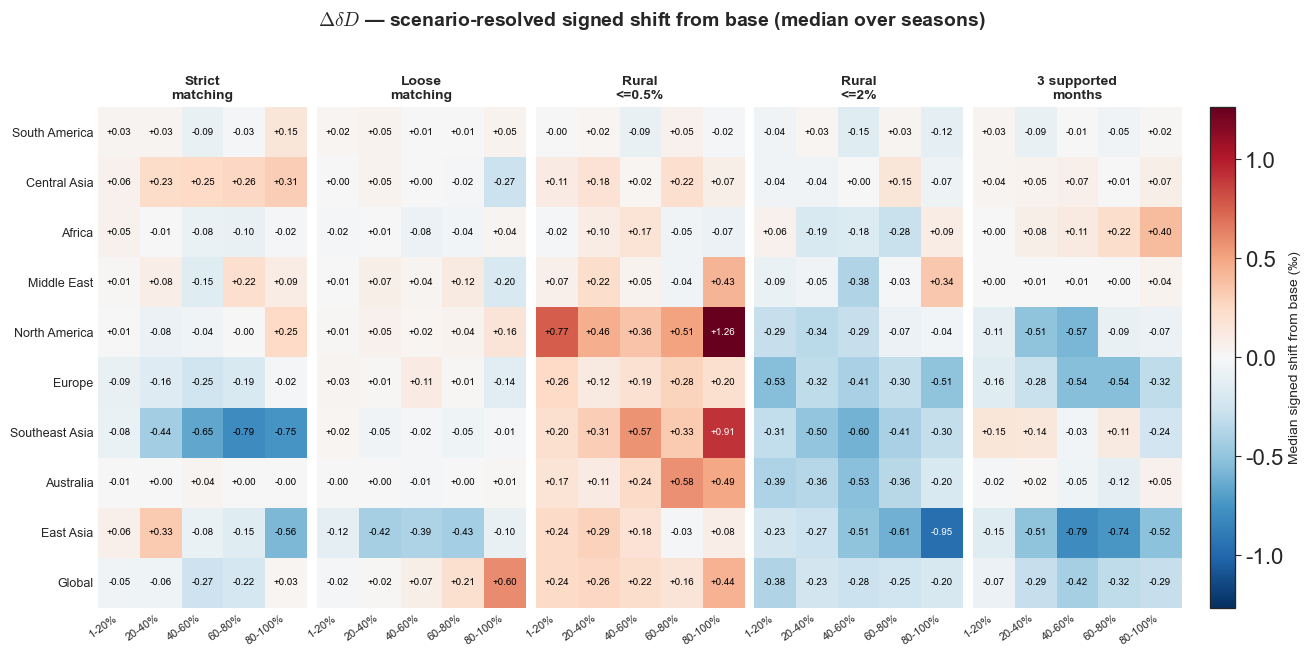

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Fig4_sensitivity_scenario_region_bin_null_class_deltad.png
Saved: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Fig4_sensitivity_scenario_region_bin_null_class_deltad.pdf


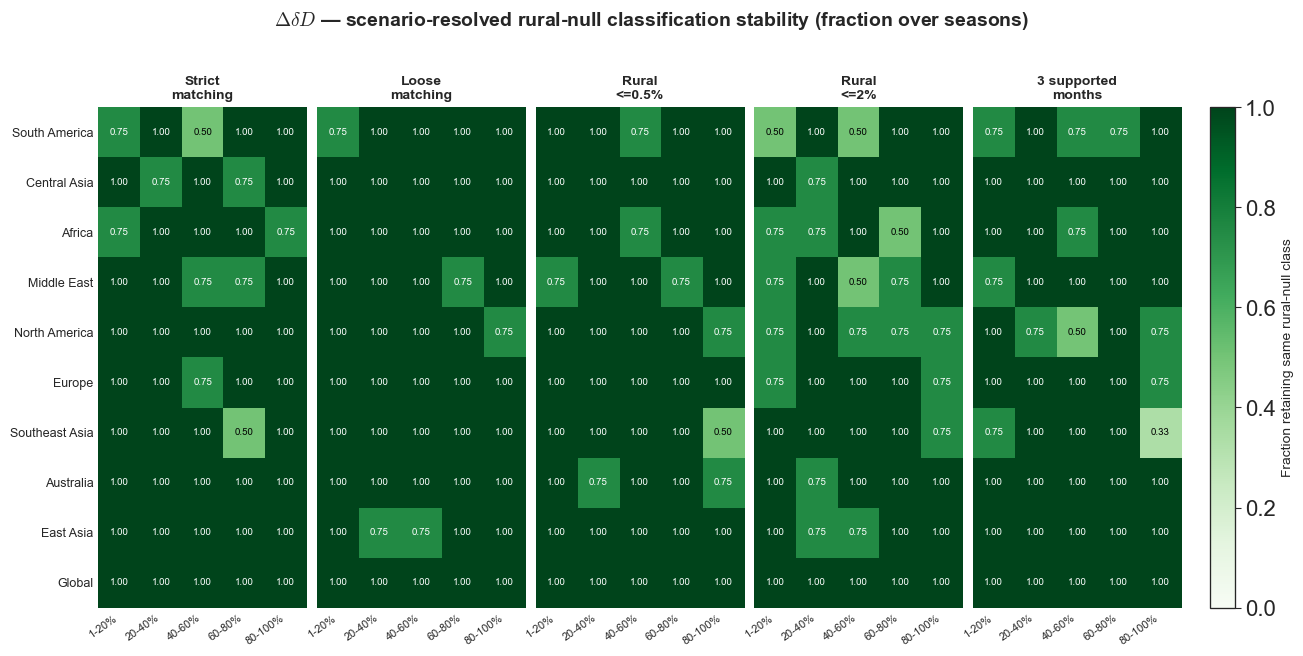

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Supplement_Figure_2_Regional_sensitivity_h2o.png
Saved: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Supplement_Figure_2_Regional_sensitivity_h2o.pdf


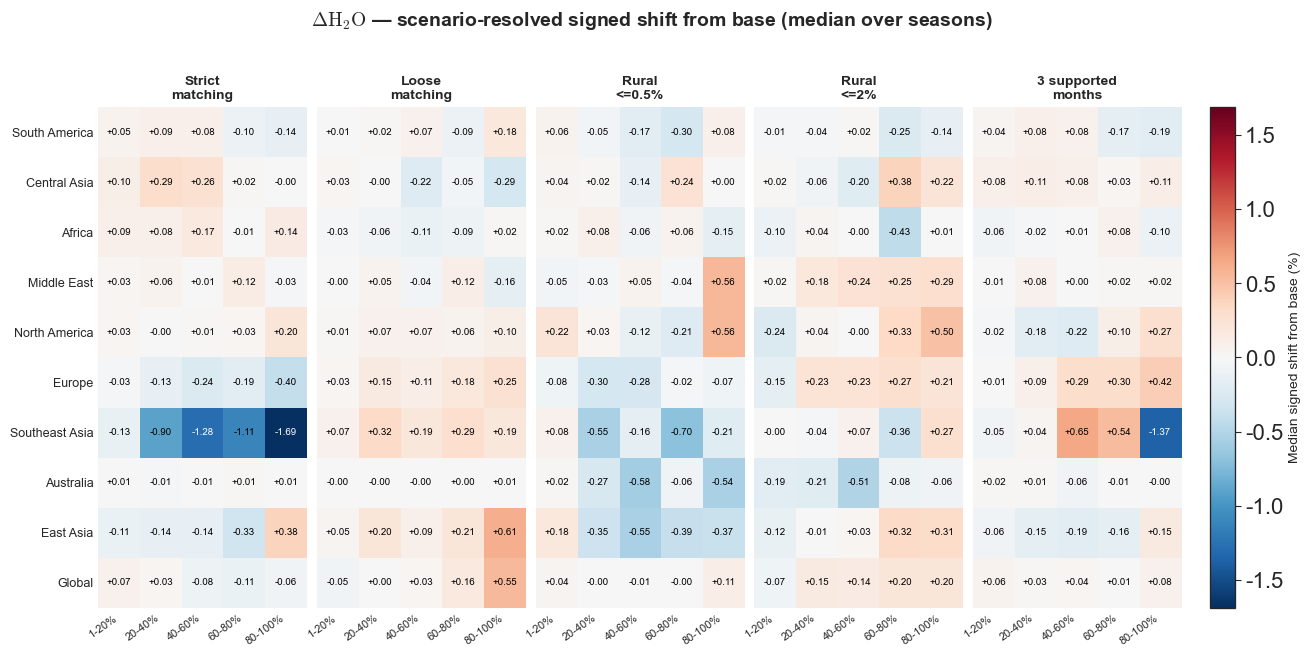

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Fig4_sensitivity_scenario_region_bin_null_class_h2o.png
Saved: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Fig4_sensitivity_scenario_region_bin_null_class_h2o.pdf


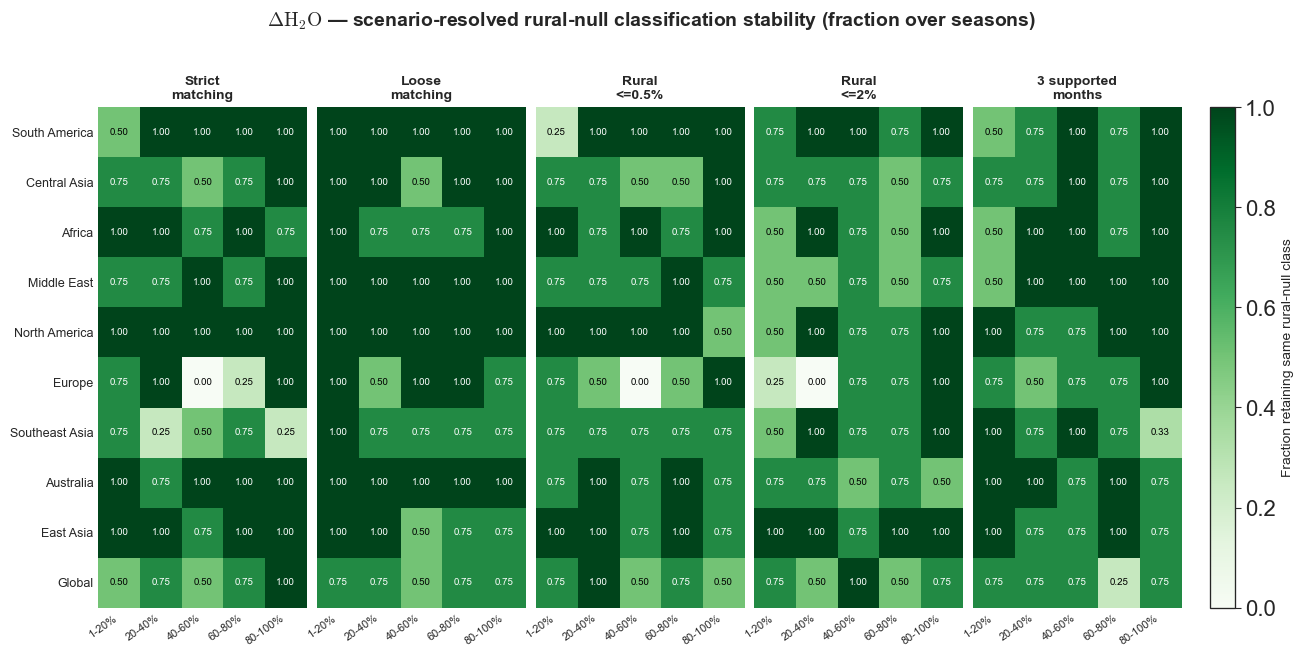

In [22]:
# =============================================================================
# FIG. 4 SENSITIVITY — SCENARIO x REGION x SETTLEMENT-BIN PLOTS
# =============================================================================
# Uses existing sensitivity cache/table.
# Does NOT rerun matching.
#
# Produces:
#   1. Scenario-resolved small-multiple heatmaps:
#        - one panel per sensitivity scenario
#        - rows = regions, including Global
#        - columns = settlement-fraction bins
#        - separate figures for dD and H2O
#
#   2. Worst-case maps:
#        - rows = regions, including Global
#        - columns = settlement-fraction bins
#        - color = worst-case signed shift, or minimum null-class retention
#        - annotation = value + scenario responsible
#
# Main outputs:
#   Fig4_sensitivity_by_scenario_region_bin_summary.csv
#   Fig4_sensitivity_worst_case_signed_shift.csv
#   Fig4_sensitivity_worst_case_null_class.csv
#   Scenario-resolved and worst-case PNG/PDF figures
# =============================================================================

import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, TwoSlopeNorm


# =============================================================================
# PATHS
# =============================================================================

FIG4_SENS_OUTPUT_DIR = str(OUTPUT_FIGURES_DIR)

SUMMARY_CACHE_PATH = str(OUTPUT_CACHE_DIR / "unused_fig4_sensitivity_summary_cache.pkl")

CELL_COMPARISON_CSV = str(OUTPUT_TABLES_DIR / "Supplement_Figure_2_cell_comparisons_vs_base.csv")

SCENARIO_REGION_BIN_SUMMARY_CSV = str(OUTPUT_TABLES_DIR / "Supplement_Figure_2_scenario_region_bin_summary.csv")

WORST_CASE_SIGNED_CSV = str(OUTPUT_TABLES_DIR / "Check_Figure4_worst_case_signed_shift.csv")

WORST_CASE_NULL_CLASS_CSV = str(OUTPUT_TABLES_DIR / "Check_Figure4_worst_case_null_class.csv")


# =============================================================================
# PLOT CONTROLS
# =============================================================================

MAKE_SCENARIO_SMALL_MULTIPLES = True
MAKE_WORST_CASE_MAPS = False

# Usually less necessary, but useful for diagnostics.
MAKE_ABSOLUTE_SHIFT_SMALL_MULTIPLES = False

# Global is intentionally included.
INCLUDE_GLOBAL = True

# Collapse over seasons within each scenario x region x bin.
# This is the compact form that retains scenarios, regions and settlement bins.
COLLAPSE_OVER_SEASONS = True


# =============================================================================
# ORDERING AND LABELS
# =============================================================================

SCENARIO_ORDER = [
    "strict_matching",
    "loose_matching",
    "rural_0p5",
    "rural_2p0",
    "strict_coverage",
]

SCENARIO_LABELS = {
    "strict_matching": "Strict\nmatching",
    "loose_matching": "Loose\nmatching",
    "rural_0p5": "Rural\n<=0.5%",
    "rural_2p0": "Rural\n<=2%",
    "strict_coverage": "3 supported\nmonths",
}

SCENARIO_SHORT_LABELS = {
    "strict_matching": "strict",
    "loose_matching": "loose",
    "rural_0p5": "r0.5",
    "rural_2p0": "r2",
    "strict_coverage": "cov3",
}

REGION_ORDER = [
    "South_America",
    "Central_Asia",
    "Africa",
    "Middle_East",
    "North_America",
    "Europe",
    "Southeast_Asia",
    "Australia",
    "East_Asia",
    "Global",
]

REGION_LABELS = {
    "South_America": "South America",
    "Central_Asia": "Central Asia",
    "Africa": "Africa",
    "Middle_East": "Middle East",
    "North_America": "North America",
    "Europe": "Europe",
    "Southeast_Asia": "Southeast Asia",
    "Australia": "Australia",
    "East_Asia": "East Asia",
    "Global": "Global",
}

VARIABLE_LABELS = {
    "deltad": r"$\Delta\delta D$",
    "h2o": r"$\Delta \mathrm{H_2O}$",
}

VARIABLE_UNITS = {
    "deltad": "‰",
    "h2o": "%",
}


# =============================================================================
# LOAD AND CLEAN
# =============================================================================

def load_fig4_cell_comparison_table():
    try:
        return cell_comparison_df.copy()
    except NameError:
        path = Path(CELL_COMPARISON_CSV)
        if not path.exists():
            raise FileNotFoundError(f"Run the preceding scenario-computation cell first: {path}")
        return pd.read_csv(path)


def coerce_bool_series(s):
    """
    Convert bool-like columns loaded from either pickle or CSV into bool/NaN.
    """
    if pd.api.types.is_bool_dtype(s):
        return s

    if pd.api.types.is_numeric_dtype(s):
        return s.map({1: True, 0: False}).astype("object")

    return (
        s.astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "false": False,
            "1": True,
            "0": False,
            "yes": True,
            "no": False,
            "nan": np.nan,
            "none": np.nan,
            "": np.nan,
        })
    )


def clean_cell_comparison_table(df):
    """
    Make sure numeric and bool columns have usable dtypes.
    """
    df = df.copy()

    numeric_cols = [
        "urban_min",
        "urban_max",
        "obs_n_base",
        "obs_n_scenario",
        "obs_mean_base",
        "obs_mean_scenario",
        "obs_mean_shift",
        "obs_mean_abs_shift",
        "obs_median_base",
        "obs_median_scenario",
        "obs_median_shift",
        "obs_median_abs_shift",
        "null_corrected_mean_base",
        "null_corrected_mean_scenario",
        "null_corrected_mean_shift",
        "null_corrected_mean_abs_shift",
    ]

    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    bool_cols = [
        "same_obs_sign",
        "same_null_corrected_sign",
        "null_class_comparable",
        "same_null_class",
        "same_outside_null_flag",
        "outside_null_base",
        "outside_null_scenario",
    ]

    for col in bool_cols:
        if col in df.columns:
            df[col] = coerce_bool_series(df[col])

    return df


def mean_bool(s):
    s = coerce_bool_series(s)
    vals = s.dropna().astype(float)
    if len(vals) == 0:
        return np.nan
    return float(vals.mean())


def nanmedian_or_nan(x):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return np.nan
    return float(np.median(x))


def nanpercentile_or_nan(x, q):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return np.nan
    return float(np.percentile(x, q))


def urban_bin_label(urban_min, urban_max):
    return f"{int(float(urban_min))}-{int(float(urban_max))}%"


# =============================================================================
# SCENARIO x REGION x SETTLEMENT-BIN SUMMARY
# =============================================================================

def summarize_by_scenario_region_bin(
    cell_comparison_df,
    include_global=True,
):
    """
    Collapse over seasons, but retain:
        scenario x variable x region x settlement-bin

    This preserves the three key diagnostic dimensions:
        sensitivity scenario, region, and settlement fraction.
    """
    df = clean_cell_comparison_table(cell_comparison_df)

    if not include_global:
        df = df[df["region_key"] != "Global"].copy()

    # Remove base if it appears for any reason; this comparison table normally
    # contains only non-base scenarios.
    if "scenario_name" in df.columns:
        df = df[df["scenario_name"] != "base"].copy()

    rows = []

    group_cols = [
        "scenario_name",
        "scenario_label",
        "variable",
        "region_key",
        "urban_min",
        "urban_max",
    ]

    for keys, g in df.groupby(group_cols, observed=True):
        scenario_name, scenario_label, variable, region_key, urban_min, urban_max = keys

        signed_null = pd.to_numeric(g["null_corrected_mean_shift"], errors="coerce")
        abs_null = pd.to_numeric(g["null_corrected_mean_abs_shift"], errors="coerce")

        signed_obs = pd.to_numeric(g["obs_mean_shift"], errors="coerce")
        abs_obs = pd.to_numeric(g["obs_mean_abs_shift"], errors="coerce")

        signed_median = pd.to_numeric(g["obs_median_shift"], errors="coerce")
        abs_median = pd.to_numeric(g["obs_median_abs_shift"], errors="coerce")

        comparable = coerce_bool_series(g["null_class_comparable"]) == True
        g_null = g[comparable].copy()

        row = {
            "scenario_name": scenario_name,
            "scenario_label": scenario_label,
            "scenario_short": SCENARIO_SHORT_LABELS.get(
                str(scenario_name),
                str(scenario_name)[:6],
            ),
            "variable": variable,
            "region_key": region_key,
            "region_label": REGION_LABELS.get(region_key, region_key),
            "urban_min": float(urban_min),
            "urban_max": float(urban_max),
            "urban_bin_label": urban_bin_label(urban_min, urban_max),

            # Number of season-cells summarized.
            "n_cells": int(len(g)),
            "n_seasons": int(g["season"].nunique()) if "season" in g.columns else int(len(g)),
            "n_null_comparable_cells": int(len(g_null)),

            # Main quantity: shift in observed mean after subtracting
            # rural-rural null center.
            "median_signed_shift_null_corrected_mean": nanmedian_or_nan(signed_null),
            "median_abs_shift_null_corrected_mean": nanmedian_or_nan(abs_null),
            "p90_abs_shift_null_corrected_mean": nanpercentile_or_nan(abs_null, 90),

            # Raw observed mean shift, without null correction.
            "median_signed_shift_obs_mean": nanmedian_or_nan(signed_obs),
            "median_abs_shift_obs_mean": nanmedian_or_nan(abs_obs),
            "p90_abs_shift_obs_mean": nanpercentile_or_nan(abs_obs, 90),

            # Median anomaly shift, useful as an additional distribution-center check.
            "median_signed_shift_obs_median": nanmedian_or_nan(signed_median),
            "median_abs_shift_obs_median": nanmedian_or_nan(abs_median),

            # Classification stability.
            "same_obs_sign_fraction": mean_bool(g["same_obs_sign"]),
            "same_null_corrected_sign_fraction": mean_bool(g["same_null_corrected_sign"]),
            "same_outside_null_flag_fraction": mean_bool(g["same_outside_null_flag"]),
            "base_outside_null_fraction": mean_bool(g["outside_null_base"]),
            "scenario_outside_null_fraction": mean_bool(g["outside_null_scenario"]),
        }

        if len(g_null) > 0:
            row["same_null_class_fraction"] = mean_bool(g_null["same_null_class"])
        else:
            row["same_null_class_fraction"] = np.nan

        rows.append(row)

    out = pd.DataFrame(rows)

    # Stable ordering.
    scenario_order = [s for s in SCENARIO_ORDER if s in out["scenario_name"].unique()]
    scenario_extra = [
        s for s in out["scenario_name"].unique()
        if s not in scenario_order
    ]
    scenario_order = scenario_order + sorted(scenario_extra)

    region_order = [r for r in REGION_ORDER if r in out["region_key"].unique()]
    region_extra = [
        r for r in out["region_key"].unique()
        if r not in region_order
    ]
    region_order = region_order + sorted(region_extra)

    out["scenario_name"] = pd.Categorical(
        out["scenario_name"],
        categories=scenario_order,
        ordered=True,
    )
    out["region_key"] = pd.Categorical(
        out["region_key"],
        categories=region_order,
        ordered=True,
    )

    out = out.sort_values(
        ["variable", "scenario_name", "region_key", "urban_min", "urban_max"]
    ).reset_index(drop=True)

    return out


# =============================================================================
# PIVOT HELPERS
# =============================================================================

def available_scenarios(summary_df):
    vals = [str(v) for v in summary_df["scenario_name"].dropna().unique()]
    ordered = [s for s in SCENARIO_ORDER if s in vals]
    extra = [s for s in vals if s not in ordered]
    return ordered + sorted(extra)


def available_regions(summary_df):
    vals = [str(v) for v in summary_df["region_key"].dropna().unique()]
    ordered = [r for r in REGION_ORDER if r in vals]
    extra = [r for r in vals if r not in ordered]
    return ordered + sorted(extra)


def available_bins(summary_df):
    bins = (
        summary_df[["urban_bin_label", "urban_min"]]
        .drop_duplicates()
        .sort_values("urban_min")
        ["urban_bin_label"]
        .tolist()
    )
    return bins


def pivot_scenario_region_bin(summary_df, variable, scenario_name, metric):
    sub = summary_df[
        (summary_df["variable"] == variable) &
        (summary_df["scenario_name"].astype(str) == str(scenario_name))
    ].copy()

    pivot = sub.pivot_table(
        index="region_key",
        columns="urban_bin_label",
        values=metric,
        aggfunc="mean",
        observed=False,
    )

    pivot = pivot.reindex(
        index=available_regions(summary_df),
        columns=available_bins(summary_df),
    )

    return pivot


def values_for_variable_metric(summary_df, variable, metric):
    vals = summary_df[summary_df["variable"] == variable][metric].values
    vals = pd.to_numeric(pd.Series(vals), errors="coerce").values.astype(float)
    return vals[np.isfinite(vals)]


# =============================================================================
# SCENARIO-RESOLVED SMALL MULTIPLES
# =============================================================================

def plot_scenario_small_multiples(
    summary_df,
    variable,
    metric,
    output_stem,
    title,
    cbar_label,
    center_zero=False,
    vmin=None,
    vmax=None,
    cmap=None,
    value_fmt="{:.2f}",
):
    """
    One figure per variable and metric:
        panels = sensitivity scenarios
        rows = regions, including Global
        columns = settlement bins
    """
    scenarios = available_scenarios(summary_df)
    regions = available_regions(summary_df)
    bins = available_bins(summary_df)

    vals = values_for_variable_metric(summary_df, variable, metric)
    if len(vals) == 0:
        print(f"No finite values for {variable} / {metric}; skipping.")
        return

    if center_zero:
        max_abs = float(np.nanmax(np.abs(vals)))
        if max_abs == 0:
            max_abs = 1.0
        vmin = -max_abs if vmin is None else vmin
        vmax = max_abs if vmax is None else vmax
        norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)
        cmap = "RdBu_r" if cmap is None else cmap
    else:
        vmin = float(np.nanmin(vals)) if vmin is None else vmin
        vmax = float(np.nanmax(vals)) if vmax is None else vmax
        norm = Normalize(vmin=vmin, vmax=vmax)
        cmap = "viridis" if cmap is None else cmap

    n_scen = len(scenarios)
    n_regions = len(regions)

    fig_width = max(13.5, 2.55 * n_scen + 2.0)
    fig_height = max(5.2, 0.46 * n_regions + 1.9)

    fig, axes = plt.subplots(
        1,
        n_scen,
        figsize=(fig_width, fig_height),
        sharey=True,
        gridspec_kw={"wspace": 0.05},
    )

    if n_scen == 1:
        axes = np.array([axes])

    im = None

    for ax_i, (ax, scenario_name) in enumerate(zip(axes, scenarios)):
        pivot = pivot_scenario_region_bin(
            summary_df=summary_df,
            variable=variable,
            scenario_name=scenario_name,
            metric=metric,
        )

        data = pivot.values.astype(float)

        im = ax.imshow(
            data,
            aspect="auto",
            cmap=cmap,
            norm=norm,
            interpolation="nearest",
        )

        ax.set_title(
            SCENARIO_LABELS.get(str(scenario_name), str(scenario_name)),
            fontsize=10,
            fontweight="bold",
        )

        ax.set_xticks(np.arange(len(bins)))
        ax.set_xticklabels(bins, rotation=35, ha="right", fontsize=8)

        ax.set_yticks(np.arange(len(regions)))
        if ax_i == 0:
            ax.set_yticklabels(
                [REGION_LABELS.get(str(r), str(r)) for r in regions],
                fontsize=9,
            )
        else:
            ax.tick_params(axis="y", labelleft=False)

        # Annotate values.
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                val = data[i, j]
                if not np.isfinite(val):
                    txt = "NA"
                    color = "black"
                else:
                    txt = value_fmt.format(val)

                    if center_zero:
                        color = "white" if abs(val) > 0.70 * max(abs(vmin), abs(vmax)) else "black"
                    else:
                        # For Greens/viridis-like scales, use white on dark cells.
                        denom = vmax - vmin if vmax > vmin else 1.0
                        scaled = (val - vmin) / denom
                        color = "white" if scaled > 0.72 else "black"

                ax.text(
                    j,
                    i,
                    txt,
                    ha="center",
                    va="center",
                    fontsize=7,
                    color=color,
                )

        ax.tick_params(axis="both", length=0)
        for spine in ax.spines.values():
            spine.set_visible(False)

    cbar = fig.colorbar(
        im,
        ax=axes.ravel().tolist(),
        orientation="vertical",
        fraction=0.028,
        pad=0.025,
    )
    cbar.set_label(cbar_label, fontsize=10)

    fig.suptitle(
        f"{VARIABLE_LABELS[variable]} — {title}",
        fontsize=14,
        fontweight="bold",
        y=1.03,
    )

    png_path = output_stem + ".png"
    pdf_path = output_stem + ".pdf"

    fig.savefig(png_path, dpi=450, bbox_inches="tight", facecolor="white")
    fig.savefig(pdf_path, bbox_inches="tight", facecolor="white")

    print(f"Saved: {png_path}")
    print(f"Saved: {pdf_path}")

    plt.show()


# =============================================================================
# WORST-CASE TABLES
# =============================================================================

def build_worst_case_signed_shift_table(summary_df):
    """
    For each variable x region x settlement bin, identify the scenario producing
    the largest absolute signed shift in the null-corrected observed mean.

    Color should usually represent signed shift; absolute value determines
    which scenario wins.
    """
    rows = []

    group_cols = ["variable", "region_key", "urban_min", "urban_max"]

    for keys, g in summary_df.groupby(group_cols, observed=True):
        variable, region_key, urban_min, urban_max = keys

        vals = pd.to_numeric(
            g["median_signed_shift_null_corrected_mean"],
            errors="coerce",
        )

        valid = np.isfinite(vals.values)
        if not np.any(valid):
            continue

        g_valid = g.loc[valid].copy()
        vals_valid = vals.loc[g_valid.index]

        idx = np.abs(vals_valid).idxmax()
        best = g_valid.loc[idx]

        rows.append({
            "variable": variable,
            "region_key": region_key,
            "region_label": REGION_LABELS.get(str(region_key), str(region_key)),
            "urban_min": float(urban_min),
            "urban_max": float(urban_max),
            "urban_bin_label": urban_bin_label(urban_min, urban_max),

            "worst_scenario_name": str(best["scenario_name"]),
            "worst_scenario_label": str(best["scenario_label"]),
            "worst_scenario_short": SCENARIO_SHORT_LABELS.get(
                str(best["scenario_name"]),
                str(best["scenario_name"])[:6],
            ),

            "worst_signed_shift_null_corrected_mean": float(
                best["median_signed_shift_null_corrected_mean"]
            ),
            "worst_abs_shift_null_corrected_mean": float(
                abs(best["median_signed_shift_null_corrected_mean"])
            ),

            "n_cells_for_worst_scenario": int(best["n_cells"]),
            "n_null_comparable_cells_for_worst_scenario": int(
                best["n_null_comparable_cells"]
            ),
        })

    out = pd.DataFrame(rows)
    out["region_key"] = pd.Categorical(
        out["region_key"],
        categories=available_regions(summary_df),
        ordered=True,
    )
    out = out.sort_values(
        ["variable", "region_key", "urban_min", "urban_max"]
    ).reset_index(drop=True)

    return out


def build_worst_case_null_class_table(summary_df):
    """
    For each variable x region x settlement bin, identify the scenario producing
    the lowest same-null-class fraction.
    """
    rows = []

    group_cols = ["variable", "region_key", "urban_min", "urban_max"]

    for keys, g in summary_df.groupby(group_cols, observed=True):
        variable, region_key, urban_min, urban_max = keys

        vals = pd.to_numeric(
            g["same_null_class_fraction"],
            errors="coerce",
        )

        valid = np.isfinite(vals.values)
        if not np.any(valid):
            continue

        g_valid = g.loc[valid].copy()
        vals_valid = vals.loc[g_valid.index]

        idx = vals_valid.idxmin()
        best = g_valid.loc[idx]

        rows.append({
            "variable": variable,
            "region_key": region_key,
            "region_label": REGION_LABELS.get(str(region_key), str(region_key)),
            "urban_min": float(urban_min),
            "urban_max": float(urban_max),
            "urban_bin_label": urban_bin_label(urban_min, urban_max),

            "worst_scenario_name": str(best["scenario_name"]),
            "worst_scenario_label": str(best["scenario_label"]),
            "worst_scenario_short": SCENARIO_SHORT_LABELS.get(
                str(best["scenario_name"]),
                str(best["scenario_name"])[:6],
            ),

            "min_same_null_class_fraction": float(best["same_null_class_fraction"]),
            "n_cells_for_worst_scenario": int(best["n_cells"]),
            "n_null_comparable_cells_for_worst_scenario": int(
                best["n_null_comparable_cells"]
            ),
        })

    out = pd.DataFrame(rows)
    out["region_key"] = pd.Categorical(
        out["region_key"],
        categories=available_regions(summary_df),
        ordered=True,
    )
    out = out.sort_values(
        ["variable", "region_key", "urban_min", "urban_max"]
    ).reset_index(drop=True)

    return out


# =============================================================================
# WORST-CASE PLOTTING
# =============================================================================

def pivot_worst_case_value(worst_df, variable, value_col):
    sub = worst_df[worst_df["variable"] == variable].copy()

    pivot = sub.pivot_table(
        index="region_key",
        columns="urban_bin_label",
        values=value_col,
        aggfunc="mean",
        observed=False,
    )

    region_order = [r for r in REGION_ORDER if r in pivot.index]
    extra_regions = [r for r in pivot.index if r not in region_order]
    region_order = region_order + sorted(extra_regions)

    bin_order = (
        sub[["urban_bin_label", "urban_min"]]
        .drop_duplicates()
        .sort_values("urban_min")
        ["urban_bin_label"]
        .tolist()
    )

    return pivot.reindex(index=region_order, columns=bin_order)


def pivot_worst_case_scenario(worst_df, variable):
    sub = worst_df[worst_df["variable"] == variable].copy()

    pivot = sub.pivot_table(
        index="region_key",
        columns="urban_bin_label",
        values="worst_scenario_short",
        aggfunc="first",
        observed=False,
    )

    region_order = [r for r in REGION_ORDER if r in pivot.index]
    extra_regions = [r for r in pivot.index if r not in region_order]
    region_order = region_order + sorted(extra_regions)

    bin_order = (
        sub[["urban_bin_label", "urban_min"]]
        .drop_duplicates()
        .sort_values("urban_min")
        ["urban_bin_label"]
        .tolist()
    )

    return pivot.reindex(index=region_order, columns=bin_order)


def plot_worst_case_heatmap(
    worst_df,
    variable,
    value_col,
    output_stem,
    title,
    cbar_label,
    center_zero=False,
    vmin=None,
    vmax=None,
    cmap=None,
    value_fmt="{:.2f}",
):
    """
    Plot one worst-case map for one variable.

    Each tile annotation has:
        value
        scenario short label
    """
    value_pivot = pivot_worst_case_value(worst_df, variable, value_col)
    scenario_pivot = pivot_worst_case_scenario(worst_df, variable)

    data = value_pivot.values.astype(float)
    vals = data[np.isfinite(data)]

    if len(vals) == 0:
        print(f"No finite worst-case values for {variable} / {value_col}; skipping.")
        return

    if center_zero:
        max_abs = float(np.nanmax(np.abs(vals)))
        if max_abs == 0:
            max_abs = 1.0
        vmin = -max_abs if vmin is None else vmin
        vmax = max_abs if vmax is None else vmax
        norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)
        cmap = "RdBu_r" if cmap is None else cmap
    else:
        vmin = float(np.nanmin(vals)) if vmin is None else vmin
        vmax = float(np.nanmax(vals)) if vmax is None else vmax
        norm = Normalize(vmin=vmin, vmax=vmax)
        cmap = "viridis" if cmap is None else cmap

    n_regions = len(value_pivot.index)
    fig_height = max(5.2, 0.48 * n_regions + 1.8)

    fig, ax = plt.subplots(
        1,
        1,
        figsize=(7.5, fig_height),
    )

    im = ax.imshow(
        data,
        aspect="auto",
        cmap=cmap,
        norm=norm,
        interpolation="nearest",
    )

    ax.set_title(
        f"{VARIABLE_LABELS[variable]} — {title}",
        fontsize=13,
        fontweight="bold",
    )

    ax.set_xticks(np.arange(len(value_pivot.columns)))
    ax.set_xticklabels(value_pivot.columns.tolist(), rotation=35, ha="right", fontsize=9)

    ax.set_yticks(np.arange(len(value_pivot.index)))
    ax.set_yticklabels(
        [REGION_LABELS.get(str(r), str(r)) for r in value_pivot.index],
        fontsize=10,
    )

    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            val = data[i, j]
            scenario_short = scenario_pivot.iloc[i, j]

            if not np.isfinite(val):
                txt = "NA"
                color = "black"
            else:
                scenario_txt = "" if pd.isna(scenario_short) else str(scenario_short)
                txt = f"{value_fmt.format(val)}\n{scenario_txt}"

                if center_zero:
                    color = "white" if abs(val) > 0.70 * max(abs(vmin), abs(vmax)) else "black"
                else:
                    denom = vmax - vmin if vmax > vmin else 1.0
                    scaled = (val - vmin) / denom
                    color = "white" if scaled > 0.72 else "black"

            ax.text(
                j,
                i,
                txt,
                ha="center",
                va="center",
                fontsize=8,
                color=color,
                linespacing=0.90,
            )

    ax.tick_params(axis="both", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

    cbar = fig.colorbar(
        im,
        ax=ax,
        orientation="vertical",
        fraction=0.045,
        pad=0.025,
    )
    cbar.set_label(cbar_label, fontsize=10)

    png_path = output_stem + ".png"
    pdf_path = output_stem + ".pdf"

    fig.savefig(png_path, dpi=450, bbox_inches="tight", facecolor="white")
    fig.savefig(pdf_path, bbox_inches="tight", facecolor="white")

    print(f"Saved: {png_path}")
    print(f"Saved: {pdf_path}")

    plt.show()


# =============================================================================
# DIAGNOSTIC PRINTING
# =============================================================================

def print_largest_scenario_region_bin_shifts(summary_df, n=30):
    cols = [
        "scenario_label",
        "region_label",
        "urban_bin_label",
        "variable",
        "n_cells",
        "median_signed_shift_null_corrected_mean",
        "median_abs_shift_null_corrected_mean",
        "same_null_class_fraction",
    ]

    tmp = summary_df.copy()
    tmp = tmp.sort_values(
        "median_abs_shift_null_corrected_mean",
        ascending=False,
    )

    print("\nLargest scenario x region x settlement-bin shifts:")
    print(
        tmp[cols]
        .head(n)
        .to_string(index=False, float_format="{:.3f}".format)
    )


def print_worst_case_summaries(worst_signed_df, worst_null_df, n=20):
    print("\nWorst signed-shift cases:")
    cols_signed = [
        "variable",
        "region_label",
        "urban_bin_label",
        "worst_scenario_short",
        "worst_signed_shift_null_corrected_mean",
        "worst_abs_shift_null_corrected_mean",
    ]
    tmp_s = worst_signed_df.sort_values(
        "worst_abs_shift_null_corrected_mean",
        ascending=False,
    )
    print(
        tmp_s[cols_signed]
        .head(n)
        .to_string(index=False, float_format="{:.3f}".format)
    )

    print("\nWorst null-class-retention cases:")
    cols_null = [
        "variable",
        "region_label",
        "urban_bin_label",
        "worst_scenario_short",
        "min_same_null_class_fraction",
    ]
    tmp_n = worst_null_df.sort_values(
        "min_same_null_class_fraction",
        ascending=True,
    )
    print(
        tmp_n[cols_null]
        .head(n)
        .to_string(index=False, float_format="{:.3f}".format)
    )


# =============================================================================
# MAIN
# =============================================================================

def main():
    os.makedirs(FIG4_SENS_OUTPUT_DIR, exist_ok=True)

    comp = load_fig4_cell_comparison_table()
    comp = clean_cell_comparison_table(comp)

    scenario_region_bin_summary = summarize_by_scenario_region_bin(
        comp,
        include_global=INCLUDE_GLOBAL,
    )

    scenario_region_bin_summary.to_csv(
        SCENARIO_REGION_BIN_SUMMARY_CSV,
        index=False,
    )
    print(f"Saved scenario x region x settlement-bin summary: {SCENARIO_REGION_BIN_SUMMARY_CSV}")

    print_largest_scenario_region_bin_shifts(
        scenario_region_bin_summary,
        n=30,
    )

    # -------------------------------------------------------------------------
    # Scenario-resolved small multiples
    # -------------------------------------------------------------------------
    if MAKE_SCENARIO_SMALL_MULTIPLES:
        for variable in ["deltad", "h2o"]:
            units = VARIABLE_UNITS[variable]

            plot_scenario_small_multiples(
                summary_df=scenario_region_bin_summary,
                variable=variable,
                metric="median_signed_shift_null_corrected_mean",
                output_stem=os.path.join(
                    FIG4_SENS_OUTPUT_DIR,
                    f"Supplement_Figure_2_Regional_sensitivity_{variable}"
                ),
                title=(
                    "scenario-resolved signed shift from base "
                    "(median over seasons)"
                ),
                cbar_label=f"Median signed shift from base ({units})",
                center_zero=True,
                cmap="RdBu_r",
                value_fmt="{:+.2f}",
            )

            plot_scenario_small_multiples(
                summary_df=scenario_region_bin_summary,
                variable=variable,
                metric="same_null_class_fraction",
                output_stem=os.path.join(
                    FIG4_SENS_OUTPUT_DIR,
                    f"Fig4_sensitivity_scenario_region_bin_null_class_{variable}"
                ),
                title=(
                    "scenario-resolved rural-null classification stability "
                    "(fraction over seasons)"
                ),
                cbar_label="Fraction retaining same rural-null class",
                center_zero=False,
                vmin=0.0,
                vmax=1.0,
                cmap="Greens",
                value_fmt="{:.2f}",
            )

            if MAKE_ABSOLUTE_SHIFT_SMALL_MULTIPLES:
                plot_scenario_small_multiples(
                    summary_df=scenario_region_bin_summary,
                    variable=variable,
                    metric="median_abs_shift_null_corrected_mean",
                    output_stem=os.path.join(
                        FIG4_SENS_OUTPUT_DIR,
                        f"Fig4_sensitivity_scenario_region_bin_abs_shift_{variable}"
                    ),
                    title=(
                        "scenario-resolved absolute shift from base "
                        "(median over seasons)"
                    ),
                    cbar_label=f"Median absolute shift from base ({units})",
                    center_zero=False,
                    vmin=0.0,
                    cmap="YlOrBr",
                    value_fmt="{:.2f}",
                )

    # -------------------------------------------------------------------------
    # Worst-case compact maps
    # -------------------------------------------------------------------------
    if MAKE_WORST_CASE_MAPS:
        worst_signed = build_worst_case_signed_shift_table(
            scenario_region_bin_summary
        )
        worst_null = build_worst_case_null_class_table(
            scenario_region_bin_summary
        )

        worst_signed.to_csv(WORST_CASE_SIGNED_CSV, index=False)
        worst_null.to_csv(WORST_CASE_NULL_CLASS_CSV, index=False)

        print(f"Saved worst-case signed-shift table: {WORST_CASE_SIGNED_CSV}")
        print(f"Saved worst-case null-class table: {WORST_CASE_NULL_CLASS_CSV}")

        print_worst_case_summaries(
            worst_signed,
            worst_null,
            n=25,
        )

        for variable in ["deltad", "h2o"]:
            units = VARIABLE_UNITS[variable]

            plot_worst_case_heatmap(
                worst_df=worst_signed,
                variable=variable,
                value_col="worst_signed_shift_null_corrected_mean",
                output_stem=os.path.join(
                    FIG4_SENS_OUTPUT_DIR,
                    f"Fig4_sensitivity_worst_case_signed_shift_{variable}"
                ),
                title="worst-case signed shift across sensitivity scenarios",
                cbar_label=f"Signed shift from base ({units})",
                center_zero=True,
                cmap="RdBu_r",
                value_fmt="{:+.2f}",
            )

            plot_worst_case_heatmap(
                worst_df=worst_null,
                variable=variable,
                value_col="min_same_null_class_fraction",
                output_stem=os.path.join(
                    FIG4_SENS_OUTPUT_DIR,
                    f"Fig4_sensitivity_worst_case_null_class_{variable}"
                ),
                title="minimum rural-null-class retention across sensitivity scenarios",
                cbar_label="Minimum fraction retaining same rural-null class",
                center_zero=False,
                vmin=0.0,
                vmax=1.0,
                cmap="Greens",
                value_fmt="{:.2f}",
            )


if __name__ == "__main__":
    main()


### Supplementary Figure 2 layout

Arranges the five sensitivity scenarios into one figure with $\Delta\delta D$ and $\Delta H_2O$ in separate rows. Values are median signed shifts from the base configuration in the null-corrected urban-rural mean, summarized across seasons.


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Supplement_Figure_2_Regional_sensitivity.png
Saved: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Supplement_Figure_2_Regional_sensitivity.pdf


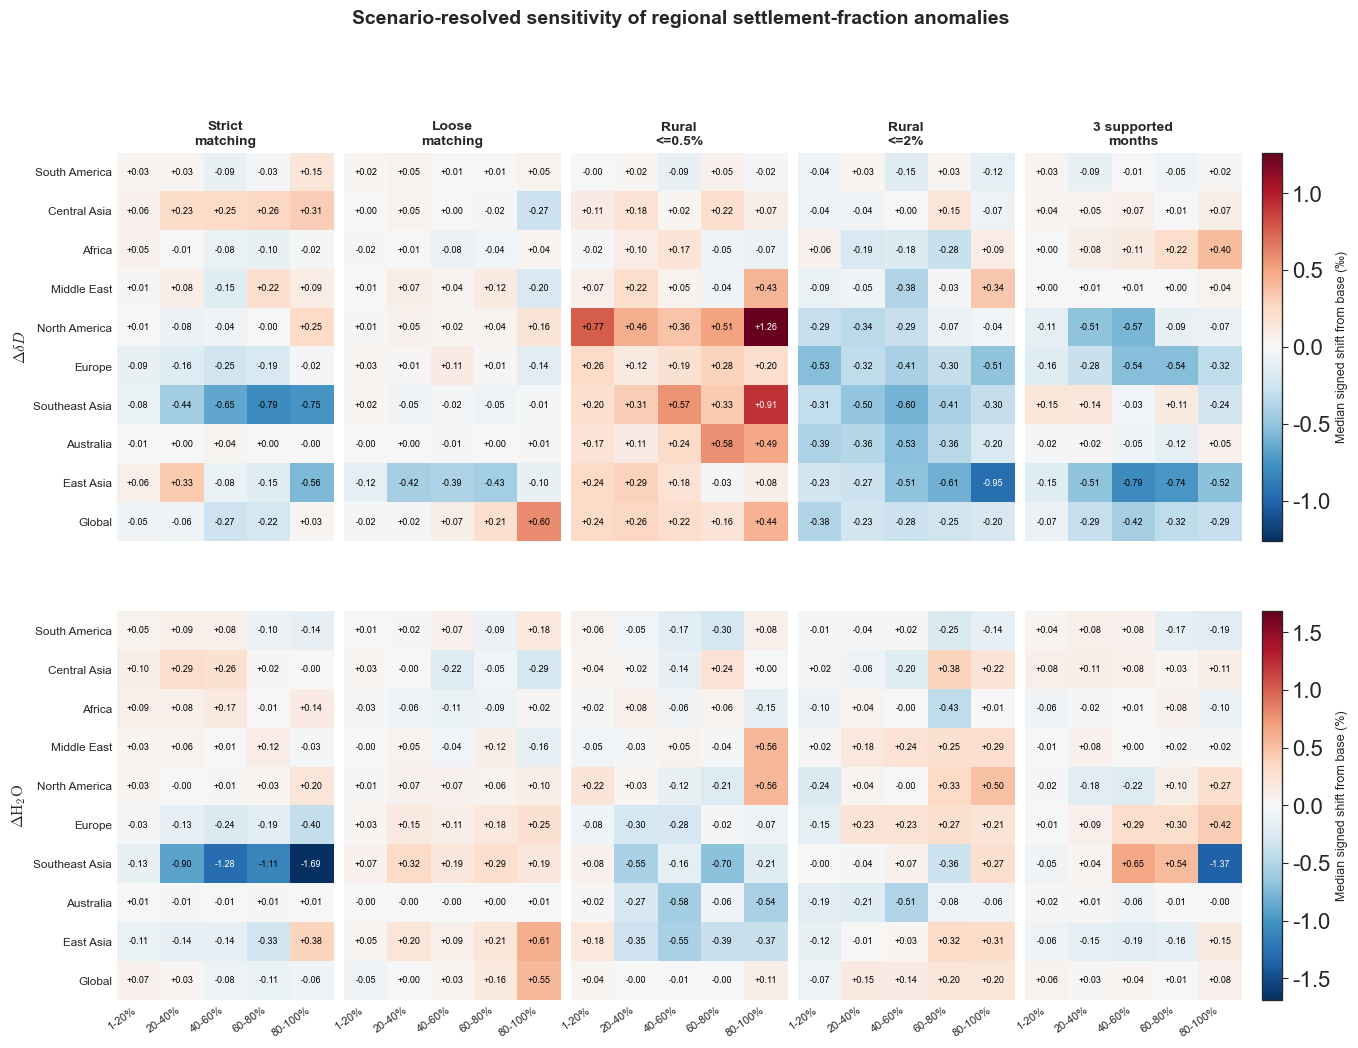

In [23]:
# Canonical combined Supplementary Figure 2.
# Uses `scenario_region_bin_summary` created by the preceding cell; no matching is rerun here.

from matplotlib.colors import TwoSlopeNorm


def plot_combined_supplement_figure_2(summary_df):
    scenarios = available_scenarios(summary_df)
    regions = available_regions(summary_df)
    bins = available_bins(summary_df)
    variables = ["deltad", "h2o"]

    n_scen = len(scenarios)
    fig_width = max(14.0, 2.55 * n_scen + 2.3)
    fig_height = max(10.0, 0.90 * len(regions) + 2.0)

    fig, axes = plt.subplots(
        2, n_scen,
        figsize=(fig_width, fig_height),
        sharex=True,
        sharey=True,
        gridspec_kw={"wspace": 0.05, "hspace": 0.18},
    )
    if n_scen == 1:
        axes = np.asarray(axes).reshape(2, 1)

    row_images = []
    for row, variable in enumerate(variables):
        vals = values_for_variable_metric(
            summary_df, variable, "median_signed_shift_null_corrected_mean"
        )
        if len(vals) == 0:
            raise RuntimeError(f"No finite values available for {variable}.")

        max_abs = float(np.nanmax(np.abs(vals)))
        if max_abs == 0:
            max_abs = 1.0
        norm = TwoSlopeNorm(vmin=-max_abs, vcenter=0.0, vmax=max_abs)
        first_im = None

        for col, scenario_name in enumerate(scenarios):
            ax = axes[row, col]
            pivot = pivot_scenario_region_bin(
                summary_df=summary_df,
                variable=variable,
                scenario_name=scenario_name,
                metric="median_signed_shift_null_corrected_mean",
            )
            data = pivot.values.astype(float)
            im = ax.imshow(
                data, aspect="auto", cmap="RdBu_r", norm=norm,
                interpolation="nearest",
            )
            if first_im is None:
                first_im = im

            if row == 0:
                ax.set_title(
                    SCENARIO_LABELS.get(str(scenario_name), str(scenario_name)),
                    fontsize=10, fontweight="bold",
                )

            ax.set_xticks(np.arange(len(bins)))
            if row == 1:
                ax.set_xticklabels(bins, rotation=35, ha="right", fontsize=8)
            else:
                ax.tick_params(axis="x", labelbottom=False)

            ax.set_yticks(np.arange(len(regions)))
            if col == 0:
                ax.set_yticklabels(
                    [REGION_LABELS.get(str(r), str(r)) for r in regions],
                    fontsize=8.5,
                )
                ax.set_ylabel(VARIABLE_LABELS[variable], fontsize=11, fontweight="bold")
            else:
                ax.tick_params(axis="y", labelleft=False)

            for ii in range(data.shape[0]):
                for jj in range(data.shape[1]):
                    val = data[ii, jj]
                    if np.isfinite(val):
                        txt = f"{val:+.2f}"
                        color = "white" if abs(val) > 0.70 * max_abs else "black"
                    else:
                        txt, color = "NA", "black"
                    ax.text(jj, ii, txt, ha="center", va="center", fontsize=6.5, color=color)

            ax.tick_params(axis="both", length=0)
            for spine in ax.spines.values():
                spine.set_visible(False)

        row_images.append(first_im)

    cbar_top = fig.colorbar(
        row_images[0], ax=axes[0, :].ravel().tolist(),
        orientation="vertical", fraction=0.018, pad=0.018,
    )
    cbar_top.set_label(
        f"Median signed shift from base ({VARIABLE_UNITS['deltad']})", fontsize=9
    )
    cbar_bottom = fig.colorbar(
        row_images[1], ax=axes[1, :].ravel().tolist(),
        orientation="vertical", fraction=0.018, pad=0.018,
    )
    cbar_bottom.set_label(
        f"Median signed shift from base ({VARIABLE_UNITS['h2o']})", fontsize=9
    )

    fig.suptitle(
        "Scenario-resolved sensitivity of regional settlement-fraction anomalies",
        fontsize=14, fontweight="bold", y=1.01,
    )

    png_path = OUTPUT_FIGURES_DIR / "Supplement_Figure_2_Regional_sensitivity.png"
    pdf_path = OUTPUT_FIGURES_DIR / "Supplement_Figure_2_Regional_sensitivity.pdf"
    fig.savefig(png_path, dpi=450, bbox_inches="tight", facecolor="white")
    fig.savefig(pdf_path, bbox_inches="tight", facecolor="white")
    print(f"Saved: {png_path}")
    print(f"Saved: {pdf_path}")
    plt.show()
    return png_path, pdf_path


scenario_region_bin_summary_for_publication = pd.read_csv(
    SCENARIO_REGION_BIN_SUMMARY_CSV
)

supplement_figure_2_outputs = plot_combined_supplement_figure_2(
    scenario_region_bin_summary_for_publication
)


### Additional robustness check — median-based regional anomalies

As an additional diagnostic, we repeat the regional matched-pair analysis using
the median rather than the mean within each region × season × settlement bin.
This analysis is not used for the numbered manuscript or Supplementary outputs;
it is retained as an optional robustness check on sensitivity to the choice of
summary statistic.


🚀 URBAN INTENSITY GRADIENT ANALYSIS WITH RURAL PLACEBO - ALL SEASONS
Seasons: ['DJF', 'MAM', 'JJA', 'SON']
Observed distributions: urban vs matched rural controls; primary statistic = MEDIAN
Null benchmark: split-sample rural parent + spatial-block-matched resampling
Control: ≤1.0%
Urban intensity bins: [(1, 20), (20, 40), (40, 60), (60, 80), (80, 100)]
Null draws per region/bin: 1000
Analysis grid: 0.05°; primary inference block: 25 km; block sensitivities: (25.0, 50.0, 100.0) km
Coverage rule: keep pixels only if supported_months ≥ 2 with count ≥ 5
Observed matching: constraint_aware | wo/replacement=False | k=25
RR-parent matching: constraint_aware | wo/replacement=True | k=25
Pair filter: |Δelev|≤50 m, |Δcoast|≤50 km, geo distance≤150 km
Plot cache: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/cache/Regional_median_check_plot_cache.pkl
Verbose title: False
Text-size preset: much_bigger; text multiplier=1.0; figure multiplier=1.0

Loading shared/static datasets for the 0.

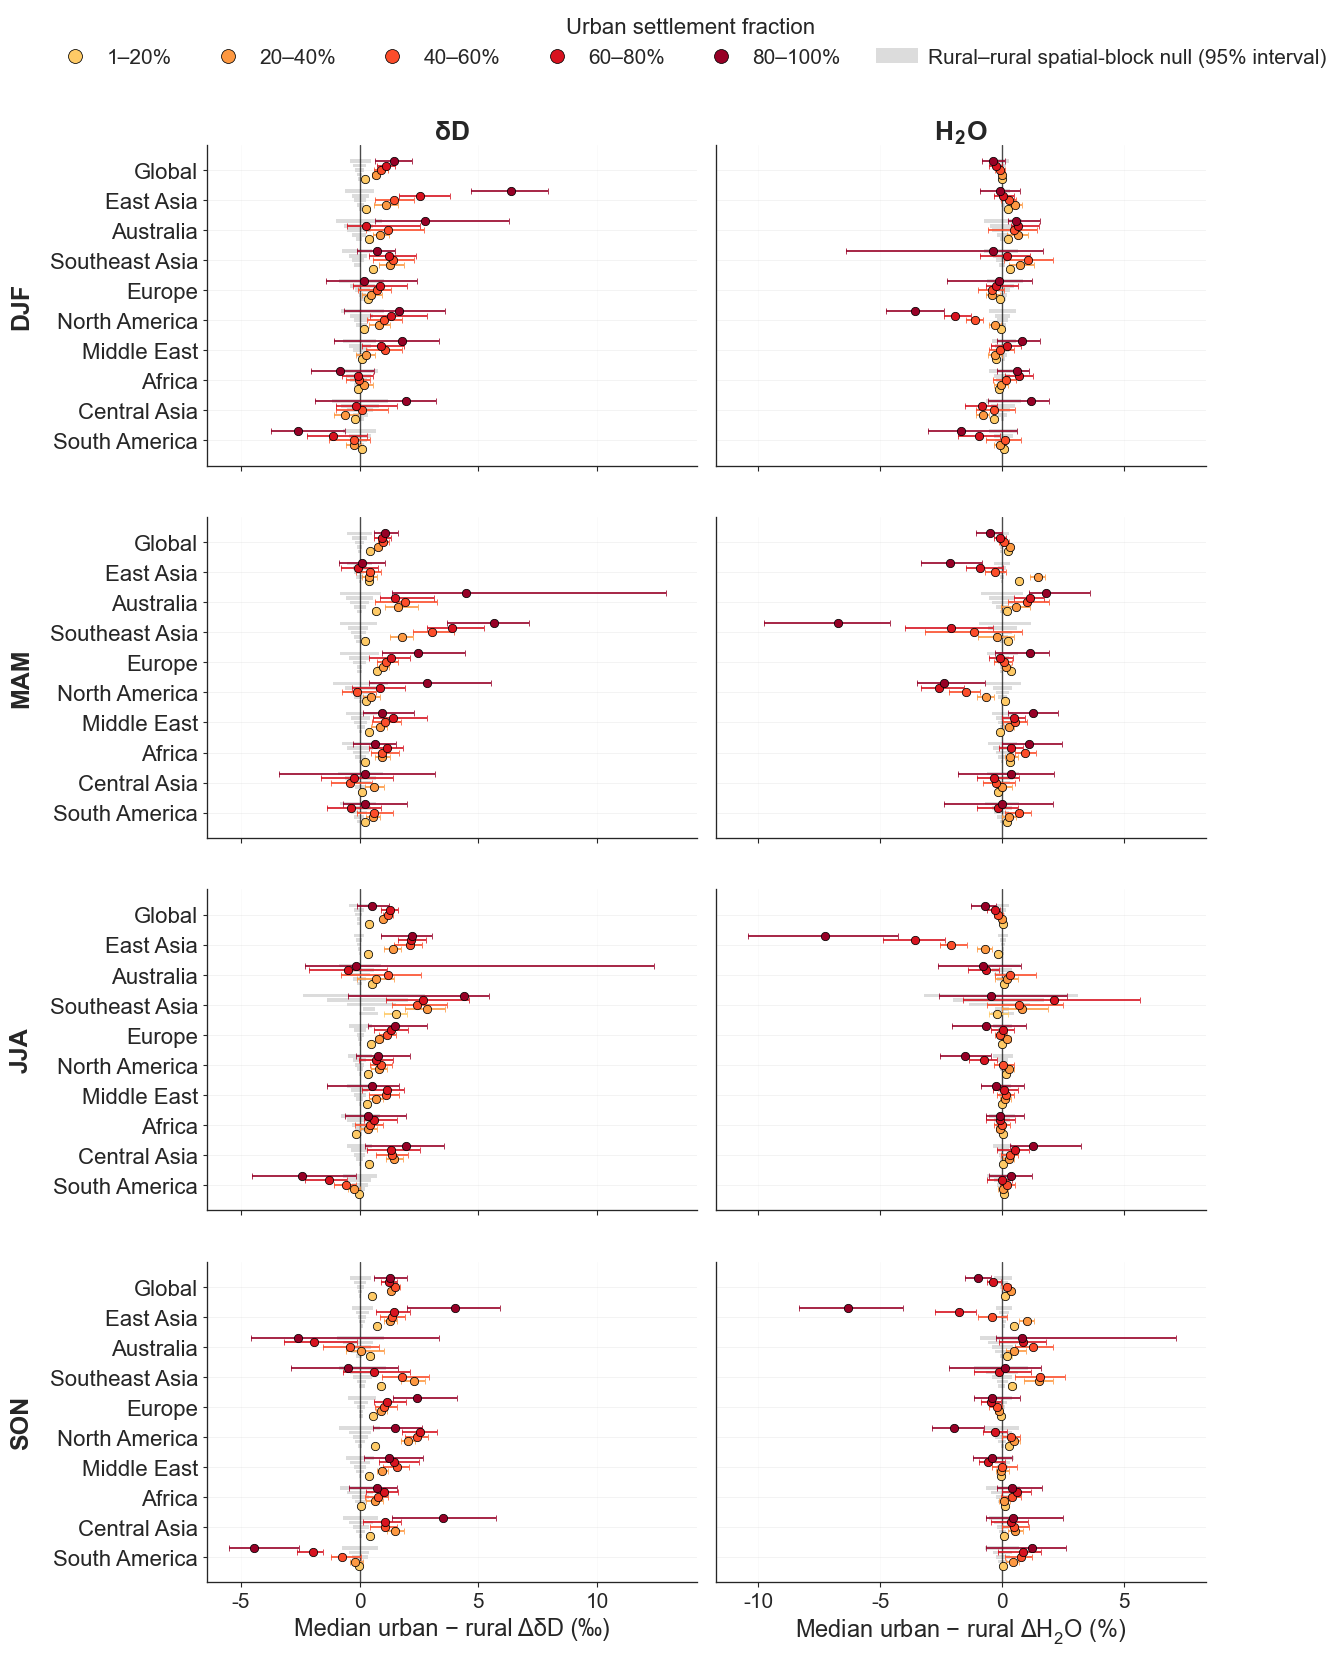


DONE


In [25]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
Reviewer robustness check: median-based regional matched-pairs analysis on the 0.05-degree TROPOMI grid.

The analysis keeps matched pairs intact and uses geographic block resampling.
"""

import os
import pickle
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray
import xarray as xr
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.ndimage import distance_transform_edt
from scipy.stats import norm, rankdata, ttest_1samp
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# =============================================================================
# REVISION PATHS
# =============================================================================

REVISION_ROOT = PROJECT_ROOT

DATA_DIR = SOURCE_DATA_DIR
FIGURES_DIR = OUTPUT_FIGURES_DIR
RESULTS_DIR = OUTPUT_TABLES_DIR
CACHE_DIR = OUTPUT_CACHE_DIR

for directory in (DATA_DIR, FIGURES_DIR, RESULTS_DIR, CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Replace only this path if the final climatology has a different filename.
TROPOMI_PATH = FILES["tropomi_climatology"]

SETTLEMENT_PATH = FILES["settlement"]
ELEVATION_PATH = FILES["elevation"]
LANDMASK_PATH = FILES["landmask"]

# The native-grid sensitivity is produced by count-weighted 2x2 aggregation
# of the existing 0.05-degree climatology. It tests sensitivity to the output
# lattice and extra spatial averaging; it is not used to claim independence.
NATIVE_GRID_DEG = 0.05

# =============================================================================
# REGION DEFINITIONS
# =============================================================================

PREDEFINED_REGIONS = {
    'Global': {
        'lat_range': (-90, 90),
        'lon_range': (-180, 180),
        'description': 'Global'
    },

    'Europe': {
        'lat_range': (35, 65),
        'lon_range': (-10, 40),
        'description': 'Europe'
    },
    'North_America': {
        'lat_range': (35, 65),
        'lon_range': (-130, -70),
        'description': 'North America'
    },
    'East_Asia': {
        'lat_range': (25, 50),
        'lon_range': (100, 145),
        'description': 'East Asia'
    },
    'South_Asia': {
        'lat_range': (5, 35),
        'lon_range': (65, 95),
        'description': 'South Asia'
    },
    'Australia': {
        'lat_range': (-45, -10),
        'lon_range': (110, 155),
        'description': 'Australia'
    },
    'South_America': {
        'lat_range': (-55, 15),
        'lon_range': (-80, -35),
        'description': 'South America'
    },
    'Africa': {
        'lat_range': (-35, 35),
        'lon_range': (-20, 55),
        'description': 'Africa'
    },

    'London_Paris_Region': {
        'lat_range': (48, 54),
        'lon_range': (-5, 8),
        'description': 'London-Paris-Benelux'
    },
    'Greater_Moscow_Region': {
        'lat_range': (50, 62),
        'lon_range': (30, 45),
        'description': 'Greater Moscow'
    },
    'Madrid_Iberia': {
        'lat_range': (36, 44),
        'lon_range': (-10, 4),
        'description': 'Iberian Peninsula'
    },
    'Mediterranean_South': {
        'lat_range': (35, 45),
        'lon_range': (5, 20),
        'description': 'Mediterranean South'
    },
    'Baltic_Scandinavia': {
        'lat_range': (54, 65),
        'lon_range': (10, 30),
        'description': 'Baltic-Scandinavia'
    },

    'New_England_Northeast': {
        'lat_range': (38, 48),
        'lon_range': (-80, -67),
        'description': 'New England-Northeast'
    },
    'Great_Lakes': {
        'lat_range': (40, 50),
        'lon_range': (-90, -75),
        'description': 'Great Lakes'
    },
    'Pacific_Northwest': {
        'lat_range': (42, 52),
        'lon_range': (-125, -115),
        'description': 'Pacific Northwest'
    },
    'Southern_California': {
        'lat_range': (32, 42),
        'lon_range': (-122, -112),
        'description': 'Southern California'
    },
    'Texas_Triangle': {
        'lat_range': (27, 37),
        'lon_range': (-100, -90),
        'description': 'Texas Triangle'
    },
    'Canadian_Prairies': {
        'lat_range': (49, 58),
        'lon_range': (-120, -95),
        'description': 'Canadian Prairies'
    },
    'Mexico_City_Central': {
        'lat_range': (15, 25),
        'lon_range': (-105, -95),
        'description': 'Central Mexico'
    },

    'Beijing_North_China': {
        'lat_range': (32, 45),
        'lon_range': (110, 125),
        'description': 'North China Plain'
    },
    'Yangtze_River_Delta': {
        'lat_range': (28, 35),
        'lon_range': (115, 125),
        'description': 'Yangtze River Delta'
    },
    'Pearl_River_Delta': {
        'lat_range': (20, 26),
        'lon_range': (110, 118),
        'description': 'Pearl River Delta'
    },
    'Tokyo_Kanto': {
        'lat_range': (33, 40),
        'lon_range': (135, 145),
        'description': 'Tokyo-Kanto'
    },
    'Korean_Peninsula': {
        'lat_range': (34, 42),
        'lon_range': (124, 132),
        'description': 'Korean Peninsula'
    },
    'Southeast_Asia_Mainland': {
        'lat_range': (10, 22),
        'lon_range': (95, 110),
        'description': 'SE Asia Mainland'
    },
    'Java_Indonesia': {
        'lat_range': (-8, 0),
        'lon_range': (105, 115),
        'description': 'Java'
    },
    'Mumbai_Western_India': {
        'lat_range': (15, 25),
        'lon_range': (70, 80),
        'description': 'Western India'
    },
    'Delhi_North_India': {
        'lat_range': (25, 32),
        'lon_range': (74, 82),
        'description': 'North India'
    },
    'Middle_East_Gulf': {
        'lat_range': (22, 32),
        'lon_range': (45, 58),
        'description': 'Middle East Gulf'
    },

    'Lagos_West_Africa': {
        'lat_range': (4, 14),
        'lon_range': (-5, 10),
        'description': 'Gulf of Guinea'
    },
    'Cairo_Nile_Delta': {
        'lat_range': (27, 33),
        'lon_range': (29, 35),
        'description': 'Nile Delta'
    },
    'South_Africa_Highveld': {
        'lat_range': (-32, -22),
        'lon_range': (24, 32),
        'description': 'South Africa Highveld'
    },
    'East_Africa_Lakes': {
        'lat_range': (-5, 5),
        'lon_range': (30, 42),
        'description': 'East Africa'
    },

    'Sao_Paulo_Southeast_Brazil': {
        'lat_range': (-25, -15),
        'lon_range': (-50, -40),
        'description': 'Southeast Brazil'
    },
    'Buenos_Aires_Pampas': {
        'lat_range': (-38, -28),
        'lon_range': (-65, -55),
        'description': 'Pampas'
    },
    'Andean_Colombia': {
        'lat_range': (0, 10),
        'lon_range': (-78, -68),
        'description': 'Andean Colombia'
    },
    'Lima_Pacific_Coast': {
        'lat_range': (-15, -5),
        'lon_range': (-82, -72),
        'description': 'Pacific Coast Peru'
    },

    'Australian_East_Coast': {
        'lat_range': (-38, -25),
        'lon_range': (145, 155),
        'description': 'Australian East Coast'
    },
    'New_Zealand': {
        'lat_range': (-48, -34),
        'lon_range': (165, 180),
        'description': 'New Zealand'
    },
    'Central_Asia': {
        'lat_range': (35, 55),
        'lon_range': (45, 85),
        'description': 'Central Asia'
    },

    'Southeast_Asia': {
        'lat_range': (-10, 25),
        'lon_range': (95, 140),
        'description': 'Southeast Asia'
    },

    'Middle_East': {
        'lat_range': (12, 42),
        'lon_range': (25, 63),
        'description': 'Middle East'
    },
}

FEATURES_MATCH = ['latitude', 'longitude', 'elevation', 'dist_to_coast']

# Single source of truth for the urban-fraction colormap.
# Try plt.cm.OrRd, plt.cm.copper, or plt.cm.magma_r if you want to A/B test.
URBAN_CMAP = plt.cm.YlOrRd
URBAN_CMAP_RANGE = (0.30, 0.95)

# Null-band styling - single source of truth so the legend matches the panels.
NULL_BAND_FACECOLOR = '0.86'
NULL_BAND_ALPHA = 0.95

# Cache schema version - bump if results_nested layout or stored config layout changes.
PLOT_CACHE_VERSION = 6


# =============================================================================
# PLOT READABILITY CONTROLS
# =============================================================================
# Controls most visible text, marker, tick, legend, spacing, and figure-size
# choices for the seasonal two-variable grid figure.
#
# Options:
#   "base"         = original figure
#   "bigger"       = modestly larger, good for manuscript drafts
#   "much_bigger"  = larger labels/ticks, good for journal review PDFs
#   "poster"       = very large labels/ticks for talks/posters
#
# Fine-tune with TEXT_SIZE_MULTIPLIER and FIGURE_SIZE_MULTIPLIER without
# editing all individual values.

TEXT_SIZE_PRESET = "much_bigger"
TEXT_SIZE_MULTIPLIER = 1.0
FIGURE_SIZE_MULTIPLIER = 1.0

READABILITY_PRESETS = {
    "base": {
        "fig_width_scale": 1.00,
        "per_region_height_inches": 0.26,
        "panel_extra_height_inches": 0.40,
        "figure_extra_height_inches": 1.60,

        "font_size": 13,
        "axes_title": 14,
        "axes_label": 13,
        "xtick": 11,
        "ytick": 12,
        "legend": 11,
        "legend_title": 12,
        "suptitle": 11,
        "column_title": 15,
        "row_label": 14,
        "annotation": 10,

        "marker_size_mean": 4.5,
        "marker_size_q95": 4.0,
        "legend_marker_size": 8.0,
        "marker_edge_width": 0.40,
        "errorbar_linewidth": 0.90,
        "errorbar_capsize": 1.40,
        "errorbar_capthick": 0.60,

        "region_linewidth": 0.40,
        "grid_linewidth": 0.40,
        "zero_linewidth": 0.70,
        "spine_linewidth": 0.70,
        "tick_length_x": 2.50,
        "tick_length_y": 2.00,
        "tick_width": 0.60,
        "annotation_box_linewidth": 0.40,

        "hspace": 0.12,
        "wspace": 0.03,
        "legend_columnspacing": 1.40,
        "legend_handletextpad": 0.40,

        "legend_y_from_top_inches": 0.50,
        "legend_y_from_top_verbose_inches": 1.15,
        "top_rect_from_top_inches": 1.40,
        "top_rect_from_top_verbose_inches": 2.00,
        "suptitle_y_from_top_inches": 0.35,
        "bottom_rect_from_bottom_inches": 0.1,
    },

    "bigger": {
        "fig_width_scale": 1.06,
        "per_region_height_inches": 0.30,
        "panel_extra_height_inches": 0.48,
        "figure_extra_height_inches": 1.95,

        "font_size": 15,
        "axes_title": 16,
        "axes_label": 15,
        "xtick": 13,
        "ytick": 14,
        "legend": 13,
        "legend_title": 14,
        "suptitle": 13,
        "column_title": 17,
        "row_label": 16,
        "annotation": 11.5,

        "marker_size_mean": 5.2,
        "marker_size_q95": 4.8,
        "legend_marker_size": 9.0,
        "marker_edge_width": 0.48,
        "errorbar_linewidth": 1.05,
        "errorbar_capsize": 1.70,
        "errorbar_capthick": 0.75,

        "region_linewidth": 0.48,
        "grid_linewidth": 0.45,
        "zero_linewidth": 0.85,
        "spine_linewidth": 0.85,
        "tick_length_x": 3.10,
        "tick_length_y": 2.60,
        "tick_width": 0.70,
        "annotation_box_linewidth": 0.48,

        "hspace": 0.14,
        "wspace": 0.035,
        "legend_columnspacing": 1.55,
        "legend_handletextpad": 0.45,

        "legend_y_from_top_inches": 0.65,
        "legend_y_from_top_verbose_inches": 1.35,
        "top_rect_from_top_inches": 1.70,
        "top_rect_from_top_verbose_inches": 2.45,
        "suptitle_y_from_top_inches": 0.40,
        "bottom_rect_from_bottom_inches": 0.14,
    },

    "much_bigger": {
        "fig_width_scale": 1.12,
        "per_region_height_inches": 0.35,
        "panel_extra_height_inches": 0.58,
        "figure_extra_height_inches": 2.35,

        "font_size": 17,
        "axes_title": 18,
        "axes_label": 17,
        "xtick": 15,
        "ytick": 16,
        "legend": 15,
        "legend_title": 16,
        "suptitle": 15,
        "column_title": 19,
        "row_label": 18,
        "annotation": 13,

        "marker_size_mean": 6.0,
        "marker_size_q95": 5.5,
        "legend_marker_size": 10.0,
        "marker_edge_width": 0.55,
        "errorbar_linewidth": 1.20,
        "errorbar_capsize": 2.00,
        "errorbar_capthick": 0.90,

        "region_linewidth": 0.55,
        "grid_linewidth": 0.50,
        "zero_linewidth": 1.00,
        "spine_linewidth": 0.95,
        "tick_length_x": 3.70,
        "tick_length_y": 3.10,
        "tick_width": 0.80,
        "annotation_box_linewidth": 0.55,

        "hspace": 0.16,
        "wspace": 0.04,
        "legend_columnspacing": 1.70,
        "legend_handletextpad": 0.50,

        "legend_y_from_top_inches": 0.78,
        "legend_y_from_top_verbose_inches": 1.60,
        "top_rect_from_top_inches": 2.00,
        "top_rect_from_top_verbose_inches": 2.90,
        "suptitle_y_from_top_inches": 0.45,
        "bottom_rect_from_bottom_inches": 0.18,
    },

    "poster": {
        "fig_width_scale": 1.30,
        "per_region_height_inches": 0.45,
        "panel_extra_height_inches": 0.75,
        "figure_extra_height_inches": 3.10,

        "font_size": 21,
        "axes_title": 22,
        "axes_label": 21,
        "xtick": 18,
        "ytick": 19,
        "legend": 18,
        "legend_title": 19,
        "suptitle": 18,
        "column_title": 24,
        "row_label": 23,
        "annotation": 15.5,

        "marker_size_mean": 7.5,
        "marker_size_q95": 7.0,
        "legend_marker_size": 12.5,
        "marker_edge_width": 0.70,
        "errorbar_linewidth": 1.50,
        "errorbar_capsize": 2.60,
        "errorbar_capthick": 1.10,

        "region_linewidth": 0.70,
        "grid_linewidth": 0.65,
        "zero_linewidth": 1.20,
        "spine_linewidth": 1.10,
        "tick_length_x": 4.80,
        "tick_length_y": 4.00,
        "tick_width": 0.95,
        "annotation_box_linewidth": 0.70,

        "hspace": 0.20,
        "wspace": 0.05,
        "legend_columnspacing": 1.90,
        "legend_handletextpad": 0.58,

        "legend_y_from_top_inches": 1.05,
        "legend_y_from_top_verbose_inches": 1.95,
        "top_rect_from_top_inches": 2.55,
        "top_rect_from_top_verbose_inches": 3.55,
        "suptitle_y_from_top_inches": 0.55,
        "bottom_rect_from_bottom_inches": 0.25,
    },
}

if TEXT_SIZE_PRESET not in READABILITY_PRESETS:
    raise ValueError(
        f"Unknown TEXT_SIZE_PRESET={TEXT_SIZE_PRESET!r}. "
        f"Use one of {list(READABILITY_PRESETS)}."
    )

_FONT = READABILITY_PRESETS[TEXT_SIZE_PRESET]
_TEXT_SCALE = float(TEXT_SIZE_MULTIPLIER)
_FIG_SCALE = float(FIGURE_SIZE_MULTIPLIER)

FIG_WIDTH_SCALE = _FONT["fig_width_scale"] * _FIG_SCALE
PER_REGION_HEIGHT_INCHES = _FONT["per_region_height_inches"] * _FIG_SCALE
PANEL_EXTRA_HEIGHT_INCHES = _FONT["panel_extra_height_inches"] * _FIG_SCALE
FIGURE_EXTRA_HEIGHT_INCHES = _FONT["figure_extra_height_inches"] * _FIG_SCALE

FONTSIZE_BASE = _FONT["font_size"] * _TEXT_SCALE
FONTSIZE_AXES_TITLE = _FONT["axes_title"] * _TEXT_SCALE
FONTSIZE_AXES_LABEL = _FONT["axes_label"] * _TEXT_SCALE
FONTSIZE_XTICK = _FONT["xtick"] * _TEXT_SCALE
FONTSIZE_YTICK = _FONT["ytick"] * _TEXT_SCALE
FONTSIZE_LEGEND = _FONT["legend"] * _TEXT_SCALE
FONTSIZE_LEGEND_TITLE = _FONT["legend_title"] * _TEXT_SCALE
FONTSIZE_SUPTITLE = _FONT["suptitle"] * _TEXT_SCALE
FONTSIZE_COLUMN_TITLE = _FONT["column_title"] * _TEXT_SCALE
FONTSIZE_ROW_LABEL = _FONT["row_label"] * _TEXT_SCALE
FONTSIZE_ANNOTATION = _FONT["annotation"] * _TEXT_SCALE

MARKER_SIZE_MEAN = _FONT["marker_size_mean"] * _TEXT_SCALE
MARKER_SIZE_Q95 = _FONT["marker_size_q95"] * _TEXT_SCALE
LEGEND_MARKER_SIZE = _FONT["legend_marker_size"] * _TEXT_SCALE
MARKER_EDGE_WIDTH = _FONT["marker_edge_width"] * _TEXT_SCALE
ERRORBAR_LINEWIDTH = _FONT["errorbar_linewidth"] * _TEXT_SCALE
ERRORBAR_CAPSIZE = _FONT["errorbar_capsize"] * _TEXT_SCALE
ERRORBAR_CAPTHICK = _FONT["errorbar_capthick"] * _TEXT_SCALE

REGION_LINEWIDTH = _FONT["region_linewidth"] * _TEXT_SCALE
GRID_LINEWIDTH = _FONT["grid_linewidth"] * _TEXT_SCALE
ZERO_LINEWIDTH = _FONT["zero_linewidth"] * _TEXT_SCALE
SPINE_LINEWIDTH = _FONT["spine_linewidth"] * _TEXT_SCALE
TICK_LENGTH_X = _FONT["tick_length_x"] * _TEXT_SCALE
TICK_LENGTH_Y = _FONT["tick_length_y"] * _TEXT_SCALE
TICK_WIDTH = _FONT["tick_width"] * _TEXT_SCALE
ANNOTATION_BOX_LINEWIDTH = _FONT["annotation_box_linewidth"] * _TEXT_SCALE

PANEL_HSPACE = _FONT["hspace"]
PANEL_WSPACE = _FONT["wspace"]
LEGEND_COLUMNSPACING = _FONT["legend_columnspacing"]
LEGEND_HANDLETEXTPAD = _FONT["legend_handletextpad"]

LEGEND_Y_FROM_TOP_INCHES = _FONT["legend_y_from_top_inches"] * _FIG_SCALE
LEGEND_Y_FROM_TOP_VERBOSE_INCHES = _FONT["legend_y_from_top_verbose_inches"] * _FIG_SCALE
TOP_RECT_FROM_TOP_INCHES = _FONT["top_rect_from_top_inches"] * _FIG_SCALE
TOP_RECT_FROM_TOP_VERBOSE_INCHES = _FONT["top_rect_from_top_verbose_inches"] * _FIG_SCALE
SUPTITLE_Y_FROM_TOP_INCHES = _FONT["suptitle_y_from_top_inches"] * _FIG_SCALE
BOTTOM_RECT_FROM_BOTTOM_INCHES = _FONT["bottom_rect_from_bottom_inches"] * _FIG_SCALE


# =============================================================================
# BASIC UTILITIES
# =============================================================================

def haversine_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return c * 6371.0


def fix_longitude_convention(data, lons, target_convention='0_360'):
    if target_convention == '0_360':
        if lons[0] < 0:
            split_idx = np.where(lons >= 0)[0][0]
            data_fixed = np.concatenate([data[:, split_idx:], data[:, :split_idx]], axis=1)
            lons_west = lons[:split_idx] + 360
            lons_east = lons[split_idx:]
            lons_fixed = np.concatenate([lons_east, lons_west])
            return data_fixed, lons_fixed
    return data, lons


def get_season_months(season='annual'):
    season = season.upper()
    season_months = {
        'ANNUAL': list(range(12)),
        'MAM': [2, 3, 4],
        'JJA': [5, 6, 7],
        'SON': [8, 9, 10],
        'DJF': [11, 0, 1]
    }
    if season not in season_months:
        raise ValueError(f"Season must be one of: {list(season_months.keys())}")
    return season_months[season]


def get_seasonal_data(data_array, season='annual'):
    months = get_season_months(season)
    return data_array.isel(time=months).mean(dim='time').values


def get_weighted_seasonal_data(
    data_array,
    count_array,
    season='annual',
    min_count_per_month=5.0,
    grid_factor=1,
):
    """Count-weighted seasonal mean on the native 0.05-degree grid."""
    if int(grid_factor) != 1:
        raise ValueError("Only the native 0.05-degree grid is supported in this analysis.")
    months = get_season_months(season)
    data_sel = data_array.isel(time=months).values.astype(float)
    count_sel = count_array.isel(time=months).values.astype(float)
    valid = np.isfinite(data_sel) & np.isfinite(count_sel) & (count_sel > 0)
    weighted_sum = np.sum(np.where(valid, data_sel * count_sel, 0.0), axis=0)
    total_count = np.sum(np.where(valid, count_sel, 0.0), axis=0)
    weighted_mean = np.full(total_count.shape, np.nan, dtype=float)
    ok = total_count > 0
    weighted_mean[ok] = weighted_sum[ok] / total_count[ok]
    monthly_count = np.where(valid, count_sel, 0.0)
    supported_months = np.sum(monthly_count >= float(min_count_per_month), axis=0).astype(float)
    return weighted_mean, total_count, supported_months


def get_seasonal_count(count_array, season='annual'):
    months = get_season_months(season)
    return count_array.isel(time=months).sum(dim='time', skipna=True).values


def filter_to_region(df, region_name):
    if region_name not in PREDEFINED_REGIONS:
        raise ValueError(f"Unknown region: {region_name}")

    region_def = PREDEFINED_REGIONS[region_name]
    lat_min, lat_max = region_def['lat_range']
    lon_min, lon_max = region_def['lon_range']

    lats = df['latitude'].values
    lons = df['longitude'].values.copy()
    lons[lons > 180] -= 360

    if region_name == 'Global':
        return df.copy()

    mask = (
        (lats >= lat_min) & (lats <= lat_max) &
        (lons >= lon_min) & (lons <= lon_max)
    )
    return df[mask].copy()


def get_variable_column(variable):
    if variable == 'deltad':
        return 'delta_D'
    if variable == 'h2o':
        return 'h2o_column'
    raise ValueError("variable must be 'deltad' or 'h2o'")


# =============================================================================
# MATCHING + DISTRIBUTION SUMMARIES
# =============================================================================

def _pair_constraints_mask(
    df_t,
    df_c,
    control_indices,
    max_elev_diff_m=None,
    max_coast_diff_km=None,
    max_geo_distance_km=None,
):
    """
    Pairwise validity mask for a set of candidate control indices for each target.
    """
    t_elev = df_t['elevation'].values[:, None]
    c_elev = df_c['elevation'].values[control_indices]
    t_coast = df_t['dist_to_coast'].values[:, None]
    c_coast = df_c['dist_to_coast'].values[control_indices]

    valid = np.ones(control_indices.shape, dtype=bool)
    if max_elev_diff_m is not None:
        valid &= (np.abs(t_elev - c_elev) <= float(max_elev_diff_m))
    if max_coast_diff_km is not None:
        valid &= (np.abs(t_coast - c_coast) <= float(max_coast_diff_km))
    if max_geo_distance_km is not None:
        t_lat = df_t['latitude'].values[:, None]
        t_lon = df_t['longitude'].values[:, None]
        c_lat = df_c['latitude'].values[control_indices]
        c_lon = df_c['longitude'].values[control_indices]
        valid &= (haversine_distance(t_lat, t_lon, c_lat, c_lon) <= float(max_geo_distance_km))
    return valid


def compute_pair_differences(
    df_target,
    df_control,
    variable='deltad',
    max_elev_diff_m=None,
    max_coast_diff_km=None,
    max_geo_distance_km=None,
    without_replacement=False,
    k_neighbors=25,
    matching_mode='constraint_aware'
):
    """
    Match target pixels to rural controls and return pairwise urban-rural differences.
    """
    if matching_mode not in {'postfilter', 'constraint_aware'}:
        raise ValueError("matching_mode must be 'postfilter' or 'constraint_aware'")

    var_col = get_variable_column(variable)

    df_t = df_target.dropna(subset=FEATURES_MATCH + [var_col]).copy()
    df_c = df_control.dropna(subset=FEATURES_MATCH + [var_col]).copy()

    # Preserve the original rows before matched_controls is re-indexed.  These
    # IDs let us report how often a rural control is reused; the coordinates
    # below are what the spatial-block inference actually resamples.
    df_t['_target_id'] = df_t.index.to_numpy()
    df_c['_control_id'] = df_c.index.to_numpy()

    if len(df_t) == 0 or len(df_c) == 0:
        return None

    X_c = df_c[FEATURES_MATCH].values
    X_t = df_t[FEATURES_MATCH].values

    scaler = StandardScaler()
    X_c_norm = scaler.fit_transform(X_c)
    X_t_norm = scaler.transform(X_t)

    if matching_mode == 'postfilter' and not without_replacement:
        n_neighbors = 1
    else:
        n_neighbors = min(max(1, int(k_neighbors)), len(df_c))

    nn = NearestNeighbors(n_neighbors=n_neighbors, algorithm='kd_tree')
    nn.fit(X_c_norm)
    distances, indices = nn.kneighbors(X_t_norm)

    if indices.ndim == 1:
        indices = indices[:, None]
        distances = distances[:, None]

    chosen_control = np.full(len(df_t), -1, dtype=int)

    if matching_mode == 'constraint_aware':
        valid_candidates = _pair_constraints_mask(
            df_t, df_c, indices,
            max_elev_diff_m=max_elev_diff_m,
            max_coast_diff_km=max_coast_diff_km,
            max_geo_distance_km=max_geo_distance_km,
        )

        if without_replacement:
            best_valid_dist = np.full(len(df_t), np.inf, dtype=float)
            has_valid = np.any(valid_candidates, axis=1)
            if np.any(has_valid):
                best_valid_dist[has_valid] = np.min(
                    np.where(valid_candidates[has_valid], distances[has_valid], np.inf), axis=1
                )
            order = np.argsort(best_valid_dist)
            used_controls = set()

            for ti in order:
                if not np.isfinite(best_valid_dist[ti]):
                    continue
                for jj, cj in enumerate(indices[ti]):
                    if not valid_candidates[ti, jj]:
                        continue
                    if int(cj) not in used_controls:
                        chosen_control[ti] = int(cj)
                        used_controls.add(int(cj))
                        break
        else:
            for ti in range(len(df_t)):
                valid_js = np.where(valid_candidates[ti])[0]
                if len(valid_js):
                    chosen_control[ti] = int(indices[ti, valid_js[0]])

        keep_match = chosen_control >= 0
        if not np.any(keep_match):
            return None

        df_t = df_t.iloc[keep_match].copy()
        matched_controls = df_c.iloc[chosen_control[keep_match]].copy()
        matched_controls.index = df_t.index

    else:
        if without_replacement:
            order = np.argsort(distances[:, 0])
            used_controls = set()
            for ti in order:
                for cj in indices[ti]:
                    if int(cj) not in used_controls:
                        chosen_control[ti] = int(cj)
                        used_controls.add(int(cj))
                        break

            keep_match = chosen_control >= 0
            if not np.any(keep_match):
                return None

            df_t = df_t.iloc[keep_match].copy()
            matched_controls = df_c.iloc[chosen_control[keep_match]].copy()
            matched_controls.index = df_t.index
        else:
            matched_controls = df_c.iloc[indices[:, 0]].copy()
            matched_controls.index = df_t.index

    target_vals = df_t[var_col].values
    control_vals = matched_controls[var_col].values

    if variable == 'deltad':
        var_diff = target_vals - control_vals
    else:
        good = np.isfinite(control_vals) & (np.abs(control_vals) > 1e-12)
        if not np.any(good):
            return None
        df_t = df_t.iloc[good].copy()
        matched_controls = matched_controls.iloc[good].copy()
        target_vals = df_t[var_col].values
        control_vals = matched_controls[var_col].values
        var_diff = 100.0 * (target_vals - control_vals) / control_vals

    geo_distances = haversine_distance(
        df_t['latitude'].values, df_t['longitude'].values,
        matched_controls['latitude'].values, matched_controls['longitude'].values
    )

    lat_diff = df_t['latitude'].values - matched_controls['latitude'].values
    elev_diff = df_t['elevation'].values - matched_controls['elevation'].values
    coast_diff = df_t['dist_to_coast'].values - matched_controls['dist_to_coast'].values

    lon_diff = np.abs(df_t['longitude'].values - matched_controls['longitude'].values)
    lon_diff = np.minimum(lon_diff, 360 - lon_diff)

    n_pre_filter = len(var_diff)

    if matching_mode == 'postfilter':
        keep = np.ones(n_pre_filter, dtype=bool)
        if max_elev_diff_m is not None:
            keep &= (np.abs(elev_diff) <= float(max_elev_diff_m))
        if max_coast_diff_km is not None:
            keep &= (np.abs(coast_diff) <= float(max_coast_diff_km))
        if max_geo_distance_km is not None:
            keep &= (geo_distances <= float(max_geo_distance_km))
        keep &= np.isfinite(var_diff)
        if not np.any(keep):
            return None
    else:
        keep = np.isfinite(var_diff)
        if not np.any(keep):
            return None

    pair_df = pd.DataFrame({
        'var_diff': var_diff[keep],
        'target_lat': df_t['latitude'].values[keep],
        'target_lon': df_t['longitude'].values[keep],
        'control_lat': matched_controls['latitude'].values[keep],
        'control_lon': matched_controls['longitude'].values[keep],
        'target_id': df_t['_target_id'].values[keep],
        'control_id': matched_controls['_control_id'].values[keep],
    })

    control_counts = pair_df['control_id'].value_counts()

    return {
        'diffs': var_diff[keep],
        'pair_df': pair_df,
        'n': int(np.sum(keep)),
        'n_pre_filter': int(n_pre_filter),
        'n_dropped': int(n_pre_filter - np.sum(keep)),
        'median_geo_distance': float(np.median(geo_distances[keep])),
        'mean_lat_diff': float(np.mean(lat_diff[keep])),
        'mean_lon_diff': float(np.mean(lon_diff[keep])),
        'mean_elev_diff': float(np.mean(elev_diff[keep])),
        'mean_coast_diff': float(np.mean(coast_diff[keep])),
        'matching_mode': matching_mode,
        'k_neighbors_used': int(n_neighbors),
        'unique_control_fraction': float(pair_df['control_id'].nunique() / len(pair_df)),
        'max_control_reuse': int(control_counts.max()),
    }


def summarize_distribution(diffs):
    diffs = np.asarray(diffs, dtype=float)
    diffs = diffs[np.isfinite(diffs)]

    if len(diffs) == 0:
        return None

    mean = float(np.mean(diffs))
    median = float(np.median(diffs))
    std = float(np.std(diffs, ddof=1)) if len(diffs) > 1 else np.nan
    se = float(std / np.sqrt(len(diffs))) if len(diffs) > 1 else np.nan
    ci95 = float(1.96 * se) if len(diffs) > 1 else np.nan

    q05, q25, q50, q75, q95 = np.quantile(diffs, [0.05, 0.25, 0.50, 0.75, 0.95])
    iqr = float(q75 - q25)
    width90 = float(q95 - q05)
    mad = float(np.median(np.abs(diffs - median)))
    frac_positive = float(np.mean(diffs > 0))

    t_stat, p_val = ttest_1samp(diffs, 0.0) if len(diffs) > 1 else (np.nan, np.nan)

    return {
        'n': int(len(diffs)),
        'mean': mean,
        'median': median,
        'std': std,
        'se': se,
        'ci95': ci95,
        'q05': float(q05),
        'q25': float(q25),
        'q50': float(q50),
        'q75': float(q75),
        'q95': float(q95),
        'iqr': iqr,
        'width90': width90,
        'mad': mad,
        'frac_positive': frac_positive,
        't_stat': float(t_stat) if np.isfinite(t_stat) else np.nan,
        'p_val': float(p_val) if np.isfinite(p_val) else np.nan,
    }


# =============================================================================
# SPATIAL-BLOCK INFERENCE
# =============================================================================

def assign_spatial_blocks(latitudes, longitudes, block_km):
    """Return approximately equal-km global block labels for point centres."""
    block_km = float(block_km)
    if block_km <= 0:
        raise ValueError("block_km must be positive")

    lat = np.asarray(latitudes, dtype=float)
    lon = ((np.asarray(longitudes, dtype=float) + 180.0) % 360.0) - 180.0
    km_per_degree = 111.195

    lat_band = np.floor((lat + 90.0) * km_per_degree / block_km).astype(np.int64)
    lat_center = ((lat_band + 0.5) * block_km / km_per_degree) - 90.0
    lon_scale = np.maximum(np.cos(np.deg2rad(lat_center)), 1.0e-3)
    lon_band = np.floor((lon + 180.0) * km_per_degree * lon_scale / block_km).astype(np.int64)

    # A string label avoids accidental collisions between latitude bands whose
    # longitude blocks have different physical widths.
    return np.char.add(np.char.add(lat_band.astype(str), ':'), lon_band.astype(str))


def _block_sum_count(pair_df, block_km):
    """Aggregate intact pair differences by the target/anchor spatial block."""
    required = {'var_diff', 'target_lat', 'target_lon'}
    missing = required.difference(pair_df.columns)
    if missing:
        raise KeyError(f"pair_df is missing required columns: {sorted(missing)}")

    work = pair_df.loc[:, ['var_diff', 'target_lat', 'target_lon']].copy()
    work = work.replace([np.inf, -np.inf], np.nan).dropna()
    if len(work) == 0:
        return np.array([], dtype=float), np.array([], dtype=np.int64)

    work['block'] = assign_spatial_blocks(
        work['target_lat'].to_numpy(), work['target_lon'].to_numpy(), block_km
    )
    grouped = work.groupby('block', sort=False)['var_diff'].agg(['sum', 'count'])
    return grouped['sum'].to_numpy(dtype=float), grouped['count'].to_numpy(dtype=np.int64)


def _draw_block_weighted_means(
    block_sums,
    block_counts,
    n_blocks_per_draw,
    n_draws,
    rng,
    replace,
):
    """Draw blocks, then calculate a pixel-weighted mean from block sums/counts."""
    block_sums = np.asarray(block_sums, dtype=float)
    block_counts = np.asarray(block_counts, dtype=float)
    n_available = len(block_sums)
    n_blocks_per_draw = int(n_blocks_per_draw)

    if n_available == 0 or n_blocks_per_draw < 1:
        return np.array([], dtype=float)
    if not replace and n_blocks_per_draw > n_available:
        replace = True

    draws = np.empty(int(n_draws), dtype=float)
    for draw_i in range(int(n_draws)):
        chosen = rng.choice(n_available, size=n_blocks_per_draw, replace=replace)
        denominator = block_counts[chosen].sum()
        draws[draw_i] = block_sums[chosen].sum() / denominator if denominator > 0 else np.nan
    return draws[np.isfinite(draws)]


def _block_value_groups(pair_df, block_km):
    """Return one array of intact pair differences for each spatial block."""
    required = {'var_diff', 'target_lat', 'target_lon'}
    missing = required.difference(pair_df.columns)
    if missing:
        raise KeyError(f"pair_df is missing required columns: {sorted(missing)}")

    work = pair_df.loc[:, ['var_diff', 'target_lat', 'target_lon']].copy()
    work = work.replace([np.inf, -np.inf], np.nan).dropna()

    if len(work) == 0:
        return []

    work['block'] = assign_spatial_blocks(
        work['target_lat'].to_numpy(),
        work['target_lon'].to_numpy(),
        block_km,
    )

    return [
        g['var_diff'].to_numpy(dtype=float)
        for _, g in work.groupby('block', sort=False)
        if len(g) > 0
    ]


def _draw_block_medians(
    block_values,
    n_blocks_per_draw,
    n_draws,
    rng,
    replace,
):
    """
    Resample whole spatial blocks and calculate the median of all intact
    pair differences in the selected blocks.

    If a block is selected more than once in a bootstrap draw, its full set of
    pair differences is repeated, exactly as required by a cluster bootstrap.
    """
    n_available = len(block_values)
    n_blocks_per_draw = int(n_blocks_per_draw)

    if n_available == 0 or n_blocks_per_draw < 1:
        return np.array([], dtype=float)

    if not replace and n_blocks_per_draw > n_available:
        replace = True

    draws = np.empty(int(n_draws), dtype=float)

    for draw_i in range(int(n_draws)):
        chosen = rng.choice(
            n_available,
            size=n_blocks_per_draw,
            replace=replace,
        )

        values = np.concatenate(
            [block_values[int(i)] for i in chosen]
        )

        draws[draw_i] = (
            np.median(values)
            if len(values)
            else np.nan
        )

    return draws[np.isfinite(draws)]


def spatial_block_median_comparison(
    observed_pairs,
    rural_parent_pairs,
    block_km=25.0,
    n_draws=1000,
    random_state=42,
    minimum_blocks=10,
):
    """
    Spatial-block bootstrap for the observed MEDIAN and a block-matched
    rural-rural median null.

    Matched pairs stay intact. Observed spatial blocks are bootstrapped with
    replacement. Each rural-placebo draw contains the same number of anchor
    blocks as the observed sample, sampled without replacement when the rural
    parent contains enough blocks.

    The contrast distribution is:
        bootstrapped observed median - rural-rural null median

    so the confidence interval and p-value are coherent with the median
    statistic shown in the figure.
    """
    obs_blocks = _block_value_groups(observed_pairs, block_km)
    rr_blocks = _block_value_groups(rural_parent_pairs, block_km)

    n_obs_blocks = len(obs_blocks)
    n_rr_blocks = len(rr_blocks)

    if (
        n_obs_blocks < int(minimum_blocks)
        or n_rr_blocks < int(minimum_blocks)
    ):
        return None

    rng_obs = np.random.default_rng(int(random_state))
    rng_null = np.random.default_rng(int(random_state) + 1)

    obs_draws = _draw_block_medians(
        obs_blocks,
        n_blocks_per_draw=n_obs_blocks,
        n_draws=n_draws,
        rng=rng_obs,
        replace=True,
    )

    null_replace = n_obs_blocks > n_rr_blocks

    null_draws = _draw_block_medians(
        rr_blocks,
        n_blocks_per_draw=n_obs_blocks,
        n_draws=n_draws,
        rng=rng_null,
        replace=null_replace,
    )

    n_common = min(len(obs_draws), len(null_draws))

    if n_common < 2:
        return None

    obs_draws = obs_draws[:n_common]
    null_draws = null_draws[:n_common]
    contrast_draws = obs_draws - null_draws

    obs_values = observed_pairs['var_diff'].to_numpy(dtype=float)
    obs_values = obs_values[np.isfinite(obs_values)]
    obs_median = float(np.median(obs_values))

    null_center = float(np.median(null_draws))

    obs_lo, obs_hi = np.quantile(obs_draws, [0.025, 0.975])
    null_lo, null_hi = np.quantile(null_draws, [0.025, 0.975])
    contrast_lo, contrast_hi = np.quantile(contrast_draws, [0.025, 0.975])

    p_lower = (1.0 + np.sum(contrast_draws <= 0.0)) / (n_common + 1.0)
    p_upper = (1.0 + np.sum(contrast_draws >= 0.0)) / (n_common + 1.0)
    p_two = min(1.0, 2.0 * min(p_lower, p_upper))

    obs_percentile = 100.0 * float(np.mean(null_draws <= obs_median))
    null_sd = float(np.std(null_draws, ddof=1))

    return {
        'n_draws': int(n_common),
        'block_km': float(block_km),
        'observed_n_blocks': int(n_obs_blocks),
        'parent_n_blocks': int(n_rr_blocks),
        'resample_size_blocks': int(n_obs_blocks),
        'replace': bool(null_replace),
        'parent_n': int(sum(len(x) for x in rr_blocks)),
        'median': {
            'center': null_center,
            'lo95': float(null_lo),
            'hi95': float(null_hi),
            'sd': null_sd,
            'obs_value': obs_median,
            'obs_ci95_lo': float(obs_lo),
            'obs_ci95_hi': float(obs_hi),
            'obs_percentile': obs_percentile,
            'p_two_sided': float(p_two),
            'p_upper': float(
                (1.0 + np.sum(null_draws >= obs_median))
                / (n_common + 1.0)
            ),
            'z_score': float(
                (obs_median - null_center) / null_sd
            ) if null_sd > 0 else np.nan,
            'null_corrected_effect': float(
                obs_median - null_center
            ),
            'null_corrected_lo95': float(contrast_lo),
            'null_corrected_hi95': float(contrast_hi),
        },
    }
# =============================================================================
# RURAL PARENT + OBSERVED URBAN-RURAL RESULTS
# =============================================================================

def build_rural_parent_distribution(
    df_region,
    control_max,
    variable='deltad',
    max_elev_diff_m=None,
    max_coast_diff_km=None,
    max_geo_distance_km=None,
    split_seed=42,
    max_parent_anchors=30000,
    max_parent_controls=60000,
    without_replacement=True,
    k_neighbors=25,
    min_supported_months=8,
    matching_mode='constraint_aware'
):
    var_col = get_variable_column(variable)

    rural_df = df_region[
        (df_region['settlement_pct'] <= control_max) &
        (df_region['supported_months'] >= min_supported_months)
    ].dropna(subset=FEATURES_MATCH + [var_col, 'obs_count', 'supported_months']).copy()

    if len(rural_df) < 4:
        return None

    rng = np.random.default_rng(split_seed)
    perm = rng.permutation(len(rural_df))
    half = len(rural_df) // 2

    anchor_idx = perm[:half]
    control_idx = perm[half:]

    df_anchor = rural_df.iloc[anchor_idx].copy()
    df_control = rural_df.iloc[control_idx].copy()

    if max_parent_anchors is not None and len(df_anchor) > max_parent_anchors:
        pick = rng.choice(len(df_anchor), size=int(max_parent_anchors), replace=False)
        df_anchor = df_anchor.iloc[pick].copy()

    if max_parent_controls is not None and len(df_control) > max_parent_controls:
        pick = rng.choice(len(df_control), size=int(max_parent_controls), replace=False)
        df_control = df_control.iloc[pick].copy()

    pair_result = compute_pair_differences(
        df_anchor,
        df_control,
        variable=variable,
        max_elev_diff_m=max_elev_diff_m,
        max_coast_diff_km=max_coast_diff_km,
        max_geo_distance_km=max_geo_distance_km,
        without_replacement=without_replacement,
        k_neighbors=k_neighbors,
        matching_mode=matching_mode
    )

    if pair_result is None:
        return None

    summary = summarize_distribution(pair_result['diffs'])
    summary.update({
        'n_anchor_candidates': int(len(df_anchor)),
        'n_control_candidates': int(len(df_control)),
        'split_seed': int(split_seed),
        'match_without_replacement': bool(without_replacement),
        'median_geo_distance': pair_result['median_geo_distance'],
        'mean_lat_diff': pair_result['mean_lat_diff'],
        'mean_lon_diff': pair_result['mean_lon_diff'],
        'mean_elev_diff': pair_result['mean_elev_diff'],
        'mean_coast_diff': pair_result['mean_coast_diff'],
        'n_pre_filter': pair_result['n_pre_filter'],
        'n_dropped': pair_result['n_dropped'],
        'anchor_mean_obs_count': float(df_anchor['obs_count'].mean()) if len(df_anchor) else np.nan,
        'control_mean_obs_count': float(df_control['obs_count'].mean()) if len(df_control) else np.nan,
        'anchor_mean_supported_months': float(df_anchor['supported_months'].mean()) if len(df_anchor) else np.nan,
        'control_mean_supported_months': float(df_control['supported_months'].mean()) if len(df_control) else np.nan,
        'min_supported_months': float(min_supported_months),
        'matching_mode': matching_mode,
        'k_neighbors': int(k_neighbors),
        'unique_control_fraction': pair_result['unique_control_fraction'],
        'max_control_reuse': pair_result['max_control_reuse'],
    })

    return {
        'summary': summary,
        'diffs': pair_result['diffs'],
        'pair_df': pair_result['pair_df'],
    }


def get_observed_urban_rural_result(
    df_region,
    urban_min,
    urban_max,
    control_max,
    variable='deltad',
    max_elev_diff_m=None,
    max_coast_diff_km=None,
    max_geo_distance_km=None,
    without_replacement=False,
    k_neighbors=25,
    min_supported_months=8,
    matching_mode='constraint_aware'
):
    var_col = get_variable_column(variable)

    df_u = df_region[
        (df_region['settlement_pct'] >= urban_min) &
        (df_region['settlement_pct'] <= urban_max) &
        (df_region['supported_months'] >= min_supported_months)
    ].dropna(subset=FEATURES_MATCH + [var_col, 'obs_count', 'supported_months']).copy()

    df_c = df_region[
        (df_region['settlement_pct'] <= control_max) &
        (df_region['supported_months'] >= min_supported_months)
    ].dropna(subset=FEATURES_MATCH + [var_col, 'obs_count', 'supported_months']).copy()

    if len(df_u) == 0 or len(df_c) == 0:
        return None

    pair_result = compute_pair_differences(
        df_u,
        df_c,
        variable=variable,
        max_elev_diff_m=max_elev_diff_m,
        max_coast_diff_km=max_coast_diff_km,
        max_geo_distance_km=max_geo_distance_km,
        without_replacement=without_replacement,
        k_neighbors=k_neighbors,
        matching_mode=matching_mode
    )

    if pair_result is None:
        return None

    summary = summarize_distribution(pair_result['diffs'])
    summary.update({
        'n_raw_targets': int(len(df_u)),
        'n_raw_controls': int(len(df_c)),
        'n_pre_filter': pair_result['n_pre_filter'],
        'n_dropped': pair_result['n_dropped'],
        'median_geo_distance': pair_result['median_geo_distance'],
        'mean_lat_diff': pair_result['mean_lat_diff'],
        'mean_lon_diff': pair_result['mean_lon_diff'],
        'mean_elev_diff': pair_result['mean_elev_diff'],
        'mean_coast_diff': pair_result['mean_coast_diff'],
        'urban_mean_obs_count': float(df_u['obs_count'].mean()) if len(df_u) else np.nan,
        'control_mean_obs_count': float(df_c['obs_count'].mean()) if len(df_c) else np.nan,
        'urban_mean_supported_months': float(df_u['supported_months'].mean()) if len(df_u) else np.nan,
        'control_mean_supported_months': float(df_c['supported_months'].mean()) if len(df_c) else np.nan,
        'min_supported_months': float(min_supported_months),
        'matching_mode': matching_mode,
        'k_neighbors': int(k_neighbors),
        'unique_control_fraction': pair_result['unique_control_fraction'],
        'max_control_reuse': pair_result['max_control_reuse'],
    })

    return {
        'summary': summary,
        'diffs': pair_result['diffs'],
        'pair_df': pair_result['pair_df'],
    }


# =============================================================================
# RESULTS BOOKKEEPING
# =============================================================================

def get_regions_with_any_observed_data(results_nested):
    regions = []
    for region, by_bin in results_nested.items():
        if any((entry is not None and entry.get('observed') is not None) for entry in by_bin.values()):
            regions.append(region)
    return regions


def get_sorted_regions_from_deltad(results_deltad, urban_bins):
    regions = get_regions_with_any_observed_data(results_deltad)
    if len(regions) == 0:
        return []

    last_bin_key = f"{urban_bins[-1][0]}_{urban_bins[-1][1]}"

    def sort_value(region):
        entry = results_deltad[region].get(last_bin_key, None)
        if entry is not None and entry.get('observed') is not None:
            return entry['observed']['mean']

        vals = []
        for bin_key in results_deltad[region]:
            e = results_deltad[region][bin_key]
            if e is not None and e.get('observed') is not None:
                vals.append(e['observed']['mean'])
        return np.max(vals) if len(vals) else -np.inf

    return sorted(regions, key=sort_value, reverse=True)


# =============================================================================
# URBAN-INTENSITY SCALING METRIC
# =============================================================================

def _weighted_spearman_within(x, y, weights):
    """
    Weighted Spearman rho within a single region.

    Returns
    -------
    rho : float
    n_eff : float
        Kish effective sample size, (sum w)^2 / sum(w^2).
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    w = np.asarray(weights, dtype=float)

    valid = np.isfinite(x) & np.isfinite(y) & np.isfinite(w) & (w > 0)
    x = x[valid]
    y = y[valid]
    w = w[valid]

    if len(x) < 3:
        return np.nan, np.nan

    rx = rankdata(x)
    ry = rankdata(y)

    w_sum = float(w.sum())
    if w_sum <= 0:
        return np.nan, np.nan

    w_norm = w / w_sum
    mx = float(np.sum(w_norm * rx))
    my = float(np.sum(w_norm * ry))
    cov = float(np.sum(w_norm * (rx - mx) * (ry - my)))
    sx2 = float(np.sum(w_norm * (rx - mx) ** 2))
    sy2 = float(np.sum(w_norm * (ry - my) ** 2))

    if sx2 <= 0 or sy2 <= 0:
        return np.nan, np.nan

    rho = cov / np.sqrt(sx2 * sy2)
    n_eff = (w_sum ** 2) / float(np.sum(w ** 2))
    return float(rho), float(n_eff)


def _fisher_z_random_effects_pool(rhos, n_effs):
    """
    DerSimonian-Laird random-effects pooling of Spearman correlations via
    Fisher z-transform.
    """
    rhos = np.asarray(rhos, dtype=float)
    n_effs = np.asarray(n_effs, dtype=float)

    valid = np.isfinite(rhos) & np.isfinite(n_effs) & (n_effs > 3)
    rhos_v = rhos[valid]
    n_effs_v = n_effs[valid]

    if len(rhos_v) == 0:
        return None

    rhos_clip = np.clip(rhos_v, -0.9999, 0.9999)
    z_vals = 0.5 * np.log((1.0 + rhos_clip) / (1.0 - rhos_clip))
    var_within = 1.0 / (n_effs_v - 3.0)

    if len(rhos_v) == 1:
        z_pool = float(z_vals[0])
        var_pool = float(var_within[0])
        tau2 = 0.0
    else:
        w_fe = 1.0 / var_within
        z_fe = float(np.sum(w_fe * z_vals) / np.sum(w_fe))
        Q = float(np.sum(w_fe * (z_vals - z_fe) ** 2))
        df_q = len(z_vals) - 1
        c_const = float(np.sum(w_fe) - np.sum(w_fe ** 2) / np.sum(w_fe))
        tau2 = max(0.0, (Q - df_q) / c_const) if c_const > 0 else 0.0

        w_re = 1.0 / (var_within + tau2)
        z_pool = float(np.sum(w_re * z_vals) / np.sum(w_re))
        var_pool = float(1.0 / np.sum(w_re))

    se_pool = float(np.sqrt(var_pool)) if var_pool > 0 else np.nan
    if np.isfinite(se_pool) and se_pool > 0:
        z_stat = z_pool / se_pool
        p_two = float(2.0 * (1.0 - norm.cdf(abs(z_stat))))
    else:
        z_stat = np.nan
        p_two = np.nan

    rho_pool = float(np.tanh(z_pool))
    if np.isfinite(se_pool) and se_pool > 0:
        rho_lo95 = float(np.tanh(z_pool - 1.96 * se_pool))
        rho_hi95 = float(np.tanh(z_pool + 1.96 * se_pool))
    else:
        rho_lo95 = np.nan
        rho_hi95 = np.nan

    return {
        'rho_pool': rho_pool,
        'rho_lo95': rho_lo95,
        'rho_hi95': rho_hi95,
        'z_pool': z_pool,
        'se_z_pool': se_pool,
        'z_stat': float(z_stat) if np.isfinite(z_stat) else np.nan,
        'p_value': p_two,
        'tau2': float(tau2),
        'n_regions_used': int(len(rhos_v)),
        'rhos_per_region': rhos_v.tolist(),
        'n_effs_per_region': n_effs_v.tolist(),
    }


def compute_panel_spearman_with_random_effects(
    results_nested,
    urban_bins,
    regions,
    metric='median',
):
    """
    For one panel, compute the pooled Spearman association between settlement
    fraction and the chosen descriptive effect (mean or median).

    The annotation remains descriptive; its Fisher-z interval/p-value is not
    treated as spatially corrected inference.
    """
    if metric not in {'mean', 'median'}:
        raise ValueError("metric must be 'mean' or 'median'")

    rhos = []
    n_effs = []
    region_used = []

    for region in regions:
        bin_mids = []
        effects = []
        ns = []

        for (umin, umax) in urban_bins:
            bin_key = f"{umin}_{umax}"
            entry = results_nested.get(region, {}).get(bin_key, None)

            if entry is None:
                continue

            obs = entry.get('observed', None)

            if obs is None:
                continue

            effect = obs.get(metric, np.nan)
            n = obs.get('n', 0)

            if not np.isfinite(effect) or n is None or n <= 0:
                continue

            bin_mids.append(0.5 * (umin + umax))
            effects.append(effect)
            ns.append(n)

        if len(bin_mids) < 3:
            continue

        rho, n_eff = _weighted_spearman_within(
            bin_mids,
            effects,
            ns,
        )

        if np.isfinite(rho) and np.isfinite(n_eff):
            rhos.append(rho)
            n_effs.append(n_eff)
            region_used.append(region)

    if len(rhos) == 0:
        return None

    pool = _fisher_z_random_effects_pool(
        np.array(rhos),
        np.array(n_effs),
    )

    if pool is None:
        return None

    pool['regions'] = region_used
    return pool
def _format_spearman_label(spearman_summary):
    """Descriptive in-panel annotation (no cell-independence p-value)."""
    if spearman_summary is None:
        return None

    rho = spearman_summary.get('rho_pool', np.nan)
    n_reg = spearman_summary.get('n_regions_used', 0)

    if not np.isfinite(rho):
        return None

    return f'Descriptive $\\rho_S$ = {rho:+.2f}\n(k = {n_reg} regions)'


# =============================================================================
# AXIS LIMITS / LABELS
# =============================================================================

def _clean_axis_label(variable, metric):
    """Compact axis label for a journal figure."""
    if variable == 'deltad':
        var_str = 'ΔδD (‰)'
    else:
        var_str = r'Δ$\mathregular{H_2O}$ (%)'

    if metric == 'mean':
        return f'Urban − rural {var_str}'
    if metric == 'median':
        return f'Median urban − rural {var_str}'
    if metric == 'q95':
        return f'q95 of urban − rural {var_str}'

    raise ValueError("metric must be 'mean', 'median', or 'q95'")
def compute_axis_limits(
    results_nested,
    regions_with_data,
    urban_bins,
    metric='median',
):
    left = []
    right = []

    for region in regions_with_data:
        for urban_min, urban_max in urban_bins:
            bin_key = f"{urban_min}_{urban_max}"
            entry = results_nested.get(region, {}).get(bin_key, None)

            if entry is None or entry.get('observed') is None:
                continue

            obs = entry['observed']
            rr_null = entry.get('rr_null', None)

            if metric == 'mean':
                if np.isfinite(obs['mean']):
                    lo = obs.get('ci95_lo', np.nan)
                    hi = obs.get('ci95_hi', np.nan)
                    left.append(obs['mean'] if not np.isfinite(lo) else lo)
                    right.append(obs['mean'] if not np.isfinite(hi) else hi)

                if rr_null is not None and 'mean' in rr_null:
                    left.append(rr_null['mean']['lo95'])
                    right.append(rr_null['mean']['hi95'])

            elif metric == 'median':
                if np.isfinite(obs['median']):
                    lo = obs.get('median_ci95_lo', np.nan)
                    hi = obs.get('median_ci95_hi', np.nan)
                    left.append(obs['median'] if not np.isfinite(lo) else lo)
                    right.append(obs['median'] if not np.isfinite(hi) else hi)

                if rr_null is not None and 'median' in rr_null:
                    left.append(rr_null['median']['lo95'])
                    right.append(rr_null['median']['hi95'])

            elif metric == 'q95':
                if np.isfinite(obs['q95']):
                    left.append(obs['q95'])
                    right.append(obs['q95'])

                if rr_null is not None and 'q95' in rr_null:
                    left.append(rr_null['q95']['lo95'])
                    right.append(rr_null['q95']['hi95'])

            else:
                raise ValueError(
                    "metric must be 'mean', 'median', or 'q95'"
                )

    if len(left) == 0:
        return None, None

    xmin = float(np.min(left))
    xmax = float(np.max(right))
    span = xmax - xmin

    if span <= 0:
        span = max(abs(xmax), 1.0)

    pad = 0.08 * span
    xmin_plot = xmin - pad
    xmax_plot = xmax + pad

    if metric in {'mean', 'median'}:
        xmin_plot = min(
            xmin_plot,
            -0.05 * max(abs(xmax_plot), 1e-6),
        )
        xmax_plot = max(
            xmax_plot,
            0.05 * max(abs(xmin_plot), 1e-6),
        )

    return xmin_plot, xmax_plot
def compute_axis_limits_across_seasons(results_by_season, regions_with_data, urban_bins, metric='mean'):
    """X-axis limits that span all seasons of one variable."""
    left = []
    right = []

    for season, results_nested in results_by_season.items():
        x0, x1 = compute_axis_limits(results_nested, regions_with_data, urban_bins, metric=metric)
        if x0 is not None and x1 is not None:
            left.append(x0)
            right.append(x1)

    if not left:
        return None, None

    return float(np.min(left)), float(np.max(right))


# =============================================================================
# CLEAN PANEL PRIMITIVE
# =============================================================================

def _plot_clean_metric_panel(
    ax,
    results_nested,
    variable,
    metric,
    urban_bins,
    regions_with_data,
    show_ylabels=True,
    connect_bins=False,
    colors=None,
    spearman_summary=None,
):
    """
    Forest-plot-style panel.

    In the median version, each observed marker is the median matched
    urban-rural anomaly. Error bars are the spatial-block bootstrap 95%
    interval of that median. Gray bands are the block-count-matched rural-rural
    median null intervals.
    """
    n_regions = len(regions_with_data)
    n_bins = len(urban_bins)

    if colors is None:
        colors = URBAN_CMAP(
            np.linspace(
                URBAN_CMAP_RANGE[0],
                URBAN_CMAP_RANGE[1],
                n_bins,
            )
        )

    region_positions = np.arange(n_regions)
    y_offsets = (
        np.array([0.0])
        if n_bins == 1
        else np.linspace(-0.30, 0.30, n_bins)
    )

    for y in region_positions:
        ax.axhline(
            y,
            color='0.94',
            linewidth=REGION_LINEWIDTH,
            zorder=0,
        )

    if n_bins == 1:
        band_half_height = 0.32
    else:
        spacing = 0.60 / (n_bins - 1)
        band_half_height = spacing * 0.40

    # Rural-rural null bands
    for bin_idx, (urban_min, urban_max) in enumerate(urban_bins):
        bin_key = f"{urban_min}_{urban_max}"

        for i, region in enumerate(regions_with_data):
            entry = results_nested.get(region, {}).get(bin_key, None)

            if entry is None:
                continue

            rr_null = entry.get('rr_null', None)

            if rr_null is None or metric not in rr_null:
                continue

            lo = rr_null[metric].get('lo95', np.nan)
            hi = rr_null[metric].get('hi95', np.nan)

            if not (np.isfinite(lo) and np.isfinite(hi)):
                continue

            y_center = region_positions[i] + y_offsets[bin_idx]

            ax.fill_betweenx(
                [
                    y_center - band_half_height,
                    y_center + band_half_height,
                ],
                lo,
                hi,
                facecolor=NULL_BAND_FACECOLOR,
                edgecolor='none',
                alpha=NULL_BAND_ALPHA,
                zorder=0.5,
            )

    per_region_obs_coords = {
        region: []
        for region in regions_with_data
    }

    # Observed effects
    for bin_idx, (urban_min, urban_max) in enumerate(urban_bins):
        bin_key = f"{urban_min}_{urban_max}"

        obs_x = np.full(n_regions, np.nan)
        obs_err_low = np.full(n_regions, np.nan)
        obs_err_high = np.full(n_regions, np.nan)

        for i, region in enumerate(regions_with_data):
            entry = results_nested.get(region, {}).get(bin_key, None)

            if entry is None or entry.get('observed') is None:
                continue

            obs = entry['observed']

            if metric == 'mean':
                obs_x[i] = obs['mean']
                ci_lo = obs.get('ci95_lo', np.nan)
                ci_hi = obs.get('ci95_hi', np.nan)

            elif metric == 'median':
                obs_x[i] = obs['median']
                ci_lo = obs.get('median_ci95_lo', np.nan)
                ci_hi = obs.get('median_ci95_hi', np.nan)

            elif metric == 'q95':
                obs_x[i] = obs['q95']
                ci_lo = np.nan
                ci_hi = np.nan

            else:
                raise ValueError(
                    "metric must be 'mean', 'median', or 'q95'"
                )

            if np.isfinite(ci_lo) and np.isfinite(ci_hi):
                obs_err_low[i] = max(
                    0.0,
                    obs_x[i] - ci_lo,
                )
                obs_err_high[i] = max(
                    0.0,
                    ci_hi - obs_x[i],
                )

        y_pos = region_positions + y_offsets[bin_idx]
        mask_obs = np.isfinite(obs_x)

        if metric in {'mean', 'median'}:
            mask_obs &= (
                np.isfinite(obs_err_low)
                & np.isfinite(obs_err_high)
            )

        if np.any(mask_obs):
            if metric in {'mean', 'median'}:
                ax.errorbar(
                    obs_x[mask_obs],
                    y_pos[mask_obs],
                    xerr=np.vstack([
                        obs_err_low[mask_obs],
                        obs_err_high[mask_obs],
                    ]),
                    fmt='o',
                    markersize=MARKER_SIZE_MEAN,
                    markeredgewidth=MARKER_EDGE_WIDTH,
                    elinewidth=ERRORBAR_LINEWIDTH,
                    capsize=ERRORBAR_CAPSIZE,
                    capthick=ERRORBAR_CAPTHICK,
                    color=colors[bin_idx],
                    markerfacecolor=colors[bin_idx],
                    markeredgecolor='black',
                    zorder=3,
                )
            else:
                ax.plot(
                    obs_x[mask_obs],
                    y_pos[mask_obs],
                    marker='D',
                    linestyle='None',
                    markersize=MARKER_SIZE_Q95,
                    markeredgewidth=MARKER_EDGE_WIDTH,
                    color=colors[bin_idx],
                    markerfacecolor=colors[bin_idx],
                    markeredgecolor='black',
                    zorder=3,
                )

        for i, region in enumerate(regions_with_data):
            if mask_obs[i]:
                per_region_obs_coords[region].append(
                    (obs_x[i], y_pos[i])
                )

    if connect_bins:
        for region in regions_with_data:
            coords = per_region_obs_coords[region]

            if len(coords) < 2:
                continue

            coords = sorted(coords, key=lambda t: t[1])

            ax.plot(
                [c[0] for c in coords],
                [c[1] for c in coords],
                linewidth=0.65 * ERRORBAR_LINEWIDTH,
                alpha=0.25,
                color='0.3',
                zorder=1,
            )

    if metric in {'mean', 'median'}:
        ax.axvline(
            0,
            color='black',
            linewidth=ZERO_LINEWIDTH,
            alpha=0.7,
            zorder=1,
        )

    region_labels = [
        PREDEFINED_REGIONS[r]['description']
        for r in regions_with_data
    ]

    ax.set_yticks(region_positions)
    ax.set_yticklabels(
        region_labels,
        fontsize=FONTSIZE_YTICK,
    )

    if show_ylabels:
        ax.tick_params(
            axis='y',
            labelleft=True,
            left=True,
            length=TICK_LENGTH_Y,
            width=TICK_WIDTH,
            labelsize=FONTSIZE_YTICK,
        )
    else:
        ax.tick_params(
            axis='y',
            labelleft=False,
            left=False,
            length=0,
            width=0,
        )

    ax.tick_params(
        axis='x',
        length=TICK_LENGTH_X,
        width=TICK_WIDTH,
        labelsize=FONTSIZE_XTICK,
    )

    ax.grid(
        True,
        axis='x',
        which='major',
        alpha=0.12,
        linewidth=GRID_LINEWIDTH,
    )
    ax.set_axisbelow(True)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(SPINE_LINEWIDTH)
    ax.spines['bottom'].set_linewidth(SPINE_LINEWIDTH)

    label = _format_spearman_label(spearman_summary)

    if label is not None:
        ax.text(
            0.025,
            0.975,
            label,
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=FONTSIZE_ANNOTATION,
            color='0.12',
            linespacing=1.15,
            bbox=dict(
                facecolor='white',
                edgecolor='0.75',
                linewidth=ANNOTATION_BOX_LINEWIDTH,
                alpha=0.85,
                boxstyle='round,pad=0.25',
            ),
            zorder=10,
        )
# =============================================================================
# COMBINED (4 SEASONS x 2 VARIABLES) FIGURE
# =============================================================================

def _format_constraint_suptitle(
    control_max,
    max_elev_diff_m,
    max_coast_diff_km,
    max_geo_distance_km,
    min_supported_months,
    min_count_per_month,
):
    """
    One-line description of the active matching/coverage constraints.
    """
    parts = []

    parts.append(f'rural ≤ {control_max:g}%')

    if max_elev_diff_m is None:
        parts.append('|Δelev| unconstrained')
    else:
        parts.append(f'|Δelev| ≤ {max_elev_diff_m:g} m')

    if max_coast_diff_km is None:
        parts.append('|Δcoast| unconstrained')
    else:
        parts.append(f'|Δcoast| ≤ {max_coast_diff_km:g} km')

    if max_geo_distance_km is None:
        parts.append('geo distance unconstrained')
    else:
        parts.append(f'geo distance ≤ {max_geo_distance_km:g} km')

    parts.append(
        f'supported months ≥ {min_supported_months:g} '
        f'(count ≥ {min_count_per_month:g}/month)'
    )

    return '   ·   '.join(parts)


def plot_seasonal_two_variable_grid(
    results_deltad_by_season,
    results_h2o_by_season,
    seasons,
    urban_bins,
    control_max,
    multi_region_name,
    metric='median',
    connect_bins=False,
    max_elev_diff_m=None,
    max_coast_diff_km=None,
    max_geo_distance_km=None,
    min_supported_months=8,
    min_count_per_month=5.0,
    output_dir=OUTPUT_FIGURES_DIR,
    regions_with_data=None,
    fig_width=11.5,
    verbose_title=False,
):
    """
    Single figure: rows = seasons, columns = deltad and H2O.
    Each column has its own x-axis range, shared across all seasons.

    Text, tick, legend, marker, and layout sizes are controlled by the
    READABILITY_PRESETS block near the top of the script.
    """
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
        'font.size': FONTSIZE_BASE,
        'axes.titlesize': FONTSIZE_AXES_TITLE,
        'axes.labelsize': FONTSIZE_AXES_LABEL,
        'xtick.labelsize': FONTSIZE_XTICK,
        'ytick.labelsize': FONTSIZE_YTICK,
        'legend.fontsize': FONTSIZE_LEGEND,
        'axes.linewidth': SPINE_LINEWIDTH,
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
    })

    if regions_with_data is None:
        regions_with_data = get_sorted_regions_from_deltad_across_seasons(
            results_deltad_by_season,
            urban_bins,
        )

    if len(regions_with_data) == 0:
        print("⚠️  No valid results to plot.")
        return

    n_regions = len(regions_with_data)
    n_bins = len(urban_bins)
    n_seasons = len(seasons)

    colors = URBAN_CMAP(
        np.linspace(URBAN_CMAP_RANGE[0], URBAN_CMAP_RANGE[1], n_bins)
    )

    xmin_d, xmax_d = compute_axis_limits_across_seasons(
        results_deltad_by_season,
        regions_with_data,
        urban_bins,
        metric=metric,
    )
    xmin_h, xmax_h = compute_axis_limits_across_seasons(
        results_h2o_by_season,
        regions_with_data,
        urban_bins,
        metric=metric,
    )

    if xmin_d is None or xmin_h is None:
        print("⚠️  No valid axis limits.")
        return

    # ---- Compute per-panel Spearman summaries -------------------------------
    spearman_summaries = {}
    spearman_csv_rows = []

    for season in seasons:
        for var_label, results_by_season in [
            ('deltad', results_deltad_by_season),
            ('h2o', results_h2o_by_season),
        ]:
            results_nested = results_by_season.get(season, {})

            summary = compute_panel_spearman_with_random_effects(
                results_nested,
                urban_bins,
                regions_with_data,
                metric=metric,
            )
            spearman_summaries[(season, var_label)] = summary

            if summary is not None:
                spearman_csv_rows.append({
                    'season': season,
                    'variable': var_label,
                    'metric': metric,
                    'rho_pool': summary['rho_pool'],
                    'rho_lo95_naive_not_spatially_corrected': summary['rho_lo95'],
                    'rho_hi95_naive_not_spatially_corrected': summary['rho_hi95'],
                    'p_value_naive_not_spatially_corrected': summary['p_value'],
                    'z_pool': summary['z_pool'],
                    'se_z_pool': summary['se_z_pool'],
                    'tau2': summary['tau2'],
                    'n_regions_used': summary['n_regions_used'],
                    'regions_used': '|'.join(summary.get('regions', [])),
                    'rhos_per_region': '|'.join(
                        f'{r:+.4f}' for r in summary.get('rhos_per_region', [])
                    ),
                })

    if spearman_csv_rows:
        os.makedirs(output_dir, exist_ok=True)

        spearman_df = pd.DataFrame(spearman_csv_rows)
        spearman_csv = os.path.join(
            output_dir,
            f'Spearman_UrbanIntensityScaling_{multi_region_name}_{metric}.csv',
        )
        spearman_df.to_csv(spearman_csv, index=False)

        print(f"\n📊 Per-panel Spearman scaling summary saved: {spearman_csv}")

        cols_to_show = [
            'season',
            'variable',
            'rho_pool',
            'rho_lo95_naive_not_spatially_corrected',
            'rho_hi95_naive_not_spatially_corrected',
            'p_value_naive_not_spatially_corrected',
            'tau2',
            'n_regions_used',
        ]
        print(spearman_df[cols_to_show].to_string(index=False, float_format='%.3f'))

    # ---- Layout -------------------------------------------------------------
    effective_fig_width = fig_width * FIG_WIDTH_SCALE

    per_panel_h = PER_REGION_HEIGHT_INCHES * n_regions + PANEL_EXTRA_HEIGHT_INCHES
    fig_height = per_panel_h * n_seasons + FIGURE_EXTRA_HEIGHT_INCHES

    fig, axes = plt.subplots(
        n_seasons,
        2,
        figsize=(effective_fig_width, fig_height),
        sharey=True,
        sharex='col',
        gridspec_kw={
            'hspace': PANEL_HSPACE,
            'wspace': PANEL_WSPACE,
        },
    )

    if n_seasons == 1:
        axes = np.atleast_2d(axes)

    var_specs = [
        (
            'deltad',
            results_deltad_by_season,
            (xmin_d, xmax_d),
            'δD',
            _clean_axis_label('deltad', metric),
        ),
        (
            'h2o',
            results_h2o_by_season,
            (xmin_h, xmax_h),
            r'H$_\mathregular{2}$O',
            _clean_axis_label('h2o', metric),
        ),
    ]

    for row_idx, season in enumerate(seasons):
        for col_idx, (
            variable,
            results_by_season,
            xlim,
            var_title,
            var_axis_label,
        ) in enumerate(var_specs):

            ax = axes[row_idx, col_idx]

            _plot_clean_metric_panel(
                ax,
                results_nested=results_by_season[season],
                variable=variable,
                metric=metric,
                urban_bins=urban_bins,
                regions_with_data=regions_with_data,
                show_ylabels=(col_idx == 0),
                connect_bins=connect_bins,
                colors=colors,
                spearman_summary=spearman_summaries.get((season, variable)),
            )

            ax.set_xlim(*xlim)
            ax.invert_yaxis()

            if row_idx == n_seasons - 1:
                ax.set_xlabel(var_axis_label, fontsize=FONTSIZE_AXES_LABEL)
            else:
                ax.set_xlabel('')

            if row_idx == 0:
                ax.set_title(
                    var_title,
                    pad=4,
                    fontweight='bold',
                    fontsize=FONTSIZE_COLUMN_TITLE,
                )

            if col_idx == 0:
                ax.text(
                    -0.38,
                    0.5,
                    season,
                    transform=ax.transAxes,
                    fontsize=FONTSIZE_ROW_LABEL,
                    fontweight='bold',
                    ha='center',
                    va='center',
                    rotation=90,
                )

    # ---- Suptitle and top layout --------------------------------------------
    if verbose_title:
        suptitle_text = _format_constraint_suptitle(
            control_max=control_max,
            max_elev_diff_m=max_elev_diff_m,
            max_coast_diff_km=max_coast_diff_km,
            max_geo_distance_km=max_geo_distance_km,
            min_supported_months=min_supported_months,
            min_count_per_month=min_count_per_month,
        )

        fig.suptitle(
            suptitle_text,
            fontsize=FONTSIZE_SUPTITLE,
            color='0.18',
            y=1.0 - SUPTITLE_Y_FROM_TOP_INCHES / fig_height,
        )

        legend_y = 1.0 - LEGEND_Y_FROM_TOP_VERBOSE_INCHES / fig_height
        top_rect = 1.0 - TOP_RECT_FROM_TOP_VERBOSE_INCHES / fig_height

    else:
        legend_y = 1.0 - LEGEND_Y_FROM_TOP_INCHES / fig_height
        top_rect = 1.0 - TOP_RECT_FROM_TOP_INCHES / fig_height

    bottom_rect = BOTTOM_RECT_FROM_BOTTOM_INCHES / fig_height

    # ---- Legend -------------------------------------------------------------
    marker_style = 'o' if metric in {'mean', 'median'} else 'D'

    handles = [
        Line2D(
            [0],
            [0],
            marker=marker_style,
            linestyle='None',
            markerfacecolor=colors[i],
            markeredgecolor='black',
            markersize=LEGEND_MARKER_SIZE,
            markeredgewidth=MARKER_EDGE_WIDTH,
            label=f'{urban_bins[i][0]}–{urban_bins[i][1]}%',
        )
        for i in range(n_bins)
    ]

    handles.append(
        Patch(
            facecolor=NULL_BAND_FACECOLOR,
            edgecolor='none',
            alpha=NULL_BAND_ALPHA,
            label='Rural–rural spatial-block null (95% interval)',
        )
    )

    fig.legend(
        handles=handles,
        title='Urban settlement fraction',
        loc='upper center',
        bbox_to_anchor=(0.5, legend_y),
        frameon=False,
        ncol=min(n_bins + 1, 6),
        columnspacing=LEGEND_COLUMNSPACING,
        handletextpad=LEGEND_HANDLETEXTPAD,
        fontsize=FONTSIZE_LEGEND,
        title_fontsize=FONTSIZE_LEGEND_TITLE,
    )

    plt.tight_layout(rect=[0.01, bottom_rect, 1.0, top_rect])

    # ---- Save ---------------------------------------------------------------
    stem = {
        'mean': 'Mean',
        'median': 'Median',
        'q95': 'Q95',
    }[metric]

    os.makedirs(output_dir, exist_ok=True)

    fname_base = os.path.join(output_dir, "Check_Regional_median_robustness")

    fig.savefig(fname_base + '.png', dpi=600, bbox_inches='tight', facecolor='white')
    fig.savefig(fname_base + '.pdf', bbox_inches='tight', facecolor='white')

    print(f"\n✅ Saved: {fname_base}.png")
    print(f"✅ Saved: {fname_base}.pdf")

    plt.show()


# =============================================================================
# PLOT-DATA CACHE
# =============================================================================

def _build_data_config(
    seasons,
    regions_to_analyze,
    urban_intensity_bins,
    control_max,
    max_elev_diff_m,
    max_coast_diff_km,
    max_geo_distance_km,
    min_supported_months,
    min_count_per_month,
    n_null_draws,
    rr_parent_max_anchors,
    rr_parent_max_controls,
    observed_without_replacement,
    rr_without_replacement,
    k_neighbors_obs,
    k_neighbors_rr,
    observed_matching_mode,
    rr_matching_mode,
    multi_region_name,
    grid_factor,
    primary_block_km,
    block_sensitivity_km,
):
    """
    Canonicalize all data-affecting parameters into a comparable dict.
    """
    return {
        'seasons': list(seasons),
        'regions_to_analyze': list(regions_to_analyze),
        'urban_intensity_bins': [list(b) for b in urban_intensity_bins],
        'control_max': float(control_max),
        'max_elev_diff_m': None if max_elev_diff_m is None else float(max_elev_diff_m),
        'max_coast_diff_km': None if max_coast_diff_km is None else float(max_coast_diff_km),
        'max_geo_distance_km': None if max_geo_distance_km is None else float(max_geo_distance_km),
        'min_supported_months': float(min_supported_months),
        'min_count_per_month': float(min_count_per_month),
        'n_null_draws': int(n_null_draws),
        'rr_parent_max_anchors': None if rr_parent_max_anchors is None else int(rr_parent_max_anchors),
        'rr_parent_max_controls': None if rr_parent_max_controls is None else int(rr_parent_max_controls),
        'observed_without_replacement': bool(observed_without_replacement),
        'rr_without_replacement': bool(rr_without_replacement),
        'k_neighbors_obs': int(k_neighbors_obs),
        'k_neighbors_rr': int(k_neighbors_rr),
        'observed_matching_mode': str(observed_matching_mode),
        'rr_matching_mode': str(rr_matching_mode),
        'multi_region_name': str(multi_region_name),
        'grid_factor': int(grid_factor),
        'analysis_grid_degrees': float(NATIVE_GRID_DEG * int(grid_factor)),
        'primary_block_km': float(primary_block_km),
        'block_sensitivity_km': [float(x) for x in block_sensitivity_km],
    }


def _diff_data_configs(cached, current):
    """
    Return a list of (key, cached_value, current_value) tuples for differing keys.
    """
    keys = set(cached.keys()) | set(current.keys())
    diffs = []
    for k in sorted(keys):
        cv = cached.get(k, '<missing>')
        nv = current.get(k, '<missing>')
        if cv != nv:
            diffs.append((k, cv, nv))
    return diffs


def save_plot_cache(
    cache_path,
    results_deltad_by_season,
    results_h2o_by_season,
    regions_with_data,
    config,
):
    """
    Pickle enough state to redraw the figure.
    """
    cache = {
        'version': PLOT_CACHE_VERSION,
        'config': dict(config),
        'results_deltad_by_season': results_deltad_by_season,
        'results_h2o_by_season': results_h2o_by_season,
        'regions_with_data': list(regions_with_data),
    }
    os.makedirs(os.path.dirname(cache_path) or '.', exist_ok=True)
    with open(cache_path, 'wb') as f:
        pickle.dump(cache, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"💾 Plot cache saved: {cache_path}")
    print(f"   config keys: {len(cache['config'])}")


def load_plot_cache(cache_path):
    """Load a plot cache. Raises if the schema version does not match."""
    with open(cache_path, 'rb') as f:
        cache = pickle.load(f)

    cache_version = cache.get('version', 0)
    if cache_version != PLOT_CACHE_VERSION:
        raise ValueError(
            f"Plot cache version mismatch: file has v{cache_version}, "
            f"code expects v{PLOT_CACHE_VERSION}. Delete {cache_path} and rerun."
        )

    if 'config' not in cache:
        raise ValueError(
            f"Plot cache at {cache_path} is missing 'config' field "
            f"(legacy cache?). Delete it and rerun."
        )

    print(f"📂 Plot cache loaded: {cache_path}")
    return cache


# =============================================================================
# DATA LOADING
# =============================================================================

def load_static_dataframe(grid_factor=1):
    if int(grid_factor) != 1:
        raise ValueError("Only the native 0.05-degree grid is supported in this analysis.")
    grid_deg = NATIVE_GRID_DEG
    print(f"\nLoading shared/static datasets for the {grid_deg:.2f} degree analysis...")
    tropomi_ds = xr.open_dataset(TROPOMI_PATH)
    lats = tropomi_ds['lat'].values
    lons = tropomi_ds['lon'].values
    settlement_ds = xr.open_dataset(SETTLEMENT_PATH)
    settlement = settlement_ds['settlement_percentage'].values.astype(float)
    elevation_ds = rioxarray.open_rasterio(ELEVATION_PATH)
    elevation = elevation_ds.values[0] if len(elevation_ds.shape) == 3 else elevation_ds.values
    elev_lons = elevation_ds.x.values
    elevation, elev_lons = fix_longitude_convention(elevation, elev_lons, target_convention='0_360')
    elevation[elevation < -10000] = np.nan
    landmask_ds = xr.open_dataset(LANDMASK_PATH)
    land_mask = landmask_ds['land_mask'].values.astype(float)
    expected=(len(lats),len(lons))
    for label,arr in [('settlement',settlement),('elevation',elevation),('land mask',land_mask)]:
        if arr.shape != expected:
            raise ValueError(f"{label} grid {arr.shape} does not match TROPOMI grid {expected}")
    lat_2d, lon_2d = np.meshgrid(lats, lons, indexing='ij')
    ocean_mask = (land_mask == 0)
    distance_grid_cells = distance_transform_edt(~ocean_mask)
    lat_rad = np.deg2rad(lat_2d)
    dx_km = grid_deg * 111.0 * np.cos(lat_rad)
    dy_km = grid_deg * 111.0
    avg_cell_size_km = np.sqrt(dx_km ** 2 + dy_km ** 2) / np.sqrt(2.0)
    distance_to_ocean_km = distance_grid_cells * avg_cell_size_km
    df_static = pd.DataFrame({
        'flat_idx': np.arange(settlement.size, dtype=np.int64),
        'settlement_pct': settlement.flatten(),
        'elevation': elevation.flatten(),
        'latitude': lat_2d.flatten(),
        'longitude': lon_2d.flatten(),
        'dist_to_coast': distance_to_ocean_km.flatten(),
        'land_mask': land_mask.flatten(),
    }).replace([np.inf,-np.inf],np.nan).dropna()
    df_static=df_static[(df_static['land_mask']==1)&(df_static['elevation']>-50)].drop(columns='land_mask').copy()
    print(f"   Total land pixels in shared dataframe: {len(df_static):,}")
    settlement_ds.close()
    return tropomi_ds, landmask_ds, elevation_ds, df_static


def build_variable_dataframe(
    df_static,
    tropomi_ds,
    season,
    variable,
    min_count_per_month=5.0,
    grid_factor=1,
):
    print(f"\n📦 Building dataframe for {variable.upper()} only...")

    if 'count' not in tropomi_ds.data_vars:
        raise KeyError("Variable 'count' not found in the TROPOMI dataset.")

    count_var = tropomi_ds['count']
    df_var = df_static.copy()

    if variable == 'deltad':
        data_var = tropomi_ds['deltad']

        sample_values = data_var.isel(time=0).values.flatten()
        sample_values = sample_values[~np.isnan(sample_values)]
        if len(sample_values) > 0 and np.ptp(sample_values) < 10:
            data_var = data_var * 1000.0

        seasonal, total_count, supported_months = get_weighted_seasonal_data(
            data_var, count_var, season=season,
            min_count_per_month=min_count_per_month,
            grid_factor=grid_factor,
        )
        seasonal_flat = seasonal.flatten()
        total_count_flat = total_count.flatten()
        supported_months_flat = supported_months.flatten()

        df_var['delta_D'] = seasonal_flat[df_var['flat_idx'].values]
        df_var['obs_count'] = total_count_flat[df_var['flat_idx'].values]
        df_var['supported_months'] = supported_months_flat[df_var['flat_idx'].values]

    elif variable == 'h2o':
        data_var = tropomi_ds['h2o_column']
        seasonal, total_count, supported_months = get_weighted_seasonal_data(
            data_var, count_var, season=season,
            min_count_per_month=min_count_per_month,
            grid_factor=grid_factor,
        )
        seasonal_flat = seasonal.flatten()
        total_count_flat = total_count.flatten()
        supported_months_flat = supported_months.flatten()

        df_var['h2o_column'] = seasonal_flat[df_var['flat_idx'].values]
        df_var['obs_count'] = total_count_flat[df_var['flat_idx'].values]
        df_var['supported_months'] = supported_months_flat[df_var['flat_idx'].values]

    else:
        raise ValueError("Supported variables: 'deltad', 'h2o'")

    df_var = df_var.replace([np.inf, -np.inf], np.nan).dropna()

    print(f"   Valid land pixels after adding {variable}: {len(df_var):,}")
    if len(df_var) > 0:
        print(f"   Seasonal total obs_count range: {df_var['obs_count'].min():.1f} to {df_var['obs_count'].max():.1f}")
        print(f"   Supported-months range: {df_var['supported_months'].min():.0f} to {df_var['supported_months'].max():.0f}")

    return df_var


# =============================================================================
# ANALYSIS DRIVER
# =============================================================================

def run_analysis_for_variable_with_rural_benchmark(
    df,
    regions_to_analyze,
    urban_intensity_bins,
    control_max,
    variable,
    max_elev_diff_m=None,
    max_coast_diff_km=None,
    max_geo_distance_km=None,
    n_null_draws=50,
    rr_parent_max_anchors=30000,
    rr_parent_max_controls=60000,
    observed_without_replacement=False,
    rr_without_replacement=True,
    k_neighbors_obs=25,
    k_neighbors_rr=25,
    observed_matching_mode='constraint_aware',
    rr_matching_mode='constraint_aware',
    split_seed_base=42,
    null_seed_base=1000,
    min_supported_months=8,
    primary_block_km=25.0,
    block_sensitivity_km=(25.0, 50.0, 100.0),
):
    print("\n" + "=" * 78)
    print(
        f"RUNNING MEDIAN OBSERVED + RURAL-PLACEBO ANALYSES "
        f"FOR {variable.upper()}"
    )
    print("=" * 78)

    results_nested = {}
    rr_parent_by_region = {}

    for r_idx, region_name in enumerate(regions_to_analyze):
        print(f"\n{'─' * 78}")
        print(f"🌍 {region_name}")
        print(f"{'─' * 78}")

        df_region = filter_to_region(df, region_name)
        print(f"   Pixels in region: {len(df_region):,}")

        results_nested[region_name] = {}

        rr_parent = build_rural_parent_distribution(
            df_region=df_region,
            control_max=control_max,
            variable=variable,
            max_elev_diff_m=max_elev_diff_m,
            max_coast_diff_km=max_coast_diff_km,
            max_geo_distance_km=max_geo_distance_km,
            split_seed=split_seed_base + r_idx,
            max_parent_anchors=rr_parent_max_anchors,
            max_parent_controls=rr_parent_max_controls,
            without_replacement=rr_without_replacement,
            k_neighbors=k_neighbors_rr,
            min_supported_months=min_supported_months,
            matching_mode=rr_matching_mode,
        )

        rr_parent_by_region[region_name] = rr_parent

        if rr_parent is not None:
            rr_s = rr_parent['summary']
            print(
                "   Rural parent: "
                f"n={rr_s['n']:,}, "
                f"mean={rr_s['mean']:.2f}, "
                f"median={rr_s['median']:.2f}, "
                f"IQR={rr_s['iqr']:.2f}, "
                f"5-95%={rr_s['q05']:.2f} to {rr_s['q95']:.2f}"
            )
        else:
            print(
                "   Rural parent: ⚠️ insufficient rural data "
                "after coverage filtering"
            )

        for b_idx, (urban_min, urban_max) in enumerate(
            urban_intensity_bins
        ):
            bin_key = f"{urban_min}_{urban_max}"
            print(f"\n   Urban {urban_min}–{urban_max}%:")

            obs = get_observed_urban_rural_result(
                df_region=df_region,
                urban_min=urban_min,
                urban_max=urban_max,
                control_max=control_max,
                variable=variable,
                max_elev_diff_m=max_elev_diff_m,
                max_coast_diff_km=max_coast_diff_km,
                max_geo_distance_km=max_geo_distance_km,
                without_replacement=observed_without_replacement,
                k_neighbors=k_neighbors_obs,
                min_supported_months=min_supported_months,
                matching_mode=observed_matching_mode,
            )

            if obs is None:
                print(
                    "      ⚠️  Insufficient observed data "
                    "after coverage filtering"
                )
                results_nested[region_name][bin_key] = {
                    'observed': None,
                    'rr_null': None,
                }
                continue

            obs_s = obs['summary']

            print(
                "      Observed descriptive statistics: "
                f"mean={obs_s['mean']:.2f}, "
                f"median={obs_s['median']:.2f}, "
                f"IQR={obs_s['iqr']:.2f}, "
                f"5-95%={obs_s['q05']:.2f} to {obs_s['q95']:.2f}, "
                f"n={obs_s['n']:,}"
            )

            rr_null = None
            block_sensitivity = {}

            block_sizes = sorted({
                float(primary_block_km),
                *map(float, block_sensitivity_km),
            })

            if rr_parent is not None:
                for block_km in block_sizes:
                    block_result = spatial_block_median_comparison(
                        observed_pairs=obs['pair_df'],
                        rural_parent_pairs=rr_parent['pair_df'],
                        block_km=block_km,
                        n_draws=n_null_draws,
                        random_state=(
                            null_seed_base
                            + 10000 * r_idx
                            + 100 * b_idx
                            + int(round(block_km))
                        ),
                    )

                    block_sensitivity[
                        f"{block_km:g}"
                    ] = block_result

                rr_null = block_sensitivity.get(
                    f"{float(primary_block_km):g}"
                )

            obs_s['primary_block_km'] = float(primary_block_km)

            if rr_null is not None:
                med_block = rr_null['median']

                obs_s['median_ci95_lo'] = (
                    med_block['obs_ci95_lo']
                )
                obs_s['median_ci95_hi'] = (
                    med_block['obs_ci95_hi']
                )
                obs_s['median_n_blocks'] = (
                    rr_null['observed_n_blocks']
                )
                obs_s['median_block_p_two_sided'] = (
                    med_block['p_two_sided']
                )
                obs_s['median_null_corrected_effect'] = (
                    med_block['null_corrected_effect']
                )
                obs_s['median_null_corrected_lo95'] = (
                    med_block['null_corrected_lo95']
                )
                obs_s['median_null_corrected_hi95'] = (
                    med_block['null_corrected_hi95']
                )

                print(
                    f"      {primary_block_km:g}-km MEDIAN block inference: "
                    f"observed median 95% CI "
                    f"[{obs_s['median_ci95_lo']:.2f}, "
                    f"{obs_s['median_ci95_hi']:.2f}], "
                    f"RR median null "
                    f"[{med_block['lo95']:.2f}, "
                    f"{med_block['hi95']:.2f}], "
                    f"blocks={rr_null['observed_n_blocks']}, "
                    f"null-corrected p="
                    f"{med_block['p_two_sided']:.4f}"
                )

            else:
                obs_s['median_ci95_lo'] = np.nan
                obs_s['median_ci95_hi'] = np.nan
                obs_s['median_n_blocks'] = np.nan
                obs_s['median_block_p_two_sided'] = np.nan
                obs_s['median_null_corrected_effect'] = np.nan
                obs_s['median_null_corrected_lo95'] = np.nan
                obs_s['median_null_corrected_hi95'] = np.nan

                print(
                    "      Median block inference: ⚠️ fewer than "
                    "the required spatial blocks"
                )

            results_nested[region_name][bin_key] = {
                'observed': obs_s,
                'rr_null': rr_null,
                'block_sensitivity': block_sensitivity,
            }

    return results_nested, rr_parent_by_region
def results_to_dataframe(
    results_nested,
    rr_parent_by_region,
    variable,
    grid_factor=1,
):
    rows = []

    for region_name, by_bin in results_nested.items():
        rr_parent = rr_parent_by_region.get(region_name, None)
        rr_summary = (
            rr_parent['summary']
            if rr_parent is not None
            else None
        )

        for bin_key, entry in by_bin.items():
            urban_min, urban_max = [
                float(x)
                for x in bin_key.split('_')
            ]

            row = {
                'variable': variable,
                'region_key': region_name,
                'region_description':
                    PREDEFINED_REGIONS[region_name]['description'],
                'urban_min': urban_min,
                'urban_max': urban_max,
                'analysis_grid_degrees':
                    float(NATIVE_GRID_DEG * int(grid_factor)),
            }

            if rr_summary is not None:
                row.update({
                    'rr_parent_n': rr_summary['n'],
                    'rr_parent_mean': rr_summary['mean'],
                    'rr_parent_median': rr_summary['median'],
                    'rr_parent_q95': rr_summary['q95'],
                    'rr_parent_iqr': rr_summary['iqr'],
                    'rr_parent_q05': rr_summary['q05'],
                    'rr_parent_width90': rr_summary['width90'],
                })

            obs = entry.get('observed', None)
            rr_null = entry.get('rr_null', None)

            if obs is not None:
                row.update({
                    'obs_n': obs['n'],

                    # Descriptive mean retained for comparison
                    'obs_mean': obs['mean'],

                    # Primary statistic in this sensitivity run
                    'obs_median': obs['median'],
                    'obs_median_block_ci95_lo':
                        obs.get('median_ci95_lo', np.nan),
                    'obs_median_block_ci95_hi':
                        obs.get('median_ci95_hi', np.nan),
                    'obs_median_n_spatial_blocks':
                        obs.get('median_n_blocks', np.nan),
                    'primary_block_km':
                        obs.get('primary_block_km', np.nan),
                    'obs_median_block_null_corrected_p_two_sided':
                        obs.get(
                            'median_block_p_two_sided',
                            np.nan,
                        ),
                    'obs_median_null_corrected_effect':
                        obs.get(
                            'median_null_corrected_effect',
                            np.nan,
                        ),
                    'obs_median_null_corrected_lo95':
                        obs.get(
                            'median_null_corrected_lo95',
                            np.nan,
                        ),
                    'obs_median_null_corrected_hi95':
                        obs.get(
                            'median_null_corrected_hi95',
                            np.nan,
                        ),

                    'obs_q95': obs['q95'],
                    'obs_iqr': obs['iqr'],
                    'obs_q05': obs['q05'],
                    'obs_width90': obs['width90'],
                    'obs_unique_control_fraction':
                        obs.get(
                            'unique_control_fraction',
                            np.nan,
                        ),
                    'obs_max_control_reuse':
                        obs.get(
                            'max_control_reuse',
                            np.nan,
                        ),
                })

            if rr_null is not None:
                med_null = rr_null['median']

                row.update({
                    'null_draws': rr_null['n_draws'],
                    'null_replace': rr_null['replace'],
                    'null_block_km': rr_null['block_km'],
                    'null_observed_n_blocks':
                        rr_null['observed_n_blocks'],
                    'null_parent_n_blocks':
                        rr_null['parent_n_blocks'],
                    'null_resample_size_blocks':
                        rr_null['resample_size_blocks'],

                    'null_median_center':
                        med_null['center'],
                    'null_median_lo95':
                        med_null['lo95'],
                    'null_median_hi95':
                        med_null['hi95'],
                    'null_median_corrected_p_two_sided':
                        med_null['p_two_sided'],
                    'null_median_p_upper':
                        med_null['p_upper'],
                    'null_median_percentile':
                        med_null['obs_percentile'],
                    'null_median_corrected_effect':
                        med_null['null_corrected_effect'],
                    'null_median_corrected_lo95':
                        med_null['null_corrected_lo95'],
                    'null_median_corrected_hi95':
                        med_null['null_corrected_hi95'],
                })

            for block_key, block_result in entry.get(
                'block_sensitivity',
                {},
            ).items():

                prefix = (
                    f"sensitivity_"
                    f"{block_key.replace('.', 'p')}km"
                )

                if block_result is None:
                    for suffix in (
                        'obs_n_blocks',
                        'parent_n_blocks',
                        'median_obs_ci95_lo',
                        'median_obs_ci95_hi',
                        'median_null_lo95',
                        'median_null_hi95',
                        'median_effect',
                        'median_effect_lo95',
                        'median_effect_hi95',
                        'median_p_two_sided',
                    ):
                        row[f'{prefix}_{suffix}'] = np.nan
                    continue

                block_median = block_result['median']

                row.update({
                    f'{prefix}_obs_n_blocks':
                        block_result['observed_n_blocks'],
                    f'{prefix}_parent_n_blocks':
                        block_result['parent_n_blocks'],
                    f'{prefix}_median_obs_ci95_lo':
                        block_median['obs_ci95_lo'],
                    f'{prefix}_median_obs_ci95_hi':
                        block_median['obs_ci95_hi'],
                    f'{prefix}_median_null_lo95':
                        block_median['lo95'],
                    f'{prefix}_median_null_hi95':
                        block_median['hi95'],
                    f'{prefix}_median_effect':
                        block_median['null_corrected_effect'],
                    f'{prefix}_median_effect_lo95':
                        block_median['null_corrected_lo95'],
                    f'{prefix}_median_effect_hi95':
                        block_median['null_corrected_hi95'],
                    f'{prefix}_median_p_two_sided':
                        block_median['p_two_sided'],
                })

            rows.append(row)

    return pd.DataFrame(rows)
# =============================================================================
# MULTI-SEASON UTILITIES
# =============================================================================

def get_sorted_regions_from_deltad_across_seasons(results_deltad_by_season, urban_bins):
    region_set = set()
    for season_results in results_deltad_by_season.values():
        region_set.update(get_regions_with_any_observed_data(season_results))

    if len(region_set) == 0:
        return []

    last_bin_key = f"{urban_bins[-1][0]}_{urban_bins[-1][1]}"

    def score_region(region):
        vals = []
        for season in ['DJF', 'MAM', 'JJA', 'SON']:
            season_results = results_deltad_by_season.get(season, {})
            entry = season_results.get(region, {}).get(last_bin_key, None)
            if entry is not None and entry.get('observed') is not None:
                val = entry['observed'].get('mean', np.nan)
                if np.isfinite(val):
                    vals.append(val)
        if len(vals) == 0:
            return -np.inf
        return float(np.mean(vals))

    return sorted(region_set, key=score_region, reverse=True)


# =============================================================================
# MAIN - ALL SEASONS, COMBINED FIGURE
# =============================================================================

def main_all_seasons(
    seasons=('DJF', 'MAM', 'JJA', 'SON'),
    regions_to_analyze=None,
    urban_intensity_bins=None,
    control_max=1.0,
    max_elev_diff_m=None,
    max_coast_diff_km=None,
    max_geo_distance_km=None,
    multi_region_name='MultiRegion',
    n_null_draws=1000,
    rr_parent_max_anchors=30000,
    rr_parent_max_controls=60000,
    observed_without_replacement=False,
    rr_without_replacement=True,
    k_neighbors_obs=25,
    k_neighbors_rr=25,
    observed_matching_mode='constraint_aware',
    rr_matching_mode='constraint_aware',
    min_supported_months=8,
    min_count_per_month=5.0,
    output_dir=OUTPUT_FIGURES_DIR,
    results_dir=None,
    grid_factor=1,
    primary_block_km=50.0,
    block_sensitivity_km=(25.0, 50.0, 100.0),
    connect_bins=False,
    fig_width=11.5,
    metrics_to_plot=('median',),
    cache_path=None,
    replot_from_cache=False,
    verbose_title=False,
):
    """
    Run all-season analysis and plot the combined figure.

    Style-only changes can be tested quickly by setting REPLOT_FROM_CACHE=True
    after one successful full run. The cache config intentionally ignores
    readability settings because they do not affect the computed results.
    """
    if cache_path is None:
        cache_path = os.path.join(output_dir, 'plot_cache.pkl')
    if results_dir is None:
        results_dir = output_dir

    if regions_to_analyze is None:
        regions_to_analyze = ['Global', 'Europe', 'North_America', 'East_Asia']

    if urban_intensity_bins is None:
        urban_intensity_bins = [(20, 30), (30, 40), (40, 60), (60, 100)]

    current_config = _build_data_config(
        seasons=seasons,
        regions_to_analyze=regions_to_analyze,
        urban_intensity_bins=urban_intensity_bins,
        control_max=control_max,
        max_elev_diff_m=max_elev_diff_m,
        max_coast_diff_km=max_coast_diff_km,
        max_geo_distance_km=max_geo_distance_km,
        min_supported_months=min_supported_months,
        min_count_per_month=min_count_per_month,
        n_null_draws=n_null_draws,
        rr_parent_max_anchors=rr_parent_max_anchors,
        rr_parent_max_controls=rr_parent_max_controls,
        observed_without_replacement=observed_without_replacement,
        rr_without_replacement=rr_without_replacement,
        k_neighbors_obs=k_neighbors_obs,
        k_neighbors_rr=k_neighbors_rr,
        observed_matching_mode=observed_matching_mode,
        rr_matching_mode=rr_matching_mode,
        multi_region_name=multi_region_name,
        grid_factor=grid_factor,
        primary_block_km=primary_block_km,
        block_sensitivity_km=block_sensitivity_km,
    )

    # ----- fast path: replot from cache --------------------------------------
    use_cache = False
    cache = None

    if replot_from_cache:
        if not os.path.exists(cache_path):
            print(f"⚠️  replot_from_cache=True but no cache at {cache_path}; running full pipeline.")
        else:
            try:
                cache = load_plot_cache(cache_path)
                cached_config = cache.get('config', {})
                diffs = _diff_data_configs(cached_config, current_config)
                if len(diffs) == 0:
                    use_cache = True
                else:
                    print("⚠️  Cached config differs from current config on the following keys "
                          f"({len(diffs)} mismatch{'es' if len(diffs) != 1 else ''}):")
                    for k, cv, nv in diffs:
                        print(f"     - {k}: cached={cv!r}  →  current={nv!r}")
                    print("   → cache invalidated; falling back to full pipeline run.")
            except Exception as exc:
                print(f"⚠️  Could not load cache at {cache_path} ({exc}); running full pipeline.")

    if use_cache:
        print("⚡ FAST PATH: regenerating figure from plot cache (skipping full pipeline)")
        print("=" * 78)

        cfg = cache['config']
        os.makedirs(output_dir, exist_ok=True)

        for metric in metrics_to_plot:
            plot_seasonal_two_variable_grid(
                results_deltad_by_season=cache['results_deltad_by_season'],
                results_h2o_by_season=cache['results_h2o_by_season'],
                seasons=cfg['seasons'],
                urban_bins=[tuple(b) for b in cfg['urban_intensity_bins']],
                control_max=cfg['control_max'],
                multi_region_name=cfg['multi_region_name'],
                metric=metric,
                connect_bins=connect_bins,
                max_elev_diff_m=cfg['max_elev_diff_m'],
                max_coast_diff_km=cfg['max_coast_diff_km'],
                max_geo_distance_km=cfg['max_geo_distance_km'],
                min_supported_months=cfg['min_supported_months'],
                min_count_per_month=cfg['min_count_per_month'],
                output_dir=output_dir,
                regions_with_data=cache['regions_with_data'],
                fig_width=fig_width,
                verbose_title=verbose_title,
            )

        print("\n" + "=" * 78)
        print("DONE (from cache)")
        print("=" * 78)

        return {
            'results_deltad_by_season': cache['results_deltad_by_season'],
            'results_h2o_by_season': cache['results_h2o_by_season'],
            'regions_with_data': cache['regions_with_data'],
            'config': cfg,
            'from_cache': True,
        }

    # ----- normal full pipeline ----------------------------------------------
    print("🚀 URBAN INTENSITY GRADIENT ANALYSIS WITH RURAL PLACEBO - ALL SEASONS")
    print("=" * 78)
    print(f"Seasons: {list(seasons)}")
    print("Observed distributions: urban vs matched rural controls; primary statistic = MEDIAN")
    print("Null benchmark: split-sample rural parent + spatial-block-matched resampling")
    print(f"Control: ≤{control_max}%")
    print(f"Urban intensity bins: {urban_intensity_bins}")
    print(f"Null draws per region/bin: {n_null_draws}")
    print(
        f"Analysis grid: {NATIVE_GRID_DEG * int(grid_factor):.2f}°; "
        f"primary inference block: {primary_block_km:g} km; "
        f"block sensitivities: {tuple(block_sensitivity_km)} km"
    )
    print(f"Coverage rule: keep pixels only if supported_months ≥ {min_supported_months:g} with count ≥ {min_count_per_month:g}")
    print(f"Observed matching: {observed_matching_mode} | wo/replacement={observed_without_replacement} | k={k_neighbors_obs}")
    print(f"RR-parent matching: {rr_matching_mode} | wo/replacement={rr_without_replacement} | k={k_neighbors_rr}")
    if (max_elev_diff_m is not None) or (max_coast_diff_km is not None) or (max_geo_distance_km is not None):
        parts = []
        if max_elev_diff_m is not None:
            parts.append(f"|Δelev|≤{max_elev_diff_m:g} m")
        if max_coast_diff_km is not None:
            parts.append(f"|Δcoast|≤{max_coast_diff_km:g} km")
        if max_geo_distance_km is not None:
            parts.append(f"geo distance≤{max_geo_distance_km:g} km")
        print(f"Pair filter: {', '.join(parts)}")
    else:
        print("Pair filter: (none)")
    print(f"Plot cache: {cache_path}")
    print(f"Verbose title: {verbose_title}")
    print(f"Text-size preset: {TEXT_SIZE_PRESET}; text multiplier={TEXT_SIZE_MULTIPLIER}; figure multiplier={FIGURE_SIZE_MULTIPLIER}")
    print("=" * 78)

    os.makedirs(output_dir, exist_ok=True)
    os.makedirs(results_dir, exist_ok=True)
    tropomi_ds, landmask_ds, elevation_ds, df_static = load_static_dataframe(
        grid_factor=grid_factor
    )

    all_results_deltad = {}
    all_results_h2o = {}
    all_tables_deltad = {}
    all_tables_h2o = {}
    all_rr_parent_deltad = {}
    all_rr_parent_h2o = {}

    try:
        for season in seasons:
            print("\n" + "#" * 78)
            print(f"PROCESSING {season}")
            print("#" * 78)

            df_deltad = build_variable_dataframe(
                df_static, tropomi_ds, season, variable='deltad',
                min_count_per_month=min_count_per_month,
                grid_factor=grid_factor,
            )
            results_deltad, rr_parent_deltad = run_analysis_for_variable_with_rural_benchmark(
                df=df_deltad,
                regions_to_analyze=regions_to_analyze,
                urban_intensity_bins=urban_intensity_bins,
                control_max=control_max,
                variable='deltad',
                max_elev_diff_m=max_elev_diff_m,
                max_coast_diff_km=max_coast_diff_km,
                max_geo_distance_km=max_geo_distance_km,
                n_null_draws=n_null_draws,
                rr_parent_max_anchors=rr_parent_max_anchors,
                rr_parent_max_controls=rr_parent_max_controls,
                observed_without_replacement=observed_without_replacement,
                rr_without_replacement=rr_without_replacement,
                k_neighbors_obs=k_neighbors_obs,
                k_neighbors_rr=k_neighbors_rr,
                observed_matching_mode=observed_matching_mode,
                rr_matching_mode=rr_matching_mode,
                min_supported_months=min_supported_months,
                primary_block_km=primary_block_km,
                block_sensitivity_km=block_sensitivity_km,
            )
            df_deltad_table = results_to_dataframe(
                results_deltad, rr_parent_deltad, variable='deltad', grid_factor=grid_factor
            )
            deltad_csv = os.path.join(results_dir, f'Urban_vs_RuralNull_deltad_{multi_region_name}_{season}.csv')
            df_deltad_table.to_csv(deltad_csv, index=False)
            print(f"\n✅ Saved table: {deltad_csv}")
            del df_deltad

            df_h2o = build_variable_dataframe(
                df_static, tropomi_ds, season, variable='h2o',
                min_count_per_month=min_count_per_month,
                grid_factor=grid_factor,
            )
            results_h2o, rr_parent_h2o = run_analysis_for_variable_with_rural_benchmark(
                df=df_h2o,
                regions_to_analyze=regions_to_analyze,
                urban_intensity_bins=urban_intensity_bins,
                control_max=control_max,
                variable='h2o',
                max_elev_diff_m=max_elev_diff_m,
                max_coast_diff_km=max_coast_diff_km,
                max_geo_distance_km=max_geo_distance_km,
                n_null_draws=n_null_draws,
                rr_parent_max_anchors=rr_parent_max_anchors,
                rr_parent_max_controls=rr_parent_max_controls,
                observed_without_replacement=observed_without_replacement,
                rr_without_replacement=rr_without_replacement,
                k_neighbors_obs=k_neighbors_obs,
                k_neighbors_rr=k_neighbors_rr,
                observed_matching_mode=observed_matching_mode,
                rr_matching_mode=rr_matching_mode,
                min_supported_months=min_supported_months,
                primary_block_km=primary_block_km,
                block_sensitivity_km=block_sensitivity_km,
            )
            df_h2o_table = results_to_dataframe(
                results_h2o, rr_parent_h2o, variable='h2o', grid_factor=grid_factor
            )
            h2o_csv = os.path.join(results_dir, f'Urban_vs_RuralNull_h2o_{multi_region_name}_{season}.csv')
            df_h2o_table.to_csv(h2o_csv, index=False)
            print(f"\n✅ Saved table: {h2o_csv}")
            del df_h2o

            all_results_deltad[season] = results_deltad
            all_results_h2o[season] = results_h2o
            all_tables_deltad[season] = df_deltad_table
            all_tables_h2o[season] = df_h2o_table
            all_rr_parent_deltad[season] = rr_parent_deltad
            all_rr_parent_h2o[season] = rr_parent_h2o

        regions_prov = [
            'Global',
            'East_Asia',
            'Australia',
            'Southeast_Asia',
            'Europe',
            'North_America',
            'Middle_East',
            'Africa',
            'Central_Asia',
            'South_America'
        ]
        regions_with_data = regions_prov[::-1]

        save_plot_cache(
            cache_path=cache_path,
            results_deltad_by_season=all_results_deltad,
            results_h2o_by_season=all_results_h2o,
            regions_with_data=regions_with_data,
            config=current_config,
        )

        print("\n" + "=" * 78)
        print("CREATING COMBINED FIGURE (4 SEASONS x δD,H2O)")
        print("=" * 78)

        for metric in metrics_to_plot:
            plot_seasonal_two_variable_grid(
                results_deltad_by_season=all_results_deltad,
                results_h2o_by_season=all_results_h2o,
                seasons=seasons,
                urban_bins=urban_intensity_bins,
                control_max=control_max,
                multi_region_name=multi_region_name,
                metric=metric,
                connect_bins=connect_bins,
                max_elev_diff_m=max_elev_diff_m,
                max_coast_diff_km=max_coast_diff_km,
                max_geo_distance_km=max_geo_distance_km,
                min_supported_months=min_supported_months,
                min_count_per_month=min_count_per_month,
                output_dir=output_dir,
                regions_with_data=regions_with_data,
                fig_width=fig_width,
                verbose_title=verbose_title,
            )

        print("\n" + "=" * 78)
        print("DONE")
        print("=" * 78)

        return {
            'results_deltad_by_season': all_results_deltad,
            'results_h2o_by_season': all_results_h2o,
            'tables_deltad_by_season': all_tables_deltad,
            'tables_h2o_by_season': all_tables_h2o,
            'rr_parent_deltad_by_season': all_rr_parent_deltad,
            'rr_parent_h2o_by_season': all_rr_parent_h2o,
            'regions_with_data': regions_with_data,
            'config': current_config,
            'from_cache': False,
        }
    finally:
        tropomi_ds.close()
        landmask_ds.close()
        elevation_ds.close()


# =============================================================================
# CONFIGURATION
# =============================================================================

SEASONS = ['DJF', 'MAM', 'JJA', 'SON']
CONTROL_MAX = 1.0

URBAN_INTENSITY_BINS = [
    (1, 20),
    (20, 40),
    (40, 60),
    (60, 80),
    (80, 100)
]

MAX_ELEV_DIFF_M = 50.0
MAX_COAST_DIFF_KM = 50.0
# Maximum allowed great-circle distance (km) between an urban target pixel and
# its matched rural control. Set to None to disable the constraint, or to e.g.
# 500.0 / 1000.0 to enforce regional matching. Like the elevation/coast filters,
# this is applied in both constraint_aware and postfilter matching modes.
MAX_GEO_DISTANCE_KM = 150

MIN_COUNT_PER_MONTH = 5.0
MIN_SUPPORTED_MONTHS = 2

N_NULL_DRAWS = 1000

# The 25-km result is used in the median sensitivity figure. The 50- and 100-km results are written
# to the CSV tables as inference-scale sensitivity checks.
PRIMARY_BLOCK_KM = 25.0
BLOCK_SENSITIVITY_KM = (25.0, 50.0, 100.0)


RR_PARENT_MAX_ANCHORS = 30000
RR_PARENT_MAX_CONTROLS = 60000

OBSERVED_MATCHING_MODE = 'constraint_aware'
RR_MATCHING_MODE = 'constraint_aware'

OBSERVED_WITHOUT_REPLACEMENT = False
RR_WITHOUT_REPLACEMENT = True

K_NEIGHBORS_OBS = 25
K_NEIGHBORS_RR = 25

MULTI_REGION_NAME = 'Continental_Extended'
REGIONS = [
    'South_America',
    'Middle_East',
    'Central_Asia',
    'Africa',
    'Australia',
    'Southeast_Asia',
    'Europe',
    'North_America',
    'East_Asia',
    'Global',
]

LATITUDE_BANDS = [
    {'name': 'Low_Southern', 'lat_min': -40, 'lat_max': -20, 'description': 'Low Southern (40-20°S)'},
    {'name': 'Tropics', 'lat_min': -20, 'lat_max': 20, 'description': 'Tropics (20°S-20°N)'},
    {'name': 'Low_Northern', 'lat_min': 20, 'lat_max': 40, 'description': 'Low Northern (20-40°N)'},
    {'name': 'Mid_Northern', 'lat_min': 40, 'lat_max': 65, 'description': 'Mid Northern (40-65°N)'}
]

for band in LATITUDE_BANDS:
    PREDEFINED_REGIONS[band['name']] = {
        'lat_range': (band['lat_min'], band['lat_max']),
        'lon_range': (-180, 180),
        'description': band['description']
    }

# -----------------------------------------------------------------------------
# Cache controls
# -----------------------------------------------------------------------------
# Flip to True to skip the full pipeline and redraw from the cache.
# If the cache file is missing OR the cached config differs from the current
# config on any data-affecting parameter, the script auto-falls-back to a
# full pipeline run.
REPLOT_FROM_CACHE = False

# -----------------------------------------------------------------------------
# Figure annotation
# -----------------------------------------------------------------------------
# When True, the combined figure carries a one-line suptitle that lists the
# active matching constraints. Useful for sanity-checking sensitivity runs.
VERBOSE_TITLE = False


if __name__ == '__main__':
    regional_median_check_outputs = main_all_seasons(
        seasons=SEASONS,
        regions_to_analyze=REGIONS,
        urban_intensity_bins=URBAN_INTENSITY_BINS,
        control_max=CONTROL_MAX,
        max_elev_diff_m=MAX_ELEV_DIFF_M,
        max_coast_diff_km=MAX_COAST_DIFF_KM,
        max_geo_distance_km=MAX_GEO_DISTANCE_KM,
        multi_region_name=MULTI_REGION_NAME,
        n_null_draws=N_NULL_DRAWS,
        rr_parent_max_anchors=RR_PARENT_MAX_ANCHORS,
        rr_parent_max_controls=RR_PARENT_MAX_CONTROLS,
        observed_without_replacement=OBSERVED_WITHOUT_REPLACEMENT,
        rr_without_replacement=RR_WITHOUT_REPLACEMENT,
        k_neighbors_obs=K_NEIGHBORS_OBS,
        k_neighbors_rr=K_NEIGHBORS_RR,
        observed_matching_mode=OBSERVED_MATCHING_MODE,
        rr_matching_mode=RR_MATCHING_MODE,
        min_supported_months=MIN_SUPPORTED_MONTHS,
        min_count_per_month=MIN_COUNT_PER_MONTH,
        output_dir=FIGURES_DIR,
        results_dir=RESULTS_DIR,
        grid_factor=1,
        primary_block_km=PRIMARY_BLOCK_KM,
        block_sensitivity_km=BLOCK_SENSITIVITY_KM,
        connect_bins=False,
        fig_width=11.5,
        metrics_to_plot=('median',),
        cache_path=CACHE_DIR / "Regional_median_check_plot_cache.pkl",
        replot_from_cache=REPLOT_FROM_CACHE,
        verbose_title=VERBOSE_TITLE,
    )


# Supplementary Figure 5 - additional city examples

Generates the Atlanta (SON), Luanda (DJF), Addis Ababa (SON), and Phoenix (MAM) city-scale diagnostics using the same plotting and matching conventions as Figure 1.



MULTI-CITY DIAGNOSTIC: Atlanta (SON) / Luanda (DJF) / Addis Ababa (SON) / Phoenix (MAM)
Urban threshold: 20%
Control threshold: 1%
Buffer radius: 150 km
Elevation threshold: 50 m
Coast threshold: 50 km
Pixel confidence threshold: 2 SE
deltaD SE mode: precision
H2O SE mode: precision
Rural baseline SE mode: measurement_plus_rural_block_sem
Rural block SE size: 50 km
Rural block SE method: mad
Map zoom mode: urban
Map zoom padding: 35 km
Map zoom minimum span: 150 km
Map aspect mode: local_datalim
Context insets: main=True, appendix=True
Save outputs: PNG=True, PDF=True
Main bootstrap: spatial_block, block=25 km, min blocks=5, fallback=True
Appendix bootstrap: spatial_block, block=25 km, min blocks=5, fallback=False
Bootstrap median CI: n=2000, CI=(2.5, 97.5)
Loaded extended city metadata from: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/source_data/top2000_cities.csv

Unique seasons to load: ['SON', 'DJF', 'MAM']

Loading datasets for SON ...
   Converting deltaD and deltaD uncert

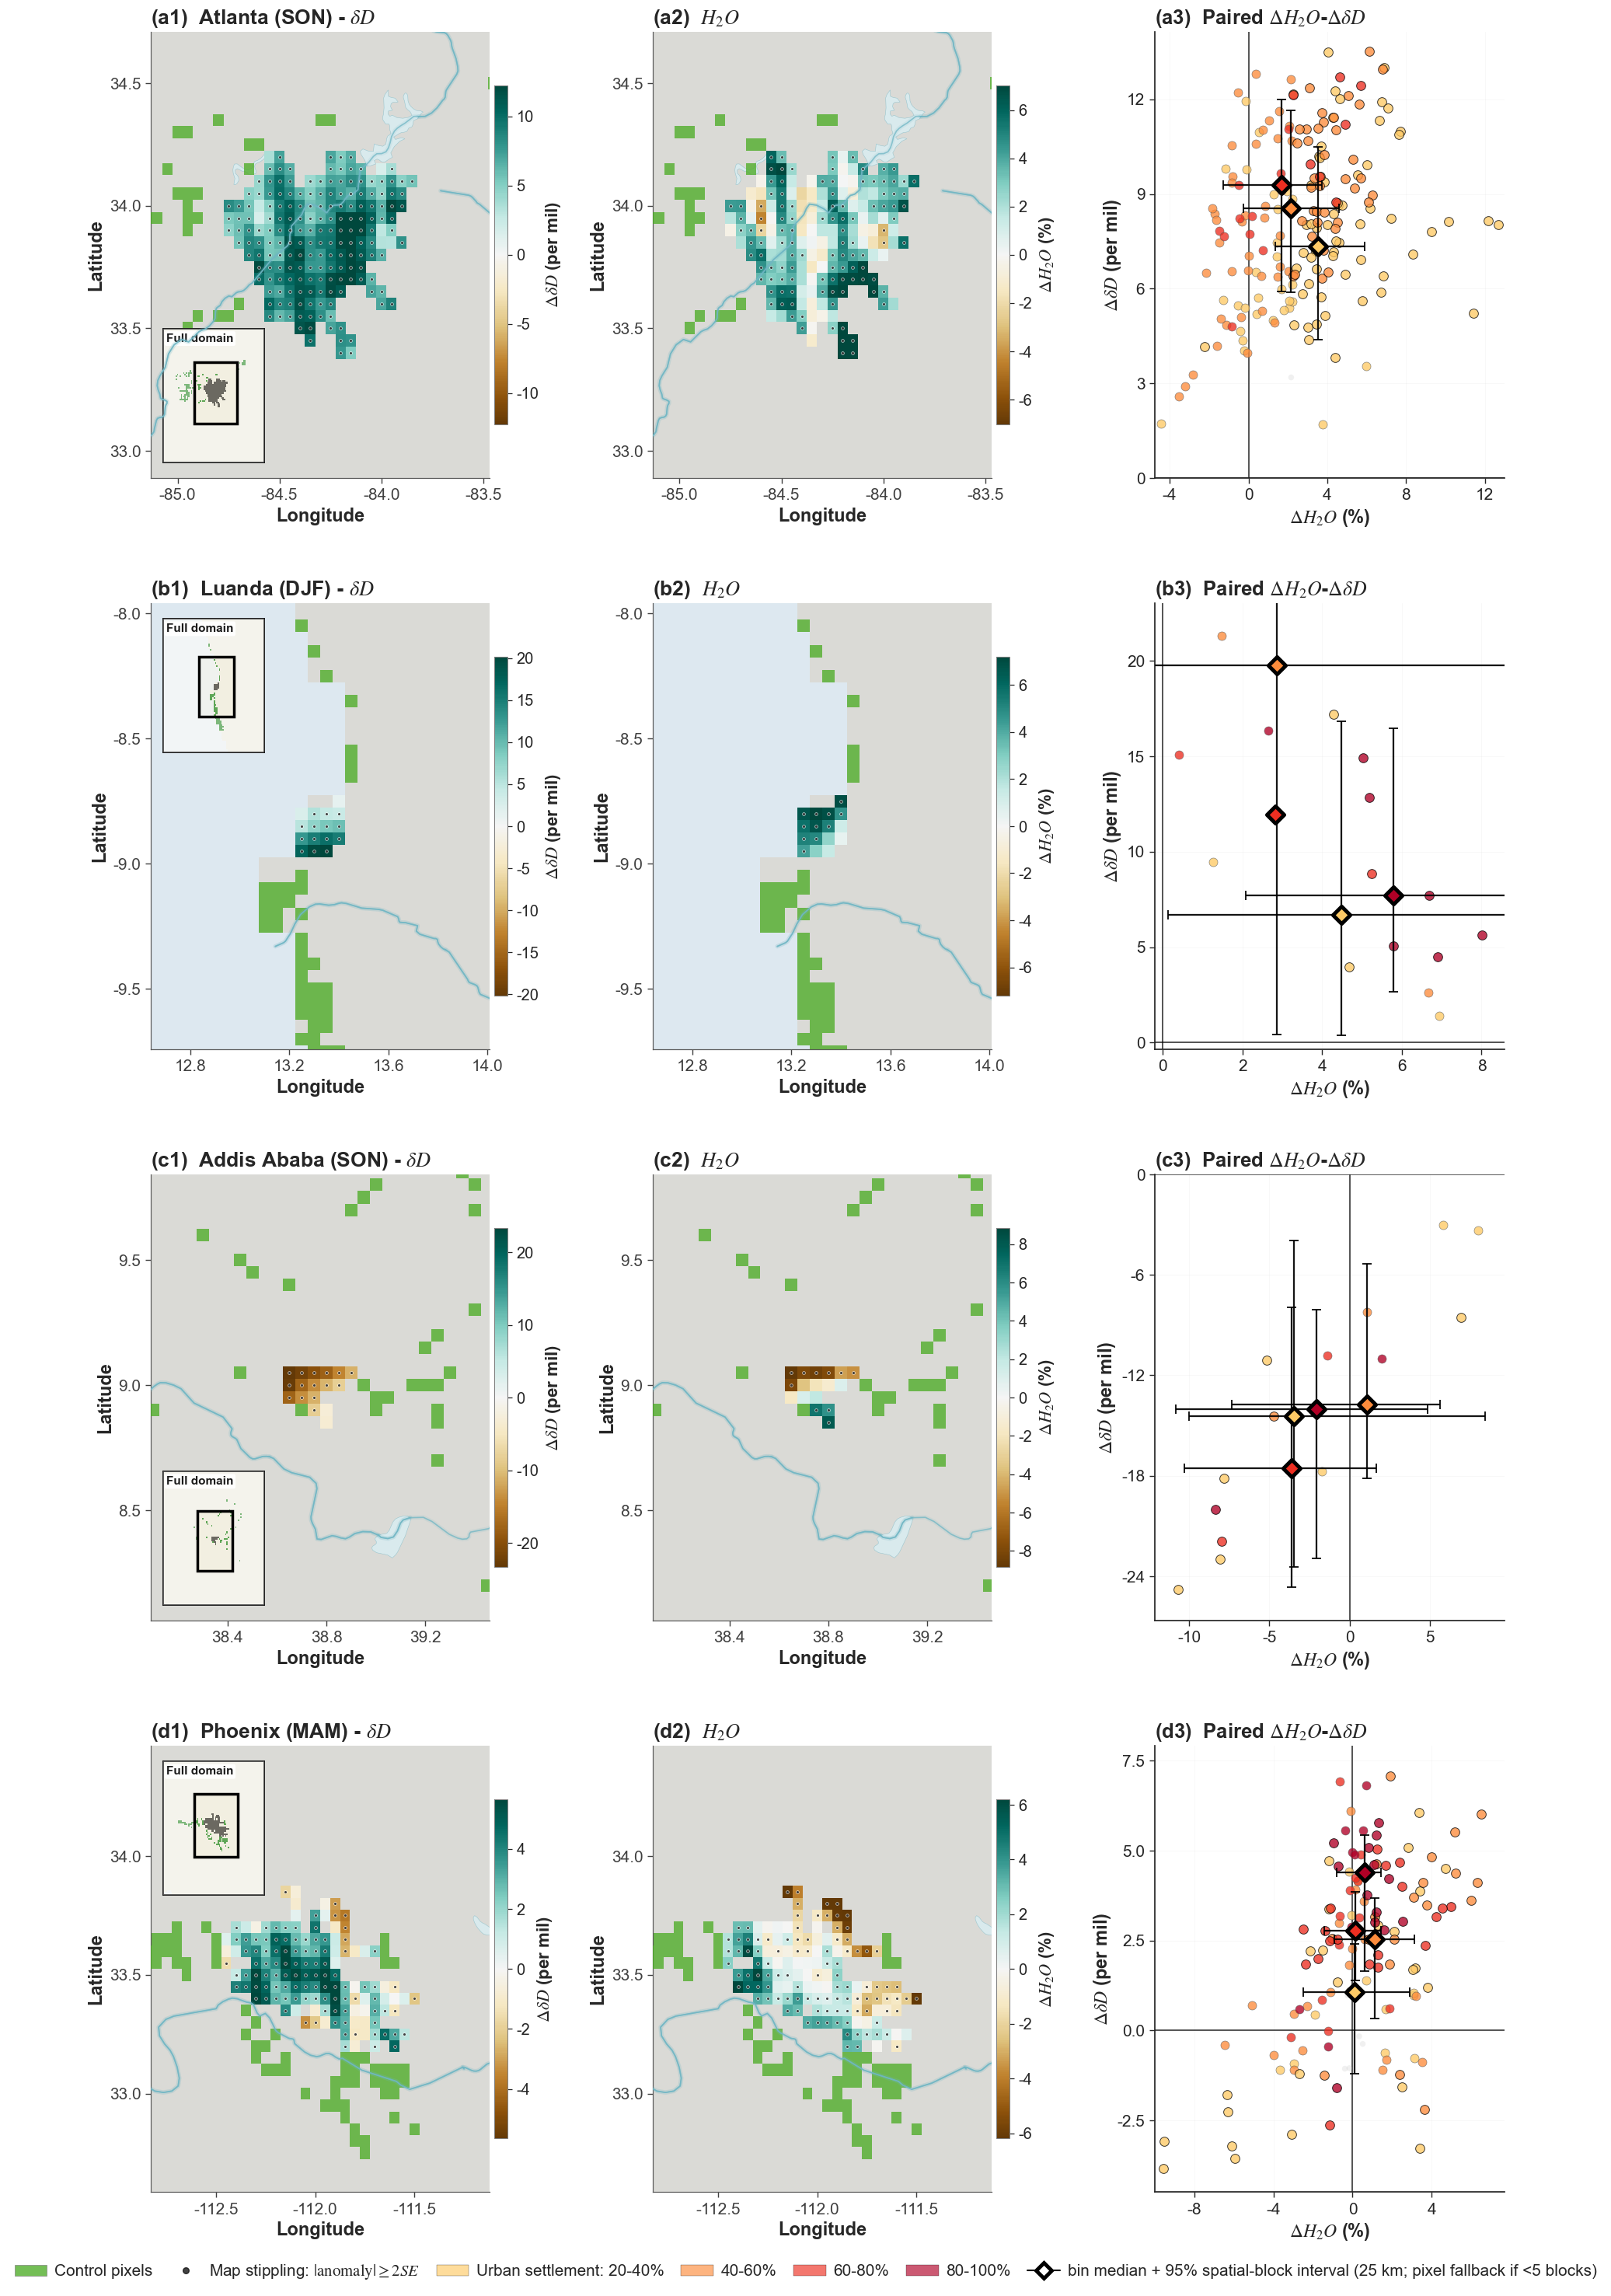

In [27]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
City-scale urban-rural vapor anomaly diagnostics
================================================

Produces anomaly maps, paired isotope-moisture scatterplots, settlement-bin
summaries, propagated uncertainty diagnostics, and spatial-block bootstrap
intervals for the selected city-seasons.

Main figure:
    - Shows all valid urban pixels.
    - Delta-dD map colors all Delta-dD anomalies.
    - Delta-H2O map colors all Delta-H2O anomalies.
    - Stippling marks pixels where the mapped anomaly exceeds 2 SE.
    - Paired scatter uses all paired pixels.
    - Settlement-bin median diamonds and 95% intervals are computed from all
      valid paired pixels.

Appendix figure:
    - One row per city:
        Delta-dD anomaly map with 2SE stippling
        Delta-H2O anomaly map with 2SE stippling
        |Delta-dD|/SE map with log color scale
        |Delta-H2O|/SE map with log color scale
        paired Delta-H2O--Delta-dD scatter

Uncertainty:
    - Seasonal mean is count-weighted.
    - Seasonal SE is propagated from monthly per-pixel SE.
    - Rural baseline uncertainty uses retrieval precision plus rural-block SEM.
    - H2O relative-anomaly SE uses first-order propagation for:
        100 * (urban - rural) / rural
    - Primary median intervals use 25-km spatial-block resampling; pixel
      resampling is retained only as a fallback when a bin has <5 blocks.
"""

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import rioxarray

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib as mpl

from scipy.ndimage import distance_transform_edt, label as ndimage_label

warnings.filterwarnings("ignore")

_HAS_CARTOPY = False
_HAS_SHAPELY = False

try:
    import cartopy.io.shapereader as shpreader
    _HAS_CARTOPY = True
except ImportError:
    pass

try:
    from shapely.geometry import (
        MultiLineString,
        Polygon,
        MultiPolygon,
        box as shapely_box,
    )
    _HAS_SHAPELY = True
except ImportError:
    pass


# ============================================================================
# CONFIGURATION
# ============================================================================

# CITIES = [
#     {"name": "Moscow", "season": "JJA"},
#     {"name": "Melbourne", "season": "SON"},
#     {"name": "New York City", "season": "MAM"},
# ]

# Additional city examples. Atlanta uses the top-2000 catalog; the remaining cities use top-400.
CITIES = [
    {"name": "Atlanta", "season": "SON", "catalog": "top2000"},
    {"name": "Luanda", "season": "DJF", "catalog": "top400"},
    {"name": "Addis Ababa", "season": "SON", "catalog": "top400"},
    {"name": "Phoenix", "season": "MAM", "catalog": "top400"},
]


# Portable repository paths
REVISION_ROOT = PROJECT_ROOT
DATA_DIR = SOURCE_DATA_DIR
FIGURES_DIR = OUTPUT_FIGURES_DIR
RESULTS_DIR = OUTPUT_TABLES_DIR

for _dir in [DATA_DIR, FIGURES_DIR, RESULTS_DIR]:
    Path(_dir).mkdir(parents=True, exist_ok=True)

TROPOMI_PATH = str(FILES["tropomi_climatology"])
SETTLEMENT_NC_PATH = str(FILES["settlement"])
ELEVATION_TIF_PATH = str(FILES["elevation"])
LANDMASK_NC_PATH = str(FILES["landmask"])

# The ordinary Supplementary Figure 5 examples come from the top-400
# catalog. Atlanta is explicitly drawn from the extended top-2000 catalog.
CITY_CSV_TOP400 = str(FILES["cities_top400"])
CITY_CSV_TOP2000 = str(FILES["cities_top2000"])

CITY_CSV_TOP2000_CANDIDATES = [
    CITY_CSV_TOP2000,
]

# Backward-compatible aliases used by load_city_dataframe().
CITY_CSV = CITY_CSV_TOP400
CITY_CSV_CANDIDATES = [CITY_CSV_TOP400]

URBAN_MIN = 20.0
CONTROL_MAX = 1.0
BUFFER_RADIUS_KM = 150.0
ELEV_DIFF_THR = 50.0
COAST_DIFF_THR = 50.0

MIN_COUNT_PER_MONTH = 5.0
MIN_SUPPORTED_MONTHS = 2

USE_REGRESSION_BASELINE = False
MIN_RURAL_FOR_REGRESSION = 30
REGRESSION_USE_LATLON = False

URBAN_PIXEL_ELEV_SCREEN = None
URBAN_PIXEL_COAST_SCREEN = None

URBAN_BINS = [(20, 40), (40, 60), (60, 80), (80, 100)]

WEIGHT_CITY_MEANS_BY_TOTAL_OBS = False


# ============================================================================
# UNCERTAINTY OPTIONS
# ============================================================================

DELTA_D_SE_MODE = "precision"       # "precision" or "conservative"
H2O_SE_MODE = "precision"           # "precision" or "conservative"

RURAL_BASELINE_SE_MODE = "measurement_plus_rural_block_sem"

# Other supported modes:
#     "measurement"
#     "spatial_sem"
#     "measurement_plus_spatial_sem"
#     "rural_spread"
#     "measurement_plus_rural_spread"
#     "rural_block_sem"
#     "measurement_plus_rural_block_sem"
#     "none"

RURAL_SPREAD_METHOD = "mad"     # "mad" or "std"

RURAL_BLOCK_SE_SIZE_KM = 50.0
RURAL_BLOCK_SE_METHOD = "mad"   # "mad" or "std"
MIN_RURAL_BLOCKS_FOR_SE = 3

PIXEL_CONFIDENCE_SE = 2.0

DRAW_BOOTSTRAP_MEDIAN_CI = True
BOOTSTRAP_INCLUDE_MEASUREMENT_ERROR = True
BOOTSTRAP_N = 2000
BOOTSTRAP_CI = (2.5, 97.5)
BOOTSTRAP_RANDOM_SEED = 42
MIN_BIN_N_FOR_CI = 3

# Primary interval for the revised figures: resample coherent 25-km urban
# blocks rather than individual 0.05-degree cells.  Five populated blocks is
# used as the minimum support for block resampling.  If a settlement bin has
# fewer than five populated blocks, retain the case but fall back to the prior
# pixel bootstrap.  The actual mode used for every city/bin is written to the
# summary CSV (bootstrap_mode and bootstrap_n_blocks).
MAIN_BOOTSTRAP_CONFIG = {
    "label": "main_block25km",
    "legend_label": "bin median + 95% spatial-block interval (25 km; pixel fallback if <5 blocks)",
    "resampling_mode": "spatial_block",
    "block_size_km": 25.0,
    "min_bin_n_blocks_for_ci": 5,
    "fallback_to_pixel_if_few_blocks": True,
    "n_boot": BOOTSTRAP_N,
    "ci": BOOTSTRAP_CI,
    "random_seed": BOOTSTRAP_RANDOM_SEED,
    "min_bin_n_for_ci": MIN_BIN_N_FOR_CI,
    "include_measurement_error": BOOTSTRAP_INCLUDE_MEASUREMENT_ERROR,
    "baseline_error_mode": "common_shift",
}


APPENDIX_BOOTSTRAP_BLOCK_SIZE_KM_OPTIONS = [25.0]

APPENDIX_BOOTSTRAP_CONFIGS = [
    {
        "label": f"appendix_block{block_size:g}km",
        "legend_label": f"bin median + 95% spatial-block interval ({block_size:g} km)",
        "resampling_mode": "spatial_block",
        "block_size_km": float(block_size),
        "min_bin_n_blocks_for_ci": 5,
        "fallback_to_pixel_if_few_blocks": False,
        "n_boot": BOOTSTRAP_N,
        "ci": BOOTSTRAP_CI,
        "random_seed": BOOTSTRAP_RANDOM_SEED,
        "min_bin_n_for_ci": MIN_BIN_N_FOR_CI,
        "include_measurement_error": BOOTSTRAP_INCLUDE_MEASUREMENT_ERROR,
        "baseline_error_mode": "common_shift",
    }
    for block_size in APPENDIX_BOOTSTRAP_BLOCK_SIZE_KM_OPTIONS
]

MIN_H2O_BASELINE = 1.0e-9


# ============================================================================
# OUTPUT OPTIONS
# ============================================================================

RUN_MAIN_FIGURE = True
RUN_APPENDIX_FIGURE = False

OUTPUT_DIR = FIGURES_DIR
# FIG_NAME_BASE = "Supplement_Figure_LowSettlement_MultiCityDiag_uncertaintyRuralBlock_zoomedInset_autoInset_compactLegend"
FIG_NAME_BASE = "Supplement_MultiCityDiag_extra_examples_block25km"
SAVE_PNG = True
SAVE_PDF = True

MAIN_SHOW_SUPTITLE = False
MAIN_SHOW_STATS_BOX = False
MAIN_SHOW_INLINE_BIN_LABELS = False

APPENDIX_SHOW_SUPTITLE = True
APPENDIX_SHOW_STATS_BOX = True
APPENDIX_SHOW_INLINE_BIN_LABELS = True


# ============================================================================
# PLOT STYLE
# ============================================================================

OCEAN_COLOR = "#dde8f0"
LAND_COLOR = "#dadad6"
CONTROL_COLOR = "#4dac26"

MAP_DIFF_CMAP = plt.cm.BrBG
SNR_CMAP = plt.cm.viridis
SCATTER_WEAK_COLOR = "0.74"

# Map zoom controls.
#   "urban"               = main map zooms to valid urban anomaly pixels.
#   "urban_plus_controls" = main map includes every selected rural control pixel.
#   "city_bbox"           = use the full city CSV bounding box.
#
# Recommended with context insets:
#   MAP_ZOOM_MODE = "urban"
# The small inset then shows the full city/control domain, including all selected
# rural controls, while the main map stays focused and readable.
MAP_ZOOM_MODE = "urban"
MAP_ZOOM_PAD_KM = 35.0
MAP_ZOOM_PAD_FRACTION = 0.08
MAP_ZOOM_MIN_SPAN_KM = 150.0
MAP_ZOOM_MAX_KM_ASPECT_RATIO = 2.6
MAP_ZOOM_PRINT_EXTENTS = True
USE_COMMON_CITY_MAP_EXTENT = True

# Map aspect handling.
#   "auto"          = fill each subplot box; most compact but can distort maps.
#   "local_datalim" = keep subplot boxes equal, but expand data limits slightly
#                     to preserve approximate local lon/lat distance scaling.
#   "local_box"     = preserve local scaling by changing the axes box shape.
# Recommended for publication-style panels: "local_datalim".
MAP_ASPECT_MODE = "local_datalim"
MAP_TICK_NBINS = 4

# ============================================================================
# CONTEXT INSET OPTIONS
# ============================================================================

# Insets are drawn only on the first map panel for each city row by default.
# The inset shows the full city/control domain; the black rectangle marks the
# zoomed main-map extent. This allows the main maps to zoom around the urban
# anomaly field without hiding the broader rural-control context.
SHOW_CONTEXT_INSET_MAIN = True
SHOW_CONTEXT_INSET_APPENDIX = True
CONTEXT_INSET_TITLE = "Full domain"

# Placement.
# "auto" tests the four corners and chooses the one that covers the fewest
# important pixels. Fixed options are:
# "upper_left", "upper_right", "lower_left", "lower_right".
CONTEXT_INSET_PLACEMENT = "auto"

# Inset size and padding in axes-fraction units. These are deliberately a bit
# smaller than the earlier fixed inset so the auto-placement has room to work.
CONTEXT_INSET_WIDTH = 0.30
CONTEXT_INSET_HEIGHT = 0.30
CONTEXT_INSET_PAD = 0.035

# Optional fallback only. This is used if auto-placement fails or if a fixed
# code path is restored later.
CONTEXT_INSET_BOUNDS = [
    CONTEXT_INSET_PAD,
    1.0 - CONTEXT_INSET_PAD - CONTEXT_INSET_HEIGHT,
    CONTEXT_INSET_WIDTH,
    CONTEXT_INSET_HEIGHT,
]

# Auto-placement scoring. The inset should strongly avoid covering significant
# anomaly pixels, then urban/anomaly pixels generally, and only weakly penalize
# covering controls.
CONTEXT_INSET_AVOID_SIGNIFICANT_WEIGHT = 20.0
CONTEXT_INSET_AVOID_URBAN_WEIGHT = 10.0
CONTEXT_INSET_AVOID_CONTROL_WEIGHT = 1.5

# Set True while testing placement choices; False for final figure generation.
CONTEXT_INSET_DEBUG_PRINT = True

# Locator-map visual style. Use muted colors so the inset reads as spatial
# context, not as another analytical anomaly map.
CONTEXT_INSET_OCEAN_COLOR = "#eef2f4"
CONTEXT_INSET_LAND_COLOR = "#f1efe6"
CONTEXT_INSET_CTRL_COLOR = "#2f8f2f"
CONTEXT_INSET_URBAN_COLOR = "#111111"

CONTEXT_INSET_URBAN_ALPHA = 0.65
CONTEXT_INSET_CTRL_ALPHA = 0.82

# Inset frame and title styling.
CONTEXT_INSET_PANEL_EDGE_COLOR = "0.10"
CONTEXT_INSET_PANEL_LINEWIDTH = 1.35
CONTEXT_INSET_TITLE_FACE = "white"
CONTEXT_INSET_TITLE_ALPHA = 0.95

# Subtle shading distinguishes the broader full-domain area from the zoomed
# map window, but hatching is off by default because it can look like a data
# mask or significance layer.
CONTEXT_INSET_SHADE_OUTSIDE_ZOOM = True
CONTEXT_INSET_OUTSIDE_SHADE_COLOR = "white"
CONTEXT_INSET_OUTSIDE_SHADE_ALPHA = 0.25
CONTEXT_INSET_OUTSIDE_HATCH = None
CONTEXT_INSET_OUTSIDE_HATCH_COLOR = "0.62"
CONTEXT_INSET_OUTSIDE_HATCH_LINEWIDTH = 0.25

# Highlight the zoomed rectangle very lightly; the rectangle outline carries
# most of the visual emphasis.
CONTEXT_INSET_ZOOM_FILL_COLOR = "#fff2a8"
CONTEXT_INSET_ZOOM_FILL_ALPHA = 0.08
CONTEXT_INSET_RECT_COLOR = "black"
CONTEXT_INSET_RECT_LINEWIDTH_BASE = 2.0

# -----------------------------------------------------------------------------
# Readability presets
# -----------------------------------------------------------------------------
# Change this one line to scale labels/ticks/colorbars/legends coherently:
# Legend reserved space includes the compact bottom legend plus clearance for
# lower-row tick labels and x-axis labels, so it should be larger than the
# legend height alone.
#     "base"        = standard text sizing.
#     "bigger"      = noticeably larger, good for manuscript review PDFs.
#     "much_bigger" = larger still, usually best for multi-panel appendices.
#     "poster"      = very large labels for talks/posters or heavy downscaling.
TEXT_SIZE_PRESET = "much_bigger"
TEXT_SIZE_MULTIPLIER = 1.0      # optional fine adjustment after preset selection
FIGURE_SIZE_MULTIPLIER = 1.0    # optional global figure-size adjustment

_TEXT_SIZE_PRESETS = {
    "base": {
        "fig_width_scale": 1.00,
        "fig_height_scale": 1.00,
        "legend_reserved_inches": 1.05,
        "legend_anchor_inches": 0.12,
        "main_suptitle_reserved_inches": 0.25,
        "appendix_suptitle_reserved_inches": 1.15,
        "main_wspace": 0.32,
        "appendix_wspace": 0.43,
        "outer_hspace": 0.24,
        "map_title": 15.0,
        "appendix_map_title": 13.2,
        "joint_title": 14.5,
        "axis_label": 13.2,
        "tick": 11.2,
        "colorbar_label": 12.0,
        "colorbar_tick": 10.6,
        "legend": 12.0,
        "legend_title": 13.8,
        "stats_box": 8.8,
        "inline_bin_label": 9.4,
        "suptitle": 13.2,
        "inset_title": 8.6,
        "map_tick_nbins": 4,
        "tick_length": 3.4,
        "tick_width": 0.75,
        "tick_pad": 3.2,
        "colorbar_tick_length": 3.0,
        "colorbar_tick_width": 0.65,
        "marker_scale": 1.00,
        "line_scale": 1.00,
    },
    "bigger": {
        "fig_width_scale": 1.04,
        "fig_height_scale": 1.06,
        "legend_reserved_inches": 1.25,
        "legend_anchor_inches": 0.14,
        "main_suptitle_reserved_inches": 0.30,
        "appendix_suptitle_reserved_inches": 1.35,
        "main_wspace": 0.36,
        "appendix_wspace": 0.48,
        "outer_hspace": 0.26,
        "map_title": 17.0,
        "appendix_map_title": 15.2,
        "joint_title": 16.6,
        "axis_label": 15.2,
        "tick": 13.2,
        "colorbar_label": 14.2,
        "colorbar_tick": 12.6,
        "legend": 13.5,
        "legend_title": 15.6,
        "stats_box": 10.0,
        "inline_bin_label": 10.8,
        "suptitle": 15.2,
        "inset_title": 9.8,
        "map_tick_nbins": 4,
        "tick_length": 4.2,
        "tick_width": 0.85,
        "tick_pad": 3.8,
        "colorbar_tick_length": 3.7,
        "colorbar_tick_width": 0.75,
        "marker_scale": 1.10,
        "line_scale": 1.12,
    },
    "much_bigger": {
        "fig_width_scale": 1.10,
        "fig_height_scale": 1.13,
        "legend_reserved_inches": 1.50,
        "legend_anchor_inches": 0.16,
        "main_suptitle_reserved_inches": 0.35,
        "appendix_suptitle_reserved_inches": 1.55,
        "main_wspace": 0.41,
        "appendix_wspace": 0.55,
        "outer_hspace": 0.28,
        "map_title": 19.0,
        "appendix_map_title": 17.0,
        "joint_title": 18.6,
        "axis_label": 17.0,
        "tick": 15.0,
        "colorbar_label": 16.0,
        "colorbar_tick": 14.4,
        "legend": 15.0,
        "legend_title": 17.5,
        "stats_box": 11.4,
        "inline_bin_label": 12.2,
        "suptitle": 17.0,
        "inset_title": 11.0,
        "map_tick_nbins": 4,
        "tick_length": 5.0,
        "tick_width": 1.00,
        "tick_pad": 4.4,
        "colorbar_tick_length": 4.4,
        "colorbar_tick_width": 0.90,
        "marker_scale": 1.22,
        "line_scale": 1.25,
    },
    "poster": {
        "fig_width_scale": 1.28,
        "fig_height_scale": 1.30,
        "legend_reserved_inches": 1.90,
        "legend_anchor_inches": 0.18,
        "main_suptitle_reserved_inches": 0.45,
        "appendix_suptitle_reserved_inches": 1.90,
        "main_wspace": 0.52,
        "appendix_wspace": 0.68,
        "outer_hspace": 0.34,
        "map_title": 24.0,
        "appendix_map_title": 21.5,
        "joint_title": 23.5,
        "axis_label": 21.5,
        "tick": 18.8,
        "colorbar_label": 20.5,
        "colorbar_tick": 18.0,
        "legend": 18.8,
        "legend_title": 22.0,
        "stats_box": 14.0,
        "inline_bin_label": 15.0,
        "suptitle": 21.5,
        "inset_title": 13.8,
        "map_tick_nbins": 3,
        "tick_length": 6.4,
        "tick_width": 1.25,
        "tick_pad": 5.4,
        "colorbar_tick_length": 5.8,
        "colorbar_tick_width": 1.10,
        "marker_scale": 1.55,
        "line_scale": 1.55,
    },
}


def _get_text_size_preset(name):
    key = str(name).lower().strip()
    if key not in _TEXT_SIZE_PRESETS:
        allowed = ", ".join(sorted(_TEXT_SIZE_PRESETS))
        raise ValueError(f"Unknown TEXT_SIZE_PRESET={name!r}. Use one of: {allowed}.")
    return _TEXT_SIZE_PRESETS[key]


_FONT = _get_text_size_preset(TEXT_SIZE_PRESET)
_FONT_SCALE = float(TEXT_SIZE_MULTIPLIER)
_FIG_SCALE = float(FIGURE_SIZE_MULTIPLIER)
_MARKER_SCALE = float(_FONT["marker_scale"])
_LINE_SCALE = float(_FONT["line_scale"])

# Base figure dimensions before preset scaling.
_BASE_MAIN_FIG_WIDTH_INCHES = 17.4
_BASE_MAIN_PER_CITY_HEIGHT_INCHES = 6.15
_BASE_APPENDIX_FIG_WIDTH_INCHES = 23.5
_BASE_APPENDIX_PER_CITY_HEIGHT_INCHES = 5.55

MAIN_FIG_WIDTH_INCHES = _BASE_MAIN_FIG_WIDTH_INCHES * _FONT["fig_width_scale"] * _FIG_SCALE
MAIN_PER_CITY_HEIGHT_INCHES = _BASE_MAIN_PER_CITY_HEIGHT_INCHES * _FONT["fig_height_scale"] * _FIG_SCALE

APPENDIX_FIG_WIDTH_INCHES = _BASE_APPENDIX_FIG_WIDTH_INCHES * _FONT["fig_width_scale"] * _FIG_SCALE
APPENDIX_PER_CITY_HEIGHT_INCHES = _BASE_APPENDIX_PER_CITY_HEIGHT_INCHES * _FONT["fig_height_scale"] * _FIG_SCALE

MAIN_INNER_WSPACE = _FONT["main_wspace"]
APPENDIX_INNER_WSPACE = _FONT["appendix_wspace"]
OUTER_HSPACE = _FONT["outer_hspace"]

SHARED_LEGEND_RESERVED_INCHES = _FONT["legend_reserved_inches"] * _FIG_SCALE
LEGEND_ANCHOR_INCHES = _FONT["legend_anchor_inches"] * _FIG_SCALE
MAIN_SUPTITLE_RESERVED_INCHES = _FONT["main_suptitle_reserved_inches"] * _FIG_SCALE
APPENDIX_SUPTITLE_RESERVED_INCHES = _FONT["appendix_suptitle_reserved_inches"] * _FIG_SCALE

FONTSIZE_MAP_TITLE = _FONT["map_title"] * _FONT_SCALE
FONTSIZE_APPENDIX_MAP_TITLE = _FONT["appendix_map_title"] * _FONT_SCALE
FONTSIZE_JOINT_TITLE = _FONT["joint_title"] * _FONT_SCALE
FONTSIZE_AXIS_LABEL = _FONT["axis_label"] * _FONT_SCALE
FONTSIZE_TICK = _FONT["tick"] * _FONT_SCALE
FONTSIZE_COLORBAR_LABEL = _FONT["colorbar_label"] * _FONT_SCALE
FONTSIZE_COLORBAR_TICK = _FONT["colorbar_tick"] * _FONT_SCALE
FONTSIZE_LEGEND = _FONT["legend"] * _FONT_SCALE
FONTSIZE_LEGEND_TITLE = _FONT["legend_title"] * _FONT_SCALE
FONTSIZE_STATS_BOX = _FONT["stats_box"] * _FONT_SCALE
FONTSIZE_INLINE_BIN_LABEL = _FONT["inline_bin_label"] * _FONT_SCALE
FONTSIZE_SUPTITLE = _FONT["suptitle"] * _FONT_SCALE
CONTEXT_INSET_TITLE_SIZE = _FONT["inset_title"] * _FONT_SCALE

MAP_TICK_NBINS = int(_FONT["map_tick_nbins"])
MAP_TICK_LENGTH = _FONT["tick_length"] * _FONT_SCALE
MAP_TICK_WIDTH = _FONT["tick_width"] * _FONT_SCALE
MAP_TICK_PAD = _FONT["tick_pad"] * _FONT_SCALE
COLORBAR_TICK_LENGTH = _FONT["colorbar_tick_length"] * _FONT_SCALE
COLORBAR_TICK_WIDTH = _FONT["colorbar_tick_width"] * _FONT_SCALE
SCATTER_TICK_LENGTH = MAP_TICK_LENGTH
SCATTER_TICK_WIDTH = MAP_TICK_WIDTH
SCATTER_TICK_PAD = MAP_TICK_PAD

AXIS_LABEL_WEIGHT = "bold"
TITLE_WEIGHT = "bold"
LEGEND_TITLE_WEIGHT = None

JOINT_POINT_SIZE_WEAK = 24 * _MARKER_SCALE
JOINT_POINT_SIZE_2SE = 52 * _MARKER_SCALE
JOINT_POINT_ALPHA_WEAK = 0.22
JOINT_POINT_ALPHA_2SE = 0.78
JOINT_MEDIAN_MARKER_SIZE = 105 * _MARKER_SCALE
JOINT_LIMIT_PERCENTILES = (1, 99)

MEDIAN_DIAMOND_LINEWIDTH = 2.8 * _LINE_SCALE
CONTEXT_INSET_RECT_LINEWIDTH = CONTEXT_INSET_RECT_LINEWIDTH_BASE * _LINE_SCALE

SNR_MAP_VMIN = 0.5
SNR_MAP_VMAX = 10.0
SNR_MAP_TICKS = [0.5, 1, 2, 5, 10]

STIPPLE_COLOR = "0.05"
STIPPLE_ALPHA = 0.78
STIPPLE_SIZE = 16 * _MARKER_SCALE
STIPPLE_MARKER = "."
STIPPLE_HALO_COLOR = "white"
STIPPLE_HALO_ALPHA = 0.72
STIPPLE_HALO_SIZE_MULT = 2.2


# ============================================================================
# GENERAL HELPERS
# ============================================================================

def haversine_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    return 2 * np.arcsin(np.sqrt(a)) * 6371


def truncate_colormap(cmap, lo=0.08, hi=0.92, n=256):
    return mcolors.LinearSegmentedColormap.from_list(
        f"trunc_{cmap.name}",
        cmap(np.linspace(lo, hi, n)),
    )


def fix_longitude_convention(data, lons, target="0_360"):
    if target == "0_360" and lons[0] < 0:
        s = np.where(lons >= 0)[0][0]
        return (
            np.concatenate([data[:, s:], data[:, :s]], axis=1),
            np.concatenate([lons[s:], lons[:s] + 360]),
        )
    return data, lons


def lon_to_180_array(lon_values):
    lon = np.asarray(lon_values, dtype=float).copy()
    lon[lon > 180.0] -= 360.0
    return lon


def get_season_months(season="annual"):
    months = {
        "ANNUAL": list(range(12)),
        "DJF": [11, 0, 1],
        "MAM": [2, 3, 4],
        "JJA": [5, 6, 7],
        "SON": [8, 9, 10],
    }
    return months[season.upper()]


def bbox_mask_180(lons180, lats, latmin, latmax, lonmin, lonmax):
    lok = (lats >= latmin) & (lats <= latmax)

    if lonmin < -180:
        lonk = (lons180 >= lonmin + 360) | (lons180 <= lonmax)
    elif lonmax > 180:
        lonk = (lons180 >= lonmin) | (lons180 <= lonmax - 360)
    else:
        lonk = (lons180 >= lonmin) & (lons180 <= lonmax)

    return lok & lonk


def weighted_or_unweighted_mean(values, weights=None, use_weights=False):
    v = np.asarray(values, float)
    good = np.isfinite(v)

    if not good.any():
        return np.nan

    v = v[good]

    if use_weights:
        w = np.asarray(weights, float)[good]
        wgood = np.isfinite(w) & (w > 0)

        if wgood.any():
            return float(np.average(v[wgood], weights=w[wgood]))

        return np.nan

    return float(np.mean(v))


def robust_joint_limits(values, percentiles=JOINT_LIMIT_PERCENTILES, include_zero=True):
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]

    if len(v) == 0:
        return -1.0, 1.0

    lo, hi = np.nanpercentile(v, percentiles)

    if not np.isfinite(lo) or not np.isfinite(hi) or np.isclose(lo, hi):
        c = float(np.nanmedian(v))
        span = max(abs(c) * 0.10, 1.0)
        lo, hi = c - span, c + span
    else:
        pad = 0.10 * (hi - lo)
        lo, hi = lo - pad, hi + pad

    if include_zero:
        lo = min(lo, 0.0)
        hi = max(hi, 0.0)

    return float(lo), float(hi)


def robust_sigma_mad(values):
    v = np.asarray(values, float)
    v = v[np.isfinite(v)]

    if len(v) <= 1:
        return 0.0

    med = np.nanmedian(v)
    mad = np.nanmedian(np.abs(v - med))
    sig = 1.4826 * mad

    if not np.isfinite(sig) or sig <= 0:
        sig = np.nanstd(v, ddof=1)

    if not np.isfinite(sig):
        sig = 0.0

    return float(sig)


def make_spatial_block_ids(lat, lon, block_size_km=25.0):
    lat = np.asarray(lat, dtype=float)
    lon = lon_to_180_array(lon)

    lat0 = float(np.nanmedian(lat))
    coslat = np.cos(np.deg2rad(lat0))

    y_km = lat * 111.0
    x_km = lon * 111.0 * coslat

    by = np.floor(y_km / block_size_km).astype(int)
    bx = np.floor(x_km / block_size_km).astype(int)

    return np.array([f"{yy}_{xx}" for yy, xx in zip(by, bx)], dtype=object)


def bootstrap_config_suffix(cfg):
    mode = cfg.get("resampling_mode", "unknown")
    label = cfg.get("label", mode)

    if mode == "spatial_block":
        return f"{label}_{mode}{cfg.get('block_size_km', np.nan):g}km"

    return f"{label}_{mode}"


def describe_bootstrap_config(cfg):
    mode = cfg.get("resampling_mode", "unknown")

    if mode == "spatial_block":
        fallback = cfg.get("fallback_to_pixel_if_few_blocks", False)
        return (
            f"{mode}, block={cfg.get('block_size_km', np.nan):g} km, "
            f"min blocks={cfg.get('min_bin_n_blocks_for_ci', np.nan)}, "
            f"fallback={fallback}"
        )

    return mode


def compute_map_zoom_extent(crow, px, ctrl_df=None):
    """Return map x/y limits for compact city-centered map panels."""
    city_latmin = float(crow["lat_min"])
    city_latmax = float(crow["lat_max"])
    city_lonmin = float(crow["lon_min"])
    city_lonmax = float(crow["lon_max"])

    fallback = {
        "xlim": (city_lonmin, city_lonmax),
        "ylim": (city_latmin, city_latmax),
        "source": "city_bbox",
    }

    mode = str(MAP_ZOOM_MODE).lower()
    if mode == "city_bbox":
        return fallback

    lat_parts = []
    lon_parts = []

    if px is not None and len(px) > 0:
        lat_parts.append(px["latitude"].values.astype(float))
        lon_parts.append(lon_to_180_array(px["longitude"].values.astype(float)))

    if mode == "urban_plus_controls":
        if ctrl_df is not None and len(ctrl_df) > 0:
            lat_parts.append(ctrl_df["latitude"].values.astype(float))
            lon_parts.append(lon_to_180_array(ctrl_df["longitude"].values.astype(float)))
    elif mode != "urban":
        raise ValueError(
            "Unknown MAP_ZOOM_MODE. Use 'urban', 'urban_plus_controls', or 'city_bbox'."
        )

    if not lat_parts or not lon_parts:
        return fallback

    lat = np.concatenate(lat_parts)
    lon = np.concatenate(lon_parts)
    good = np.isfinite(lat) & np.isfinite(lon)

    if np.sum(good) == 0:
        return fallback

    lat = lat[good]
    lon = lon[good]

    # The current example cities do not cross the antimeridian. If a future city
    # does, use city_bbox or a custom local projection before zooming.
    if np.nanmax(lon) - np.nanmin(lon) > 120:
        return fallback

    latmin = float(np.nanmin(lat))
    latmax = float(np.nanmax(lat))
    lonmin = float(np.nanmin(lon))
    lonmax = float(np.nanmax(lon))

    lat0 = float(np.nanmedian(lat))
    coslat = max(np.cos(np.deg2rad(lat0)), 0.15)

    lat_span = max(latmax - latmin, 1.0e-6)
    lon_span = max(lonmax - lonmin, 1.0e-6)

    pad_lat = max(MAP_ZOOM_PAD_KM / 111.0, MAP_ZOOM_PAD_FRACTION * lat_span)
    pad_lon = max(
        MAP_ZOOM_PAD_KM / (111.0 * coslat),
        MAP_ZOOM_PAD_FRACTION * lon_span,
    )

    latmin -= pad_lat
    latmax += pad_lat
    lonmin -= pad_lon
    lonmax += pad_lon

    # Keep the crop from becoming too tight around a handful of pixels.
    lat_c = 0.5 * (latmin + latmax)
    lon_c = 0.5 * (lonmin + lonmax)

    min_lat_span = MAP_ZOOM_MIN_SPAN_KM / 111.0
    min_lon_span = MAP_ZOOM_MIN_SPAN_KM / (111.0 * coslat)

    if (latmax - latmin) < min_lat_span:
        latmin = lat_c - 0.5 * min_lat_span
        latmax = lat_c + 0.5 * min_lat_span

    if (lonmax - lonmin) < min_lon_span:
        lonmin = lon_c - 0.5 * min_lon_span
        lonmax = lon_c + 0.5 * min_lon_span

    # Avoid very elongated crops, which can make auto-aspect maps look distorted.
    # This expands the short dimension rather than clipping data.
    if MAP_ZOOM_MAX_KM_ASPECT_RATIO is not None:
        ratio_limit = float(MAP_ZOOM_MAX_KM_ASPECT_RATIO)
        if ratio_limit > 1:
            span_y_km = max((latmax - latmin) * 111.0, 1.0e-6)
            span_x_km = max((lonmax - lonmin) * 111.0 * coslat, 1.0e-6)

            if span_x_km / span_y_km > ratio_limit:
                target_y_km = span_x_km / ratio_limit
                expand_deg = (target_y_km - span_y_km) / 111.0
                latmin -= 0.5 * expand_deg
                latmax += 0.5 * expand_deg

            elif span_y_km / span_x_km > ratio_limit:
                target_x_km = span_y_km / ratio_limit
                expand_deg = (target_x_km - span_x_km) / (111.0 * coslat)
                lonmin -= 0.5 * expand_deg
                lonmax += 0.5 * expand_deg

    return {
        "xlim": (float(lonmin), float(lonmax)),
        "ylim": (float(latmin), float(latmax)),
        "source": mode,
    }


# ============================================================================
# SEASONAL DATA + UNCERTAINTY
# ============================================================================

def get_weighted_seasonal_data_with_se(
    data_array,
    count_array,
    se_array=None,
    std_array=None,
    season="annual",
    min_count_per_month=5.0,
    se_mode="precision",
):
    months = get_season_months(season)

    data_sel = data_array.isel(time=months).values.astype(float)
    count_sel = count_array.isel(time=months).values.astype(float)

    valid = (
        np.isfinite(data_sel)
        & np.isfinite(count_sel)
        & (count_sel >= min_count_per_month)
    )

    if se_array is not None:
        se_sel = se_array.isel(time=months).values.astype(float)
        valid &= np.isfinite(se_sel) & (se_sel > 0)
    else:
        se_sel = None

    if se_mode == "conservative":
        if se_sel is None or std_array is None:
            raise ValueError("conservative SE mode requires se_array and std_array.")
        std_sel = std_array.isel(time=months).values.astype(float)
        valid &= np.isfinite(std_sel)
        monthly_se = np.sqrt(
            se_sel ** 2
            + (std_sel / np.sqrt(np.maximum(count_sel, 1.0))) ** 2
        )
    elif se_mode == "precision":
        monthly_se = se_sel
    else:
        raise ValueError(f"Unknown se_mode: {se_mode!r}")

    count_good = np.where(valid, count_sel, 0.0)
    total_count = np.sum(count_good, axis=0)

    wsum = np.sum(np.where(valid, data_sel * count_good, 0.0), axis=0)

    wmean = np.full(total_count.shape, np.nan)
    ok = total_count > 0
    wmean[ok] = wsum[ok] / total_count[ok]

    supported_months = np.sum(valid, axis=0).astype(float)

    seasonal_se = np.full(total_count.shape, np.nan)

    if monthly_se is not None:
        weights = np.zeros_like(count_good, dtype=float)
        weights[:, ok] = count_good[:, ok] / total_count[ok]
        seasonal_var = np.sum(
            np.where(valid, (weights * monthly_se) ** 2, 0.0),
            axis=0,
        )
        seasonal_se[ok] = np.sqrt(seasonal_var[ok])

    return wmean, seasonal_se, supported_months, total_count


# ============================================================================
# RURAL BASELINE UNCERTAINTY
# ============================================================================

def estimate_rural_block_sem(df_rural, var_col):
    needed = {"latitude", "longitude", var_col}

    if not needed.issubset(df_rural.columns):
        return np.nan, 0, np.nan

    lat = df_rural["latitude"].values.astype(float)
    lon = df_rural["longitude"].values.astype(float)
    y = df_rural[var_col].values.astype(float)

    good = np.isfinite(lat) & np.isfinite(lon) & np.isfinite(y)

    if np.sum(good) < 2:
        return np.nan, 0, np.nan

    lat = lat[good]
    lon = lon[good]
    y = y[good]

    block_ids = make_spatial_block_ids(
        lat,
        lon,
        block_size_km=RURAL_BLOCK_SE_SIZE_KM,
    )

    tmp = pd.DataFrame({
        "block": block_ids,
        "value": y,
    })

    block_means = tmp.groupby("block")["value"].mean().values.astype(float)
    block_means = block_means[np.isfinite(block_means)]

    n_blocks = len(block_means)

    if n_blocks < MIN_RURAL_BLOCKS_FOR_SE:
        return np.nan, n_blocks, np.nan

    if RURAL_BLOCK_SE_METHOD == "mad":
        block_spread = robust_sigma_mad(block_means)
    elif RURAL_BLOCK_SE_METHOD == "std":
        block_spread = float(np.nanstd(block_means, ddof=1))
    else:
        raise ValueError(f"Unknown RURAL_BLOCK_SE_METHOD: {RURAL_BLOCK_SE_METHOD!r}")

    if not np.isfinite(block_spread):
        return np.nan, n_blocks, np.nan

    block_sem = block_spread / np.sqrt(n_blocks)

    return float(block_sem), int(n_blocks), float(block_spread)


def estimate_bulk_baseline_se(df_rural, var_col, se_col=None):
    y = df_rural[var_col].values.astype(float)
    y = y[np.isfinite(y)]
    n = len(y)

    if n == 0:
        return {
            "baseline_se": np.nan,
            "baseline_se_measurement": np.nan,
            "baseline_se_spatial_sem": np.nan,
            "baseline_se_rural_spread": np.nan,
            "baseline_se_rural_spread_std": np.nan,
            "baseline_se_rural_spread_mad": np.nan,
            "baseline_se_rural_block_sem": np.nan,
            "baseline_se_rural_block_spread": np.nan,
            "baseline_se_n_rural_blocks": 0,
            "baseline_se_mode": RURAL_BASELINE_SE_MODE,
        }

    measurement_se = np.nan

    if se_col is not None and se_col in df_rural.columns:
        s = df_rural[se_col].values.astype(float)
        s = s[np.isfinite(s) & (s > 0)]

        if len(s) > 0:
            measurement_se = float(np.sqrt(np.sum(s ** 2)) / len(s))

    if n > 1:
        spatial_sem = float(np.nanstd(y, ddof=1) / np.sqrt(n))
        rural_spread_std = float(np.nanstd(y, ddof=1))
    else:
        spatial_sem = 0.0
        rural_spread_std = 0.0

    rural_spread_mad = robust_sigma_mad(y)

    if RURAL_SPREAD_METHOD == "mad":
        rural_spread = rural_spread_mad
    elif RURAL_SPREAD_METHOD == "std":
        rural_spread = rural_spread_std
    else:
        raise ValueError(f"Unknown RURAL_SPREAD_METHOD: {RURAL_SPREAD_METHOD!r}")

    rural_block_sem, n_rural_blocks, rural_block_spread = estimate_rural_block_sem(
        df_rural,
        var_col,
    )

    if RURAL_BASELINE_SE_MODE == "measurement":
        baseline_se = measurement_se

    elif RURAL_BASELINE_SE_MODE == "spatial_sem":
        baseline_se = spatial_sem

    elif RURAL_BASELINE_SE_MODE == "measurement_plus_spatial_sem":
        parts = [measurement_se, spatial_sem]
        parts = [p for p in parts if np.isfinite(p)]
        baseline_se = np.sqrt(np.sum(np.square(parts))) if parts else np.nan

    elif RURAL_BASELINE_SE_MODE == "rural_spread":
        baseline_se = rural_spread

    elif RURAL_BASELINE_SE_MODE == "measurement_plus_rural_spread":
        parts = [measurement_se, rural_spread]
        parts = [p for p in parts if np.isfinite(p)]
        baseline_se = np.sqrt(np.sum(np.square(parts))) if parts else np.nan

    elif RURAL_BASELINE_SE_MODE == "rural_block_sem":
        baseline_se = rural_block_sem

    elif RURAL_BASELINE_SE_MODE == "measurement_plus_rural_block_sem":
        parts = [measurement_se, rural_block_sem]
        parts = [p for p in parts if np.isfinite(p)]
        baseline_se = np.sqrt(np.sum(np.square(parts))) if parts else np.nan

    elif RURAL_BASELINE_SE_MODE == "none":
        baseline_se = 0.0

    else:
        raise ValueError(f"Unknown RURAL_BASELINE_SE_MODE: {RURAL_BASELINE_SE_MODE!r}")

    if not np.isfinite(baseline_se):
        baseline_se = spatial_sem if np.isfinite(spatial_sem) else 0.0

    return {
        "baseline_se": float(baseline_se),
        "baseline_se_measurement": float(measurement_se) if np.isfinite(measurement_se) else np.nan,
        "baseline_se_spatial_sem": float(spatial_sem) if np.isfinite(spatial_sem) else np.nan,
        "baseline_se_rural_spread": float(rural_spread) if np.isfinite(rural_spread) else np.nan,
        "baseline_se_rural_spread_std": float(rural_spread_std) if np.isfinite(rural_spread_std) else np.nan,
        "baseline_se_rural_spread_mad": float(rural_spread_mad) if np.isfinite(rural_spread_mad) else np.nan,
        "baseline_se_rural_block_sem": float(rural_block_sem) if np.isfinite(rural_block_sem) else np.nan,
        "baseline_se_rural_block_spread": float(rural_block_spread) if np.isfinite(rural_block_spread) else np.nan,
        "baseline_se_n_rural_blocks": int(n_rural_blocks),
        "baseline_se_mode": RURAL_BASELINE_SE_MODE,
    }


# ============================================================================
# DATA LOADING
# ============================================================================

def load_city_dataframe(city_csv=None):
    if city_csv and os.path.exists(city_csv):
        df = pd.read_csv(city_csv)
    else:
        found = next((c for c in CITY_CSV_CANDIDATES if os.path.exists(c)), None)

        if not found:
            raise FileNotFoundError("No city CSV found. Set CITY_CSV.")

        df = pd.read_csv(found)
        print(f"Loaded city metadata from: {found}")

    req = ["name", "latitude", "longitude", "lat_min", "lat_max", "lon_min", "lon_max"]
    miss = [c for c in req if c not in df.columns]

    if miss:
        raise ValueError(f"Missing columns: {miss}")

    if "city_key" not in df.columns:
        df["city_key"] = (
            df["name"].astype(str).str.strip()
            .str.replace(r"\s+", "_", regex=True)
            .str.replace(r"[^A-Za-z0-9_]", "", regex=True)
        )

    if "population" in df.columns:
        df = df.sort_values("population", ascending=False).reset_index(drop=True)

    return df.copy()


def resolve_top2000_city_csv():
    """Return the first existing extended-city catalog candidate.

    The extended catalog is intentionally used only for cities explicitly
    tagged with catalog="top2000" in CITIES.  This keeps it separate from the
    top-400 sampling frame used elsewhere in the paper.
    """
    found = next((p for p in CITY_CSV_TOP2000_CANDIDATES if os.path.exists(p)), None)
    if found is None:
        tried = "\n  - ".join(CITY_CSV_TOP2000_CANDIDATES)
        raise FileNotFoundError(
            "Atlanta requires the extended top-2000 city catalog, but none of "
            "the configured files exists. Tried:\n  - " + tried +
            "\nIf your file has a different name, add it to CITY_CSV_TOP2000_CANDIDATES."
        )
    return found


def load_all_data(season="annual", min_count_per_month=5.0):
    print(f"\nLoading datasets for {season.upper()} ...")

    ds = xr.open_dataset(TROPOMI_PATH)

    dd = ds["deltad"]
    h2o = ds["h2o_column"]
    count = ds["count"]

    dd_se = ds["deltad_precision_se"]
    h2o_se = ds["h2o_column_precision_se"]

    dd_std = ds["deltad_standard_deviation"] if "deltad_standard_deviation" in ds else None
    h2o_std = ds["h2o_column_standard_deviation"] if "h2o_column_standard_deviation" in ds else None

    lats = ds["lat"].values
    lons = ds["lon"].values

    sample = dd.isel(time=0).values.flatten()
    sample = sample[np.isfinite(sample)]

    if len(sample) > 0 and np.ptp(sample) < 10:
        print("   Converting deltaD and deltaD uncertainty from fraction to per mil.")
        dd = dd * 1000.0
        dd_se = dd_se * 1000.0
        if dd_std is not None:
            dd_std = dd_std * 1000.0

    dd_s, dd_se_s, supported_months, total_count = get_weighted_seasonal_data_with_se(
        dd,
        count,
        se_array=dd_se,
        std_array=dd_std,
        season=season,
        min_count_per_month=min_count_per_month,
        se_mode=DELTA_D_SE_MODE,
    )

    h2o_s, h2o_se_s, _, _ = get_weighted_seasonal_data_with_se(
        h2o,
        count,
        se_array=h2o_se,
        std_array=h2o_std,
        season=season,
        min_count_per_month=min_count_per_month,
        se_mode=H2O_SE_MODE,
    )

    settlement_ds = xr.open_dataset(SETTLEMENT_NC_PATH)
    settlement = settlement_ds["settlement_percentage"].values

    elevation_ds = rioxarray.open_rasterio(ELEVATION_TIF_PATH)
    elevation = elevation_ds.values[0] if len(elevation_ds.shape) == 3 else elevation_ds.values
    elevation, _ = fix_longitude_convention(elevation, elevation_ds.x.values)
    elevation[elevation < -10000] = np.nan

    land_ds = xr.open_dataset(LANDMASK_NC_PATH)
    land_mask = land_ds["land_mask"].values

    lat2, lon2 = np.meshgrid(lats, lons, indexing="ij")

    ocean = land_mask == 0
    dist_cells = distance_transform_edt(~ocean)

    lat_rad = np.deg2rad(lat2)
    dx_km = 0.05 * 111 * np.cos(lat_rad)
    dy_km = 0.05 * 111
    dist_to_coast = dist_cells * np.sqrt(dx_km ** 2 + dy_km ** 2) / np.sqrt(2)

    df = pd.DataFrame({
        "delta_D": dd_s.flatten(),
        "delta_D_se": dd_se_s.flatten(),
        "h2o_column": h2o_s.flatten(),
        "h2o_column_se": h2o_se_s.flatten(),
        "supported_months": supported_months.flatten(),
        "total_obs_count": total_count.flatten(),
        "settlement_pct": settlement.flatten(),
        "elevation": elevation.flatten(),
        "latitude": lat2.flatten(),
        "longitude": lon2.flatten(),
        "dist_to_coast": dist_to_coast.flatten(),
        "land_mask": land_mask.flatten(),
    }).replace([np.inf, -np.inf], np.nan).dropna()

    df = (
        df[(df["land_mask"] == 1) & (df["elevation"] > -50)]
        .drop(columns=["land_mask"])
        .copy()
    )

    print(f"   Total valid land pixels: {len(df):,}")
    print(f"   deltaD SE mode: {DELTA_D_SE_MODE}")
    print(f"   H2O SE mode: {H2O_SE_MODE}")

    for obj in [ds, land_ds, elevation_ds, settlement_ds]:
        try:
            if obj is not None:
                obj.close()
        except Exception:
            pass

    return df, lats, lons, land_mask


# ============================================================================
# WATER BODIES
# ============================================================================

_WATER_CACHE = {}


def load_water_bodies(latmin, latmax, lonmin, lonmax, cache_key=None):
    if cache_key and cache_key in _WATER_CACHE:
        return _WATER_CACHE[cache_key]

    if not (_HAS_CARTOPY and _HAS_SHAPELY):
        result = ([], [], "Rivers / Lakes")
        if cache_key:
            _WATER_CACHE[cache_key] = result
        return result

    pad = 0.5
    bbox = shapely_box(lonmin - pad, latmin - pad, lonmax + pad, latmax + pad)
    clip_box = shapely_box(lonmin - 0.2, latmin - 0.2, lonmax + 0.2, latmax + 0.2)

    river_geoms = []

    for name in ["rivers_lake_centerlines", "rivers_lake_centerlines_scale_rank"]:
        try:
            sf = natural_earth_shapefile(name)
            for rec in shpreader.Reader(sf).records():
                geom = rec.geometry
                if geom and geom.intersects(bbox):
                    river_geoms.append(geom)
        except Exception:
            continue

    river_segments, seen = [], set()

    for geom in river_geoms:
        lines = geom.geoms if isinstance(geom, MultiLineString) else [geom]

        for line in lines:
            if not line.intersects(clip_box):
                continue

            clipped = line.intersection(clip_box)

            if clipped.is_empty:
                continue

            segs = clipped.geoms if isinstance(clipped, MultiLineString) else [clipped]

            for seg in segs:
                if hasattr(seg, "coords"):
                    coords = np.array(seg.coords)

                    if len(coords) >= 2:
                        key = tuple(map(tuple, np.round(coords, 4)))

                        if key not in seen:
                            seen.add(key)
                            river_segments.append((coords[:, 0], coords[:, 1]))

    lake_patches, lake_seen = [], set()

    for lake_name in ["lakes", "lakes_north_america"]:
        try:
            sf = natural_earth_shapefile(lake_name)
            for rec in shpreader.Reader(sf).records():
                geom = rec.geometry

                if not geom or not geom.intersects(bbox):
                    continue

                clipped = geom.intersection(clip_box)

                if clipped.is_empty:
                    continue

                patches = clipped.geoms if isinstance(clipped, MultiPolygon) else [clipped]

                for patch in patches:
                    if isinstance(patch, Polygon) and not patch.is_empty:
                        coords = np.array(patch.exterior.coords)
                        key = tuple(map(tuple, np.round(coords, 4)))

                        if key not in lake_seen:
                            lake_seen.add(key)
                            lake_patches.append((coords[:, 0], coords[:, 1]))
        except Exception:
            continue

    print(
        f"   Water bodies: {len(river_segments)} river segments, "
        f"{len(lake_patches)} lake patches"
    )

    result = (river_segments, lake_patches, "Rivers / Lakes (NE 10m)")

    if cache_key:
        _WATER_CACHE[cache_key] = result

    return result


def draw_lake_patches(ax, lake_patches, z=2):
    for lx, ly in lake_patches:
        ax.fill(
            lx,
            ly,
            facecolor="#d9eef2",
            edgecolor="#86bcc8",
            linewidth=0.35,
            alpha=0.85,
            zorder=z,
        )


def draw_river_segments(ax, river_segments, z=9):
    for sx, sy in river_segments:
        ax.plot(
            sx,
            sy,
            color="#6fb6c4",
            linewidth=4,
            alpha=0.12,
            zorder=z,
            solid_capstyle="round",
        )
        ax.plot(
            sx,
            sy,
            color="#6fb6c4",
            linewidth=1.2,
            alpha=0.75,
            zorder=z + 1,
            solid_capstyle="round",
        )


def make_water_legend_handle():
    return mpatches.Patch(
        facecolor="#d9eef2",
        edgecolor="#86bcc8",
        linewidth=0.8,
        label="Rivers / Lakes",
    )


# ============================================================================
# RURAL BASELINE
# ============================================================================

def compute_rural_baseline(
    df_rural,
    var_col,
    se_col=None,
    use_regression=False,
    use_latlon=True,
    min_for_regression=30,
):
    n = len(df_rural)
    y = df_rural[var_col].values.astype(float)

    bulk_mean = float(np.mean(y))
    bulk_std = float(np.std(y)) if n > 1 else 0.0

    se_info = estimate_bulk_baseline_se(df_rural, var_col, se_col=se_col)

    def bulk_fn(e, c, la, lo):
        return np.full_like(np.asarray(e, float), bulk_mean)

    info = {
        "n_rural": n,
        "bulk_mean": bulk_mean,
        "bulk_std": bulk_std,
        "baseline_used": None,
        **se_info,
        "ols_fitted": False,
        "ols_R2": None,
        "ols_coefficients": None,
        "ols_condition_number": None,
        "ols_pred_range_rural": None,
        "ols_pred_range_urban": None,
        "ols_max_shift_from_bulk": None,
        "ols_skip_reason": None,
        "ols_col_names": None,
    }

    ols_fn = None

    if n < min_for_regression:
        info["ols_skip_reason"] = f"too few rural pixels ({n} < {min_for_regression})"
    else:
        elev = df_rural["elevation"].values.astype(float)
        coast = df_rural["dist_to_coast"].values.astype(float)

        if use_latlon and n >= 100:
            lat = df_rural["latitude"].values.astype(float)
            lon = df_rural["longitude"].values.copy().astype(float)
            lon[lon > 180] -= 360.0

            X = np.column_stack([np.ones(n), elev, coast, lat, lon])
            col_names = ["intercept", "elevation", "dist_to_coast", "latitude", "longitude"]
        else:
            X = np.column_stack([np.ones(n), elev, coast])
            col_names = ["intercept", "elevation", "dist_to_coast"]

        try:
            beta, _, _, sv = np.linalg.lstsq(X, y, rcond=None)

            sv_ok = sv[sv > 0]
            cond = float(sv_ok[0] / sv_ok[-1]) if len(sv_ok) > 0 else np.inf

            yp = X @ beta
            ssr = float(np.sum((y - yp) ** 2))
            sst = float(np.sum((y - np.mean(y)) ** 2))
            r2 = 1.0 - ssr / sst if sst > 0 else 0.0

            info["ols_fitted"] = True
            info["ols_R2"] = r2
            info["ols_coefficients"] = {
                c: float(beta[i])
                for i, c in enumerate(col_names)
            }
            info["ols_condition_number"] = cond
            info["ols_pred_range_rural"] = float(np.ptp(yp))
            info["ols_col_names"] = col_names

            beta_local = beta.copy()
            ncols = len(col_names)

            def ols_fn(e_arr, c_arr, la_arr, lo_arr):
                e_arr = np.asarray(e_arr, float)
                c_arr = np.asarray(c_arr, float)
                la_arr = np.asarray(la_arr, float)
                lo_arr = np.asarray(lo_arr, float).copy()
                lo_arr[lo_arr > 180] -= 360.0

                m = len(e_arr)

                if ncols == 5:
                    Xp = np.column_stack([
                        np.ones(m),
                        e_arr,
                        c_arr,
                        la_arr,
                        lo_arr,
                    ])
                else:
                    Xp = np.column_stack([
                        np.ones(m),
                        e_arr,
                        c_arr,
                    ])

                return Xp @ beta_local

        except np.linalg.LinAlgError:
            info["ols_skip_reason"] = "linalg solve failed"

    if use_regression and ols_fn is not None:
        info["baseline_used"] = "OLS"
        return ols_fn, info

    info["baseline_used"] = "bulk_mean"
    return bulk_fn, info


# ============================================================================
# CITY ANOMALY COMPUTATION
# ============================================================================

def compute_city_hybrid_anomalies(
    crow,
    df_full,
    df_valid,
    df_rural_global,
    lats_global,
    lons_global,
    variable="deltad",
):
    spec = {
        "deltad": {
            "value_col": "delta_D",
            "se_col": "delta_D_se",
        },
        "h2o": {
            "value_col": "h2o_column",
            "se_col": "h2o_column_se",
        },
    }[variable]

    var_col = spec["value_col"]
    se_col = spec["se_col"]

    lat_min, lat_max = crow["lat_min"], crow["lat_max"]
    lon_min, lon_max = crow["lon_min"], crow["lon_max"]
    clat, clon = crow["latitude"], crow["longitude"]

    if clon > 180:
        clon -= 360

    df_full_l180 = df_full["longitude"].values.copy()
    df_full_l180[df_full_l180 > 180] -= 360

    df_valid_l180 = df_valid["longitude"].values.copy()
    df_valid_l180[df_valid_l180 > 180] -= 360

    region_full_mask = bbox_mask_180(
        df_full_l180,
        df_full["latitude"].values,
        lat_min,
        lat_max,
        lon_min,
        lon_max,
    )

    df_reg = df_full[region_full_mask].copy()
    df_reg = df_reg.assign(longitude_180=df_full_l180[region_full_mask])

    lons180 = lons_global.copy()
    lons180[lons180 > 180] -= 360

    li = np.where((lats_global >= lat_min) & (lats_global <= lat_max))[0]

    if lon_min < -180:
        lj = np.where((lons180 >= lon_min + 360) | (lons180 <= lon_max))[0]
    elif lon_max > 180:
        lj = np.where((lons180 >= lon_min) | (lons180 <= lon_max - 360))[0]
    else:
        lj = np.where((lons180 >= lon_min) & (lons180 <= lon_max))[0]

    lat_sub = lats_global[li]
    lon_sub = lons180[lj]
    lon_sub = lon_sub[np.argsort(lon_sub)]

    nl, nc = len(lat_sub), len(lon_sub)

    if nl == 0 or nc == 0:
        return None, None, None

    lat_to_i = {round(float(v), 4): i for i, v in enumerate(lat_sub)}
    lon_to_j = {round(float(v), 4): j for j, v in enumerate(lon_sub)}

    def fill_binary_grid(sdf, lon_col="longitude_180"):
        grid = np.full((nl, nc), np.nan)
        lat_vals = sdf["latitude"].values
        lon_vals = sdf[lon_col].values if lon_col in sdf.columns else sdf["longitude"].values.copy()

        for k in range(len(sdf)):
            i = lat_to_i.get(round(float(lat_vals[k]), 4))
            j = lon_to_j.get(round(float(lon_vals[k]), 4))

            if i is not None and j is not None:
                grid[i, j] = 1.0

        return grid

    urban_for_component = df_reg[df_reg["settlement_pct"] >= URBAN_MIN]

    if len(urban_for_component) < 5:
        return None, None, None

    urban_binary_grid = (~np.isnan(fill_binary_grid(urban_for_component))).astype(int)
    labeled, _ = ndimage_label(urban_binary_grid)

    ci = np.argmin(np.abs(lat_sub - clat))
    cj = np.argmin(np.abs(lon_sub - clon))
    component_label = labeled[ci, cj]

    if component_label == 0:
        found = False

        for radius in range(1, max(nl, nc)):
            for di in range(-radius, radius + 1):
                for dj in range(-radius, radius + 1):
                    ii, jj = ci + di, cj + dj

                    if (
                        0 <= ii < nl
                        and 0 <= jj < nc
                        and labeled[ii, jj] > 0
                    ):
                        component_label = labeled[ii, jj]
                        found = True
                        break

                if found:
                    break

            if found:
                break

    if component_label == 0:
        return None, None, None

    region_valid_mask = bbox_mask_180(
        df_valid_l180,
        df_valid["latitude"].values,
        lat_min,
        lat_max,
        lon_min,
        lon_max,
    )

    df_region_valid = df_valid[region_valid_mask].copy()
    df_region_valid = df_region_valid.assign(longitude_180=df_valid_l180[region_valid_mask])

    urban_threshold = min(b[0] for b in URBAN_BINS)
    candidate_urban = df_region_valid[df_region_valid["settlement_pct"] >= urban_threshold].copy()

    keep_indices = []

    for k in range(len(candidate_urban)):
        i = lat_to_i.get(round(float(candidate_urban["latitude"].values[k]), 4))
        j = lon_to_j.get(round(float(candidate_urban["longitude_180"].values[k]), 4))

        if i is not None and j is not None and labeled[i, j] == component_label:
            keep_indices.append(k)

    urban_df = candidate_urban.iloc[keep_indices].copy()

    if len(urban_df) < 5:
        return None, None, None

    mean_urban_elev = weighted_or_unweighted_mean(
        urban_df["elevation"].values,
        urban_df["total_obs_count"].values,
        WEIGHT_CITY_MEANS_BY_TOTAL_OBS,
    )
    mean_urban_coast = weighted_or_unweighted_mean(
        urban_df["dist_to_coast"].values,
        urban_df["total_obs_count"].values,
        WEIGHT_CITY_MEANS_BY_TOTAL_OBS,
    )

    urban_center_lat = float(urban_df["latitude"].mean())
    urban_center_lon = float(urban_df["longitude_180"].mean())

    rural_lat = df_rural_global["latitude"].values
    rural_lon = df_rural_global["longitude_180"].values
    rural_elev = df_rural_global["elevation"].values
    rural_coast = df_rural_global["dist_to_coast"].values

    distance_to_city = haversine_distance(
        rural_lat,
        rural_lon,
        urban_center_lat,
        urban_center_lon,
    )

    rural_mask = (
        (distance_to_city <= BUFFER_RADIUS_KM)
        & (np.abs(rural_elev - mean_urban_elev) <= ELEV_DIFF_THR)
        & (np.abs(rural_coast - mean_urban_coast) <= COAST_DIFF_THR)
    )

    rural_buffer = df_rural_global[rural_mask].copy()

    if len(rural_buffer) < 3:
        return None, None, None

    baseline_fn, baseline_info = compute_rural_baseline(
        rural_buffer,
        var_col,
        se_col=se_col,
        use_regression=USE_REGRESSION_BASELINE,
        use_latlon=REGRESSION_USE_LATLON,
        min_for_regression=MIN_RURAL_FOR_REGRESSION,
    )

    urban_value = urban_df[var_col].values.astype(float)
    urban_se = urban_df[se_col].values.astype(float)

    urban_elev = urban_df["elevation"].values
    urban_coast = urban_df["dist_to_coast"].values
    urban_lat = urban_df["latitude"].values
    urban_lon = urban_df["longitude"].values.copy()

    baseline_value = baseline_fn(
        urban_elev,
        urban_coast,
        urban_lat,
        urban_lon,
    ).astype(float)

    baseline_se = float(baseline_info.get("baseline_se", 0.0))
    if not np.isfinite(baseline_se):
        baseline_se = 0.0

    if variable == "h2o":
        diff = np.full_like(urban_value, np.nan, dtype=float)
        diff_se = np.full_like(urban_value, np.nan, dtype=float)

        ok = np.isfinite(baseline_value) & (baseline_value > MIN_H2O_BASELINE)

        diff[ok] = 100.0 * (urban_value[ok] - baseline_value[ok]) / baseline_value[ok]

        diff_se[ok] = np.sqrt(
            (100.0 * urban_se[ok] / baseline_value[ok]) ** 2
            + (
                100.0
                * urban_value[ok]
                * baseline_se
                / (baseline_value[ok] ** 2)
            ) ** 2
        )
    else:
        diff = urban_value - baseline_value
        diff_se = np.sqrt(urban_se ** 2 + baseline_se ** 2)

    keep_pixel = np.ones(len(urban_df), dtype=bool)

    if URBAN_PIXEL_ELEV_SCREEN is not None:
        keep_pixel &= np.abs(urban_elev - mean_urban_elev) <= URBAN_PIXEL_ELEV_SCREEN

    if URBAN_PIXEL_COAST_SCREEN is not None:
        keep_pixel &= np.abs(urban_coast - mean_urban_coast) <= URBAN_PIXEL_COAST_SCREEN

    keep_pixel &= np.isfinite(diff)
    keep_pixel &= np.isfinite(diff_se)
    keep_pixel &= diff_se > 0

    z = np.full_like(diff, np.nan, dtype=float)
    good_z = np.isfinite(diff) & np.isfinite(diff_se) & (diff_se > 0)
    z[good_z] = diff[good_z] / diff_se[good_z]

    abs_snr = np.abs(z)
    ge2 = abs_snr >= PIXEL_CONFIDENCE_SE

    px_df = pd.DataFrame({
        "latitude": urban_lat[keep_pixel],
        "longitude": urban_lon[keep_pixel],
        "settlement_pct": urban_df["settlement_pct"].values[keep_pixel],
        "var_diff": diff[keep_pixel],
        "var_diff_se": diff_se[keep_pixel],
        "var_z": z[keep_pixel],
        "var_abs_snr": abs_snr[keep_pixel],
        "var_ge2se": ge2[keep_pixel],
        "urban_value": urban_value[keep_pixel],
        "urban_se": urban_se[keep_pixel],
        "baseline_value": baseline_value[keep_pixel],
        "baseline_se": np.full(np.sum(keep_pixel), baseline_se),
        "baseline_se_measurement": np.full(
            np.sum(keep_pixel),
            baseline_info.get("baseline_se_measurement", np.nan),
        ),
        "baseline_se_spatial_sem": np.full(
            np.sum(keep_pixel),
            baseline_info.get("baseline_se_spatial_sem", np.nan),
        ),
        "baseline_se_rural_spread": np.full(
            np.sum(keep_pixel),
            baseline_info.get("baseline_se_rural_spread", np.nan),
        ),
        "baseline_se_rural_block_sem": np.full(
            np.sum(keep_pixel),
            baseline_info.get("baseline_se_rural_block_sem", np.nan),
        ),
        "baseline_se_n_rural_blocks": np.full(
            np.sum(keep_pixel),
            baseline_info.get("baseline_se_n_rural_blocks", np.nan),
        ),
        "elevation": urban_elev[keep_pixel],
        "dist_to_coast": urban_coast[keep_pixel],
    })

    ctrl_lon_180 = rural_buffer["longitude"].values.copy()
    ctrl_lon_180[ctrl_lon_180 > 180] -= 360

    ctrl_df = pd.DataFrame({
        "latitude": rural_buffer["latitude"].values,
        "longitude": ctrl_lon_180,
    })

    return px_df, ctrl_df, baseline_info


def build_region_grids(
    df_region,
    px,
    ctrl_df,
    latmin,
    latmax,
    lonmin,
    lonmax,
    lats_global,
    lons_global,
    land_mask_global=None,
):
    lons180 = lons_global.copy()
    lons180[lons180 > 180] -= 360

    li = np.where((lats_global >= latmin) & (lats_global <= latmax))[0]

    if lonmin < -180:
        lj = np.where((lons180 >= lonmin + 360) | (lons180 <= lonmax))[0]
    elif lonmax > 180:
        lj = np.where((lons180 >= lonmin) | (lons180 <= lonmax - 360))[0]
    else:
        lj = np.where((lons180 >= lonmin) & (lons180 <= lonmax))[0]

    lat_sub = lats_global[li]
    lon_sub = lons180[lj]

    order = np.argsort(lon_sub)
    lon_sub = lon_sub[order]
    lj = lj[order]

    nl, nc = len(lat_sub), len(lon_sub)

    lat_to_i = {round(float(lat_sub[i]), 4): i for i in range(nl)}
    lon_to_j = {round(float(lon_sub[j]), 4): j for j in range(nc)}

    def fill_grid(src, value_col=None):
        grid = np.full((nl, nc), np.nan)

        if src is None or len(src) == 0:
            return grid

        lat_vals = src["latitude"].values
        lon_vals = src["longitude"].values.copy()
        lon_vals[lon_vals > 180] -= 360

        vals = src[value_col].values if value_col else None

        for k in range(len(src)):
            i = lat_to_i.get(round(float(lat_vals[k]), 4))
            j = lon_to_j.get(round(float(lon_vals[k]), 4))

            if i is not None and j is not None:
                grid[i, j] = vals[k] if value_col is not None else 1.0

        return grid

    if land_mask_global is not None and nl > 0 and nc > 0:
        land_slice = land_mask_global[np.ix_(li, lj)]
        land_grid = np.where(land_slice == 1, 1.0, np.nan)
    else:
        land_grid = fill_grid(df_region)

    return {
        "lat_sub": lat_sub,
        "lon_sub": lon_sub,
        "diff_grid": fill_grid(px, "var_diff"),
        "se_grid": fill_grid(px, "var_diff_se"),
        "z_grid": fill_grid(px, "var_z"),
        "abs_snr_grid": fill_grid(px, "var_abs_snr"),
        "ge2_grid": fill_grid(px, "var_ge2se"),
        "sett_grid": fill_grid(px, "settlement_pct"),
        "ctrl_grid": fill_grid(ctrl_df) if len(ctrl_df) > 0 else np.full((nl, nc), np.nan),
        "land_grid": land_grid,
    }


def prepare_city_diagnostics(
    city_name,
    crow,
    df_full,
    df_valid,
    df_rural_global,
    lats_global,
    lons_global,
    season,
    variable="deltad",
    land_mask_global=None,
):
    variable_info = {
        "deltad": {
            "unit": "per mil",
            "label": r"$\Delta\delta D$",
            "title": r"$\delta D$",
        },
        "h2o": {
            "unit": "%",
            "label": r"$\Delta H_{2}O$",
            "title": r"$H_{2}O$",
        },
    }[variable]

    if variable == "deltad":
        diff_label = rf"{variable_info['label']} ({variable_info['unit']})"
    else:
        diff_label = f"{variable_info['label']} ({variable_info['unit']})"

    print(f"\n   Computing hybrid anomalies for {city_name} ({season}) / {variable} ...")

    px, ctrl_df, baseline_info = compute_city_hybrid_anomalies(
        crow,
        df_full,
        df_valid,
        df_rural_global,
        lats_global,
        lons_global,
        variable,
    )

    if px is None or len(px) == 0:
        print(f"   No urban pixels survived for {city_name} / {variable}.")
        return None

    print(f"   Urban pixels: {len(px):,}")
    print(f"   Rural control pixels: {len(ctrl_df):,}")
    print(f"   Baseline used: {baseline_info['baseline_used']}")
    print(f"   Bulk rural mean: {baseline_info['bulk_mean']:.2f} (sigma={baseline_info['bulk_std']:.2f})")
    print(
        f"   Rural baseline SE total: {baseline_info['baseline_se']:.3g} "
        f"[mode={baseline_info['baseline_se_mode']}; "
        f"measurement={baseline_info['baseline_se_measurement']:.3g}; "
        f"raw SEM={baseline_info['baseline_se_spatial_sem']:.3g}; "
        f"rural block SEM={baseline_info['baseline_se_rural_block_sem']:.3g}; "
        f"n blocks={baseline_info['baseline_se_n_rural_blocks']}]"
    )

    n2 = int(np.nansum(px["var_ge2se"].values))
    print(
        f"   |{variable} anomaly| >= {PIXEL_CONFIDENCE_SE:g} SE: "
        f"{n2:,}/{len(px):,} ({n2 / len(px):.1%})"
    )
    print(f"   Median |{variable} anomaly|/SE: {np.nanmedian(px['var_abs_snr'].values):.2f}")

    latmin, latmax = crow["lat_min"], crow["lat_max"]
    lonmin, lonmax = crow["lon_min"], crow["lon_max"]

    river_segments, lake_patches, water_label = load_water_bodies(
        latmin,
        latmax,
        lonmin,
        lonmax,
        cache_key=f"{city_name}_{season}",
    )

    df_full_lon180 = df_full["longitude"].values.copy()
    df_full_lon180[df_full_lon180 > 180] -= 360

    region_mask = bbox_mask_180(
        df_full_lon180,
        df_full["latitude"].values,
        latmin,
        latmax,
        lonmin,
        lonmax,
    )

    df_region = df_full[region_mask].copy()

    grids = build_region_grids(
        df_region,
        px,
        ctrl_df,
        latmin,
        latmax,
        lonmin,
        lonmax,
        lats_global,
        lons_global,
        land_mask_global=land_mask_global,
    )

    map_extent = compute_map_zoom_extent(crow, px, ctrl_df=ctrl_df)
    if MAP_ZOOM_PRINT_EXTENTS:
        print(
            f"   Map extent source={map_extent['source']}: "
            f"lon {map_extent['xlim'][0]:.2f} to {map_extent['xlim'][1]:.2f}, "
            f"lat {map_extent['ylim'][0]:.2f} to {map_extent['ylim'][1]:.2f}"
        )

    diff_vals = px["var_diff"].values.astype(float)
    diff_vals = diff_vals[np.isfinite(diff_vals)]

    if len(diff_vals) > 0:
        vmax_map = np.nanpercentile(np.abs(diff_vals), 95)
    else:
        vmax_map = 1.0

    vmax_map = max(vmax_map, 0.5)

    colors = plt.cm.YlOrRd(np.linspace(0.30, 0.90, len(URBAN_BINS)))

    return {
        "city_name": city_name,
        "season": season,
        "variable": variable,
        "vi": variable_info,
        "diff_label": diff_label,
        "px": px,
        "ctrl_df": ctrl_df,
        "n_unique_ctrls": len(ctrl_df),
        "baseline_info": baseline_info,
        "river_segments": river_segments,
        "lake_patches": lake_patches,
        "water_label": water_label,
        "colors": colors,
        "vmax_map": vmax_map,
        "urban_bins": URBAN_BINS,
        "map_extent": map_extent,
        **grids,
    }


def make_joint_diff_dataframe(prep_d, prep_h):
    d = prep_d["px"].copy()
    h = prep_h["px"].copy()

    if len(d) == 0 or len(h) == 0:
        return pd.DataFrame()

    d["_lat_key"] = np.round(d["latitude"].astype(float), 4)
    d["_lon_key"] = np.round(lon_to_180_array(d["longitude"].values), 4)

    h["_lat_key"] = np.round(h["latitude"].astype(float), 4)
    h["_lon_key"] = np.round(lon_to_180_array(h["longitude"].values), 4)

    d = d.rename(columns={
        "var_diff": "deltaD_diff",
        "var_diff_se": "deltaD_diff_se",
        "var_z": "deltaD_z",
        "var_abs_snr": "deltaD_abs_snr",
        "var_ge2se": "deltaD_ge2se",
        "urban_value": "deltaD_urban_value",
        "urban_se": "deltaD_urban_se",
        "baseline_value": "deltaD_baseline_value",
        "baseline_se": "deltaD_baseline_se",
    })

    h = h.rename(columns={
        "var_diff": "h2o_diff",
        "var_diff_se": "h2o_diff_se",
        "var_z": "h2o_z",
        "var_abs_snr": "h2o_abs_snr",
        "var_ge2se": "h2o_ge2se",
        "urban_value": "h2o_urban_value",
        "urban_se": "h2o_urban_se",
        "baseline_value": "h2o_baseline_value",
        "baseline_se": "h2o_baseline_se",
    })

    keep_d = [
        "_lat_key",
        "_lon_key",
        "latitude",
        "longitude",
        "settlement_pct",
        "elevation",
        "dist_to_coast",
        "deltaD_diff",
        "deltaD_diff_se",
        "deltaD_z",
        "deltaD_abs_snr",
        "deltaD_ge2se",
        "deltaD_urban_value",
        "deltaD_urban_se",
        "deltaD_baseline_value",
        "deltaD_baseline_se",
    ]

    keep_h = [
        "_lat_key",
        "_lon_key",
        "h2o_diff",
        "h2o_diff_se",
        "h2o_z",
        "h2o_abs_snr",
        "h2o_ge2se",
        "h2o_urban_value",
        "h2o_urban_se",
        "h2o_baseline_value",
        "h2o_baseline_se",
    ]

    joint = d[keep_d].merge(
        h[keep_h],
        on=["_lat_key", "_lon_key"],
        how="inner",
    )

    joint = (
        joint.replace([np.inf, -np.inf], np.nan)
        .dropna(subset=[
            "latitude",
            "longitude",
            "deltaD_diff",
            "deltaD_diff_se",
            "deltaD_z",
            "deltaD_abs_snr",
            "h2o_diff",
            "h2o_diff_se",
            "h2o_z",
            "h2o_abs_snr",
            "settlement_pct",
            "deltaD_urban_value",
            "deltaD_urban_se",
            "deltaD_baseline_value",
            "deltaD_baseline_se",
            "h2o_urban_value",
            "h2o_urban_se",
            "h2o_baseline_value",
            "h2o_baseline_se",
        ])
        .drop(columns=["_lat_key", "_lon_key"])
        .reset_index(drop=True)
    )

    for col in ["deltaD_ge2se", "h2o_ge2se"]:
        joint[col] = joint[col].astype(bool)

    joint["either_ge2se"] = joint["deltaD_ge2se"] | joint["h2o_ge2se"]
    joint["both_ge2se"] = joint["deltaD_ge2se"] & joint["h2o_ge2se"]

    return joint


# ============================================================================
# BOOTSTRAP MEDIAN CI
# ============================================================================

def bootstrap_joint_median_ci(
    df,
    bootstrap_cfg,
    n_boot=None,
    ci=None,
    seed=None,
):
    if bootstrap_cfg is None:
        bootstrap_cfg = MAIN_BOOTSTRAP_CONFIG

    if n_boot is None:
        n_boot = int(bootstrap_cfg.get("n_boot", BOOTSTRAP_N))

    if ci is None:
        ci = bootstrap_cfg.get("ci", BOOTSTRAP_CI)

    if seed is None:
        seed = int(bootstrap_cfg.get("random_seed", BOOTSTRAP_RANDOM_SEED))

    min_bin_n = int(bootstrap_cfg.get("min_bin_n_for_ci", MIN_BIN_N_FOR_CI))

    if df is None or len(df) < min_bin_n:
        return None

    rng = np.random.default_rng(seed)

    lat = df["latitude"].values.astype(float)
    lon = df["longitude"].values.astype(float)

    h2o_u = df["h2o_urban_value"].values.astype(float)
    h2o_use = df["h2o_urban_se"].values.astype(float)
    h2o_r = df["h2o_baseline_value"].values.astype(float)
    h2o_rse = df["h2o_baseline_se"].values.astype(float)

    d_u = df["deltaD_urban_value"].values.astype(float)
    d_use = df["deltaD_urban_se"].values.astype(float)
    d_r = df["deltaD_baseline_value"].values.astype(float)
    d_rse = df["deltaD_baseline_se"].values.astype(float)

    x0 = df["h2o_diff"].values.astype(float)
    y0 = df["deltaD_diff"].values.astype(float)

    good = (
        np.isfinite(lat)
        & np.isfinite(lon)
        & np.isfinite(x0)
        & np.isfinite(y0)
        & np.isfinite(h2o_u)
        & np.isfinite(h2o_use)
        & np.isfinite(h2o_r)
        & np.isfinite(h2o_rse)
        & np.isfinite(d_u)
        & np.isfinite(d_use)
        & np.isfinite(d_r)
        & np.isfinite(d_rse)
    )

    if np.sum(good) < min_bin_n:
        return None

    lat = lat[good]
    lon = lon[good]

    h2o_u = h2o_u[good]
    h2o_use = h2o_use[good]
    h2o_r = h2o_r[good]
    h2o_rse = h2o_rse[good]

    d_u = d_u[good]
    d_use = d_use[good]
    d_r = d_r[good]
    d_rse = d_rse[good]

    x0 = x0[good]
    y0 = y0[good]

    n = len(x0)

    requested_mode = bootstrap_cfg.get("resampling_mode", "pixel")
    resampling_mode = requested_mode

    block_ids = None
    unique_blocks = None
    n_blocks = np.nan

    if requested_mode == "spatial_block":
        block_size = float(bootstrap_cfg.get("block_size_km", 25.0))
        block_ids = make_spatial_block_ids(lat, lon, block_size_km=block_size)
        unique_blocks = np.unique(block_ids)
        n_blocks = len(unique_blocks)

        min_blocks = int(bootstrap_cfg.get("min_bin_n_blocks_for_ci", 3))
        fallback = bool(bootstrap_cfg.get("fallback_to_pixel_if_few_blocks", False))

        if n_blocks < min_blocks:
            if fallback:
                resampling_mode = "pixel"
            else:
                return None

    elif requested_mode == "pixel":
        resampling_mode = "pixel"

    else:
        raise ValueError(f"Unknown bootstrap resampling mode: {requested_mode!r}")

    include_measurement_error = bool(
        bootstrap_cfg.get("include_measurement_error", BOOTSTRAP_INCLUDE_MEASUREMENT_ERROR)
    )
    baseline_error_mode = bootstrap_cfg.get("baseline_error_mode", "common_shift")

    med_x = np.empty(n_boot, dtype=float)
    med_y = np.empty(n_boot, dtype=float)

    for b in range(n_boot):
        if resampling_mode == "pixel":
            idx = rng.integers(0, n, size=n)

        elif resampling_mode == "spatial_block":
            sampled_blocks = rng.choice(unique_blocks, size=n_blocks, replace=True)

            idx_parts = [
                np.where(block_ids == block_id)[0]
                for block_id in sampled_blocks
            ]

            idx = np.concatenate(idx_parts)

            if len(idx) == 0:
                med_x[b] = np.nan
                med_y[b] = np.nan
                continue

        hu = h2o_u[idx].copy()
        hr = h2o_r[idx].copy()

        du = d_u[idx].copy()
        dr = d_r[idx].copy()

        if include_measurement_error:
            hu += rng.normal(0.0, h2o_use[idx])
            du += rng.normal(0.0, d_use[idx])

            if baseline_error_mode == "common_shift":
                hsig = float(np.nanmedian(h2o_rse[idx]))
                dsig = float(np.nanmedian(d_rse[idx]))

                if np.isfinite(hsig) and hsig > 0:
                    hr += rng.normal(0.0, hsig)

                if np.isfinite(dsig) and dsig > 0:
                    dr += rng.normal(0.0, dsig)

            elif baseline_error_mode == "independent":
                hr += rng.normal(0.0, h2o_rse[idx])
                dr += rng.normal(0.0, d_rse[idx])

            else:
                raise ValueError(f"Unknown baseline error mode: {baseline_error_mode!r}")

        x = np.full_like(hu, np.nan, dtype=float)
        ok_h = np.isfinite(hr) & (hr > MIN_H2O_BASELINE)

        x[ok_h] = 100.0 * (hu[ok_h] - hr[ok_h]) / hr[ok_h]

        y = du - dr

        med_x[b] = np.nanmedian(x)
        med_y[b] = np.nanmedian(y)

    finite = np.isfinite(med_x) & np.isfinite(med_y)

    if np.sum(finite) < max(50, int(0.1 * n_boot)):
        return None

    med_x = med_x[finite]
    med_y = med_y[finite]

    xlo, xhi = np.nanpercentile(med_x, ci)
    ylo, yhi = np.nanpercentile(med_y, ci)

    return {
        "n": int(n),
        "requested_resampling_mode": requested_mode,
        "resampling_mode": resampling_mode,
        "n_blocks": int(n_blocks) if np.isfinite(n_blocks) else np.nan,
        "block_size_km": float(bootstrap_cfg.get("block_size_km", np.nan))
            if requested_mode == "spatial_block"
            else np.nan,
        "x_median": float(np.nanmedian(x0)),
        "y_median": float(np.nanmedian(y0)),
        "x_ci_low": float(xlo),
        "x_ci_high": float(xhi),
        "y_ci_low": float(ylo),
        "y_ci_high": float(yhi),
    }


# ============================================================================
# MAP DRAWING
# ============================================================================

def grid_edges(lat_sub, lon_sub):
    dlat = np.abs(np.diff(lat_sub[:2]))[0] if len(lat_sub) > 1 else 0.05
    dlon = np.abs(np.diff(lon_sub[:2]))[0] if len(lon_sub) > 1 else 0.05

    lat_edges = np.concatenate([lat_sub - dlat / 2, [lat_sub[-1] + dlat / 2]])
    lon_edges = np.concatenate([lon_sub - dlon / 2, [lon_sub[-1] + dlon / 2]])

    return lat_edges, lon_edges


def draw_base_map(fig, ax, pay):
    ax.set_facecolor(OCEAN_COLOR)

    lat_edges, lon_edges = grid_edges(pay["lat_sub"], pay["lon_sub"])

    land_cmap = mcolors.ListedColormap([LAND_COLOR])
    land_norm = mcolors.BoundaryNorm([0.5, 1.5], land_cmap.N)

    ax.pcolormesh(
        lon_edges,
        lat_edges,
        pay["land_grid"],
        cmap=land_cmap,
        norm=land_norm,
        shading="flat",
        rasterized=True,
        zorder=1,
        alpha=1.0,
    )

    draw_lake_patches(ax, pay["lake_patches"])

    ctrl_cmap = mcolors.ListedColormap([CONTROL_COLOR])
    ctrl_norm = mcolors.BoundaryNorm([0.5, 1.5], ctrl_cmap.N)

    ax.pcolormesh(
        lon_edges,
        lat_edges,
        np.ma.masked_invalid(pay["ctrl_grid"]),
        cmap=ctrl_cmap,
        norm=ctrl_norm,
        alpha=0.78,
        shading="flat",
        rasterized=True,
        zorder=3,
    )

    return lat_edges, lon_edges


def add_significance_stipple(ax, pay):
    sig = np.asarray(pay["ge2_grid"], dtype=float)
    mask = np.isfinite(sig) & (sig > 0)

    if not np.any(mask):
        return

    lon2, lat2 = np.meshgrid(pay["lon_sub"], pay["lat_sub"])

    ax.scatter(
        lon2[mask],
        lat2[mask],
        s=STIPPLE_SIZE * STIPPLE_HALO_SIZE_MULT,
        marker=STIPPLE_MARKER,
        color=STIPPLE_HALO_COLOR,
        alpha=STIPPLE_HALO_ALPHA,
        linewidths=0,
        zorder=15,
        rasterized=True,
    )

    ax.scatter(
        lon2[mask],
        lat2[mask],
        s=STIPPLE_SIZE,
        marker=STIPPLE_MARKER,
        color=STIPPLE_COLOR,
        alpha=STIPPLE_ALPHA,
        linewidths=0,
        zorder=16,
        rasterized=True,
    )


def _full_map_limits(pay):
    lat_edges, lon_edges = grid_edges(pay["lat_sub"], pay["lon_sub"])
    full_xlim = (float(np.nanmin(lon_edges)), float(np.nanmax(lon_edges)))
    full_ylim = (float(np.nanmin(lat_edges)), float(np.nanmax(lat_edges)))
    return full_xlim, full_ylim


def _clipped_map_limits(pay):
    """Return main-panel map limits clipped to the available grid domain."""
    full_xlim, full_ylim = _full_map_limits(pay)

    extent = pay.get("map_extent", None)
    if extent is None:
        return full_xlim, full_ylim

    x0, x1 = extent.get("xlim", full_xlim)
    y0, y1 = extent.get("ylim", full_ylim)

    xlim = (max(float(x0), full_xlim[0]), min(float(x1), full_xlim[1]))
    ylim = (max(float(y0), full_ylim[0]), min(float(y1), full_ylim[1]))

    if xlim[0] >= xlim[1] or ylim[0] >= ylim[1]:
        return full_xlim, full_ylim

    return xlim, ylim


def _apply_map_aspect(ax, pay):
    """Apply configured map aspect behavior after limits have been set."""
    mode = str(MAP_ASPECT_MODE).lower()

    if mode == "auto":
        ax.set_aspect("auto")
        return

    lat0 = float(np.nanmean(pay["lat_sub"]))
    coslat = np.cos(np.deg2rad(lat0))

    if not np.isfinite(coslat) or coslat <= 0.15:
        aspect = "equal"
    else:
        # One degree of longitude is cos(latitude) times one degree latitude.
        # This makes local east-west and north-south distances comparable.
        aspect = 1.0 / coslat

    if mode == "local_datalim":
        # Keeps all subplot boxes the same size, but lets Matplotlib expand the
        # visible x/y limits slightly to preserve approximate local scaling.
        ax.set_aspect(aspect, adjustable="datalim", anchor="C")
    elif mode == "local_box":
        # Keeps exact x/y limits, but may make axes boxes different sizes.
        ax.set_aspect(aspect, adjustable="box", anchor="C")
    else:
        raise ValueError(
            "Unknown MAP_ASPECT_MODE. Use 'auto', 'local_datalim', or 'local_box'."
        )


def _clip_rect_to_limits(xlim, ylim, full_xlim, full_ylim):
    x0 = max(float(xlim[0]), float(full_xlim[0]))
    x1 = min(float(xlim[1]), float(full_xlim[1]))
    y0 = max(float(ylim[0]), float(full_ylim[0]))
    y1 = min(float(ylim[1]), float(full_ylim[1]))

    if x0 >= x1 or y0 >= y1:
        return None

    return (x0, x1), (y0, y1)


def _add_context_inset_outside_shading(iax, full_xlim, full_ylim, rect_lims):
    """Dim and optionally hatch the parts of the inset outside the main view."""
    if not CONTEXT_INSET_SHADE_OUTSIDE_ZOOM or rect_lims is None:
        return

    (rx0, rx1), (ry0, ry1) = rect_lims
    fx0, fx1 = full_xlim
    fy0, fy1 = full_ylim

    # Four strips outside the zoom rectangle. Drawing strips instead of one
    # full overlay keeps the main-view rectangle visually clear.
    strips = [
        (fx0, fy0, rx0 - fx0, fy1 - fy0),      # left
        (rx1, fy0, fx1 - rx1, fy1 - fy0),      # right
        (rx0, fy0, rx1 - rx0, ry0 - fy0),      # bottom
        (rx0, ry1, rx1 - rx0, fy1 - ry1),      # top
    ]

    hatch = CONTEXT_INSET_OUTSIDE_HATCH
    hatch = hatch if hatch not in (None, "") else None

    for x0, y0, width, height in strips:
        if width <= 0 or height <= 0:
            continue

        shade = mpatches.Rectangle(
            (x0, y0),
            width,
            height,
            facecolor=CONTEXT_INSET_OUTSIDE_SHADE_COLOR,
            edgecolor=CONTEXT_INSET_OUTSIDE_HATCH_COLOR if hatch else "none",
            linewidth=CONTEXT_INSET_OUTSIDE_HATCH_LINEWIDTH if hatch else 0.0,
            hatch=hatch,
            alpha=CONTEXT_INSET_OUTSIDE_SHADE_ALPHA,
            zorder=5,
        )
        iax.add_patch(shade)



def get_inset_bounds_for_corner(corner, width=None, height=None, pad=None):
    """Return inset bounds in axes-fraction coordinates for a named corner."""
    if width is None:
        width = CONTEXT_INSET_WIDTH
    if height is None:
        height = CONTEXT_INSET_HEIGHT
    if pad is None:
        pad = CONTEXT_INSET_PAD

    if corner == "upper_left":
        return [pad, 1.0 - pad - height, width, height]
    if corner == "upper_right":
        return [1.0 - pad - width, 1.0 - pad - height, width, height]
    if corner == "lower_left":
        return [pad, pad, width, height]
    if corner == "lower_right":
        return [1.0 - pad - width, pad, width, height]

    raise ValueError(f"Unknown inset corner: {corner!r}")


def score_inset_candidate(ax, pay, bounds):
    """Score how much meaningful map content a candidate inset would cover."""
    x0, y0, w, h = bounds
    x1 = x0 + w
    y1 = y0 + h

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    dx = xlim[1] - xlim[0]
    dy = ylim[1] - ylim[0]
    if dx == 0 or dy == 0:
        return np.inf, {"n_urban": 0, "n_control": 0, "n_significant": 0}

    lon2, lat2 = np.meshgrid(pay["lon_sub"], pay["lat_sub"])

    xfrac = (lon2 - xlim[0]) / dx
    yfrac = (lat2 - ylim[0]) / dy

    inside = (
        np.isfinite(xfrac)
        & np.isfinite(yfrac)
        & (xfrac >= x0)
        & (xfrac <= x1)
        & (yfrac >= y0)
        & (yfrac <= y1)
    )

    urban_mask = np.isfinite(pay["diff_grid"])
    control_mask = np.isfinite(pay["ctrl_grid"])

    sig_grid = np.asarray(
        pay.get("ge2_grid", np.full_like(pay["diff_grid"], np.nan)),
        dtype=float,
    )
    significant_mask = np.isfinite(sig_grid) & (sig_grid > 0)

    n_urban = int(np.sum(inside & urban_mask))
    n_control = int(np.sum(inside & control_mask))
    n_significant = int(np.sum(inside & significant_mask))

    score = (
        CONTEXT_INSET_AVOID_SIGNIFICANT_WEIGHT * n_significant
        + CONTEXT_INSET_AVOID_URBAN_WEIGHT * n_urban
        + CONTEXT_INSET_AVOID_CONTROL_WEIGHT * n_control
    )

    return score, {
        "n_urban": n_urban,
        "n_control": n_control,
        "n_significant": n_significant,
    }


def choose_context_inset_bounds(ax, pay):
    """Choose a fixed or automatically scored inset location."""
    fixed = {
        "upper_left",
        "upper_right",
        "lower_left",
        "lower_right",
    }

    placement = str(CONTEXT_INSET_PLACEMENT).lower().strip()

    if placement in fixed:
        bounds = get_inset_bounds_for_corner(placement)
        return bounds, placement, None

    if placement != "auto":
        raise ValueError(
            "Unknown CONTEXT_INSET_PLACEMENT. Use 'auto', 'upper_left', "
            "'upper_right', 'lower_left', or 'lower_right'."
        )

    candidates = ["upper_left", "upper_right", "lower_left", "lower_right"]

    # Tie-break preference for stable output when scores are identical.
    tie_break = {
        "upper_left": 0.00,
        "upper_right": 0.01,
        "lower_left": 0.02,
        "lower_right": 0.03,
    }

    scored = []

    for corner in candidates:
        bounds = get_inset_bounds_for_corner(corner)
        score, details = score_inset_candidate(ax, pay, bounds)
        scored.append((score + tie_break[corner], corner, bounds, details))

    scored.sort(key=lambda item: item[0])
    best_score, best_corner, best_bounds, best_details = scored[0]

    if CONTEXT_INSET_DEBUG_PRINT:
        print(
            f"   Context inset for {pay.get('city_name', 'city')}: "
            f"{best_corner} "
            f"(urban={best_details['n_urban']}, "
            f"sig={best_details['n_significant']}, "
            f"control={best_details['n_control']})"
        )

    return best_bounds, best_corner, best_details


def add_context_inset(ax, pay, main_xlim=None, main_ylim=None):
    """Draw a small full-domain inset with a highlighted main-view rectangle.

    The main map can be zoomed to the urban anomaly field, while this inset
    keeps the selected rural-control context visible. The inset intentionally
    uses a muted palette and outside-zoom shading/hatching so it reads as a
    context view rather than a second anomaly map.
    """
    if main_xlim is None:
        main_xlim = ax.get_xlim()
    if main_ylim is None:
        main_ylim = ax.get_ylim()

    full_xlim, full_ylim = _full_map_limits(pay)
    rect_lims = _clip_rect_to_limits(main_xlim, main_ylim, full_xlim, full_ylim)

    try:
        bounds, chosen_corner, overlap_details = choose_context_inset_bounds(ax, pay)
    except Exception as exc:
        if CONTEXT_INSET_DEBUG_PRINT:
            print(f"   Context inset placement failed for {pay.get('city_name', 'city')}: {exc}; using fallback bounds.")
        bounds = CONTEXT_INSET_BOUNDS

    iax = ax.inset_axes(bounds)
    iax.set_facecolor(CONTEXT_INSET_OCEAN_COLOR)

    lat_edges, lon_edges = grid_edges(pay["lat_sub"], pay["lon_sub"])

    land_cmap = mcolors.ListedColormap([CONTEXT_INSET_LAND_COLOR])
    land_norm = mcolors.BoundaryNorm([0.5, 1.5], land_cmap.N)
    iax.pcolormesh(
        lon_edges,
        lat_edges,
        pay["land_grid"],
        cmap=land_cmap,
        norm=land_norm,
        shading="flat",
        rasterized=True,
        zorder=1,
    )

    ctrl_cmap = mcolors.ListedColormap([CONTEXT_INSET_CTRL_COLOR])
    ctrl_norm = mcolors.BoundaryNorm([0.5, 1.5], ctrl_cmap.N)
    iax.pcolormesh(
        lon_edges,
        lat_edges,
        np.ma.masked_invalid(pay["ctrl_grid"]),
        cmap=ctrl_cmap,
        norm=ctrl_norm,
        alpha=CONTEXT_INSET_CTRL_ALPHA,
        shading="flat",
        rasterized=True,
        zorder=3,
    )

    urban_mask = np.where(np.isfinite(pay["diff_grid"]), 1.0, np.nan)
    urban_cmap = mcolors.ListedColormap([CONTEXT_INSET_URBAN_COLOR])
    urban_norm = mcolors.BoundaryNorm([0.5, 1.5], urban_cmap.N)
    iax.pcolormesh(
        lon_edges,
        lat_edges,
        np.ma.masked_invalid(urban_mask),
        cmap=urban_cmap,
        norm=urban_norm,
        alpha=CONTEXT_INSET_URBAN_ALPHA,
        shading="flat",
        rasterized=True,
        zorder=4,
    )

    if rect_lims is not None:
        rect_xlim, rect_ylim = rect_lims

        _add_context_inset_outside_shading(
            iax,
            full_xlim=full_xlim,
            full_ylim=full_ylim,
            rect_lims=rect_lims,
        )

        if CONTEXT_INSET_ZOOM_FILL_ALPHA > 0:
            zoom_fill = mpatches.Rectangle(
                (rect_xlim[0], rect_ylim[0]),
                rect_xlim[1] - rect_xlim[0],
                rect_ylim[1] - rect_ylim[0],
                facecolor=CONTEXT_INSET_ZOOM_FILL_COLOR,
                edgecolor="none",
                alpha=CONTEXT_INSET_ZOOM_FILL_ALPHA,
                zorder=5.5,
            )
            iax.add_patch(zoom_fill)

        rect = mpatches.Rectangle(
            (rect_xlim[0], rect_ylim[0]),
            rect_xlim[1] - rect_xlim[0],
            rect_ylim[1] - rect_ylim[0],
            fill=False,
            edgecolor=CONTEXT_INSET_RECT_COLOR,
            linewidth=CONTEXT_INSET_RECT_LINEWIDTH,
            zorder=6,
        )
        iax.add_patch(rect)

    iax.set_xlim(*full_xlim)
    iax.set_ylim(*full_ylim)
    iax.set_aspect("auto")
    iax.set_xticks([])
    iax.set_yticks([])

    iax.text(
        0.035,
        0.965,
        CONTEXT_INSET_TITLE,
        transform=iax.transAxes,
        ha="left",
        va="top",
        fontsize=CONTEXT_INSET_TITLE_SIZE,
        fontweight="bold",
        color="0.10",
        bbox=dict(
            boxstyle="round,pad=0.16",
            facecolor=CONTEXT_INSET_TITLE_FACE,
            alpha=CONTEXT_INSET_TITLE_ALPHA,
            edgecolor="none",
        ),
        zorder=10,
    )

    for spine in iax.spines.values():
        spine.set_linewidth(CONTEXT_INSET_PANEL_LINEWIDTH)
        spine.set_color(CONTEXT_INSET_PANEL_EDGE_COLOR)

    return iax


def finish_map_axes(
    ax,
    pay,
    show_xlabel=True,
    show_ylabel=True,
):
    if show_xlabel:
        ax.set_xlabel("Longitude", fontsize=FONTSIZE_AXIS_LABEL, fontweight=AXIS_LABEL_WEIGHT)
    else:
        ax.set_xlabel("")
        ax.tick_params(labelbottom=False)

    if show_ylabel:
        ax.set_ylabel("Latitude", fontsize=FONTSIZE_AXIS_LABEL, fontweight=AXIS_LABEL_WEIGHT)
    else:
        ax.set_ylabel("")

    xlim, ylim = _clipped_map_limits(pay)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

    _apply_map_aspect(ax, pay)
    try:
        # Force aspect adjustment now so inset rectangles use the actual view.
        ax.apply_aspect()
    except Exception:
        pass

    ax.grid(False)

    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=MAP_TICK_NBINS))
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=MAP_TICK_NBINS))

    ax.tick_params(
        labelsize=FONTSIZE_TICK,
        length=MAP_TICK_LENGTH,
        width=MAP_TICK_WIDTH,
        pad=MAP_TICK_PAD,
        colors="0.25",
    )

    for spine in ["left", "bottom"]:
        ax.spines[spine].set_linewidth(0.7 * _LINE_SCALE)
        ax.spines[spine].set_color("0.35")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Return actual displayed limits. With MAP_ASPECT_MODE="local_datalim",
    # Matplotlib may have expanded the requested limits slightly.
    return ax.get_xlim(), ax.get_ylim()


def draw_anomaly_map(
    fig,
    ax,
    pay,
    panel_label="(a)",
    title="",
    show_stipple=True,
    title_fontsize=FONTSIZE_MAP_TITLE,
    show_xlabel=True,
    show_ylabel=True,
    show_context_inset=False,
):
    lat_edges, lon_edges = draw_base_map(fig, ax, pay)

    plot_grid = pay["diff_grid"].copy()

    cmap = truncate_colormap(MAP_DIFF_CMAP, 0.03, 0.97)
    cmap.set_bad(color="none")

    norm = mcolors.TwoSlopeNorm(
        vmin=-pay["vmax_map"],
        vcenter=0,
        vmax=pay["vmax_map"],
    )

    pcm = ax.pcolormesh(
        lon_edges,
        lat_edges,
        np.ma.masked_invalid(plot_grid),
        cmap=cmap,
        norm=norm,
        shading="flat",
        rasterized=True,
        zorder=7,
    )

    if show_stipple:
        add_significance_stipple(ax, pay)

    draw_river_segments(ax, pay["river_segments"], z=13)

    cb = fig.colorbar(
        pcm,
        ax=ax,
        orientation="vertical",
        pad=0.014,
        fraction=0.038,
        aspect=25,
        shrink=0.84,
    )

    cb.set_label(
        pay["diff_label"],
        fontsize=FONTSIZE_COLORBAR_LABEL,
        fontweight=AXIS_LABEL_WEIGHT,
        labelpad=5,
    )
    cb.ax.tick_params(labelsize=FONTSIZE_COLORBAR_TICK, width=COLORBAR_TICK_WIDTH, length=COLORBAR_TICK_LENGTH)
    cb.outline.set_linewidth(0.6 * _LINE_SCALE)
    cb.outline.set_edgecolor("0.5")

    ax.set_title(
        f"{panel_label}  {title}",
        fontsize=title_fontsize,
        fontweight=TITLE_WEIGHT,
        loc="left",
        pad=7,
    )

    actual_xlim, actual_ylim = finish_map_axes(
        ax,
        pay,
        show_xlabel=show_xlabel,
        show_ylabel=show_ylabel,
    )

    if show_context_inset:
        add_context_inset(ax, pay, main_xlim=actual_xlim, main_ylim=actual_ylim)


def draw_snr_map(
    fig,
    ax,
    pay,
    panel_label="(a)",
    title="",
    title_fontsize=FONTSIZE_APPENDIX_MAP_TITLE,
    show_xlabel=True,
    show_ylabel=True,
    show_context_inset=False,
):
    lat_edges, lon_edges = draw_base_map(fig, ax, pay)

    plot_grid = np.asarray(pay["abs_snr_grid"], dtype=float)
    plot_grid = np.where(np.isfinite(plot_grid) & (plot_grid > 0), plot_grid, np.nan)

    cmap = SNR_CMAP.copy()
    cmap.set_bad(color="none")
    cmap.set_under("0.92")

    norm = mcolors.LogNorm(vmin=SNR_MAP_VMIN, vmax=SNR_MAP_VMAX)

    pcm = ax.pcolormesh(
        lon_edges,
        lat_edges,
        np.ma.masked_invalid(plot_grid),
        cmap=cmap,
        norm=norm,
        shading="flat",
        rasterized=True,
        zorder=7,
    )

    draw_river_segments(ax, pay["river_segments"], z=13)

    cb = fig.colorbar(
        pcm,
        ax=ax,
        orientation="vertical",
        pad=0.014,
        fraction=0.038,
        aspect=25,
        shrink=0.84,
        ticks=SNR_MAP_TICKS,
        extend="max",
    )

    if pay["variable"] == "deltad":
        cbar_label = r"$|\Delta\delta D|/SE$"
    else:
        cbar_label = r"$|\Delta H_{2}O|/SE$"

    cb.set_label(
        cbar_label,
        fontsize=FONTSIZE_COLORBAR_LABEL,
        fontweight=AXIS_LABEL_WEIGHT,
        labelpad=5,
    )
    cb.ax.set_yticklabels([str(t) for t in SNR_MAP_TICKS])
    cb.ax.tick_params(labelsize=FONTSIZE_COLORBAR_TICK, width=COLORBAR_TICK_WIDTH, length=COLORBAR_TICK_LENGTH)
    cb.outline.set_linewidth(0.6 * _LINE_SCALE)
    cb.outline.set_edgecolor("0.5")

    ax.set_title(
        f"{panel_label}  {title}",
        fontsize=title_fontsize,
        fontweight=TITLE_WEIGHT,
        loc="left",
        pad=7,
    )

    actual_xlim, actual_ylim = finish_map_axes(
        ax,
        pay,
        show_xlabel=show_xlabel,
        show_ylabel=show_ylabel,
    )

    if show_context_inset:
        add_context_inset(ax, pay, main_xlim=actual_xlim, main_ylim=actual_ylim)


# ============================================================================
# SCATTER DRAWING
# ============================================================================

def draw_joint_panel(
    ax,
    prep_d,
    prep_h,
    joint_df,
    bootstrap_cfg,
    panel_label="(c)",
    title=r"Paired $\Delta H_{2}O$-$\Delta\delta D$ pixels",
    show_stats_box=False,
    show_inline_labels=False,
):
    if bootstrap_cfg is None:
        bootstrap_cfg = MAIN_BOOTSTRAP_CONFIG

    ax.set_title(
        f"{panel_label}  {title}",
        fontsize=FONTSIZE_JOINT_TITLE,
        fontweight=TITLE_WEIGHT,
        loc="left",
        pad=7,
    )

    ax.set_xlabel(
        prep_h["diff_label"],
        fontsize=FONTSIZE_AXIS_LABEL,
        fontweight=AXIS_LABEL_WEIGHT,
    )
    ax.set_ylabel(
        prep_d["diff_label"],
        fontsize=FONTSIZE_AXIS_LABEL,
        fontweight=AXIS_LABEL_WEIGHT,
    )

    if joint_df is None or len(joint_df) == 0:
        ax.text(
            0.5,
            0.5,
            "No paired urban pixels",
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=FONTSIZE_AXIS_LABEL,
            color="0.35",
        )
        return

    x = joint_df["h2o_diff"].values
    y = joint_df["deltaD_diff"].values
    sp = joint_df["settlement_pct"].values

    either_ge2 = joint_df["either_ge2se"].values.astype(bool)
    both_ge2 = joint_df["both_ge2se"].values.astype(bool)

    colors = prep_d.get(
        "colors",
        plt.cm.YlOrRd(np.linspace(0.30, 0.90, len(URBAN_BINS))),
    )

    weak = ~either_ge2

    if np.any(weak):
        ax.scatter(
            x[weak],
            y[weak],
            s=JOINT_POINT_SIZE_WEAK,
            color=SCATTER_WEAK_COLOR,
            alpha=JOINT_POINT_ALPHA_WEAK,
            edgecolors="none",
            rasterized=True,
            zorder=2,
        )

    for bi, (u0, u1) in enumerate(URBAN_BINS):
        if bi == len(URBAN_BINS) - 1:
            bin_mask = (sp >= u0) & (sp <= u1)
        else:
            bin_mask = (sp >= u0) & (sp < u1)

        m_either = bin_mask & either_ge2 & (~both_ge2)
        m_both = bin_mask & both_ge2

        if np.any(m_either):
            ax.scatter(
                x[m_either],
                y[m_either],
                s=JOINT_POINT_SIZE_2SE,
                color=colors[bi],
                alpha=JOINT_POINT_ALPHA_2SE,
                edgecolors="0.35",
                linewidth=0.35 * _LINE_SCALE,
                rasterized=True,
                zorder=4,
            )

        if np.any(m_both):
            ax.scatter(
                x[m_both],
                y[m_both],
                s=JOINT_POINT_SIZE_2SE + 8,
                color=colors[bi],
                alpha=JOINT_POINT_ALPHA_2SE,
                edgecolors="black",
                linewidth=0.55 * _LINE_SCALE,
                rasterized=True,
                zorder=5,
            )

        mall = bin_mask

        if not np.any(mall):
            continue

        ci = None

        if DRAW_BOOTSTRAP_MEDIAN_CI:
            ci = bootstrap_joint_median_ci(
                joint_df.loc[mall].copy(),
                bootstrap_cfg=bootstrap_cfg,
                n_boot=int(bootstrap_cfg.get("n_boot", BOOTSTRAP_N)),
                ci=bootstrap_cfg.get("ci", BOOTSTRAP_CI),
                seed=int(bootstrap_cfg.get("random_seed", BOOTSTRAP_RANDOM_SEED)) + bi,
            )

        if ci is not None:
            mx = ci["x_median"]
            my = ci["y_median"]

            xerr = np.array([
                [max(0.0, mx - ci["x_ci_low"])],
                [max(0.0, ci["x_ci_high"] - mx)],
            ])
            yerr = np.array([
                [max(0.0, my - ci["y_ci_low"])],
                [max(0.0, ci["y_ci_high"] - my)],
            ])

            ax.errorbar(
                [mx],
                [my],
                xerr=xerr,
                yerr=yerr,
                fmt="none",
                ecolor="black",
                elinewidth=1.3 * _LINE_SCALE,
                capsize=3.4 * _LINE_SCALE,
                capthick=1.1 * _LINE_SCALE,
                alpha=0.92,
                zorder=7,
            )
        else:
            mx = float(np.nanmedian(x[mall]))
            my = float(np.nanmedian(y[mall]))

        ax.scatter(
            [mx],
            [my],
            marker="D",
            s=JOINT_MEDIAN_MARKER_SIZE,
            color=colors[bi],
            edgecolor="black",
            linewidth=MEDIAN_DIAMOND_LINEWIDTH,
            zorder=8,
        )

        if show_inline_labels:
            ax.text(
                mx,
                my,
                f"  {u0}-{u1}%",
                ha="left",
                va="center",
                fontsize=FONTSIZE_INLINE_BIN_LABEL,
                fontweight="bold",
                color="0.20",
                zorder=9,
            )

    ax.axvline(0, color="black", linewidth=1.0 * _LINE_SCALE, alpha=0.75, zorder=1)
    ax.axhline(0, color="black", linewidth=1.0 * _LINE_SCALE, alpha=0.75, zorder=1)

    xlo, xhi = robust_joint_limits(x)
    ylo, yhi = robust_joint_limits(y)

    ax.set_xlim(xlo, xhi)
    ax.set_ylim(ylo, yhi)

    if show_stats_box:
        good = np.isfinite(x) & np.isfinite(y)

        if good.sum() > 1:
            r = np.corrcoef(x[good], y[good])[0, 1]
        else:
            r = np.nan

        lines = [
            f"n = {len(joint_df):,}",
            f"dD >=2SE = {np.mean(joint_df['deltaD_ge2se']):.0%}",
            f"H2O >=2SE = {np.mean(joint_df['h2o_ge2se']):.0%}",
            f"both >=2SE = {np.mean(joint_df['both_ge2se']):.0%}",
        ]

        if np.isfinite(r):
            lines.append(f"r = {r:+.2f}")

        lines.append(f"med x = {np.nanmedian(x):+.2f}")
        lines.append(f"med y = {np.nanmedian(y):+.2f}")
        lines.append(f"boot = {bootstrap_cfg.get('resampling_mode', 'n/a')}")

        ax.text(
            0.03,
            0.97,
            "\n".join(lines),
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=FONTSIZE_STATS_BOX,
            family="monospace",
            bbox=dict(
                boxstyle="round,pad=0.28",
                facecolor="white",
                alpha=0.85,
                edgecolor="none",
            ),
        )

    ax.tick_params(labelsize=FONTSIZE_TICK, length=SCATTER_TICK_LENGTH, width=SCATTER_TICK_WIDTH, pad=SCATTER_TICK_PAD)

    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=5))
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=5))

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(True, alpha=0.15, linewidth=0.5 * _LINE_SCALE)


# ============================================================================
# LEGENDS
# ============================================================================

def add_shared_legends(fig, cities_data, fig_height, include_map_stipple=True, bootstrap_cfg=None):
    """Add a compact bottom legend with only the most important encodings.

    Background land/ocean, rivers/lakes, inset details, and scatter-point
    confidence categories are intentionally left to the caption to avoid a
    large two-tier legend consuming figure space.
    """
    if bootstrap_cfg is None:
        bootstrap_cfg = MAIN_BOOTSTRAP_CONFIG

    # Anchor the legend low inside the reserved bottom band.  The reserved
    # band includes both the legend itself and the lower-row x-axis/tick labels,
    # so the legend should not sit near the top of that band.
    legend_y = LEGEND_ANCHOR_INCHES / fig_height

    handles = []

    handles.append(
        mpatches.Patch(
            facecolor=CONTROL_COLOR,
            edgecolor="grey",
            alpha=0.78,
            linewidth=0.5 * _LINE_SCALE,
            label="Control pixels",
        )
    )

    if include_map_stipple:
        handles.append(
            plt.Line2D(
                [0],
                [0],
                marker=STIPPLE_MARKER,
                color="none",
                markerfacecolor=STIPPLE_COLOR,
                markeredgecolor=STIPPLE_COLOR,
                markersize=9.0 * _MARKER_SCALE,
                alpha=STIPPLE_ALPHA,
                label=r"Map stippling: $|\mathrm{anomaly}| \geq 2SE$",
            )
        )

    n_bins = len(URBAN_BINS)
    bin_colors = plt.cm.YlOrRd(np.linspace(0.30, 0.90, n_bins))


    for i, (u0, u1) in enumerate(URBAN_BINS):
        if i == 0:
            label = f"Urban settlement: {u0}-{u1}%"
        else:
            label = f"{u0}-{u1}%"

        handles.append(
            plt.Rectangle(
                (0, 0),
                1,
                1,
                facecolor=bin_colors[i],
                edgecolor="black",
                linewidth=0.3,
                alpha=0.65,
                label=label,
            )
        )

    handles.append(
        plt.Line2D(
            [0],
            [0],
            marker="D",
            color="black",
            markerfacecolor="white",
            markeredgecolor="black",
            markeredgewidth=MEDIAN_DIAMOND_LINEWIDTH,
            markersize=8.0 * _MARKER_SCALE,
            label=bootstrap_cfg.get("legend_label", "bin median + 95% interval"),
        )
    )

    leg = fig.legend(
        handles=handles,
        loc="lower center",
        bbox_to_anchor=(0.50, legend_y),
        ncol=min(len(handles), 8),
        fontsize=FONTSIZE_LEGEND,
        frameon=True,
        framealpha=0.94,
        edgecolor="none",
        columnspacing=1.05,
        handletextpad=0.45,
        borderpad=0.42,
    )

    return leg


# ============================================================================
# FIGURE BUILDERS
# ============================================================================

def save_figure_outputs(fig, png_path, description="figure"):
    """Save PNG and/or PDF versions according to SAVE_PNG and SAVE_PDF."""
    saved = []

    if SAVE_PNG:
        fig.savefig(
            png_path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )
        saved.append(("PNG", png_path))

    pdf_path = png_path.replace(".png", ".pdf")
    if SAVE_PDF:
        fig.savefig(
            pdf_path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )
        saved.append(("PDF", pdf_path))

    if not saved:
        print(f"\nNo {description} file saved because SAVE_PNG=False and SAVE_PDF=False.")
    else:
        for fmt, out_path in saved:
            print(f"\nSaved {fmt} {description}: {out_path}")

    return png_path if SAVE_PNG else pdf_path


def make_panel_labels(n_cities, n_panels_per_city):
    city_tags = (
        list("abcdefghijklmnopqrstuvwxyz")
        + [f"{a}{b}" for a in "abcdefghijklmnopqrstuvwxyz" for b in "abcdefghijklmnopqrstuvwxyz"]
    )
    return [
        f"{city_tags[city_i]}{panel_i}"
        for city_i in range(n_cities)
        for panel_i in range(1, n_panels_per_city + 1)
    ]


def build_main_figure(cities_data, bootstrap_cfg=None):
    if bootstrap_cfg is None:
        bootstrap_cfg = MAIN_BOOTSTRAP_CONFIG

    plt.style.use("seaborn-v0_8-white")
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    n_cities = len(cities_data)
    suptitle_reserved = (
        MAIN_SUPTITLE_RESERVED_INCHES
        if MAIN_SHOW_SUPTITLE
        else 0.20 * _FIG_SCALE
    )
    legend_reserved = SHARED_LEGEND_RESERVED_INCHES

    fig_height = (
        MAIN_PER_CITY_HEIGHT_INCHES * n_cities
        + suptitle_reserved
        + legend_reserved
    )

    fig = plt.figure(
        figsize=(MAIN_FIG_WIDTH_INCHES, fig_height),
        facecolor="white",
    )

    top_margin = 1.0 - suptitle_reserved / fig_height
    bottom_margin = legend_reserved / fig_height

    outer = gridspec.GridSpec(
        n_cities,
        1,
        hspace=OUTER_HSPACE,
        left=0.060,
        right=0.970,
        top=top_margin,
        bottom=bottom_margin,
    )

    panel_letters = make_panel_labels(n_cities, 3)
    panel_idx = 0

    for city_idx, city_data in enumerate(cities_data):
        inner = outer[city_idx].subgridspec(
            1,
            3,
            width_ratios=[1.0, 1.0, 0.98],
            wspace=MAIN_INNER_WSPACE,
        )

        ax_d = fig.add_subplot(inner[0, 0])
        ax_h = fig.add_subplot(inner[0, 1])
        ax_joint = fig.add_subplot(inner[0, 2])

        season = city_data["season"]
        prep_d = city_data["deltad"]
        prep_h = city_data["h2o"]
        joint = city_data["joint_all"]

        draw_anomaly_map(
            fig,
            ax_d,
            prep_d,
            panel_label=f"({panel_letters[panel_idx]})",
            title=f"{prep_d['city_name']} ({season}) - {prep_d['vi']['title']}",
            show_stipple=True,
            title_fontsize=FONTSIZE_MAP_TITLE,
            show_xlabel=True,
            show_ylabel=True,
            show_context_inset=SHOW_CONTEXT_INSET_MAIN,
        )
        panel_idx += 1

        draw_anomaly_map(
            fig,
            ax_h,
            prep_h,
            panel_label=f"({panel_letters[panel_idx]})",
            title=f"{prep_h['vi']['title']}",
            show_stipple=True,
            title_fontsize=FONTSIZE_MAP_TITLE,
            show_xlabel=True,
            show_ylabel=True,
        )
        panel_idx += 1

        draw_joint_panel(
            ax_joint,
            prep_d,
            prep_h,
            joint,
            bootstrap_cfg=bootstrap_cfg,
            panel_label=f"({panel_letters[panel_idx]})",
            title=r"Paired $\Delta H_{2}O$-$\Delta\delta D$",
            show_stats_box=MAIN_SHOW_STATS_BOX,
            show_inline_labels=MAIN_SHOW_INLINE_BIN_LABELS,
        )
        panel_idx += 1

    if MAIN_SHOW_SUPTITLE:
        cities_str = " / ".join(
            f"{c['name']} ({c['season']})"
            for c in cities_data
        )
        fig.suptitle(
            f"Urban-rural TROPOMI anomalies: {cities_str}",
            fontsize=FONTSIZE_SUPTITLE,
            fontweight="bold",
            y=1.0 - 0.18 / fig_height,
        )

    add_shared_legends(
        fig,
        cities_data,
        fig_height,
        include_map_stipple=True,
        bootstrap_cfg=bootstrap_cfg,
    )

    safe_blocks = "_".join(
        f"{c['name'].replace(' ', '')}-{c['season']}"
        for c in cities_data
    )

    fpath = os.path.join(OUTPUT_DIR, "Supplement_Figure_5_Additional_cities.png")

    saved_path = save_figure_outputs(fig, fpath, description="main figure")

    return fig, saved_path


def build_appendix_figure(cities_data, bootstrap_cfg):
    plt.style.use("seaborn-v0_8-white")
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    n_cities = len(cities_data)
    suptitle_reserved = (
        APPENDIX_SUPTITLE_RESERVED_INCHES
        if APPENDIX_SHOW_SUPTITLE
        else 0.35 * _FIG_SCALE
    )
    legend_reserved = SHARED_LEGEND_RESERVED_INCHES

    fig_height = (
        APPENDIX_PER_CITY_HEIGHT_INCHES * n_cities
        + suptitle_reserved
        + legend_reserved
    )

    fig = plt.figure(
        figsize=(APPENDIX_FIG_WIDTH_INCHES, fig_height),
        facecolor="white",
    )

    top_margin = 1.0 - suptitle_reserved / fig_height
    bottom_margin = legend_reserved / fig_height

    outer = gridspec.GridSpec(
        n_cities,
        1,
        hspace=0.38,
        left=0.047,
        right=0.985,
        top=top_margin,
        bottom=bottom_margin,
    )

    panel_letters = make_panel_labels(n_cities, 5)
    panel_idx = 0

    for city_idx, city_data in enumerate(cities_data):
        inner = outer[city_idx].subgridspec(
            1,
            5,
            width_ratios=[1.0, 1.0, 1.0, 1.0, 1.24],
            wspace=APPENDIX_INNER_WSPACE,
        )

        ax_d = fig.add_subplot(inner[0, 0])
        ax_h = fig.add_subplot(inner[0, 1])
        ax_d_snr = fig.add_subplot(inner[0, 2])
        ax_h_snr = fig.add_subplot(inner[0, 3])
        ax_joint = fig.add_subplot(inner[0, 4])

        prep_d = city_data["deltad"]
        prep_h = city_data["h2o"]
        joint = city_data["joint_all"]
        season = city_data["season"]
        city_label = f"{prep_d['city_name']} ({season})"

        draw_anomaly_map(
            fig,
            ax_d,
            prep_d,
            panel_label=f"({panel_letters[panel_idx]})",
            title=f"{city_label}\nDelta-dD",
            show_stipple=True,
            title_fontsize=FONTSIZE_APPENDIX_MAP_TITLE,
            show_xlabel=True,
            show_ylabel=True,
            show_context_inset=SHOW_CONTEXT_INSET_APPENDIX,
        )
        panel_idx += 1

        draw_anomaly_map(
            fig,
            ax_h,
            prep_h,
            panel_label=f"({panel_letters[panel_idx]})",
            title=r"$\Delta H_{2}O$",
            show_stipple=True,
            title_fontsize=FONTSIZE_APPENDIX_MAP_TITLE,
            show_xlabel=True,
            show_ylabel=False,
        )
        panel_idx += 1

        draw_snr_map(
            fig,
            ax_d_snr,
            prep_d,
            panel_label=f"({panel_letters[panel_idx]})",
            title=r"$|\Delta\delta D|/SE$",
            title_fontsize=FONTSIZE_APPENDIX_MAP_TITLE,
            show_xlabel=True,
            show_ylabel=False,
        )
        panel_idx += 1

        draw_snr_map(
            fig,
            ax_h_snr,
            prep_h,
            panel_label=f"({panel_letters[panel_idx]})",
            title=r"$|\Delta H_{2}O|/SE$",
            title_fontsize=FONTSIZE_APPENDIX_MAP_TITLE,
            show_xlabel=True,
            show_ylabel=False,
        )
        panel_idx += 1

        draw_joint_panel(
            ax_joint,
            prep_d,
            prep_h,
            joint,
            bootstrap_cfg=bootstrap_cfg,
            panel_label=f"({panel_letters[panel_idx]})",
            title="all paired pixels",
            show_stats_box=APPENDIX_SHOW_STATS_BOX,
            show_inline_labels=APPENDIX_SHOW_INLINE_BIN_LABELS,
        )
        panel_idx += 1

    if APPENDIX_SHOW_SUPTITLE:
        cities_str = " / ".join(
            f"{c['name']} ({c['season']})"
            for c in cities_data
        )

        fig.suptitle(
            "Appendix diagnostic: anomaly maps, 2SE stippling, "
            "signal-to-uncertainty maps, and paired-pixel summaries\n"
            f"{cities_str}  |  urban >= {URBAN_MIN:g}%  |  control <= {CONTROL_MAX:g}%  |  "
            f"buffer <= {BUFFER_RADIUS_KM:.0f} km  |  "
            f"rural SE={RURAL_BASELINE_SE_MODE}  |  "
            f"bootstrap={describe_bootstrap_config(bootstrap_cfg)}",
            fontsize=FONTSIZE_SUPTITLE,
            fontweight="bold",
            y=1.0 - 0.18 / fig_height,
        )

    add_shared_legends(
        fig,
        cities_data,
        fig_height,
        include_map_stipple=True,
        bootstrap_cfg=bootstrap_cfg,
    )

    safe_blocks = "_".join(
        f"{c['name'].replace(' ', '')}-{c['season']}"
        for c in cities_data
    )

    fpath = os.path.join(
        OUTPUT_DIR,
        f"{FIG_NAME_BASE}_APPENDIX_{safe_blocks}_dD-{DELTA_D_SE_MODE}_h2o-{H2O_SE_MODE}_"
        f"rural-{RURAL_BASELINE_SE_MODE}_{bootstrap_config_suffix(bootstrap_cfg)}.png",
    )

    saved_path = save_figure_outputs(fig, fpath, description="appendix figure")

    return fig, saved_path


# ============================================================================
# SUMMARY TABLE
# ============================================================================

def build_uncertainty_summary_table(cities_data, bootstrap_configs):
    rows = []

    for city_data in cities_data:
        city = city_data["name"]
        season = city_data["season"]

        dpx = city_data["deltad"]["px"]
        hpx = city_data["h2o"]["px"]
        joint = city_data.get("joint_all", pd.DataFrame())

        rows.append({
            "city": city,
            "season": season,
            "city_catalog": city_data.get("catalog", "top400"),
            "city_catalog_path": city_data.get("catalog_path", ""),
            "bootstrap_label": "",
            "summary_level": "city_deltaD_pixels",
            "n_pixels": len(dpx),
            "n_ge2se": int(np.nansum(dpx["var_ge2se"].values)),
            "frac_ge2se": float(np.nanmean(dpx["var_ge2se"].values)),
            "median_diff": float(np.nanmedian(dpx["var_diff"].values)),
            "median_SE": float(np.nanmedian(dpx["var_diff_se"].values)),
            "median_abs_diff_over_SE": float(np.nanmedian(dpx["var_abs_snr"].values)),
            "baseline_SE_total": float(np.nanmedian(dpx["baseline_se"].values)),
            "baseline_SE_measurement": float(np.nanmedian(dpx["baseline_se_measurement"].values)),
            "baseline_SE_raw_spatial_sem": float(np.nanmedian(dpx["baseline_se_spatial_sem"].values)),
            "baseline_SE_rural_spread": float(np.nanmedian(dpx["baseline_se_rural_spread"].values)),
            "baseline_SE_rural_block_sem": float(np.nanmedian(dpx["baseline_se_rural_block_sem"].values)),
            "baseline_n_rural_blocks": float(np.nanmedian(dpx["baseline_se_n_rural_blocks"].values)),
        })

        rows.append({
            "city": city,
            "season": season,
            "city_catalog": city_data.get("catalog", "top400"),
            "city_catalog_path": city_data.get("catalog_path", ""),
            "bootstrap_label": "",
            "summary_level": "city_h2o_pixels",
            "n_pixels": len(hpx),
            "n_ge2se": int(np.nansum(hpx["var_ge2se"].values)),
            "frac_ge2se": float(np.nanmean(hpx["var_ge2se"].values)),
            "median_diff": float(np.nanmedian(hpx["var_diff"].values)),
            "median_SE": float(np.nanmedian(hpx["var_diff_se"].values)),
            "median_abs_diff_over_SE": float(np.nanmedian(hpx["var_abs_snr"].values)),
            "baseline_SE_total": float(np.nanmedian(hpx["baseline_se"].values)),
            "baseline_SE_measurement": float(np.nanmedian(hpx["baseline_se_measurement"].values)),
            "baseline_SE_raw_spatial_sem": float(np.nanmedian(hpx["baseline_se_spatial_sem"].values)),
            "baseline_SE_rural_spread": float(np.nanmedian(hpx["baseline_se_rural_spread"].values)),
            "baseline_SE_rural_block_sem": float(np.nanmedian(hpx["baseline_se_rural_block_sem"].values)),
            "baseline_n_rural_blocks": float(np.nanmedian(hpx["baseline_se_n_rural_blocks"].values)),
        })

        if len(joint) == 0:
            continue

        for bootstrap_cfg in bootstrap_configs:
            boot_label = bootstrap_cfg.get("label", bootstrap_cfg.get("resampling_mode", "bootstrap"))

            city_ci = bootstrap_joint_median_ci(
                joint,
                bootstrap_cfg=bootstrap_cfg,
                n_boot=int(bootstrap_cfg.get("n_boot", BOOTSTRAP_N)),
                ci=bootstrap_cfg.get("ci", BOOTSTRAP_CI),
                seed=int(bootstrap_cfg.get("random_seed", BOOTSTRAP_RANDOM_SEED)),
            )

            if city_ci is not None:
                rows.append({
                    "city": city,
                    "season": season,
                    "city_catalog": city_data.get("catalog", "top400"),
                    "city_catalog_path": city_data.get("catalog_path", ""),
                    "bootstrap_label": boot_label,
                    "summary_level": "city_joint_all_pixels",
                    "n_bin": len(joint),
                    "bootstrap_requested_mode": city_ci["requested_resampling_mode"],
                    "bootstrap_mode": city_ci["resampling_mode"],
                    "bootstrap_n_blocks": city_ci["n_blocks"],
                    "bootstrap_block_size_km": city_ci["block_size_km"],
                    "median_h2o_diff_pct": city_ci["x_median"],
                    "h2o_CI_low_pct": city_ci["x_ci_low"],
                    "h2o_CI_high_pct": city_ci["x_ci_high"],
                    "median_deltaD_diff_permil": city_ci["y_median"],
                    "deltaD_CI_low_permil": city_ci["y_ci_low"],
                    "deltaD_CI_high_permil": city_ci["y_ci_high"],
                    "frac_deltaD_ge2se": float(np.nanmean(joint["deltaD_ge2se"].values)),
                    "frac_h2o_ge2se": float(np.nanmean(joint["h2o_ge2se"].values)),
                    "frac_both_ge2se": float(np.nanmean(joint["both_ge2se"].values)),
                    "median_deltaD_SE_permil": float(np.nanmedian(joint["deltaD_diff_se"].values)),
                    "median_h2o_SE_pct": float(np.nanmedian(joint["h2o_diff_se"].values)),
                })

            for bi, (u0, u1) in enumerate(URBAN_BINS):
                if bi == len(URBAN_BINS) - 1:
                    mask = (joint["settlement_pct"] >= u0) & (joint["settlement_pct"] <= u1)
                else:
                    mask = (joint["settlement_pct"] >= u0) & (joint["settlement_pct"] < u1)

                jj = joint[mask]

                if len(jj) == 0:
                    continue

                ci = bootstrap_joint_median_ci(
                    jj,
                    bootstrap_cfg=bootstrap_cfg,
                    n_boot=int(bootstrap_cfg.get("n_boot", BOOTSTRAP_N)),
                    ci=bootstrap_cfg.get("ci", BOOTSTRAP_CI),
                    seed=int(bootstrap_cfg.get("random_seed", BOOTSTRAP_RANDOM_SEED)) + int(u0),
                )

                if ci is None:
                    rows.append({
                        "city": city,
                        "season": season,
                        "city_catalog": city_data.get("catalog", "top400"),
                        "city_catalog_path": city_data.get("catalog_path", ""),
                        "bootstrap_label": boot_label,
                        "summary_level": "settlement_bin_all_pixels",
                        "settlement_bin": f"{u0}-{u1}%",
                        "n_bin": len(jj),
                        "bootstrap_requested_mode": bootstrap_cfg.get("resampling_mode", "unknown"),
                        "bootstrap_mode": "not_enough_blocks_or_pixels",
                        "bootstrap_block_size_km": bootstrap_cfg.get("block_size_km", np.nan),
                    })
                    continue

                rows.append({
                    "city": city,
                    "season": season,
                    "city_catalog": city_data.get("catalog", "top400"),
                    "city_catalog_path": city_data.get("catalog_path", ""),
                    "bootstrap_label": boot_label,
                    "summary_level": "settlement_bin_all_pixels",
                    "settlement_bin": f"{u0}-{u1}%",
                    "n_bin": len(jj),
                    "bootstrap_requested_mode": ci["requested_resampling_mode"],
                    "bootstrap_mode": ci["resampling_mode"],
                    "bootstrap_n_blocks": ci["n_blocks"],
                    "bootstrap_block_size_km": ci["block_size_km"],
                    "median_h2o_diff_pct": ci["x_median"],
                    "h2o_CI_low_pct": ci["x_ci_low"],
                    "h2o_CI_high_pct": ci["x_ci_high"],
                    "median_deltaD_diff_permil": ci["y_median"],
                    "deltaD_CI_low_permil": ci["y_ci_low"],
                    "deltaD_CI_high_permil": ci["y_ci_high"],
                    "frac_deltaD_ge2se": float(np.nanmean(jj["deltaD_ge2se"].values)),
                    "frac_h2o_ge2se": float(np.nanmean(jj["h2o_ge2se"].values)),
                    "frac_both_ge2se": float(np.nanmean(jj["both_ge2se"].values)),
                    "median_deltaD_SE_permil": float(np.nanmedian(jj["deltaD_diff_se"].values)),
                    "median_h2o_SE_pct": float(np.nanmedian(jj["h2o_diff_se"].values)),
                })

    return pd.DataFrame(rows)


# ============================================================================
# MAIN PIPELINE
# ============================================================================

def build_city_data():
    # Load the original top-400 catalog unconditionally.  Load the top-2000
    # catalog only if at least one requested example explicitly needs it.
    city_catalogs = {
        "top400": load_city_dataframe(CITY_CSV_TOP400),
    }
    city_catalog_paths = {
        "top400": CITY_CSV_TOP400,
    }

    if any(str(city.get("catalog", "top400")).lower() == "top2000" for city in CITIES):
        top2000_path = resolve_top2000_city_csv()
        city_catalogs["top2000"] = load_city_dataframe(top2000_path)
        city_catalog_paths["top2000"] = top2000_path
        print(f"Loaded extended city metadata from: {top2000_path}")

    for city in CITIES:
        catalog = str(city.get("catalog", "top400")).lower()
        if catalog not in city_catalogs:
            raise ValueError(
                f"Unknown city catalog {catalog!r} for {city['name']!r}. "
                "Use 'top400' or 'top2000'."
            )

        city_df_this = city_catalogs[catalog]
        if len(city_df_this[city_df_this["name"] == city["name"]]) == 0:
            raise ValueError(
                f"City {city['name']!r} not found in {catalog} city CSV "
                f"({city_catalog_paths[catalog]}). First few available: "
                f"{city_df_this['name'].tolist()[:20]}..."
            )

    unique_seasons = list(dict.fromkeys(c["season"] for c in CITIES))
    print(f"\nUnique seasons to load: {unique_seasons}")

    season_data = {}

    for season in unique_seasons:
        df_full, lats_g, lons_g, land_mask = load_all_data(
            season=season,
            min_count_per_month=MIN_COUNT_PER_MONTH,
        )

        df_valid = df_full[
            df_full["supported_months"] >= MIN_SUPPORTED_MONTHS
        ].copy()

        df_rural = df_valid[
            df_valid["settlement_pct"] <= CONTROL_MAX
        ].copy()

        rural_lon_180 = df_rural["longitude"].values.copy()
        rural_lon_180[rural_lon_180 > 180] -= 360

        df_rural = df_rural.assign(longitude_180=rural_lon_180)

        season_data[season] = {
            "df_full": df_full,
            "df_valid": df_valid,
            "df_rural": df_rural,
            "lats_g": lats_g,
            "lons_g": lons_g,
            "land_mask_global": land_mask,
        }

        print(
            f"   {season}: "
            f"valid={len(df_valid):,}, "
            f"rural={len(df_rural):,}, "
            f"total={len(df_full):,}"
        )

    print(
        f"\nBaseline mode: "
        f"{'OLS regression' if USE_REGRESSION_BASELINE else 'bulk mean'}"
    )
    print(f"Included-month rule: count >= {MIN_COUNT_PER_MONTH:g}")
    print(f"Pixel support rule: >= {MIN_SUPPORTED_MONTHS} month(s)")
    print(f"deltaD SE mode: {DELTA_D_SE_MODE}")
    print(f"H2O SE mode: {H2O_SE_MODE}")
    print(f"Rural baseline SE mode: {RURAL_BASELINE_SE_MODE}")
    print(f"Rural block SE size: {RURAL_BLOCK_SE_SIZE_KM:g} km")
    print(f"Rural block SE method: {RURAL_BLOCK_SE_METHOD}")
    print(f"Map zoom mode: {MAP_ZOOM_MODE}")
    print(f"Map zoom padding: {MAP_ZOOM_PAD_KM:g} km")
    print(f"Map zoom minimum span: {MAP_ZOOM_MIN_SPAN_KM:g} km")
    print(f"Map aspect mode: {MAP_ASPECT_MODE}")
    print(f"Context insets: main={SHOW_CONTEXT_INSET_MAIN}, appendix={SHOW_CONTEXT_INSET_APPENDIX}")
    print(f"Save outputs: PNG={SAVE_PNG}, PDF={SAVE_PDF}")
    print(f"Main bootstrap: {describe_bootstrap_config(MAIN_BOOTSTRAP_CONFIG)}")
    for cfg in APPENDIX_BOOTSTRAP_CONFIGS:
        print(f"Appendix bootstrap: {describe_bootstrap_config(cfg)}")

    cities_data = []

    for city in CITIES:
        city_name = city["name"]
        season = city["season"]

        print(f"\n--- Preparing diagnostics for {city_name} ({season}) ---")

        catalog = str(city.get("catalog", "top400")).lower()
        city_df_this = city_catalogs[catalog]
        crow = city_df_this[city_df_this["name"] == city_name].iloc[0]
        print(f"   City metadata catalog: {catalog} ({city_catalog_paths[catalog]})")
        sd = season_data[season]

        prep_d = prepare_city_diagnostics(
            city_name,
            crow,
            sd["df_full"],
            sd["df_valid"],
            sd["df_rural"],
            sd["lats_g"],
            sd["lons_g"],
            season,
            "deltad",
            land_mask_global=sd["land_mask_global"],
        )

        prep_h = prepare_city_diagnostics(
            city_name,
            crow,
            sd["df_full"],
            sd["df_valid"],
            sd["df_rural"],
            sd["lats_g"],
            sd["lons_g"],
            season,
            "h2o",
            land_mask_global=sd["land_mask_global"],
        )

        if prep_d is None or prep_h is None:
            print(f"   Could not prepare diagnostics for {city_name} ({season}); skipping.")
            continue

        if USE_COMMON_CITY_MAP_EXTENT:
            combined_px = pd.concat(
                [prep_d["px"], prep_h["px"]],
                ignore_index=True,
                sort=False,
            )
            common_extent = compute_map_zoom_extent(
                crow,
                combined_px,
                ctrl_df=prep_d["ctrl_df"],
            )
            prep_d["map_extent"] = common_extent
            prep_h["map_extent"] = common_extent
            if MAP_ZOOM_PRINT_EXTENTS:
                print(
                    f"   Common map extent source={common_extent['source']}: "
                    f"lon {common_extent['xlim'][0]:.2f} to {common_extent['xlim'][1]:.2f}, "
                    f"lat {common_extent['ylim'][0]:.2f} to {common_extent['ylim'][1]:.2f}"
                )

        joint_all = make_joint_diff_dataframe(prep_d, prep_h)

        print(f"   Paired all-pixel Delta-dD / Delta-H2O urban pixels: {len(joint_all):,}")

        if len(joint_all) > 0:
            print(f"      deltaD fraction |Delta| >= {PIXEL_CONFIDENCE_SE:g} SE: {np.mean(joint_all['deltaD_ge2se']):.1%}")
            print(f"      H2O fraction |Delta| >= {PIXEL_CONFIDENCE_SE:g} SE: {np.mean(joint_all['h2o_ge2se']):.1%}")
            print(f"      both axes >= {PIXEL_CONFIDENCE_SE:g} SE: {np.mean(joint_all['both_ge2se']):.1%}")
            print(f"      median Delta-dD: {np.nanmedian(joint_all['deltaD_diff']):+.2f} per mil")
            print(f"      median Delta-H2O: {np.nanmedian(joint_all['h2o_diff']):+.2f} %")

        cities_data.append({
            "name": city_name,
            "season": season,
            "catalog": catalog,
            "catalog_path": city_catalog_paths[catalog],
            "deltad": prep_d,
            "h2o": prep_h,
            "joint_all": joint_all,
        })

    return cities_data


def main():
    if not CITIES:
        raise ValueError("CITIES list is empty. Add at least one entry.")

    os.makedirs(OUTPUT_DIR, exist_ok=True)

    mpl.rcParams.update({
        "font.family": "serif",
        "font.serif": [
            "CMU Serif",
            "Computer Modern Roman",
            "STIXGeneral",
            "DejaVu Serif",
        ],
        "mathtext.fontset": "stix",
        "axes.unicode_minus": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "font.size": FONTSIZE_TICK,
        "axes.titlesize": FONTSIZE_MAP_TITLE,
        "axes.labelsize": FONTSIZE_AXIS_LABEL,
        "legend.fontsize": FONTSIZE_LEGEND,
        "axes.linewidth": 0.8,
    })

    cities_str = " / ".join(
        f"{c['name']} ({c['season']})"
        for c in CITIES
    )

    print(f"\n{'=' * 80}")
    print(f"MULTI-CITY DIAGNOSTIC: {cities_str}")
    print(f"{'=' * 80}")
    print(f"Urban threshold: {URBAN_MIN:g}%")
    print(f"Control threshold: {CONTROL_MAX:g}%")
    print(f"Buffer radius: {BUFFER_RADIUS_KM:g} km")
    print(f"Elevation threshold: {ELEV_DIFF_THR:g} m")
    print(f"Coast threshold: {COAST_DIFF_THR:g} km")
    print(f"Pixel confidence threshold: {PIXEL_CONFIDENCE_SE:g} SE")
    print(f"deltaD SE mode: {DELTA_D_SE_MODE}")
    print(f"H2O SE mode: {H2O_SE_MODE}")
    print(f"Rural baseline SE mode: {RURAL_BASELINE_SE_MODE}")
    print(f"Rural block SE size: {RURAL_BLOCK_SE_SIZE_KM:g} km")
    print(f"Rural block SE method: {RURAL_BLOCK_SE_METHOD}")
    print(f"Map zoom mode: {MAP_ZOOM_MODE}")
    print(f"Map zoom padding: {MAP_ZOOM_PAD_KM:g} km")
    print(f"Map zoom minimum span: {MAP_ZOOM_MIN_SPAN_KM:g} km")
    print(f"Map aspect mode: {MAP_ASPECT_MODE}")
    print(f"Context insets: main={SHOW_CONTEXT_INSET_MAIN}, appendix={SHOW_CONTEXT_INSET_APPENDIX}")
    print(f"Save outputs: PNG={SAVE_PNG}, PDF={SAVE_PDF}")
    print(f"Main bootstrap: {describe_bootstrap_config(MAIN_BOOTSTRAP_CONFIG)}")
    for cfg in APPENDIX_BOOTSTRAP_CONFIGS:
        print(f"Appendix bootstrap: {describe_bootstrap_config(cfg)}")
    print(f"Bootstrap median CI: n={BOOTSTRAP_N}, CI={BOOTSTRAP_CI}")
    print(f"{'=' * 80}")

    cities_data = build_city_data()

    if len(cities_data) == 0:
        print("No cities produced valid diagnostics; cannot build figures.")
        return

    # Summarize the interval method actually used by the requested output.
    # Include the no-fallback appendix diagnostic only when that figure is run.
    bootstrap_configs_for_summary = [MAIN_BOOTSTRAP_CONFIG]
    if RUN_APPENDIX_FIGURE:
        bootstrap_configs_for_summary += list(APPENDIX_BOOTSTRAP_CONFIGS)

    summary = build_uncertainty_summary_table(
        cities_data,
        bootstrap_configs=bootstrap_configs_for_summary,
    )

    appendix_suffix = "_".join(bootstrap_config_suffix(c) for c in APPENDIX_BOOTSTRAP_CONFIGS)

    # summary_path = os.path.join(
    #     RESULTS_DIR,
    #     f"{FIG_NAME_BASE}_summary_dD-{DELTA_D_SE_MODE}_h2o-{H2O_SE_MODE}_"
    #     f"ruralSE-{RURAL_BASELINE_SE_MODE}_rblock{RURAL_BLOCK_SE_SIZE_KM:g}km_"
    #     f"main-{bootstrap_config_suffix(MAIN_BOOTSTRAP_CONFIG)}_appendix-{appendix_suffix}.csv",
    # )

    summary_path = os.path.join(
        RESULTS_DIR,
        (
            f"MultiCityDiag_summary_"
            f"dD-{DELTA_D_SE_MODE}_"
            f"h2o-{H2O_SE_MODE}_"
            f"rblock{RURAL_BLOCK_SE_SIZE_KM:g}km.csv"
        ),
    )

    summary.to_csv(summary_path, index=False)
    print(f"\nSaved uncertainty summary table: {summary_path}")

    if len(summary) > 0:
        print("\nSummary preview:")
        print(summary.head(80).to_string(index=False))

    if RUN_MAIN_FIGURE:
        fig_main, path_main = build_main_figure(
            cities_data,
            bootstrap_cfg=MAIN_BOOTSTRAP_CONFIG,
        )
        plt.show()

    if RUN_APPENDIX_FIGURE:
        for appendix_cfg in APPENDIX_BOOTSTRAP_CONFIGS:
            fig_appendix, path_appendix = build_appendix_figure(
                cities_data,
                bootstrap_cfg=appendix_cfg,
            )
            plt.show()


if __name__ == "__main__":
    main()


# Supplementary Table 5 and Supplementary Figure 6 - rural land-cover context

Characterizes the low-settlement comparison areas using broad MODIS/IGBP land-cover categories. A more detailed land-cover reviewer-validation diagnostic is included separately below.


In [28]:
supp_table5 = pd.DataFrame([
    ("Forest", "1-5", "Evergreen needleleaf forest; evergreen broadleaf forest; deciduous needleleaf forest; deciduous broadleaf forest; mixed forest"),
    ("Shrub/grass/savanna", "6-10", "Closed shrublands; open shrublands; woody savannas; savannas; grasslands"),
    ("Cropland", "12, 14", "Croplands; cropland/natural-vegetation mosaic"),
    ("Wetland", "11", "Permanent wetlands"),
    ("Barren/sparse", "16", "Barren or sparsely vegetated"),
    ("Snow/ice", "15", "Permanent snow and ice"),
    ("Urban/built-up", "13", "Urban and built-up land - excluded from rural characterization"),
    ("Water", "17", "Water - excluded from rural characterization"),
], columns=["Broad category used in analysis", "IGBP class(es)", "Original MODIS/IGBP classes included"])
supp_table5.to_csv(OUTPUT_TABLES_DIR / "Supplement_Table_5_Land_cover_classes.csv", index=False)
print("Saved:", OUTPUT_TABLES_DIR / "Supplement_Table_5_Land_cover_classes.csv")


Saved: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/Supplement_Table_5_Land_cover_classes.csv


## Broad-category land-cover reconstruction and statistics


In [29]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
Rural land-cover characterization for the TROPOMI urban-isotope analysis.

Primary questions
-----------------
1. What kinds of land cover occur in the low-settlement comparison areas?
2. Does city-level Delta-deltaD differ systematically according to the
   dominant land-cover type of the surrounding rural comparison area?

The script uses the SAME city/control selection logic as the primary
city-aggregated TROPOMI analysis:

    urban footprint       >= 50% WSF settlement
    rural comparison      <= 1% WSF settlement
    rural radius          <= 150 km
    elevation difference  <= 50 m
    coast-distance diff.   <= 50 km
    >= 5 observations/month
    >= 2 supported months/season
    >= 5 urban pixels
    >= 10 rural pixels

MODIS MCD12C1 has already been:
    - averaged over 2017-2024
    - collapsed to broad IGBP classes
    - regridded to the exact TROPOMI grid

Output
------
results/landuse_city_season_raw.csv
results/landuse_city_season_with_city_category.csv
results/landuse_city_summary.csv
results/landuse_overall_composition.csv
results/landuse_deltaD_stats_overall.csv
results/landuse_deltaD_stats_by_season.csv
results/landuse_kruskal_tests.csv

output/figures/Supplement_Figure_6_Rural_land_cover.png/pdf
output/figures/Check_Land_cover_seasonal_context.png/pdf
"""

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import rioxarray

import matplotlib.pyplot as plt

from scipy.ndimage import distance_transform_edt
from scipy.ndimage import label as ndimage_label
from scipy.stats import kruskal

warnings.filterwarnings("ignore")


# =============================================================================
# CONFIGURATION
# =============================================================================

ROOT = PROJECT_ROOT

SOURCE_DIR = SOURCE_DATA_DIR
RESULTS_DIR = OUTPUT_TABLES_DIR
FIGURE_DIR = OUTPUT_FIGURES_DIR

RESULTS_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)


# -----------------------------------------------------------------------------
# Input files
# -----------------------------------------------------------------------------

TROPOMI_CANDIDATES = [FILES["tropomi_climatology"]]

MODIS_CANDIDATES = [
    SOURCE_DIR
    / "MCD12C1_IGBP_broad_climatology_2017-2024_TROPOMIgrid.nc",

    ROOT / "data"
    / "MCD12C1_IGBP_broad_climatology_2017-2024_TROPOMIgrid.nc",

    ROOT
    / "MCD12C1_IGBP_broad_climatology_2017-2024_TROPOMIgrid.nc",
]


SETTLEMENT_NC_PATH = (
    SOURCE_DIR
    / "PercentSettlementArea_regridded_to_TROPOMI_quadratic_climatology_0p05.nc"
)

SETTLEMENT_TIF_PATH = (
    SOURCE_DIR
    / "PercentSettlementArea_regridded_to_TROPOMI_quadratic_climatology_0p05.tif"
)

ELEVATION_TIF_PATH = (
    SOURCE_DIR
    / "ETOPO_2022_v1_30s_N90W180_surface_resampled_to_TROPOMI_quadratic_climatology_p05.tif"
)

LANDMASK_NC_PATH = (
    SOURCE_DIR
    / "landseamask_regridded_to_TROPOMI_quadratic_climatology_0p05_nearest.nc"
)

CITY_CSV_CANDIDATES = [
    SOURCE_DIR / "top400_cities.csv",
    ROOT / "top400_cities.csv",
]


# -----------------------------------------------------------------------------
# Primary city-analysis settings
# -----------------------------------------------------------------------------

SEASONS = ["MAM", "JJA", "SON", "DJF"]

SCATTER_N = 400

URBAN_MIN = 50.0
CONTROL_MAX = 1.0

BUFFER_RADIUS_KM = 150.0
ELEV_DIFF_THR = 50.0
COAST_DIFF_THR = 50.0

MIN_COUNT_PER_MONTH = 5.0
MIN_SUPPORTED_MONTHS = 2

MIN_URBAN_PIXELS = 5
MIN_BUFFER_PIXELS = 10

WEIGHT_CITY_MEANS_BY_TOTAL_OBS = False


# -----------------------------------------------------------------------------
# Land-cover grouping used for reviewer analysis
#
# The NetCDF itself contains:
#   forest
#   shrub_savanna
#   grassland
#   wetland
#   cropland
#   urban
#   snow_ice
#   barren
#   water
#
# For the reviewer analysis, shrub/savanna + grassland are combined into
# one broad "open vegetation" category.
# -----------------------------------------------------------------------------

NATIVE_LC_VARS = [
    "water_percent",
    "forest_percent",
    "shrub_savanna_percent",
    "grassland_percent",
    "wetland_percent",
    "cropland_percent",
    "urban_percent",
    "snow_ice_percent",
    "barren_percent",
]

ALL_COMPONENTS = [
    "water",
    "forest",
    "open_vegetation",
    "wetland",
    "cropland",
    "urban",
    "snow_ice",
    "barren",
]

# These are the categories that can define the rural ecological background.
#
# Water is excluded because we're asking about the terrestrial background.
# Urban is excluded because the WSF control is already defined as low
# settlement, and MODIS urban fraction is retained separately as a QC field.
BACKGROUND_CATEGORIES = [
    "forest",
    "open_vegetation",
    "cropland",
    "wetland",
    "barren",
    "snow_ice",
]

CATEGORY_LABELS = {
    "forest": "Forest",
    "open_vegetation": "Shrub/grass/\nsavanna",
    "cropland": "Cropland",
    "wetland": "Wetland",
    "barren": "Barren/\nsparse",
    "snow_ice": "Snow/ice",
}

CATEGORY_ORDER = [
    "forest",
    "open_vegetation",
    "cropland",
    "wetland",
    "barren",
    "snow_ice",
]


# -----------------------------------------------------------------------------
# Caching / plotting
# -----------------------------------------------------------------------------

CITY_SEASON_RAW_PATH = RESULTS_DIR / "landuse_city_season_raw.csv"

# First run: True.
#
# Once landuse_city_season_raw.csv exists, set False if you only want to
# change figures/statistics without rebuilding all city buffers.
RECOMPUTE_CITY_SEASONS = True

N_BOOT = 5000
BOOTSTRAP_SEED = 42

MIN_GROUP_N_FOR_BOXPLOT = 3
MIN_GROUP_N_FOR_KRUSKAL = 5


# =============================================================================
# PATH HELPERS
# =============================================================================

def resolve_existing(candidates, label):
    for path in candidates:
        if path.exists():
            print(f"{label}: {path}")
            return path

    attempted = "\n".join(f"  {p}" for p in candidates)

    raise FileNotFoundError(
        f"Could not find {label}.\nTried:\n{attempted}"
    )


def resolve_city_csv():
    for path in CITY_CSV_CANDIDATES:
        if path.exists():
            print(f"City metadata: {path}")
            return path

    attempted = "\n".join(f"  {p}" for p in CITY_CSV_CANDIDATES)

    raise FileNotFoundError(
        f"Could not find city CSV.\nTried:\n{attempted}"
    )


# =============================================================================
# GENERAL HELPERS
# =============================================================================

def haversine_distance(lat1, lon1, lat2, lon2):

    lat1, lon1, lat2, lon2 = map(
        np.radians,
        [lat1, lon1, lat2, lon2],
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2.0) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2.0) ** 2
    )

    return 2.0 * np.arcsin(np.sqrt(a)) * 6371.0


def fix_longitude_convention(data, lons, target_convention="0_360"):

    if target_convention == "0_360" and lons[0] < 0:

        split_idx = np.where(lons >= 0)[0][0]

        data_fixed = np.concatenate(
            [
                data[:, split_idx:],
                data[:, :split_idx],
            ],
            axis=1,
        )

        lons_fixed = np.concatenate(
            [
                lons[split_idx:],
                lons[:split_idx] + 360.0,
            ]
        )

        return data_fixed, lons_fixed

    return data, lons


def get_season_months(season):

    season = season.upper()

    season_months = {
        "DJF": [11, 0, 1],
        "MAM": [2, 3, 4],
        "JJA": [5, 6, 7],
        "SON": [8, 9, 10],
        "ANNUAL": list(range(12)),
    }

    if season not in season_months:
        raise ValueError(season)

    return season_months[season]


def get_weighted_seasonal_data(
    data_array,
    count_array,
    season,
    min_count_per_month=5.0,
):

    months = get_season_months(season)

    data_sel = (
        data_array
        .isel(time=months)
        .values
        .astype(float)
    )

    count_sel = (
        count_array
        .isel(time=months)
        .values
        .astype(float)
    )

    valid = (
        np.isfinite(data_sel)
        & np.isfinite(count_sel)
        & (count_sel >= min_count_per_month)
    )

    weighted_sum = np.sum(
        np.where(
            valid,
            data_sel * count_sel,
            0.0,
        ),
        axis=0,
    )

    total_count = np.sum(
        np.where(
            valid,
            count_sel,
            0.0,
        ),
        axis=0,
    )

    weighted_mean = np.full(
        total_count.shape,
        np.nan,
        dtype=float,
    )

    ok = total_count > 0

    weighted_mean[ok] = (
        weighted_sum[ok]
        / total_count[ok]
    )

    supported_months = (
        np.sum(valid, axis=0)
        .astype(float)
    )

    return (
        weighted_mean,
        supported_months,
        total_count,
    )


def weighted_or_unweighted_mean(
    values,
    weights=None,
    use_weights=False,
):

    values = np.asarray(values, dtype=float)

    good = np.isfinite(values)

    if not np.any(good):
        return np.nan

    values = values[good]

    if not use_weights:
        return float(np.mean(values))

    if weights is None:
        raise ValueError("weights required")

    weights = np.asarray(
        weights,
        dtype=float,
    )[good]

    good_w = (
        np.isfinite(weights)
        & (weights > 0)
    )

    if not np.any(good_w):
        return np.nan

    return float(
        np.average(
            values[good_w],
            weights=weights[good_w],
        )
    )


def bbox_mask_180(
    df_lons_180,
    df_lats,
    lat_min,
    lat_max,
    lon_min,
    lon_max,
):

    lat_ok = (
        (df_lats >= lat_min)
        & (df_lats <= lat_max)
    )

    if lon_min < -180:

        lon_ok = (
            (df_lons_180 >= lon_min + 360.0)
            | (df_lons_180 <= lon_max)
        )

    elif lon_max > 180:

        lon_ok = (
            (df_lons_180 >= lon_min)
            | (df_lons_180 <= lon_max - 360.0)
        )

    else:

        lon_ok = (
            (df_lons_180 >= lon_min)
            & (df_lons_180 <= lon_max)
        )

    return lat_ok & lon_ok


# =============================================================================
# CITY METADATA
# =============================================================================

def load_city_dataframe(path):

    df = pd.read_csv(path)

    required = [
        "name",
        "latitude",
        "longitude",
        "lat_min",
        "lat_max",
        "lon_min",
        "lon_max",
    ]

    missing = [
        col
        for col in required
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"City CSV missing: {missing}"
        )

    if "city_key" not in df.columns:

        df["city_key"] = (
            df["name"]
            .astype(str)
            .str.strip()
            .str.replace(r"\s+", "_", regex=True)
            .str.replace(
                r"[^A-Za-z0-9_]",
                "",
                regex=True,
            )
        )

    if "population" in df.columns:

        df = (
            df
            .sort_values(
                "population",
                ascending=False,
            )
            .reset_index(drop=True)
        )

    return df.copy()


# =============================================================================
# LOAD SEASONAL TROPOMI + EXISTING AUXILIARY DATA
# =============================================================================

def load_all_data(
    tropomi_path,
    season,
):

    print()
    print("=" * 80)
    print(f"Loading {season}")
    print("=" * 80)

    tropomi_ds = xr.open_dataset(
        tropomi_path
    )

    deltad = tropomi_ds["deltad"]
    h2o_column = tropomi_ds["h2o_column"]
    count = tropomi_ds["count"]

    lats = np.asarray(
        tropomi_ds["lat"].values
    )

    lons = np.asarray(
        tropomi_ds["lon"].values
    )


    # -------------------------------------------------------------------------
    # Check whether delta-D is stored as delta or fraction.
    # Apply the same category convention check.
    # -------------------------------------------------------------------------

    sample_values = (
        deltad
        .isel(time=0)
        .values
        .ravel()
    )

    sample_values = sample_values[
        np.isfinite(sample_values)
    ]

    if (
        len(sample_values) > 0
        and np.ptp(sample_values) < 10
    ):
        print("Converting deltad ×1000 to per mil")
        deltad = deltad * 1000.0


    # -------------------------------------------------------------------------
    # Seasonal TROPOMI fields
    # -------------------------------------------------------------------------

    print("Computing count-weighted seasonal means...")

    (
        deltad_seasonal,
        supported_months,
        total_obs_count,
    ) = get_weighted_seasonal_data(
        deltad,
        count,
        season,
        MIN_COUNT_PER_MONTH,
    )

    (
        h2o_seasonal,
        _,
        _,
    ) = get_weighted_seasonal_data(
        h2o_column,
        count,
        season,
        MIN_COUNT_PER_MONTH,
    )


    # -------------------------------------------------------------------------
    # Settlement
    # -------------------------------------------------------------------------

    settlement_ds = None

    try:

        settlement_ds = xr.open_dataset(
            SETTLEMENT_NC_PATH
        )

        settlement = np.asarray(
            settlement_ds[
                "settlement_percentage"
            ].values,
            dtype=float,
        )

    except Exception:

        settlement_ds = (
            rioxarray.open_rasterio(
                SETTLEMENT_TIF_PATH
            )
        )

        settlement = (
            settlement_ds.values[0]
            if len(settlement_ds.shape) == 3
            else settlement_ds.values
        )


    # -------------------------------------------------------------------------
    # Elevation
    # -------------------------------------------------------------------------

    elevation_ds = (
        rioxarray.open_rasterio(
            ELEVATION_TIF_PATH
        )
    )

    elevation = (
        elevation_ds.values[0]
        if len(elevation_ds.shape) == 3
        else elevation_ds.values
    )

    elev_lons = (
        elevation_ds.x.values
    )

    elevation, elev_lons = (
        fix_longitude_convention(
            elevation,
            elev_lons,
            target_convention="0_360",
        )
    )

    elevation = elevation.astype(float)

    elevation[
        elevation < -10000
    ] = np.nan


    # -------------------------------------------------------------------------
    # Land mask + distance to nearest water
    # -------------------------------------------------------------------------

    landmask_ds = xr.open_dataset(
        LANDMASK_NC_PATH
    )

    land_mask = np.asarray(
        landmask_ds["land_mask"].values
    )

    ocean_mask = (
        land_mask == 0
    )

    distance_grid_cells = (
        distance_transform_edt(
            ~ocean_mask
        )
    )

    # Same approximate conversion as the existing city analysis.
    row_dx_km = (
        0.05
        * 111.0
        * np.cos(
            np.deg2rad(lats)
        )
    )

    dy_km = 0.05 * 111.0

    avg_cell_size_km = (
        np.sqrt(
            row_dx_km[:, None] ** 2
            + dy_km ** 2
        )
        / np.sqrt(2.0)
    )

    distance_to_ocean_km = (
        distance_grid_cells
        * avg_cell_size_km
    )


    # -------------------------------------------------------------------------
    # Check shape consistency
    # -------------------------------------------------------------------------

    target_shape = (
        len(lats),
        len(lons),
    )

    arrays = {
        "deltad": deltad_seasonal,
        "h2o": h2o_seasonal,
        "count": total_obs_count,
        "settlement": settlement,
        "elevation": elevation,
        "land_mask": land_mask,
        "coast": distance_to_ocean_km,
    }

    for name, arr in arrays.items():

        if arr.shape != target_shape:

            raise ValueError(
                f"{name} shape {arr.shape} "
                f"!= TROPOMI {target_shape}"
            )


    # -------------------------------------------------------------------------
    # Build dataframe only from usable pixels.
    #
    # This is equivalent to the earlier global dataframe + dropna procedure,
    # but uses much less RAM.
    # -------------------------------------------------------------------------

    finite = (
        np.isfinite(deltad_seasonal)
        & np.isfinite(h2o_seasonal)
        & np.isfinite(supported_months)
        & np.isfinite(total_obs_count)
        & np.isfinite(settlement)
        & np.isfinite(elevation)
        & np.isfinite(
            distance_to_ocean_km
        )
        & (land_mask == 1)
        & (elevation > -50)
    )

    ii, jj = np.where(finite)

    df = pd.DataFrame(
        {
            "delta_D":
                deltad_seasonal[ii, jj],

            "h2o_column":
                h2o_seasonal[ii, jj],

            "supported_months":
                supported_months[ii, jj],

            "total_obs_count":
                total_obs_count[ii, jj],

            "settlement_pct":
                settlement[ii, jj],

            "elevation":
                elevation[ii, jj],

            "latitude":
                lats[ii],

            "longitude":
                lons[jj],

            "dist_to_coast":
                distance_to_ocean_km[
                    ii,
                    jj,
                ],
        }
    )

    print(
        f"Usable land pixels: "
        f"{len(df):,}"
    )


    # -------------------------------------------------------------------------
    # Close files
    # -------------------------------------------------------------------------

    for ds in [
        tropomi_ds,
        settlement_ds,
        elevation_ds,
        landmask_ds,
    ]:

        try:
            if ds is not None:
                ds.close()
        except Exception:
            pass

    return df, lats, lons


# =============================================================================
# LAND-COVER EXTRACTION
# =============================================================================

def nearest_indices(
    coordinate,
    values,
    tolerance=0.002,
):

    """
    Return nearest integer indices on a monotonic coordinate vector.
    """

    coordinate = np.asarray(
        coordinate,
        dtype=float,
    )

    values = np.asarray(
        values,
        dtype=float,
    )

    pos = np.searchsorted(
        coordinate,
        values,
    )

    pos = np.clip(
        pos,
        1,
        len(coordinate) - 1,
    )

    left = pos - 1
    right = pos

    choose_right = (
        np.abs(
            coordinate[right]
            - values
        )
        <
        np.abs(
            coordinate[left]
            - values
        )
    )

    idx = np.where(
        choose_right,
        right,
        left,
    )

    error = np.abs(
        coordinate[idx]
        - values
    )

    if np.nanmax(error) > tolerance:

        raise ValueError(
            "Land-cover/TROPOMI coordinate "
            "matching exceeded tolerance: "
            f"{np.nanmax(error):.6g} deg"
        )

    return idx.astype(np.int64)


def extract_landcover_for_pixels(
    lc_ds,
    pixels,
):

    """
    Mean MODIS fractional cover over the exact rural control pixels.
    """

    lc_lat = np.asarray(
        lc_ds["lat"].values,
        dtype=float,
    )

    lc_lon = np.asarray(
        lc_ds["lon"].values,
        dtype=float,
    )

    ilat = nearest_indices(
        lc_lat,
        pixels["latitude"].values,
    )

    ilon = nearest_indices(
        lc_lon,
        pixels["longitude"].values,
    )

    lat_indexer = xr.DataArray(
        ilat,
        dims="points",
    )

    lon_indexer = xr.DataArray(
        ilon,
        dims="points",
    )

    picked = (
        lc_ds[NATIVE_LC_VARS]
        .isel(
            lat=lat_indexer,
            lon=lon_indexer,
        )
    )

    native = {
        name: np.asarray(
            picked[name].values,
            dtype=float,
        )
        for name in NATIVE_LC_VARS
    }


    # -------------------------------------------------------------------------
    # Combine to the broad categories used in the analysis.
    # -------------------------------------------------------------------------

    components = {
        "water":
            native["water_percent"],

        "forest":
            native["forest_percent"],

        "open_vegetation":
            native["shrub_savanna_percent"]
            + native["grassland_percent"],

        "wetland":
            native["wetland_percent"],

        "cropland":
            native["cropland_percent"],

        "urban":
            native["urban_percent"],

        "snow_ice":
            native["snow_ice_percent"],

        "barren":
            native["barren_percent"],
    }

    matrix = np.column_stack(
        [
            components[c]
            for c in ALL_COMPONENTS
        ]
    )

    valid = np.all(
        np.isfinite(matrix),
        axis=1,
    )

    valid &= np.all(
        (matrix >= 0)
        & (matrix <= 100),
        axis=1,
    )

    matrix = matrix[valid]

    if matrix.shape[0] == 0:
        return None


    # -------------------------------------------------------------------------
    # Mean fractional cover across the rural pixels.
    #
    # This is deliberately unweighted, matching the rural isotope mean:
    # each TROPOMI comparison pixel contributes equally.
    # -------------------------------------------------------------------------

    means = np.mean(
        matrix,
        axis=0,
    )

    raw = dict(
        zip(
            ALL_COMPONENTS,
            means,
        )
    )

    closure_per_pixel = (
        np.sum(
            matrix,
            axis=1,
        )
    )

    background_total = sum(
        raw[c]
        for c in BACKGROUND_CATEGORIES
    )

    if background_total <= 0:
        return None

    background = {
        c:
        100.0
        * raw[c]
        / background_total

        for c in BACKGROUND_CATEGORIES
    }

    sorted_bg = sorted(
        background.items(),
        key=lambda kv: kv[1],
        reverse=True,
    )

    dominant = sorted_bg[0][0]

    dominant_pct = (
        sorted_bg[0][1]
    )

    second_pct = (
        sorted_bg[1][1]
        if len(sorted_bg) > 1
        else np.nan
    )


    # -------------------------------------------------------------------------
    # Output
    # -------------------------------------------------------------------------

    out = {
        "n_landcover_pixels":
            int(matrix.shape[0]),

        "rural_modis_closure_mean_pct":
            float(
                np.mean(
                    closure_per_pixel
                )
            ),

        "rural_modis_closure_max_error_pct":
            float(
                np.max(
                    np.abs(
                        closure_per_pixel
                        - 100.0
                    )
                )
            ),

        "rural_background_raw_total_pct":
            float(background_total),

        "rural_dominant_landcover_season":
            dominant,

        "rural_dominant_landcover_season_pct":
            float(dominant_pct),

        "rural_dominance_margin_season_pct":
            float(
                dominant_pct
                - second_pct
            ),
    }

    for c in ALL_COMPONENTS:

        out[
            f"rural_raw_{c}_pct"
        ] = float(raw[c])

    for c in BACKGROUND_CATEGORIES:

        out[
            f"rural_bg_{c}_pct"
        ] = float(
            background[c]
        )

    return out


# =============================================================================
# CITY-SEASON ANALYSIS
# =============================================================================

def compute_city_season_rows(
    season,
    city_df,
    tropomi_path,
    lc_ds,
):

    df_full, lats_global, lons_global = (
        load_all_data(
            tropomi_path,
            season,
        )
    )

    df_valid = df_full[
        df_full["supported_months"]
        >= MIN_SUPPORTED_MONTHS
    ].copy()

    print(
        f"Pixels passing support rule: "
        f"{len(df_valid):,}"
    )

    df_rural = df_valid[
        df_valid["settlement_pct"]
        <= CONTROL_MAX
    ].copy()


    # -------------------------------------------------------------------------
    # Longitude convention for city geometry
    # -------------------------------------------------------------------------

    lons_180 = lons_global.copy()

    lons_180[
        lons_180 > 180
    ] -= 360.0


    rural_lons = (
        df_rural["longitude"]
        .values
        .copy()
    )

    rural_lons[
        rural_lons > 180
    ] -= 360.0

    df_rural[
        "longitude_180"
    ] = rural_lons


    rural_lats_arr = (
        df_rural["latitude"]
        .values
    )

    rural_lons_arr = (
        df_rural["longitude_180"]
        .values
    )

    rural_elev_arr = (
        df_rural["elevation"]
        .values
    )

    rural_coast_arr = (
        df_rural["dist_to_coast"]
        .values
    )


    full_lon_180 = (
        df_full["longitude"]
        .values
        .copy()
    )

    full_lon_180[
        full_lon_180 > 180
    ] -= 360.0


    valid_lon_180 = (
        df_valid["longitude"]
        .values
        .copy()
    )

    valid_lon_180[
        valid_lon_180 > 180
    ] -= 360.0


    # =========================================================================
    # One city
    # =========================================================================

    def get_city_component_and_controls(
        crow
    ):

        lat_min = crow["lat_min"]
        lat_max = crow["lat_max"]

        lon_min = crow["lon_min"]
        lon_max = crow["lon_max"]

        clat = crow["latitude"]
        clon = crow["longitude"]

        if clon > 180:
            clon -= 360.0


        # ---------------------------------------------------------------------
        # Full region for urban geometry
        # ---------------------------------------------------------------------

        mask_full = bbox_mask_180(
            full_lon_180,
            df_full["latitude"].values,
            lat_min,
            lat_max,
            lon_min,
            lon_max,
        )

        df_region = (
            df_full[
                mask_full
            ]
            .copy()
        )

        df_region[
            "longitude_180"
        ] = full_lon_180[
            mask_full
        ]


        # ---------------------------------------------------------------------
        # Valid seasonal region
        # ---------------------------------------------------------------------

        mask_valid = bbox_mask_180(
            valid_lon_180,
            df_valid["latitude"].values,
            lat_min,
            lat_max,
            lon_min,
            lon_max,
        )

        df_region_valid = (
            df_valid[
                mask_valid
            ]
            .copy()
        )

        df_region_valid[
            "longitude_180"
        ] = valid_lon_180[
            mask_valid
        ]


        # ---------------------------------------------------------------------
        # Local TROPOMI grid
        # ---------------------------------------------------------------------

        lat_idx = np.where(
            (lats_global >= lat_min)
            & (lats_global <= lat_max)
        )[0]

        lat_sub = lats_global[
            lat_idx
        ]


        if lon_min < -180:

            lon_idx = np.where(
                (lons_180 >= lon_min + 360)
                | (lons_180 <= lon_max)
            )[0]

        elif lon_max > 180:

            lon_idx = np.where(
                (lons_180 >= lon_min)
                | (
                    lons_180
                    <= lon_max - 360
                )
            )[0]

        else:

            lon_idx = np.where(
                (lons_180 >= lon_min)
                & (lons_180 <= lon_max)
            )[0]


        lon_sub = (
            lons_180[
                lon_idx
            ]
        )

        lon_sub = lon_sub[
            np.argsort(lon_sub)
        ]


        nlat = len(lat_sub)
        nlon = len(lon_sub)

        if nlat == 0 or nlon == 0:
            return None


        lat_to_i = {
            round(
                float(v),
                4,
            ): i

            for i, v
            in enumerate(lat_sub)
        }

        lon_to_j = {
            round(
                float(v),
                4,
            ): j

            for j, v
            in enumerate(lon_sub)
        }


        def fill_local(
            src_df,
            lon_col="longitude_180",
        ):

            grid = np.full(
                (nlat, nlon),
                np.nan,
            )

            lts = (
                src_df["latitude"]
                .values
            )

            lns = (
                src_df[lon_col]
                .values
            )

            for k in range(
                len(src_df)
            ):

                i = lat_to_i.get(
                    round(
                        float(lts[k]),
                        4,
                    )
                )

                j = lon_to_j.get(
                    round(
                        float(lns[k]),
                        4,
                    )
                )

                if (
                    i is not None
                    and j is not None
                ):
                    grid[i, j] = 1.0

            return grid


        # ---------------------------------------------------------------------
        # Urban connected component
        # ---------------------------------------------------------------------

        df_urban_geom = (
            df_region[
                df_region[
                    "settlement_pct"
                ]
                >= URBAN_MIN
            ]
            .copy()
        )

        if (
            len(df_urban_geom)
            < MIN_URBAN_PIXELS
        ):
            return None


        urban_binary = (
            ~np.isnan(
                fill_local(
                    df_urban_geom
                )
            )
        ).astype(int)

        labeled, n_components = (
            ndimage_label(
                urban_binary
            )
        )


        ci = np.argmin(
            np.abs(
                lat_sub
                - clat
            )
        )

        cj = np.argmin(
            np.abs(
                lon_sub
                - clon
            )
        )

        city_label = labeled[
            ci,
            cj,
        ]


        # If centroid itself isn't urban,
        # find nearest connected urban component.
        if city_label == 0:

            found = False

            for radius in range(
                1,
                max(nlat, nlon),
            ):

                for di in range(
                    -radius,
                    radius + 1,
                ):

                    for dj in range(
                        -radius,
                        radius + 1,
                    ):

                        ni = ci + di
                        nj = cj + dj

                        if (
                            0 <= ni < nlat
                            and 0 <= nj < nlon
                            and labeled[
                                ni,
                                nj,
                            ] > 0
                        ):

                            city_label = (
                                labeled[
                                    ni,
                                    nj,
                                ]
                            )

                            found = True
                            break

                    if found:
                        break

                if found:
                    break


        if city_label == 0:
            return None


        # ---------------------------------------------------------------------
        # Valid TROPOMI pixels belonging to this urban component
        # ---------------------------------------------------------------------

        df_urban_valid = (
            df_region_valid[
                df_region_valid[
                    "settlement_pct"
                ]
                >= URBAN_MIN
            ]
            .copy()
        )

        keep_rows = []

        for k in range(
            len(df_urban_valid)
        ):

            i = lat_to_i.get(
                round(
                    float(
                        df_urban_valid[
                            "latitude"
                        ].values[k]
                    ),
                    4,
                )
            )

            j = lon_to_j.get(
                round(
                    float(
                        df_urban_valid[
                            "longitude_180"
                        ].values[k]
                    ),
                    4,
                )
            )

            if (
                i is not None
                and j is not None
                and labeled[
                    i,
                    j,
                ] == city_label
            ):
                keep_rows.append(k)


        df_urban = (
            df_urban_valid
            .iloc[
                keep_rows
            ]
            .copy()
        )

        if (
            len(df_urban)
            < MIN_URBAN_PIXELS
        ):
            return None


        # ---------------------------------------------------------------------
        # Component key used to avoid duplicate city records
        # ---------------------------------------------------------------------

        comp_mask = (
            labeled
            == city_label
        )

        comp_i, comp_j = np.where(
            comp_mask
        )

        comp_lats_geo = np.array(
            [
                lat_sub[i]
                for i
                in comp_i
            ]
        )

        comp_lons_geo = np.array(
            [
                lon_sub[j]
                for j
                in comp_j
            ]
        )

        global_key = (
            round(
                float(
                    comp_lats_geo.mean()
                ),
                2,
            ),
            round(
                float(
                    comp_lons_geo.mean()
                ),
                2,
            ),
        )


        # ---------------------------------------------------------------------
        # Rural-control constraints
        # ---------------------------------------------------------------------

        mean_urban_elev = (
            weighted_or_unweighted_mean(
                df_urban[
                    "elevation"
                ].values,

                weights=df_urban[
                    "total_obs_count"
                ].values,

                use_weights=
                WEIGHT_CITY_MEANS_BY_TOTAL_OBS,
            )
        )

        mean_urban_coast = (
            weighted_or_unweighted_mean(
                df_urban[
                    "dist_to_coast"
                ].values,

                weights=df_urban[
                    "total_obs_count"
                ].values,

                use_weights=
                WEIGHT_CITY_MEANS_BY_TOTAL_OBS,
            )
        )

        urban_clat = float(
            df_urban[
                "latitude"
            ].mean()
        )

        urban_clon = float(
            df_urban[
                "longitude_180"
            ].mean()
        )


        dist_to_centroid = (
            haversine_distance(
                rural_lats_arr,
                rural_lons_arr,
                urban_clat,
                urban_clon,
            )
        )

        elev_diff = np.abs(
            rural_elev_arr
            - mean_urban_elev
        )

        coast_diff = np.abs(
            rural_coast_arr
            - mean_urban_coast
        )


        buffer_mask = (
            (
                dist_to_centroid
                <= BUFFER_RADIUS_KM
            )
            & (
                elev_diff
                <= ELEV_DIFF_THR
            )
            & (
                coast_diff
                <= COAST_DIFF_THR
            )
        )

        df_buffer = (
            df_rural[
                buffer_mask
            ]
            .copy()
        )

        if (
            len(df_buffer)
            < MIN_BUFFER_PIXELS
        ):
            return None


        return {
            "df_urban": df_urban,
            "df_buffer": df_buffer,
            "global_key": global_key,
            "n_urban": len(df_urban),
            "n_buffer": len(df_buffer),
            "n_components":
                int(n_components),
        }


    # =========================================================================
    # Loop through cities
    # =========================================================================

    rows = []

    claimed_centroids = {}

    candidate_cities = (
        city_df
        .head(SCATTER_N)
    )

    print()
    print(
        f"Processing up to "
        f"{len(candidate_cities)} "
        f"cities..."
    )


    for n, (_, crow) in enumerate(
        candidate_cities.iterrows(),
        start=1,
    ):

        if n % 25 == 0:

            print(
                f"  {season}: "
                f"{n}/{len(candidate_cities)}"
            )


        result = (
            get_city_component_and_controls(
                crow
            )
        )

        if result is None:
            continue


        global_key = (
            result["global_key"]
        )

        if (
            global_key
            in claimed_centroids
        ):
            continue

        claimed_centroids[
            global_key
        ] = crow["name"]


        df_urban = (
            result["df_urban"]
        )

        df_buffer = (
            result["df_buffer"]
        )


        # ---------------------------------------------------------------------
        # Same bulk city statistics as Figure 2
        # ---------------------------------------------------------------------

        rural_mean_d = (
            weighted_or_unweighted_mean(
                df_buffer[
                    "delta_D"
                ].values,

                weights=df_buffer[
                    "total_obs_count"
                ].values,

                use_weights=
                WEIGHT_CITY_MEANS_BY_TOTAL_OBS,
            )
        )

        rural_mean_h2o = (
            weighted_or_unweighted_mean(
                df_buffer[
                    "h2o_column"
                ].values,

                weights=df_buffer[
                    "total_obs_count"
                ].values,

                use_weights=
                WEIGHT_CITY_MEANS_BY_TOTAL_OBS,
            )
        )

        urban_mean_d = (
            weighted_or_unweighted_mean(
                df_urban[
                    "delta_D"
                ].values,

                weights=df_urban[
                    "total_obs_count"
                ].values,

                use_weights=
                WEIGHT_CITY_MEANS_BY_TOTAL_OBS,
            )
        )

        urban_mean_h2o = (
            weighted_or_unweighted_mean(
                df_urban[
                    "h2o_column"
                ].values,

                weights=df_urban[
                    "total_obs_count"
                ].values,

                use_weights=
                WEIGHT_CITY_MEANS_BY_TOTAL_OBS,
            )
        )


        diff_d_mean = (
            urban_mean_d
            - rural_mean_d
        )

        if rural_mean_h2o != 0:

            diff_h_mean = (
                100.0
                * (
                    urban_mean_h2o
                    - rural_mean_h2o
                )
                / abs(
                    rural_mean_h2o
                )
            )

        else:
            diff_h_mean = np.nan


        # ---------------------------------------------------------------------
        # MODIS composition of EXACT rural control pixels
        # ---------------------------------------------------------------------

        lc_stats = (
            extract_landcover_for_pixels(
                lc_ds,
                df_buffer,
            )
        )

        if lc_stats is None:
            continue


        row = {
            "season":
                season,

            "name":
                crow["name"],

            "city_key":
                crow["city_key"],

            "n_urban":
                result["n_urban"],

            "n_buffer":
                result["n_buffer"],

            "diff_d_mean":
                diff_d_mean,

            "diff_h_mean":
                diff_h_mean,

            "urban_mean_d":
                urban_mean_d,

            "rural_mean_d":
                rural_mean_d,

            "urban_mean_h2o":
                urban_mean_h2o,

            "rural_mean_h2o":
                rural_mean_h2o,
        }

        row.update(
            lc_stats
        )

        rows.append(row)


    result_df = pd.DataFrame(
        rows
    )

    print()
    print(
        f"{season}: "
        f"{len(result_df)} "
        f"retained city-seasons"
    )

    return result_df


# =============================================================================
# CITY-LEVEL LAND-COVER CLASSIFICATION
# =============================================================================

def build_city_summary(
    city_season_df
):

    """
    Land cover is climatological, so define ONE rural-background category
    per city.

    We first average raw MODIS fractions across the surviving seasons, then
    renormalize the terrestrial nonurban background to 100%.
    """

    raw_cols = [
        f"rural_raw_{c}_pct"
        for c in ALL_COMPONENTS
    ]


    # -------------------------------------------------------------------------
    # Mean MODIS composition across available seasons
    # -------------------------------------------------------------------------

    composition = (
        city_season_df
        .groupby(
            [
                "city_key",
                "name",
            ],
            as_index=False,
        )[raw_cols]
        .mean()
    )


    # -------------------------------------------------------------------------
    # Seasonal Delta-dD summary for each city
    # -------------------------------------------------------------------------

    isotope = (
        city_season_df
        .groupby(
            [
                "city_key",
                "name",
            ],
            as_index=False,
        )
        .agg(
            n_seasons=(
                "season",
                "nunique",
            ),

            mean_diff_d_across_seasons=(
                "diff_d_mean",
                "mean",
            ),

            median_diff_d_across_seasons=(
                "diff_d_mean",
                "median",
            ),

            mean_diff_h_across_seasons=(
                "diff_h_mean",
                "mean",
            ),
        )
    )


    city = composition.merge(
        isotope,
        on=[
            "city_key",
            "name",
        ],
        how="inner",
    )


    # -------------------------------------------------------------------------
    # Renormalize terrestrial background fractions
    # -------------------------------------------------------------------------

    bg_raw_cols = [
        f"rural_raw_{c}_pct"
        for c in BACKGROUND_CATEGORIES
    ]

    bg_raw_total = (
        city[
            bg_raw_cols
        ]
        .sum(axis=1)
    )

    city[
        "background_raw_total_pct"
    ] = bg_raw_total


    for c in BACKGROUND_CATEGORIES:

        city[
            f"background_{c}_pct"
        ] = (
            100.0
            * city[
                f"rural_raw_{c}_pct"
            ]
            / bg_raw_total
        )


    # -------------------------------------------------------------------------
    # Dominant category
    # -------------------------------------------------------------------------

    bg_cols = [
        f"background_{c}_pct"
        for c in BACKGROUND_CATEGORIES
    ]

    matrix = (
        city[
            bg_cols
        ]
        .to_numpy(
            dtype=float
        )
    )

    order = np.argsort(
        matrix,
        axis=1,
    )

    dominant_idx = (
        order[:, -1]
    )

    second_idx = (
        order[:, -2]
    )

    dominant_names = np.array(
        BACKGROUND_CATEGORIES,
        dtype=object,
    )[dominant_idx]

    dominant_pct = matrix[
        np.arange(len(city)),
        dominant_idx,
    ]

    second_pct = matrix[
        np.arange(len(city)),
        second_idx,
    ]

    city[
        "dominant_landcover"
    ] = dominant_names

    city[
        "dominant_landcover_pct"
    ] = dominant_pct

    city[
        "dominance_margin_pct"
    ] = (
        dominant_pct
        - second_pct
    )


    return city


# =============================================================================
# SUMMARY STATISTICS
# =============================================================================

def bootstrap_mean_ci(
    values,
    n_boot=N_BOOT,
    seed=BOOTSTRAP_SEED,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    n = len(values)

    if n == 0:
        return np.nan, np.nan

    if n == 1:
        return values[0], values[0]

    rng = np.random.default_rng(
        seed
    )

    idx = rng.integers(
        0,
        n,
        size=(
            n_boot,
            n,
        ),
    )

    means = (
        values[idx]
        .mean(axis=1)
    )

    return tuple(
        np.percentile(
            means,
            [2.5, 97.5],
        )
    )


def summarize_groups(
    df,
    value_col,
    group_col="dominant_landcover",
    extra_scope=None,
):

    rows = []

    for i, category in enumerate(
        CATEGORY_ORDER
    ):

        values = (
            df.loc[
                df[group_col]
                == category,
                value_col,
            ]
            .dropna()
            .to_numpy()
        )

        if len(values) == 0:
            continue

        ci_low, ci_high = (
            bootstrap_mean_ci(
                values,
                seed=
                BOOTSTRAP_SEED
                + i,
            )
        )

        row = {
            "dominant_landcover":
                category,

            "label":
                CATEGORY_LABELS[
                    category
                ].replace(
                    "\n",
                    " ",
                ),

            "n":
                len(values),

            "mean_deltaD_permil":
                float(
                    np.mean(values)
                ),

            "median_deltaD_permil":
                float(
                    np.median(values)
                ),

            "std_deltaD_permil":
                float(
                    np.std(
                        values,
                        ddof=1,
                    )
                )
                if len(values) > 1
                else np.nan,

            "mean_CI_low_permil":
                float(ci_low),

            "mean_CI_high_permil":
                float(ci_high),

            "fraction_positive":
                float(
                    np.mean(
                        values > 0
                    )
                ),
        }

        if extra_scope is not None:
            row.update(
                extra_scope
            )

        rows.append(row)

    return pd.DataFrame(rows)


def kruskal_test_record(
    df,
    value_col,
    scope,
):

    groups = []
    names = []

    for category in CATEGORY_ORDER:

        values = (
            df.loc[
                df[
                    "dominant_landcover"
                ] == category,
                value_col,
            ]
            .dropna()
            .to_numpy()
        )

        if (
            len(values)
            >= MIN_GROUP_N_FOR_KRUSKAL
        ):

            groups.append(values)
            names.append(category)


    if len(groups) < 2:

        return {
            "scope": scope,
            "n_groups": len(groups),
            "groups":
                ";".join(names),
            "n_total":
                int(
                    sum(
                        len(g)
                        for g in groups
                    )
                ),
            "kruskal_H":
                np.nan,
            "p_value":
                np.nan,
        }


    H, p = kruskal(
        *groups
    )

    return {
        "scope": scope,
        "n_groups":
            len(groups),

        "groups":
            ";".join(names),

        "n_total":
            int(
                sum(
                    len(g)
                    for g in groups
                )
            ),

        "kruskal_H":
            float(H),

        "p_value":
            float(p),
    }


# =============================================================================
# FIGURES
# =============================================================================

def nature_axes(ax):

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)

    ax.tick_params(
        direction="out",
        top=False,
        right=False,
    )


def plot_boxpoints(
    ax,
    df,
    value_col,
    categories,
    rng,
):

    positions = []
    arrays = []

    for i, category in enumerate(
        categories
    ):

        vals = (
            df.loc[
                df[
                    "dominant_landcover"
                ] == category,
                value_col,
            ]
            .dropna()
            .to_numpy()
        )

        if (
            len(vals)
            < MIN_GROUP_N_FOR_BOXPLOT
        ):
            continue

        positions.append(i)
        arrays.append(vals)


    if arrays:

        bp = ax.boxplot(
            arrays,
            positions=positions,
            widths=0.55,
            showfliers=False,
            patch_artist=True,
            medianprops={
                "linewidth": 1.5,
            },
        )

        for box in bp["boxes"]:
            box.set_facecolor(
                "0.88"
            )


    for i, category in enumerate(
        categories
    ):

        vals = (
            df.loc[
                df[
                    "dominant_landcover"
                ] == category,
                value_col,
            ]
            .dropna()
            .to_numpy()
        )

        if len(vals) == 0:
            continue

        jitter = rng.uniform(
            -0.16,
            0.16,
            size=len(vals),
        )

        ax.scatter(
            i + jitter,
            vals,
            s=22,
            alpha=0.55,
            edgecolors="none",
            zorder=3,
        )


def make_figures(
    composition_summary,
    city_summary,
    city_season,
    kruskal_tests,
):

    plt.rcParams.update(
        {
            "font.family":
                "serif",

            "font.serif":
                [
                    "CMU Serif",
                    "STIXGeneral",
                    "DejaVu Serif",
                ],

            "mathtext.fontset":
                "cm",

            "font.size":
                11,

            "axes.labelsize":
                12,

            "xtick.labelsize":
                10,

            "ytick.labelsize":
                10,
        }
    )


    # =========================================================================
    # Figure 1:
    # overall composition + overall Delta-dD comparison
    # =========================================================================

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(12.5, 5.0),
    )


    # -------------------------------------------------------------------------
    # Panel a: composition
    # -------------------------------------------------------------------------

    ax = axes[0]

    categories = CATEGORY_ORDER

    values = []

    for c in categories:

        row = composition_summary[
            composition_summary[
                "category"
            ] == c
        ]

        if len(row):
            values.append(
                float(
                    row[
                        "mean_background_fraction_pct"
                    ].iloc[0]
                )
            )
        else:
            values.append(0.0)


    x = np.arange(
        len(categories)
    )

    ax.bar(
        x,
        values,
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        [
            CATEGORY_LABELS[c]
            for c in categories
        ],
        rotation=25,
        ha="right",
    )

    ax.set_ylabel(
        "Mean fraction of rural background (%)"
    )

    ax.set_title(
        "a) Land-cover composition of comparison areas",
        loc="left",
        fontweight="bold",
    )

    ax.set_ylim(
        0,
        max(values) * 1.18
        if max(values) > 0
        else 1,
    )

    for i, value in enumerate(
        values
    ):

        ax.text(
            i,
            value,
            f"{value:.1f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    nature_axes(ax)


    # -------------------------------------------------------------------------
    # Panel b: overall city Delta-dD
    # -------------------------------------------------------------------------

    ax = axes[1]

    category_counts = (
        city_summary[
            "dominant_landcover"
        ]
        .value_counts()
    )

    plot_categories = [
        c
        for c in CATEGORY_ORDER
        if category_counts.get(
            c,
            0,
        )
        >= MIN_GROUP_N_FOR_BOXPLOT
    ]

    rng = np.random.default_rng(
        123
    )

    plot_boxpoints(
        ax,
        city_summary,
        "mean_diff_d_across_seasons",
        plot_categories,
        rng,
    )

    ax.axhline(
        0,
        linewidth=0.9,
        linestyle="--",
        color="0.35",
    )

    ax.set_xticks(
        np.arange(
            len(
                plot_categories
            )
        )
    )

    labels = []

    for c in plot_categories:

        n = int(
            category_counts.get(
                c,
                0,
            )
        )

        labels.append(
            f"{CATEGORY_LABELS[c]}\n(n={n})"
        )

    ax.set_xticklabels(
        labels,
        rotation=25,
        ha="right",
    )

    ax.set_ylabel(
        r"Mean city $\Delta\delta D$ across seasons (‰)"
    )

    ax.set_title(
        "b) Isotope anomaly by dominant rural land cover",
        loc="left",
        fontweight="bold",
    )

    overall_test = (
        kruskal_tests[
            kruskal_tests[
                "scope"
            ] == "overall_city_mean"
        ]
    )

    if (
        len(overall_test)
        and np.isfinite(
            overall_test[
                "p_value"
            ].iloc[0]
        )
    ):

        p = float(
            overall_test[
                "p_value"
            ].iloc[0]
        )

        ax.text(
            0.98,
            0.98,
            f"Kruskal-Wallis p={p:.3g}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=9,
        )

    nature_axes(ax)


    fig.tight_layout()

    png = (
        FIGURE_DIR
        / "Landuse_rural_background_and_deltaD.png"
    )

    pdf = (
        FIGURE_DIR
        / "Landuse_rural_background_and_deltaD.pdf"
    )

    fig.savefig(
        png,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        pdf,
        bbox_inches="tight",
    )

    plt.close(fig)

    print(
        f"Saved: {png}"
    )


    # =========================================================================
    # Figure 2:
    # seasonal Delta-dD comparison
    # =========================================================================

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(12.5, 9.0),
        sharey=True,
    )

    axes = axes.ravel()

    all_values = (
        city_season[
            "diff_d_mean"
        ]
        .dropna()
        .values
    )

    if len(all_values):

        ymin = float(
            np.nanmin(
                all_values
            )
        )

        ymax = float(
            np.nanmax(
                all_values
            )
        )

        span = max(
            ymax - ymin,
            1.0,
        )

        ylim = (
            ymin - 0.07 * span,
            ymax + 0.07 * span,
        )

    else:
        ylim = (-1, 1)


    for panel, (
        ax,
        season,
    ) in enumerate(
        zip(
            axes,
            SEASONS,
        )
    ):

        sdf = city_season[
            city_season[
                "season"
            ] == season
        ].copy()

        rng = np.random.default_rng(
            1000 + panel
        )

        plot_boxpoints(
            ax,
            sdf,
            "diff_d_mean",
            plot_categories,
            rng,
        )

        ax.axhline(
            0,
            linewidth=0.9,
            linestyle="--",
            color="0.35",
        )

        ax.set_ylim(
            *ylim
        )

        ax.set_xticks(
            np.arange(
                len(
                    plot_categories
                )
            )
        )

        season_labels = []

        for c in plot_categories:

            n = int(
                (
                    sdf[
                        "dominant_landcover"
                    ]
                    == c
                ).sum()
            )

            season_labels.append(
                f"{CATEGORY_LABELS[c]}\n{n}"
            )

        ax.set_xticklabels(
            season_labels,
            rotation=28,
            ha="right",
        )

        letter = chr(
            ord("a")
            + panel
        )

        ax.set_title(
            f"{letter}) {season}",
            loc="left",
            fontweight="bold",
        )

        if panel in [0, 2]:

            ax.set_ylabel(
                r"$\Delta\delta D$ (‰)"
            )

        nature_axes(ax)


    fig.suptitle(
        "Urban–rural isotope anomaly by dominant rural land-cover category",
        y=0.995,
    )

    fig.tight_layout()

    png = (
        FIGURE_DIR
        / "Landuse_deltaD_by_category_season.png"
    )

    pdf = (
        FIGURE_DIR
        / "Landuse_deltaD_by_category_season.pdf"
    )

    fig.savefig(
        png,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        pdf,
        bbox_inches="tight",
    )

    plt.close(fig)

    print(
        f"Saved: {png}"
    )


# =============================================================================
# MAIN
# =============================================================================

def main():

    print()
    print("=" * 80)
    print("RURAL LAND-COVER ANALYSIS")
    print("=" * 80)

    tropomi_path = (
        resolve_existing(
            TROPOMI_CANDIDATES,
            "TROPOMI climatology",
        )
    )

    modis_path = (
        resolve_existing(
            MODIS_CANDIDATES,
            "MODIS climatology",
        )
    )

    city_csv = (
        resolve_city_csv()
    )

    city_df = (
        load_city_dataframe(
            city_csv
        )
    )


    # =========================================================================
    # Open MODIS and verify exact TROPOMI grid
    # =========================================================================

    lc_ds = xr.open_dataset(
        modis_path
    )


    missing_lc = [
        v
        for v in NATIVE_LC_VARS
        if v not in lc_ds
    ]

    if missing_lc:

        raise ValueError(
            "MODIS file is missing "
            f"variables: {missing_lc}"
        )


    with xr.open_dataset(
        tropomi_path
    ) as td:

        trop_lat = np.asarray(
            td["lat"].values,
            dtype=float,
        )

        trop_lon = np.asarray(
            td["lon"].values,
            dtype=float,
        )


    mod_lat = np.asarray(
        lc_ds["lat"].values,
        dtype=float,
    )

    mod_lon = np.asarray(
        lc_ds["lon"].values,
        dtype=float,
    )


    if (
        trop_lat.shape
        != mod_lat.shape
        or trop_lon.shape
        != mod_lon.shape
    ):

        raise ValueError(
            "MODIS and TROPOMI grid shapes "
            "do not match."
        )


    lat_error = float(
        np.max(
            np.abs(
                trop_lat
                - mod_lat
            )
        )
    )

    lon_error = float(
        np.max(
            np.abs(
                trop_lon
                - mod_lon
            )
        )
    )


    print()
    print("Grid comparison:")
    print(
        f"  max |Delta lat| = "
        f"{lat_error:.8f} deg"
    )

    print(
        f"  max |Delta lon| = "
        f"{lon_error:.8f} deg"
    )


    if (
        lat_error > 0.002
        or lon_error > 0.002
    ):

        raise ValueError(
            "MODIS file does not appear to "
            "be on the TROPOMI grid."
        )


    # =========================================================================
    # Reconstruct city-season controls
    # =========================================================================

    if (
        RECOMPUTE_CITY_SEASONS
        or not CITY_SEASON_RAW_PATH.exists()
    ):

        seasonal_results = []

        for season in SEASONS:

            sdf = (
                compute_city_season_rows(
                    season,
                    city_df,
                    tropomi_path,
                    lc_ds,
                )
            )

            if len(sdf):
                seasonal_results.append(
                    sdf
                )


        if not seasonal_results:

            raise RuntimeError(
                "No city-seasons survived."
            )


        city_season_raw = (
            pd.concat(
                seasonal_results,
                ignore_index=True,
            )
        )


        city_season_raw.to_csv(
            CITY_SEASON_RAW_PATH,
            index=False,
        )

        print()
        print(
            "Saved raw city-season "
            f"results: "
            f"{CITY_SEASON_RAW_PATH}"
        )

    else:

        print()
        print(
            "Loading cached "
            f"{CITY_SEASON_RAW_PATH}"
        )

        city_season_raw = (
            pd.read_csv(
                CITY_SEASON_RAW_PATH
            )
        )


    lc_ds.close()


    # =========================================================================
    # Define one climatological rural-background category per city
    # =========================================================================

    city_summary = (
        build_city_summary(
            city_season_raw
        )
    )

    city_summary_path = (
        RESULTS_DIR
        / "landuse_city_summary.csv"
    )

    city_summary.to_csv(
        city_summary_path,
        index=False,
    )


    # Merge stable city classification back onto each season.
    classification_cols = [
        "city_key",
        "dominant_landcover",
        "dominant_landcover_pct",
        "dominance_margin_pct",
    ]

    for c in BACKGROUND_CATEGORIES:

        classification_cols.append(
            f"background_{c}_pct"
        )


    city_season = (
        city_season_raw.merge(
            city_summary[
                classification_cols
            ],
            on="city_key",
            how="left",
        )
    )


    city_season_path = (
        RESULTS_DIR
        / "landuse_city_season_with_city_category.csv"
    )

    city_season.to_csv(
        city_season_path,
        index=False,
    )


    # =========================================================================
    # Overall rural land-cover composition
    # =========================================================================

    composition_rows = []

    n_cities = len(
        city_summary
    )


    for c in CATEGORY_ORDER:

        frac = (
            city_summary[
                f"background_{c}_pct"
            ]
        )

        n_dominant = int(
            (
                city_summary[
                    "dominant_landcover"
                ]
                == c
            ).sum()
        )

        composition_rows.append(
            {
                "category":
                    c,

                "label":
                    CATEGORY_LABELS[c]
                    .replace(
                        "\n",
                        " ",
                    ),

                "mean_background_fraction_pct":
                    float(
                        frac.mean()
                    ),

                "median_background_fraction_pct":
                    float(
                        frac.median()
                    ),

                "n_dominant_cities":
                    n_dominant,

                "pct_of_cities_dominant":
                    (
                        100.0
                        * n_dominant
                        / n_cities
                    )
                    if n_cities
                    else np.nan,
            }
        )


    composition_summary = (
        pd.DataFrame(
            composition_rows
        )
    )

    composition_path = (
        RESULTS_DIR
        / "landuse_overall_composition.csv"
    )

    composition_summary.to_csv(
        composition_path,
        index=False,
    )


    # =========================================================================
    # Delta-D group statistics
    # =========================================================================

    stats_overall = (
        summarize_groups(
            city_summary,
            "mean_diff_d_across_seasons",
        )
    )

    stats_overall.to_csv(
        RESULTS_DIR
        / "landuse_deltaD_stats_overall.csv",
        index=False,
    )


    seasonal_stats = []

    for season in SEASONS:

        sdf = city_season[
            city_season[
                "season"
            ] == season
        ]

        out = summarize_groups(
            sdf,
            "diff_d_mean",
            extra_scope={
                "season":
                    season
            },
        )

        seasonal_stats.append(
            out
        )


    stats_by_season = (
        pd.concat(
            seasonal_stats,
            ignore_index=True,
        )
    )

    stats_by_season.to_csv(
        RESULTS_DIR
        / "landuse_deltaD_stats_by_season.csv",
        index=False,
    )


    # =========================================================================
    # Simple omnibus tests
    #
    # Overall uses one value per city:
    # mean Delta-D across available seasons.
    #
    # This avoids treating four seasons from the same city as four independent
    # observations in the overall test.
    # =========================================================================

    tests = []

    tests.append(
        kruskal_test_record(
            city_summary,
            "mean_diff_d_across_seasons",
            "overall_city_mean",
        )
    )


    for season in SEASONS:

        sdf = city_season[
            city_season[
                "season"
            ] == season
        ]

        tests.append(
            kruskal_test_record(
                sdf,
                "diff_d_mean",
                season,
            )
        )


    kruskal_tests = pd.DataFrame(
        tests
    )

    kruskal_tests.to_csv(
        RESULTS_DIR
        / "landuse_kruskal_tests.csv",
        index=False,
    )


    # =========================================================================
    # Figures
    # =========================================================================

    make_figures(
        composition_summary,
        city_summary,
        city_season,
        kruskal_tests,
    )


    # =========================================================================
    # Console summary
    # =========================================================================

    print()
    print("=" * 80)
    print("OVERALL RURAL LAND-COVER COMPOSITION")
    print("=" * 80)

    print(
        composition_summary[
            [
                "label",
                "mean_background_fraction_pct",
                "n_dominant_cities",
                "pct_of_cities_dominant",
            ]
        ].to_string(
            index=False,
            float_format=lambda x: f"{x:.2f}",
        )
    )


    print()
    print("=" * 80)
    print("DELTA-D BY DOMINANT RURAL LAND COVER")
    print("=" * 80)

    print(
        stats_overall[
            [
                "label",
                "n",
                "mean_deltaD_permil",
                "median_deltaD_permil",
                "mean_CI_low_permil",
                "mean_CI_high_permil",
                "fraction_positive",
            ]
        ].to_string(
            index=False,
            float_format=lambda x: f"{x:.3f}",
        )
    )


    print()
    print("=" * 80)
    print("KRUSKAL-WALLIS TESTS")
    print("=" * 80)

    print(
        kruskal_tests.to_string(
            index=False,
            float_format=lambda x: f"{x:.5g}",
        )
    )


    print()
    print("Files written:")
    print(
        f"  {city_summary_path}"
    )
    print(
        f"  {city_season_path}"
    )
    print(
        f"  {composition_path}"
    )

    print()
    print("Done.")


if __name__ == "__main__":
    main()



RURAL LAND-COVER ANALYSIS
TROPOMI climatology: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/source_data/TROPOMI_HDO_CLEAR_p05_quadratic_climatology.nc
MODIS climatology: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/source_data/MCD12C1_IGBP_broad_climatology_2017-2024_TROPOMIgrid.nc
City metadata: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/source_data/top400_cities.csv

Grid comparison:
  max |Delta lat| = 0.00000000 deg
  max |Delta lon| = 0.00000000 deg

Loading MAM
Converting deltad ×1000 to per mil
Computing count-weighted seasonal means...
Usable land pixels: 5,455,842
Pixels passing support rule: 5,081,075

Processing up to 400 cities...
  MAM: 25/400
  MAM: 50/400
  MAM: 75/400
  MAM: 100/400
  MAM: 125/400
  MAM: 150/400
  MAM: 175/400
  MAM: 200/400
  MAM: 225/400
  MAM: 250/400
  MAM: 275/400
  MAM: 300/400
  MAM: 325/400
  MAM: 350/400
  MAM: 375/400
  MAM: 400/400

MAM: 171 retained city-seasons

Loading JJA
Converting deltad ×1000 to per mil
Computing count-w

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Landuse_rural_background_and_deltaD.png


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Landuse_deltaD_by_category_season.png

OVERALL RURAL LAND-COVER COMPOSITION
               label  mean_background_fraction_pct  n_dominant_cities  pct_of_cities_dominant
              Forest                         10.63                 19                    9.64
Shrub/grass/ savanna                         46.83                 96                   48.73
            Cropland                         30.71                 61                   30.96
             Wetland                          4.51                  5                    2.54
      Barren/ sparse                          7.32                 16                    8.12
            Snow/ice                          0.00                  0                    0.00

DELTA-D BY DOMINANT RURAL LAND COVER
               label  n  mean_deltaD_permil  median_deltaD_permil  mean_CI_low_permil  mean_CI_high_permil  fraction_positive
              Forest 19        

## Final Supplementary Figure 6


Dominant rural-land-cover counts:
  Forest                  19
  Shrub/grass/savanna     96
  Cropland                61
  Wetland                  5
  Barren/sparse           16
  Snow/ice                 0


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp



Saved figure:
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Supplement_Figure_6_Rural_land_cover.png
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Supplement_Figure_6_Rural_land_cover.pdf

TOP 12 CITIES BY MEAN DELTA-D SIGNAL
            city mean_deltaD_permil dominant_landuse dominant_landuse_pct  n_seasons
        Yinchuan              22.74           barren                 86.2          4
   Yekaterinburg              20.49           forest                 64.3          3
Nizhniy Novgorod              18.67           forest                 58.1          3
          Moscow              15.96           forest                 65.7          3
     Novosibirsk              15.18  open_vegetation                 42.7          3
          La Paz              12.80  open_vegetation                 97.5          2
Saint Petersburg              12.77           forest                 72.0          3
           Osaka              12.48           forest 

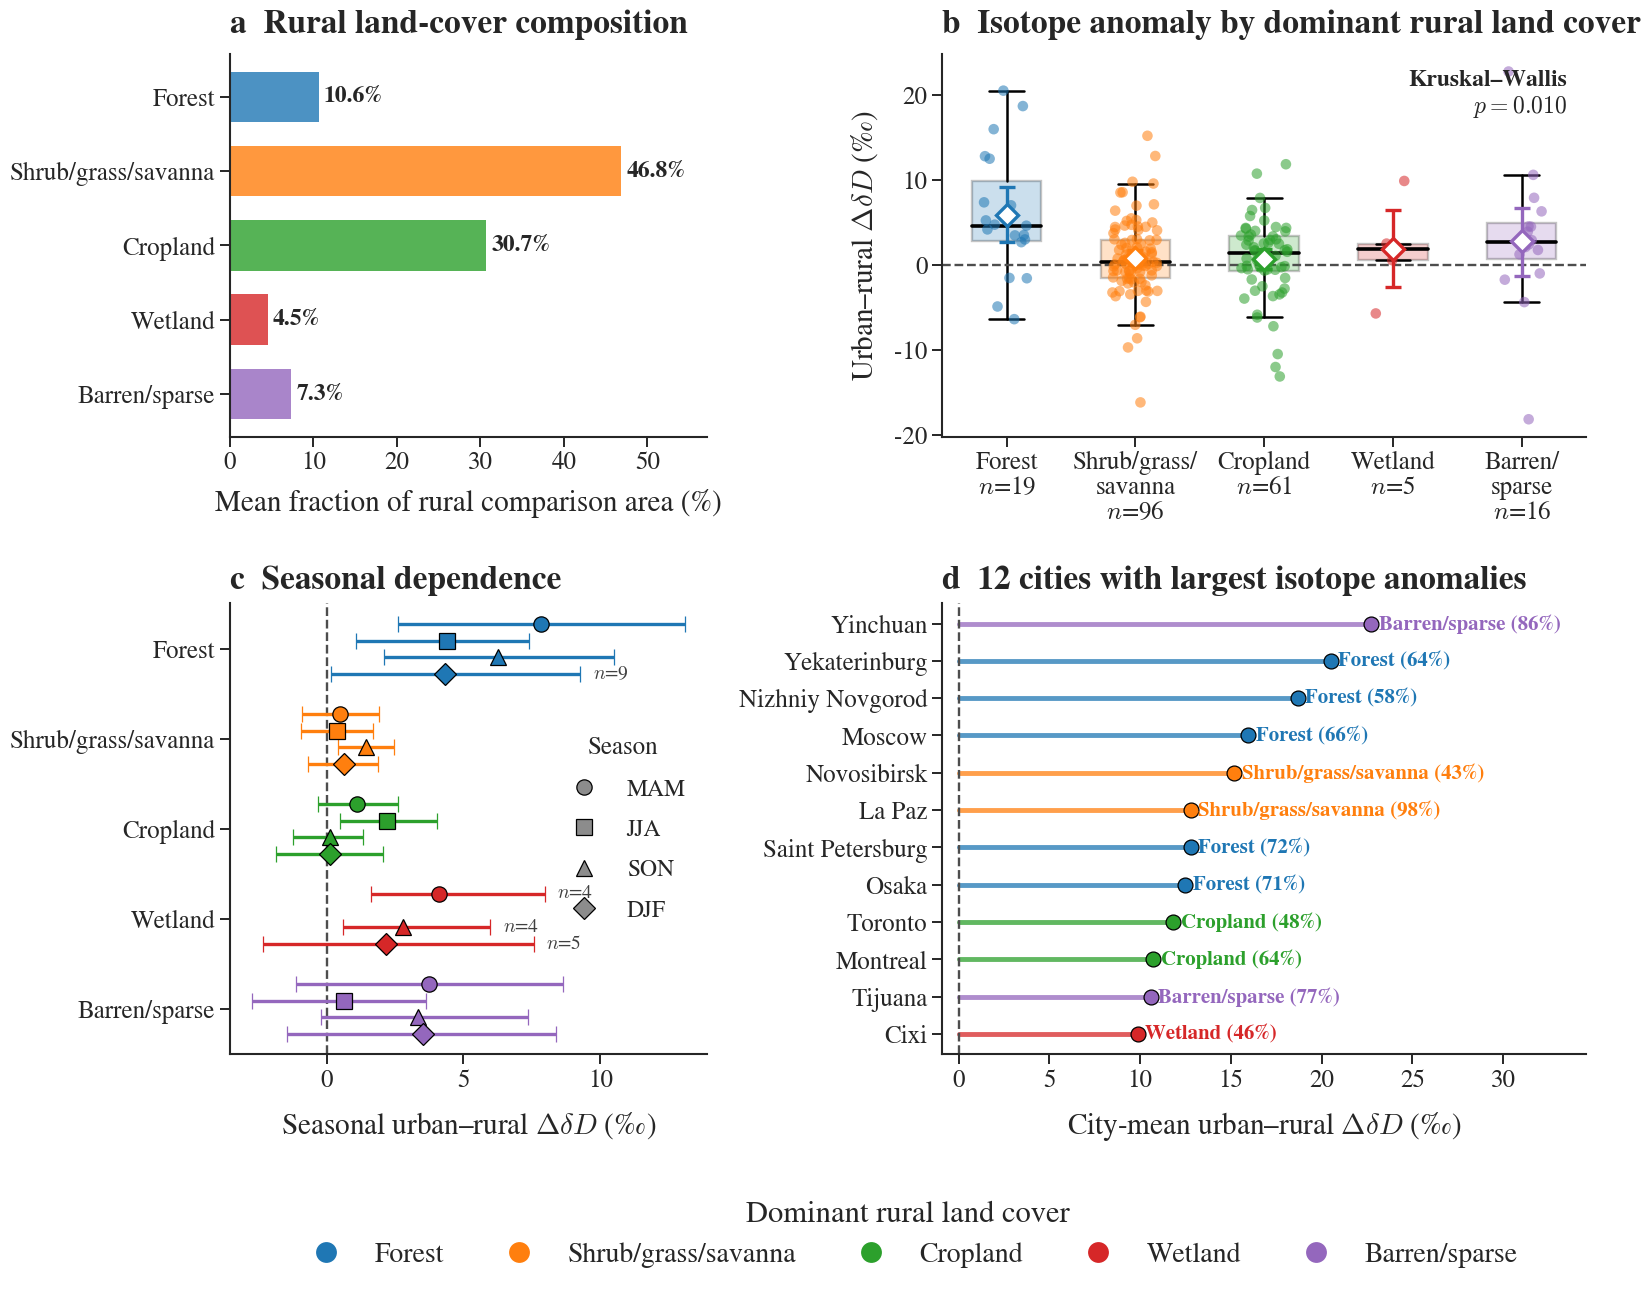

In [30]:
# =============================================================================
# LAND-USE / DELTA-D SUMMARY FIGURE
# HIGH-VISIBILITY + BALANCED-SPACING VERSION
#
# Panels:
#   a) Mean composition of the rural comparison areas
#   b) Overall city Delta-deltaD by dominant rural land-cover category
#   c) Seasonal mean Delta-deltaD with separated confidence intervals
#   d) Cities with the largest mean Delta-deltaD signal
#
# Bottom row:
#   Shared legend for dominant rural land-cover category
#
# Intended to be run as ONE Jupyter notebook cell.
# =============================================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# =============================================================================
# PATHS
# =============================================================================

ROOT = PROJECT_ROOT

RESULTS_DIR = OUTPUT_TABLES_DIR
FIGURE_DIR = OUTPUT_FIGURES_DIR

FIGURE_DIR.mkdir(
    exist_ok=True
)


CITY_SUMMARY_FILE = (
    RESULTS_DIR
    / "landuse_city_summary.csv"
)

CITY_SEASON_FILE = (
    RESULTS_DIR
    / "landuse_city_season_with_city_category.csv"
)

COMPOSITION_FILE = (
    RESULTS_DIR
    / "landuse_overall_composition.csv"
)

STATS_OVERALL_FILE = (
    RESULTS_DIR
    / "landuse_deltaD_stats_overall.csv"
)

STATS_SEASON_FILE = (
    RESULTS_DIR
    / "landuse_deltaD_stats_by_season.csv"
)

TEST_FILE = (
    RESULTS_DIR
    / "landuse_kruskal_tests.csv"
)


# =============================================================================
# LOAD RESULTS
# =============================================================================

city = pd.read_csv(
    CITY_SUMMARY_FILE
)

city_season = pd.read_csv(
    CITY_SEASON_FILE
)

composition = pd.read_csv(
    COMPOSITION_FILE
)

stats_overall = pd.read_csv(
    STATS_OVERALL_FILE
)

stats_season = pd.read_csv(
    STATS_SEASON_FILE
)

tests = pd.read_csv(
    TEST_FILE
)


# =============================================================================
# CATEGORY DEFINITIONS
# =============================================================================

CATEGORY_ORDER = [
    "forest",
    "open_vegetation",
    "cropland",
    "wetland",
    "barren",
    "snow_ice",
]


# Normal labels
CATEGORY_LABELS = {
    "forest":
        "Forest",

    "open_vegetation":
        "Shrub/grass/savanna",

    "cropland":
        "Cropland",

    "wetland":
        "Wetland",

    "barren":
        "Barren/sparse",

    "snow_ice":
        "Snow/ice",
}


# Wrapped labels for crowded x-axis in panel b
CATEGORY_LABELS_AXIS = {
    "forest":
        "Forest",

    "open_vegetation":
        "Shrub/grass/\nsavanna",

    "cropland":
        "Cropland",

    "wetland":
        "Wetland",

    "barren":
        "Barren/\nsparse",

    "snow_ice":
        "Snow/ice",
}


# =============================================================================
# SEASONS
# =============================================================================

SEASONS = [
    "MAM",
    "JJA",
    "SON",
    "DJF",
]


SEASON_MARKERS = {
    "MAM": "o",
    "JJA": "s",
    "SON": "^",
    "DJF": "D",
}


# Small vertical displacement so seasonal error bars do not sit on top
# of one another within each land-cover category.
SEASON_OFFSETS = {
    "MAM": -0.28,
    "JJA": -0.09,
    "SON":  0.09,
    "DJF":  0.28,
}


# =============================================================================
# SETTINGS
# =============================================================================

# Number of high-deltaD cities shown in panel d
TOP_N_CITIES = 12

# Minimum number of cities for a dominant land-cover category to be shown
# in panels b and c.
MIN_N = 5


# =============================================================================
# COLORS
# =============================================================================

default_colors = (
    plt.rcParams[
        "axes.prop_cycle"
    ]
    .by_key()["color"]
)

category_colors = {
    category:
        default_colors[
            i % len(default_colors)
        ]

    for i, category
    in enumerate(CATEGORY_ORDER)
}


# =============================================================================
# CATEGORIES PRESENT IN THE ANALYSIS
# =============================================================================

dominant_counts = (
    city[
        "dominant_landcover"
    ]
    .value_counts()
)

plot_categories = [
    category
    for category in CATEGORY_ORDER
    if dominant_counts.get(
        category,
        0,
    ) >= MIN_N
]


print("Dominant rural-land-cover counts:")

for category in CATEGORY_ORDER:

    print(
        f"  "
        f"{CATEGORY_LABELS[category]:22s} "
        f"{dominant_counts.get(category, 0):3d}"
    )


# =============================================================================
# TYPOGRAPHY
# =============================================================================

plt.rcParams.update(
    {
        "font.size": 19,

        "axes.labelsize": 21,
        "axes.titlesize": 24,

        "xtick.labelsize": 18,
        "ytick.labelsize": 18,

        "legend.fontsize": 17,
        "legend.title_fontsize": 18,

        "axes.linewidth": 1.5,

        "xtick.major.size": 7,
        "ytick.major.size": 7,

        "xtick.major.width": 1.4,
        "ytick.major.width": 1.4,
    }
)


def clean_axis(ax):

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)

    ax.tick_params(
        direction="out",
        top=False,
        right=False,
        labelsize=18,
        width=1.4,
        length=7,
    )


# =============================================================================
# FIGURE LAYOUT
#
# The third row is deliberately very shallow:
# it holds the shared legend without producing the huge empty gap.
# =============================================================================

fig = plt.figure(
    figsize=(17.5, 15.5)
)

gs = fig.add_gridspec(
    3,
    2,

    width_ratios=[
        1.0,
        1.35,
    ],

    height_ratios=[
        1.0,
        1.18,
        0.07,
    ],

    wspace=0.42,

    # Enough vertical space to keep rows separate,
    # while keeping the panel layout compact.
    hspace=0.58,
)


# =============================================================================
# PANEL A
# RURAL LAND-COVER COMPOSITION
# =============================================================================

ax = fig.add_subplot(
    gs[0, 0]
)


comp_plot = (
    composition
    .set_index("category")
    .reindex(CATEGORY_ORDER)
    .reset_index()
)


# Remove categories with effectively zero contribution
comp_plot = comp_plot[
    comp_plot[
        "mean_background_fraction_pct"
    ]
    .fillna(0)
    > 0.01
].copy()


y = np.arange(
    len(comp_plot)
)


for plot_i, (_, row) in enumerate(
    comp_plot.iterrows()
):

    category = row[
        "category"
    ]

    value = float(
        row[
            "mean_background_fraction_pct"
        ]
    )

    ax.barh(
        plot_i,
        value,

        color=category_colors[
            category
        ],

        alpha=0.80,

        height=0.68,
    )

    ax.text(
        value + 0.65,
        plot_i,

        f"{value:.1f}%",

        va="center",

        fontsize=17,

        fontweight="bold",
    )


ax.set_yticks(
    y
)

ax.set_yticklabels(
    [
        CATEGORY_LABELS[c]
        for c
        in comp_plot[
            "category"
        ]
    ],
    fontsize=18,
)

ax.invert_yaxis()


ax.set_xlabel(
    "Mean fraction of rural comparison area (%)",
    fontsize=21,
    labelpad=10,
)

ax.set_title(
    "a  Rural land-cover composition",
    loc="left",
    fontweight="bold",
    fontsize=24,
    pad=15,
)


max_comp = float(
    comp_plot[
        "mean_background_fraction_pct"
    ].max()
)

ax.set_xlim(
    0,
    max_comp * 1.22
)

clean_axis(ax)


# =============================================================================
# PANEL B
# OVERALL CITY DELTA-D BY DOMINANT RURAL LAND COVER
#
# Each point = one city.
# Each city's value = mean Delta-deltaD across its available seasons.
# =============================================================================

ax = fig.add_subplot(
    gs[0, 1]
)

rng = np.random.default_rng(
    20260824
)


for i, category in enumerate(
    plot_categories
):

    values = (
        city.loc[
            city[
                "dominant_landcover"
            ] == category,
            "mean_diff_d_across_seasons",
        ]
        .dropna()
        .to_numpy()
    )


    # -------------------------------------------------------------------------
    # Boxplot
    # -------------------------------------------------------------------------

    bp = ax.boxplot(
        [values],

        positions=[
            i
        ],

        widths=0.54,

        showfliers=False,

        patch_artist=True,

        medianprops={
            "linewidth": 2.6,
            "color": "black",
        },

        whiskerprops={
            "linewidth": 1.8,
        },

        capprops={
            "linewidth": 1.8,
        },

        boxprops={
            "linewidth": 1.7,
        },
    )

    bp["boxes"][0].set_facecolor(
        category_colors[
            category
        ]
    )

    bp["boxes"][0].set_alpha(
        0.23
    )


    # -------------------------------------------------------------------------
    # Individual cities
    # -------------------------------------------------------------------------

    jitter = rng.uniform(
        -0.18,
        0.18,
        len(values),
    )

    ax.scatter(
        i + jitter,
        values,

        s=58,

        color=category_colors[
            category
        ],

        alpha=0.55,

        edgecolors="none",

        zorder=3,
    )


    # -------------------------------------------------------------------------
    # Mean + bootstrap 95% CI
    # -------------------------------------------------------------------------

    s = stats_overall[
        stats_overall[
            "dominant_landcover"
        ] == category
    ]

    if len(s) == 1:

        mean_value = float(
            s[
                "mean_deltaD_permil"
            ].iloc[0]
        )

        ci_low = float(
            s[
                "mean_CI_low_permil"
            ].iloc[0]
        )

        ci_high = float(
            s[
                "mean_CI_high_permil"
            ].iloc[0]
        )

        ax.errorbar(
            i,
            mean_value,

            yerr=[
                [
                    mean_value
                    - ci_low
                ],
                [
                    ci_high
                    - mean_value
                ],
            ],

            fmt="D",

            markersize=11,

            markerfacecolor="white",

            markeredgewidth=2.4,

            markeredgecolor=category_colors[
                category
            ],

            ecolor=category_colors[
                category
            ],

            capsize=6,

            capthick=2.1,

            elinewidth=2.4,

            zorder=6,
        )


# -------------------------------------------------------------------------
# Zero reference
# -------------------------------------------------------------------------

ax.axhline(
    0,
    color="0.30",
    linewidth=1.7,
    linestyle="--",
)


# -------------------------------------------------------------------------
# X-axis labels
# -------------------------------------------------------------------------

xlabels = []

for category in plot_categories:

    n = int(
        dominant_counts.get(
            category,
            0,
        )
    )

    xlabels.append(
        f"{CATEGORY_LABELS_AXIS[category]}\n"
        f"$n$={n}"
    )


ax.set_xticks(
    np.arange(
        len(
            plot_categories
        )
    )
)

ax.set_xticklabels(
    xlabels,
    fontsize=16.5,
    linespacing=1.05,
)


ax.set_ylabel(
    r"Urban–rural $\Delta\delta D$ (‰)",
    fontsize=21,
    labelpad=10,
)

ax.set_title(
    "b  Isotope anomaly by dominant rural land cover",
    loc="left",
    fontweight="bold",
    fontsize=24,
    pad=15,
)


# -------------------------------------------------------------------------
# Overall Kruskal-Wallis result
# -------------------------------------------------------------------------

overall_test = tests[
    tests[
        "scope"
    ] == "overall_city_mean"
]

if (
    len(overall_test) == 1
    and np.isfinite(
        overall_test[
            "p_value"
        ].iloc[0]
    )
):

    p = float(
        overall_test[
            "p_value"
        ].iloc[0]
    )

    if p < 0.001:

        p_text = (
            r"$p<0.001$"
        )

    else:

        p_text = (
            rf"$p={p:.3f}$"
        )

    ax.text(
        0.97,
        0.96,

        "Kruskal–Wallis\n"
        + p_text,

        transform=ax.transAxes,

        ha="right",
        va="top",

        fontsize=17,

        fontweight="bold",
    )


clean_axis(ax)


# =============================================================================
# PANEL C
# SEASONAL DOT-AND-WHISKER PLOT
#
# Color = dominant rural land cover
# Marker shape = season
# Horizontal whisker = bootstrap 95% confidence interval
# =============================================================================

ax = fig.add_subplot(
    gs[1, 0]
)


base_y = np.arange(
    len(
        plot_categories
    )
)


for category_i, category in enumerate(
    plot_categories
):

    for season in SEASONS:

        row = stats_season[
            (
                stats_season[
                    "dominant_landcover"
                ] == category
            )
            &
            (
                stats_season[
                    "season"
                ] == season
            )
        ]

        if len(row) != 1:
            continue


        mean_value = float(
            row[
                "mean_deltaD_permil"
            ].iloc[0]
        )

        ci_low = float(
            row[
                "mean_CI_low_permil"
            ].iloc[0]
        )

        ci_high = float(
            row[
                "mean_CI_high_permil"
            ].iloc[0]
        )

        n = int(
            row[
                "n"
            ].iloc[0]
        )


        if not (
            np.isfinite(
                mean_value
            )
            and np.isfinite(
                ci_low
            )
            and np.isfinite(
                ci_high
            )
        ):
            continue


        yy = (
            category_i
            + SEASON_OFFSETS[
                season
            ]
        )


        ax.errorbar(
            mean_value,
            yy,

            xerr=[
                [
                    mean_value
                    - ci_low
                ],
                [
                    ci_high
                    - mean_value
                ],
            ],

            fmt=SEASON_MARKERS[
                season
            ],

            markersize=11,

            markerfacecolor=category_colors[
                category
            ],

            markeredgecolor="black",

            markeredgewidth=0.9,

            ecolor=category_colors[
                category
            ],

            elinewidth=2.4,

            capsize=5.5,

            capthick=2.0,

            zorder=4,
        )


        # Only annotate very small groups
        if n < 10:

            ax.text(
                ci_high + 0.45,
                yy,

                f"$n$={n}",

                va="center",

                fontsize=14,

                color="0.25",
            )


# -------------------------------------------------------------------------
# Zero reference
# -------------------------------------------------------------------------

ax.axvline(
    0,
    color="0.30",
    linewidth=1.7,
    linestyle="--",
)


# -------------------------------------------------------------------------
# Category labels
# -------------------------------------------------------------------------

ax.set_yticks(
    base_y
)

ax.set_yticklabels(
    [
        CATEGORY_LABELS[c]
        for c in plot_categories
    ],
    fontsize=18,
)

ax.invert_yaxis()


ax.set_xlabel(
    r"Seasonal urban–rural $\Delta\delta D$ (‰)",
    fontsize=21,
    labelpad=12,
)

ax.set_title(
    "c  Seasonal dependence",
    loc="left",
    fontweight="bold",
    fontsize=24,
    pad=10,
)


# -------------------------------------------------------------------------
# Season legend
# -------------------------------------------------------------------------

season_handles = [
    Line2D(
        [0],
        [0],

        marker=SEASON_MARKERS[
            season
        ],

        linestyle="none",

        markerfacecolor="0.55",

        markeredgecolor="black",

        markeredgewidth=0.9,

        markersize=11,

        label=season,
    )

    for season in SEASONS
]


ax.legend(
    handles=season_handles,

    title="Season",

    frameon=False,

    loc="best",

    fontsize=17,

    title_fontsize=18,

    handletextpad=0.8,

    labelspacing=0.8,
)


clean_axis(ax)


# =============================================================================
# PANEL D
# CITIES WITH HIGHEST MEAN DELTA-D
#
# Ranking uses each city's mean anomaly across its available seasons.
# =============================================================================

ax = fig.add_subplot(
    gs[1, 1]
)


top_cities = (
    city[
        [
            "name",
            "dominant_landcover",
            "dominant_landcover_pct",
            "mean_diff_d_across_seasons",
            "n_seasons",
        ]
    ]

    .dropna(
        subset=[
            "mean_diff_d_across_seasons",
            "dominant_landcover",
        ]
    )

    .sort_values(
        "mean_diff_d_across_seasons",
        ascending=False,
    )

    .head(
        TOP_N_CITIES
    )

    .copy()
)


# Reverse plotting order so the largest value is displayed at the top
top_plot = (
    top_cities

    .sort_values(
        "mean_diff_d_across_seasons",
        ascending=True,
    )

    .reset_index(
        drop=True
    )
)


yy = np.arange(
    len(
        top_plot
    )
)


for i, row in top_plot.iterrows():

    category = row[
        "dominant_landcover"
    ]

    value = float(
        row[
            "mean_diff_d_across_seasons"
        ]
    )


    # -------------------------------------------------------------------------
    # Lollipop stem
    # -------------------------------------------------------------------------

    ax.plot(
        [
            0,
            value,
        ],

        [
            i,
            i,
        ],

        linewidth=3.5,

        color=category_colors.get(
            category,
            "0.5",
        ),

        alpha=0.75,

        zorder=1,
    )


    # -------------------------------------------------------------------------
    # City point
    # -------------------------------------------------------------------------

    ax.scatter(
        value,
        i,

        s=115,

        color=category_colors.get(
            category,
            "0.5",
        ),

        edgecolor="black",

        linewidth=0.9,

        zorder=3,
    )


# -------------------------------------------------------------------------
# Zero reference
# -------------------------------------------------------------------------

ax.axvline(
    0,
    color="0.30",
    linewidth=1.7,
    linestyle="--",
)


# -------------------------------------------------------------------------
# City names
# -------------------------------------------------------------------------

ax.set_yticks(
    yy
)

ax.set_yticklabels(
    top_plot[
        "name"
    ],
    fontsize=18,
)


ax.set_xlabel(
    r"City-mean urban–rural $\Delta\delta D$ (‰)",
    fontsize=21,
    labelpad=12,
)

ax.set_title(
    f"d  {TOP_N_CITIES} cities with largest isotope anomalies",
    loc="left",
    fontweight="bold",
    fontsize=24,
    pad=10,
)


# =============================================================================
# LAND-COVER LABEL BESIDE EACH CITY
# =============================================================================

xmax = float(
    top_plot[
        "mean_diff_d_across_seasons"
    ].max()
)

xmin = min(
    0,
    float(
        top_plot[
            "mean_diff_d_across_seasons"
        ].min()
    )
)

span = max(
    xmax - xmin,
    1.0,
)


for i, row in top_plot.iterrows():

    category = row[
        "dominant_landcover"
    ]

    land_pct = float(
        row[
            "dominant_landcover_pct"
        ]
    )

    value = float(
        row[
            "mean_diff_d_across_seasons"
        ]
    )

    label = (
        f"{CATEGORY_LABELS.get(category, category)} "
        f"({land_pct:.0f}%)"
    )

    ax.text(
        value + 0.018 * span,
        i,

        label,

        va="center",

        fontsize=15,

        fontweight="bold",

        color=category_colors.get(
            category,
            "0.30",
        ),
    )


# Leave room for text beside points
ax.set_xlim(
    xmin - 0.04 * span,
    xmax + 0.52 * span,
)

clean_axis(ax)


# =============================================================================
# SHARED LAND-COVER LEGEND
#
# Dedicated but shallow row.
# Larger legend typography than before.
# =============================================================================

legend_ax = fig.add_subplot(
    gs[2, :]
)

legend_ax.axis(
    "off"
)


landcover_handles = [
    Line2D(
        [0],
        [0],

        marker="o",

        linestyle="none",

        markersize=15,

        markerfacecolor=category_colors[
            category
        ],

        markeredgecolor="none",

        label=CATEGORY_LABELS[
            category
        ],
    )

    for category
    in plot_categories
]


legend_ax.legend(
    handles=landcover_handles,

    title="Dominant rural land cover",

    loc="center",

    ncol=min(
        len(
            plot_categories
        ),
        5,
    ),

    frameon=False,

    # Larger bottom legend
    fontsize=20,

    title_fontsize=22,

    handletextpad=0.75,

    columnspacing=1.7,

    borderaxespad=0.0,
)


# =============================================================================
# SAVE
# =============================================================================

PNG_PATH = (
    FIGURE_DIR
    / "Supplement_Figure_6_Rural_land_cover.png"
)

PDF_PATH = (
    FIGURE_DIR
    / "Supplement_Figure_6_Rural_land_cover.pdf"
)


fig.savefig(
    PNG_PATH,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight",
)


print()
print("Saved figure:")

print(
    f"  {PNG_PATH}"
)

print(
    f"  {PDF_PATH}"
)


# =============================================================================
# PRINT TOP-CITY TABLE
# =============================================================================

print()
print(
    "=" * 95
)

print(
    f"TOP {TOP_N_CITIES} CITIES BY MEAN DELTA-D SIGNAL"
)

print(
    "=" * 95
)


top_table = (
    top_cities[
        [
            "name",
            "mean_diff_d_across_seasons",
            "dominant_landcover",
            "dominant_landcover_pct",
            "n_seasons",
        ]
    ]

    .rename(
        columns={
            "name":
                "city",

            "mean_diff_d_across_seasons":
                "mean_deltaD_permil",

            "dominant_landcover":
                "dominant_landuse",

            "dominant_landcover_pct":
                "dominant_landuse_pct",
        }
    )
)


print(
    top_table.to_string(

        index=False,

        formatters={
            "mean_deltaD_permil":
                lambda x: f"{x:.2f}",

            "dominant_landuse_pct":
                lambda x: f"{x:.1f}",
        },
    )
)


# =============================================================================
# DISPLAY
# =============================================================================

plt.show()


## Reviewer check - more detailed MODIS land-cover categories

Repeats the land-cover analysis with more detailed MODIS/IGBP categories to evaluate sensitivity to category aggregation.


In [ ]:
# =============================================================================
# DETAILED MODIS LAND-USE SENSITIVITY — PRIMARY-MASK SAMPLE
#
# Default:
#   - Preserve the broad-category definitions
#   - Split broadly forest-dominated cities into:
#         Forest (deciduous broadleaf-dominant; IGBP 4)
#         Forest (other subtype; IGBP 1,2,3,5)
#
# Optional:
#   SPLIT_DNF = True also separates deciduous needleleaf forest (IGBP 3).
#
# IMPORTANT:
#   * Uses the EXACT rural masks exported by the primary climatological analysis.
#   * Intersects the land-use isotope table with those masks.
#   * The detailed analysis therefore uses the 623 city-seasons represented by the primary masks.
#   * Writes detailed-category outputs to separate files.
# =============================================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import kruskal

warnings.filterwarnings("ignore")

# =============================================================================
# PATHS
# =============================================================================

ROOT = PROJECT_ROOT
SOURCE = SOURCE_DATA_DIR
RESULTS = OUTPUT_TABLES_DIR
FIGURES = OUTPUT_FIGURES_DIR

RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

MODIS_FILE = (
    SOURCE
    / "MCD12C1_IGBP_detailed_climatology_2017-2024_TROPOMIgrid.nc"
)

MASK_FILE = (
    RESULTS
    / "Figure_2_city_grid_masks.csv"
)

# Use isotope anomalies for city-seasons represented in the primary-analysis masks.
ISOTOPE_FILE = (
    RESULTS
    / "landuse_city_season_raw.csv"
)

# Cache for the primary-mask sample.
DETAILED_RAW_FILE = (
    RESULTS
    / "landuse_detailed_city_season_raw_primary_masks.csv"
)

EXTRA_OLD_SAMPLE_FILE = (
    RESULTS
    / "landuse_old_reconstruction_extra_city_seasons.csv"
)

# First run: True.
# Once DETAILED_RAW_FILE exists, this can be changed to False for plotting only.
RECOMPUTE_DETAILED_EXTRACTION = True

# False = DBF separate, DNF included with other forest.
# True  = DBF and DNF both separate.
SPLIT_DNF = False

N_BOOT = 5000
BOOTSTRAP_SEED = 42
MIN_N = 5
TOP_N_CITIES = 12

SEASONS = ["MAM", "JJA", "SON", "DJF"]

SEASON_MARKERS = {
    "MAM": "o",
    "JJA": "s",
    "SON": "^",
    "DJF": "D",
}

SEASON_OFFSETS = {
    "MAM": -0.28,
    "JJA": -0.09,
    "SON":  0.09,
    "DJF":  0.28,
}

TAG = (
    "primary_masks_dbf_dnf_split"
    if SPLIT_DNF
    else "primary_masks_dbf_split"
)

# =============================================================================
# DETAILED IGBP VARIABLES
# =============================================================================

IGBP = {
    0:  "water_percent",
    1:  "evergreen_needleleaf_forest_percent",
    2:  "evergreen_broadleaf_forest_percent",
    3:  "deciduous_needleleaf_forest_percent",
    4:  "deciduous_broadleaf_forest_percent",
    5:  "mixed_forest_percent",
    6:  "closed_shrublands_percent",
    7:  "open_shrublands_percent",
    8:  "woody_savannas_percent",
    9:  "savannas_percent",
    10: "grasslands_percent",
    11: "permanent_wetlands_percent",
    12: "croplands_percent",
    13: "urban_builtup_percent",
    14: "cropland_natural_vegetation_mosaic_percent",
    15: "permanent_snow_ice_percent",
    16: "barren_sparsely_vegetated_percent",
}

LC_VARS = list(IGBP.values())
FOREST_VARS = [IGBP[i] for i in range(1, 6)]
OPEN_VEG_VARS = [IGBP[i] for i in range(6, 11)]

if SPLIT_DNF:
    CATEGORY_ORDER = [
        "forest_dbf",
        "forest_dnf",
        "forest_other",
        "open_vegetation",
        "cropland",
        "wetland",
        "barren",
        "snow_ice",
    ]
else:
    CATEGORY_ORDER = [
        "forest_dbf",
        "forest_other",
        "open_vegetation",
        "cropland",
        "wetland",
        "barren",
        "snow_ice",
    ]

# Labels for composition panel
COMP_LABELS = {
    "forest_dbf": "Deciduous broadleaf\nforest",
    "forest_dnf": "Deciduous needleleaf\nforest",
    "forest_other": "Other forest",
    "open_vegetation": "Shrub/grass/savanna",
    "cropland": "Cropland",
    "wetland": "Wetland",
    "barren": "Barren/sparse",
    "snow_ice": "Snow/ice",
}

# Labels for city groupings
GROUP_LABELS = {
    "forest_dbf": "Forest (DBF-dominant)",
    "forest_dnf": "Forest (DNF-dominant)",
    "forest_other": "Forest (other subtype)",
    "open_vegetation": "Shrub/grass/savanna",
    "cropland": "Cropland",
    "wetland": "Wetland",
    "barren": "Barren/sparse",
    "snow_ice": "Snow/ice",
}

AXIS_LABELS = {
    "forest_dbf": "Forest\n(DBF-dom.)",
    "forest_dnf": "Forest\n(DNF-dom.)",
    "forest_other": "Other\nforest",
    "open_vegetation": "Shrub/grass/\nsavanna",
    "cropland": "Cropland",
    "wetland": "Wetland",
    "barren": "Barren/\nsparse",
    "snow_ice": "Snow/ice",
}

# =============================================================================
# INPUT CHECKS
# =============================================================================

for p in [MODIS_FILE, MASK_FILE, ISOTOPE_FILE]:
    if not p.exists():
        raise FileNotFoundError(f"Missing required input:\n{p}")

# =============================================================================
# EXTRACT DETAILED MODIS OVER EXACT PRIMARY-ANALYSIS RURAL MASKS
# =============================================================================

if RECOMPUTE_DETAILED_EXTRACTION or not DETAILED_RAW_FILE.exists():

    print("=" * 90)
    print("MATCHING OLD LAND-USE TABLE TO PRIMARY-ANALYSIS MASKS")
    print("=" * 90)

    # -------------------------------------------------------------------------
    # Old land-use isotope results
    # -------------------------------------------------------------------------

    iso_all = pd.read_csv(ISOTOPE_FILE)

    required_iso = [
        "season",
        "city_key",
        "name",
        "diff_d_mean",
        "diff_h_mean",
    ]

    missing = [
        c for c in required_iso
        if c not in iso_all.columns
    ]

    if missing:
        raise ValueError(
            f"{ISOTOPE_FILE.name} missing columns: {missing}"
        )

    keep_iso = [
        "season",
        "city_key",
        "name",
        "n_urban",
        "n_buffer",
        "diff_d_mean",
        "diff_h_mean",
        "urban_mean_d",
        "rural_mean_d",
        "urban_mean_h2o",
        "rural_mean_h2o",
    ]

    keep_iso = [
        c for c in keep_iso
        if c in iso_all.columns
    ]

    iso = (
        iso_all[keep_iso]
        .drop_duplicates(
            ["season", "city_key"]
        )
        .copy()
    )

    # -------------------------------------------------------------------------
    # Exact primary masks
    # -------------------------------------------------------------------------

    masks = pd.read_csv(MASK_FILE)

    required_masks = [
        "season",
        "city_key",
        "role",
        "grid_i",
        "grid_j",
    ]

    missing = [
        c for c in required_masks
        if c not in masks.columns
    ]

    if missing:
        raise ValueError(
            f"{MASK_FILE.name} missing columns: {missing}"
        )

    print("\nMask roles found:")
    print(
        masks["role"]
        .astype(str)
        .value_counts()
        .to_string()
    )

    role = (
        masks["role"]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    # Accept the common names used for the comparison pixels.
    rural_role = (
        role.str.contains("rural")
        | role.str.contains("comparison")
        | role.str.contains("control")
        | role.str.contains("buffer")
    )

    rural = (
        masks.loc[
            rural_role,
            [
                "season",
                "city_key",
                "grid_i",
                "grid_j",
            ],
        ]
        .drop_duplicates()
        .copy()
    )

    if len(rural) == 0:
        raise RuntimeError(
            "No rural/comparison pixels were identified in the mask file."
        )

    rural["grid_i"] = (
        rural["grid_i"]
        .astype(np.int64)
    )

    rural["grid_j"] = (
        rural["grid_j"]
        .astype(np.int64)
    )

    # -------------------------------------------------------------------------
    # Compare old land-use universe with current primary-mask universe
    # -------------------------------------------------------------------------

    iso_key_df = (
        iso[
            ["season", "city_key"]
        ]
        .drop_duplicates()
        .reset_index(drop=True)
    )

    mask_key_df = (
        rural[
            ["season", "city_key"]
        ]
        .drop_duplicates()
        .reset_index(drop=True)
    )

    iso_keys = pd.MultiIndex.from_frame(
        iso_key_df
    )

    mask_keys = pd.MultiIndex.from_frame(
        mask_key_df
    )

    extra_in_old_landuse = (
        iso_keys.difference(mask_keys)
    )

    missing_from_old_landuse = (
        mask_keys.difference(iso_keys)
    )

    print()
    print(
        f"Existing broad-land-use city-seasons: "
        f"{len(iso_keys)}"
    )

    print(
        f"Primary-mask city-seasons:            "
        f"{len(mask_keys)}"
    )

    print(
        f"Extra only in old land-use analysis:  "
        f"{len(extra_in_old_landuse)}"
    )

    print(
        f"Primary masks lacking isotope row:    "
        f"{len(missing_from_old_landuse)}"
    )

    # -------------------------------------------------------------------------
    # Save/print the 17 extra old rows
    # -------------------------------------------------------------------------

    if len(extra_in_old_landuse):

        extra_df = pd.DataFrame(
            extra_in_old_landuse.tolist(),
            columns=[
                "season",
                "city_key",
            ],
        )

        extra_df = (
            extra_df
            .merge(
                iso[
                    [
                        "season",
                        "city_key",
                        "name",
                    ]
                ],
                on=[
                    "season",
                    "city_key",
                ],
                how="left",
            )
            .sort_values(
                [
                    "city_key",
                    "season",
                ]
            )
            .reset_index(drop=True)
        )

        extra_df.to_csv(
            EXTRA_OLD_SAMPLE_FILE,
            index=False,
        )

        print(
            "\nCity-seasons present only in "
            "the old broad-land-use reconstruction:"
        )

        print(
            extra_df.to_string(
                index=False
            )
        )

        print(
            f"\nSaved diagnostic list:\n"
            f"  {EXTRA_OLD_SAMPLE_FILE}"
        )

    # -------------------------------------------------------------------------
    # This would indicate the opposite and more problematic mismatch:
    # a primary mask for which we do not have a climatological isotope anomaly.
    # -------------------------------------------------------------------------

    if len(missing_from_old_landuse):

        missing_df = pd.DataFrame(
            missing_from_old_landuse.tolist(),
            columns=[
                "season",
                "city_key",
            ],
        )

        raise RuntimeError(
            "Some primary-analysis masks have no corresponding "
            "isotope result in the old land-use table:\n\n"
            + missing_df.to_string(index=False)
        )

    # -------------------------------------------------------------------------
    # Canonical sample = PRIMARY MASK SAMPLE.
    #
    # This deliberately discards the 17 extra old-land-use city-seasons.
    # -------------------------------------------------------------------------

    iso = (
        iso
        .merge(
            mask_key_df.assign(
                _in_primary_masks=True
            ),
            on=[
                "season",
                "city_key",
            ],
            how="inner",
            validate="one_to_one",
        )
        .drop(
            columns="_in_primary_masks"
        )
        .reset_index(drop=True)
    )

    print(
        f"\nCity-seasons retained for detailed "
        f"land-use analysis: {len(iso)}"
    )

    if len(iso) != len(mask_key_df):

        raise RuntimeError(
            f"Expected {len(mask_key_df)} city-seasons "
            f"after matching primary masks, but found {len(iso)}."
        )

    # Keep only rural-mask rows belonging to this exact intersection.
    rural = (
        rural
        .merge(
            iso[
                [
                    "season",
                    "city_key",
                ]
            ].drop_duplicates(),
            on=[
                "season",
                "city_key",
            ],
            how="inner",
            validate="many_to_one",
        )
        .drop_duplicates(
            [
                "season",
                "city_key",
                "grid_i",
                "grid_j",
            ]
        )
        .reset_index(drop=True)
    )

    # -------------------------------------------------------------------------
    # Extract each unique TROPOMI pixel only once from detailed MODIS.
    # -------------------------------------------------------------------------

    print("\n" + "=" * 90)
    print("EXTRACTING DETAILED MODIS FRACTIONS")
    print("=" * 90)

    points = (
        rural[
            [
                "grid_i",
                "grid_j",
            ]
        ]
        .drop_duplicates()
        .reset_index(drop=True)
    )

    print(
        f"Unique rural TROPOMI cells to sample: "
        f"{len(points):,}"
    )

    with xr.open_dataset(
        MODIS_FILE
    ) as ds:

        missing = [
            v for v in LC_VARS
            if v not in ds
        ]

        if missing:
            raise ValueError(
                "Detailed MODIS file is missing variables:\n"
                + "\n".join(missing)
            )

        if points["grid_i"].min() < 0:
            raise IndexError(
                "Negative grid_i found."
            )

        if points["grid_j"].min() < 0:
            raise IndexError(
                "Negative grid_j found."
            )

        if (
            points["grid_i"].max()
            >= ds.sizes["lat"]
        ):
            raise IndexError(
                "grid_i exceeds MODIS latitude dimension."
            )

        if (
            points["grid_j"].max()
            >= ds.sizes["lon"]
        ):
            raise IndexError(
                "grid_j exceeds MODIS longitude dimension."
            )

        ilat = xr.DataArray(
            points["grid_i"].to_numpy(),
            dims="points",
        )

        ilon = xr.DataArray(
            points["grid_j"].to_numpy(),
            dims="points",
        )

        point_values = (
            points.copy()
        )

        for i, var in enumerate(
            LC_VARS,
            start=1,
        ):

            print(
                f"  {i:2d}/17  {var}"
            )

            point_values[var] = (
                np.asarray(
                    ds[var]
                    .isel(
                        lat=ilat,
                        lon=ilon,
                    )
                    .values,
                    dtype=float,
                )
            )

    # -------------------------------------------------------------------------
    # MODIS QC / closure
    # -------------------------------------------------------------------------

    M = (
        point_values[
            LC_VARS
        ]
        .to_numpy(
            dtype=float
        )
    )

    valid = np.all(
        np.isfinite(M),
        axis=1,
    )

    valid &= np.all(
        (M >= 0)
        & (M <= 100),
        axis=1,
    )

    closure = np.sum(
        M,
        axis=1,
    )

    print()
    print(
        f"Valid detailed-MODIS cells: "
        f"{valid.sum():,} / {len(valid):,}"
    )

    print(
        f"Mean IGBP closure: "
        f"{np.mean(closure[valid]):.4f}%"
    )

    print(
        f"Mean |closure - 100|: "
        f"{np.mean(np.abs(closure[valid] - 100)):.4f}%"
    )

    point_values.loc[
        ~valid,
        LC_VARS,
    ] = np.nan

    # -------------------------------------------------------------------------
    # Attach MODIS values to every rural mask pixel.
    # -------------------------------------------------------------------------

    rural_detail = (
        rural
        .merge(
            point_values,
            on=[
                "grid_i",
                "grid_j",
            ],
            how="left",
            validate="many_to_one",
        )
    )

    group_cols = [
        "season",
        "city_key",
    ]

    lc_mean = (
        rural_detail
        .groupby(
            group_cols,
            as_index=False,
        )[LC_VARS]
        .mean()
    )

    n_mask = (
        rural_detail
        .groupby(
            group_cols
        )
        .size()
        .rename(
            "n_rural_mask_pixels"
        )
        .reset_index()
    )

    # Count pixels for which all 17 detailed classes are finite.
    pixel_good = np.all(
        np.isfinite(
            rural_detail[
                LC_VARS
            ].to_numpy(
                dtype=float
            )
        ),
        axis=1,
    )

    tmp = (
        rural_detail[
            group_cols
        ]
        .copy()
    )

    tmp[
        "_valid_modis"
    ] = pixel_good.astype(int)

    n_lc = (
        tmp
        .groupby(
            group_cols,
            as_index=False,
        )[
            "_valid_modis"
        ]
        .sum()
        .rename(
            columns={
                "_valid_modis":
                    "n_landcover_pixels"
            }
        )
    )

    lc_mean = (
        lc_mean
        .merge(
            n_mask,
            on=group_cols,
            how="left",
        )
        .merge(
            n_lc,
            on=group_cols,
            how="left",
        )
    )

    # -------------------------------------------------------------------------
    # Merge exact 623-sample isotope values with MODIS composition.
    # -------------------------------------------------------------------------

    detailed_raw = (
        iso
        .merge(
            lc_mean,
            on=[
                "season",
                "city_key",
            ],
            how="left",
            validate="one_to_one",
        )
    )

    no_modis = (
        detailed_raw[
            LC_VARS
        ]
        .isna()
        .all(axis=1)
    )

    if no_modis.any():

        bad = (
            detailed_raw.loc[
                no_modis,
                [
                    "season",
                    "city_key",
                    "name",
                ],
            ]
        )

        raise RuntimeError(
            "Some primary-mask city-seasons have no valid "
            "detailed MODIS information:\n\n"
            + bad.to_string(index=False)
        )

    detailed_raw.to_csv(
        DETAILED_RAW_FILE,
        index=False,
    )

    print(
        f"\nSaved detailed raw city-season table:\n"
        f"  {DETAILED_RAW_FILE}"
    )

else:

    print(
        f"Loading cached detailed extraction:\n"
        f"  {DETAILED_RAW_FILE}"
    )

    detailed_raw = pd.read_csv(
        DETAILED_RAW_FILE
    )

# =============================================================================
# BUILD ONE CLIMATOLOGICAL LAND-COVER COMPOSITION PER CITY
# =============================================================================

print("\n" + "=" * 90)
print("BUILDING CITY-LEVEL LAND-COVER CLASSIFICATION")
print("=" * 90)

# Mean detailed MODIS fractions over available seasons for each city.
composition = (
    detailed_raw
    .groupby(
        [
            "city_key",
            "name",
        ],
        as_index=False,
    )[LC_VARS]
    .mean()
)

# Isotope summary: one value per city for overall inference.
isotope = (
    detailed_raw
    .groupby(
        [
            "city_key",
            "name",
        ],
        as_index=False,
    )
    .agg(
        n_seasons=(
            "season",
            "nunique",
        ),
        mean_diff_d_across_seasons=(
            "diff_d_mean",
            "mean",
        ),
        median_diff_d_across_seasons=(
            "diff_d_mean",
            "median",
        ),
        mean_diff_h_across_seasons=(
            "diff_h_mean",
            "mean",
        ),
    )
)

city = (
    composition
    .merge(
        isotope,
        on=[
            "city_key",
            "name",
        ],
        how="inner",
    )
)

# =============================================================================
# RAW BROAD COMPONENTS
# =============================================================================

city[
    "raw_forest_total_pct"
] = (
    city[
        FOREST_VARS
    ]
    .sum(axis=1)
)

city[
    "raw_dbf_pct"
] = city[
    IGBP[4]
]

city[
    "raw_dnf_pct"
] = city[
    IGBP[3]
]

city[
    "raw_open_vegetation_pct"
] = (
    city[
        OPEN_VEG_VARS
    ]
    .sum(axis=1)
)

city[
    "raw_cropland_pct"
] = (
    city[
        IGBP[12]
    ]
    + city[
        IGBP[14]
    ]
)

city[
    "raw_wetland_pct"
] = city[
    IGBP[11]
]

city[
    "raw_barren_pct"
] = city[
    IGBP[16]
]

city[
    "raw_snow_ice_pct"
] = city[
    IGBP[15]
]

city[
    "raw_water_pct"
] = city[
    IGBP[0]
]

city[
    "raw_urban_pct"
] = city[
    IGBP[13]
]

if SPLIT_DNF:

    city[
        "raw_forest_other_pct"
    ] = (
        city[
            [
                IGBP[1],
                IGBP[2],
                IGBP[5],
            ]
        ]
        .sum(axis=1)
    )

else:

    city[
        "raw_forest_other_pct"
    ] = (
        city[
            [
                IGBP[1],
                IGBP[2],
                IGBP[3],
                IGBP[5],
            ]
        ]
        .sum(axis=1)
    )

# =============================================================================
# TERRESTRIAL NONURBAN BACKGROUND NORMALIZATION
#
# Same conceptual normalization as the broad analysis:
# exclude water and MODIS urban, then renormalize terrestrial background.
# =============================================================================

city[
    "background_raw_total_pct"
] = (
    city[
        "raw_forest_total_pct"
    ]
    + city[
        "raw_open_vegetation_pct"
    ]
    + city[
        "raw_cropland_pct"
    ]
    + city[
        "raw_wetland_pct"
    ]
    + city[
        "raw_barren_pct"
    ]
    + city[
        "raw_snow_ice_pct"
    ]
)

if (
    city[
        "background_raw_total_pct"
    ] <= 0
).any():

    raise RuntimeError(
        "At least one city has zero terrestrial-background fraction."
    )

den = (
    city[
        "background_raw_total_pct"
    ]
)

# Detailed forest fractions for panel a
city[
    "background_forest_dbf_pct"
] = (
    100
    * city[
        "raw_dbf_pct"
    ]
    / den
)

if SPLIT_DNF:

    city[
        "background_forest_dnf_pct"
    ] = (
        100
        * city[
            "raw_dnf_pct"
        ]
        / den
    )

city[
    "background_forest_other_pct"
] = (
    100
    * city[
        "raw_forest_other_pct"
    ]
    / den
)

city[
    "background_open_vegetation_pct"
] = (
    100
    * city[
        "raw_open_vegetation_pct"
    ]
    / den
)

city[
    "background_cropland_pct"
] = (
    100
    * city[
        "raw_cropland_pct"
    ]
    / den
)

city[
    "background_wetland_pct"
] = (
    100
    * city[
        "raw_wetland_pct"
    ]
    / den
)

city[
    "background_barren_pct"
] = (
    100
    * city[
        "raw_barren_pct"
    ]
    / den
)

city[
    "background_snow_ice_pct"
] = (
    100
    * city[
        "raw_snow_ice_pct"
    ]
    / den
)

# =============================================================================
# PRESERVE ORIGINAL BROAD CLASSIFICATION FIRST
#
# Critical point:
# We first decide whether the city is broadly forest/open vegetation/etc.
# Only a BROADLY FOREST-DOMINATED city is split into a forest subtype.
# =============================================================================

city[
    "broad_forest_pct"
] = (
    100
    * city[
        "raw_forest_total_pct"
    ]
    / den
)

city[
    "broad_open_vegetation_pct"
] = city[
    "background_open_vegetation_pct"
]

city[
    "broad_cropland_pct"
] = city[
    "background_cropland_pct"
]

city[
    "broad_wetland_pct"
] = city[
    "background_wetland_pct"
]

city[
    "broad_barren_pct"
] = city[
    "background_barren_pct"
]

city[
    "broad_snow_ice_pct"
] = city[
    "background_snow_ice_pct"
]

BROAD = [
    "forest",
    "open_vegetation",
    "cropland",
    "wetland",
    "barren",
    "snow_ice",
]

BROAD_COLS = [
    f"broad_{c}_pct"
    for c in BROAD
]

bmat = (
    city[
        BROAD_COLS
    ]
    .to_numpy(
        dtype=float
    )
)

border = np.argsort(
    bmat,
    axis=1,
)

btop = (
    border[:, -1]
)

bsecond = (
    border[:, -2]
)

city[
    "broad_dominant_landcover"
] = (
    np.array(
        BROAD,
        dtype=object,
    )[
        btop
    ]
)

city[
    "dominant_landcover_pct"
] = (
    bmat[
        np.arange(
            len(city)
        ),
        btop,
    ]
)

city[
    "dominance_margin_pct"
] = (
    bmat[
        np.arange(
            len(city)
        ),
        btop,
    ]
    -
    bmat[
        np.arange(
            len(city)
        ),
        bsecond,
    ]
)

# =============================================================================
# FOREST SUBTYPE
# =============================================================================

fmat = (
    city[
        FOREST_VARS
    ]
    .to_numpy(
        dtype=float
    )
)

# Columns correspond to IGBP classes 1...5
forest_winner = (
    np.argmax(
        fmat,
        axis=1,
    )
    + 1
)

city[
    "dominant_forest_igbp_class"
] = forest_winner

city[
    "dbf_share_of_forest_pct"
] = np.where(
    city[
        "raw_forest_total_pct"
    ] > 0,

    100
    * city[
        "raw_dbf_pct"
    ]
    / city[
        "raw_forest_total_pct"
    ],

    np.nan,
)

city[
    "dnf_share_of_forest_pct"
] = np.where(
    city[
        "raw_forest_total_pct"
    ] > 0,

    100
    * city[
        "raw_dnf_pct"
    ]
    / city[
        "raw_forest_total_pct"
    ],

    np.nan,
)

# Hierarchical classification
dominant = []

for broad, fclass in zip(
    city[
        "broad_dominant_landcover"
    ],
    forest_winner,
):

    if broad != "forest":

        dominant.append(
            broad
        )

    elif fclass == 4:

        dominant.append(
            "forest_dbf"
        )

    elif (
        SPLIT_DNF
        and fclass == 3
    ):

        dominant.append(
            "forest_dnf"
        )

    else:

        dominant.append(
            "forest_other"
        )

city[
    "dominant_landcover"
] = dominant

# =============================================================================
# MERGE STABLE CITY CLASSIFICATION BACK TO EACH SEASON
# =============================================================================

classification_cols = [
    "city_key",
    "dominant_landcover",
    "broad_dominant_landcover",
    "dominant_landcover_pct",
    "dominance_margin_pct",
    "dominant_forest_igbp_class",
    "dbf_share_of_forest_pct",
    "dnf_share_of_forest_pct",
]

classification_cols += [
    f"background_{c}_pct"
    for c in CATEGORY_ORDER
]

city_season = (
    detailed_raw
    .merge(
        city[
            classification_cols
        ],
        on="city_key",
        how="left",
        validate="many_to_one",
    )
)

# =============================================================================
# STATISTICAL HELPERS
# =============================================================================

def bootstrap_ci(
    values,
    seed,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    n = len(values)

    if n == 0:
        return np.nan, np.nan

    if n == 1:
        return values[0], values[0]

    rng = np.random.default_rng(
        seed
    )

    idx = rng.integers(
        0,
        n,
        size=(
            N_BOOT,
            n,
        ),
    )

    means = (
        values[
            idx
        ]
        .mean(axis=1)
    )

    return tuple(
        np.percentile(
            means,
            [
                2.5,
                97.5,
            ],
        )
    )


def summarize_groups(
    df,
    value_col,
    extra=None,
):

    rows = []

    for i, cat in enumerate(
        CATEGORY_ORDER
    ):

        values = (
            df.loc[
                df[
                    "dominant_landcover"
                ] == cat,
                value_col,
            ]
            .dropna()
            .to_numpy()
        )

        if len(values) == 0:
            continue

        lo, hi = bootstrap_ci(
            values,
            BOOTSTRAP_SEED + i,
        )

        row = {
            "dominant_landcover":
                cat,

            "label":
                GROUP_LABELS[
                    cat
                ].replace(
                    "\n",
                    " ",
                ),

            "n":
                len(values),

            "mean_deltaD_permil":
                float(
                    np.mean(values)
                ),

            "median_deltaD_permil":
                float(
                    np.median(values)
                ),

            "std_deltaD_permil":
                float(
                    np.std(
                        values,
                        ddof=1,
                    )
                )
                if len(values) > 1
                else np.nan,

            "mean_CI_low_permil":
                float(lo),

            "mean_CI_high_permil":
                float(hi),

            "fraction_positive":
                float(
                    np.mean(
                        values > 0
                    )
                ),
        }

        if extra is not None:
            row.update(extra)

        rows.append(row)

    return pd.DataFrame(
        rows
    )


def kruskal_record(
    df,
    value_col,
    scope,
):

    groups = []
    names = []

    for cat in CATEGORY_ORDER:

        values = (
            df.loc[
                df[
                    "dominant_landcover"
                ] == cat,
                value_col,
            ]
            .dropna()
            .to_numpy()
        )

        if len(values) >= MIN_N:

            groups.append(
                values
            )

            names.append(
                cat
            )

    if len(groups) < 2:

        return {
            "scope":
                scope,

            "n_groups":
                len(groups),

            "groups":
                ";".join(names),

            "n_total":
                int(
                    sum(
                        len(g)
                        for g in groups
                    )
                ),

            "kruskal_H":
                np.nan,

            "p_value":
                np.nan,
        }

    H, p = kruskal(
        *groups
    )

    return {
        "scope":
            scope,

        "n_groups":
            len(groups),

        "groups":
            ";".join(names),

        "n_total":
            int(
                sum(
                    len(g)
                    for g in groups
                )
            ),

        "kruskal_H":
            float(H),

        "p_value":
            float(p),
    }

# =============================================================================
# COMPOSITION SUMMARY
# =============================================================================

composition_rows = []

n_cities = (
    len(city)
)

for cat in CATEGORY_ORDER:

    frac = (
        city[
            f"background_{cat}_pct"
        ]
    )

    n_dom = int(
        (
            city[
                "dominant_landcover"
            ] == cat
        ).sum()
    )

    composition_rows.append(
        {
            "category":
                cat,

            "label":
                COMP_LABELS[
                    cat
                ].replace(
                    "\n",
                    " ",
                ),

            "mean_background_fraction_pct":
                float(
                    frac.mean()
                ),

            "median_background_fraction_pct":
                float(
                    frac.median()
                ),

            "n_dominant_cities":
                n_dom,

            "pct_of_cities_dominant":
                (
                    100
                    * n_dom
                    / n_cities
                )
                if n_cities
                else np.nan,
        }
    )

composition_summary = pd.DataFrame(
    composition_rows
)

# =============================================================================
# DELTA-D STATISTICS
# =============================================================================

stats_overall = summarize_groups(
    city,
    "mean_diff_d_across_seasons",
)

seasonal_stats = []

for season in SEASONS:

    sdf = (
        city_season[
            city_season[
                "season"
            ] == season
        ]
    )

    seasonal_stats.append(
        summarize_groups(
            sdf,
            "diff_d_mean",
            {
                "season":
                    season
            },
        )
    )

stats_season = pd.concat(
    seasonal_stats,
    ignore_index=True,
)

tests = pd.DataFrame(
    [
        kruskal_record(
            city,
            "mean_diff_d_across_seasons",
            "overall_city_mean",
        )
    ]
    +
    [
        kruskal_record(
            city_season[
                city_season[
                    "season"
                ] == season
            ],
            "diff_d_mean",
            season,
        )
        for season in SEASONS
    ]
)

# =============================================================================
# SAVE NEW TABLES
# =============================================================================

CITY_OUT = (
    RESULTS
    / f"landuse_{TAG}_city_summary.csv"
)

CITY_SEASON_OUT = (
    RESULTS
    / f"landuse_{TAG}_city_season_with_category.csv"
)

COMP_OUT = (
    RESULTS
    / f"landuse_{TAG}_overall_composition.csv"
)

STAT_OUT = (
    RESULTS
    / f"landuse_{TAG}_deltaD_stats_overall.csv"
)

STAT_SEASON_OUT = (
    RESULTS
    / f"landuse_{TAG}_deltaD_stats_by_season.csv"
)

TEST_OUT = (
    RESULTS
    / f"landuse_{TAG}_kruskal_tests.csv"
)

city.to_csv(
    CITY_OUT,
    index=False,
)

city_season.to_csv(
    CITY_SEASON_OUT,
    index=False,
)

composition_summary.to_csv(
    COMP_OUT,
    index=False,
)

stats_overall.to_csv(
    STAT_OUT,
    index=False,
)

stats_season.to_csv(
    STAT_SEASON_OUT,
    index=False,
)

tests.to_csv(
    TEST_OUT,
    index=False,
)

# =============================================================================
# CONSOLE SUMMARY
# =============================================================================

dominant_counts = (
    city[
        "dominant_landcover"
    ]
    .value_counts()
)

print("\n" + "=" * 90)
print("DETAILED FOREST-SPLIT LAND-USE ANALYSIS")
print("=" * 90)

print(
    f"Unique cities:       "
    f"{city['city_key'].nunique()}"
)

print(
    f"City-season records: "
    f"{len(city_season)}"
)

print(
    f"SPLIT_DNF:           "
    f"{SPLIT_DNF}"
)

print(
    "\nCity-seasons by season:"
)

print(
    city_season[
        "season"
    ]
    .value_counts()
    .reindex(
        SEASONS
    )
    .to_string()
)

print(
    "\nDominant rural-land-cover counts:"
)

for cat in CATEGORY_ORDER:

    print(
        f"  "
        f"{GROUP_LABELS[cat]:35s} "
        f"{dominant_counts.get(cat, 0):3d}"
    )

print(
    "\nMean rural-background composition:"
)

print(
    composition_summary[
        [
            "label",
            "mean_background_fraction_pct",
            "n_dominant_cities",
        ]
    ]
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}",
    )
)

print(
    "\nDelta-D by dominant rural land cover:"
)

print(
    stats_overall[
        [
            "label",
            "n",
            "mean_deltaD_permil",
            "median_deltaD_permil",
            "mean_CI_low_permil",
            "mean_CI_high_permil",
            "fraction_positive",
        ]
    ]
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}",
    )
)

print(
    "\nKruskal-Wallis tests:"
)

print(
    tests.to_string(
        index=False,
        float_format=lambda x: f"{x:.5g}",
    )
)

# Forest subtype diagnostic
forest_city = (
    city[
        city[
            "broad_dominant_landcover"
        ] == "forest"
    ]
    .copy()
)

if len(forest_city):

    print(
        "\nDominant individual forest subtype "
        "among broadly forest-dominated cities:"
    )

    subtype_counts = (
        forest_city[
            "dominant_forest_igbp_class"
        ]
        .value_counts()
        .sort_index()
        .rename(
            index={
                1:
                    "1 evergreen needleleaf",

                2:
                    "2 evergreen broadleaf",

                3:
                    "3 deciduous needleleaf",

                4:
                    "4 deciduous broadleaf",

                5:
                    "5 mixed forest",
            }
        )
    )

    print(
        subtype_counts.to_string()
    )

# =============================================================================
# FIGURE SETTINGS
# =============================================================================

plt.rcParams.update(
    {
        "font.size":
            19,

        "axes.labelsize":
            21,

        "axes.titlesize":
            24,

        "xtick.labelsize":
            18,

        "ytick.labelsize":
            18,

        "legend.fontsize":
            17,

        "legend.title_fontsize":
            18,

        "axes.linewidth":
            1.5,

        "xtick.major.size":
            7,

        "ytick.major.size":
            7,

        "xtick.major.width":
            1.4,

        "ytick.major.width":
            1.4,
    }
)


def clean_axis(ax):

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)

    ax.spines[
        "left"
    ].set_linewidth(1.5)

    ax.spines[
        "bottom"
    ].set_linewidth(1.5)

    ax.tick_params(
        direction="out",
        top=False,
        right=False,
        labelsize=18,
        width=1.4,
        length=7,
    )


default_colors = (
    plt.rcParams[
        "axes.prop_cycle"
    ]
    .by_key()[
        "color"
    ]
)

category_colors = {
    cat:
        default_colors[
            i
            % len(
                default_colors
            )
        ]

    for i, cat
    in enumerate(
        CATEGORY_ORDER
    )
}

plot_categories = [
    cat
    for cat
    in CATEGORY_ORDER
    if dominant_counts.get(
        cat,
        0,
    ) >= MIN_N
]

print(
    "\nCategories plotted in isotope panels "
    f"(n >= {MIN_N} cities):"
)

for cat in plot_categories:

    print(
        f"  {GROUP_LABELS[cat]}: "
        f"n={dominant_counts[cat]}"
    )

# =============================================================================
# FIGURE LAYOUT
# =============================================================================

fig = plt.figure(
    figsize=(
        18.5,
        15.5,
    )
)

gs = fig.add_gridspec(
    3,
    2,

    width_ratios=[
        1.0,
        1.42,
    ],

    height_ratios=[
        1.0,
        1.18,
        0.10,
    ],

    wspace=0.40,
    hspace=0.58,
)

# =============================================================================
# PANEL A — COMPOSITION
# =============================================================================

ax = fig.add_subplot(
    gs[
        0,
        0,
    ]
)

comp_plot = (
    composition_summary
    .set_index(
        "category"
    )
    .reindex(
        CATEGORY_ORDER
    )
    .reset_index()
)

comp_plot = (
    comp_plot[
        comp_plot[
            "mean_background_fraction_pct"
        ]
        .fillna(0)
        > 0.01
    ]
    .reset_index(
        drop=True
    )
)

for i, row in comp_plot.iterrows():

    cat = (
        row[
            "category"
        ]
    )

    value = float(
        row[
            "mean_background_fraction_pct"
        ]
    )

    ax.barh(
        i,
        value,

        color=
            category_colors[
                cat
            ],

        alpha=0.80,

        height=0.68,
    )

    ax.text(
        value + 0.55,
        i,

        f"{value:.1f}%",

        va="center",

        fontsize=16,

        fontweight="bold",
    )

ax.set_yticks(
    np.arange(
        len(
            comp_plot
        )
    )
)

ax.set_yticklabels(
    [
        COMP_LABELS[
            cat
        ]
        for cat
        in comp_plot[
            "category"
        ]
    ],
    fontsize=17,
)

ax.invert_yaxis()

ax.set_xlabel(
    "Mean fraction of rural comparison area (%)",
    labelpad=10,
)

ax.set_title(
    "a  Rural land-cover composition",
    loc="left",
    fontweight="bold",
    pad=15,
)

max_comp = float(
    comp_plot[
        "mean_background_fraction_pct"
    ]
    .max()
)

ax.set_xlim(
    0,
    max(
        1,
        max_comp * 1.25,
    ),
)

clean_axis(ax)

# =============================================================================
# PANEL B — OVERALL CITY DELTA-D
# =============================================================================

ax = fig.add_subplot(
    gs[
        0,
        1,
    ]
)

rng = np.random.default_rng(
    20260831
)

for i, cat in enumerate(
    plot_categories
):

    values = (
        city.loc[
            city[
                "dominant_landcover"
            ] == cat,
            "mean_diff_d_across_seasons",
        ]
        .dropna()
        .to_numpy()
    )

    bp = ax.boxplot(
        [
            values
        ],

        positions=[
            i
        ],

        widths=0.54,

        showfliers=False,

        patch_artist=True,

        medianprops={
            "linewidth":
                2.6,
            "color":
                "black",
        },

        whiskerprops={
            "linewidth":
                1.8,
        },

        capprops={
            "linewidth":
                1.8,
        },

        boxprops={
            "linewidth":
                1.7,
        },
    )

    bp[
        "boxes"
    ][0].set_facecolor(
        category_colors[
            cat
        ]
    )

    bp[
        "boxes"
    ][0].set_alpha(
        0.23
    )

    jitter = rng.uniform(
        -0.18,
        0.18,
        len(values),
    )

    ax.scatter(
        i + jitter,
        values,

        s=58,

        color=
            category_colors[
                cat
            ],

        alpha=0.55,

        edgecolors="none",

        zorder=3,
    )

    stat = (
        stats_overall[
            stats_overall[
                "dominant_landcover"
            ] == cat
        ]
    )

    if len(stat) == 1:

        mean_value = float(
            stat[
                "mean_deltaD_permil"
            ].iloc[0]
        )

        ci_low = float(
            stat[
                "mean_CI_low_permil"
            ].iloc[0]
        )

        ci_high = float(
            stat[
                "mean_CI_high_permil"
            ].iloc[0]
        )

        ax.errorbar(
            i,
            mean_value,

            yerr=[
                [
                    mean_value
                    - ci_low
                ],
                [
                    ci_high
                    - mean_value
                ],
            ],

            fmt="D",

            markersize=11,

            markerfacecolor=
                "white",

            markeredgecolor=
                category_colors[
                    cat
                ],

            markeredgewidth=
                2.4,

            ecolor=
                category_colors[
                    cat
                ],

            capsize=6,

            capthick=2.1,

            elinewidth=2.4,

            zorder=6,
        )

ax.axhline(
    0,
    color="0.30",
    linewidth=1.7,
    linestyle="--",
)

ax.set_xticks(
    np.arange(
        len(
            plot_categories
        )
    )
)

ax.set_xticklabels(
    [
        f"{AXIS_LABELS[cat]}\n"
        f"$n$={dominant_counts.get(cat, 0)}"

        for cat
        in plot_categories
    ],

    fontsize=15.5,

    linespacing=1.05,
)

ax.set_ylabel(
    r"Urban–rural $\Delta\delta D$ (‰)",
    labelpad=10,
)

ax.set_title(
    "b  Isotope anomaly by dominant rural land cover",
    loc="left",
    fontweight="bold",
    pad=15,
)

overall_test = (
    tests[
        tests[
            "scope"
        ] == "overall_city_mean"
    ]
)

if (
    len(overall_test) == 1
    and np.isfinite(
        overall_test[
            "p_value"
        ].iloc[0]
    )
):

    p = float(
        overall_test[
            "p_value"
        ].iloc[0]
    )

    ptext = (
        r"$p<0.001$"
        if p < 0.001
        else rf"$p={p:.3f}$"
    )

    ax.text(
        0.97,
        0.96,

        "Kruskal–Wallis\n"
        + ptext,

        transform=
            ax.transAxes,

        ha="right",
        va="top",

        fontsize=17,

        fontweight="bold",
    )

clean_axis(ax)

# =============================================================================
# PANEL C — SEASONAL DOT/WHISKER
# =============================================================================

ax = fig.add_subplot(
    gs[
        1,
        0,
    ]
)

for cat_i, cat in enumerate(
    plot_categories
):

    for season in SEASONS:

        row = (
            stats_season[
                (
                    stats_season[
                        "dominant_landcover"
                    ] == cat
                )
                &
                (
                    stats_season[
                        "season"
                    ] == season
                )
            ]
        )

        if len(row) != 1:
            continue

        mean_value = float(
            row[
                "mean_deltaD_permil"
            ].iloc[0]
        )

        ci_low = float(
            row[
                "mean_CI_low_permil"
            ].iloc[0]
        )

        ci_high = float(
            row[
                "mean_CI_high_permil"
            ].iloc[0]
        )

        n = int(
            row[
                "n"
            ].iloc[0]
        )

        if not np.all(
            np.isfinite(
                [
                    mean_value,
                    ci_low,
                    ci_high,
                ]
            )
        ):
            continue

        yy = (
            cat_i
            + SEASON_OFFSETS[
                season
            ]
        )

        ax.errorbar(
            mean_value,
            yy,

            xerr=[
                [
                    mean_value
                    - ci_low
                ],
                [
                    ci_high
                    - mean_value
                ],
            ],

            fmt=
                SEASON_MARKERS[
                    season
                ],

            markersize=11,

            markerfacecolor=
                category_colors[
                    cat
                ],

            markeredgecolor=
                "black",

            markeredgewidth=
                0.9,

            ecolor=
                category_colors[
                    cat
                ],

            elinewidth=2.4,

            capsize=5.5,

            capthick=2.0,

            zorder=4,
        )

        if n < 10:

            ax.text(
                ci_high + 0.45,
                yy,

                f"$n$={n}",

                va="center",

                fontsize=14,

                color="0.25",
            )

ax.axvline(
    0,
    color="0.30",
    linewidth=1.7,
    linestyle="--",
)

ax.set_yticks(
    np.arange(
        len(
            plot_categories
        )
    )
)

ax.set_yticklabels(
    [
        GROUP_LABELS[
            cat
        ]
        for cat
        in plot_categories
    ],
    fontsize=16,
)

ax.invert_yaxis()

ax.set_xlabel(
    r"Seasonal urban–rural $\Delta\delta D$ (‰)",
    labelpad=12,
)

ax.set_title(
    "c  Seasonal dependence",
    loc="left",
    fontweight="bold",
    pad=10,
)

season_handles = [
    Line2D(
        [0],
        [0],

        marker=
            SEASON_MARKERS[
                season
            ],

        linestyle="none",

        markerfacecolor=
            "0.55",

        markeredgecolor=
            "black",

        markersize=11,

        label=season,
    )

    for season in SEASONS
]

ax.legend(
    handles=
        season_handles,

    title=
        "Season",

    frameon=False,

    loc="best",

    fontsize=17,

    title_fontsize=18,
)

clean_axis(ax)

# =============================================================================
# PANEL D — TOP CITY ANOMALIES
# =============================================================================

ax = fig.add_subplot(
    gs[
        1,
        1,
    ]
)

top_cities = (
    city[
        [
            "name",
            "dominant_landcover",
            "dominant_landcover_pct",
            "mean_diff_d_across_seasons",
            "n_seasons",
            "dbf_share_of_forest_pct",
            "dnf_share_of_forest_pct",
        ]
    ]
    .dropna(
        subset=[
            "mean_diff_d_across_seasons",
            "dominant_landcover",
        ]
    )
    .sort_values(
        "mean_diff_d_across_seasons",
        ascending=False,
    )
    .head(
        TOP_N_CITIES
    )
    .copy()
)

top_plot = (
    top_cities
    .sort_values(
        "mean_diff_d_across_seasons",
        ascending=True,
    )
    .reset_index(
        drop=True
    )
)

for i, row in top_plot.iterrows():

    cat = (
        row[
            "dominant_landcover"
        ]
    )

    value = float(
        row[
            "mean_diff_d_across_seasons"
        ]
    )

    ax.plot(
        [
            0,
            value,
        ],
        [
            i,
            i,
        ],

        linewidth=3.5,

        color=
            category_colors.get(
                cat,
                "0.5",
            ),

        alpha=0.75,

        zorder=1,
    )

    ax.scatter(
        value,
        i,

        s=115,

        color=
            category_colors.get(
                cat,
                "0.5",
            ),

        edgecolor=
            "black",

        linewidth=0.9,

        zorder=3,
    )

ax.axvline(
    0,
    color="0.30",
    linewidth=1.7,
    linestyle="--",
)

ax.set_yticks(
    np.arange(
        len(
            top_plot
        )
    )
)

ax.set_yticklabels(
    top_plot[
        "name"
    ],
    fontsize=18,
)

ax.set_xlabel(
    r"City-mean urban–rural $\Delta\delta D$ (‰)",
    labelpad=12,
)

ax.set_title(
    f"d  {TOP_N_CITIES} cities with largest isotope anomalies",
    loc="left",
    fontweight="bold",
    pad=10,
)

xmax = float(
    top_plot[
        "mean_diff_d_across_seasons"
    ]
    .max()
)

xmin = min(
    0,
    float(
        top_plot[
            "mean_diff_d_across_seasons"
        ]
        .min()
    ),
)

span = max(
    xmax - xmin,
    1.0,
)

for i, row in top_plot.iterrows():

    cat = (
        row[
            "dominant_landcover"
        ]
    )

    value = float(
        row[
            "mean_diff_d_across_seasons"
        ]
    )

    broad_pct = float(
        row[
            "dominant_landcover_pct"
        ]
    )

    label = (
        f"{GROUP_LABELS[cat]} "
        f"({broad_pct:.0f}%)"
    )

    ax.text(
        value
        + 0.018
        * span,

        i,

        label,

        va="center",

        fontsize=13.5,

        fontweight="bold",

        color=
            category_colors.get(
                cat,
                "0.30",
            ),
    )

ax.set_xlim(
    xmin
    - 0.04
    * span,

    xmax
    + 0.66
    * span,
)

clean_axis(ax)

# =============================================================================
# SHARED LAND-COVER LEGEND
# =============================================================================

legend_ax = fig.add_subplot(
    gs[
        2,
        :,
    ]
)

legend_ax.axis(
    "off"
)

legend_categories = [
    cat
    for cat
    in CATEGORY_ORDER
    if (
        cat
        in plot_categories
        or cat
        in set(
            top_plot[
                "dominant_landcover"
            ]
        )
    )
]

landcover_handles = [
    Line2D(
        [0],
        [0],

        marker="o",

        linestyle="none",

        markersize=14,

        markerfacecolor=
            category_colors[
                cat
            ],

        markeredgecolor=
            "none",

        label=
            GROUP_LABELS[
                cat
            ],
    )

    for cat
    in legend_categories
]

legend_ax.legend(
    handles=
        landcover_handles,

    title=
        "Dominant rural land cover",

    loc="center",

    ncol=min(
        len(
            landcover_handles
        ),
        4,
    ),

    frameon=False,

    fontsize=18,

    title_fontsize=21,

    handletextpad=0.7,

    columnspacing=1.4,
)

# =============================================================================
# SAVE FIGURE
# =============================================================================

PNG = (
    FIGURES
    / f"Landuse_review_summary_{TAG}.png"
)

PDF = (
    FIGURES
    / f"Landuse_review_summary_{TAG}.pdf"
)

fig.savefig(
    PNG,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    PDF,
    bbox_inches="tight",
)

print()
print("=" * 90)
print("FILES WRITTEN")
print("=" * 90)

for p in [
    DETAILED_RAW_FILE,
    EXTRA_OLD_SAMPLE_FILE,
    CITY_OUT,
    CITY_SEASON_OUT,
    COMP_OUT,
    STAT_OUT,
    STAT_SEASON_OUT,
    TEST_OUT,
    PNG,
    PDF,
]:

    if p.exists():

        print(
            f"  {p}"
        )

# =============================================================================
# TOP-CITY TABLE
# =============================================================================

print()
print("=" * 100)
print(
    f"TOP {TOP_N_CITIES} CITIES BY MEAN DELTA-D SIGNAL"
)
print("=" * 100)

print(
    top_cities[
        [
            "name",
            "mean_diff_d_across_seasons",
            "dominant_landcover",
            "dominant_landcover_pct",
            "dbf_share_of_forest_pct",
            "dnf_share_of_forest_pct",
            "n_seasons",
        ]
    ]
    .to_string(
        index=False,

        formatters={
            "mean_diff_d_across_seasons":
                lambda x: f"{x:.2f}",

            "dominant_landcover_pct":
                lambda x: f"{x:.1f}",

            "dbf_share_of_forest_pct":
                lambda x: f"{x:.1f}",

            "dnf_share_of_forest_pct":
                lambda x: f"{x:.1f}",
        },
    )
)

plt.show()


MATCHING OLD LAND-USE TABLE TO PRIMARY-ANALYSIS MASKS

Mask roles found:
rural    102577
urban     14479

Existing broad-land-use city-seasons: 640
Primary-mask city-seasons:            623
Extra only in old land-use analysis:  17
Primary masks lacking isotope row:    0

City-seasons present only in the old broad-land-use reconstruction:
season     city_key      name
   DJF Cape_Town_ZA Cape Town
   JJA Cape_Town_ZA Cape Town
   MAM Cape_Town_ZA Cape Town
   SON Cape_Town_ZA Cape Town
   DJF  Istanbul_TR  Istanbul
   JJA  Istanbul_TR  Istanbul
   MAM  Istanbul_TR  Istanbul
   SON  Istanbul_TR  Istanbul
   DJF     Lagos_NG     Lagos
   DJF   Qingdao_CN   Qingdao
   JJA   Qingdao_CN   Qingdao
   MAM   Qingdao_CN   Qingdao
   SON   Qingdao_CN   Qingdao
   DJF   Tripoli_LY   Tripoli
   JJA   Tripoli_LY   Tripoli
   MAM   Tripoli_LY   Tripoli
   SON   Tripoli_LY   Tripoli

Saved diagnostic list:
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/landuse_old_reconstruction_extr

# Supplementary Figure 7 - background atmospheric conditions


H2O COLUMN UNITS
NetCDF units attribute : 'kg/m2'
Using units            : kg m^-2

CITY-SEASON DATA SOURCE
/Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/Figure_2_cityseason_results.csv

Valid city-season rows : 623
Unique cities          : 192

Rows by season:
MAM    167
JJA    122
SON    170
DJF    164
Name: season, dtype: int64

Retaining individual city-seasons.

ABSOLUTE VALUES AND URBAN-RURAL DIFFERENCES
Rural H2O                mean=   14.208 kg m^-2   median=   12.781 kg m^-2   5-95%=[    4.401,    31.514]  full=[    1.983,    46.674]
Urban H2O                mean=   14.168 kg m^-2   median=   12.568 kg m^-2   5-95%=[    4.348,    31.039]  full=[    1.980,    46.376]
Rural delta-D            mean= -166.925 permil    median= -158.274 permil    5-95%=[ -267.344,   -94.193]  full=[ -450.377,   -75.375]
Urban delta-D            mean= -165.452 permil    median= -156.977 permil    5-95%=[ -262.611,   -93.813]  full=[ -444.191,   -59.729]
Urban-rural H2O          mean

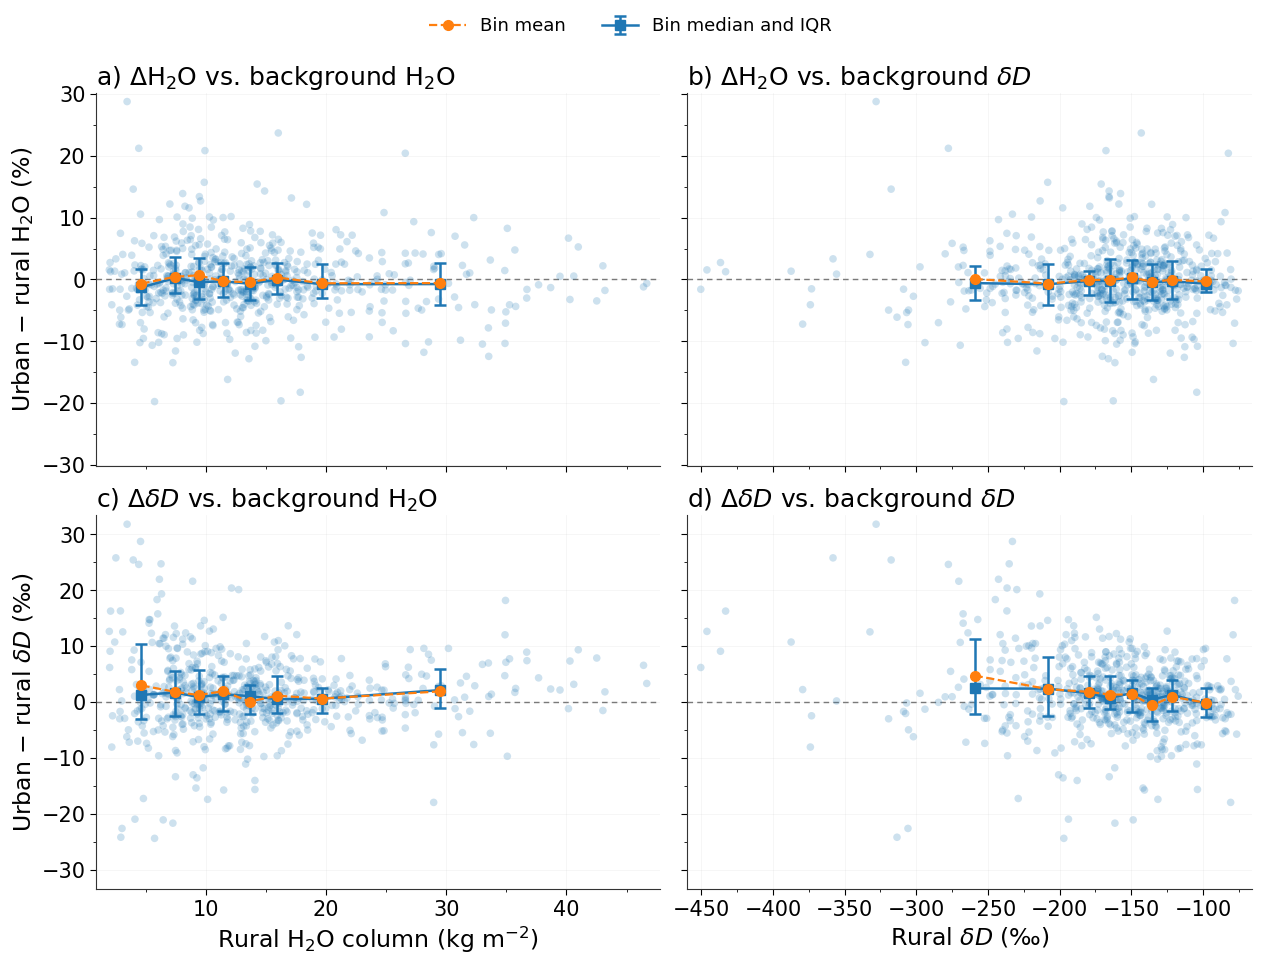

In [5]:
# =============================================================================
# SUPPLEMENTARY FIGURE:
# Urban-rural H2O and delta-D differences across background climate
#
# Four panels:
#
#   a) Delta H2O  vs rural H2O
#   b) Delta H2O  vs rural delta-D
#   c) Delta dD   vs rural H2O
#   d) Delta dD   vs rural delta-D
#
# Each panel shows:
#   - individual city-season points
#   - equal-count (quantile) binned median
#   - interquartile range (25th-75th percentile)
#   - equal-count (quantile) binned mean
#
# No:
#   - regime information
#   - p-values
#   - correlation coefficients
#
# This analysis cell requires the notebook setup/path cell to have been run first.
# It reads the canonical per-city-season CSV saved by the Figure-2 workflow.
# =============================================================================

from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator


# =============================================================================
# USER OPTIONS
# =============================================================================

# False = retain individual city-seasons, as in Figure 2
# True  = average all available seasons to one point per city
ONE_POINT_PER_CITY = False

# Number of equal-count bins in each panel
N_BINS = 8

# Raw points
POINT_SIZE = 30
POINT_ALPHA = 0.22

# Binned median + IQR
BIN_MARKER_SIZE = 7.5
BIN_LINEWIDTH = 1.8
BIN_CAPSIZE = 4

# Binned mean
MEAN_MARKER_SIZE = 7.0
MEAN_LINEWIDTH = 1.6

# Fonts
FONT_AXIS_LABEL = 17
FONT_PANEL_TITLE = 18
FONT_TICK = 15

# Save PNG + PDF?
SAVE_FIGURES = True

# Figure size
FIGSIZE = (12.5, 9.0)


# =============================================================================
# PATHS
# =============================================================================

# This notebook is designed so the shared setup/path cell is run once first.
# Give a clear message if this section is executed in a fresh kernel.
_required_setup_names = [
    "OUTPUT_TABLES_DIR",
    "OUTPUT_FIGURES_DIR",
    "FILES",
]
_missing_setup_names = [
    name for name in _required_setup_names
    if name not in globals()
]

if _missing_setup_names:
    raise RuntimeError(
        "Run the notebook setup/path cell first. Missing definitions: "
        + ", ".join(_missing_setup_names)
    )

RESULTS_DIR = Path(OUTPUT_TABLES_DIR)
FIGURES_DIR = Path(OUTPUT_FIGURES_DIR)
TROPOMI_PATH = Path(FILES["tropomi_climatology"])

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# =============================================================================
# 1. GET H2O COLUMN UNITS
# =============================================================================

def interpret_h2o_units(unit):

    if unit is None:
        return None, None

    u = str(unit).strip()

    ul = (
        u.lower()
        .replace(" ", "")
        .replace("**", "^")
        .replace("−", "-")
    )

    kg_m2_forms = {
        "kg/m2",
        "kg/m^2",
        "kgm-2",
        "kgm^-2",
        "kgm^(-2)",
    }

    if ul in kg_m2_forms:
        return r"kg m$^{-2}$", "kg m^-2"

    mm_forms = {
        "mm",
        "millimeter",
        "millimeters",
        "millimetre",
        "millimetres",
    }

    if ul in mm_forms:
        return "mm", "mm"

    return u, u


h2o_units_raw = None

if TROPOMI_PATH.exists():

    try:

        with xr.open_dataset(
            TROPOMI_PATH,
            decode_times=False,
        ) as ds:

            if "h2o_column" in ds.variables:

                h2o_units_raw = (
                    ds["h2o_column"]
                    .attrs
                    .get("units", None)
                )

    except Exception as exc:

        print(
            "WARNING: Could not read H2O units from the TROPOMI file:"
        )
        print(exc)


H2O_UNIT_LABEL, H2O_UNIT_PLAIN = interpret_h2o_units(
    h2o_units_raw
)


if H2O_UNIT_LABEL is None:

    H2O_UNIT_LABEL = r"kg m$^{-2}$"
    H2O_UNIT_PLAIN = "kg m^-2"

    print(
        "WARNING: h2o_column has no readable units attribute.\n"
        "Using expected TROPOMI column units: kg m^-2."
    )


print("=" * 80)
print("H2O COLUMN UNITS")
print("=" * 80)
print(f"NetCDF units attribute : {h2o_units_raw!r}")
print(f"Using units            : {H2O_UNIT_PLAIN}")


# =============================================================================
# 2. FIGURE-2 CITY-SEASON CSV
# =============================================================================

# Canonical Figure-2 output produced earlier in this notebook.
csv_path = RESULTS_DIR / "Figure_2_cityseason_results.csv"

if not csv_path.exists():
    raise FileNotFoundError(
        "Required Figure-2 city-season output was not found:\n"
        f"    {csv_path}\n\n"
        "Run the Figure 2 section first."
    )

print("\n" + "=" * 80)
print("CITY-SEASON DATA SOURCE")
print("=" * 80)
print(csv_path)


# =============================================================================
# 3. LOAD AND VALIDATE
# =============================================================================

df = pd.read_csv(csv_path)


required_columns = [
    "season",
    "name",
    "urban_mean_d",
    "rural_mean_d",
    "urban_mean_h2o",
    "rural_mean_h2o",
]


missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:

    raise KeyError(
        "Missing required columns:\n"
        + "\n".join(f"  - {col}" for col in missing)
    )


numeric_columns = [
    "urban_mean_d",
    "rural_mean_d",
    "urban_mean_h2o",
    "rural_mean_h2o",
]


for col in numeric_columns:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce",
    )


df = (
    df
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=numeric_columns)
    .copy()
)


df = df[
    df["rural_mean_h2o"] != 0
].copy()


print()
print(f"Valid city-season rows : {len(df)}")
print(f"Unique cities          : {df['name'].nunique()}")

print("\nRows by season:")
print(
    df["season"]
    .value_counts()
    .reindex(["MAM", "JJA", "SON", "DJF"])
)


# =============================================================================
# 4. OPTIONAL ONE-POINT-PER-CITY COLLAPSE
# =============================================================================

if ONE_POINT_PER_CITY:

    df = (
        df.groupby(
            "name",
            as_index=False,
        )
        .agg(
            urban_mean_d=("urban_mean_d", "mean"),
            rural_mean_d=("rural_mean_d", "mean"),
            urban_mean_h2o=("urban_mean_h2o", "mean"),
            rural_mean_h2o=("rural_mean_h2o", "mean"),
        )
    )

    print(f"\nCollapsed to {len(df)} city means.")

else:

    print("\nRetaining individual city-seasons.")


# =============================================================================
# 5. DERIVED QUANTITIES
# =============================================================================

df["delta_dD"] = (
    df["urban_mean_d"]
    - df["rural_mean_d"]
)


df["delta_H2O_pct"] = (
    100.0
    * (
        df["urban_mean_h2o"]
        - df["rural_mean_h2o"]
    )
    / np.abs(df["rural_mean_h2o"])
)


df = (
    df
    .replace([np.inf, -np.inf], np.nan)
    .dropna(
        subset=[
            "delta_dD",
            "delta_H2O_pct",
        ]
    )
    .copy()
)


# =============================================================================
# 6. SUMMARY OUTPUT
# =============================================================================

def print_summary(label, values, unit=""):

    values = pd.Series(values).dropna()

    q05, q50, q95 = values.quantile(
        [0.05, 0.50, 0.95]
    )

    mean = values.mean()

    print(
        f"{label:<25}"
        f"mean={mean:9.3f} {unit:<8}  "
        f"median={q50:9.3f} {unit:<8}  "
        f"5-95%=[{q05:9.3f}, {q95:9.3f}]  "
        f"full=[{values.min():9.3f}, {values.max():9.3f}]"
    )


print("\n" + "=" * 125)
print("ABSOLUTE VALUES AND URBAN-RURAL DIFFERENCES")
print("=" * 125)

print_summary(
    "Rural H2O",
    df["rural_mean_h2o"],
    H2O_UNIT_PLAIN,
)

print_summary(
    "Urban H2O",
    df["urban_mean_h2o"],
    H2O_UNIT_PLAIN,
)

print_summary(
    "Rural delta-D",
    df["rural_mean_d"],
    "permil",
)

print_summary(
    "Urban delta-D",
    df["urban_mean_d"],
    "permil",
)

print_summary(
    "Urban-rural H2O",
    df["delta_H2O_pct"],
    "%",
)

print_summary(
    "Urban-rural delta-D",
    df["delta_dD"],
    "permil",
)


# =============================================================================
# 7. BINNING FUNCTION
# =============================================================================

def make_quantile_bin_summary(
    data,
    xcol,
    ycol,
    n_bins=N_BINS,
):
    """
    Divide x into approximately equal-count bins.

    For each bin, return:
      x_mean
      x_median
      y_mean
      y_median
      y_q25
      y_q75
      n
      x_min
      x_max

    Thus:
      - the median/IQR summary is plotted at
        (x_median, y_median)
      - the mean summary is plotted at
        (x_mean, y_mean)
    """

    tmp = (
        data[[xcol, ycol]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .copy()
    )


    tmp["_bin"] = pd.qcut(
        tmp[xcol],
        q=n_bins,
        duplicates="drop",
    )


    summary = (
        tmp
        .groupby(
            "_bin",
            observed=True,
        )
        .agg(
            n=(ycol, "size"),

            x_mean=(
                xcol,
                "mean",
            ),

            x_median=(
                xcol,
                "median",
            ),

            x_min=(
                xcol,
                "min",
            ),

            x_max=(
                xcol,
                "max",
            ),

            y_mean=(
                ycol,
                "mean",
            ),

            y_median=(
                ycol,
                "median",
            ),

            y_q25=(
                ycol,
                lambda x: np.percentile(x, 25),
            ),

            y_q75=(
                ycol,
                lambda x: np.percentile(x, 75),
            ),
        )
        .reset_index(drop=True)
    )

    return summary


# Calculate all four summaries
bin_a = make_quantile_bin_summary(
    df,
    "rural_mean_h2o",
    "delta_H2O_pct",
)

bin_b = make_quantile_bin_summary(
    df,
    "rural_mean_d",
    "delta_H2O_pct",
)

bin_c = make_quantile_bin_summary(
    df,
    "rural_mean_h2o",
    "delta_dD",
)

bin_d = make_quantile_bin_summary(
    df,
    "rural_mean_d",
    "delta_dD",
)


# =============================================================================
# 8. OPTIONAL PRINTING OF BIN SUMMARIES
# =============================================================================

def print_bin_summary(
    name,
    summary,
):

    print("\n" + "=" * 115)
    print(name)
    print("=" * 115)

    print(
        summary.to_string(
            index=False,
            float_format=lambda x: f"{x:8.3f}",
        )
    )


print_bin_summary(
    "PANEL A: Delta H2O vs rural H2O",
    bin_a,
)

print_bin_summary(
    "PANEL B: Delta H2O vs rural delta-D",
    bin_b,
)

print_bin_summary(
    "PANEL C: Delta delta-D vs rural H2O",
    bin_c,
)

print_bin_summary(
    "PANEL D: Delta delta-D vs rural delta-D",
    bin_d,
)


# =============================================================================
# 9. AXIS HELPERS
# =============================================================================

def padded_limits(
    values,
    frac=0.04,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    lo = float(np.min(values))
    hi = float(np.max(values))

    span = hi - lo

    if span <= 0:
        span = max(abs(lo), 1.0)

    return (
        lo - frac * span,
        hi + frac * span,
    )


def symmetric_limits(
    values,
    frac=0.05,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    lim = float(
        np.max(np.abs(values))
    )

    if lim <= 0:
        lim = 1.0

    lim *= (
        1.0 + frac
    )

    return (
        -lim,
        lim,
    )


def format_axis(ax):

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("0.2")
    ax.spines["bottom"].set_color("0.2")

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        labelsize=FONT_TICK,
        width=0.8,
        length=4,
    )

    ax.tick_params(
        axis="both",
        which="minor",
        direction="out",
        width=0.6,
        length=2,
    )

    ax.xaxis.set_minor_locator(
        AutoMinorLocator(2)
    )

    ax.yaxis.set_minor_locator(
        AutoMinorLocator(2)
    )

    ax.grid(
        alpha=0.12,
        linewidth=0.6,
    )


def add_median_iqr(
    ax,
    summary,
):
    """
    Overlay binned median and IQR.

    x position = median x within bin
    y position = median y within bin
    error bars = y 25th-75th percentile
    """

    lower = (
        summary["y_median"]
        - summary["y_q25"]
    )

    upper = (
        summary["y_q75"]
        - summary["y_median"]
    )

    ax.errorbar(
        summary["x_median"],
        summary["y_median"],
        yerr=[
            lower,
            upper,
        ],
        fmt="s-",
        markersize=BIN_MARKER_SIZE,
        linewidth=BIN_LINEWIDTH,
        elinewidth=BIN_LINEWIDTH,
        capsize=BIN_CAPSIZE,
        capthick=BIN_LINEWIDTH,
        zorder=5,
        label="Bin median and IQR",
    )


def add_bin_mean(
    ax,
    summary,
):
    """
    Overlay binned arithmetic mean.

    The mean and median summaries use exactly the same
    quantile bins. Both are plotted at the median x
    position of the bin so that their y values can be
    compared directly.

    x position = median x within bin
    y position = mean y within bin
    """

    ax.plot(
        summary["x_median"],
        summary["y_mean"],
        marker="o",
        linestyle="--",
        markersize=MEAN_MARKER_SIZE,
        linewidth=MEAN_LINEWIDTH,
        zorder=6,
        label="Bin mean",
    )


# =============================================================================
# 10. COMMON AXIS LIMITS
# =============================================================================

h2o_xlim = padded_limits(
    df["rural_mean_h2o"],
    frac=0.025,
)

dD_xlim = padded_limits(
    df["rural_mean_d"],
    frac=0.025,
)

delta_H2O_ylim = symmetric_limits(
    df["delta_H2O_pct"],
    frac=0.05,
)

delta_dD_ylim = symmetric_limits(
    df["delta_dD"],
    frac=0.05,
)


# =============================================================================
# 11. FOUR-PANEL FIGURE
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=FIGSIZE,
    sharex="col",
    sharey="row",
    constrained_layout=True,
)


# =============================================================================
# PANEL a
# Delta H2O vs rural H2O
# =============================================================================

ax = axes[0, 0]

ax.scatter(
    df["rural_mean_h2o"],
    df["delta_H2O_pct"],
    s=POINT_SIZE,
    alpha=POINT_ALPHA,
    edgecolors="none",
    zorder=1,
)

add_median_iqr(
    ax,
    bin_a,
)

add_bin_mean(
    ax,
    bin_a,
)

ax.axhline(
    0.0,
    color="0.45",
    linestyle=(0, (4, 3)),
    linewidth=1.0,
    zorder=0,
)

ax.set_xlim(
    *h2o_xlim
)

ax.set_ylim(
    *delta_H2O_ylim
)

ax.set_ylabel(
    r"Urban $-$ rural H$_2$O (%)",
    fontsize=FONT_AXIS_LABEL,
)

ax.set_title(
    r"a) $\Delta$H$_2$O vs. background H$_2$O",
    loc="left",
    fontsize=FONT_PANEL_TITLE,
)

format_axis(ax)


# =============================================================================
# PANEL b
# Delta H2O vs rural delta-D
# =============================================================================

ax = axes[0, 1]

ax.scatter(
    df["rural_mean_d"],
    df["delta_H2O_pct"],
    s=POINT_SIZE,
    alpha=POINT_ALPHA,
    edgecolors="none",
    zorder=1,
)

add_median_iqr(
    ax,
    bin_b,
)

add_bin_mean(
    ax,
    bin_b,
)

ax.axhline(
    0.0,
    color="0.45",
    linestyle=(0, (4, 3)),
    linewidth=1.0,
    zorder=0,
)

ax.set_xlim(
    *dD_xlim
)

ax.set_ylim(
    *delta_H2O_ylim
)

ax.set_title(
    r"b) $\Delta$H$_2$O vs. background $\delta D$",
    loc="left",
    fontsize=FONT_PANEL_TITLE,
)

format_axis(ax)


# =============================================================================
# PANEL c
# Delta delta-D vs rural H2O
# =============================================================================

ax = axes[1, 0]

ax.scatter(
    df["rural_mean_h2o"],
    df["delta_dD"],
    s=POINT_SIZE,
    alpha=POINT_ALPHA,
    edgecolors="none",
    zorder=1,
)

add_median_iqr(
    ax,
    bin_c,
)

add_bin_mean(
    ax,
    bin_c,
)

ax.axhline(
    0.0,
    color="0.45",
    linestyle=(0, (4, 3)),
    linewidth=1.0,
    zorder=0,
)

ax.set_xlim(
    *h2o_xlim
)

ax.set_ylim(
    *delta_dD_ylim
)

ax.set_xlabel(
    "Rural H$_2$O column "
    f"({H2O_UNIT_LABEL})",
    fontsize=FONT_AXIS_LABEL,
)

ax.set_ylabel(
    r"Urban $-$ rural $\delta D$ (‰)",
    fontsize=FONT_AXIS_LABEL,
)

ax.set_title(
    r"c) $\Delta\delta D$ vs. background H$_2$O",
    loc="left",
    fontsize=FONT_PANEL_TITLE,
)

format_axis(ax)


# =============================================================================
# PANEL d
# Delta delta-D vs rural delta-D
# =============================================================================

ax = axes[1, 1]

ax.scatter(
    df["rural_mean_d"],
    df["delta_dD"],
    s=POINT_SIZE,
    alpha=POINT_ALPHA,
    edgecolors="none",
    zorder=1,
)

add_median_iqr(
    ax,
    bin_d,
)

add_bin_mean(
    ax,
    bin_d,
)

ax.axhline(
    0.0,
    color="0.45",
    linestyle=(0, (4, 3)),
    linewidth=1.0,
    zorder=0,
)

ax.set_xlim(
    *dD_xlim
)

ax.set_ylim(
    *delta_dD_ylim
)

ax.set_xlabel(
    r"Rural $\delta D$ (‰)",
    fontsize=FONT_AXIS_LABEL,
)

ax.set_title(
    r"d) $\Delta\delta D$ vs. background $\delta D$",
    loc="left",
    fontsize=FONT_PANEL_TITLE,
)

format_axis(ax)


# =============================================================================
# 12. LEGEND
# =============================================================================

# One shared legend is enough.
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.065),
    frameon=False,
    fontsize=13,
    ncol=2,
)


# =============================================================================
# 13. SAVE
# =============================================================================

if SAVE_FIGURES:

    point_tag = (
        "cityMeans"
        if ONE_POINT_PER_CITY
        else "citySeasons"
    )

    png_path = FIGURES_DIR / "Supplement_Figure_7_Background_conditions.png"

    pdf_path = FIGURES_DIR / "Supplement_Figure_7_Background_conditions.pdf"

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    fig.savefig(
        pdf_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    print("\nSaved figure:")
    print(f"  PNG: {png_path}")
    print(f"  PDF: {pdf_path}")


plt.show()


# Supplementary Table 6 - city-selection accounting


In [8]:
# =============================================================================
# CITY-SELECTION ACCOUNTING — STANDALONE JUPYTER CELL
# =============================================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray
from scipy.ndimage import distance_transform_edt, label as ndimage_label

warnings.filterwarnings("ignore")

# =============================================================================
# PATHS
# =============================================================================

ROOT = PROJECT_ROOT

SOURCE = SOURCE_DATA_DIR
RESULTS = OUTPUT_TABLES_DIR
RESULTS.mkdir(parents=True, exist_ok=True)

# TROPOMI climatology
TROPOMI = FILES["tropomi_climatology"]

# Source-data files
SETTLE_NC = SOURCE / "PercentSettlementArea_regridded_to_TROPOMI_quadratic_climatology_0p05.nc"
ELEV_TIF = SOURCE / "ETOPO_2022_v1_30s_N90W180_surface_resampled_to_TROPOMI_quadratic_climatology_p05.tif"
LANDMASK_NC = SOURCE / "landseamask_regridded_to_TROPOMI_quadratic_climatology_0p05_nearest.nc"
CITY_CSV = SOURCE / "top400_cities.csv"

# =============================================================================
# CITY-SELECTION SETTINGS
# =============================================================================

SEASONS = ["MAM", "JJA", "SON", "DJF"]
N_CITIES = 400

URBAN_MIN = 50.0       # urban pixels: settlement >= 50%
CONTROL_MAX = 1.0      # comparison pixels: settlement <= 1%

BUFFER_KM = 150.0
ELEV_THR = 50.0
WATER_THR = 50.0

MIN_COUNT_MONTH = 5.0
MIN_MONTHS = 2

MIN_URBAN = 5
MIN_CONTROL = 10

# These reproduce the city-centroid prefilter in the current script.
CITY_WATER_MIN_KM = 0.0
CITY_WATER_MAX_KM = np.inf

WEIGHT_MEANS = False

# =============================================================================
# OUTPUTS
# =============================================================================

AUDIT_OUT = RESULTS / "CitySelection_candidate_season_audit.csv"
FLOW_OUT = RESULTS / "CitySelection_flow_by_season.csv"
FAIL_OUT = RESULTS / "CitySelection_exclusion_reasons_by_season.csv"
RETAINED_OUT = RESULTS / "CitySelection_retained_city_seasons.csv"
REGION_OUT = RESULTS / "CitySelection_retained_by_season_region.csv"
REGION_FAIL_OUT = RESULTS / "CitySelection_exclusion_reasons_by_season_region.csv"
COVERAGE_OUT = RESULTS / "CitySelection_sampling_by_season_region.csv"
UNIQUE_OUT = RESULTS / "CitySelection_unique_retained_cities.csv"

# =============================================================================
# CHECK INPUTS
# =============================================================================

for p in [TROPOMI, SETTLE_NC, ELEV_TIF, LANDMASK_NC, CITY_CSV]:
    if not p.exists():
        raise FileNotFoundError(f"Missing input file:\n{p}")

print("Input files found:")
for p in [TROPOMI, SETTLE_NC, ELEV_TIF, LANDMASK_NC, CITY_CSV]:
    print(" ", p)

# =============================================================================
# HELPERS
# =============================================================================

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    )
    return 6371.0 * 2.0 * np.arcsin(np.sqrt(a))

def season_months(season):
    return {
        "ANNUAL": list(range(12)),
        "DJF": [11, 0, 1],
        "MAM": [2, 3, 4],
        "JJA": [5, 6, 7],
        "SON": [8, 9, 10],
    }[season.upper()]

def seasonal_mean(da, count, season):
    m = season_months(season)
    x = da.isel(time=m).values.astype(float)
    n = count.isel(time=m).values.astype(float)

    valid = np.isfinite(x) & np.isfinite(n) & (n >= MIN_COUNT_MONTH)
    total = np.sum(np.where(valid, n, 0.0), axis=0)
    num = np.sum(np.where(valid, x * n, 0.0), axis=0)

    mean = np.full(total.shape, np.nan, dtype=float)
    ok = total > 0
    mean[ok] = num[ok] / total[ok]

    support = np.sum(valid, axis=0).astype(float)
    return mean, support, total

def bbox_mask(lon, lat, lat_min, lat_max, lon_min, lon_max):
    lat_ok = (lat >= lat_min) & (lat <= lat_max)

    if lon_min < -180:
        lon_ok = (lon >= lon_min + 360.0) | (lon <= lon_max)
    elif lon_max > 180:
        lon_ok = (lon >= lon_min) | (lon <= lon_max - 360.0)
    else:
        lon_ok = (lon >= lon_min) & (lon <= lon_max)

    return lat_ok & lon_ok

def mean_value(values, weights=None):
    values = np.asarray(values, dtype=float)
    good = np.isfinite(values)

    if not np.any(good):
        return np.nan

    if not WEIGHT_MEANS:
        return float(np.mean(values[good]))

    weights = np.asarray(weights, dtype=float)[good]
    values = values[good]
    good = np.isfinite(weights) & (weights > 0)

    if not np.any(good):
        return np.nan

    return float(np.average(values[good], weights=weights[good]))

def add_regions(df):
    """
    Reviewer requested counts by region.

    Uses country_converter if available. Core accounting still works without
    it, but region will be 'Unknown'.
    """
    df = df.copy()

    if "country_code" not in df.columns:
        df["broad_region"] = "Unknown"
        return df

    try:
        import country_converter as coco

        regions = coco.CountryConverter().convert(
            names=df["country_code"].astype(str).tolist(),
            src="ISO2",
            to="continent",
        )

        df["broad_region"] = (
            pd.Series(regions)
            .replace({
                "America": "Americas",
                "not found": "Unknown",
            })
            .values
        )

    except Exception:
        df["broad_region"] = "Unknown"
        print(
            "\nNOTE: country_converter is not installed. "
            "Core city accounting will work, but regional tables will say "
            "'Unknown'. To enable them, run once:\n"
            "    %pip install country_converter\n"
        )

    return df

# =============================================================================
# LOAD SEASONAL DATA
# =============================================================================

def load_data(season):
    print(f"\nLoading {season.upper()} data ...")

    ds = xr.open_dataset(TROPOMI)

    dD = ds["deltad"]
    h2o = ds["h2o_column"]
    count = ds["count"]
    lats = ds["lat"].values
    lons = ds["lon"].values

    sample = dD.isel(time=0).values.ravel()
    sample = sample[np.isfinite(sample)]
    if len(sample) and np.ptp(sample) < 10:
        dD = dD * 1000.0

    dD_mean, support, total_count = seasonal_mean(dD, count, season)
    h2o_mean, _, _ = seasonal_mean(h2o, count, season)

    # Settlement
    sds = xr.open_dataset(SETTLE_NC)
    settlement = sds["settlement_percentage"].values.astype(float)

    # Elevation
    eds = rioxarray.open_rasterio(ELEV_TIF)
    elevation = (
        eds.values[0]
        if eds.values.ndim == 3
        else eds.values
    ).astype(float)

    elev_lons = eds.x.values

    # Reproduce current conversion to 0-360 ordering.
    if elev_lons[0] < 0:
        split = np.where(elev_lons >= 0)[0][0]
        elevation = np.concatenate(
            [elevation[:, split:], elevation[:, :split]],
            axis=1,
        )

    elevation[elevation < -10000] = np.nan

    # Land/water mask
    lds = xr.open_dataset(LANDMASK_NC)
    land = lds["land_mask"].values

    shape = (len(lats), len(lons))

    for name, arr in {
        "deltaD": dD_mean,
        "H2O": h2o_mean,
        "settlement": settlement,
        "elevation": elevation,
        "landmask": land,
    }.items():
        if arr.shape != shape:
            raise ValueError(
                f"{name} grid is {arr.shape}, but TROPOMI grid is {shape}"
            )

    # Distance to nearest water grid cell.
    water_mask = (land == 0)
    dist_cells = distance_transform_edt(~water_mask)

    dx_km = 0.05 * 111.0 * np.cos(np.deg2rad(lats))
    dy_km = 0.05 * 111.0
    cell_km = np.sqrt(dx_km**2 + dy_km**2) / np.sqrt(2.0)

    water_dist = dist_cells * cell_km[:, None]

    # Apply the finite-value and land filters used for city selection.
    good = (
        np.isfinite(dD_mean)
        & np.isfinite(h2o_mean)
        & np.isfinite(support)
        & np.isfinite(total_count)
        & np.isfinite(settlement)
        & np.isfinite(elevation)
        & np.isfinite(water_dist)
        & (land == 1)
        & (elevation > -50)
    )

    ii, jj = np.where(good)

    df = pd.DataFrame({
        "delta_D": dD_mean[ii, jj],
        "h2o_column": h2o_mean[ii, jj],
        "supported_months": support[ii, jj],
        "total_obs_count": total_count[ii, jj],
        "settlement_pct": settlement[ii, jj],
        "elevation": elevation[ii, jj],
        "latitude": lats[ii],
        "longitude": lons[jj],
        "water_dist": water_dist[ii, jj],
    })

    for x in [ds, sds, eds, lds]:
        try:
            x.close()
        except Exception:
            pass

    print(f"  usable land pixels: {len(df):,}")
    return df, lats, lons

# =============================================================================
# INITIAL TOP-400 CITY TABLE
# =============================================================================

cities = pd.read_csv(CITY_CSV)

if "population" in cities.columns:
    cities = cities.sort_values("population", ascending=False)

cities = cities.head(N_CITIES).reset_index(drop=True)
cities["candidate_rank"] = np.arange(1, len(cities) + 1)

if "city_key" not in cities.columns:
    cities["city_key"] = (
        cities["name"]
        .astype(str)
        .str.strip()
        .str.replace(r"\s+", "_", regex=True)
        .str.replace(r"[^A-Za-z0-9_]", "", regex=True)
    )

cities = add_regions(cities)

print(f"\nInitial candidate cities: {len(cities)}")

# =============================================================================
# ANNUAL CITY-CENTROID WATER-DISTANCE PREFILTER
#
# This is present in the current model/city code before the seasonal loop.
# =============================================================================

annual_df, _, _ = load_data("annual")

city_water_dist = []

for _, c in cities.iterrows():
    clon = float(c["longitude"])
    if clon > 180:
        clon -= 360.0

    match = annual_df[
        (np.abs(annual_df["latitude"] - float(c["latitude"])) < 0.03)
        & (
            np.abs(
                annual_df["longitude"]
                - (clon % 360.0)
            )
            < 0.03
        )
    ]

    city_water_dist.append(
        float(match["water_dist"].mean())
        if len(match)
        else np.nan
    )

cities["city_water_distance_km"] = city_water_dist

cities["pass_city_prefilter"] = (
    np.isfinite(cities["city_water_distance_km"])
    & (cities["city_water_distance_km"] >= CITY_WATER_MIN_KM)
    & (cities["city_water_distance_km"] <= CITY_WATER_MAX_KM)
)

print(
    "Cities passing annual centroid prefilter: "
    f"{cities['pass_city_prefilter'].sum()} / {len(cities)}"
)

del annual_df

# =============================================================================
# AUDIT HELPERS
# =============================================================================

REASONS = {
    "city_prefilter":
        "No usable annual centroid reference pixel",
    "urban_any":
        "<5 urban pixels (>=50% settlement) with usable seasonal data",
    "component":
        "No connected urban footprint identified",
    "urban_support":
        "<5 urban pixels satisfying seasonal TROPOMI support",
    "controls_radius":
        "<10 low-settlement controls within 150 km",
    "controls_elev":
        "<10 controls after elevation matching",
    "controls_water":
        "<10 controls after major-water-body-distance matching",
    "duplicate":
        "Duplicate GeoNames candidate for same urban footprint",
    "retained":
        "Retained",
}

def audit_row(c, season):
    return {
        "season": season,
        "candidate_rank": c["candidate_rank"],
        "city_key": c["city_key"],
        "name": c["name"],
        "country_code": c.get("country_code", ""),
        "broad_region": c.get("broad_region", "Unknown"),
        "population": c.get("population", np.nan),

        "retained": False,
        "failure_code": "",
        "failure_reason": "",
        "duplicate_of": "",

        "pass_city_prefilter": False,
        "pass_urban_any": False,
        "pass_component": False,
        "pass_urban_support": False,
        "pass_controls_radius": False,
        "pass_controls_elev": False,
        "pass_controls_water": False,
        "pass_unique": False,

        "n_urban_any": np.nan,
        "n_component_any": np.nan,
        "n_urban_supported": np.nan,
        "n_controls_radius": np.nan,
        "n_controls_elev": np.nan,
        "n_controls_water": np.nan,
    }

def reject(a, code):
    a["failure_code"] = code
    a["failure_reason"] = REASONS[code]
    return a

# =============================================================================
# PROCESS ONE SEASON
# =============================================================================

def process_season(season):
    df, lats, lons = load_data(season)

    lons180 = lons.copy()
    lons180[lons180 > 180] -= 360.0

    # Full seasonal-support requirement.
    valid = df[
        df["supported_months"] >= MIN_MONTHS
    ].copy()

    # Low-settlement comparison pool.
    controls = valid[
        valid["settlement_pct"] <= CONTROL_MAX
    ].copy()

    controls["lon180"] = np.where(
        controls["longitude"] > 180,
        controls["longitude"] - 360.0,
        controls["longitude"],
    )

    ctrl_lat = controls["latitude"].values
    ctrl_lon = controls["lon180"].values
    ctrl_elev = controls["elevation"].values
    ctrl_water = controls["water_dist"].values

    full_lon = df["longitude"].values.copy()
    full_lon[full_lon > 180] -= 360.0

    valid_lon = valid["longitude"].values.copy()
    valid_lon[valid_lon > 180] -= 360.0

    audits = []
    retained = []
    claimed_components = {}

    for _, c in cities.iterrows():
        a = audit_row(c, season)

        # 0. Annual centroid prefilter
        if not bool(c["pass_city_prefilter"]):
            audits.append(reject(a, "city_prefilter"))
            continue

        a["pass_city_prefilter"] = True

        lat0, lat1 = float(c["lat_min"]), float(c["lat_max"])
        lon0, lon1 = float(c["lon_min"]), float(c["lon_max"])
        city_lat = float(c["latitude"])
        city_lon = float(c["longitude"])

        if city_lon > 180:
            city_lon -= 360.0

        # Candidate +/-2 degree box.
        mf = bbox_mask(
            full_lon, df["latitude"].values,
            lat0, lat1, lon0, lon1
        )
        mv = bbox_mask(
            valid_lon, valid["latitude"].values,
            lat0, lat1, lon0, lon1
        )

        region = df[mf].copy()
        region["lon180"] = full_lon[mf]

        region_valid = valid[mv].copy()
        region_valid["lon180"] = valid_lon[mv]

        # Local target grid for connected-component analysis.
        ilat = np.where(
            (lats >= lat0) & (lats <= lat1)
        )[0]

        if lon0 < -180:
            ilon = np.where(
                (lons180 >= lon0 + 360.0)
                | (lons180 <= lon1)
            )[0]
        elif lon1 > 180:
            ilon = np.where(
                (lons180 >= lon0)
                | (lons180 <= lon1 - 360.0)
            )[0]
        else:
            ilon = np.where(
                (lons180 >= lon0)
                & (lons180 <= lon1)
            )[0]

        lat_sub = lats[ilat]
        lon_sub = np.sort(lons180[ilon])

        # 1. >=5 high-settlement pixels with any usable seasonal data.
        urban_geom = region[
            region["settlement_pct"] >= URBAN_MIN
        ].copy()

        a["n_urban_any"] = len(urban_geom)

        if len(urban_geom) < MIN_URBAN:
            audits.append(reject(a, "urban_any"))
            continue

        a["pass_urban_any"] = True

        if len(lat_sub) == 0 or len(lon_sub) == 0:
            audits.append(reject(a, "component"))
            continue

        lat_to_i = {
            round(float(v), 4): i
            for i, v in enumerate(lat_sub)
        }

        lon_to_j = {
            round(float(v), 4): j
            for j, v in enumerate(lon_sub)
        }

        # Build binary urban grid.
        urban_grid = np.zeros(
            (len(lat_sub), len(lon_sub)),
            dtype=np.int8,
        )

        for _, r in urban_geom.iterrows():
            i = lat_to_i.get(
                round(float(r["latitude"]), 4)
            )
            j = lon_to_j.get(
                round(float(r["lon180"]), 4)
            )

            if i is not None and j is not None:
                urban_grid[i, j] = 1

        labels, _ = ndimage_label(urban_grid)

        # Identify component nearest/containing GeoNames centroid.
        ci = np.argmin(
            np.abs(lat_sub - city_lat)
        )
        cj = np.argmin(
            np.abs(lon_sub - city_lon)
        )

        lab = labels[ci, cj]

        if lab == 0:
            found = False

            for radius in range(
                1,
                max(len(lat_sub), len(lon_sub))
            ):
                for di in range(-radius, radius + 1):
                    for dj in range(-radius, radius + 1):
                        ni, nj = ci + di, cj + dj

                        if (
                            0 <= ni < len(lat_sub)
                            and 0 <= nj < len(lon_sub)
                            and labels[ni, nj] > 0
                        ):
                            lab = labels[ni, nj]
                            found = True
                            break

                    if found:
                        break
                if found:
                    break

        if lab == 0:
            audits.append(reject(a, "component"))
            continue

        a["pass_component"] = True
        a["n_component_any"] = int(
            np.sum(labels == lab)
        )

        # 2. Supported pixels in the selected urban component.
        uv = region_valid[
            region_valid["settlement_pct"] >= URBAN_MIN
        ].copy()

        keep = []

        for idx, r in uv.iterrows():
            i = lat_to_i.get(
                round(float(r["latitude"]), 4)
            )
            j = lon_to_j.get(
                round(float(r["lon180"]), 4)
            )

            if (
                i is not None
                and j is not None
                and labels[i, j] == lab
            ):
                keep.append(idx)

        urban = uv.loc[keep].copy()
        a["n_urban_supported"] = len(urban)

        if len(urban) < MIN_URBAN:
            audits.append(
                reject(a, "urban_support")
            )
            continue

        a["pass_urban_support"] = True

        # Unique connected-component key.
        comp_i, comp_j = np.where(
            labels == lab
        )

        component_key = (
            round(
                float(np.mean(lat_sub[comp_i])),
                2,
            ),
            round(
                float(np.mean(lon_sub[comp_j])),
                2,
            ),
        )

        # Urban matching properties.
        urban_elev = mean_value(
            urban["elevation"],
            urban["total_obs_count"],
        )

        urban_water = mean_value(
            urban["water_dist"],
            urban["total_obs_count"],
        )

        urban_lat = float(
            urban["latitude"].mean()
        )

        urban_lon = float(
            urban["lon180"].mean()
        )

        dist = haversine(
            ctrl_lat,
            ctrl_lon,
            urban_lat,
            urban_lon,
        )

        delev = np.abs(
            ctrl_elev - urban_elev
        )

        dwater = np.abs(
            ctrl_water - urban_water
        )

        # 3. >=10 controls within 150 km.
        m1 = (
            dist <= BUFFER_KM
        )

        a["n_controls_radius"] = int(
            m1.sum()
        )

        if m1.sum() < MIN_CONTROL:
            audits.append(
                reject(a, "controls_radius")
            )
            continue

        a["pass_controls_radius"] = True

        # 4. Add +/-50 m elevation matching.
        m2 = (
            m1
            & (delev <= ELEV_THR)
        )

        a["n_controls_elev"] = int(
            m2.sum()
        )

        if m2.sum() < MIN_CONTROL:
            audits.append(
                reject(a, "controls_elev")
            )
            continue

        a["pass_controls_elev"] = True

        # 5. Add +/-50 km major-water-body-distance matching.
        m3 = (
            m2
            & (dwater <= WATER_THR)
        )

        a["n_controls_water"] = int(
            m3.sum()
        )

        if m3.sum() < MIN_CONTROL:
            audits.append(
                reject(a, "controls_water")
            )
            continue

        a["pass_controls_water"] = True

        rural = controls[m3].copy()

        # 6. Duplicate GeoNames entries pointing to same urban component.
        if component_key in claimed_components:
            a["duplicate_of"] = (
                claimed_components[
                    component_key
                ]
            )
            audits.append(
                reject(a, "duplicate")
            )
            continue

        claimed_components[
            component_key
        ] = c["name"]

        a["pass_unique"] = True
        a["retained"] = True
        a["failure_code"] = "retained"
        a["failure_reason"] = REASONS["retained"]
        audits.append(a)

        retained.append({
            "season": season,
            "candidate_rank": c["candidate_rank"],
            "city_key": c["city_key"],
            "name": c["name"],
            "country_code": c.get("country_code", ""),
            "broad_region": c.get("broad_region", "Unknown"),
            "population": c.get("population", np.nan),

            "n_urban_pixels": len(urban),
            "n_comparison_pixels": len(rural),

            "urban_total_observations":
                float(urban["total_obs_count"].sum()),

            "comparison_total_observations":
                float(rural["total_obs_count"].sum()),

            "urban_mean_obs_per_pixel":
                float(urban["total_obs_count"].mean()),

            "comparison_mean_obs_per_pixel":
                float(rural["total_obs_count"].mean()),

            "urban_median_obs_per_pixel":
                float(urban["total_obs_count"].median()),

            "comparison_median_obs_per_pixel":
                float(rural["total_obs_count"].median()),

            "urban_mean_supported_months":
                float(urban["supported_months"].mean()),

            "comparison_mean_supported_months":
                float(rural["supported_months"].mean()),
        })

    audit_df = pd.DataFrame(audits)
    retained_df = pd.DataFrame(retained)

    print(
        f"\n{season}: "
        f"{len(retained_df)} retained / {len(cities)} candidates"
    )

    print(
        audit_df["failure_reason"]
        .value_counts()
        .to_string()
    )

    return audit_df, retained_df

# =============================================================================
# RUN FOUR SEASONS
# =============================================================================

all_audits = []
all_retained = []

for season in SEASONS:
    print("\n" + "=" * 90)
    print(f"PROCESSING {season}")
    print("=" * 90)

    a, r = process_season(season)

    all_audits.append(a)

    if len(r):
        all_retained.append(r)

audit = pd.concat(
    all_audits,
    ignore_index=True,
)

retained = pd.concat(
    all_retained,
    ignore_index=True,
)

expected = len(cities) * len(SEASONS)

print(
    f"\nCandidate-season audit rows: "
    f"{len(audit):,} / expected {expected:,}"
)

assert len(audit) == expected

audit.to_csv(
    AUDIT_OUT,
    index=False,
)

retained.to_csv(
    RETAINED_OUT,
    index=False,
)

# =============================================================================
# CUMULATIVE SELECTION FLOW
# =============================================================================

STEPS = [
    (
        "Initial candidate cities",
        None,
    ),
    (
        "Annual centroid reference pixel available",
        "pass_city_prefilter",
    ),
    (
        ">=5 urban pixels with usable seasonal data",
        "pass_urban_any",
    ),
    (
        "Connected urban footprint identified",
        "pass_component",
    ),
    (
        ">=5 seasonally supported urban pixels",
        "pass_urban_support",
    ),
    (
        ">=10 low-settlement controls within 150 km",
        "pass_controls_radius",
    ),
    (
        ">=10 controls after elevation matching",
        "pass_controls_elev",
    ),
    (
        ">=10 controls after major-water-body matching",
        "pass_controls_water",
    ),
    (
        "Unique connected urban component",
        "pass_unique",
    ),
]

flow_rows = []

scopes = [
    (
        season,
        audit[
            audit["season"] == season
        ],
    )
    for season in SEASONS
]

scopes.append(
    (
        "ALL_CITY_SEASONS",
        audit,
    )
)

for scope, sub in scopes:
    previous = len(sub)

    for order, (label, col) in enumerate(STEPS):
        n = (
            len(sub)
            if col is None
            else int(
                sub[col]
                .fillna(False)
                .sum()
            )
        )

        flow_rows.append({
            "scope": scope,
            "stage_order": order,
            "selection_stage": label,
            "n_remaining": n,
            "n_excluded_at_stage":
                0 if col is None
                else previous - n,
            "fraction_initial_remaining":
                n / len(sub),
        })

        previous = n

flow = pd.DataFrame(
    flow_rows
)

flow.to_csv(
    FLOW_OUT,
    index=False,
)

# =============================================================================
# PRIMARY EXCLUSION REASONS
# =============================================================================

failures = audit[
    ~audit["retained"]
].copy()

fail_summary = (
    failures
    .groupby(
        [
            "season",
            "failure_code",
            "failure_reason",
        ]
    )
    .size()
    .reset_index(
        name="n_excluded"
    )
)

fail_summary.to_csv(
    FAIL_OUT,
    index=False,
)

# =============================================================================
# RETENTION BY REGION
# =============================================================================

candidate_region = (
    audit
    .groupby(
        [
            "season",
            "broad_region",
        ]
    )
    ["city_key"]
    .nunique()
    .rename(
        "n_candidate_cities"
    )
    .reset_index()
)

retained_region = (
    audit[
        audit["retained"]
    ]
    .groupby(
        [
            "season",
            "broad_region",
        ]
    )
    ["city_key"]
    .nunique()
    .rename(
        "n_retained_cities"
    )
    .reset_index()
)

region = candidate_region.merge(
    retained_region,
    on=[
        "season",
        "broad_region",
    ],
    how="left",
)

region["n_retained_cities"] = (
    region["n_retained_cities"]
    .fillna(0)
    .astype(int)
)

region["retention_pct"] = (
    100.0
    * region["n_retained_cities"]
    / region["n_candidate_cities"]
)

region.to_csv(
    REGION_OUT,
    index=False,
)

region_failures = (
    failures
    .groupby(
        [
            "season",
            "broad_region",
            "failure_code",
            "failure_reason",
        ]
    )
    .size()
    .reset_index(
        name="n_excluded"
    )
)

region_failures.to_csv(
    REGION_FAIL_OUT,
    index=False,
)

# =============================================================================
# UNIQUE CITIES REPRESENTED IN >=1 SEASON
# =============================================================================

unique = (
    retained[
        [
            "candidate_rank",
            "city_key",
            "name",
            "country_code",
            "broad_region",
            "population",
        ]
    ]
    .drop_duplicates(
        "city_key"
    )
)

n_seasons = (
    retained
    .groupby(
        "city_key"
    )
    ["season"]
    .nunique()
    .rename(
        "n_retained_seasons"
    )
)

unique = (
    unique
    .merge(
        n_seasons,
        on="city_key",
        how="left",
    )
    .sort_values(
        "candidate_rank"
    )
)

unique.to_csv(
    UNIQUE_OUT,
    index=False,
)

# =============================================================================
# URBAN VS COMPARISON SAMPLING BY SEASON AND REGION
# =============================================================================

coverage = (
    retained
    .groupby(
        [
            "season",
            "broad_region",
        ]
    )
    .agg(
        n_city_seasons=(
            "city_key",
            "size",
        ),
        n_unique_cities=(
            "city_key",
            "nunique",
        ),
        median_urban_pixels=(
            "n_urban_pixels",
            "median",
        ),
        median_comparison_pixels=(
            "n_comparison_pixels",
            "median",
        ),
        mean_urban_pixels=(
            "n_urban_pixels",
            "mean",
        ),
        mean_comparison_pixels=(
            "n_comparison_pixels",
            "mean",
        ),
        median_urban_total_obs=(
            "urban_total_observations",
            "median",
        ),
        median_comparison_total_obs=(
            "comparison_total_observations",
            "median",
        ),
        median_urban_obs_per_pixel=(
            "urban_median_obs_per_pixel",
            "median",
        ),
        median_comparison_obs_per_pixel=(
            "comparison_median_obs_per_pixel",
            "median",
        ),
        mean_urban_supported_months=(
            "urban_mean_supported_months",
            "mean",
        ),
        mean_comparison_supported_months=(
            "comparison_mean_supported_months",
            "mean",
        ),
    )
    .reset_index()
)

coverage.to_csv(
    COVERAGE_OUT,
    index=False,
)

# =============================================================================
# NOTEBOOK SUMMARY
# =============================================================================

print("\n" + "=" * 100)
print("FINAL CITY-SELECTION ACCOUNTING")
print("=" * 100)

retained_by_season = (
    audit
    .groupby("season")
    ["retained"]
    .sum()
    .reindex(SEASONS)
    .astype(int)
)

print("\nRETAINED CITY-SEASONS")
print(retained_by_season.to_string())

print(
    f"\nTotal retained city-seasons: "
    f"{int(audit['retained'].sum())}"
)

print(
    f"Unique cities represented in >=1 season: "
    f"{retained['city_key'].nunique()}"
)

print(
    f"Initial candidate-season combinations: "
    f"{len(cities) * len(SEASONS)}"
)

# Selection flow
flow_wide = (
    flow
    .pivot(
        index="selection_stage",
        columns="scope",
        values="n_remaining",
    )
    .reindex(
        [
            x[0]
            for x in STEPS
        ]
    )
    .reindex(
        columns=
            SEASONS
            + ["ALL_CITY_SEASONS"]
    )
)

print("\nCUMULATIVE NUMBER REMAINING")
display(flow_wide)

# Exclusion reasons
fail_wide = (
    fail_summary
    .pivot_table(
        index="failure_reason",
        columns="season",
        values="n_excluded",
        fill_value=0,
    )
    .reindex(
        columns=SEASONS,
        fill_value=0,
    )
)

fail_wide["ALL"] = (
    fail_wide.sum(axis=1)
)

fail_wide = fail_wide.sort_values(
    "ALL",
    ascending=False,
)

print("\nPRIMARY EXCLUSION REASONS")
display(fail_wide)

# Regional retention
region_wide = (
    region
    .pivot(
        index="broad_region",
        columns="season",
        values="n_retained_cities",
    )
    .reindex(
        columns=SEASONS
    )
    .fillna(0)
    .astype(int)
)

print("\nRETAINED CITIES BY REGION AND SEASON")
display(region_wide)

print("\nURBAN / COMPARISON SAMPLING BY REGION AND SEASON")
display(coverage)

print("\nNUMBER OF RETAINED SEASONS PER UNIQUE CITY")
display(
    unique[
        "n_retained_seasons"
    ]
    .value_counts()
    .sort_index()
    .rename_axis(
        "number_of_seasons"
    )
    .to_frame(
        "number_of_cities"
    )
)

print("\nSaved files:")
for p in [
    AUDIT_OUT,
    FLOW_OUT,
    FAIL_OUT,
    RETAINED_OUT,
    REGION_OUT,
    REGION_FAIL_OUT,
    COVERAGE_OUT,
    UNIQUE_OUT,
]:
    print(" ", p)

# Canonical Supplementary Table 6 export
flow.to_csv(OUTPUT_TABLES_DIR / "Supplement_Table_6_City_selection.csv", index=False)
print("Saved:", OUTPUT_TABLES_DIR / "Supplement_Table_6_City_selection.csv")


Input files found:
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/source_data/TROPOMI_HDO_CLEAR_p05_quadratic_climatology.nc
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/source_data/PercentSettlementArea_regridded_to_TROPOMI_quadratic_climatology_0p05.nc
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/source_data/ETOPO_2022_v1_30s_N90W180_surface_resampled_to_TROPOMI_quadratic_climatology_p05.tif
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/source_data/landseamask_regridded_to_TROPOMI_quadratic_climatology_0p05_nearest.nc
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/source_data/top400_cities.csv

NOTE: country_converter is not installed. Core city accounting will work, but regional tables will say 'Unknown'. To enable them, run once:
    %pip install country_converter


Initial candidate cities: 400

Loading ANNUAL data ...
  usable land pixels: 5,682,359
Cities passing annual centroid prefilter: 372 / 400

PROCESSING MAM

Loading MAM data ...
  usable land pix

scope,MAM,JJA,SON,DJF,ALL_CITY_SEASONS
selection_stage,,,,,
Initial candidate cities,400,400,400,400,1600
Annual centroid reference pixel available,372,372,372,372,1488
>=5 urban pixels with usable seasonal data,348,293,348,339,1328
Connected urban footprint identified,348,293,348,339,1328
>=5 seasonally supported urban pixels,244,188,249,233,914
>=10 low-settlement controls within 150 km,239,177,244,233,893
>=10 controls after elevation matching,211,158,212,206,787
>=10 controls after major-water-body matching,196,149,200,195,740
Unique connected urban component,167,122,170,164,623



PRIMARY EXCLUSION REASONS


season,MAM,JJA,SON,DJF,ALL
failure_reason,,,,,
<5 urban pixels satisfying seasonal TROPOMI support,104,105,99,106,414
<5 urban pixels (>=50% settlement) with usable seasonal data,24,79,24,33,160
Duplicate GeoNames candidate for same urban footprint,29,27,30,31,117
No usable annual centroid reference pixel,28,28,28,28,112
<10 controls after elevation matching,28,19,32,27,106
<10 controls after major-water-body-distance matching,15,9,12,11,47
<10 low-settlement controls within 150 km,5,11,5,0,21



RETAINED CITIES BY REGION AND SEASON


...


URBAN / COMPARISON SAMPLING BY REGION AND SEASON


,season,broad_region,n_city_seasons,n_unique_cities,median_urban_pixels,median_comparison_pixels,mean_urban_pixels,mean_comparison_pixels,median_urban_total_obs,median_comparison_total_obs,median_urban_obs_per_pixel,median_comparison_obs_per_pixel,mean_urban_supported_months,mean_comparison_supported_months
0,DJF,Unknown,164,164,12.0,73.0,23.085366,142.640244,1000.195303,5645.191675,93.149135,84.445220,2.944840,2.906799
1,JJA,Unknown,122,122,13.0,78.0,22.647541,173.081967,855.146533,5673.076317,53.888418,57.016195,2.853843,2.847830
2,MAM,Unknown,167,167,13.0,76.0,23.574850,180.820359,822.668613,4763.673849,63.210484,58.858826,2.858985,2.840923
3,SON,Unknown,170,170,12.0,73.5,23.488235,163.947059,847.182873,4673.376492,69.174614,63.828202,2.790796,2.741548



NUMBER OF RETAINED SEASONS PER UNIQUE CITY


,number_of_cities
number_of_seasons,
1,14
2,18
3,67
4,93



Saved files:
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/CitySelection_candidate_season_audit.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/CitySelection_flow_by_season.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/CitySelection_exclusion_reasons_by_season.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/CitySelection_retained_city_seasons.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/CitySelection_retained_by_season_region.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/CitySelection_exclusion_reasons_by_season_region.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/CitySelection_sampling_by_season_region.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/CitySelection_unique_retained_cities.csv
Saved: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/Supplement_Table_6_City_selection.csv


# Supplementary Figure 8 - same-day sampling sensitivity

Recomputes city-season anomalies from `SameDay_daily_only_city_days.csv`, using at least 50% simultaneous coverage of both fixed masks and at least 100 qualifying paired UTC dates. A 20%, 30%, and 50% coverage-threshold comparison is included as a reviewer-validation check.


Daily same-day data : /Users/a391980/Downloads/UrbanWaterVaporIsotopes/source_data/SameDay_daily_only_city_days.csv
Climatology         : /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/Figure_2_cityseason_results.csv

Coverage-fraction consistency:
  urban: PASS
  rural: PASS

City-days before 50% coverage filter: 150,264
City-days after  50% coverage filter: 90,623

City-seasons with >=1 qualifying day: 621
City-seasons with >= 100 qualifying days: 371

Passing city-seasons by season:
MAM     91
JJA     64
SON    105
DJF    111
Name: season, dtype: int64

Number of qualifying paired days:


,count,mean,std,min,5%,10%,25%,50%,75%,90%,95%,max
n_paired_days,371.0,209.2,82.5,101.0,108.0,116.0,143.0,192.0,266.5,317.0,350.0,530.0



Years represented:
7      8
8    363
Name: n_years_with_pairs, dtype: int64

Matched to climatology: 371 city-seasons

PRIMARY SAME-DAY TEST:
>=50% coverage of BOTH masks
>=100 qualifying paired UTC days
ALL qualifying days used with equal temporal weight


,variable,N,r,rho,slope,intercept,sign_agreement_pct,MAE,RMSE
0,Delta dD,371,0.424,0.625,1.100,0.475,73.854,6.696,14.993
1,Delta H2O,371,0.572,0.583,0.459,-0.191,71.159,2.790,3.966



BY SEASON:


,season,variable,N,r,rho,sign_agreement_pct,MAE,RMSE
0,MAM,Delta dD,91,0.318,0.558,72.527,9.916,18.179
1,MAM,Delta H2O,91,0.542,0.523,72.527,2.979,4.343
2,JJA,Delta dD,64,0.423,0.498,71.875,8.913,17.298
3,JJA,Delta H2O,64,0.665,0.650,76.562,2.683,4.075
4,SON,Delta dD,105,0.325,0.649,74.286,5.178,16.948
5,SON,Delta H2O,105,0.449,0.474,67.619,3.136,4.280
6,DJF,Delta dD,111,0.818,0.733,75.676,4.215,6.010
7,DJF,Delta H2O,111,0.668,0.687,70.270,2.369,3.195



COVERAGE SENSITIVITY (all require >=100 paired days):


,coverage_threshold,variable,N,r,rho,sign_agreement_pct,MAE,RMSE
0,0.2,Delta dD,495,0.409,0.555,71.111,6.155,12.119
1,0.2,Delta H2O,495,0.479,0.524,71.515,3.097,4.605
2,0.3,Delta dD,465,0.409,0.594,71.183,6.096,12.854
3,0.3,Delta H2O,465,0.496,0.555,71.613,3.014,4.489
4,0.5,Delta dD,371,0.424,0.625,73.854,6.696,14.993
5,0.5,Delta H2O,371,0.572,0.583,71.159,2.790,3.966


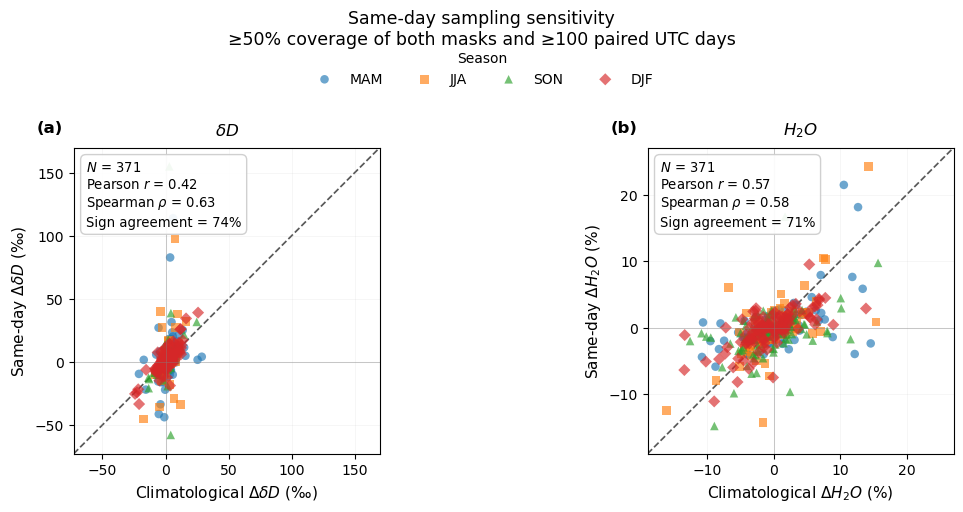


Saved:
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_primary_50pct_100days_cityseason.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_primary_50pct_100days_vs_climatology.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_primary_50pct_100days_stats.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_coverage_20_30_50pct_100days_sensitivity.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Supplement_Figure_8_Same_day_sampling.png


In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, linregress

# =============================================================================
# SETTINGS
# =============================================================================

# This section requires the shared notebook setup/path cell to have been run.
_required_setup_names = [
    "SOURCE_DATA_DIR",
    "OUTPUT_TABLES_DIR",
    "OUTPUT_FIGURES_DIR",
]
_missing_setup_names = [
    name for name in _required_setup_names
    if name not in globals()
]

if _missing_setup_names:
    raise RuntimeError(
        "Run the notebook setup/path cell first. Missing definitions: "
        + ", ".join(_missing_setup_names)
    )

SRC = Path(SOURCE_DATA_DIR)
RESULTS = Path(OUTPUT_TABLES_DIR)
FIGURES = Path(OUTPUT_FIGURES_DIR)

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# Climatology vs. same-day test
COVERAGE_THRESHOLD = 0.50
MIN_PAIRED_DAYS = 100

SEASON_ORDER = ["MAM", "JJA", "SON", "DJF"]

# =============================================================================
# INPUTS
# =============================================================================

DAILY_CSV = SRC / "SameDay_daily_only_city_days.csv"

# Canonical per-city-season output produced by the Figure 2 section.
CLIM_CSV = RESULTS / "Figure_2_cityseason_results.csv"

if not DAILY_CSV.exists():
    raise FileNotFoundError(
        "Required same-day source data were not found:\n"
        f"    {DAILY_CSV}"
    )

if not CLIM_CSV.exists():
    raise FileNotFoundError(
        "Required Figure-2 city-season output was not found:\n"
        f"    {CLIM_CSV}\n\n"
        "Run the Figure 2 section first."
    )

print("Daily same-day data :", DAILY_CSV)
print("Climatology         :", CLIM_CSV)

# =============================================================================
# LOAD
# =============================================================================

daily = pd.read_csv(DAILY_CSV)
clim = pd.read_csv(CLIM_CSV)

required_daily = [
    "date",
    "year",
    "season",
    "city_key",
    "name",
    "n_urban_cells",
    "n_rural_cells",
    "n_urban_mask_cells",
    "n_rural_mask_cells",
    "urban_coverage_fraction",
    "rural_coverage_fraction",
    "urban_mean_d",
    "rural_mean_d",
    "diff_d_daily",
    "urban_mean_h2o",
    "rural_mean_h2o",
    "diff_h_daily",
]

required_clim = [
    "season",
    "city_key",
    "diff_d_mean",
    "diff_h_mean",
]

for c in required_daily:
    if c not in daily.columns:
        raise KeyError(
            f"Missing from daily CSV: {c}"
        )

for c in required_clim:
    if c not in clim.columns:
        raise KeyError(
            f"Missing from climatology CSV: {c}"
        )

# =============================================================================
# CLEAN KEYS / DATES
# =============================================================================

for df in [daily, clim]:
    df["season"] = (
        df["season"]
        .astype(str)
        .str.upper()
        .str.strip()
    )

    df["city_key"] = (
        df["city_key"]
        .astype(str)
        .str.strip()
        .str.replace(
            r"\.0$",
            "",
            regex=True,
        )
    )

daily["date"] = pd.to_datetime(
    daily["date"]
)

daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month

# =============================================================================
# SANITY CHECK: COVERAGE FRACTIONS
# =============================================================================

urban_fraction_check = (
    daily["n_urban_cells"]
    / daily["n_urban_mask_cells"]
)

rural_fraction_check = (
    daily["n_rural_cells"]
    / daily["n_rural_mask_cells"]
)

urban_ok = np.allclose(
    daily["urban_coverage_fraction"],
    urban_fraction_check,
    equal_nan=True,
    rtol=1e-10,
    atol=1e-10,
)

rural_ok = np.allclose(
    daily["rural_coverage_fraction"],
    rural_fraction_check,
    equal_nan=True,
    rtol=1e-10,
    atol=1e-10,
)

print("\nCoverage-fraction consistency:")
print("  urban:", "PASS" if urban_ok else "WARNING")
print("  rural:", "PASS" if rural_ok else "WARNING")

# Check uniqueness of city-date rows
duplicates = daily.duplicated(
    subset=[
        "season",
        "city_key",
        "date",
    ],
    keep=False,
)

if duplicates.any():
    raise ValueError(
        "Duplicate city-season-date rows found in daily CSV."
    )

# =============================================================================
# APPLY PRIMARY SAME-DAY COVERAGE REQUIREMENT
#
# Every retained UTC date must have >=50% coverage of BOTH the exact
# climatological urban mask and the exact climatological rural mask.
#
# Note: the source city-day CSV already imposed the earlier absolute floors
# of >=3 urban cells and >=10 rural cells.
# =============================================================================

keep = (
    np.isfinite(
        daily["urban_coverage_fraction"]
    )
    & np.isfinite(
        daily["rural_coverage_fraction"]
    )
    & (
        daily["urban_coverage_fraction"]
        >= COVERAGE_THRESHOLD
    )
    & (
        daily["rural_coverage_fraction"]
        >= COVERAGE_THRESHOLD
    )
)

paired = (
    daily.loc[keep]
    .copy()
    .sort_values(
        [
            "season",
            "city_key",
            "date",
        ]
    )
)

print(
    f"\nCity-days before 50% coverage filter: "
    f"{len(daily):,}"
)

print(
    f"City-days after  50% coverage filter: "
    f"{len(paired):,}"
)

# =============================================================================
# CITY-SEASON SUMMARY
#
# IMPORTANT:
#   - every qualifying UTC day receives equal temporal weight
#   - ALL qualifying days are used
#   - 100 is an inclusion threshold, NOT a truncation to 100 days
#
# dD:
#   mean(U_day) - mean(R_day)
#
# H2O:
#   100 * [mean(U_day) - mean(R_day)] / abs(mean(R_day))
#
# We deliberately do NOT average daily H2O percentages.
# =============================================================================

def sem(x):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    if len(x) < 2:
        return np.nan

    return float(
        np.std(
            x,
            ddof=1,
        )
        / np.sqrt(len(x))
    )


rows = []

for (
    season,
    city_key,
    name,
), g in paired.groupby(
    [
        "season",
        "city_key",
        "name",
    ],
    sort=False,
):

    g = g.sort_values("date")

    n_days = int(
        g["date"].nunique()
    )

    # -------------------------------------------------------------------------
    # dD
    # -------------------------------------------------------------------------

    urban_d = float(
        g["urban_mean_d"].mean()
    )

    rural_d = float(
        g["rural_mean_d"].mean()
    )

    diff_d = (
        urban_d
        - rural_d
    )

    # -------------------------------------------------------------------------
    # H2O
    #
    # Average urban and rural columns FIRST, then form the percentage anomaly.
    # This matches the definition used for the climatological city anomaly
    # more closely than averaging daily percentages.
    # -------------------------------------------------------------------------

    urban_h = float(
        g["urban_mean_h2o"].mean()
    )

    rural_h = float(
        g["rural_mean_h2o"].mean()
    )

    diff_h = (
        100.0
        * (
            urban_h
            - rural_h
        )
        / abs(rural_h)
        if (
            np.isfinite(rural_h)
            and rural_h != 0
        )
        else np.nan
    )

    rows.append(
        {
            "season":
                season,

            "city_key":
                city_key,

            "name":
                name,

            "coverage_threshold":
                COVERAGE_THRESHOLD,

            "n_paired_days":
                n_days,

            "first_paired_day":
                g["date"].min(),

            "last_paired_day":
                g["date"].max(),

            "n_years_with_pairs":
                int(
                    g["year"].nunique()
                ),

            # dD
            "same_day_urban_d_mean":
                urban_d,

            "same_day_rural_d_mean":
                rural_d,

            "same_day_diff_d_mean":
                diff_d,

            "same_day_diff_d_median":
                float(
                    g[
                        "diff_d_daily"
                    ].median()
                ),

            "same_day_diff_d_std":
                float(
                    g[
                        "diff_d_daily"
                    ].std(
                        ddof=1
                    )
                ),

            "same_day_diff_d_sem":
                sem(
                    g[
                        "diff_d_daily"
                    ]
                ),

            # H2O
            "same_day_urban_h2o_mean":
                urban_h,

            "same_day_rural_h2o_mean":
                rural_h,

            "same_day_diff_h_mean":
                diff_h,

            # Diagnostic only:
            # mean of daily percentage anomalies is NOT the primary estimator
            "mean_daily_diff_h_percent":
                float(
                    g[
                        "diff_h_daily"
                    ].mean()
                ),

            "median_daily_diff_h_percent":
                float(
                    g[
                        "diff_h_daily"
                    ].median()
                ),

            # sampling information
            "n_urban_mask_cells":
                int(
                    g[
                        "n_urban_mask_cells"
                    ].iloc[0]
                ),

            "n_rural_mask_cells":
                int(
                    g[
                        "n_rural_mask_cells"
                    ].iloc[0]
                ),

            "mean_urban_cells_per_day":
                float(
                    g[
                        "n_urban_cells"
                    ].mean()
                ),

            "mean_rural_cells_per_day":
                float(
                    g[
                        "n_rural_cells"
                    ].mean()
                ),

            "mean_urban_coverage_fraction":
                float(
                    g[
                        "urban_coverage_fraction"
                    ].mean()
                ),

            "mean_rural_coverage_fraction":
                float(
                    g[
                        "rural_coverage_fraction"
                    ].mean()
                ),

            "median_urban_coverage_fraction":
                float(
                    g[
                        "urban_coverage_fraction"
                    ].median()
                ),

            "median_rural_coverage_fraction":
                float(
                    g[
                        "rural_coverage_fraction"
                    ].median()
                ),

            "min_urban_coverage_fraction":
                float(
                    g[
                        "urban_coverage_fraction"
                    ].min()
                ),

            "min_rural_coverage_fraction":
                float(
                    g[
                        "rural_coverage_fraction"
                    ].min()
                ),
        }
    )

same_all = pd.DataFrame(rows)

same_all[
    "passes_100_day_requirement"
] = (
    same_all[
        "n_paired_days"
    ]
    >= MIN_PAIRED_DAYS
)

same = (
    same_all[
        same_all[
            "passes_100_day_requirement"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    f"\nCity-seasons with >=1 qualifying day: "
    f"{len(same_all):,}"
)

print(
    f"City-seasons with >= {MIN_PAIRED_DAYS} qualifying days: "
    f"{len(same):,}"
)

print("\nPassing city-seasons by season:")

print(
    same[
        "season"
    ]
    .value_counts()
    .reindex(
        SEASON_ORDER,
        fill_value=0,
    )
)

print("\nNumber of qualifying paired days:")

display(
    same[
        "n_paired_days"
    ]
    .describe(
        percentiles=[
            .05,
            .10,
            .25,
            .50,
            .75,
            .90,
            .95,
        ]
    )
    .to_frame()
    .T
    .round(1)
)

print("\nYears represented:")

print(
    same[
        "n_years_with_pairs"
    ]
    .value_counts()
    .sort_index()
)

# =============================================================================
# MERGE TO ORIGINAL CLIMATOLOGICAL CITY-SEASON RESULTS
# =============================================================================

comparison = same.merge(
    clim[
        [
            "season",
            "city_key",
            "diff_d_mean",
            "diff_h_mean",
        ]
    ],
    on=[
        "season",
        "city_key",
    ],
    how="inner",
    validate="one_to_one",
)

print(
    f"\nMatched to climatology: "
    f"{len(comparison):,} city-seasons"
)

if len(comparison) != len(same):
    print(
        "WARNING: some passing same-day city-seasons "
        "did not match the climatology CSV."
    )

# =============================================================================
# COMPARISON STATISTICS
# =============================================================================

def calc_stats(
    df,
    xcol,
    ycol,
):

    q = (
        df[
            [
                xcol,
                ycol,
            ]
        ]
        .replace(
            [
                np.inf,
                -np.inf,
            ],
            np.nan,
        )
        .dropna()
    )

    x = q[
        xcol
    ].to_numpy(float)

    y = q[
        ycol
    ].to_numpy(float)

    if len(q) < 3:
        return {
            "N": len(q),
            "r": np.nan,
            "rho": np.nan,
            "slope": np.nan,
            "intercept": np.nan,
            "sign_agreement_pct": np.nan,
            "MAE": np.nan,
            "RMSE": np.nan,
        }

    fit = linregress(
        x,
        y,
    )

    return {
        "N":
            len(q),

        "r":
            pearsonr(
                x,
                y,
            )[0],

        "rho":
            spearmanr(
                x,
                y,
            )[0],

        "slope":
            fit.slope,

        "intercept":
            fit.intercept,

        "sign_agreement_pct":
            100.0
            * np.mean(
                np.sign(x)
                == np.sign(y)
            ),

        "MAE":
            np.mean(
                np.abs(
                    y - x
                )
            ),

        "RMSE":
            np.sqrt(
                np.mean(
                    (
                        y - x
                    ) ** 2
                )
            ),
    }


dd_stats = calc_stats(
    comparison,
    "diff_d_mean",
    "same_day_diff_d_mean",
)

h_stats = calc_stats(
    comparison,
    "diff_h_mean",
    "same_day_diff_h_mean",
)

stats = pd.DataFrame(
    [
        {
            "variable":
                "Delta dD",
            **dd_stats,
        },
        {
            "variable":
                "Delta H2O",
            **h_stats,
        },
    ]
)

print(
    "\nPRIMARY SAME-DAY TEST:"
    "\n>=50% coverage of BOTH masks"
    "\n>=100 qualifying paired UTC days"
    "\nALL qualifying days used with equal temporal weight"
)

display(
    stats.round(3)
)

# =============================================================================
# STATISTICS BY SEASON
# =============================================================================

season_rows = []

for season in SEASON_ORDER:

    q = comparison[
        comparison[
            "season"
        ]
        == season
    ]

    for variable, xcol, ycol in [
        (
            "Delta dD",
            "diff_d_mean",
            "same_day_diff_d_mean",
        ),
        (
            "Delta H2O",
            "diff_h_mean",
            "same_day_diff_h_mean",
        ),
    ]:

        season_rows.append(
            {
                "season":
                    season,

                "variable":
                    variable,

                **calc_stats(
                    q,
                    xcol,
                    ycol,
                ),
            }
        )

season_stats = pd.DataFrame(
    season_rows
)

print("\nBY SEASON:")

display(
    season_stats[
        [
            "season",
            "variable",
            "N",
            "r",
            "rho",
            "sign_agreement_pct",
            "MAE",
            "RMSE",
        ]
    ]
    .round(3)
)

# =============================================================================
# COVERAGE-THRESHOLD SENSITIVITY
#
# Same >=100-day requirement.
# This demonstrates that the main conclusion is not dependent on selecting
# exactly 50% coverage.
# =============================================================================

sensitivity_rows = []

for threshold in [
    0.20,
    0.30,
    0.50,
]:

    k = (
        np.isfinite(
            daily[
                "urban_coverage_fraction"
            ]
        )
        & np.isfinite(
            daily[
                "rural_coverage_fraction"
            ]
        )
        & (
            daily[
                "urban_coverage_fraction"
            ]
            >= threshold
        )
        & (
            daily[
                "rural_coverage_fraction"
            ]
            >= threshold
        )
    )

    d = daily.loc[k].copy()

    summary_rows = []

    for (
        season,
        city_key,
        name,
    ), g in d.groupby(
        [
            "season",
            "city_key",
            "name",
        ],
        sort=False,
    ):

        n_days = int(
            g[
                "date"
            ].nunique()
        )

        if (
            n_days
            < MIN_PAIRED_DAYS
        ):
            continue

        ud = float(
            g[
                "urban_mean_d"
            ].mean()
        )

        rd = float(
            g[
                "rural_mean_d"
            ].mean()
        )

        uh = float(
            g[
                "urban_mean_h2o"
            ].mean()
        )

        rh = float(
            g[
                "rural_mean_h2o"
            ].mean()
        )

        summary_rows.append(
            {
                "season":
                    season,

                "city_key":
                    city_key,

                "name":
                    name,

                "n_paired_days":
                    n_days,

                "same_day_diff_d_mean":
                    ud - rd,

                "same_day_diff_h_mean":
                    (
                        100.0
                        * (
                            uh - rh
                        )
                        / abs(rh)
                        if rh != 0
                        else np.nan
                    ),
            }
        )

    s = pd.DataFrame(
        summary_rows
    )

    if s.empty:
        continue

    m = s.merge(
        clim[
            [
                "season",
                "city_key",
                "diff_d_mean",
                "diff_h_mean",
            ]
        ],
        on=[
            "season",
            "city_key",
        ],
        how="inner",
        validate="one_to_one",
    )

    ds = calc_stats(
        m,
        "diff_d_mean",
        "same_day_diff_d_mean",
    )

    hs = calc_stats(
        m,
        "diff_h_mean",
        "same_day_diff_h_mean",
    )

    sensitivity_rows.append(
        {
            "coverage_threshold":
                threshold,

            "variable":
                "Delta dD",

            **ds,
        }
    )

    sensitivity_rows.append(
        {
            "coverage_threshold":
                threshold,

            "variable":
                "Delta H2O",

            **hs,
        }
    )

sensitivity = pd.DataFrame(
    sensitivity_rows
)

print(
    "\nCOVERAGE SENSITIVITY "
    "(all require >=100 paired days):"
)

display(
    sensitivity[
        [
            "coverage_threshold",
            "variable",
            "N",
            "r",
            "rho",
            "sign_agreement_pct",
            "MAE",
            "RMSE",
        ]
    ]
    .round(3)
)

# =============================================================================
# TWO-PANEL FIGURE
# =============================================================================

season_order = [
    "MAM",
    "JJA",
    "SON",
    "DJF",
]

markers = {
    "MAM": "o",
    "JJA": "s",
    "SON": "^",
    "DJF": "D",
}

cycle = (
    plt.rcParams[
        "axes.prop_cycle"
    ]
    .by_key()[
        "color"
    ]
)

colors = dict(
    zip(
        season_order,
        cycle[:4],
    )
)


def padded_limits(
    x,
    y,
    pad=0.07,
):

    v = np.concatenate(
        [
            np.asarray(
                x,
                float,
            ),
            np.asarray(
                y,
                float,
            ),
        ]
    )

    v = v[
        np.isfinite(v)
    ]

    lo = v.min()
    hi = v.max()

    span = (
        hi - lo
        if hi > lo
        else 1.0
    )

    return (
        lo - pad * span,
        hi + pad * span,
    )


dd_lim = padded_limits(
    comparison[
        "diff_d_mean"
    ],
    comparison[
        "same_day_diff_d_mean"
    ],
)

h_lim = padded_limits(
    comparison[
        "diff_h_mean"
    ],
    comparison[
        "same_day_diff_h_mean"
    ],
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(
        11.5,
        5.3,
    ),
)


panels = [
    {
        "ax":
            axes[0],

        "x":
            "diff_d_mean",

        "y":
            "same_day_diff_d_mean",

        "lim":
            dd_lim,

        "stats":
            dd_stats,

        "xlabel":
            r"Climatological $\Delta\delta D$ (‰)",

        "ylabel":
            r"Same-day $\Delta\delta D$ (‰)",

        "title":
            r"$\delta D$",

        "letter":
            "(a)",
    },

    {
        "ax":
            axes[1],

        "x":
            "diff_h_mean",

        "y":
            "same_day_diff_h_mean",

        "lim":
            h_lim,

        "stats":
            h_stats,

        "xlabel":
            r"Climatological $\Delta H_2O$ (%)",

        "ylabel":
            r"Same-day $\Delta H_2O$ (%)",

        "title":
            r"$H_2O$",

        "letter":
            "(b)",
    },
]


for p in panels:

    ax = p[
        "ax"
    ]

    for season in season_order:

        q = comparison[
            comparison[
                "season"
            ]
            == season
        ]

        ax.scatter(
            q[
                p["x"]
            ],

            q[
                p["y"]
            ],

            s=38,

            alpha=0.65,

            marker=
                markers[
                    season
                ],

            color=
                colors[
                    season
                ],

            edgecolors="none",

            label=season,

            zorder=2,
        )

    lo, hi = p[
        "lim"
    ]

    ax.plot(
        [
            lo,
            hi,
        ],
        [
            lo,
            hi,
        ],
        "--",
        linewidth=1.25,
        color="0.35",
        zorder=1,
    )

    ax.axhline(
        0,
        linewidth=0.75,
        color="0.5",
        alpha=0.4,
    )

    ax.axvline(
        0,
        linewidth=0.75,
        color="0.5",
        alpha=0.4,
    )

    ax.set_xlim(
        lo,
        hi,
    )

    ax.set_ylim(
        lo,
        hi,
    )

    ax.set_aspect(
        "equal",
        adjustable="box",
    )

    ax.set_xlabel(
        p[
            "xlabel"
        ],
        fontsize=11,
    )

    ax.set_ylabel(
        p[
            "ylabel"
        ],
        fontsize=11,
    )

    ax.set_title(
        p[
            "title"
        ],
        fontsize=12,
        pad=9,
    )

    s = p[
        "stats"
    ]

    ax.text(
        0.04,
        0.96,

        (
            f"$N$ = {s['N']}\n"
            f"Pearson $r$ = {s['r']:.2f}\n"
            f"Spearman $\\rho$ = {s['rho']:.2f}\n"
            f"Sign agreement = "
            f"{s['sign_agreement_pct']:.0f}%"
        ),

        transform=ax.transAxes,

        va="top",
        ha="left",

        fontsize=9.5,

        linespacing=1.3,

        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            edgecolor="0.8",
            alpha=0.92,
        ),

        zorder=5,
    )

    ax.text(
        -0.12,
        1.04,

        p[
            "letter"
        ],

        transform=ax.transAxes,

        fontsize=12,

        fontweight="bold",

        va="bottom",
    )

    ax.grid(
        True,
        linewidth=0.5,
        alpha=0.15,
    )


handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,

    loc="upper center",

    bbox_to_anchor=(
        0.5,
        0.9,
    ),

    ncol=4,

    frameon=False,

    title="Season",
)


fig.suptitle(
    "Same-day sampling sensitivity\n"
    "≥50% coverage of both masks and ≥100 paired UTC days",
    fontsize=12.5,
    y=0.955,
)


fig.tight_layout(
    rect=[
        0,
        0,
        1,
        0.88,
    ],
    w_pad=2.0,
)

plt.show()

# =============================================================================
# SAVE
# =============================================================================

SUMMARY_OUT = (
    RESULTS
    / "SameDay_primary_50pct_100days_cityseason.csv"
)

COMPARISON_OUT = (
    RESULTS
    / "SameDay_primary_50pct_100days_vs_climatology.csv"
)

STATS_OUT = (
    RESULTS
    / "SameDay_primary_50pct_100days_stats.csv"
)

SENSITIVITY_OUT = (
    RESULTS
    / "SameDay_coverage_20_30_50pct_100days_sensitivity.csv"
)

FIG_OUT = (
    FIGURES
    / "Supplement_Figure_8_Same_day_sampling.png"
)

same.to_csv(
    SUMMARY_OUT,
    index=False,
)

comparison.to_csv(
    COMPARISON_OUT,
    index=False,
)

stats.to_csv(
    STATS_OUT,
    index=False,
)

sensitivity.to_csv(
    SENSITIVITY_OUT,
    index=False,
)

fig.savefig(
    FIG_OUT,
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIG_OUT.with_suffix(".pdf"),
    bbox_inches="tight",
)

print("\nSaved:")
for p in [
    SUMMARY_OUT,
    COMPARISON_OUT,
    STATS_OUT,
    SENSITIVITY_OUT,
    FIG_OUT,
]:
    print(" ", p)


## Reviewer check - climatology variable metadata and units


In [10]:
import xarray as xr
import numpy as np

CLIM_NC = str(FILES["tropomi_climatology"])

ds = xr.open_dataset(CLIM_NC)

for v in ["deltad", "h2o_column", "count"]:
    print("\n" + "="*80)
    print(v)
    print("="*80)
    print("dtype:", ds[v].dtype)
    print("dims :", ds[v].dims)
    print("attrs:")
    for k, val in ds[v].attrs.items():
        print(f"  {k}: {val}")

    # just a small finite sample, not the whole global array
    x = ds[v].isel(time=5).values
    x = x[np.isfinite(x)]
    if len(x):
        print(
            f"finite values: min={x.min():.6g}, "
            f"median={np.median(x):.6g}, "
            f"max={x.max():.6g}"
        )

ds.close()



deltad
dtype: float32
dims : ('time', 'lat', 'lon')
attrs:
  long: DeltaD of column
  units: fraction
  missing: nan
finite values: min=-0.904364, median=-0.179489, max=0.232094

h2o_column
dtype: float32
dims : ('time', 'lat', 'lon')
attrs:
  long: H2O column integrated
  units: kg/m2
  missing: nan
finite values: min=0.617901, median=15.2097, max=87.9282

count
dtype: float32
dims : ('time', 'lat', 'lon')
attrs:
  long: number of observations
  units: count
  missing: nan
finite values: min=0, median=1.05677, max=90.6755


# Supplementary Figure 9 - interannual recurrence

Reconstructs supported annual city-season anomalies, summarizes recurrence of anomaly sign, and generates the interannual sign-recurrence heatmap. Additional support and missing-data diagnostics follow.


Daily matched-date data: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/source_data/SameDay_daily_only_city_days.csv
Climatological results: /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/Figure_2_cityseason_results.csv

Season/month consistency: PASS

Season years present: [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
City-date uniqueness: PASS

Daily H2O appears to be in molecules cm^-2.
Converting to kg m^-2 using:
  1 molecule cm^-2 = 2.99150762e-22 kg m^-2

Median daily H2O after conversion:
  urban = 13.10 kg m^-2
  rural = 13.12 kg m^-2

Matched-date coverage filter:
  all city-days       : 150,264
  >=50% both masks    : 90,623
  retained fraction   : 60.3%

PRIMARY YEAR-RESOLVED ANALYSIS
Coverage requirement       : >= 50% of BOTH masks
Minimum paired dates/year : 10
Minimum months/year       : 2

Potential city-season-years: 4,615
Supported city-season-years: 3,184

Supported city-season estimates by season year:


season,MAM,JJA,SON,DJF
season_year,,,,
2018,4,66,117,0
2019,105,68,119,107
2020,122,68,122,122
2021,115,69,123,125
2022,133,78,119,123
2023,119,80,126,134
2024,109,74,125,120
2025,117,71,77,127



Distribution of paired dates among supported annual estimates:


,count,mean,std,min,5%,10%,25%,50%,75%,90%,95%,max
n_paired_days,3184.0,26.2,12.7,10.0,10.2,12.0,16.0,24.0,34.0,44.0,51.0,77.0



Supported annual estimates matched to original climatology: 3184

INDIVIDUAL YEARS VS ORIGINAL CLIMATOLOGY


...

,name,season,n_supported_years,supported_years,clim_diff_d,annual_d_mean,annual_d_sd,d_sign_agreement_vs_clim_pct,d_leave_one_year_out_sign_pct
88,Changchun,SON,8,"2018,2019,2020,2021,2022,2023,2024,2025",-0.761,13.148,5.481,0.0,100.0
113,Kabul,SON,8,"2018,2019,2020,2021,2022,2023,2024,2025",1.696,-18.444,9.373,0.0,100.0
230,Kayseri,DJF,7,"2019,2020,2021,2022,2023,2024,2025",1.303,-4.612,2.331,0.0,100.0
260,Riyadh,DJF,7,"2019,2020,2021,2022,2023,2024,2025",3.568,-21.771,27.610,0.0,100.0
262,San Antonio,DJF,7,"2019,2020,2021,2022,2023,2024,2025",-0.348,5.494,2.899,0.0,100.0
272,Tehran,DJF,7,"2019,2020,2021,2022,2023,2024,2025",-3.337,7.588,3.446,0.0,100.0
292,Almaty,MAM,7,"2019,2020,2021,2022,2023,2024,2025",-4.503,7.866,5.408,0.0,100.0
374,Tashkent,MAM,7,"2019,2020,2021,2022,2023,2024,2025",5.742,-11.167,9.413,0.0,100.0
383,Yangzhou,MAM,7,"2019,2020,2021,2022,2023,2024,2025",0.251,-8.863,3.712,0.0,100.0
62,Yinchuan,JJA,6,"2018,2021,2022,2023,2024,2025",11.723,-39.121,44.203,0.0,100.0



Lowest H2O sign recurrence:


,name,season,n_supported_years,supported_years,clim_diff_h_pct,annual_h_mean_pct,annual_h_sd_pct,h_sign_agreement_vs_clim_pct,h_leave_one_year_out_sign_pct
104,Harbin,SON,8,"2018,2019,2020,2021,2022,2023,2024,2025",2.018,-0.958,0.655,0.0,100.0
190,Bamako,DJF,7,"2019,2020,2021,2022,2023,2024,2025",0.004,-1.505,0.691,0.0,100.0
205,Dallas,DJF,7,"2019,2020,2021,2022,2023,2024,2025",0.491,-2.457,1.323,0.0,100.0
239,Ludhiana,DJF,7,"2019,2020,2021,2022,2023,2024,2025",-2.662,2.960,3.071,0.0,100.0
257,Pune,DJF,7,"2019,2020,2021,2022,2023,2024,2025",-0.346,0.854,0.923,0.0,100.0
74,Antananarivo,SON,6,"2018,2020,2022,2023,2024,2025",0.229,-3.712,1.970,0.0,100.0
286,Santa Cruz de la Sierra,JJA,6,"2019,2020,2021,2022,2023,2024",-6.805,6.596,2.366,0.0,100.0
100,Fortaleza,SON,5,"2018,2019,2021,2023,2024",1.049,-2.258,0.658,0.0,100.0
134,Melbourne,SON,4,"2018,2019,2020,2023",-1.692,3.409,2.217,0.0,100.0
378,Vienna,MAM,4,"2019,2020,2022,2025",4.709,-2.180,0.575,0.0,100.0



5 / 10 / 20-DAY ANNUAL SUPPORT SENSITIVITY


,min_paired_days_per_year,min_months_per_year,variable,n_supported_annual_cityseasons,n_cityseasons_with_4plus_years,n_year_season_comparisons,median_year_season_r,median_year_season_rho,median_year_season_sign_agreement_pct
0,5,2,Delta dD,3830,540,31,0.269,0.432,65.986
1,5,2,Delta H2O,3830,540,31,0.340,0.349,65.035
2,10,2,Delta dD,3184,436,30,0.265,0.429,67.768
3,10,2,Delta H2O,3184,436,30,0.425,0.405,66.813
4,20,2,Delta dD,2005,280,30,0.331,0.533,69.651
5,20,2,Delta H2O,2005,280,30,0.525,0.508,68.990


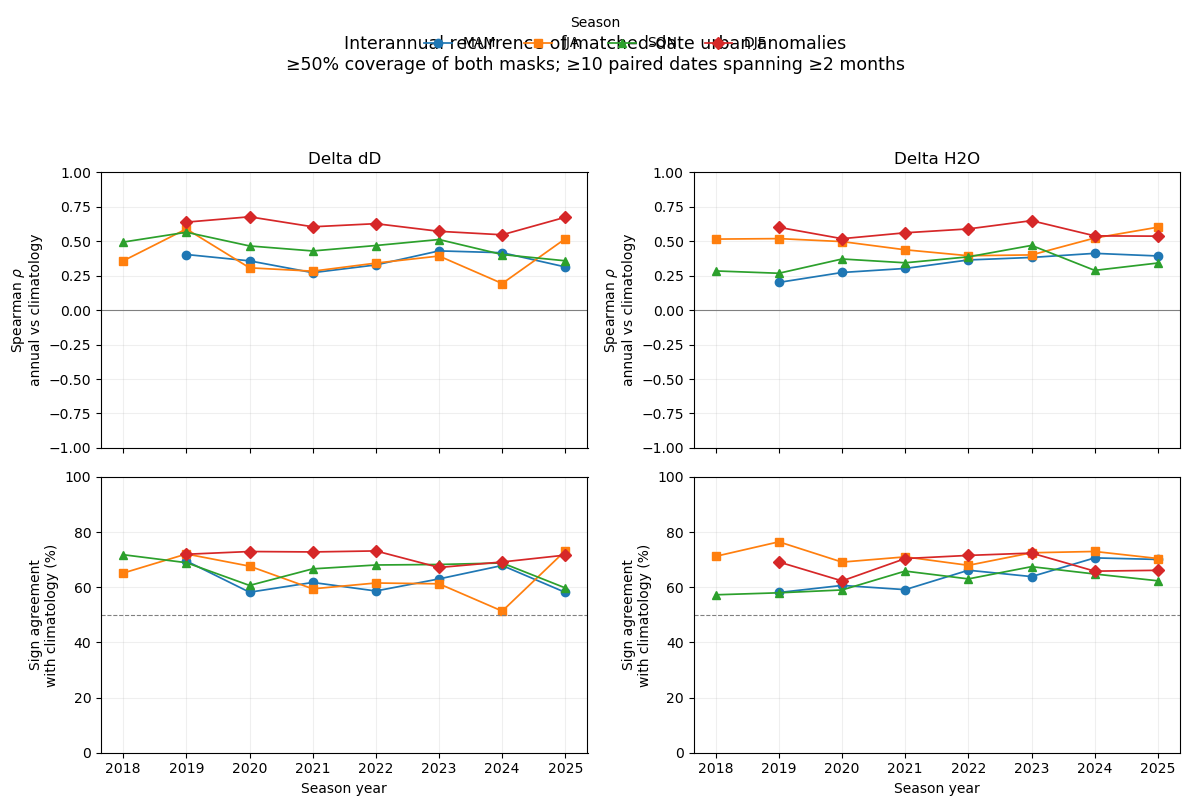


Saved:
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_interannual_all_cityseason_years.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_interannual_supported_cityseason_years.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_interannual_supported_vs_climatology.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_interannual_year_season_vs_climatology_stats.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_interannual_year_allseasons_vs_climatology_stats.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_interannual_pairwise_year_stats.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_interannual_cityseason_recurrence_4plus_years.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_interannual_cityseason_recurrence_all.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output

In [13]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr


# =============================================================================
# SETTINGS
# =============================================================================

# This section requires the shared notebook setup/path cell to have been run.
_required_setup_names = [
    "SOURCE_DATA_DIR",
    "OUTPUT_TABLES_DIR",
    "OUTPUT_FIGURES_DIR",
]
_missing_setup_names = [
    name for name in _required_setup_names
    if name not in globals()
]

if _missing_setup_names:
    raise RuntimeError(
        "Run the notebook setup/path cell first. Missing definitions: "
        + ", ".join(_missing_setup_names)
    )

SRC = Path(SOURCE_DATA_DIR)
RESULTS = Path(OUTPUT_TABLES_DIR)
FIGURES = Path(OUTPUT_FIGURES_DIR)

RESULTS.mkdir(
    parents=True,
    exist_ok=True,
)

FIGURES.mkdir(
    parents=True,
    exist_ok=True,
)


# -----------------------------------------------------------------------------
# Inputs
# -----------------------------------------------------------------------------

DAILY_CSV = SRC / "SameDay_daily_only_city_days.csv"

# Canonical per-city-season output produced by the Figure 2 section.
CLIM_CSV = RESULTS / "Figure_2_cityseason_results.csv"


# -----------------------------------------------------------------------------
# Primary interannual-support settings
#
# A qualifying DATE:
#   >=50% coverage of BOTH fixed urban and rural masks.
#
# A supported CITY-SEASON-YEAR:
#   >=10 qualifying paired dates
#   spanning >=2 months of that season.
#
# A city-season used for the recurrence summary:
#   >=4 supported years.
#
# Note:
# SameDay_daily_only_city_days.csv already inherited the original
# absolute daily floors of >=3 observed urban cells and >=10 observed
# rural cells. The 50% rule is therefore applied on top of those floors.
# -----------------------------------------------------------------------------

COVERAGE_THRESHOLD = 0.50

MIN_PAIRED_DAYS_PER_YEAR = 10

MIN_MONTHS_PER_YEAR = 2

MIN_SUPPORTED_YEARS_FOR_RECURRENCE = 4

# Require at least this many cities before treating a year-season
# correlation as informative.
MIN_CITIES_FOR_YEAR_STATS = 10

# Sensitivity of the annual support threshold
DAY_THRESHOLD_SENSITIVITY = [
    5,
    10,
    20,
]


SEASON_ORDER = [
    "MAM",
    "JJA",
    "SON",
    "DJF",
]

SEASON_MONTHS = {
    "MAM": {3, 4, 5},
    "JJA": {6, 7, 8},
    "SON": {9, 10, 11},
    "DJF": {12, 1, 2},
}


# =============================================================================
# CHECK INPUTS
# =============================================================================

if not DAILY_CSV.exists():
    raise FileNotFoundError(
        "Required same-day source data were not found:\n"
        f"    {DAILY_CSV}"
    )

if not CLIM_CSV.exists():
    raise FileNotFoundError(
        "Required Figure-2 city-season output was not found:\n"
        f"    {CLIM_CSV}\n\n"
        "Run the Figure 2 section first."
    )

print(
    "Daily matched-date data:",
    DAILY_CSV,
)

print(
    "Climatological results:",
    CLIM_CSV,
)


# =============================================================================
# LOAD
# =============================================================================

daily = pd.read_csv(
    DAILY_CSV
)

clim = pd.read_csv(
    CLIM_CSV
)


required_daily = [
    "date",
    "season",
    "city_key",
    "name",

    "n_urban_cells",
    "n_rural_cells",

    "urban_coverage_fraction",
    "rural_coverage_fraction",

    "urban_mean_d",
    "rural_mean_d",

    "urban_mean_h2o",
    "rural_mean_h2o",
]

required_clim = [
    "season",
    "city_key",
    "diff_d_mean",
    "diff_h_mean",
]


for c in required_daily:
    if c not in daily.columns:
        raise KeyError(
            f"Missing from daily CSV: {c}"
        )

for c in required_clim:
    if c not in clim.columns:
        raise KeyError(
            f"Missing from climatology CSV: {c}"
        )


# =============================================================================
# CLEAN KEYS / DATES
# =============================================================================

for df in [
    daily,
    clim,
]:

    df["season"] = (
        df["season"]
        .astype(str)
        .str.upper()
        .str.strip()
    )

    df["city_key"] = (
        df["city_key"]
        .astype(str)
        .str.strip()
        .str.replace(
            r"\.0$",
            "",
            regex=True,
        )
    )


daily["date"] = pd.to_datetime(
    daily["date"]
)

daily["calendar_year"] = (
    daily["date"]
    .dt
    .year
)

daily["month"] = (
    daily["date"]
    .dt
    .month
)


# =============================================================================
# CHECK SEASON LABELS AGAINST DATE
# =============================================================================

bad_season = []

for idx, row in daily[
    [
        "season",
        "month",
    ]
].iterrows():

    if (
        row["season"]
        in SEASON_MONTHS
    ):

        if (
            int(row["month"])
            not in
            SEASON_MONTHS[
                row["season"]
            ]
        ):
            bad_season.append(
                idx
            )


if len(bad_season):

    raise ValueError(
        f"Found {len(bad_season)} rows whose "
        "calendar month does not match the stated season."
    )

else:

    print(
        "\nSeason/month consistency: PASS"
    )


# =============================================================================
# DEFINE SEASON YEAR
#
# For MAM/JJA/SON:
#     season_year = calendar year
#
# For DJF:
#     Dec 2019 + Jan/Feb 2020 -> DJF 2020
#
# Thus December is assigned to the following year.
# =============================================================================

daily["season_year"] = (
    daily["calendar_year"]
)

is_december_djf = (
    (daily["season"] == "DJF")
    &
    (daily["month"] == 12)
)

daily.loc[
    is_december_djf,
    "season_year",
] += 1

daily["season_year"] = (
    daily["season_year"]
    .astype(int)
)


print(
    "\nSeason years present:",
    sorted(
        daily[
            "season_year"
        ].unique()
    ),
)


# =============================================================================
# DUPLICATE CHECK
# =============================================================================

dup = daily.duplicated(
    subset=[
        "season",
        "city_key",
        "date",
    ],
    keep=False,
)

if dup.any():

    raise ValueError(
        "Duplicate city-season-date rows found "
        "in SameDay_daily_only_city_days.csv."
    )

else:

    print(
        "City-date uniqueness: PASS"
    )


# =============================================================================
# EXPLICIT H2O UNIT HANDLING
#
# Daily TROPOMI values are expected to be molecules cm^-2.
# Convert them explicitly to kg m^-2 before calculating annual anomalies.
#
# The code detects the numerical scale first so that it will not
# accidentally convert twice if the input file has already been converted.
# =============================================================================

AVOGADRO = 6.02214076e23

H2O_MOLAR_MASS_KG_PER_MOL = (
    18.01528e-3
)

MOLEC_CM2_TO_KG_M2 = (
    H2O_MOLAR_MASS_KG_PER_MOL
    / AVOGADRO
    * 1.0e4
)


h_sample = np.concatenate(
    [
        daily[
            "urban_mean_h2o"
        ].to_numpy(float),

        daily[
            "rural_mean_h2o"
        ].to_numpy(float),
    ]
)

h_sample = h_sample[
    np.isfinite(
        h_sample
    )
]

h_median = np.nanmedian(
    np.abs(
        h_sample
    )
)


if h_median > 1.0e10:

    print(
        "\nDaily H2O appears to be in "
        "molecules cm^-2."
    )

    print(
        "Converting to kg m^-2 using:"
    )

    print(
        f"  1 molecule cm^-2 = "
        f"{MOLEC_CM2_TO_KG_M2:.8e} kg m^-2"
    )

    daily[
        "urban_mean_h2o_kgm2"
    ] = (
        daily[
            "urban_mean_h2o"
        ]
        * MOLEC_CM2_TO_KG_M2
    )

    daily[
        "rural_mean_h2o_kgm2"
    ] = (
        daily[
            "rural_mean_h2o"
        ]
        * MOLEC_CM2_TO_KG_M2
    )

else:

    print(
        "\nDaily H2O already appears to be "
        "on a kg m^-2-like scale."
    )

    print(
        "No unit conversion applied."
    )

    daily[
        "urban_mean_h2o_kgm2"
    ] = (
        daily[
            "urban_mean_h2o"
        ]
    )

    daily[
        "rural_mean_h2o_kgm2"
    ] = (
        daily[
            "rural_mean_h2o"
        ]
    )


print(
    "\nMedian daily H2O after conversion:"
)

print(
    "  urban = "
    f"{daily['urban_mean_h2o_kgm2'].median():.2f} kg m^-2"
)

print(
    "  rural = "
    f"{daily['rural_mean_h2o_kgm2'].median():.2f} kg m^-2"
)


# =============================================================================
# APPLY MATCHED-DATE COVERAGE CRITERION
# =============================================================================

coverage_ok = (
    np.isfinite(
        daily[
            "urban_coverage_fraction"
        ]
    )
    &
    np.isfinite(
        daily[
            "rural_coverage_fraction"
        ]
    )
    &
    (
        daily[
            "urban_coverage_fraction"
        ]
        >= COVERAGE_THRESHOLD
    )
    &
    (
        daily[
            "rural_coverage_fraction"
        ]
        >= COVERAGE_THRESHOLD
    )
)


paired = (
    daily.loc[
        coverage_ok
    ]
    .copy()
    .sort_values(
        [
            "season_year",
            "season",
            "city_key",
            "date",
        ]
    )
)


print(
    "\nMatched-date coverage filter:"
)

print(
    f"  all city-days       : "
    f"{len(daily):,}"
)

print(
    f"  >=50% both masks    : "
    f"{len(paired):,}"
)

print(
    f"  retained fraction   : "
    f"{100 * len(paired) / len(daily):.1f}%"
)


# =============================================================================
# FUNCTION: BUILD YEAR-RESOLVED CITY-SEASON ANOMALIES
# =============================================================================

def build_annual_cityseason(
    paired_daily,
    min_days=10,
    min_months=2,
):

    rows = []

    groups = paired_daily.groupby(
        [
            "season",
            "city_key",
            "name",
            "season_year",
        ],
        sort=False,
    )


    for (
        season,
        city_key,
        name,
        season_year,
    ), g in groups:

        g = (
            g
            .sort_values(
                "date"
            )
            .copy()
        )


        # ---------------------------------------------------------
        # Sampling support
        # ---------------------------------------------------------

        n_days = int(
            g[
                "date"
            ]
            .nunique()
        )

        months = sorted(
            g[
                "month"
            ]
            .dropna()
            .astype(int)
            .unique()
            .tolist()
        )

        n_months = len(
            months
        )


        # number of paired dates in each constituent month
        month_counts = (
            g.groupby(
                "month"
            )[
                "date"
            ]
            .nunique()
            .to_dict()
        )


        passes_support = (
            (n_days >= min_days)
            and
            (n_months >= min_months)
        )


        # ---------------------------------------------------------
        # Delta-D
        #
        # Each qualifying UTC date receives equal temporal weight.
        # ---------------------------------------------------------

        urban_d = float(
            g[
                "urban_mean_d"
            ]
            .mean()
        )

        rural_d = float(
            g[
                "rural_mean_d"
            ]
            .mean()
        )

        diff_d = (
            urban_d
            - rural_d
        )


        # ---------------------------------------------------------
        # H2O
        #
        # Absolute urban and rural columns are averaged separately
        # over the matched dates, after conversion to kg m^-2.
        #
        # The percentage anomaly is calculated only afterward.
        # ---------------------------------------------------------

        urban_h = float(
            g[
                "urban_mean_h2o_kgm2"
            ]
            .mean()
        )

        rural_h = float(
            g[
                "rural_mean_h2o_kgm2"
            ]
            .mean()
        )


        if (
            np.isfinite(
                rural_h
            )
            and
            rural_h != 0
        ):

            diff_h = (
                100.0
                * (
                    urban_h
                    - rural_h
                )
                / abs(
                    rural_h
                )
            )

        else:

            diff_h = np.nan


        # ---------------------------------------------------------
        # Within-year daily variability diagnostics
        # ---------------------------------------------------------

        daily_dd = (
            g[
                "urban_mean_d"
            ]
            -
            g[
                "rural_mean_d"
            ]
        )

        daily_h_abs = (
            g[
                "urban_mean_h2o_kgm2"
            ]
            -
            g[
                "rural_mean_h2o_kgm2"
            ]
        )


        rows.append(
            {
                "season":
                    season,

                "city_key":
                    city_key,

                "name":
                    name,

                "season_year":
                    int(
                        season_year
                    ),

                "n_paired_days":
                    n_days,

                "n_months":
                    n_months,

                "months_present":
                    ",".join(
                        str(m)
                        for m in months
                    ),

                "days_by_month":
                    ";".join(
                        f"{int(m)}:{int(month_counts[m])}"
                        for m in sorted(
                            month_counts
                        )
                    ),

                "first_date":
                    g[
                        "date"
                    ].min(),

                "last_date":
                    g[
                        "date"
                    ].max(),

                "passes_support":
                    passes_support,

                # dD
                "annual_urban_d":
                    urban_d,

                "annual_rural_d":
                    rural_d,

                "annual_diff_d":
                    diff_d,

                "daily_diff_d_sd":
                    float(
                        daily_dd.std(
                            ddof=1
                        )
                    )
                    if n_days >= 2
                    else np.nan,

                # H2O
                "annual_urban_h2o_kgm2":
                    urban_h,

                "annual_rural_h2o_kgm2":
                    rural_h,

                "annual_diff_h_pct":
                    diff_h,

                "daily_abs_h2o_diff_sd_kgm2":
                    float(
                        daily_h_abs.std(
                            ddof=1
                        )
                    )
                    if n_days >= 2
                    else np.nan,

                # coverage
                "mean_urban_coverage":
                    float(
                        g[
                            "urban_coverage_fraction"
                        ]
                        .mean()
                    ),

                "mean_rural_coverage":
                    float(
                        g[
                            "rural_coverage_fraction"
                        ]
                        .mean()
                    ),
            }
        )


    return pd.DataFrame(
        rows
    )


# =============================================================================
# PRIMARY ANNUAL ANALYSIS
# =============================================================================

annual_all = build_annual_cityseason(
    paired,
    min_days=
        MIN_PAIRED_DAYS_PER_YEAR,
    min_months=
        MIN_MONTHS_PER_YEAR,
)


annual = (
    annual_all[
        annual_all[
            "passes_support"
        ]
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 90
)

print(
    "PRIMARY YEAR-RESOLVED ANALYSIS"
)

print(
    "=" * 90
)

print(
    f"Coverage requirement       : "
    f">= {100*COVERAGE_THRESHOLD:.0f}% of BOTH masks"
)

print(
    f"Minimum paired dates/year : "
    f"{MIN_PAIRED_DAYS_PER_YEAR}"
)

print(
    f"Minimum months/year       : "
    f"{MIN_MONTHS_PER_YEAR}"
)

print(
    f"\nPotential city-season-years: "
    f"{len(annual_all):,}"
)

print(
    f"Supported city-season-years: "
    f"{len(annual):,}"
)


# =============================================================================
# SUPPORT BY YEAR AND SEASON
# =============================================================================

support_table = (
    annual.groupby(
        [
            "season_year",
            "season",
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        columns=
            SEASON_ORDER,
        fill_value=0,
    )
)


print(
    "\nSupported city-season estimates "
    "by season year:"
)

display(
    support_table
)


print(
    "\nDistribution of paired dates "
    "among supported annual estimates:"
)

display(
    annual[
        "n_paired_days"
    ]
    .describe(
        percentiles=[
            .05,
            .10,
            .25,
            .50,
            .75,
            .90,
            .95,
        ]
    )
    .to_frame()
    .T
    .round(1)
)


# =============================================================================
# MERGE WITH ORIGINAL CLIMATOLOGICAL ANOMALIES
# =============================================================================

annual_comp = annual.merge(
    clim[
        [
            "season",
            "city_key",
            "diff_d_mean",
            "diff_h_mean",
        ]
    ],
    on=[
        "season",
        "city_key",
    ],
    how="inner",
    validate="many_to_one",
)


print(
    "\nSupported annual estimates matched "
    "to original climatology:",
    len(
        annual_comp
    ),
)


# =============================================================================
# STATISTICS FUNCTION
# =============================================================================

def calc_stats(
    df,
    xcol,
    ycol,
):

    q = (
        df[
            [
                xcol,
                ycol,
            ]
        ]
        .replace(
            [
                np.inf,
                -np.inf,
            ],
            np.nan,
        )
        .dropna()
    )


    x = q[
        xcol
    ].to_numpy(
        float
    )

    y = q[
        ycol
    ].to_numpy(
        float
    )


    n = len(
        q
    )


    if n < 3:

        return {
            "N":
                n,

            "r":
                np.nan,

            "rho":
                np.nan,

            "sign_agreement_pct":
                np.nan,

            "bias":
                np.nan,

            "MAE":
                np.nan,
        }


    # Correlations are undefined if one side has zero variance.
    if (
        np.nanstd(
            x
        ) == 0
        or
        np.nanstd(
            y
        ) == 0
    ):

        r = np.nan
        rho = np.nan

    else:

        r = pearsonr(
            x,
            y,
        )[0]

        rho = spearmanr(
            x,
            y,
        )[0]


    err = (
        y - x
    )


    return {
        "N":
            n,

        "r":
            r,

        "rho":
            rho,

        "sign_agreement_pct":
            100.0
            * np.mean(
                np.sign(
                    x
                )
                ==
                np.sign(
                    y
                )
            ),

        "bias":
            np.mean(
                err
            ),

        "MAE":
            np.mean(
                np.abs(
                    err
                )
            ),
    }


# =============================================================================
# TEST 1:
# EACH YEAR-SEASON VS THE ORIGINAL MULTI-YEAR CLIMATOLOGY
# =============================================================================

year_season_rows = []


for (
    season_year,
    season,
), g in annual_comp.groupby(
    [
        "season_year",
        "season",
    ],
    sort=True,
):


    dd = calc_stats(
        g,
        "diff_d_mean",
        "annual_diff_d",
    )


    hh = calc_stats(
        g,
        "diff_h_mean",
        "annual_diff_h_pct",
    )


    year_season_rows.append(
        {
            "season_year":
                season_year,

            "season":
                season,

            "variable":
                "Delta dD",

            **dd,
        }
    )


    year_season_rows.append(
        {
            "season_year":
                season_year,

            "season":
                season,

            "variable":
                "Delta H2O",

            **hh,
        }
    )


year_season_stats = pd.DataFrame(
    year_season_rows
)


year_season_stats[
    "passes_min_city_count"
] = (
    year_season_stats[
        "N"
    ]
    >= MIN_CITIES_FOR_YEAR_STATS
)


print(
    "\n" + "=" * 90
)

print(
    "INDIVIDUAL YEARS VS ORIGINAL CLIMATOLOGY"
)

print(
    "=" * 90
)

display(
    year_season_stats[
        [
            "season_year",
            "season",
            "variable",
            "N",
            "r",
            "rho",
            "sign_agreement_pct",
            "MAE",
            "passes_min_city_count",
        ]
    ]
    .round(3)
)


# =============================================================================
# ALSO CALCULATE EACH YEAR WITH ALL SEASONS POOLED
#
# Every point remains a city-season, so its annual value is compared with
# that same city-season's original climatological value.
# =============================================================================

year_allseason_rows = []


for season_year, g in annual_comp.groupby(
    "season_year",
    sort=True,
):

    for (
        variable,
        xcol,
        ycol,
    ) in [

        (
            "Delta dD",
            "diff_d_mean",
            "annual_diff_d",
        ),

        (
            "Delta H2O",
            "diff_h_mean",
            "annual_diff_h_pct",
        ),
    ]:

        s = calc_stats(
            g,
            xcol,
            ycol,
        )

        year_allseason_rows.append(
            {
                "season_year":
                    int(
                        season_year
                    ),

                "variable":
                    variable,

                **s,
            }
        )


year_allseason_stats = pd.DataFrame(
    year_allseason_rows
)


print(
    "\nAll seasons pooled within each year:"
)

display(
    year_allseason_stats.round(
        3
    )
)


# =============================================================================
# TEST 2:
# DIRECT YEAR-TO-YEAR RECURRENCE
#
# This comparison does NOT use the multi-year climatology.
#
# For each season and pair of years, compare the anomalies for cities
# that have supported estimates in BOTH years.
# =============================================================================

pairwise_rows = []


for season in SEASON_ORDER:

    s = annual[
        annual[
            "season"
        ]
        == season
    ].copy()


    years = sorted(
        s[
            "season_year"
        ].unique()
    )


    for (
        year1,
        year2,
    ) in combinations(
        years,
        2,
    ):

        a = (
            s[
                s[
                    "season_year"
                ]
                == year1
            ][
                [
                    "city_key",
                    "annual_diff_d",
                    "annual_diff_h_pct",
                ]
            ]
            .rename(
                columns={
                    "annual_diff_d":
                        "d1",

                    "annual_diff_h_pct":
                        "h1",
                }
            )
        )


        b = (
            s[
                s[
                    "season_year"
                ]
                == year2
            ][
                [
                    "city_key",
                    "annual_diff_d",
                    "annual_diff_h_pct",
                ]
            ]
            .rename(
                columns={
                    "annual_diff_d":
                        "d2",

                    "annual_diff_h_pct":
                        "h2",
                }
            )
        )


        q = a.merge(
            b,
            on="city_key",
            how="inner",
            validate="one_to_one",
        )


        dd = calc_stats(
            q,
            "d1",
            "d2",
        )


        hh = calc_stats(
            q,
            "h1",
            "h2",
        )


        pairwise_rows.append(
            {
                "season":
                    season,

                "year1":
                    int(
                        year1
                    ),

                "year2":
                    int(
                        year2
                    ),

                "variable":
                    "Delta dD",

                **dd,
            }
        )


        pairwise_rows.append(
            {
                "season":
                    season,

                "year1":
                    int(
                        year1
                    ),

                "year2":
                    int(
                        year2
                    ),

                "variable":
                    "Delta H2O",

                **hh,
            }
        )


pairwise_year_stats = pd.DataFrame(
    pairwise_rows
)


pairwise_year_stats[
    "passes_min_city_count"
] = (
    pairwise_year_stats[
        "N"
    ]
    >= MIN_CITIES_FOR_YEAR_STATS
)


pairwise_good = (
    pairwise_year_stats[
        pairwise_year_stats[
            "passes_min_city_count"
        ]
    ]
    .copy()
)


print(
    "\n" + "=" * 90
)

print(
    "DIRECT YEAR-TO-YEAR RECURRENCE"
)

print(
    "=" * 90
)


if len(
    pairwise_good
):

    pairwise_summary = (
        pairwise_good.groupby(
            [
                "season",
                "variable",
            ]
        )
        .agg(
            n_year_pairs=(
                "rho",
                "size",
            ),

            median_N=(
                "N",
                "median",
            ),

            median_r=(
                "r",
                "median",
            ),

            median_rho=(
                "rho",
                "median",
            ),

            median_sign_agreement_pct=(
                "sign_agreement_pct",
                "median",
            ),

            fraction_positive_rho=(
                "rho",
                lambda x:
                    np.mean(
                        np.asarray(
                            x
                        )
                        > 0
                    ),
            ),
        )
        .reset_index()
    )


    display(
        pairwise_summary.round(
            3
        )
    )

else:

    pairwise_summary = pd.DataFrame()

    print(
        "No year pairs met the minimum-city requirement."
    )


# =============================================================================
# TEST 3:
# WITHIN-CITY-SEASON INTERANNUAL RECURRENCE
#
# For every city-season:
#
#   - number of supported years
#   - interannual SD and IQR
#   - fraction of years matching the sign of the manuscript climatology
#   - leave-one-year-out sign recurrence
#
# The leave-one-year-out metric is useful because the reference for a
# given year is calculated from the OTHER supported years only.
# =============================================================================

recurrence_rows = []


for (
    season,
    city_key,
    name,
), g in annual_comp.groupby(
    [
        "season",
        "city_key",
        "name",
    ],
    sort=False,
):

    g = (
        g
        .sort_values(
            "season_year"
        )
        .copy()
    )


    n_years = int(
        g[
            "season_year"
        ]
        .nunique()
    )


    years_string = ",".join(
        str(
            int(y)
        )
        for y in sorted(
            g[
                "season_year"
            ].unique()
        )
    )


    # climatological values are constant inside this group
    clim_d = float(
        g[
            "diff_d_mean"
        ].iloc[0]
    )

    clim_h = float(
        g[
            "diff_h_mean"
        ].iloc[0]
    )


    annual_d = (
        g[
            "annual_diff_d"
        ]
        .to_numpy(
            float
        )
    )

    annual_h = (
        g[
            "annual_diff_h_pct"
        ]
        .to_numpy(
            float
        )
    )


    # -------------------------------------------------------------
    # Sign agreement with manuscript climatology
    # -------------------------------------------------------------

    dd_sign_vs_clim = (
        100.0
        * np.mean(
            np.sign(
                annual_d
            )
            ==
            np.sign(
                clim_d
            )
        )
    )


    h_sign_vs_clim = (
        100.0
        * np.mean(
            np.sign(
                annual_h
            )
            ==
            np.sign(
                clim_h
            )
        )
    )


    # -------------------------------------------------------------
    # Leave-one-year-out recurrence
    #
    # For each year, calculate the mean anomaly from all OTHER
    # supported years, and test whether the held-out year has
    # the same sign.
    # -------------------------------------------------------------

    dd_loyo = []
    h_loyo = []


    if n_years >= 2:

        for k in range(
            n_years
        ):

            other_d = np.delete(
                annual_d,
                k,
            )

            other_h = np.delete(
                annual_h,
                k,
            )


            if (
                len(
                    other_d
                )
                and
                np.all(
                    np.isfinite(
                        other_d
                    )
                )
            ):

                dd_ref = np.mean(
                    other_d
                )

                dd_loyo.append(
                    np.sign(
                        annual_d[
                            k
                        ]
                    )
                    ==
                    np.sign(
                        dd_ref
                    )
                )


            if (
                len(
                    other_h
                )
                and
                np.all(
                    np.isfinite(
                        other_h
                    )
                )
            ):

                h_ref = np.mean(
                    other_h
                )

                h_loyo.append(
                    np.sign(
                        annual_h[
                            k
                        ]
                    )
                    ==
                    np.sign(
                        h_ref
                    )
                )


    dd_loyo_pct = (
        100.0
        * np.mean(
            dd_loyo
        )
        if len(
            dd_loyo
        )
        else np.nan
    )


    h_loyo_pct = (
        100.0
        * np.mean(
            h_loyo
        )
        if len(
            h_loyo
        )
        else np.nan
    )


    recurrence_rows.append(
        {
            "season":
                season,

            "city_key":
                city_key,

            "name":
                name,

            "n_supported_years":
                n_years,

            "supported_years":
                years_string,

            "clim_diff_d":
                clim_d,

            "clim_diff_h_pct":
                clim_h,

            # dD recurrence
            "annual_d_mean":
                np.mean(
                    annual_d
                ),

            "annual_d_median":
                np.median(
                    annual_d
                ),

            "annual_d_sd":
                np.std(
                    annual_d,
                    ddof=1,
                )
                if n_years >= 2
                else np.nan,

            "annual_d_iqr":
                (
                    np.percentile(
                        annual_d,
                        75,
                    )
                    -
                    np.percentile(
                        annual_d,
                        25,
                    )
                ),

            "d_sign_agreement_vs_clim_pct":
                dd_sign_vs_clim,

            "d_leave_one_year_out_sign_pct":
                dd_loyo_pct,

            # H2O recurrence
            "annual_h_mean_pct":
                np.mean(
                    annual_h
                ),

            "annual_h_median_pct":
                np.median(
                    annual_h
                ),

            "annual_h_sd_pct":
                np.std(
                    annual_h,
                    ddof=1,
                )
                if n_years >= 2
                else np.nan,

            "annual_h_iqr_pct":
                (
                    np.percentile(
                        annual_h,
                        75,
                    )
                    -
                    np.percentile(
                        annual_h,
                        25,
                    )
                ),

            "h_sign_agreement_vs_clim_pct":
                h_sign_vs_clim,

            "h_leave_one_year_out_sign_pct":
                h_loyo_pct,
        }
    )


recurrence_all = pd.DataFrame(
    recurrence_rows
)


recurrence = (
    recurrence_all[
        recurrence_all[
            "n_supported_years"
        ]
        >=
        MIN_SUPPORTED_YEARS_FOR_RECURRENCE
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 90
)

print(
    "WITHIN-CITY-SEASON INTERANNUAL RECURRENCE"
)

print(
    "=" * 90
)


print(
    f"City-seasons with >= "
    f"{MIN_SUPPORTED_YEARS_FOR_RECURRENCE} "
    f"supported years: "
    f"{len(recurrence):,}"
)


print(
    "\nNumber of supported years:"
)

print(
    recurrence[
        "n_supported_years"
    ]
    .value_counts()
    .sort_index()
)


if len(
    recurrence
):

    recurrence_summary = pd.DataFrame(
        [
            {
                "variable":
                    "Delta dD",

                "N_cityseasons":
                    len(
                        recurrence
                    ),

                "median_supported_years":
                    recurrence[
                        "n_supported_years"
                    ].median(),

                "median_sign_agreement_vs_clim_pct":
                    recurrence[
                        "d_sign_agreement_vs_clim_pct"
                    ].median(),

                "mean_sign_agreement_vs_clim_pct":
                    recurrence[
                        "d_sign_agreement_vs_clim_pct"
                    ].mean(),

                "median_leave_one_year_out_sign_pct":
                    recurrence[
                        "d_leave_one_year_out_sign_pct"
                    ].median(),

                "median_interannual_SD":
                    recurrence[
                        "annual_d_sd"
                    ].median(),

                "median_interannual_IQR":
                    recurrence[
                        "annual_d_iqr"
                    ].median(),
            },

            {
                "variable":
                    "Delta H2O",

                "N_cityseasons":
                    len(
                        recurrence
                    ),

                "median_supported_years":
                    recurrence[
                        "n_supported_years"
                    ].median(),

                "median_sign_agreement_vs_clim_pct":
                    recurrence[
                        "h_sign_agreement_vs_clim_pct"
                    ].median(),

                "mean_sign_agreement_vs_clim_pct":
                    recurrence[
                        "h_sign_agreement_vs_clim_pct"
                    ].mean(),

                "median_leave_one_year_out_sign_pct":
                    recurrence[
                        "h_leave_one_year_out_sign_pct"
                    ].median(),

                "median_interannual_SD":
                    recurrence[
                        "annual_h_sd_pct"
                    ].median(),

                "median_interannual_IQR":
                    recurrence[
                        "annual_h_iqr_pct"
                    ].median(),
            },
        ]
    )


    display(
        recurrence_summary.round(
            3
        )
    )

else:

    recurrence_summary = pd.DataFrame()


# =============================================================================
# SHOW BEST / WORST SIGN RECURRENCE EXAMPLES
# =============================================================================

if len(
    recurrence
):

    print(
        "\nLowest delta-D sign recurrence:"
    )

    display(
        recurrence[
            [
                "name",
                "season",
                "n_supported_years",
                "supported_years",
                "clim_diff_d",
                "annual_d_mean",
                "annual_d_sd",
                "d_sign_agreement_vs_clim_pct",
                "d_leave_one_year_out_sign_pct",
            ]
        ]
        .sort_values(
            [
                "d_sign_agreement_vs_clim_pct",
                "n_supported_years",
            ],
            ascending=[
                True,
                False,
            ],
        )
        .head(
            15
        )
        .round(
            3
        )
    )


    print(
        "\nLowest H2O sign recurrence:"
    )

    display(
        recurrence[
            [
                "name",
                "season",
                "n_supported_years",
                "supported_years",
                "clim_diff_h_pct",
                "annual_h_mean_pct",
                "annual_h_sd_pct",
                "h_sign_agreement_vs_clim_pct",
                "h_leave_one_year_out_sign_pct",
            ]
        ]
        .sort_values(
            [
                "h_sign_agreement_vs_clim_pct",
                "n_supported_years",
            ],
            ascending=[
                True,
                False,
            ],
        )
        .head(
            15
        )
        .round(
            3
        )
    )


# =============================================================================
# SUPPORT-THRESHOLD SENSITIVITY
#
# Repeat the annual aggregation for 5, 10, and 20 paired dates/year.
#
# For each threshold, summarize the year-season comparisons that have
# >= MIN_CITIES_FOR_YEAR_STATS cities.
# =============================================================================

sensitivity_rows = []


for min_days_test in DAY_THRESHOLD_SENSITIVITY:

    a_all = build_annual_cityseason(
        paired,
        min_days=
            min_days_test,
        min_months=
            MIN_MONTHS_PER_YEAR,
    )

    a = (
        a_all[
            a_all[
                "passes_support"
            ]
        ]
        .copy()
    )


    a_comp = a.merge(
        clim[
            [
                "season",
                "city_key",
                "diff_d_mean",
                "diff_h_mean",
            ]
        ],
        on=[
            "season",
            "city_key",
        ],
        how="inner",
        validate="many_to_one",
    )


    local_stats = []


    for (
        sy,
        season,
    ), g in a_comp.groupby(
        [
            "season_year",
            "season",
        ]
    ):

        for (
            variable,
            xcol,
            ycol,
        ) in [

            (
                "Delta dD",
                "diff_d_mean",
                "annual_diff_d",
            ),

            (
                "Delta H2O",
                "diff_h_mean",
                "annual_diff_h_pct",
            ),
        ]:

            ss = calc_stats(
                g,
                xcol,
                ycol,
            )

            if (
                ss[
                    "N"
                ]
                >=
                MIN_CITIES_FOR_YEAR_STATS
            ):

                local_stats.append(
                    {
                        "season_year":
                            sy,

                        "season":
                            season,

                        "variable":
                            variable,

                        **ss,
                    }
                )


    local_stats = pd.DataFrame(
        local_stats
    )


    for variable in [
        "Delta dD",
        "Delta H2O",
    ]:

        q = (
            local_stats[
                local_stats[
                    "variable"
                ]
                == variable
            ]
            if len(
                local_stats
            )
            else pd.DataFrame()
        )


        # number of city-seasons having >=4 supported years
        counts = (
            a.groupby(
                [
                    "season",
                    "city_key",
                ]
            )[
                "season_year"
            ]
            .nunique()
        )

        n_recurrence = int(
            np.sum(
                counts
                >=
                MIN_SUPPORTED_YEARS_FOR_RECURRENCE
            )
        )


        sensitivity_rows.append(
            {
                "min_paired_days_per_year":
                    min_days_test,

                "min_months_per_year":
                    MIN_MONTHS_PER_YEAR,

                "variable":
                    variable,

                "n_supported_annual_cityseasons":
                    len(
                        a
                    ),

                "n_cityseasons_with_4plus_years":
                    n_recurrence,

                "n_year_season_comparisons":
                    len(
                        q
                    ),

                "median_year_season_r":
                    (
                        q[
                            "r"
                        ].median()
                        if len(
                            q
                        )
                        else np.nan
                    ),

                "median_year_season_rho":
                    (
                        q[
                            "rho"
                        ].median()
                        if len(
                            q
                        )
                        else np.nan
                    ),

                "median_year_season_sign_agreement_pct":
                    (
                        q[
                            "sign_agreement_pct"
                        ].median()
                        if len(
                            q
                        )
                        else np.nan
                    ),
            }
        )


sensitivity = pd.DataFrame(
    sensitivity_rows
)


print(
    "\n" + "=" * 90
)

print(
    "5 / 10 / 20-DAY ANNUAL SUPPORT SENSITIVITY"
)

print(
    "=" * 90
)

display(
    sensitivity.round(
        3
    )
)


# =============================================================================
# SUMMARY FIGURE:
#
# Top row    : Spearman rho, annual pattern vs climatology
# Bottom row : sign agreement, annual pattern vs climatology
#
# One column per variable.
# =============================================================================

plot_stats = (
    year_season_stats[
        year_season_stats[
            "passes_min_city_count"
        ]
    ]
    .copy()
)


markers = {
    "MAM": "o",
    "JJA": "s",
    "SON": "^",
    "DJF": "D",
}


cycle = (
    plt.rcParams[
        "axes.prop_cycle"
    ]
    .by_key()[
        "color"
    ]
)

colors = dict(
    zip(
        SEASON_ORDER,
        cycle[:4],
    )
)


fig, axes = plt.subplots(
    2,
    2,
    figsize=(
        12,
        8,
    ),
    sharex=True,
)


variable_columns = {
    "Delta dD": 0,
    "Delta H2O": 1,
}


for variable, col in variable_columns.items():

    qv = plot_stats[
        plot_stats[
            "variable"
        ]
        == variable
    ]


    # -------------------------------------------------------------------------
    # Spearman rho
    # -------------------------------------------------------------------------

    ax = axes[
        0,
        col,
    ]


    for season in SEASON_ORDER:

        q = (
            qv[
                qv[
                    "season"
                ]
                == season
            ]
            .sort_values(
                "season_year"
            )
        )


        if len(
            q
        ) == 0:

            continue


        ax.plot(
            q[
                "season_year"
            ],
            q[
                "rho"
            ],

            marker=
                markers[
                    season
                ],

            linewidth=1.25,

            markersize=6,

            color=
                colors[
                    season
                ],

            label=
                season,
        )


    ax.axhline(
        0,
        color="0.5",
        linewidth=0.8,
    )

    ax.set_ylim(
        -1,
        1,
    )

    ax.set_ylabel(
        "Spearman "
        r"$\rho$"
        "\nannual vs climatology"
    )

    ax.set_title(
        variable
    )

    ax.grid(
        True,
        alpha=0.2,
    )


    # -------------------------------------------------------------------------
    # Sign agreement
    # -------------------------------------------------------------------------

    ax = axes[
        1,
        col,
    ]


    for season in SEASON_ORDER:

        q = (
            qv[
                qv[
                    "season"
                ]
                == season
            ]
            .sort_values(
                "season_year"
            )
        )


        if len(
            q
        ) == 0:

            continue


        ax.plot(
            q[
                "season_year"
            ],
            q[
                "sign_agreement_pct"
            ],

            marker=
                markers[
                    season
                ],

            linewidth=1.25,

            markersize=6,

            color=
                colors[
                    season
                ],

            label=
                season,
        )


    ax.axhline(
        50,
        color="0.5",
        linestyle="--",
        linewidth=0.8,
    )

    ax.set_ylim(
        0,
        100,
    )

    ax.set_xlabel(
        "Season year"
    )

    ax.set_ylabel(
        "Sign agreement\n"
        "with climatology (%)"
    )

    ax.grid(
        True,
        alpha=0.2,
    )


handles, labels = (
    axes[
        0,
        0,
    ]
    .get_legend_handles_labels()
)


fig.legend(
    handles,
    labels,

    loc="upper center",

    ncol=4,

    frameon=False,

    title="Season",

    bbox_to_anchor=(
        0.5,
        1.01,
    ),
)


fig.suptitle(
    "Interannual recurrence of matched-date urban anomalies\n"
    "≥50% coverage of both masks; "
    f"≥{MIN_PAIRED_DAYS_PER_YEAR} paired dates "
    f"spanning ≥{MIN_MONTHS_PER_YEAR} months",
    fontsize=12.5,
    y=0.97,
)


fig.tight_layout(
    rect=[
        0,
        0,
        1,
        0.91,
    ]
)


# =============================================================================
# SAVE
# =============================================================================

ANNUAL_ALL_OUT = (
    RESULTS
    / "SameDay_interannual_all_cityseason_years.csv"
)

ANNUAL_OUT = (
    RESULTS
    / "SameDay_interannual_supported_cityseason_years.csv"
)

ANNUAL_COMP_OUT = (
    RESULTS
    / "SameDay_interannual_supported_vs_climatology.csv"
)

YEAR_STATS_OUT = (
    RESULTS
    / "SameDay_interannual_year_season_vs_climatology_stats.csv"
)

YEAR_ALLSEASON_STATS_OUT = (
    RESULTS
    / "SameDay_interannual_year_allseasons_vs_climatology_stats.csv"
)

PAIRWISE_OUT = (
    RESULTS
    / "SameDay_interannual_pairwise_year_stats.csv"
)

RECURRENCE_OUT = (
    RESULTS
    / "SameDay_interannual_cityseason_recurrence_4plus_years.csv"
)

RECURRENCE_ALL_OUT = (
    RESULTS
    / "SameDay_interannual_cityseason_recurrence_all.csv"
)

SENSITIVITY_OUT = (
    RESULTS
    / "SameDay_interannual_5_10_20day_support_sensitivity.csv"
)

FIG_OUT = (
    FIGURES
    / "Supplement_Figure_9_Interannual_recurrence.png"
)


annual_all.to_csv(
    ANNUAL_ALL_OUT,
    index=False,
)

annual.to_csv(
    ANNUAL_OUT,
    index=False,
)

annual_comp.to_csv(
    ANNUAL_COMP_OUT,
    index=False,
)

year_season_stats.to_csv(
    YEAR_STATS_OUT,
    index=False,
)

year_allseason_stats.to_csv(
    YEAR_ALLSEASON_STATS_OUT,
    index=False,
)

pairwise_year_stats.to_csv(
    PAIRWISE_OUT,
    index=False,
)

recurrence.to_csv(
    RECURRENCE_OUT,
    index=False,
)

recurrence_all.to_csv(
    RECURRENCE_ALL_OUT,
    index=False,
)

sensitivity.to_csv(
    SENSITIVITY_OUT,
    index=False,
)

fig.savefig(
    FIG_OUT,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FIG_OUT.with_suffix(".pdf"),
    bbox_inches="tight",
)

plt.show()


print(
    "\nSaved:"
)

for p in [
    ANNUAL_ALL_OUT,
    ANNUAL_OUT,
    ANNUAL_COMP_OUT,
    YEAR_STATS_OUT,
    YEAR_ALLSEASON_STATS_OUT,
    PAIRWISE_OUT,
    RECURRENCE_OUT,
    RECURRENCE_ALL_OUT,
    SENSITIVITY_OUT,
    FIG_OUT,
]:

    print(
        " ",
        p,
    )


## Reviewer check - recurrence summaries


In [14]:
from pathlib import Path
import numpy as np
import pandas as pd

# =============================================================================
# SETTINGS
# =============================================================================

ROOT = PROJECT_ROOT
RESULTS = OUTPUT_TABLES_DIR

ANNUAL_CSV = (
    RESULTS
    / "SameDay_interannual_supported_cityseason_years.csv"
)

MIN_SUPPORTED_YEARS = 4

# =============================================================================
# LOAD
# =============================================================================

annual = pd.read_csv(ANNUAL_CSV)

required = [
    "season",
    "season_year",
    "city_key",
    "name",
    "annual_diff_d",
    "annual_diff_h_pct",
]

missing = [c for c in required if c not in annual.columns]

if missing:
    raise KeyError(f"Missing columns: {missing}")

# =============================================================================
# SIGN RECURRENCE
# =============================================================================

def sign_recurrence(df, value_col, variable):

    rows = []

    for (season, city_key, name), g in df.groupby(
        ["season", "city_key", "name"],
        sort=False,
    ):

        x = g[value_col].to_numpy(float)
        x = x[np.isfinite(x)]

        # Exact zeros carry no positive/negative sign information.
        x = x[x != 0]

        n = len(x)

        if n < MIN_SUPPORTED_YEARS:
            continue

        n_pos = int(np.sum(x > 0))
        n_neg = int(np.sum(x < 0))

        dominant_fraction = max(n_pos, n_neg) / n

        # Fraction of all possible year pairs having the same sign.
        same_pairs = (
            n_pos * (n_pos - 1) / 2
            + n_neg * (n_neg - 1) / 2
        )

        total_pairs = n * (n - 1) / 2

        pairwise_same_sign = (
            same_pairs / total_pairs
            if total_pairs > 0
            else np.nan
        )

        rows.append({
            "variable": variable,
            "season": season,
            "city_key": city_key,
            "name": name,
            "n_supported_years": n,
            "n_positive_years": n_pos,
            "n_negative_years": n_neg,
            "dominant_sign_fraction": dominant_fraction,
            "pairwise_same_sign_fraction": pairwise_same_sign,
            "all_years_same_sign": dominant_fraction == 1.0,
        })

    return pd.DataFrame(rows)


recurrence = pd.concat(
    [
        sign_recurrence(
            annual,
            "annual_diff_d",
            "Delta dD",
        ),
        sign_recurrence(
            annual,
            "annual_diff_h_pct",
            "Delta H2O",
        ),
    ],
    ignore_index=True,
)

# =============================================================================
# SUMMARY
# =============================================================================

def summarize(g):

    return pd.Series({
        "N_cityseasons": len(g),

        "median_supported_years":
            g["n_supported_years"].median(),

        "mean_dominant_sign_pct":
            100 * g["dominant_sign_fraction"].mean(),

        "median_dominant_sign_pct":
            100 * g["dominant_sign_fraction"].median(),

        "mean_pairwise_same_sign_pct":
            100 * g["pairwise_same_sign_fraction"].mean(),

        "median_pairwise_same_sign_pct":
            100 * g["pairwise_same_sign_fraction"].median(),

        "all_years_same_sign_pct":
            100 * g["all_years_same_sign"].mean(),

        "at_least_75pct_same_sign_pct":
            100 * np.mean(
                g["dominant_sign_fraction"] >= 0.75
            ),
    })


overall = (
    recurrence.groupby("variable")
    .apply(summarize)
    .reset_index()
)

by_season = (
    recurrence.groupby(["variable", "season"])
    .apply(summarize)
    .reset_index()
)

print("\nOVERALL SIGN RECURRENCE")
display(overall.round(1))

print("\nSIGN RECURRENCE BY SEASON")
display(by_season.round(1))

# =============================================================================
# SAVE
# =============================================================================

DETAIL_OUT = (
    RESULTS
    / "SameDay_interannual_cityseason_sign_recurrence.csv"
)

SUMMARY_OUT = (
    RESULTS
    / "SameDay_interannual_sign_recurrence_summary.csv"
)

SEASON_OUT = (
    RESULTS
    / "SameDay_interannual_sign_recurrence_by_season.csv"
)

recurrence.to_csv(DETAIL_OUT, index=False)
overall.to_csv(SUMMARY_OUT, index=False)
by_season.to_csv(SEASON_OUT, index=False)

print("\nSaved:")
print(" ", DETAIL_OUT)
print(" ", SUMMARY_OUT)
print(" ", SEASON_OUT)



OVERALL SIGN RECURRENCE


,variable,N_cityseasons,median_supported_years,mean_dominant_sign_pct,median_dominant_sign_pct,mean_pairwise_same_sign_pct,median_pairwise_same_sign_pct,all_years_same_sign_pct,at_least_75pct_same_sign_pct
0,Delta H2O,436.0,7.0,78.9,80.0,67.1,60.0,26.8,58.5
1,Delta dD,436.0,7.0,78.5,80.0,66.8,60.0,27.3,59.6



SIGN RECURRENCE BY SEASON


,variable,season,N_cityseasons,median_supported_years,mean_dominant_sign_pct,median_dominant_sign_pct,mean_pairwise_same_sign_pct,median_pairwise_same_sign_pct,all_years_same_sign_pct,at_least_75pct_same_sign_pct
0,Delta H2O,DJF,123.0,7.0,81.8,85.7,71.2,71.4,35.8,59.3
1,Delta H2O,JJA,71.0,8.0,81.2,87.5,70.2,75.0,28.2,73.2
2,Delta H2O,MAM,122.0,7.0,75.4,71.4,61.8,52.4,20.5,47.5
3,Delta H2O,SON,120.0,8.0,78.3,80.0,66.4,60.0,23.3,60.0
4,Delta dD,DJF,123.0,7.0,82.9,85.7,72.6,71.4,37.4,63.4
5,Delta dD,JJA,71.0,8.0,74.1,71.4,63.5,52.4,23.9,49.3
6,Delta dD,MAM,122.0,7.0,76.2,75.0,63.5,52.4,25.4,53.3
7,Delta dD,SON,120.0,8.0,79.0,77.5,66.1,58.6,20.8,68.3



Saved:
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_interannual_cityseason_sign_recurrence.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_interannual_sign_recurrence_summary.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_interannual_sign_recurrence_by_season.csv


## Final Supplementary Figure 9


Years: [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

INTERANNUAL SIGN CONSISTENCY
Definition: a city-season is sign-consistent when the same sign occurs in >= 75% of its supported years.


,variable,season,N_cityseasons,pct_cityseasons_at_least_75pct_same_sign,pct_cityseasons_all_years_same_sign,mean_dominant_sign_fraction_pct
0,Delta dD,MAM,122,53.3,25.4,76.2
1,Delta dD,JJA,71,49.3,23.9,74.1
2,Delta dD,SON,120,68.3,20.8,79.0
3,Delta dD,DJF,123,63.4,37.4,82.9
4,Delta H2O,MAM,122,47.5,20.5,75.4
5,Delta H2O,JJA,71,73.2,28.2,81.2
6,Delta H2O,SON,120,60.0,23.3,78.3
7,Delta H2O,DJF,123,59.3,35.8,81.8


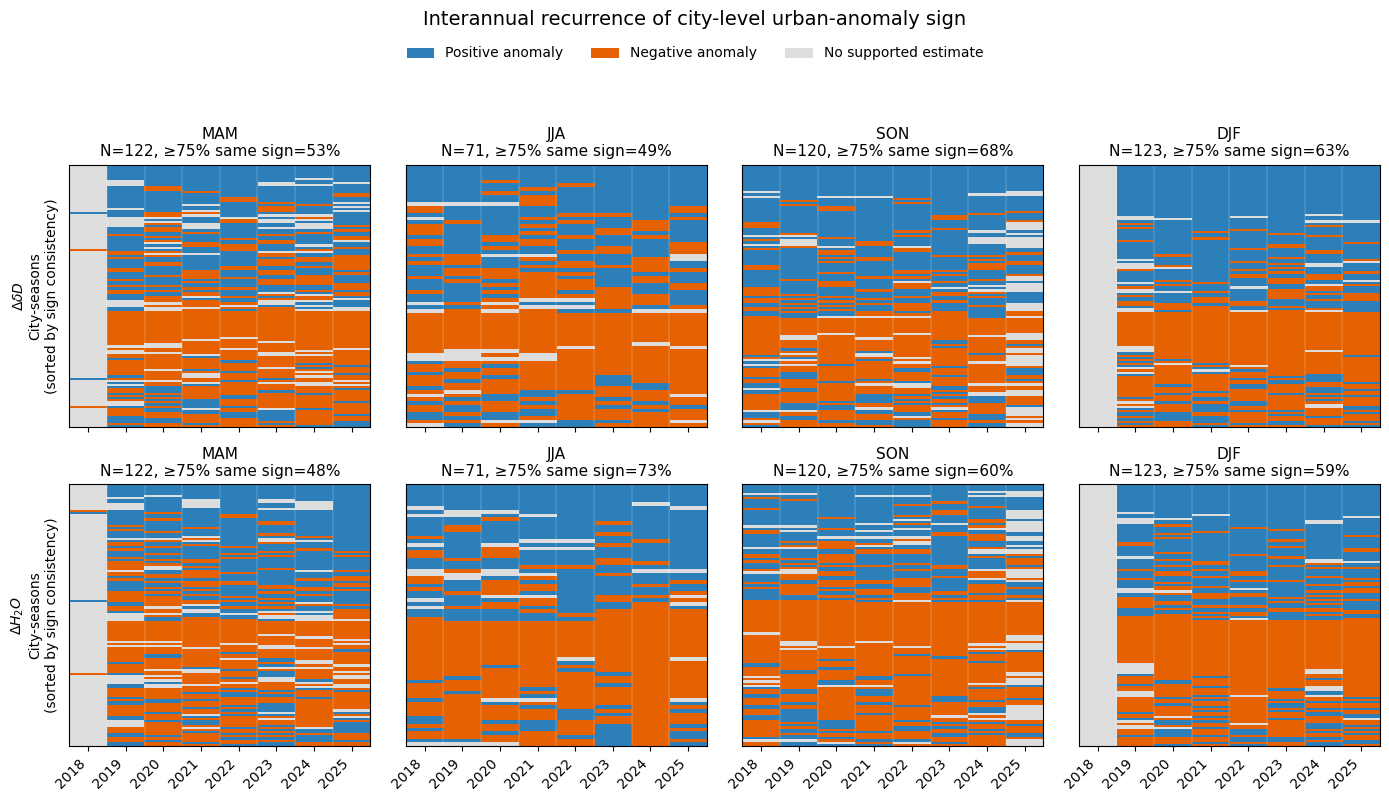


Saved:
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_interannual_sign_consistency_cityseason.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/tables/SameDay_interannual_sign_consistency_summary.csv
  /Users/a391980/Downloads/UrbanWaterVaporIsotopes/output/figures/Supplement_Figure_9_Interannual_recurrence.png


In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


# =============================================================================
# SETTINGS
# =============================================================================

ROOT = PROJECT_ROOT
RESULTS = OUTPUT_TABLES_DIR
FIGURES = OUTPUT_FIGURES_DIR

FIGURES.mkdir(parents=True, exist_ok=True)

ANNUAL_CSV = (
    RESULTS
    / "SameDay_interannual_supported_cityseason_years.csv"
)

# Require a city-season to have estimates in at least this many years
MIN_SUPPORTED_YEARS = 4

# A city-season is called sign-consistent if either the positive or negative
# sign occurs in at least this fraction of its supported years.
CONSISTENCY_THRESHOLD = 0.75

# Set False if you want the panel title to show only N.
# The statistic is calculated and saved regardless.
DISPLAY_75PCT_SAME_SIGN = True

SEASONS = [
    "MAM",
    "JJA",
    "SON",
    "DJF",
]

VARIABLES = [
    (
        "annual_diff_d",
        "Delta dD",
        r"$\Delta\delta D$",
    ),
    (
        "annual_diff_h_pct",
        "Delta H2O",
        r"$\Delta H_2O$",
    ),
]


# =============================================================================
# LOAD
# =============================================================================

annual = pd.read_csv(
    ANNUAL_CSV
)

required = [
    "season",
    "season_year",
    "city_key",
    "name",
    "annual_diff_d",
    "annual_diff_h_pct",
]

missing = [
    c for c in required
    if c not in annual.columns
]

if missing:
    raise KeyError(
        f"Missing required columns: {missing}"
    )

annual["season"] = (
    annual["season"]
    .astype(str)
    .str.upper()
    .str.strip()
)

annual["season_year"] = (
    annual["season_year"]
    .astype(int)
)

years = sorted(
    annual["season_year"]
    .dropna()
    .unique()
)

print("Years:", years)


# =============================================================================
# BUILD SIGN MATRIX
# =============================================================================

def build_sign_matrix(
    df,
    season,
    value_col,
):
    """
    Build one year-by-city-season sign matrix.

    Values:
        +1 = positive urban anomaly
        -1 = negative urban anomaly
        NaN = no supported annual estimate

    Only city-seasons with at least MIN_SUPPORTED_YEARS non-zero,
    finite annual anomalies are retained.
    """

    q = df[
        df["season"] == season
    ].copy()

    q = q[
        np.isfinite(
            q[value_col]
        )
    ].copy()

    # -------------------------------------------------------------------------
    # Annual anomaly sign
    # -------------------------------------------------------------------------

    q["sign"] = np.sign(
        q[value_col]
    )

    # An exact zero contains no positive/negative sign information.
    q.loc[
        q["sign"] == 0,
        "sign",
    ] = np.nan

    # -------------------------------------------------------------------------
    # Require >= MIN_SUPPORTED_YEARS
    # -------------------------------------------------------------------------

    support = (
        q.groupby(
            [
                "city_key",
                "name",
            ]
        )["sign"]
        .count()
        .rename(
            "n_supported_years"
        )
        .reset_index()
    )

    support = support[
        support[
            "n_supported_years"
        ]
        >= MIN_SUPPORTED_YEARS
    ]

    q = q.merge(
        support,
        on=[
            "city_key",
            "name",
        ],
        how="inner",
    )

    if q.empty:
        return None, None

    # -------------------------------------------------------------------------
    # Matrix:
    # rows    = city-seasons
    # columns = season-years
    # -------------------------------------------------------------------------

    matrix = (
        q.pivot_table(
            index=[
                "city_key",
                "name",
            ],
            columns="season_year",
            values="sign",
            aggfunc="first",
        )
        .reindex(
            columns=years
        )
    )

    # -------------------------------------------------------------------------
    # Statistics for each city-season
    # -------------------------------------------------------------------------

    row_stats = []

    for idx, row in matrix.iterrows():

        x = row.to_numpy(
            dtype=float
        )

        x = x[
            np.isfinite(x)
        ]

        n = len(x)

        if n == 0:
            continue

        n_pos = int(
            np.sum(
                x > 0
            )
        )

        n_neg = int(
            np.sum(
                x < 0
            )
        )

        frac_positive = (
            n_pos / n
        )

        frac_negative = (
            n_neg / n
        )

        dominant_fraction = max(
            frac_positive,
            frac_negative,
        )

        dominant_sign = (
            1
            if n_pos >= n_neg
            else -1
        )

        # -------------------------------------------------------------
        # Threshold-based recurrence statistic
        # -------------------------------------------------------------

        sign_consistent_75pct = (
            dominant_fraction
            >= CONSISTENCY_THRESHOLD
        )

        # -------------------------------------------------------------
        # Pairwise recurrence retained as an optional diagnostic,
        # but no longer displayed in the figure.
        # -------------------------------------------------------------

        same_pairs = (
            n_pos
            * (n_pos - 1)
            / 2
            +
            n_neg
            * (n_neg - 1)
            / 2
        )

        total_pairs = (
            n
            * (n - 1)
            / 2
        )

        pairwise_recurrence = (
            same_pairs
            / total_pairs
            if total_pairs > 0
            else np.nan
        )

        row_stats.append(
            {
                "index": idx,

                "n_supported_years":
                    n,

                "n_positive_years":
                    n_pos,

                "n_negative_years":
                    n_neg,

                "frac_positive":
                    frac_positive,

                "frac_negative":
                    frac_negative,

                "dominant_sign":
                    dominant_sign,

                "dominant_fraction":
                    dominant_fraction,

                "sign_consistent_75pct":
                    sign_consistent_75pct,

                "pairwise_recurrence":
                    pairwise_recurrence,
            }
        )

    stats = pd.DataFrame(
        row_stats
    )

    if stats.empty:
        return None, None

    stats = stats.set_index(
        "index"
    )

    # -------------------------------------------------------------------------
    # Sort for visualization:
    #
    #   1. positive-dominant city-seasons first
    #   2. negative-dominant city-seasons second
    #   3. within each group, strongest recurrence first
    #   4. then number of supported years
    #
    # This makes persistent horizontal bands visually apparent.
    # -------------------------------------------------------------------------

    stats = stats.sort_values(
        [
            "dominant_sign",
            "dominant_fraction",
            "n_supported_years",
        ],
        ascending=[
            False,
            False,
            False,
        ],
    )

    matrix = matrix.loc[
        stats.index
    ]

    return matrix, stats


# =============================================================================
# BUILD ALL PANELS AND SUMMARY TABLE
# =============================================================================

panel_data = {}
summary_rows = []
detail_rows = []

for (
    value_col,
    variable_name,
    variable_label,
) in VARIABLES:

    for season in SEASONS:

        matrix, stats = (
            build_sign_matrix(
                annual,
                season,
                value_col,
            )
        )

        panel_data[
            (
                variable_name,
                season,
            )
        ] = (
            matrix,
            stats,
        )

        if matrix is None:
            continue

        n_cityseasons = len(
            stats
        )

        consistent_pct = (
            100
            * stats[
                "sign_consistent_75pct"
            ].mean()
        )

        all_years_same_sign_pct = (
            100
            * (
                stats[
                    "dominant_fraction"
                ]
                == 1.0
            ).mean()
        )

        mean_dominant_fraction = (
            100
            * stats[
                "dominant_fraction"
            ].mean()
        )

        median_dominant_fraction = (
            100
            * stats[
                "dominant_fraction"
            ].median()
        )

        mean_pairwise_recurrence = (
            100
            * stats[
                "pairwise_recurrence"
            ].mean()
        )

        summary_rows.append(
            {
                "variable":
                    variable_name,

                "season":
                    season,

                "N_cityseasons":
                    n_cityseasons,

                "consistency_threshold":
                    CONSISTENCY_THRESHOLD,

                "pct_cityseasons_at_least_75pct_same_sign":
                    consistent_pct,

                "pct_cityseasons_all_years_same_sign":
                    all_years_same_sign_pct,

                "mean_dominant_sign_fraction_pct":
                    mean_dominant_fraction,

                "median_dominant_sign_fraction_pct":
                    median_dominant_fraction,

                "mean_pairwise_same_sign_pct":
                    mean_pairwise_recurrence,
            }
        )

        # -------------------------------------------------------------
        # Detailed city-season table
        # -------------------------------------------------------------

        for idx, row in stats.iterrows():

            city_key, name = idx

            detail_rows.append(
                {
                    "variable":
                        variable_name,

                    "season":
                        season,

                    "city_key":
                        city_key,

                    "name":
                        name,

                    "n_supported_years":
                        row[
                            "n_supported_years"
                        ],

                    "n_positive_years":
                        row[
                            "n_positive_years"
                        ],

                    "n_negative_years":
                        row[
                            "n_negative_years"
                        ],

                    "frac_positive":
                        row[
                            "frac_positive"
                        ],

                    "frac_negative":
                        row[
                            "frac_negative"
                        ],

                    "dominant_sign":
                        row[
                            "dominant_sign"
                        ],

                    "dominant_fraction":
                        row[
                            "dominant_fraction"
                        ],

                    "sign_consistent_75pct":
                        row[
                            "sign_consistent_75pct"
                        ],

                    "pairwise_recurrence":
                        row[
                            "pairwise_recurrence"
                        ],
                }
            )


summary = pd.DataFrame(
    summary_rows
)

detail = pd.DataFrame(
    detail_rows
)


# =============================================================================
# PRINT SUMMARY
# =============================================================================

print(
    "\nINTERANNUAL SIGN CONSISTENCY"
)

print(
    f"Definition: a city-season is sign-consistent when the same sign occurs "
    f"in >= {100 * CONSISTENCY_THRESHOLD:.0f}% of its supported years."
)

display(
    summary[
        [
            "variable",
            "season",
            "N_cityseasons",
            "pct_cityseasons_at_least_75pct_same_sign",
            "pct_cityseasons_all_years_same_sign",
            "mean_dominant_sign_fraction_pct",
        ]
    ]
    .round(1)
)


# =============================================================================
# PLOT SETTINGS
# =============================================================================

# Two sign colors plus gray for missing annual estimates.
# These are deliberately simple categorical colors.

NEGATIVE_COLOR = "#E66101"
POSITIVE_COLOR = "#2C7FB8"
MISSING_COLOR = "0.87"

cmap = ListedColormap(
    [
        NEGATIVE_COLOR,
        POSITIVE_COLOR,
    ]
)

cmap.set_bad(
    MISSING_COLOR
)


# =============================================================================
# PLOT
# =============================================================================

fig, axes = plt.subplots(
    2,
    4,
    figsize=(
        14,
        8,
    ),
    sharex=True,
)


for row_i, (
    value_col,
    variable_name,
    variable_label,
) in enumerate(VARIABLES):

    for col_i, season in enumerate(
        SEASONS
    ):

        ax = axes[
            row_i,
            col_i,
        ]

        matrix, stats = (
            panel_data[
                (
                    variable_name,
                    season,
                )
            ]
        )

        if matrix is None:
            ax.set_axis_off()
            continue

        # ---------------------------------------------------------------------
        # Convert:
        #    negative -> 0
        #    positive -> 1
        #    missing  -> NaN
        # ---------------------------------------------------------------------

        values = matrix.to_numpy(
            dtype=float
        )

        plotted = np.full(
            values.shape,
            np.nan,
        )

        plotted[
            values < 0
        ] = 0

        plotted[
            values > 0
        ] = 1

        masked = np.ma.masked_invalid(
            plotted
        )

        ax.imshow(
            masked,
            aspect="auto",
            interpolation="nearest",
            cmap=cmap,
            vmin=0,
            vmax=1,
        )

        # ---------------------------------------------------------------------
        # Panel title
        # ---------------------------------------------------------------------

        n_cityseasons = len(
            stats
        )

        title_line_2 = (
            f"N={n_cityseasons}"
        )

        if DISPLAY_75PCT_SAME_SIGN:

            sign_consistent_pct = (
                100
                * stats[
                    "sign_consistent_75pct"
                ].mean()
            )

            title_line_2 += (
                f", ≥{100 * CONSISTENCY_THRESHOLD:.0f}% "
                f"same sign={sign_consistent_pct:.0f}%"
            )

        ax.set_title(
            f"{season}\n"
            f"{title_line_2}",
            fontsize=11,
        )

        # ---------------------------------------------------------------------
        # X axis
        # ---------------------------------------------------------------------

        ax.set_xticks(
            np.arange(
                len(years)
            )
        )

        ax.set_xticklabels(
            years,
            rotation=45,
            ha="right",
        )

        # Too many city rows for meaningful labels
        ax.set_yticks([])

        # ---------------------------------------------------------------------
        # Row labels
        # ---------------------------------------------------------------------

        if col_i == 0:

            ax.set_ylabel(
                variable_label
                + "\n"
                + "City-seasons\n"
                + "(sorted by sign consistency)"
            )

        # ---------------------------------------------------------------------
        # Subtle separation between years
        # ---------------------------------------------------------------------

        for x in (
            np.arange(
                len(years) - 1
            )
            + 0.5
        ):

            ax.axvline(
                x,
                color="white",
                linewidth=0.35,
                alpha=0.50,
            )


# =============================================================================
# LEGEND
# =============================================================================

handles = [
    Patch(
        facecolor=POSITIVE_COLOR,
        edgecolor="none",
        label="Positive anomaly",
    ),
    Patch(
        facecolor=NEGATIVE_COLOR,
        edgecolor="none",
        label="Negative anomaly",
    ),
    Patch(
        facecolor=MISSING_COLOR,
        edgecolor="none",
        label="No supported estimate",
    ),
]

fig.legend(
    handles=handles,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(
        0.5,
        0.965,
    ),
)


# =============================================================================
# FIGURE TITLE
# =============================================================================

fig.suptitle(
    "Interannual recurrence of city-level urban-anomaly sign",
    fontsize=14,
    y=0.995,
)


fig.tight_layout(
    rect=[
        0,
        0,
        1,
        0.91,
    ]
)


# =============================================================================
# SAVE
# =============================================================================

DETAIL_OUT = (
    RESULTS
    / "SameDay_interannual_sign_consistency_cityseason.csv"
)

SUMMARY_OUT = (
    RESULTS
    / "SameDay_interannual_sign_consistency_summary.csv"
)

FIG_OUT = (
    FIGURES
    / "Supplement_Figure_9_Interannual_recurrence.png"
)


detail.to_csv(
    DETAIL_OUT,
    index=False,
)

summary.to_csv(
    SUMMARY_OUT,
    index=False,
)

fig.savefig(
    FIG_OUT,
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIG_OUT.with_suffix(".pdf"),
    bbox_inches="tight",
)

plt.show()


print("\nSaved:")
print(" ", DETAIL_OUT)
print(" ", SUMMARY_OUT)
print(" ", FIG_OUT)


## Reviewer diagnostics - missing/support-limited interannual estimates


In [17]:
from pathlib import Path

import numpy as np
import pandas as pd

# =============================================================================
# SETTINGS
# =============================================================================

ROOT = PROJECT_ROOT
SRC = SOURCE_DATA_DIR

DAILY_CSV = (
    SRC
    / "SameDay_daily_only_city_days.csv"
)

COVERAGE_THRESHOLD = 0.50

# =============================================================================
# LOAD
# =============================================================================

daily_diag = pd.read_csv(
    DAILY_CSV
)

daily_diag["date"] = pd.to_datetime(
    daily_diag["date"]
)

daily_diag["calendar_year"] = (
    daily_diag["date"].dt.year
)

daily_diag["month"] = (
    daily_diag["date"].dt.month
)

daily_diag["season"] = (
    daily_diag["season"]
    .astype(str)
    .str.upper()
    .str.strip()
)

daily_diag["city_key"] = (
    daily_diag["city_key"]
    .astype(str)
    .str.strip()
    .str.replace(
        r"\.0$",
        "",
        regex=True,
    )
)

# =============================================================================
# SEASON YEAR
#
# Only DJF needs special handling.
# SON is just the calendar year.
# =============================================================================

daily_diag["season_year"] = (
    daily_diag["calendar_year"]
)

is_dec_djf = (
    (daily_diag["season"] == "DJF")
    &
    (daily_diag["month"] == 12)
)

daily_diag.loc[
    is_dec_djf,
    "season_year",
] += 1

daily_diag["season_year"] = (
    daily_diag["season_year"]
    .astype(int)
)

# =============================================================================
# BASIC INPUT COVERAGE
# =============================================================================

print("=" * 90)
print("1. RAW CONTENT OF SameDay_daily_only_city_days.csv")
print("=" * 90)

print(
    "\nDate range:",
    daily_diag["date"].min(),
    "to",
    daily_diag["date"].max(),
)

print("\nRaw city-day rows by YEAR x SEASON:")

raw_rows = (
    daily_diag
    .groupby(
        [
            "season_year",
            "season",
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
)

display(raw_rows)


print("\nUnique cities with ANY row by YEAR x SEASON:")

raw_cities = (
    daily_diag
    .groupby(
        [
            "season_year",
            "season",
        ]
    )["city_key"]
    .nunique()
    .unstack(
        fill_value=0
    )
)

display(raw_cities)

# =============================================================================
# CHECK MONTHS
# =============================================================================

print("\nRaw rows by YEAR x MONTH:")

month_rows = (
    daily_diag
    .groupby(
        [
            "calendar_year",
            "month",
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
)

display(month_rows)


print("\nSON specifically — raw city-day rows by year and month:")

son_month_rows = (
    daily_diag[
        daily_diag["season"] == "SON"
    ]
    .groupby(
        [
            "season_year",
            "month",
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        columns=[
            9,
            10,
            11,
        ],
        fill_value=0,
    )
)

display(son_month_rows)

# =============================================================================
# APPLY 50% COVERAGE RULE
# =============================================================================

daily_diag["passes_50pct"] = (
    np.isfinite(
        daily_diag[
            "urban_coverage_fraction"
        ]
    )
    &
    np.isfinite(
        daily_diag[
            "rural_coverage_fraction"
        ]
    )
    &
    (
        daily_diag[
            "urban_coverage_fraction"
        ]
        >= COVERAGE_THRESHOLD
    )
    &
    (
        daily_diag[
            "rural_coverage_fraction"
        ]
        >= COVERAGE_THRESHOLD
    )
)


paired_diag = (
    daily_diag[
        daily_diag["passes_50pct"]
    ]
    .copy()
)

print("\n" + "=" * 90)
print("2. AFTER >=50% COVERAGE OF BOTH MASKS")
print("=" * 90)


print("\nCity-day rows passing 50% by YEAR x SEASON:")

pass_rows = (
    paired_diag
    .groupby(
        [
            "season_year",
            "season",
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
)

display(pass_rows)


print("\nUnique cities with >=1 passing day by YEAR x SEASON:")

pass_cities = (
    paired_diag
    .groupby(
        [
            "season_year",
            "season",
        ]
    )["city_key"]
    .nunique()
    .unstack(
        fill_value=0
    )
)

display(pass_cities)


print("\nSON passing city-day rows by year and month:")

son_pass_month_rows = (
    paired_diag[
        paired_diag["season"] == "SON"
    ]
    .groupby(
        [
            "season_year",
            "month",
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        columns=[
            9,
            10,
            11,
        ],
        fill_value=0,
    )
)

display(son_pass_month_rows)

# =============================================================================
# CITY-YEAR SUPPORT AFTER 50% FILTER
# =============================================================================

support = (
    paired_diag
    .groupby(
        [
            "season",
            "season_year",
            "city_key",
        ]
    )
    .agg(
        n_days=(
            "date",
            "nunique",
        ),

        n_months=(
            "month",
            "nunique",
        ),

        mean_urban_coverage=(
            "urban_coverage_fraction",
            "mean",
        ),

        mean_rural_coverage=(
            "rural_coverage_fraction",
            "mean",
        ),
    )
    .reset_index()
)


support["pass_5days"] = (
    support["n_days"] >= 5
)

support["pass_10days"] = (
    support["n_days"] >= 10
)

support["pass_20days"] = (
    support["n_days"] >= 20
)

support["pass_10days_2months"] = (
    (support["n_days"] >= 10)
    &
    (support["n_months"] >= 2)
)

# =============================================================================
# SUMMARY: EXACTLY WHERE ARE CITIES LOST?
# =============================================================================

rows = []

for (
    season_year,
    season,
), g in support.groupby(
    [
        "season_year",
        "season",
    ]
):

    rows.append(
        {
            "season_year":
                season_year,

            "season":
                season,

            "cities_with_1plus_days":
                len(g),

            "median_days":
                g["n_days"].median(),

            "p25_days":
                g["n_days"].quantile(0.25),

            "p75_days":
                g["n_days"].quantile(0.75),

            "cities_5plus_days":
                int(
                    g["pass_5days"].sum()
                ),

            "cities_10plus_days":
                int(
                    g["pass_10days"].sum()
                ),

            "cities_20plus_days":
                int(
                    g["pass_20days"].sum()
                ),

            "cities_10plus_days_2plus_months":
                int(
                    g[
                        "pass_10days_2months"
                    ].sum()
                ),

            "median_n_months":
                g["n_months"].median(),

            "median_urban_coverage":
                g[
                    "mean_urban_coverage"
                ].median(),

            "median_rural_coverage":
                g[
                    "mean_rural_coverage"
                ].median(),
        }
    )


attrition = pd.DataFrame(
    rows
).sort_values(
    [
        "season_year",
        "season",
    ]
)


print("\n" + "=" * 90)
print("3. ATTRITION THROUGH ANNUAL SUPPORT CRITERIA")
print("=" * 90)

display(
    attrition.round(3)
)


# =============================================================================
# SON ONLY
# =============================================================================

son_support = (
    support[
        support["season"] == "SON"
    ]
    .copy()
)

print("\n" + "=" * 90)
print("4. SON DIAGNOSTIC")
print("=" * 90)


son_summary = (
    son_support
    .groupby(
        "season_year"
    )
    .agg(
        cities_with_1plus_days=(
            "city_key",
            "size",
        ),

        median_days=(
            "n_days",
            "median",
        ),

        mean_days=(
            "n_days",
            "mean",
        ),

        max_days=(
            "n_days",
            "max",
        ),

        cities_5plus=(
            "pass_5days",
            "sum",
        ),

        cities_10plus=(
            "pass_10days",
            "sum",
        ),

        cities_20plus=(
            "pass_20days",
            "sum",
        ),

        cities_10days_2months=(
            "pass_10days_2months",
            "sum",
        ),

        median_months=(
            "n_months",
            "median",
        ),

        median_urban_coverage=(
            "mean_urban_coverage",
            "median",
        ),

        median_rural_coverage=(
            "mean_rural_coverage",
            "median",
        ),
    )
)

display(
    son_summary.round(3)
)


# =============================================================================
# DISTRIBUTION OF SON DAYS PER CITY
# =============================================================================

print(
    "\nSON number of qualifying paired days per city-year:"
)

son_day_distribution = (
    son_support
    .groupby(
        "season_year"
    )["n_days"]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
        ]
    )
)

display(
    son_day_distribution.round(1)
)


# =============================================================================
# SHOW THE BEST-SAMPLED SON CITIES FOR EACH YEAR
#
# This is particularly useful if 2020+ has many SON cities but they
# just miss the 10-day threshold.
# =============================================================================

print(
    "\nBest-sampled SON city-years:"
)

top_son = (
    son_support
    .sort_values(
        [
            "season_year",
            "n_days",
        ],
        ascending=[
            True,
            False,
        ]
    )
    .groupby(
        "season_year",
        group_keys=False,
    )
    .head(10)
)

display(
    top_son[
        [
            "season_year",
            "city_key",
            "n_days",
            "n_months",
            "mean_urban_coverage",
            "mean_rural_coverage",
            "pass_10days_2months",
        ]
    ]
    .round(3)
)


# =============================================================================
# FINAL COMPACT DIAGNOSTIC
# =============================================================================

print("\n" + "=" * 90)
print("5. SON: NUMBER OF CITIES SURVIVING EACH STEP")
print("=" * 90)

years = sorted(
    daily_diag[
        "season_year"
    ].unique()
)


final_rows = []

for year in years:

    raw_y = daily_diag[
        (daily_diag["season"] == "SON")
        &
        (daily_diag["season_year"] == year)
    ]

    paired_y = paired_diag[
        (paired_diag["season"] == "SON")
        &
        (paired_diag["season_year"] == year)
    ]

    support_y = son_support[
        son_support["season_year"] == year
    ]

    final_rows.append(
        {
            "year":
                year,

            "raw_rows":
                len(raw_y),

            "raw_cities":
                raw_y[
                    "city_key"
                ].nunique(),

            "50pct_rows":
                len(paired_y),

            "cities_with_1plus_50pct_day":
                paired_y[
                    "city_key"
                ].nunique(),

            "cities_with_5plus_days":
                int(
                    (
                        support_y["n_days"]
                        >= 5
                    ).sum()
                ),

            "cities_with_10plus_days":
                int(
                    (
                        support_y["n_days"]
                        >= 10
                    ).sum()
                ),

            "cities_with_10plus_days_2plus_months":
                int(
                    (
                        (
                            support_y[
                                "n_days"
                            ]
                            >= 10
                        )
                        &
                        (
                            support_y[
                                "n_months"
                            ]
                            >= 2
                        )
                    ).sum()
                ),
        }
    )


final_son = pd.DataFrame(
    final_rows
)

display(final_son)


1. RAW CONTENT OF SameDay_daily_only_city_days.csv

Date range: 2018-04-30 00:00:00 to 2025-10-31 00:00:00

Raw city-day rows by YEAR x SEASON:


season,DJF,JJA,MAM,SON
season_year,,,,
2018,0,3681,1485,5219
2019,5339,3853,4607,5363
2020,5724,3659,5121,4905
2021,6319,4114,5086,5717
2022,5972,4135,5380,5423
2023,6507,4131,5015,5366
2024,5501,4014,4950,4766
2025,6321,4171,5134,3286



Unique cities with ANY row by YEAR x SEASON:


season,DJF,JJA,MAM,SON
season_year,,,,
2018,0,118,146,167
2019,160,121,162,168
2020,158,119,165,168
2021,161,121,162,164
2022,159,122,166,164
2023,161,120,167,168
2024,160,119,160,168
2025,160,120,164,154



Raw rows by YEAR x MONTH:


...

,count,mean,std,min,10%,25%,50%,75%,90%,max
season_year,,,,,,,,,,
2018,164.0,18.7,12.4,1.0,4.3,8.0,17.0,28.0,37.0,52.0
2019,166.0,20.4,14.5,1.0,3.0,9.0,18.0,28.0,43.5,59.0
2020,165.0,19.1,13.1,1.0,4.0,9.0,16.0,29.0,40.0,50.0
2021,164.0,22.4,15.2,1.0,5.0,9.8,19.0,33.0,46.0,64.0
2022,163.0,21.2,14.4,1.0,4.0,9.0,18.0,34.0,42.0,54.0
2023,168.0,19.6,12.2,1.0,5.0,9.8,18.0,29.2,38.0,48.0
2024,167.0,18.2,11.4,1.0,3.6,9.5,17.0,25.0,34.4,50.0
2025,146.0,13.9,11.6,1.0,1.0,5.0,11.0,21.0,30.0,50.0



Best-sampled SON city-years:


,season_year,city_key,n_days,n_months,mean_urban_coverage,mean_rural_coverage,pass_10days_2months
3464,2018,UEruemqi_CN,52,3,0.896,0.804,True
3458,2018,Tangshan_CN,51,3,0.861,0.793,True
3461,2018,Tianjin_CN,50,3,0.875,0.787,True
3329,2018,Baotou_CN,48,3,0.857,0.757,True
3355,2018,Daqing_CN,46,3,0.885,0.824,True
...,...,...,...,...,...,...,...
4474,2025,Aleppo_SY,36,2,0.894,0.778,True
4494,2025,Cairo_EG,36,2,0.706,0.733,True
4597,2025,Tabriz_IR,35,2,0.897,0.747,True
4603,2025,Tijuana_MX,35,2,0.819,0.761,True



5. SON: NUMBER OF CITIES SURVIVING EACH STEP


,year,raw_rows,raw_cities,50pct_rows,cities_with_1plus_50pct_day,cities_with_5plus_days,cities_with_10plus_days,cities_with_10plus_days_2plus_months
0,2018,5219,167,3073,164,147,117,117
1,2019,5363,168,3380,166,143,121,119
2,2020,4905,168,3144,165,147,122,122
3,2021,5717,164,3666,164,151,123,123
4,2022,5423,164,3457,163,145,119,119
5,2023,5366,168,3294,168,152,126,126
6,2024,4766,168,3036,167,145,125,125
7,2025,3286,154,2027,146,110,79,77


# Output inventory


In [18]:
print("\nFigures")
for p in sorted(OUTPUT_FIGURES_DIR.glob("*")):
    if p.is_file(): print(" ", p.relative_to(PROJECT_ROOT))
print("\nTables / supporting CSVs")
for p in sorted(OUTPUT_TABLES_DIR.glob("*")):
    if p.is_file(): print(" ", p.relative_to(PROJECT_ROOT))
print("\nCaches")
for p in sorted(OUTPUT_CACHE_DIR.rglob("*")):
    if p.is_file(): print(" ", p.relative_to(PROJECT_ROOT))



Figures
  output/figures/.gitkeep
  output/figures/Check_Regional_median_robustness.pdf
  output/figures/Check_Regional_median_robustness.png
  output/figures/Fig4_sensitivity_scenario_region_bin_null_class_deltad.pdf
  output/figures/Fig4_sensitivity_scenario_region_bin_null_class_deltad.png
  output/figures/Fig4_sensitivity_scenario_region_bin_null_class_h2o.pdf
  output/figures/Fig4_sensitivity_scenario_region_bin_null_class_h2o.png
  output/figures/Figure_1_City_examples.pdf
  output/figures/Figure_1_City_examples.png
  output/figures/Figure_2_Model_regimes.pdf
  output/figures/Figure_2_Model_regimes.png
  output/figures/Figure_3_Two_layer_model.pdf
  output/figures/Figure_3_Two_layer_model.png
  output/figures/Figure_4_Regional_anomalies.pdf
  output/figures/Figure_4_Regional_anomalies.png
  output/figures/Landuse_deltaD_by_category_season.pdf
  output/figures/Landuse_deltaD_by_category_season.png
  output/figures/Landuse_rural_background_and_deltaD.pdf
  output/figures/Landuse_r